# Pipeline piloto — tarefa de decisão em vídeo

## Objetivo
Consolidar e testar o processamento de dois participantes,
mantendo separadas as duas runs de cada participante.

## Participantes e tarefa
- Participantes: sub-001 e sub-002.
- Sessão: ses-01.
- Tarefa: dm.
- Runs: 1 e 2.

## Âmbito
Preparação dos sinais fNIRS e fisiológicos, extração de épocas,
associação do comportamento e verificação temporal.

Não executar GLM ou comparações estatísticas entre grupos.

## Referências dos eventos
- Vídeo: trigger 120.
- Decisão: trigger 130.
- Baseline local: −1 a 0 s antes do respetivo evento.

A observação da decisão não termina na tecla de resposta.

## Parâmetros temporais da tarefa
- Limite de resposta: 6 s.
- Fixação pós-resposta: 2,5 s.

## Preservação
- Não alterar ficheiros originais.
- Não substituir os resultados dos notebooks anteriores.
- Não reutilizar automaticamente decisões específicas de uma run.
- Guardar os novos resultados numa versão própria.

## Etapa 1 — Localização dos ficheiros
Verificar a existência dos SNIRF e dos CSV comportamentais
esperados para as quatro combinações participante/run.

O SNIRF deve ter o mesmo nome da pasta onde se encontra,
acrescido da extensão .snirf.

Nesta etapa:
- Não carregar sinais.
- Não filtrar.
- Não criar épocas.
- Não criar ou substituir resultados.

A existência de um ficheiro não confirma a sua identidade,
qualidade ou correspondência temporal.

In [1]:
# ============================================================
# ETAPA 1 — CONFIGURAÇÃO DO PILOTO E INVENTÁRIO DOS FICHEIROS
# ============================================================

from pathlib import Path
import sys
import pandas as pd

# ------------------------------------------------------------
# 1.1 Pasta principal e âmbito do piloto
# ------------------------------------------------------------

BASE_DIR = Path(
    r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra"
    r"\PhD_Project_ARDITI_Guilherme Saldanha"
    r"\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
)

PARTICIPANTES_PILOTO = ["sub-001", "sub-002"]
SESSAO_PILOTO = "ses-01"
TAREFA_PILOTO = "dm"
RUNS_PILOTO = [1, 2]

VERSAO_PIPELINE_PILOTO = "pilot_dm_epochs_v01"

DURACAO_MAX_RESPOSTA_S = 6.0
DURACAO_FIXACAO_POS_RESPOSTA_S = 2.5

BASELINE_EPOCAS_S = (-1.0, 0.0)
JANELA_EPOCAS_S = (-5.0, 25.0)

AJUSTAR_GLM = False

if not BASE_DIR.is_dir():
    raise FileNotFoundError(
        f"A pasta principal não foi encontrada:\n{BASE_DIR}"
    )


# ------------------------------------------------------------
# 1.2 Inventariar ficheiros, sem os abrir ou alterar
# ------------------------------------------------------------

registos_inventario_piloto = []

for sujeito in PARTICIPANTES_PILOTO:
    pasta_sujeito = BASE_DIR / sujeito
    pasta_psychopy = pasta_sujeito / "psychopy"

    numero_sujeito = sujeito.removeprefix("sub-")

    for numero_run in RUNS_PILOTO:
        nome_pasta_run = (
            f"{sujeito}_{SESSAO_PILOTO}"
            f"_tk-{TAREFA_PILOTO}"
            f"_run-{numero_run}"
            f"_nirs_{numero_sujeito}"
        )

        pasta_run = (
            pasta_sujeito
            / "nirs"
            / nome_pasta_run
        )

        # O nome do SNIRF é obtido a partir do nome da pasta.
        caminho_snirf = (
            pasta_run
            / f"{pasta_run.name}.snirf"
        )

        snirf_encontrados = (
            sorted(
                caminho
                for caminho in pasta_run.iterdir()
                if caminho.is_file()
                and caminho.suffix.lower() == ".snirf"
            )
            if pasta_run.is_dir()
            else []
        )

        prefixo_csv = (
            f"{sujeito}_{SESSAO_PILOTO}"
            f"_tk-{TAREFA_PILOTO}"
            f"_run-{numero_run}_psychopy_"
        )

        csv_encontrados = (
            sorted(
                caminho
                for caminho in pasta_psychopy.iterdir()
                if caminho.is_file()
                and caminho.suffix.lower() == ".csv"
                and caminho.name.startswith(prefixo_csv)
            )
            if pasta_psychopy.is_dir()
            else []
        )

        problemas = []

        if not pasta_sujeito.is_dir():
            problemas.append("pasta do participante ausente")

        if not pasta_run.is_dir():
            problemas.append("pasta da run ausente")

        if not caminho_snirf.is_file():
            problemas.append("SNIRF com nome esperado ausente")

        if len(snirf_encontrados) != 1:
            problemas.append(
                f"{len(snirf_encontrados)} SNIRF na pasta"
            )

        if len(csv_encontrados) != 1:
            problemas.append(
                f"{len(csv_encontrados)} CSV comportamentais candidatos"
            )

        if (
            caminho_snirf.is_file()
            and caminho_snirf.stat().st_size == 0
        ):
            problemas.append("SNIRF vazio")

        if (
            len(csv_encontrados) == 1
            and csv_encontrados[0].stat().st_size == 0
        ):
            problemas.append("CSV comportamental vazio")

        pasta_saida_prevista = (
            pasta_sujeito
            / "fNIRS_epochs_derivatives"
            / VERSAO_PIPELINE_PILOTO
            / pasta_run.name
        )

        registos_inventario_piloto.append({
            "sujeito": sujeito,
            "sessao": SESSAO_PILOTO,
            "tarefa": TAREFA_PILOTO,
            "run": numero_run,
            "id_gravacao": pasta_run.name,
            "snirf_esperado_existe": caminho_snirf.is_file(),
            "n_snirf_na_pasta": len(snirf_encontrados),
            "n_csv_candidatos": len(csv_encontrados),
            "caminho_snirf": str(caminho_snirf),
            "csv_candidato": (
                str(csv_encontrados[0])
                if len(csv_encontrados) == 1
                else None
            ),
            "snirf_encontrados": " | ".join(
                caminho.name for caminho in snirf_encontrados
            ),
            "csv_encontrados": " | ".join(
                caminho.name for caminho in csv_encontrados
            ),
            "pasta_saida_prevista": str(pasta_saida_prevista),
            "estado": (
                "LOCALIZADO"
                if not problemas
                else "REVER"
            ),
            "observacoes": "; ".join(problemas),
        })

df_inventario_piloto = pd.DataFrame(
    registos_inventario_piloto
)


# ------------------------------------------------------------
# 1.3 Apresentar o resultado
# ------------------------------------------------------------

print("=" * 70)
print("PILOTO DM — LOCALIZAÇÃO DOS FICHEIROS")
print("=" * 70)

print(f"Python: {sys.executable}")
print(f"Versão prevista: {VERSAO_PIPELINE_PILOTO}")

print(
    df_inventario_piloto[
        [
            "sujeito",
            "run",
            "snirf_esperado_existe",
            "n_snirf_na_pasta",
            "n_csv_candidatos",
            "estado",
            "observacoes",
        ]
    ].to_string(index=False)
)

for _, linha in df_inventario_piloto.iterrows():
    print(
        f"\n--- {linha['sujeito']} | run {linha['run']} ---"
    )

    print(f"SNIRF esperado: {linha['caminho_snirf']}")
    print(f"SNIRF encontrados: {linha['snirf_encontrados'] or 'nenhum'}")
    print(f"CSV encontrados: {linha['csv_encontrados'] or 'nenhum'}")

print(
    "\nCombinações localizadas sem ambiguidades: "
    f"{int((df_inventario_piloto['estado'] == 'LOCALIZADO').sum())}"
    f"/{len(df_inventario_piloto)}"
)

print("\nNenhum sinal foi carregado ou processado.")
print("Nenhum ficheiro ou pasta foi criado ou alterado.")
print("A identidade dos CSV ainda terá de ser verificada.")
print("Não foi ajustado qualquer GLM.")

if (df_inventario_piloto["estado"] == "REVER").any():
    print(
        "\nExistem ficheiros ausentes ou referências ambíguas. "
        "Rever antes de iniciar o processamento."
    )
else:
    print(
        "\nOs quatro pares de ficheiros foram localizados. "
        "Próxima etapa: leitura e inspeção dos dados."
    )

print("\nEtapa 1 concluída.")

PILOTO DM — LOCALIZAÇÃO DOS FICHEIROS
Python: c:\Users\guilh\miniconda3\envs\NIRS\python.exe
Versão prevista: pilot_dm_epochs_v01
sujeito  run  snirf_esperado_existe  n_snirf_na_pasta  n_csv_candidatos     estado observacoes
sub-001    1                   True                 1                 1 LOCALIZADO            
sub-001    2                   True                 1                 1 LOCALIZADO            
sub-002    1                   True                 1                 1 LOCALIZADO            
sub-002    2                   True                 1                 1 LOCALIZADO            

--- sub-001 | run 1 ---
SNIRF esperado: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\nirs\sub-001_ses-01_tk-dm_run-1_nirs_001\sub-001_ses-01_tk-dm_run-1_nirs_001.snirf
SNIRF encontrados: sub-001_ses-01_tk-dm_run-1_nirs_001.snirf
CSV encontrados: sub-001_ses-01_tk-dm_run-1

## Etapa 2 — Leitura e inspeção inicial das quatro runs

### Objetivo
Carregar os SNIRF e os CSV comportamentais do piloto,
mantendo cada participante e run separados.

### Verificações do fNIRS
- Presença de intensidade ótica contínua.
- Frequência de amostragem e número de amostras.
- Canais e distâncias fonte–detetor.
- Dois comprimentos de onda por par.
- Dez marcadores de vídeo, decisão e fixação pós-resposta.
- Alternância dos eventos de interesse: vídeo → decisão.

### Verificações do comportamento
- Leitura do CSV.
- Presença das colunas comportamentais necessárias.
- Dez ensaios com vídeo, ordenados de 0 a 9.
- Apresentação dos identificadores internos disponíveis.

A correspondência temporal e a identidade dos registos
não ficam integralmente validadas por estas verificações.

O campo session do PsychoPy será apresentado sem o equiparar
automaticamente à sessão de aquisição ou ao número da run.

### Preservação
Guardar os objetos em memória, separados por participante/run.

Não alterar:
- Ficheiros originais.
- Nomes ou tempos dos marcadores.
- Canais.
- Valores comportamentais.

### Visualização
Representar os marcadores 120, 130 e 150 na cronologia
de cada gravação.

A contagem e a ordem dos marcadores não medem a precisão
da sincronização LSL.

### Nesta etapa
Não filtrar, corrigir movimento, excluir canais,
criar épocas ou ajustar GLM.

Não escrever ficheiros de resultados.


A ler sub-001 — run 1...
  Identificadores internos do CSV: {'participant': ['sub-001_ses-01_tk-dm_run-1_psychopy_001'], 'session': ['1'], 'expName': ['demo']}
  Contagens de todos os marcadores: {'100': 1, '110': 10, '120': 10, '130': 10, '150': 10, '160': 1}

A ler sub-001 — run 2...
  Identificadores internos do CSV: {'participant': ['sub-001_ses-01_tk-dm_run-2_psychopy_001'], 'session': ['2'], 'expName': ['demo']}
  Contagens de todos os marcadores: {'100': 1, '110': 10, '120': 10, '130': 10, '150': 10, '160': 1}

A ler sub-002 — run 1...
  Identificadores internos do CSV: {'participant': ['sub-002_ses-01_tk-dm_run-1_psychopy_001'], 'session': ['1'], 'expName': ['demo']}
  Contagens de todos os marcadores: {'100': 1, '110': 10, '120': 10, '130': 10, '150': 10, '160': 1}

A ler sub-002 — run 2...
  Identificadores internos do CSV: {'participant': ['sub-002_ses-01_tk-dm_run-2_psychopy_001'], 'session': ['2'], 'expName': ['demo']}
  Contagens de todos os marcadores: {'100': 1, '110':

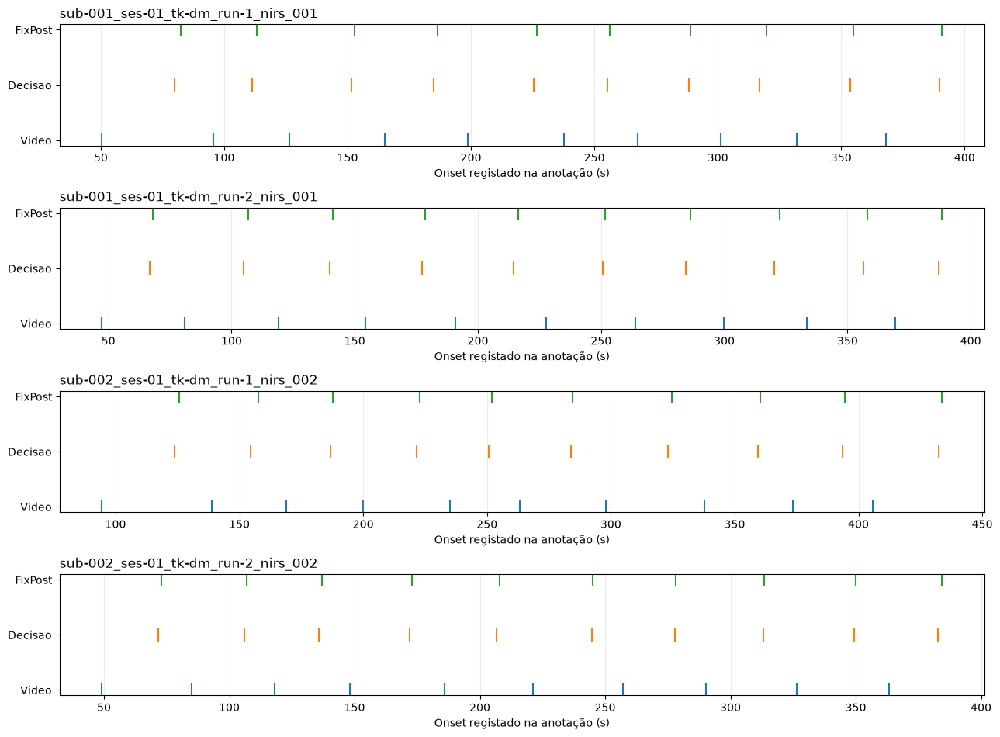


Objetos disponíveis em piloto_runs[(sujeito, run)].
Os ficheiros e os sinais originais foram preservados.
Não foram aplicados filtros ou critérios SCI.
Não foram criadas épocas nem ajustado GLM.
Nenhum ficheiro de resultados foi escrito.

As quatro runs passaram as verificações estruturais.
Isto não valida ainda a qualidade ótica, a identidade dos CSV ou a precisão temporal.

Etapa 2 concluída.


In [2]:
# ============================================================
# ETAPA 2 — LEITURA E INSPEÇÃO INICIAL DAS QUATRO RUNS
# ============================================================

import mne
import numpy as np
import matplotlib.pyplot as plt

from collections import Counter

N_ENSAIOS_ESPERADOS_PILOTO = 10

MARCADORES_PRINCIPAIS_PILOTO = {
    "120": "Video",
    "130": "Decisao",
    "150": "FixPost",
}

if not (
    df_inventario_piloto["estado"] == "LOCALIZADO"
).all():
    raise RuntimeError(
        "O inventário contém referências por resolver."
    )

# Estes dicionários passam a conter os dados desta etapa.
piloto_runs = {}
piloto_tabelas_canais = {}
piloto_tabelas_eventos = {}

registos_leitura_piloto = []


def codigo_marcador_piloto(descricao):
    """Interpretar códigos inteiros sem alterar as anotações."""
    texto = str(descricao).strip()

    try:
        numero = float(texto)
    except ValueError:
        return texto

    if np.isfinite(numero) and numero.is_integer():
        return str(int(numero))

    return texto


for _, entrada in df_inventario_piloto.iterrows():
    sujeito = entrada["sujeito"]
    numero_run = int(entrada["run"])
    chave = (sujeito, numero_run)

    print(f"\nA ler {sujeito} — run {numero_run}...")

    resumo = {
        "sujeito": sujeito,
        "run": numero_run,
        "estado": "ERRO",
        "erro": "",
    }

    try:
        # ----------------------------------------------------
        # 2.1 Ler o SNIRF
        # ----------------------------------------------------

        raw_piloto = mne.io.read_raw_snirf(
            entrada["caminho_snirf"],
            preload=True,
            verbose=False,
        )

        tipos = raw_piloto.get_channel_types()

        if not tipos or any(
            tipo != "fnirs_cw_amplitude"
            for tipo in tipos
        ):
            raise RuntimeError(
                "O SNIRF não contém exclusivamente "
                "intensidade ótica contínua."
            )

        distancias_m = (
            mne.preprocessing.nirs.source_detector_distances(
                raw_piloto.info
            )
        )

        if (
            not np.isfinite(distancias_m).all()
            or np.any(distancias_m <= 0)
        ):
            raise RuntimeError(
                "Existem distâncias fonte–detetor inválidas."
            )

        tabela_canais = pd.DataFrame({
            "canal": raw_piloto.ch_names,
            "tipo": tipos,
            "par": [
                nome.split()[0]
                for nome in raw_piloto.ch_names
            ],
            "comprimento_onda_nm": [
                float(canal["loc"][9])
                for canal in raw_piloto.info["chs"]
            ],
            "distancia_mm": distancias_m * 1000,
            "mau_previamente": [
                nome in raw_piloto.info["bads"]
                for nome in raw_piloto.ch_names
            ],
        })

        for par, grupo in tabela_canais.groupby("par"):
            if (
                len(grupo) != 2
                or not np.isfinite(
                    grupo["comprimento_onda_nm"]
                ).all()
                or grupo["comprimento_onda_nm"].nunique() != 2
            ):
                raise RuntimeError(
                    f"O par {par} não apresenta "
                    "duas séries com comprimentos de onda distintos."
                )

        # ----------------------------------------------------
        # 2.2 Inspecionar os eventos originais
        # ----------------------------------------------------

        tabela_eventos = pd.DataFrame({
            "onset_s": raw_piloto.annotations.onset,
            "duracao_s": raw_piloto.annotations.duration,
            "descricao_original": (
                raw_piloto.annotations.description
            ),
        })

        tabela_eventos["codigo_interpretado"] = (
            tabela_eventos["descricao_original"]
            .map(codigo_marcador_piloto)
        )

        contagens = Counter(
            tabela_eventos["codigo_interpretado"]
        )

        for codigo in MARCADORES_PRINCIPAIS_PILOTO:
            if contagens[codigo] != N_ENSAIOS_ESPERADOS_PILOTO:
                raise RuntimeError(
                    f"Marcador {codigo}: encontrados "
                    f"{contagens[codigo]}, esperados "
                    f"{N_ENSAIOS_ESPERADOS_PILOTO}."
                )

        eventos_interesse = (
            tabela_eventos.loc[
                tabela_eventos["codigo_interpretado"].isin(
                    ["120", "130"]
                )
            ]
            .sort_values("onset_s", kind="stable")
        )

        sequencia_esperada = np.tile(
            ["120", "130"],
            N_ENSAIOS_ESPERADOS_PILOTO,
        )

        if not np.array_equal(
            eventos_interesse["codigo_interpretado"].to_numpy(),
            sequencia_esperada,
        ):
            raise RuntimeError(
                "Os eventos não alternam vídeo → decisão."
            )

        if np.any(
            np.diff(eventos_interesse["onset_s"].to_numpy()) <= 0
        ):
            raise RuntimeError(
                "Existem onsets coincidentes ou fora de ordem."
            )

        # ----------------------------------------------------
        # 2.3 Ler o CSV comportamental
        # ----------------------------------------------------

        try:
            comportamento_piloto = pd.read_csv(
                entrada["csv_candidato"],
                encoding="utf-8-sig",
                sep=None,
                engine="python",
            )
        except UnicodeDecodeError:
            comportamento_piloto = pd.read_csv(
                entrada["csv_candidato"],
                encoding="cp1252",
                sep=None,
                engine="python",
            )

        colunas_necessarias = [
            "videos",
            "thisTrialN",
            "corrAns",
            "key_resp.keys",
            "key_resp.corr",
            "key_resp.rt",
        ]

        em_falta = [
            coluna
            for coluna in colunas_necessarias
            if coluna not in comportamento_piloto.columns
        ]

        if em_falta:
            raise RuntimeError(
                f"Colunas comportamentais ausentes: {em_falta}"
            )

        mascara_ensaios = (
            comportamento_piloto["videos"]
            .astype("string")
            .str.contains(
                r"\.(?:mp4|avi|mov|mkv)",
                case=False,
                regex=True,
                na=False,
            )
        )

        ensaios_piloto = (
            comportamento_piloto.loc[mascara_ensaios]
            .copy()
        )

        ensaios_piloto["thisTrialN"] = pd.to_numeric(
            ensaios_piloto["thisTrialN"],
            errors="coerce",
        )

        ensaios_piloto = (
            ensaios_piloto
            .sort_values("thisTrialN")
            .reset_index(drop=True)
        )

        if not np.array_equal(
            ensaios_piloto["thisTrialN"].to_numpy(),
            np.arange(N_ENSAIOS_ESPERADOS_PILOTO),
        ):
            raise RuntimeError(
                "Os ensaios do CSV não correspondem "
                "à sequência esperada de 0 a 9."
            )

        identificadores_csv = {}

        for coluna in ("participant", "session", "expName"):
            if coluna in comportamento_piloto.columns:
                identificadores_csv[coluna] = (
                    comportamento_piloto[coluna]
                    .dropna()
                    .astype(str)
                    .unique()
                    .tolist()
                )

        # ----------------------------------------------------
        # 2.4 Preservar os objetos por participante/run
        # ----------------------------------------------------

        piloto_runs[chave] = {
            "id_gravacao": entrada["id_gravacao"],
            "raw_intensidade": raw_piloto,
            "comportamento_original": comportamento_piloto,
            "ensaios_comportamentais": ensaios_piloto,
            "identificadores_csv": identificadores_csv,
            "caminho_snirf": entrada["caminho_snirf"],
            "caminho_csv": entrada["csv_candidato"],
            "pasta_saida_prevista": entrada["pasta_saida_prevista"],
        }

        piloto_tabelas_canais[chave] = tabela_canais
        piloto_tabelas_eventos[chave] = tabela_eventos

        resumo.update({
            "estado": "LEITURA_OK",
            "fs_hz": float(raw_piloto.info["sfreq"]),
            "n_amostras": int(raw_piloto.n_times),
            "tempo_final_relativo_s": float(raw_piloto.times[-1]),
            "n_series_oticas": len(raw_piloto.ch_names),
            "n_pares": int(tabela_canais["par"].nunique()),
            "n_video": contagens["120"],
            "n_decisao": contagens["130"],
            "n_fixpost": contagens["150"],
            "n_marcadores_resposta": sum(
                contagens[codigo]
                for codigo in ("140", "141", "142", "143")
            ),
            "n_ensaios_csv": len(ensaios_piloto),
        })

        print(f"  Identificadores internos do CSV: {identificadores_csv}")
        print(f"  Contagens de todos os marcadores: {dict(contagens)}")

    except Exception as erro:
        resumo["erro"] = (
            f"{type(erro).__name__}: {erro}"
        )
        print(f"  ERRO: {resumo['erro']}")

    registos_leitura_piloto.append(resumo)


# ------------------------------------------------------------
# 2.5 Resumo das quatro runs
# ------------------------------------------------------------

df_leitura_piloto = pd.DataFrame(
    registos_leitura_piloto
)

print("\n" + "=" * 70)
print("PILOTO DM — LEITURA E INSPEÇÃO INICIAL")
print("=" * 70)

print(
    df_leitura_piloto.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.4f}",
    )
)


# ------------------------------------------------------------
# 2.6 Cronologia dos marcadores principais
# ------------------------------------------------------------

if piloto_runs:
    fig_eventos_piloto, eixos_eventos_piloto = plt.subplots(
        len(piloto_runs),
        1,
        figsize=(13, 2.4 * len(piloto_runs)),
        squeeze=False,
    )

    cores_eventos = {
        "120": "tab:blue",
        "130": "tab:orange",
        "150": "tab:green",
    }

    for ax, (chave, objetos) in zip(
        eixos_eventos_piloto[:, 0],
        piloto_runs.items(),
    ):
        tabela = piloto_tabelas_eventos[chave]

        for posicao, (codigo, nome) in enumerate(
            MARCADORES_PRINCIPAIS_PILOTO.items()
        ):
            onsets = tabela.loc[
                tabela["codigo_interpretado"] == codigo,
                "onset_s",
            ]

            ax.scatter(
                onsets,
                np.full(len(onsets), posicao),
                marker="|",
                s=180,
                color=cores_eventos[codigo],
            )

        ax.set_yticks(
            range(len(MARCADORES_PRINCIPAIS_PILOTO)),
            list(MARCADORES_PRINCIPAIS_PILOTO.values()),
        )

        ax.set_title(objetos["id_gravacao"], loc="left")
        ax.set_xlabel("Onset registado na anotação (s)")
        ax.grid(axis="x", alpha=0.25)

    fig_eventos_piloto.tight_layout()
    plt.show()

print("\nObjetos disponíveis em piloto_runs[(sujeito, run)].")
print("Os ficheiros e os sinais originais foram preservados.")
print("Não foram aplicados filtros ou critérios SCI.")
print("Não foram criadas épocas nem ajustado GLM.")
print("Nenhum ficheiro de resultados foi escrito.")

if (df_leitura_piloto["estado"] != "LEITURA_OK").any():
    print(
        "\nExistem runs com erros. "
        "Não avançar para o processamento antes de os rever."
    )
else:
    print(
        "\nAs quatro runs passaram as verificações estruturais."
    )
    print(
        "Isto não valida ainda a qualidade ótica, "
        "a identidade dos CSV ou a precisão temporal."
    )

print("\nEtapa 2 concluída.")

## Etapa 3 — Conversão da intensidade para densidade ótica

### Objetivo
Converter a intensidade luminosa registada em densidade ótica,
preservando os sinais originais.

### Verificação antes da conversão
Contar, por canal:
- Valores não finitos.
- Valores iguais a zero.
- Valores negativos.

Se alguma run apresentar estes valores, interromper a etapa
antes de converter qualquer uma das runs.

Não substituir ou corrigir automaticamente valores inválidos.

### Conversão
Utilizar a função optical_density do MNE.

Manter:
- Canais e respetiva ordem.
- Número de amostras.
- Frequência de amostragem.
- Anotações e marcações de canais maus.

### Visualização
Apresentar os dois comprimentos de onda do primeiro par
de cada run, apenas como inspeção ilustrativa.

Esta visualização não valida todos os canais.

### Resultados guardados
Por participante e run:
- Verificação dos valores de intensidade.
- Sinal em densidade ótica.
- Parâmetros da conversão.

A reexecução atualiza apenas os outputs desta etapa,
na pasta da nova versão piloto.

### Nesta etapa
Não calcular SCI.
Não corrigir movimento.
Não aplicar regressão de canais curtos.
Não converter para HbO/HbR.
Não filtrar nem criar épocas.

VERIFICAÇÃO DA INTENSIDADE ÓTICA
sujeito  run  n_series  n_nao_finitos  n_zeros  n_negativos
sub-001    1        56              0        0            0
sub-001    2        56              0        0            0
sub-002    1        56              0        0            0
sub-002    2        56              0        0            0

A converter sub-001 — run 1...

A converter sub-001 — run 2...

A converter sub-002 — run 1...

A converter sub-002 — run 2...


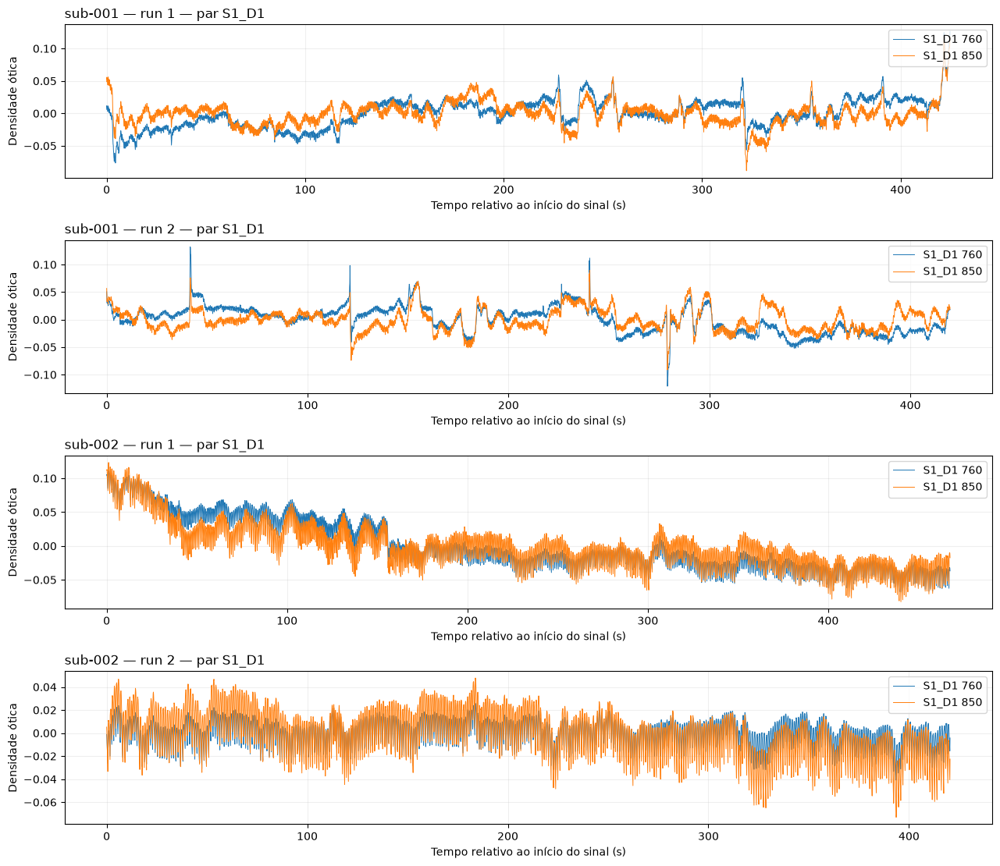


CONVERSÃO PARA DENSIDADE ÓTICA CONCLUÍDA
sujeito  run  n_series_od  n_amostras   fs_hz  valores_finitos  canais_preservados  anotacoes_preservadas
sub-001    1           56        4323 10.1725             True                True                   True
sub-001    2           56        4271 10.1725             True                True                   True
sub-002    1           56        4757 10.1725             True                True                   True
sub-002    2           56        4278 10.1725             True                True                   True

Objetos disponíveis: piloto_od[(sujeito, run)].
Os objetos de intensidade em piloto_runs foram preservados.
Outputs guardados nas pastas da nova versão piloto.
Não foram aplicados SCI, TDDR, SSR ou filtragem.
A conversão não demonstra, por si só, boa qualidade ótica.

Etapa 3 concluída.


In [3]:
# ============================================================
# ETAPA 3 — CONVERSÃO PARA DENSIDADE ÓTICA
# ============================================================

import json
from importlib.metadata import version

if (
    len(piloto_runs) != len(df_inventario_piloto)
    or not (df_leitura_piloto["estado"] == "LEITURA_OK").all()
):
    raise RuntimeError(
        "As quatro runs devem passar a Etapa 2 antes de continuar."
    )

piloto_qc_intensidade = {}
registos_resumo_intensidade = []

# ------------------------------------------------------------
# 3.1 Verificar as quatro runs antes de converter
# ------------------------------------------------------------

for chave, objetos in piloto_runs.items():
    raw_entrada = objetos["raw_intensidade"]
    intensidade = raw_entrada.get_data()

    linhas_qc = []

    for indice, canal in enumerate(raw_entrada.ch_names):
        valores = intensidade[indice]
        finitos = valores[np.isfinite(valores)]

        linhas_qc.append({
            "canal": canal,
            "n_nao_finitos": int(
                (~np.isfinite(valores)).sum()
            ),
            "n_zeros": int((valores == 0).sum()),
            "n_negativos": int((valores < 0).sum()),
            "minimo_finito": (
                float(finitos.min()) if len(finitos) else np.nan
            ),
            "maximo_finito": (
                float(finitos.max()) if len(finitos) else np.nan
            ),
        })

    tabela_qc = pd.DataFrame(linhas_qc)
    piloto_qc_intensidade[chave] = tabela_qc

    registos_resumo_intensidade.append({
        "sujeito": chave[0],
        "run": chave[1],
        "n_series": len(raw_entrada.ch_names),
        "n_nao_finitos": int(
            tabela_qc["n_nao_finitos"].sum()
        ),
        "n_zeros": int(tabela_qc["n_zeros"].sum()),
        "n_negativos": int(
            tabela_qc["n_negativos"].sum()
        ),
    })

df_intensidade_piloto = pd.DataFrame(
    registos_resumo_intensidade
)

print("=" * 70)
print("VERIFICAÇÃO DA INTENSIDADE ÓTICA")
print("=" * 70)
print(df_intensidade_piloto.to_string(index=False))

problemas_intensidade = (
    df_intensidade_piloto[
        ["n_nao_finitos", "n_zeros", "n_negativos"]
    ] > 0
).any(axis=1)

if problemas_intensidade.any():
    for _, problema in df_intensidade_piloto.loc[
        problemas_intensidade
    ].iterrows():
        chave = (problema["sujeito"], int(problema["run"]))
        tabela = piloto_qc_intensidade[chave]

        canais_problematicos = (
            tabela[
                ["n_nao_finitos", "n_zeros", "n_negativos"]
            ] > 0
        ).any(axis=1)

        print(f"\nCanais a rever — {chave}:")
        print(
            tabela.loc[canais_problematicos].to_string(index=False)
        )

    raise RuntimeError(
        "Foram encontrados valores inválidos. "
        "Nenhuma run foi convertida nesta execução."
    )


# ------------------------------------------------------------
# 3.2 Converter e verificar, sem escrever ficheiros ainda
# ------------------------------------------------------------

piloto_od = {}
registos_resumo_od = []

for chave, objetos in piloto_runs.items():
    raw_entrada = objetos["raw_intensidade"]

    print(f"\nA converter {chave[0]} — run {chave[1]}...")

    # A função cria uma cópia; o objeto de intensidade é preservado.
    raw_od_piloto = mne.preprocessing.nirs.optical_density(
        raw_entrada,
        verbose=False,
    )

    if (
        raw_od_piloto.ch_names != raw_entrada.ch_names
        or raw_od_piloto.n_times != raw_entrada.n_times
        or raw_od_piloto.info["sfreq"] != raw_entrada.info["sfreq"]
    ):
        raise RuntimeError(
            f"Canais ou grelha temporal alterados em {chave}."
        )

    if raw_od_piloto.info["bads"] != raw_entrada.info["bads"]:
        raise RuntimeError(
            f"A marcação dos canais maus mudou em {chave}."
        )

    anotacoes_iguais = (
        np.array_equal(
            raw_od_piloto.annotations.onset,
            raw_entrada.annotations.onset,
        )
        and np.array_equal(
            raw_od_piloto.annotations.duration,
            raw_entrada.annotations.duration,
        )
        and np.array_equal(
            raw_od_piloto.annotations.description,
            raw_entrada.annotations.description,
        )
        and (
            raw_od_piloto.annotations.orig_time
            == raw_entrada.annotations.orig_time
        )
    )

    if not anotacoes_iguais:
        raise RuntimeError(
            f"As anotações mudaram em {chave}."
        )

    if not all(
        tipo == "fnirs_od"
        for tipo in raw_od_piloto.get_channel_types()
    ):
        raise RuntimeError(
            f"Tipos de canal inesperados após conversão em {chave}."
        )

    valores_od = raw_od_piloto.get_data()

    if not np.isfinite(valores_od).all():
        raise RuntimeError(
            f"Existem valores não finitos após conversão em {chave}."
        )

    piloto_od[chave] = raw_od_piloto

    registos_resumo_od.append({
        "sujeito": chave[0],
        "run": chave[1],
        "n_series_od": len(raw_od_piloto.ch_names),
        "n_amostras": int(raw_od_piloto.n_times),
        "fs_hz": float(raw_od_piloto.info["sfreq"]),
        "valores_finitos": True,
        "canais_preservados": True,
        "anotacoes_preservadas": True,
    })


# ------------------------------------------------------------
# 3.3 Guardar os resultados na nova versão piloto
# ------------------------------------------------------------

for chave, raw_od_piloto in piloto_od.items():
    objetos = piloto_runs[chave]
    id_gravacao = objetos["id_gravacao"]
    pasta_saida = Path(objetos["pasta_saida_prevista"])

    pasta_saida.mkdir(parents=True, exist_ok=True)

    piloto_qc_intensidade[chave].to_csv(
        pasta_saida / f"{id_gravacao}_intensity_value_check.csv",
        index=False,
        encoding="utf-8-sig",
    )

    raw_od_piloto.save(
        pasta_saida / f"{id_gravacao}_od_raw.fif",
        overwrite=True,
        fmt="double",
        verbose=False,
    )

    parametros_od = {
        "id_gravacao": id_gravacao,
        "pipeline_version": VERSAO_PIPELINE_PILOTO,
        "etapa": 3,
        "metodo": "mne.preprocessing.nirs.optical_density",
        "mne_version": version("mne"),
        "caminho_snirf_origem": objetos["caminho_snirf"],
        "n_series": len(raw_od_piloto.ch_names),
        "n_amostras": int(raw_od_piloto.n_times),
        "sfreq_hz": float(raw_od_piloto.info["sfreq"]),
        "valores_nao_positivos_na_entrada": 0,
        "valores_nao_finitos_na_entrada": 0,
        "valores_finitos_na_saida": True,
        "anotacoes_preservadas": True,
        "bads": list(raw_od_piloto.info["bads"]),
        "sci_calculado": False,
        "tddr_aplicado": False,
        "ssr_aplicada": False,
        "filtro_hemodinamico_aplicado": False,
    }

    (
        pasta_saida / f"{id_gravacao}_od_parameters.json"
    ).write_text(
        json.dumps(
            parametros_od,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )


# ------------------------------------------------------------
# 3.4 Inspeção ilustrativa do primeiro par de cada run
# ------------------------------------------------------------

fig_od_piloto, eixos_od_piloto = plt.subplots(
    len(piloto_od),
    1,
    figsize=(13, 2.8 * len(piloto_od)),
    squeeze=False,
)

for ax, (chave, raw_od_piloto) in zip(
    eixos_od_piloto[:, 0],
    piloto_od.items(),
):
    tabela_canais = piloto_tabelas_canais[chave]
    primeiro_par = tabela_canais["par"].iloc[0]

    indices_par = np.flatnonzero(
        tabela_canais["par"].to_numpy() == primeiro_par
    )

    dados_par = raw_od_piloto.get_data(picks=indices_par)

    for indice_local, indice_canal in enumerate(indices_par):
        ax.plot(
            raw_od_piloto.times,
            dados_par[indice_local],
            linewidth=0.7,
            label=raw_od_piloto.ch_names[indice_canal],
        )

    ax.set_title(
        f"{chave[0]} — run {chave[1]} — par {primeiro_par}",
        loc="left",
    )
    ax.set_xlabel("Tempo relativo ao início do sinal (s)")
    ax.set_ylabel("Densidade ótica")
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")

fig_od_piloto.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.5 Resumo
# ------------------------------------------------------------

df_od_piloto = pd.DataFrame(registos_resumo_od)

print("\n" + "=" * 70)
print("CONVERSÃO PARA DENSIDADE ÓTICA CONCLUÍDA")
print("=" * 70)

print(
    df_od_piloto.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.4f}",
    )
)

print("\nObjetos disponíveis: piloto_od[(sujeito, run)].")
print("Os objetos de intensidade em piloto_runs foram preservados.")
print("Outputs guardados nas pastas da nova versão piloto.")
print("Não foram aplicados SCI, TDDR, SSR ou filtragem.")
print("A conversão não demonstra, por si só, boa qualidade ótica.")
print("\nEtapa 3 concluída.")

## Etapa 4 — Qualidade dos canais pelo Scalp Coupling Index

### Objetivo
Avaliar o acoplamento ótico nas quatro runs e marcar
os pares que não cumprem o critério definido.

### Parâmetros
- SCI calculado sobre a gravação completa.
- Banda: 0,7–1,5 Hz.
- Limiar: SCI inferior a 0,7.
- Valores não finitos também são sinalizados.

Este limiar é uma escolha desta pipeline,
não uma garantia universal de qualidade.

### Marcação por par
Se uma das séries de um par for sinalizada,
marcar o par fonte–detetor completo.

Preservar as marcações de canais maus já existentes.
Os canais são marcados, não removidos.

### Classificação geométrica
- Curto: distância inferior a 10 mm.
- Longo: distância superior a 15 mm.
- Intermédio: restantes distâncias.

Esta classificação não altera o limiar SCI.

A disponibilidade de canais curtos para eventual SSR
será avaliada separadamente em cada run.

### Preservação
- piloto_od: sinal anterior, preservado.
- piloto_od_qc: cópia com a marcação de qualidade.

### Resultados guardados
Por participante e run:
- SCI por série ótica.
- Resumo por par.
- Sinal com canais maus assinalados.
- Histograma.
- Parâmetros.

### Limitações
Um SCI global não avalia a qualidade em cada instante.
Uma run pode conter segmentos problemáticos mesmo
quando o SCI global do canal é elevado.

### Nesta etapa
Não remover canais.
Não aplicar TDDR, SSR ou filtro hemodinâmico.
Não criar épocas ou ajustar modelos.


A calcular SCI: sub-001 — run 1...


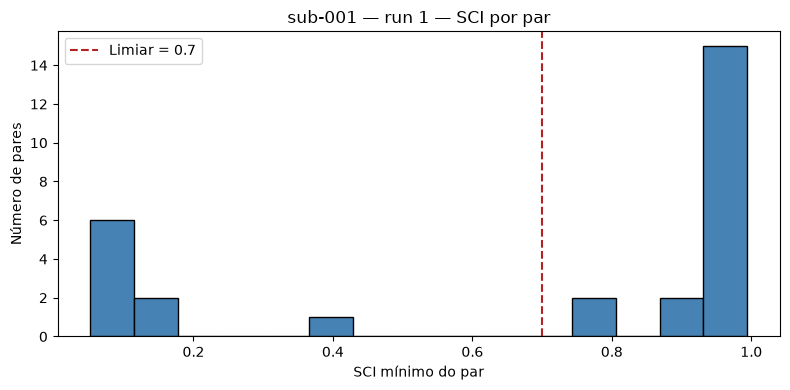


A calcular SCI: sub-001 — run 2...


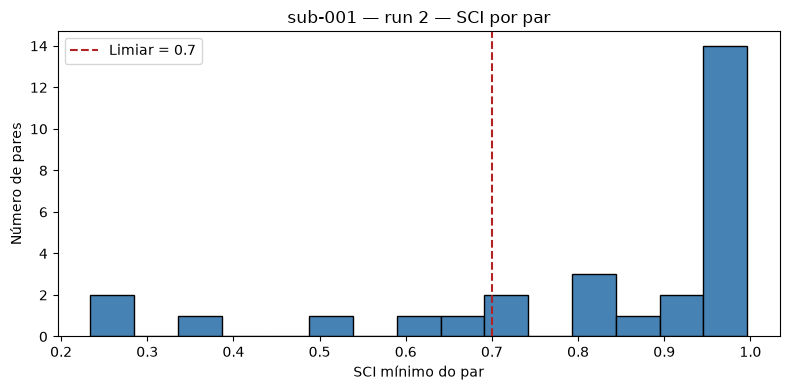


A calcular SCI: sub-002 — run 1...


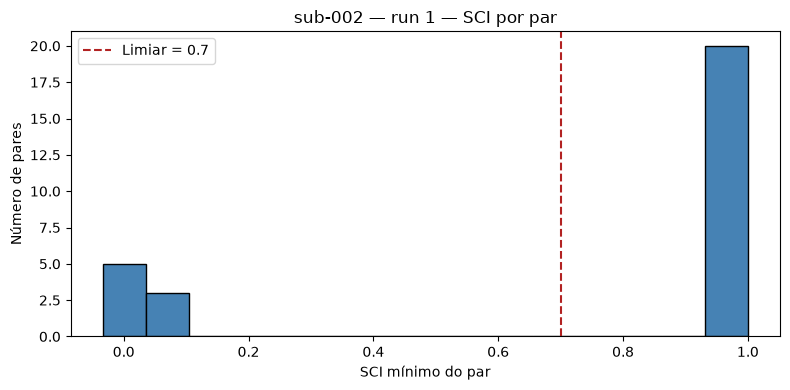


A calcular SCI: sub-002 — run 2...


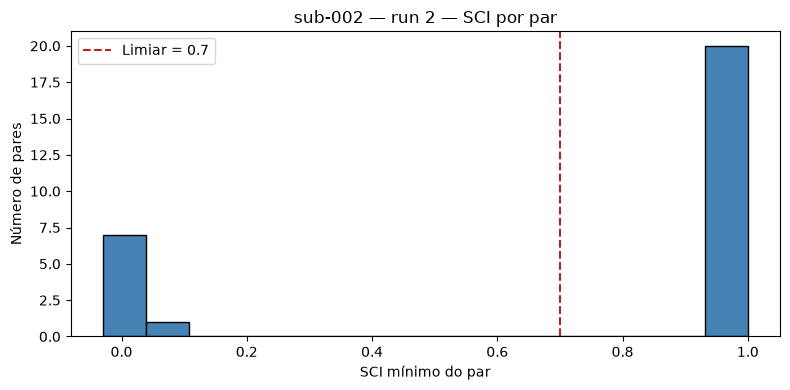


QUALIDADE ÓTICA — SCI
sujeito  run  n_pares  n_pares_maus  n_series_maus  n_SCI_nao_finitos  n_curtos  n_curtos_validos  n_longos  n_longos_validos
sub-001    1       28             9             18                  0         8                 0        20                19
sub-001    2       28             6             12                  0         8                 3        20                19
sub-002    1       28             8             16                  0         8                 0        20                20
sub-002    2       28             8             16                  0         8                 0        20                20

--- sub-001 | run 1 ---
   par  distancia_mm tipo_distancia  SCI_min  SCI_nao_finito  marcado_mau
 S1_D1       30.5904          longo   0.9703           False        False
 S1_D2       30.4793          longo   0.9791           False        False
 S1_D8        8.7017          curto   0.4207           False         True
 S2_D1       35.9575      

In [4]:
# ============================================================
# ETAPA 4 — CONTROLO DE QUALIDADE PELO SCI
# ============================================================

LIMIAR_SCI_PILOTO = 0.7
SCI_LOW_HZ_PILOTO = 0.7
SCI_HIGH_HZ_PILOTO = 1.5

DISTANCIA_MAX_CURTA_M_PILOTO = 0.010
DISTANCIA_MIN_LONGA_M_PILOTO = 0.015

if set(piloto_od) != set(piloto_runs):
    raise RuntimeError(
        "Faltam objetos de densidade ótica para alguma run."
    )

piloto_od_qc = {}
piloto_sci_series = {}
piloto_sci_pares = {}

registos_resumo_sci = []

for chave, raw_od_entrada in piloto_od.items():
    objetos = piloto_runs[chave]
    id_gravacao = objetos["id_gravacao"]

    print(f"\nA calcular SCI: {chave[0]} — run {chave[1]}...")

    if not all(
        tipo == "fnirs_od"
        for tipo in raw_od_entrada.get_channel_types()
    ):
        raise RuntimeError(
            f"A entrada não contém apenas densidade ótica: {chave}"
        )

    bads_anteriores = list(raw_od_entrada.info["bads"])

    # Cópia apenas para cálculo em todas as séries.
    # As marcações anteriores serão preservadas no resultado.
    raw_calculo_sci = raw_od_entrada.copy()
    raw_calculo_sci.info["bads"] = []

    sci = np.asarray(
        mne.preprocessing.nirs.scalp_coupling_index(
            raw_calculo_sci,
            l_freq=SCI_LOW_HZ_PILOTO,
            h_freq=SCI_HIGH_HZ_PILOTO,
            l_trans_bandwidth=0.3,
            h_trans_bandwidth=0.3,
            verbose=False,
        ),
        dtype=float,
    )

    if sci.shape != (len(raw_od_entrada.ch_names),):
        raise RuntimeError(
            f"O número de valores SCI não corresponde aos canais: {chave}"
        )

    distancias_m = (
        mne.preprocessing.nirs.source_detector_distances(
            raw_od_entrada.info
        )
    )

    tabela_sci = pd.DataFrame({
        "canal": raw_od_entrada.ch_names,
        "par": [
            nome.split()[0]
            for nome in raw_od_entrada.ch_names
        ],
        "SCI": sci,
        "distancia_mm": distancias_m * 1000,
        "mau_previamente": [
            nome in bads_anteriores
            for nome in raw_od_entrada.ch_names
        ],
    })

    tabela_sci["tipo_distancia"] = np.select(
        [
            distancias_m < DISTANCIA_MAX_CURTA_M_PILOTO,
            distancias_m > DISTANCIA_MIN_LONGA_M_PILOTO,
        ],
        ["curto", "longo"],
        default="intermedio",
    )

    tabela_sci["SCI_nao_finito"] = ~np.isfinite(sci)

    tabela_sci["SCI_abaixo_limiar"] = (
        np.isfinite(sci)
        & (sci < LIMIAR_SCI_PILOTO)
    )

    tabela_sci["sinalizado_SCI"] = (
        tabela_sci["SCI_nao_finito"]
        | tabela_sci["SCI_abaixo_limiar"]
    )

    pares_maus = set(
        tabela_sci.loc[
            tabela_sci["sinalizado_SCI"]
            | tabela_sci["mau_previamente"],
            "par",
        ]
    )

    tabela_sci["marcado_mau_final"] = (
        tabela_sci["par"].isin(pares_maus)
    )

    tabela_pares = (
        tabela_sci
        .groupby("par", sort=False)
        .agg(
            distancia_mm=("distancia_mm", "first"),
            tipo_distancia=("tipo_distancia", "first"),
            n_series=("canal", "size"),
            SCI_min=("SCI", "min"),
            SCI_max=("SCI", "max"),
            SCI_nao_finito=("SCI_nao_finito", "any"),
            mau_previamente=("mau_previamente", "any"),
            sinalizado_SCI=("sinalizado_SCI", "any"),
            marcado_mau=("marcado_mau_final", "any"),
        )
        .reset_index()
    )

    tabela_pares["valido"] = ~tabela_pares["marcado_mau"]

    # Aplicar as marcações a outra cópia, sem alterar a entrada.
    raw_qc = raw_od_entrada.copy()

    raw_qc.info["bads"] = tabela_sci.loc[
        tabela_sci["marcado_mau_final"],
        "canal",
    ].tolist()

    if (
        raw_qc.ch_names != raw_od_entrada.ch_names
        or raw_qc.n_times != raw_od_entrada.n_times
    ):
        raise RuntimeError(
            f"Canais ou amostras alterados na marcação: {chave}"
        )

    if not set(bads_anteriores).issubset(raw_qc.info["bads"]):
        raise RuntimeError(
            f"Foram perdidas marcações anteriores: {chave}"
        )

    if not np.array_equal(
        raw_qc.get_data(),
        raw_od_entrada.get_data(),
    ):
        raise RuntimeError(
            f"O sinal foi alterado durante a marcação: {chave}"
        )

    piloto_od_qc[chave] = raw_qc
    piloto_sci_series[chave] = tabela_sci
    piloto_sci_pares[chave] = tabela_pares

    curtos = tabela_pares["tipo_distancia"] == "curto"
    longos = tabela_pares["tipo_distancia"] == "longo"
    validos = tabela_pares["valido"]

    resumo = {
        "sujeito": chave[0],
        "run": chave[1],
        "n_pares": len(tabela_pares),
        "n_pares_maus": int(tabela_pares["marcado_mau"].sum()),
        "n_series_maus": len(raw_qc.info["bads"]),
        "n_SCI_nao_finitos": int(
            tabela_sci["SCI_nao_finito"].sum()
        ),
        "n_curtos": int(curtos.sum()),
        "n_curtos_validos": int((curtos & validos).sum()),
        "n_longos": int(longos.sum()),
        "n_longos_validos": int((longos & validos).sum()),
    }

    registos_resumo_sci.append(resumo)

    # --------------------------------------------------------
    # Guardar resultados por participante/run
    # --------------------------------------------------------

    pasta_saida = Path(objetos["pasta_saida_prevista"])

    tabela_sci.to_csv(
        pasta_saida / f"{id_gravacao}_sci_channels.csv",
        index=False,
        encoding="utf-8-sig",
    )

    tabela_pares.to_csv(
        pasta_saida / f"{id_gravacao}_sci_pairs.csv",
        index=False,
        encoding="utf-8-sig",
    )

    raw_qc.save(
        pasta_saida / f"{id_gravacao}_od_qc_raw.fif",
        overwrite=True,
        fmt="double",
        verbose=False,
    )

    parametros_sci = {
        "id_gravacao": id_gravacao,
        "pipeline_version": VERSAO_PIPELINE_PILOTO,
        "etapa": 4,
        "mne_version": version("mne"),
        "limiar_SCI": LIMIAR_SCI_PILOTO,
        "banda_SCI_hz": [
            SCI_LOW_HZ_PILOTO,
            SCI_HIGH_HZ_PILOTO,
        ],
        "l_trans_bandwidth_hz": 0.3,
        "h_trans_bandwidth_hz": 0.3,
        "avaliacao": "gravacao completa",
        "criterio": "SCI abaixo do limiar ou nao finito",
        "marcacao": "par fonte-detetor completo",
        "curto_distancia_inferior_m": DISTANCIA_MAX_CURTA_M_PILOTO,
        "longo_distancia_superior_m": DISTANCIA_MIN_LONGA_M_PILOTO,
        "bads_anteriores": bads_anteriores,
        "bads_finais": list(raw_qc.info["bads"]),
        "resumo": resumo,
        "canais_removidos": False,
        "tddr_aplicado": False,
        "ssr_aplicada": False,
    }

    (
        pasta_saida / f"{id_gravacao}_sci_parameters.json"
    ).write_text(
        json.dumps(
            parametros_sci,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )

    fig_sci, ax_sci = plt.subplots(figsize=(8, 4))

    valores_histograma = tabela_pares.loc[
        ~tabela_pares["SCI_nao_finito"],
        "SCI_min",
    ].to_numpy()

    if len(valores_histograma):
        ax_sci.hist(
            valores_histograma,
            bins=15,
            color="steelblue",
            edgecolor="black",
        )
    else:
        ax_sci.text(
            0.5, 0.5,
            "Sem pares com SCI finito",
            transform=ax_sci.transAxes,
            ha="center",
        )

    ax_sci.axvline(
        LIMIAR_SCI_PILOTO,
        color="firebrick",
        linestyle="--",
        label=f"Limiar = {LIMIAR_SCI_PILOTO}",
    )

    ax_sci.set(
        title=f"{chave[0]} — run {chave[1]} — SCI por par",
        xlabel="SCI mínimo do par",
        ylabel="Número de pares",
    )

    ax_sci.legend()
    fig_sci.tight_layout()

    fig_sci.savefig(
        pasta_saida / f"{id_gravacao}_sci_histogram.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


# ------------------------------------------------------------
# 4.6 Resumo das quatro runs
# ------------------------------------------------------------

df_sci_piloto = pd.DataFrame(registos_resumo_sci)

print("\n" + "=" * 70)
print("QUALIDADE ÓTICA — SCI")
print("=" * 70)

print(df_sci_piloto.to_string(index=False))

for chave, tabela_pares in piloto_sci_pares.items():
    print(f"\n--- {chave[0]} | run {chave[1]} ---")
    print(
        tabela_pares[
            [
                "par",
                "distancia_mm",
                "tipo_distancia",
                "SCI_min",
                "SCI_nao_finito",
                "marcado_mau",
            ]
        ].to_string(
            index=False,
            float_format=lambda valor: f"{valor:.4f}",
        )
    )

print("\nObjetos seguintes: piloto_od_qc[(sujeito, run)].")
print("Os canais foram marcados, não removidos.")
print("Os objetos anteriores em piloto_od foram preservados.")
print("Resultados guardados nas pastas da versão piloto.")
print("Não foram aplicados TDDR, SSR ou filtro hemodinâmico.")

if (df_sci_piloto["n_longos_validos"] == 0).any():
    print(
        "\nATENÇÃO: existe pelo menos uma run sem pares longos válidos. "
        "Rever antes de avançar."
    )

print("\nEtapa 4 concluída.")

## Etapa 5 — Correção de movimento com TDDR

### Objetivo
Aplicar Temporal Derivative Distribution Repair à densidade
ótica, antes da conversão para HbO e HbR.

### Entrada
piloto_od_qc:
densidade ótica com as marcações de qualidade do SCI.

### Procedimento
Aplicar a implementação TDDR do MNE,
sem modificar os parâmetros internos do algoritmo.

Trabalhar sobre uma cópia de cada run.

### Preservação
Manter:
- Canais e respetiva ordem.
- Número de amostras e frequência de amostragem.
- Anotações.
- Marcações dos canais maus.

O TDDR não reclassifica canais maus como válidos.

### Visualização
Comparar antes e depois num par longo que seja válido
nas quatro runs.

Selecionar o primeiro par comum pela ordem da tabela,
não pelo aspeto da resposta.

Apresentar os dois comprimentos de onda separadamente.

### Verificações
- Dados finitos após a correção.
- Estrutura e anotações preservadas.
- Marcações de qualidade preservadas.

### Limitações
A execução sem erros não demonstra remoção completa
dos artefactos de movimento.

Uma curva mais lisa não é, por si só, mais válida.

A inspeção de um par não substitui a avaliação
dos restantes canais e segmentos.

### Resultados guardados
Por participante e run:
- Densidade ótica após TDDR.
- Figura antes/depois.
- Parâmetros e resumo.

### Nesta etapa
Não remover canais.
Não aplicar SSR.
Não converter para HbO/HbR.
Não aplicar filtro hemodinâmico ou criar épocas.

Par comum selecionado para inspeção: S1_D1

A aplicar TDDR: sub-001 — run 1...

A aplicar TDDR: sub-001 — run 2...

A aplicar TDDR: sub-002 — run 1...

A aplicar TDDR: sub-002 — run 2...


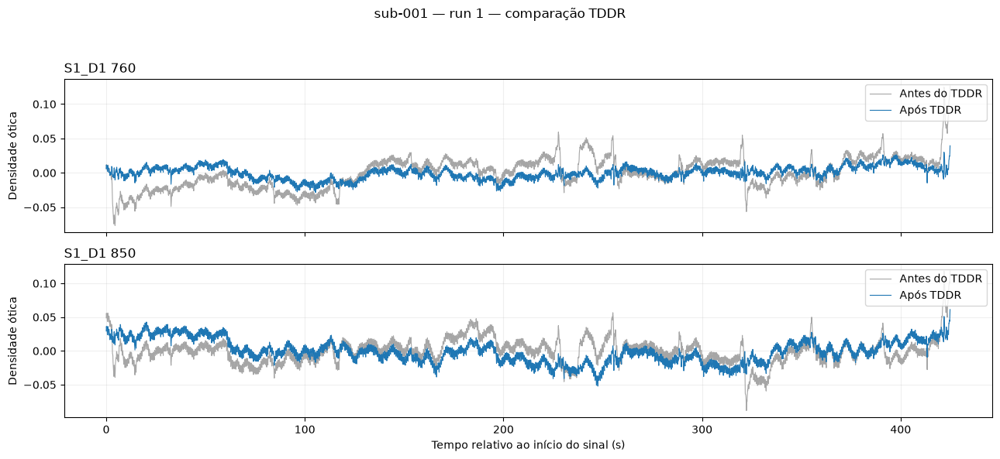

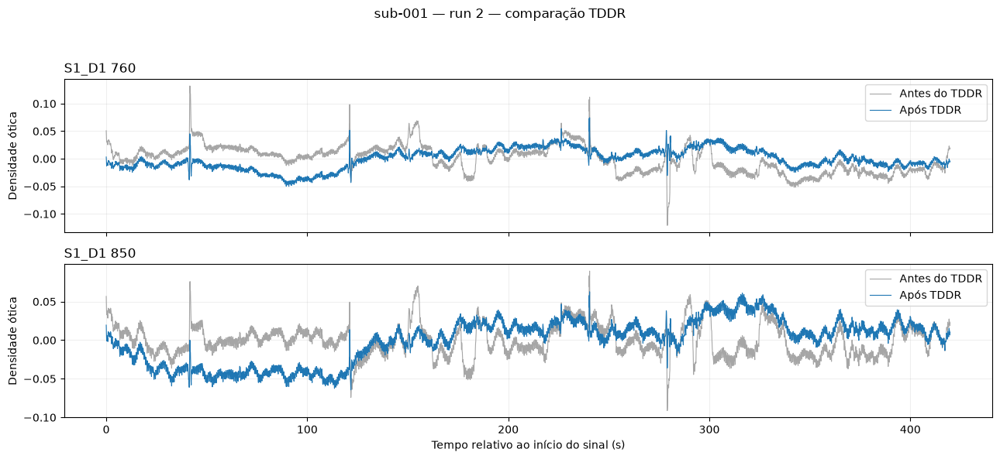

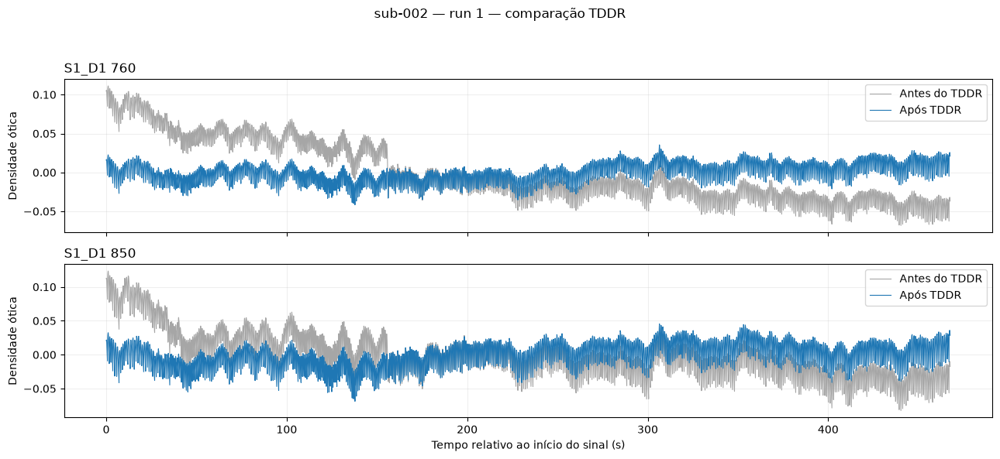

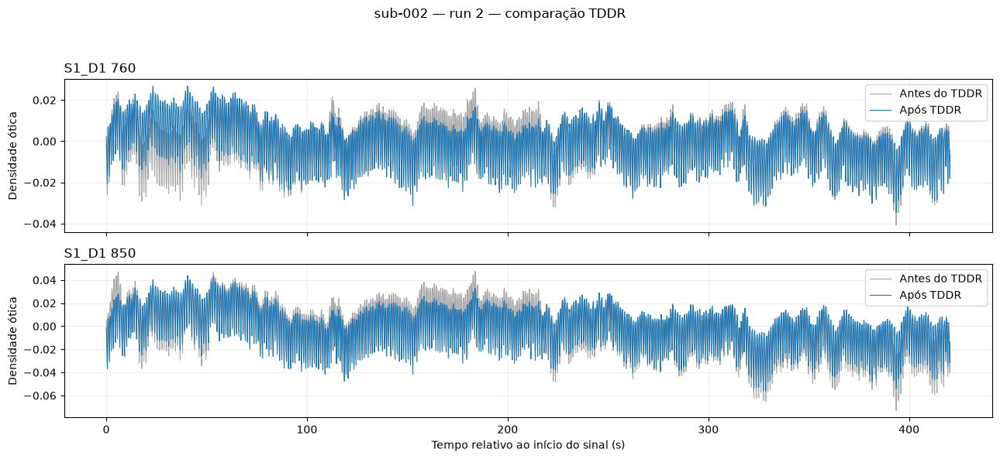


CORREÇÃO TDDR CONCLUÍDA
sujeito  run  n_series  n_series_nao_marcadas  n_amostras  valores_finitos  bads_preservados  anotacoes_preservadas
sub-001    1        56                     38        4323             True              True                   True
sub-001    2        56                     44        4271             True              True                   True
sub-002    1        56                     40        4757             True              True                   True
sub-002    2        56                     40        4278             True              True                   True

Par utilizado nas figuras: S1_D1

Objetos disponíveis: piloto_od_tddr[(sujeito, run)].
Os objetos anteriores em piloto_od_qc foram preservados.
Os canais maus continuam marcados.
Nenhum canal foi removido ou reclassificado.
Não foram aplicados SSR ou filtro hemodinâmico.
Não foram criadas épocas nem ajustados modelos.
Resultados guardados nas pastas da versão piloto.

Etapa 5 concluída.


In [6]:
# ============================================================
# ETAPA 5 — CORREÇÃO DE MOVIMENTO COM TDDR
# ============================================================

if set(piloto_od_qc) != set(piloto_runs):
    raise RuntimeError(
        "Faltam objetos com controlo SCI para alguma run."
    )

if (df_sci_piloto["n_longos_validos"] == 0).any():
    raise RuntimeError(
        "Existe uma run sem pares longos válidos. "
        "Rever antes de continuar."
    )


# ------------------------------------------------------------
# 5.1 Selecionar um par longo válido comum para visualização
# ------------------------------------------------------------

pares_longos_comuns_tddr = None

for chave, tabela_pares in piloto_sci_pares.items():
    pares_validos = set(
        tabela_pares.loc[
            (tabela_pares["tipo_distancia"] == "longo")
            & tabela_pares["valido"],
            "par",
        ]
    )

    if pares_longos_comuns_tddr is None:
        pares_longos_comuns_tddr = pares_validos
    else:
        pares_longos_comuns_tddr &= pares_validos

primeira_chave_tddr = next(iter(piloto_sci_pares))

ordem_pares_tddr = piloto_sci_pares[
    primeira_chave_tddr
]["par"].tolist()

par_visualizacao_tddr = next(
    (
        par
        for par in ordem_pares_tddr
        if par in pares_longos_comuns_tddr
    ),
    None,
)

print(
    "Par comum selecionado para inspeção: "
    f"{par_visualizacao_tddr}"
)

if par_visualizacao_tddr is None:
    print(
        "Não existe um par longo válido comum às quatro runs. "
        "A correção será verificada numericamente; "
        "a seleção das figuras terá de ser revista."
    )


# ------------------------------------------------------------
# 5.2 Aplicar TDDR e verificar todas as runs
# ------------------------------------------------------------

piloto_od_tddr = {}
registos_resumo_tddr = []

for chave, raw_entrada in piloto_od_qc.items():
    print(
        f"\nA aplicar TDDR: {chave[0]} — run {chave[1]}..."
    )

    if not all(
        tipo == "fnirs_od"
        for tipo in raw_entrada.get_channel_types()
    ):
        raise RuntimeError(
            f"A entrada não contém apenas densidade ótica: {chave}"
        )

    bads_antes = list(raw_entrada.info["bads"])

    raw_corrigido = (
        mne.preprocessing.nirs.temporal_derivative_distribution_repair(
            raw_entrada.copy(),
            verbose=False,
        )
    )

    if (
        raw_corrigido.ch_names != raw_entrada.ch_names
        or raw_corrigido.n_times != raw_entrada.n_times
        or raw_corrigido.info["sfreq"] != raw_entrada.info["sfreq"]
    ):
        raise RuntimeError(
            f"A estrutura do sinal mudou durante o TDDR: {chave}"
        )

    if raw_corrigido.info["bads"] != bads_antes:
        raise RuntimeError(
            f"A marcação dos canais maus mudou: {chave}"
        )

    anotacoes_preservadas = (
        np.array_equal(
            raw_corrigido.annotations.onset,
            raw_entrada.annotations.onset,
        )
        and np.array_equal(
            raw_corrigido.annotations.duration,
            raw_entrada.annotations.duration,
        )
        and np.array_equal(
            raw_corrigido.annotations.description,
            raw_entrada.annotations.description,
        )
        and (
            raw_corrigido.annotations.orig_time
            == raw_entrada.annotations.orig_time
        )
    )

    if not anotacoes_preservadas:
        raise RuntimeError(
            f"As anotações mudaram durante o TDDR: {chave}"
        )

    if not np.isfinite(raw_corrigido.get_data()).all():
        raise RuntimeError(
            f"Existem valores não finitos após TDDR: {chave}"
        )

    piloto_od_tddr[chave] = raw_corrigido

    registos_resumo_tddr.append({
        "sujeito": chave[0],
        "run": chave[1],
        "n_series": len(raw_corrigido.ch_names),
        "n_series_nao_marcadas": (
            len(raw_corrigido.ch_names)
            - len(raw_corrigido.info["bads"])
        ),
        "n_amostras": int(raw_corrigido.n_times),
        "valores_finitos": True,
        "bads_preservados": True,
        "anotacoes_preservadas": True,
    })


# ------------------------------------------------------------
# 5.3 Guardar resultados e comparações visuais
# ------------------------------------------------------------

for chave, raw_corrigido in piloto_od_tddr.items():
    objetos = piloto_runs[chave]
    raw_entrada = piloto_od_qc[chave]

    pasta_saida = Path(objetos["pasta_saida_prevista"])
    id_gravacao = objetos["id_gravacao"]

    caminho_tddr = (
        pasta_saida / f"{id_gravacao}_od_tddr_raw.fif"
    )

    raw_corrigido.save(
        caminho_tddr,
        overwrite=True,
        fmt="double",
        verbose=False,
    )

    if par_visualizacao_tddr is not None:
        indices_par = [
            indice
            for indice, nome in enumerate(raw_entrada.ch_names)
            if nome.split()[0] == par_visualizacao_tddr
        ]

        if len(indices_par) != 2:
            raise RuntimeError(
                f"O par de visualização não tem duas séries: {chave}"
            )

        dados_antes = raw_entrada.get_data(
            picks=indices_par
        )

        dados_depois = raw_corrigido.get_data(
            picks=indices_par
        )

        fig_tddr, eixos_tddr = plt.subplots(
            2,
            1,
            figsize=(13, 6),
            sharex=True,
        )

        for indice_local, (ax, indice_canal) in enumerate(
            zip(eixos_tddr, indices_par)
        ):
            ax.plot(
                raw_entrada.times,
                dados_antes[indice_local],
                color="0.65",
                linewidth=0.8,
                label="Antes do TDDR",
            )

            ax.plot(
                raw_corrigido.times,
                dados_depois[indice_local],
                color="tab:blue",
                linewidth=0.8,
                label="Após TDDR",
            )

            ax.set_title(
                raw_entrada.ch_names[indice_canal],
                loc="left",
            )

            ax.set_ylabel("Densidade ótica")
            ax.grid(alpha=0.2)
            ax.legend(loc="upper right")

        eixos_tddr[-1].set_xlabel(
            "Tempo relativo ao início do sinal (s)"
        )

        fig_tddr.suptitle(
            f"{chave[0]} — run {chave[1]} — comparação TDDR"
        )

        fig_tddr.tight_layout(rect=(0, 0, 1, 0.94))

        fig_tddr.savefig(
            pasta_saida / f"{id_gravacao}_tddr_comparison.png",
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()

    parametros_tddr = {
        "id_gravacao": id_gravacao,
        "pipeline_version": VERSAO_PIPELINE_PILOTO,
        "etapa": 5,
        "mne_version": version("mne"),
        "metodo": (
            "mne.preprocessing.nirs."
            "temporal_derivative_distribution_repair"
        ),
        "dominio_entrada": "densidade otica",
        "parametros_internos": "predefinidos da implementacao MNE",
        "n_series": len(raw_corrigido.ch_names),
        "n_amostras": int(raw_corrigido.n_times),
        "sfreq_hz": float(raw_corrigido.info["sfreq"]),
        "bads": list(raw_corrigido.info["bads"]),
        "anotacoes_preservadas": True,
        "valores_finitos": True,
        "par_visualizacao": par_visualizacao_tddr,
        "reclassificacao_canais": False,
        "ssr_aplicada": False,
        "filtro_hemodinamico_aplicado": False,
        "limitacao": (
            "execucao e inspecao ilustrativa nao demonstram "
            "remocao completa dos artefactos"
        ),
    }

    (
        pasta_saida / f"{id_gravacao}_tddr_parameters.json"
    ).write_text(
        json.dumps(
            parametros_tddr,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )


# ------------------------------------------------------------
# 5.4 Resumo
# ------------------------------------------------------------

df_tddr_piloto = pd.DataFrame(registos_resumo_tddr)

print("\n" + "=" * 70)
print("CORREÇÃO TDDR CONCLUÍDA")
print("=" * 70)

print(df_tddr_piloto.to_string(index=False))

print(
    "\nPar utilizado nas figuras: "
    f"{par_visualizacao_tddr}"
)

print("\nObjetos disponíveis: piloto_od_tddr[(sujeito, run)].")
print("Os objetos anteriores em piloto_od_qc foram preservados.")
print("Os canais maus continuam marcados.")
print("Nenhum canal foi removido ou reclassificado.")
print("Não foram aplicados SSR ou filtro hemodinâmico.")
print("Não foram criadas épocas nem ajustados modelos.")
print("Resultados guardados nas pastas da versão piloto.")
print("\nEtapa 5 concluída.")

## Etapa 6 — Política provisória de regressão de canais curtos

### Objetivo
Registar explicitamente a disponibilidade de canais curtos
e criar uma versão de referência sem SSR nas quatro runs.

### Disponibilidade após SCI
- sub-001, run 1: zero pares curtos válidos.
- sub-001, run 2: três pares curtos válidos.
- sub-002, run 1: zero pares curtos válidos.
- sub-002, run 2: zero pares curtos válidos.

Os números serão recuperados das tabelas, não impostos no código.

### Decisão para este piloto
Não aplicar SSR na versão de referência.

Na run com canais curtos válidos, a SSR fica adiada.
Nas restantes, não existem canais curtos elegíveis
segundo o critério SCI adotado.

### Preservação
Criar uma cópia de cada sinal após TDDR.

Não alterar:
- Valores do sinal.
- Canais.
- Marcações de qualidade.
- Anotações.

Manter os canais curtos disponíveis para avaliação posterior.

### Limitação
Ausência de SSR não demonstra ausência de contaminação superficial.

Esta versão não fica aprovada para interpretação cortical
ou inferência final apenas por ter processamento uniforme.

A estratégia de controlo da fisiologia sistémica permanece pendente.

### Resultados guardados
Por participante e run:
- Disponibilidade dos pares curtos.
- Estado da SSR e motivo.
- Identificação da versão de referência.

Não guardar outra cópia do sinal em disco,
porque nesta etapa os valores não são modificados.

In [7]:
# ============================================================
# ETAPA 6 — REFERÊNCIA DO PILOTO SEM SSR
# ============================================================

POLITICA_SSR_PILOTO = "referencia_comum_sem_SSR"

if set(piloto_od_tddr) != set(piloto_runs):
    raise RuntimeError(
        "Faltam sinais após TDDR para alguma run."
    )

piloto_od_pre_mbll = {}
piloto_estado_ssr = {}
registos_ssr_piloto = []

for chave, raw_entrada in piloto_od_tddr.items():
    objetos = piloto_runs[chave]
    tabela_pares = piloto_sci_pares[chave]

    pares_curtos = tabela_pares.loc[
        tabela_pares["tipo_distancia"] == "curto"
    ]

    pares_curtos_validos = pares_curtos.loc[
        pares_curtos["valido"],
        "par",
    ].tolist()

    canais_curtos_validos = [
        nome
        for nome in raw_entrada.ch_names
        if (
            nome.split()[0] in pares_curtos_validos
            and nome not in raw_entrada.info["bads"]
        )
    ]

    if len(canais_curtos_validos) != (
        2 * len(pares_curtos_validos)
    ):
        raise RuntimeError(
            f"Inconsistência entre pares e séries curtas: {chave}"
        )

    if pares_curtos_validos:
        motivo = (
            "SSR adiada nesta versao de referencia; "
            "existem canais curtos elegiveis pelo SCI."
        )
    else:
        motivo = (
            "Sem canais curtos elegiveis segundo "
            "o criterio SCI adotado."
        )

    # Esta etapa não executa qualquer regressão.
    raw_saida = raw_entrada.copy()

    if not np.array_equal(
        raw_saida.get_data(),
        raw_entrada.get_data(),
    ):
        raise RuntimeError(
            f"O sinal mudou numa etapa sem regressão: {chave}"
        )

    if (
        raw_saida.ch_names != raw_entrada.ch_names
        or raw_saida.n_times != raw_entrada.n_times
        or raw_saida.info["bads"] != raw_entrada.info["bads"]
    ):
        raise RuntimeError(
            f"A estrutura ou as marcações mudaram: {chave}"
        )

    piloto_od_pre_mbll[chave] = raw_saida

    estado_ssr = {
        "id_gravacao": objetos["id_gravacao"],
        "pipeline_version": VERSAO_PIPELINE_PILOTO,
        "etapa": 6,
        "politica": POLITICA_SSR_PILOTO,
        "SSR_aplicada": False,
        "motivo": motivo,
        "n_pares_curtos": int(len(pares_curtos)),
        "n_pares_curtos_validos": len(pares_curtos_validos),
        "pares_curtos_validos": pares_curtos_validos,
        "series_curtas_validas": canais_curtos_validos,
        "elegibilidade": (
            "distancia inferior a 10 mm e par nao marcado mau "
            "apos SCI; nao equivale a validacao completa"
        ),
        "sinal_modificado": False,
        "canais_removidos": False,
        "controlo_fisiologia_sistemica_finalizado": False,
    }

    piloto_estado_ssr[chave] = estado_ssr

    pasta_saida = Path(objetos["pasta_saida_prevista"])

    (
        pasta_saida
        / f"{objetos['id_gravacao']}_ssr_policy.json"
    ).write_text(
        json.dumps(
            estado_ssr,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )

    registos_ssr_piloto.append({
        "sujeito": chave[0],
        "run": chave[1],
        "n_curtos_validos": len(pares_curtos_validos),
        "SSR_aplicada": False,
        "pares_curtos_validos": (
            ", ".join(pares_curtos_validos)
            if pares_curtos_validos else "nenhum"
        ),
        "estado": (
            "ADIADA_NESTA_VERSAO"
            if pares_curtos_validos
            else "SEM_CURTOS_ELEGIVEIS"
        ),
    })

df_ssr_piloto = pd.DataFrame(registos_ssr_piloto)

print("=" * 70)
print("POLÍTICA SSR — VERSÃO DE REFERÊNCIA DO PILOTO")
print("=" * 70)

print(df_ssr_piloto.to_string(index=False))

print(
    "\nObjetos para conversão: "
    "piloto_od_pre_mbll[(sujeito, run)]."
)

print("Nenhuma regressão foi executada.")
print("Os valores dos sinais foram preservados.")
print("Os canais curtos continuam disponíveis.")
print("A política e os motivos foram guardados por run.")
print("O controlo da fisiologia sistémica continua pendente.")
print("\nEtapa 6 concluída.")

POLÍTICA SSR — VERSÃO DE REFERÊNCIA DO PILOTO
sujeito  run  n_curtos_validos  SSR_aplicada   pares_curtos_validos               estado
sub-001    1                 0         False                 nenhum SEM_CURTOS_ELEGIVEIS
sub-001    2                 3         False S5_D12, S6_D13, S8_D15  ADIADA_NESTA_VERSAO
sub-002    1                 0         False                 nenhum SEM_CURTOS_ELEGIVEIS
sub-002    2                 0         False                 nenhum SEM_CURTOS_ELEGIVEIS

Objetos para conversão: piloto_od_pre_mbll[(sujeito, run)].
Nenhuma regressão foi executada.
Os valores dos sinais foram preservados.
Os canais curtos continuam disponíveis.
A política e os motivos foram guardados por run.
O controlo da fisiologia sistémica continua pendente.

Etapa 6 concluída.


## Etapa 7 — Conversão para HbO e HbR

### Objetivo
Converter a densidade ótica após TDDR em variações
de concentração de HbO e HbR.

### Entrada
piloto_od_pre_mbll:
densidade ótica após TDDR, sem SSR nesta versão de referência.

### Conversão
Aplicar a lei de Beer–Lambert modificada do MNE.

Utilizar PPF = 6,0, comum aos dois comprimentos de onda,
mantendo a escolha da pipeline anterior.

O PPF não é estimado individualmente nesta etapa.

### Preservação
Manter:
- Identidade dos pares fonte–detetor.
- Número de amostras e frequência de amostragem.
- Anotações.
- Marcação dos pares maus.

Os nomes das séries mudam dos comprimentos de onda
para os cromóforos hbo e hbr.

Os canais maus continuam presentes e marcados.

### Unidades
Manter as unidades internas do MNE nos objetos e ficheiros.

Converter para µM apenas na visualização.

Os resultados representam variações de concentração,
não concentrações absolutas de hemoglobina.

### Verificações
- Uma série HbO e uma HbR por par.
- Mesmos pares antes e depois.
- Mesmos pares maus antes e depois.
- Valores finitos.
- Grelha temporal e anotações preservadas.

### Resultados guardados
Por participante e run:
- Sinal HbO/HbR antes da filtragem hemodinâmica.
- Tabela de canais e qualidade.
- Figura de um par comum.
- Parâmetros e histórico da conversão.

### Limitações
A conversão não elimina artefactos ou fisiologia superficial.

Nesta versão, a SSR não foi aplicada em nenhuma run.

### Próxima etapa
Filtragem temporal do HbO e HbR.


A converter para HbO/HbR: sub-001 — run 1...

A converter para HbO/HbR: sub-001 — run 2...

A converter para HbO/HbR: sub-002 — run 1...

A converter para HbO/HbR: sub-002 — run 2...


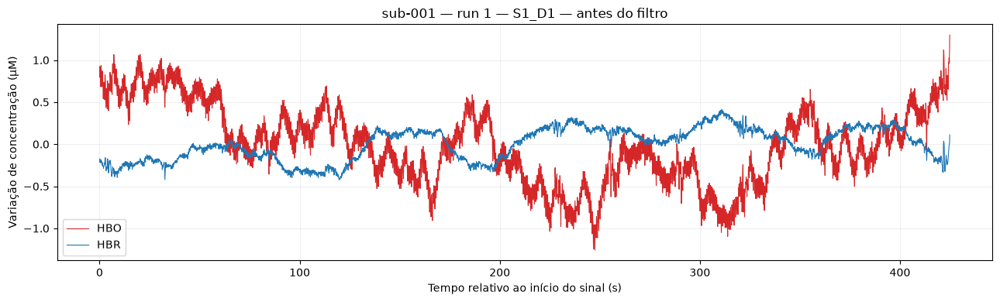

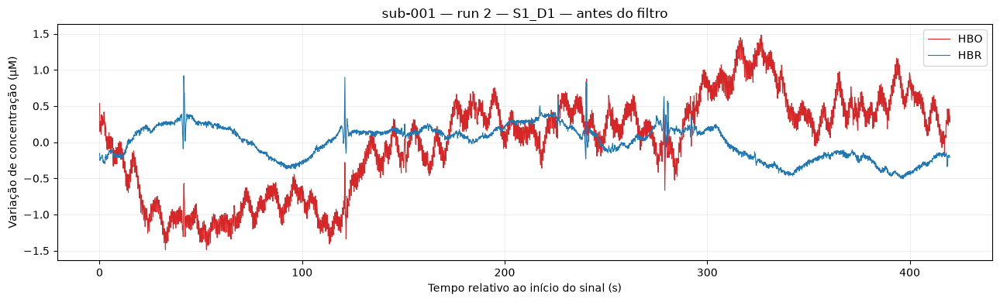

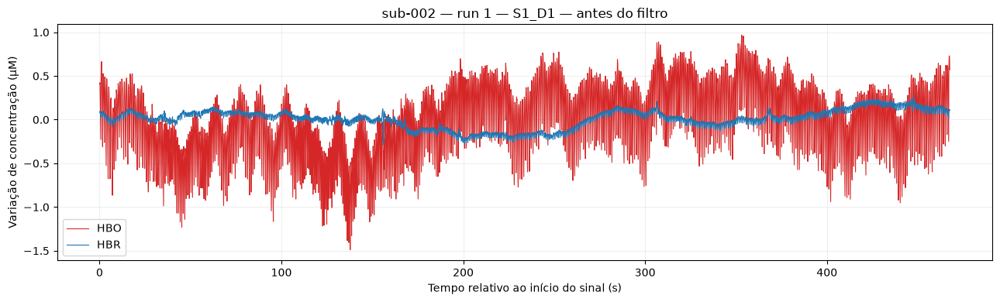

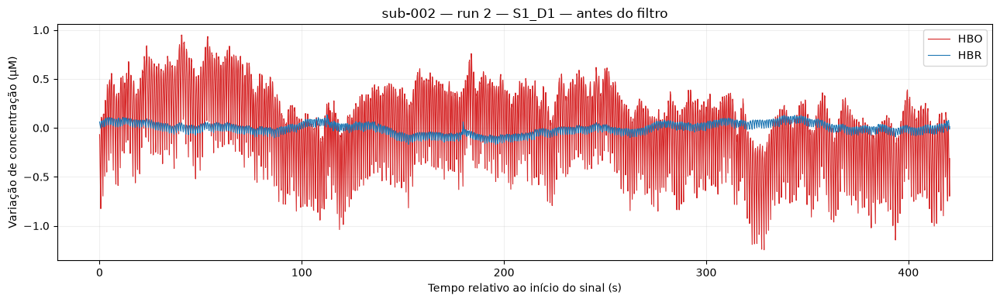


CONVERSÃO PARA HbO E HbR CONCLUÍDA
sujeito  run  n_HbO_total  n_HbR_total  n_HbO_nao_marcados  n_HbR_nao_marcados  n_pares_longos_validos  SSR_aplicada  valores_finitos
sub-001    1           28           28                  19                  19                      19         False             True
sub-001    2           28           28                  22                  22                      19         False             True
sub-002    1           28           28                  20                  20                      20         False             True
sub-002    2           28           28                  20                  20                      20         False             True

PPF utilizado: 6.0
Objetos disponíveis: piloto_haemo[(sujeito, run)].
Os objetos em densidade ótica foram preservados.
Os pares maus continuam presentes e marcados.
As contagens de séries não marcadas incluem canais curtos.
A seleção final dos canais longos ainda não foi efetuada.
Ainda não f

In [8]:
# ============================================================
# ETAPA 7 — CONVERSÃO PARA HbO E HbR
# ============================================================

PPF_PILOTO = 6.0

if set(piloto_od_pre_mbll) != set(piloto_runs):
    raise RuntimeError(
        "Faltam objetos de entrada para alguma run."
    )

if set(piloto_estado_ssr) != set(piloto_runs):
    raise RuntimeError(
        "Falta o registo da política SSR de alguma run."
    )

piloto_haemo = {}
piloto_tabelas_haemo = {}
registos_resumo_mbll = []


# ------------------------------------------------------------
# 7.1 Converter e verificar todas as runs
# ------------------------------------------------------------

for chave, raw_entrada in piloto_od_pre_mbll.items():
    print(
        f"\nA converter para HbO/HbR: "
        f"{chave[0]} — run {chave[1]}..."
    )

    if not all(
        tipo == "fnirs_od"
        for tipo in raw_entrada.get_channel_types()
    ):
        raise RuntimeError(
            f"A entrada não contém apenas densidade ótica: {chave}"
        )

    pares_antes = {
        nome.split()[0]
        for nome in raw_entrada.ch_names
    }

    pares_maus_antes = {
        nome.split()[0]
        for nome in raw_entrada.info["bads"]
    }

    raw_haemo_piloto = mne.preprocessing.nirs.beer_lambert_law(
        raw_entrada,
        ppf=PPF_PILOTO,
    )

    tipos_haemo = raw_haemo_piloto.get_channel_types()

    if not all(
        tipo in ("hbo", "hbr")
        for tipo in tipos_haemo
    ):
        raise RuntimeError(
            f"Tipos de canal inesperados após conversão: {chave}"
        )

    if (
        raw_haemo_piloto.n_times != raw_entrada.n_times
        or raw_haemo_piloto.info["sfreq"] != raw_entrada.info["sfreq"]
        or raw_haemo_piloto.first_samp != raw_entrada.first_samp
    ):
        raise RuntimeError(
            f"A grelha temporal mudou durante a conversão: {chave}"
        )

    anotacoes_preservadas = (
        np.array_equal(
            raw_haemo_piloto.annotations.onset,
            raw_entrada.annotations.onset,
        )
        and np.array_equal(
            raw_haemo_piloto.annotations.duration,
            raw_entrada.annotations.duration,
        )
        and np.array_equal(
            raw_haemo_piloto.annotations.description,
            raw_entrada.annotations.description,
        )
        and (
            raw_haemo_piloto.annotations.orig_time
            == raw_entrada.annotations.orig_time
        )
    )

    if not anotacoes_preservadas:
        raise RuntimeError(
            f"As anotações mudaram durante a conversão: {chave}"
        )

    if not np.isfinite(raw_haemo_piloto.get_data()).all():
        raise RuntimeError(
            f"Existem valores não finitos após conversão: {chave}"
        )

    tabela_haemo = pd.DataFrame({
        "canal": raw_haemo_piloto.ch_names,
        "par": [
            nome.split()[0]
            for nome in raw_haemo_piloto.ch_names
        ],
        "cromoforo": tipos_haemo,
        "marcado_mau": [
            nome in raw_haemo_piloto.info["bads"]
            for nome in raw_haemo_piloto.ch_names
        ],
    })

    geometria_pares = piloto_sci_pares[chave][
        ["par", "distancia_mm", "tipo_distancia"]
    ]

    tabela_haemo = tabela_haemo.merge(
        geometria_pares,
        on="par",
        how="left",
        validate="many_to_one",
        sort=False,
    )

    if tabela_haemo[
        ["distancia_mm", "tipo_distancia"]
    ].isna().any().any():
        raise RuntimeError(
            f"Existem canais sem correspondência geométrica: {chave}"
        )

    pares_depois = set(tabela_haemo["par"])

    pares_maus_depois = set(
        tabela_haemo.loc[
            tabela_haemo["marcado_mau"],
            "par",
        ]
    )

    if pares_depois != pares_antes:
        raise RuntimeError(
            f"A identidade dos pares mudou: {chave}"
        )

    if pares_maus_depois != pares_maus_antes:
        raise RuntimeError(
            f"A identidade dos pares maus mudou: {chave}"
        )

    for par, grupo in tabela_haemo.groupby("par", sort=False):
        if (
            len(grupo) != 2
            or set(grupo["cromoforo"]) != {"hbo", "hbr"}
        ):
            raise RuntimeError(
                f"O par {par} não tem exatamente HbO e HbR: {chave}"
            )

        if grupo["marcado_mau"].nunique() != 1:
            raise RuntimeError(
                f"Qualidade inconsistente entre HbO e HbR "
                f"no par {par}: {chave}"
            )

    piloto_haemo[chave] = raw_haemo_piloto
    piloto_tabelas_haemo[chave] = tabela_haemo

    validos = ~tabela_haemo["marcado_mau"]

    registos_resumo_mbll.append({
        "sujeito": chave[0],
        "run": chave[1],
        "n_HbO_total": int(
            (tabela_haemo["cromoforo"] == "hbo").sum()
        ),
        "n_HbR_total": int(
            (tabela_haemo["cromoforo"] == "hbr").sum()
        ),
        "n_HbO_nao_marcados": int(
            (
                (tabela_haemo["cromoforo"] == "hbo")
                & validos
            ).sum()
        ),
        "n_HbR_nao_marcados": int(
            (
                (tabela_haemo["cromoforo"] == "hbr")
                & validos
            ).sum()
        ),
        "n_pares_longos_validos": int(
            tabela_haemo.loc[
                validos
                & (tabela_haemo["tipo_distancia"] == "longo"),
                "par",
            ].nunique()
        ),
        "SSR_aplicada": piloto_estado_ssr[chave]["SSR_aplicada"],
        "valores_finitos": True,
    })


# ------------------------------------------------------------
# 7.2 Guardar os sinais, tabelas e parâmetros
# ------------------------------------------------------------

for chave, raw_haemo_piloto in piloto_haemo.items():
    objetos = piloto_runs[chave]
    id_gravacao = objetos["id_gravacao"]
    pasta_saida = Path(objetos["pasta_saida_prevista"])

    raw_haemo_piloto.save(
        pasta_saida / f"{id_gravacao}_haemo_unfiltered_raw.fif",
        overwrite=True,
        fmt="double",
        verbose=False,
    )

    piloto_tabelas_haemo[chave].to_csv(
        pasta_saida / f"{id_gravacao}_haemo_channels.csv",
        index=False,
        encoding="utf-8-sig",
    )

    parametros_mbll = {
        "id_gravacao": id_gravacao,
        "pipeline_version": VERSAO_PIPELINE_PILOTO,
        "etapa": 7,
        "mne_version": version("mne"),
        "metodo": "mne.preprocessing.nirs.beer_lambert_law",
        "ppf": PPF_PILOTO,
        "ppf_comum_aos_comprimentos_onda": True,
        "n_series": len(raw_haemo_piloto.ch_names),
        "n_amostras": int(raw_haemo_piloto.n_times),
        "sfreq_hz": float(raw_haemo_piloto.info["sfreq"]),
        "tddr_aplicado": True,
        "SSR_aplicada": piloto_estado_ssr[chave]["SSR_aplicada"],
        "motivo_SSR": piloto_estado_ssr[chave]["motivo"],
        "filtro_hemodinamico_aplicado": False,
        "selecao_final_canais_longos": False,
        "bads": list(raw_haemo_piloto.info["bads"]),
        "anotacoes_preservadas": True,
        "valores_finitos": True,
        "conversao_uM_apenas_na_figura": True,
    }

    (
        pasta_saida / f"{id_gravacao}_mbll_parameters.json"
    ).write_text(
        json.dumps(
            parametros_mbll,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )

    # --------------------------------------------------------
    # 7.3 Inspeção do mesmo par utilizado na etapa TDDR
    # --------------------------------------------------------

    if par_visualizacao_tddr is not None:
        indices_par = [
            indice
            for indice, nome in enumerate(raw_haemo_piloto.ch_names)
            if nome.split()[0] == par_visualizacao_tddr
        ]

        fig_haemo, ax_haemo = plt.subplots(figsize=(13, 4))

        for indice in indices_par:
            cromoforo = (
                raw_haemo_piloto.get_channel_types()[indice]
            )

            ax_haemo.plot(
                raw_haemo_piloto.times,
                raw_haemo_piloto.get_data(picks=[indice])[0] * 1e6,
                color=(
                    "tab:red" if cromoforo == "hbo" else "tab:blue"
                ),
                linewidth=0.8,
                label=cromoforo.upper(),
            )

        ax_haemo.set(
            title=(
                f"{chave[0]} — run {chave[1]} — "
                f"{par_visualizacao_tddr} — antes do filtro"
            ),
            xlabel="Tempo relativo ao início do sinal (s)",
            ylabel="Variação de concentração (µM)",
        )

        ax_haemo.grid(alpha=0.2)
        ax_haemo.legend()
        fig_haemo.tight_layout()

        fig_haemo.savefig(
            pasta_saida / f"{id_gravacao}_haemo_unfiltered.png",
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()


# ------------------------------------------------------------
# 7.4 Resumo
# ------------------------------------------------------------

df_mbll_piloto = pd.DataFrame(registos_resumo_mbll)

print("\n" + "=" * 70)
print("CONVERSÃO PARA HbO E HbR CONCLUÍDA")
print("=" * 70)

print(df_mbll_piloto.to_string(index=False))

print(f"\nPPF utilizado: {PPF_PILOTO}")
print("Objetos disponíveis: piloto_haemo[(sujeito, run)].")
print("Os objetos em densidade ótica foram preservados.")
print("Os pares maus continuam presentes e marcados.")
print("As contagens de séries não marcadas incluem canais curtos.")
print("A seleção final dos canais longos ainda não foi efetuada.")
print("Ainda não foi aplicado o filtro hemodinâmico.")
print("Não foram criadas épocas ou ajustados modelos.")
print("\nEtapa 7 concluída.")

## Etapa 8 — Filtragem temporal de HbO e HbR

### Objetivo
Aplicar o mesmo filtro hemodinâmico às quatro runs,
antes da seleção final dos canais longos e da criação de épocas.

### Parâmetros
- Limite inferior: 0,01 Hz.
- Limite superior: 0,50 Hz.
- Método: IIR Butterworth.
- Parâmetro de desenho: order = 4.
- Representação: secções de segunda ordem, SOS.
- Aplicação: fase zero, nos dois sentidos.

A ordem efetiva reportada pelo MNE inclui a transformação
passa-banda e a aplicação nos dois sentidos.

### Preservação
- piloto_haemo: sinal anterior à filtragem.
- piloto_haemo_filtrado: cópia após filtragem.

Filtrar explicitamente todas as séries HbO e HbR,
incluindo as que estão marcadas como más.

A filtragem não reclassifica canais maus como válidos.

### Verificações
- Frequências compatíveis com a amostragem.
- Valores finitos após filtragem.
- Canais e grelha temporal preservados.
- Anotações e marcações de qualidade preservadas.

### Visualização
Comparar antes e depois no mesmo par longo comum
utilizado nas etapas anteriores, separando HbO e HbR.

A figura é ilustrativa, não uma validação de todos os canais.

### Limitações
A filtragem não substitui o controlo da fisiologia superficial.

A fase zero pode espalhar alterações do sinal para instantes
anteriores e posteriores ao acontecimento.

Não interpretar a posição de uma alteração na curva filtrada
como prova de início instantâneo de uma resposta cerebral.

### Resultados guardados
Por participante e run:
- Sinal filtrado.
- Figura antes/depois.
- Parâmetros e histórico.

### Próxima etapa
Selecionar os canais longos que não estão marcados como maus.


A filtrar sub-001 — run 1: 0.01–0.5 Hz...

A filtrar sub-001 — run 2: 0.01–0.5 Hz...

A filtrar sub-002 — run 1: 0.01–0.5 Hz...

A filtrar sub-002 — run 2: 0.01–0.5 Hz...


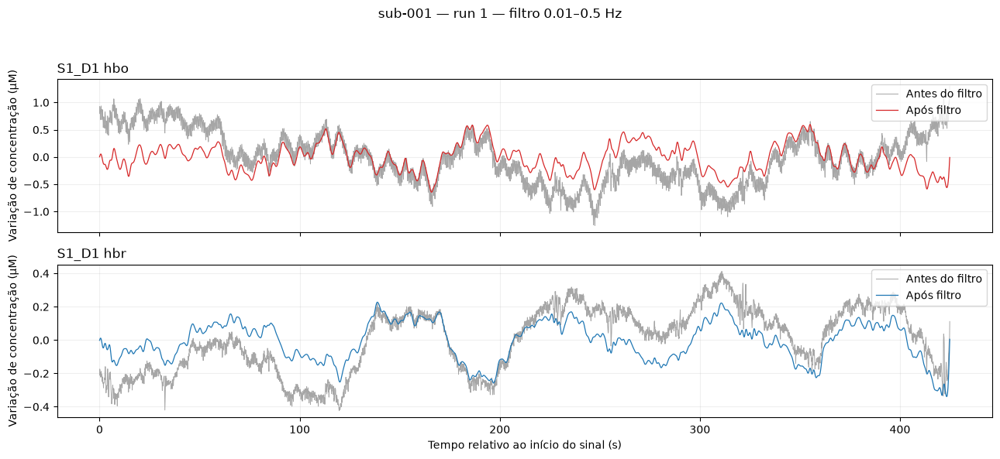

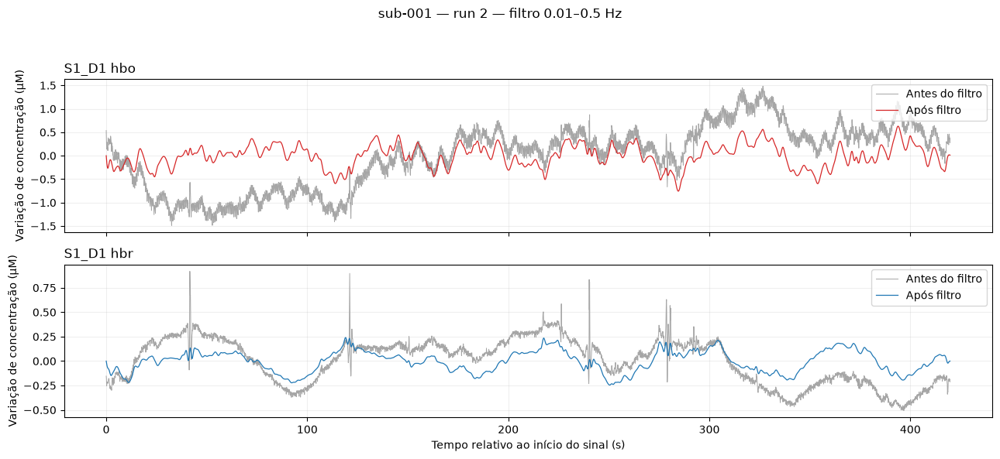

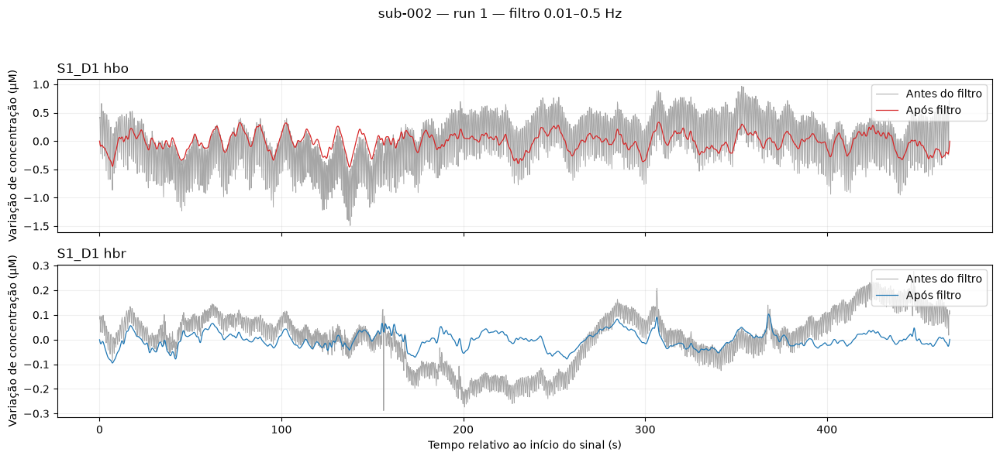

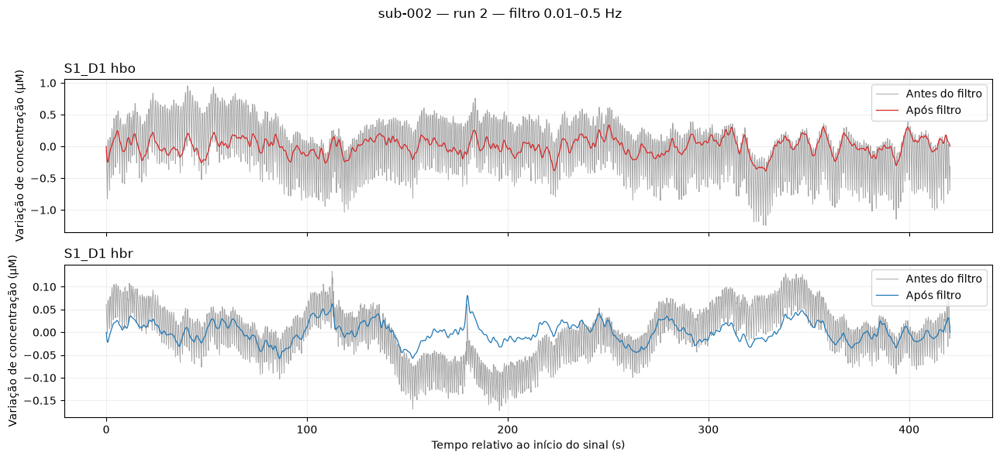


FILTRAGEM HEMODINÂMICA CONCLUÍDA
sujeito  run  n_series  n_series_nao_marcadas  n_amostras  highpass_info_hz  lowpass_info_hz  valores_finitos  bads_preservados  anotacoes_preservadas
sub-001    1        56                     38        4323            0.0100           0.5000             True              True                   True
sub-001    2        56                     44        4271            0.0100           0.5000             True              True                   True
sub-002    1        56                     40        4757            0.0100           0.5000             True              True                   True
sub-002    2        56                     40        4278            0.0100           0.5000             True              True                   True

Filtro: 0.01–0.5 Hz
Método: iir
Parâmetros IIR: {'order': 4, 'ftype': 'butter', 'output': 'sos'}
Fase: zero

Objetos disponíveis: piloto_haemo_filtrado[(sujeito, run)].
Os objetos anteriores em piloto_haemo for

In [9]:
# ============================================================
# ETAPA 8 — FILTRAGEM TEMPORAL DE HbO E HbR
# ============================================================

LOW_CUTOFF_HZ_PILOTO = 0.01
HIGH_CUTOFF_HZ_PILOTO = 0.50

METODO_FILTRO_PILOTO = "iir"
FASE_FILTRO_PILOTO = "zero"

IIR_PARAMS_PILOTO = {
    "order": 4,
    "ftype": "butter",
    "output": "sos",
}

SKIP_ANNOTATIONS_FILTRO_PILOTO = ("edge", "bad_acq_skip")

if set(piloto_haemo) != set(piloto_runs):
    raise RuntimeError(
        "Faltam objetos HbO/HbR para alguma run."
    )

# ------------------------------------------------------------
# 8.1 Verificar as entradas antes de filtrar
# ------------------------------------------------------------

for chave, raw_entrada in piloto_haemo.items():
    if not all(
        tipo in ("hbo", "hbr")
        for tipo in raw_entrada.get_channel_types()
    ):
        raise RuntimeError(
            f"A entrada deve conter apenas HbO e HbR: {chave}"
        )

    nyquist = float(raw_entrada.info["sfreq"]) / 2

    if not (
        0
        < LOW_CUTOFF_HZ_PILOTO
        < HIGH_CUTOFF_HZ_PILOTO
        < nyquist
    ):
        raise ValueError(
            f"Limites do filtro incompatíveis com a amostragem: {chave}"
        )

    if not np.isfinite(raw_entrada.get_data()).all():
        raise RuntimeError(
            f"Existem valores não finitos antes da filtragem: {chave}"
        )


# ------------------------------------------------------------
# 8.2 Filtrar cópias e verificar a integridade
# ------------------------------------------------------------

piloto_haemo_filtrado = {}
registos_resumo_filtro = []

for chave, raw_entrada in piloto_haemo.items():
    print(
        f"\nA filtrar {chave[0]} — run {chave[1]}: "
        f"{LOW_CUTOFF_HZ_PILOTO}–{HIGH_CUTOFF_HZ_PILOTO} Hz..."
    )

    raw_saida = raw_entrada.copy().filter(
        l_freq=LOW_CUTOFF_HZ_PILOTO,
        h_freq=HIGH_CUTOFF_HZ_PILOTO,
        picks=np.arange(len(raw_entrada.ch_names)),
        method=METODO_FILTRO_PILOTO,
        iir_params=IIR_PARAMS_PILOTO.copy(),
        phase=FASE_FILTRO_PILOTO,
        skip_by_annotation=SKIP_ANNOTATIONS_FILTRO_PILOTO,
        pad="reflect_limited",
        verbose=False,
    )

    if (
        raw_saida.ch_names != raw_entrada.ch_names
        or raw_saida.n_times != raw_entrada.n_times
        or raw_saida.first_samp != raw_entrada.first_samp
        or raw_saida.info["sfreq"] != raw_entrada.info["sfreq"]
    ):
        raise RuntimeError(
            f"Canais ou grelha temporal alterados: {chave}"
        )

    if raw_saida.info["bads"] != raw_entrada.info["bads"]:
        raise RuntimeError(
            f"A marcação dos canais maus mudou: {chave}"
        )

    anotacoes_preservadas = (
        np.array_equal(
            raw_saida.annotations.onset,
            raw_entrada.annotations.onset,
        )
        and np.array_equal(
            raw_saida.annotations.duration,
            raw_entrada.annotations.duration,
        )
        and np.array_equal(
            raw_saida.annotations.description,
            raw_entrada.annotations.description,
        )
        and (
            raw_saida.annotations.orig_time
            == raw_entrada.annotations.orig_time
        )
    )

    if not anotacoes_preservadas:
        raise RuntimeError(
            f"As anotações mudaram durante a filtragem: {chave}"
        )

    if not np.isfinite(raw_saida.get_data()).all():
        raise RuntimeError(
            f"Existem valores não finitos após filtragem: {chave}"
        )

    piloto_haemo_filtrado[chave] = raw_saida

    registos_resumo_filtro.append({
        "sujeito": chave[0],
        "run": chave[1],
        "n_series": len(raw_saida.ch_names),
        "n_series_nao_marcadas": (
            len(raw_saida.ch_names)
            - len(raw_saida.info["bads"])
        ),
        "n_amostras": int(raw_saida.n_times),
        "highpass_info_hz": float(raw_saida.info["highpass"]),
        "lowpass_info_hz": float(raw_saida.info["lowpass"]),
        "valores_finitos": True,
        "bads_preservados": True,
        "anotacoes_preservadas": True,
    })


# ------------------------------------------------------------
# 8.3 Guardar sinais, parâmetros e figuras
# ------------------------------------------------------------

for chave, raw_saida in piloto_haemo_filtrado.items():
    objetos = piloto_runs[chave]
    raw_entrada = piloto_haemo[chave]

    pasta_saida = Path(objetos["pasta_saida_prevista"])
    id_gravacao = objetos["id_gravacao"]

    raw_saida.save(
        pasta_saida / f"{id_gravacao}_haemo_filtered_raw.fif",
        overwrite=True,
        fmt="double",
        verbose=False,
    )

    parametros_filtro = {
        "id_gravacao": id_gravacao,
        "pipeline_version": VERSAO_PIPELINE_PILOTO,
        "etapa": 8,
        "mne_version": version("mne"),
        "l_freq_hz": LOW_CUTOFF_HZ_PILOTO,
        "h_freq_hz": HIGH_CUTOFF_HZ_PILOTO,
        "metodo": METODO_FILTRO_PILOTO,
        "phase": FASE_FILTRO_PILOTO,
        "iir_params": IIR_PARAMS_PILOTO.copy(),
        "skip_by_annotation": list(
            SKIP_ANNOTATIONS_FILTRO_PILOTO
        ),
        "pad": "reflect_limited",
        "canais_filtrados": "todas as series HbO e HbR",
        "n_series": len(raw_saida.ch_names),
        "n_amostras": int(raw_saida.n_times),
        "sfreq_hz": float(raw_saida.info["sfreq"]),
        "ppf": PPF_PILOTO,
        "tddr_aplicado": True,
        "SSR_aplicada": piloto_estado_ssr[chave]["SSR_aplicada"],
        "motivo_SSR": piloto_estado_ssr[chave]["motivo"],
        "bads": list(raw_saida.info["bads"]),
        "selecao_final_canais_longos": False,
        "par_visualizacao": par_visualizacao_tddr,
    }

    (
        pasta_saida / f"{id_gravacao}_filter_parameters.json"
    ).write_text(
        json.dumps(
            parametros_filtro,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )

    if par_visualizacao_tddr is not None:
        fig_filtro, eixos_filtro = plt.subplots(
            2,
            1,
            figsize=(13, 6),
            sharex=True,
        )

        for ax, cromoforo in zip(
            eixos_filtro,
            ("hbo", "hbr"),
        ):
            nome_canal = (
                f"{par_visualizacao_tddr} {cromoforo}"
            )

            if nome_canal not in raw_saida.ch_names:
                raise RuntimeError(
                    f"Canal de visualização ausente: {nome_canal}"
                )

            antes = (
                raw_entrada.get_data(picks=[nome_canal])[0]
                * 1e6
            )

            depois = (
                raw_saida.get_data(picks=[nome_canal])[0]
                * 1e6
            )

            ax.plot(
                raw_entrada.times,
                antes,
                color="0.65",
                linewidth=0.7,
                label="Antes do filtro",
            )

            ax.plot(
                raw_saida.times,
                depois,
                color=(
                    "tab:red"
                    if cromoforo == "hbo"
                    else "tab:blue"
                ),
                linewidth=0.9,
                label="Após filtro",
            )

            ax.set_title(nome_canal, loc="left")
            ax.set_ylabel("Variação de concentração (µM)")
            ax.grid(alpha=0.2)
            ax.legend(loc="upper right")

        eixos_filtro[-1].set_xlabel(
            "Tempo relativo ao início do sinal (s)"
        )

        fig_filtro.suptitle(
            f"{chave[0]} — run {chave[1]} — "
            f"filtro {LOW_CUTOFF_HZ_PILOTO}–"
            f"{HIGH_CUTOFF_HZ_PILOTO} Hz"
        )

        fig_filtro.tight_layout(rect=(0, 0, 1, 0.94))

        fig_filtro.savefig(
            pasta_saida / f"{id_gravacao}_filter_comparison.png",
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()


# ------------------------------------------------------------
# 8.4 Resumo
# ------------------------------------------------------------

df_filtro_piloto = pd.DataFrame(registos_resumo_filtro)

print("\n" + "=" * 70)
print("FILTRAGEM HEMODINÂMICA CONCLUÍDA")
print("=" * 70)

print(
    df_filtro_piloto.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.4f}",
    )
)

print(
    f"\nFiltro: {LOW_CUTOFF_HZ_PILOTO}–"
    f"{HIGH_CUTOFF_HZ_PILOTO} Hz"
)
print(f"Método: {METODO_FILTRO_PILOTO}")
print(f"Parâmetros IIR: {IIR_PARAMS_PILOTO}")
print(f"Fase: {FASE_FILTRO_PILOTO}")

print(
    "\nObjetos disponíveis: "
    "piloto_haemo_filtrado[(sujeito, run)]."
)

print("Os objetos anteriores em piloto_haemo foram preservados.")
print("Todos os canais continuam presentes.")
print("Os canais maus continuam marcados.")
print("Não foi aplicada SSR nesta versão de referência.")
print("Não foram criadas épocas ou ajustados modelos.")
print("Resultados guardados nas pastas da versão piloto.")
print("\nEtapa 8 concluída.")

## Etapa 9 — Seleção dos canais longos válidos

### Objetivo
Criar os sinais que serão usados para extrair as épocas,
mantendo apenas os canais longos elegíveis.

### Critérios
- Canal HbO ou HbR.
- Não estar marcado como mau.
- Distância fonte–detetor superior a 15 mm.
- Sem limite máximo adicional nesta versão.

Cada par selecionado deve conter exatamente
uma série HbO e uma série HbR.

“Válido” significa que cumpre estes critérios;
não demonstra origem exclusivamente cortical.

### Preservação
- piloto_haemo_filtrado: todos os canais, preservados.
- piloto_longos: cópia apenas com os canais selecionados.

Não alterar os valores dos canais retidos,
a grelha temporal ou as anotações.

### Diferenças entre runs
A seleção é feita separadamente em cada run.

Não excluir automaticamente de uma run um canal
que foi rejeitado noutra.

Guardar a disponibilidade dos canais para decidir
posteriormente a análise entre participantes.

### Resultados guardados
Por participante e run:
- Sinal contínuo dos canais longos selecionados.
- Tabela de inclusão/exclusão de todos os canais.
- Tabela dos pares incluídos.
- Parâmetros.

### Nesta etapa
Não criar épocas.
Não combinar runs ou participantes.
Não aplicar novos filtros ou correções.

In [4]:
from pathlib import Path
from datetime import datetime
import json
import pandas as pd

PASTA_ESTUDO = Path(
    r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra"
    r"\PhD_Project_ARDITI_Guilherme Saldanha"
    r"\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
)

if not PASTA_ESTUDO.is_dir():
    raise NotADirectoryError(
        f"Pasta do estudo não encontrada:\n{PASTA_ESTUDO}"
    )

sufixo = "_haemo_filtered_raw.fif"
registos = []

for sujeito in ("sub-001", "sub-002"):
    pasta_sujeito = PASTA_ESTUDO / sujeito

    if not pasta_sujeito.is_dir():
        print(f"\nPasta não encontrada: {pasta_sujeito}")
        continue

    ficheiros = sorted(
        pasta_sujeito.rglob(f"*{sufixo}")
    )

    if not ficheiros:
        print(
            f"\nNão foram encontrados FIF filtrados em: "
            f"{pasta_sujeito}"
        )
        continue

    for ficheiro in ficheiros:
        id_gravacao = ficheiro.name[:-len(sufixo)]

        caminho_json = (
            ficheiro.parent
            / f"{id_gravacao}_filter_parameters.json"
        )

        parametros = {}
        estado_json = "ausente"

        if caminho_json.is_file():
            try:
                parametros = json.loads(
                    caminho_json.read_text(encoding="utf-8-sig")
                )
                estado_json = "lido"
            except (OSError, ValueError) as erro:
                estado_json = f"erro: {erro}"

        registos.append({
            "sujeito": sujeito,
            "id_gravacao": id_gravacao,
            "pipeline_version": parametros.get(
                "pipeline_version", "não disponível"
            ),
            "n_amostras": parametros.get("n_amostras"),
            "l_freq_hz": parametros.get("l_freq_hz"),
            "h_freq_hz": parametros.get("h_freq_hz"),
            "SSR_aplicada": parametros.get("SSR_aplicada"),
            "JSON": estado_json,
            "modificacao_local": datetime.fromtimestamp(
                ficheiro.stat().st_mtime
            ).strftime("%Y-%m-%d %H:%M:%S"),
            "caminho": str(ficheiro),
        })

df_localizacao_piloto = pd.DataFrame(registos)

print("\n" + "=" * 70)
print("LOCALIZAÇÃO DOS RESULTADOS FILTRADOS")
print("=" * 70)

for numero, registo in enumerate(registos, start=1):
    print(f"\n[{numero}] {registo['id_gravacao']}")
    print("Versão:", registo["pipeline_version"])
    print("Amostras:", registo["n_amostras"])
    print(
        "Filtro:",
        registo["l_freq_hz"],
        "–",
        registo["h_freq_hz"],
        "Hz",
    )
    print("SSR aplicada:", registo["SSR_aplicada"])
    print("JSON:", registo["JSON"])
    print("Modificação local:", registo["modificacao_local"])
    print("Caminho:", registo["caminho"])

print(f"\nTotal de FIF encontrados: {len(registos)}")
print("Não foram carregados sinais nem alterados ficheiros.")


LOCALIZAÇÃO DOS RESULTADOS FILTRADOS

[1] sub-001_ses-01_tk-dm_run-1_nirs_001
Versão: pilot_dm_epochs_v01
Amostras: 4323
Filtro: 0.01 – 0.5 Hz
SSR aplicada: False
JSON: lido
Modificação local: 2026-11-17 15:52:01
Caminho: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-001_ses-01_tk-dm_run-1_nirs_001\sub-001_ses-01_tk-dm_run-1_nirs_001_haemo_filtered_raw.fif

[2] sub-001_ses-01_tk-dm_run-2_nirs_001
Versão: pilot_dm_epochs_v01
Amostras: 4271
Filtro: 0.01 – 0.5 Hz
SSR aplicada: False
JSON: lido
Modificação local: 2026-11-17 15:52:03
Caminho: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-001_ses-01_tk-dm_run-2_nirs_001\sub-001_ses-01_tk-dm_run-2_nirs_001_h

In [6]:
# ============================================================
# RECUPERAR A SESSÃO ATÉ AO FINAL DA ETAPA 8
#
# Versão: pilot_dm_epochs_v01
# Participantes: sub-001 e sub-002
# Runs: 1 e 2
#
# Não aplica novamente TDDR, MBLL ou filtragem.
# Não grava nem substitui ficheiros.
# ============================================================

from pathlib import Path
from importlib.metadata import version
import json

import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. Configuração e caminhos exatos
# ------------------------------------------------------------

PASTA_ESTUDO = Path(
    r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra"
    r"\PhD_Project_ARDITI_Guilherme Saldanha"
    r"\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
)

VERSAO_RECUPERAR = "pilot_dm_epochs_v01"

GRAVACOES_RECUPERAR = {
    ("sub-001", 1): {
        "id_gravacao": "sub-001_ses-01_tk-dm_run-1_nirs_001",
        "n_amostras": 4323,
        "n_series_nao_marcadas": 38,
    },
    ("sub-001", 2): {
        "id_gravacao": "sub-001_ses-01_tk-dm_run-2_nirs_001",
        "n_amostras": 4271,
        "n_series_nao_marcadas": 44,
    },
    ("sub-002", 1): {
        "id_gravacao": "sub-002_ses-01_tk-dm_run-1_nirs_002",
        "n_amostras": 4757,
        "n_series_nao_marcadas": 40,
    },
    ("sub-002", 2): {
        "id_gravacao": "sub-002_ses-01_tk-dm_run-2_nirs_002",
        "n_amostras": 4278,
        "n_series_nao_marcadas": 40,
    },
}

if not PASTA_ESTUDO.is_dir():
    raise NotADirectoryError(
        f"Pasta do estudo não encontrada:\n{PASTA_ESTUDO}"
    )

caminhos_recuperacao = {}
ficheiros_em_falta = []

for chave, esperado in GRAVACOES_RECUPERAR.items():
    sujeito, run = chave
    id_gravacao = esperado["id_gravacao"]

    pasta_saida = (
        PASTA_ESTUDO
        / sujeito
        / "fNIRS_epochs_derivatives"
        / VERSAO_RECUPERAR
        / id_gravacao
    )

    caminho_fif = (
        pasta_saida
        / f"{id_gravacao}_haemo_filtered_raw.fif"
    )

    caminho_json = (
        pasta_saida
        / f"{id_gravacao}_filter_parameters.json"
    )

    caminhos_recuperacao[chave] = {
        "pasta_saida": pasta_saida,
        "fif": caminho_fif,
        "json": caminho_json,
    }

    for caminho in (caminho_fif, caminho_json):
        if not caminho.is_file():
            ficheiros_em_falta.append(str(caminho))

if ficheiros_em_falta:
    raise FileNotFoundError(
        "Faltam os seguintes ficheiros:\n"
        + "\n".join(ficheiros_em_falta)
    )

print("Os quatro FIF e os quatro JSON foram localizados.")


# ------------------------------------------------------------
# 2. Ler e verificar os parâmetros da Etapa 8
# ------------------------------------------------------------

parametros_recuperados = {}

campos_obrigatorios = [
    "id_gravacao",
    "pipeline_version",
    "l_freq_hz",
    "h_freq_hz",
    "metodo",
    "phase",
    "iir_params",
    "ppf",
    "tddr_aplicado",
    "SSR_aplicada",
    "motivo_SSR",
    "bads",
    "n_series",
    "n_amostras",
    "sfreq_hz",
]

for chave, caminhos in caminhos_recuperacao.items():
    parametros = json.loads(
        caminhos["json"].read_text(encoding="utf-8-sig")
    )

    em_falta = [
        campo
        for campo in campos_obrigatorios
        if campo not in parametros
    ]

    if em_falta:
        raise RuntimeError(
            f"JSON incompleto para {chave}: {em_falta}"
        )

    esperado = GRAVACOES_RECUPERAR[chave]

    if parametros["id_gravacao"] != esperado["id_gravacao"]:
        raise RuntimeError(
            f"O identificador do JSON não corresponde à gravação: {chave}"
        )

    if parametros["pipeline_version"] != VERSAO_RECUPERAR:
        raise RuntimeError(
            f"Versão de pipeline inesperada: {chave}"
        )

    parametros_corretos = (
        np.isclose(float(parametros["l_freq_hz"]), 0.01)
        and np.isclose(float(parametros["h_freq_hz"]), 0.50)
        and parametros["metodo"] == "iir"
        and parametros["phase"] == "zero"
        and parametros["iir_params"] == {
            "order": 4,
            "ftype": "butter",
            "output": "sos",
        }
        and np.isclose(float(parametros["ppf"]), 6.0)
        and parametros["tddr_aplicado"] is True
        and parametros["SSR_aplicada"] is False
    )

    if not parametros_corretos:
        raise RuntimeError(
            f"Os parâmetros não correspondem à versão "
            f"de referência do piloto: {chave}"
        )

    if (
        int(parametros["n_amostras"]) != esperado["n_amostras"]
        or int(parametros["n_series"]) != 56
    ):
        raise RuntimeError(
            f"As dimensões registadas não correspondem "
            f"à execução apresentada: {chave}"
        )

    parametros_recuperados[chave] = parametros

print("Os parâmetros das quatro runs foram verificados.")


# ------------------------------------------------------------
# 3. Carregar os sinais filtrados
# ------------------------------------------------------------

haemo_filtrado_recuperado = {}
runs_recuperadas = {}
estado_ssr_recuperado = {}
registos_recuperacao = []

for chave, caminhos in caminhos_recuperacao.items():
    sujeito, run = chave
    parametros = parametros_recuperados[chave]
    esperado = GRAVACOES_RECUPERAR[chave]

    print(f"\nA carregar {sujeito} — run {run}...")

    raw = mne.io.read_raw_fif(
        caminhos["fif"],
        preload=True,
        verbose=False,
    )

    tipos = raw.get_channel_types()

    if not all(tipo in ("hbo", "hbr") for tipo in tipos):
        raise RuntimeError(
            f"O sinal contém canais diferentes de HbO/HbR: {chave}"
        )

    if (
        len(raw.ch_names) != int(parametros["n_series"])
        or raw.n_times != int(parametros["n_amostras"])
        or not np.isclose(
            float(raw.info["sfreq"]),
            float(parametros["sfreq_hz"]),
        )
    ):
        raise RuntimeError(
            f"As dimensões do FIF diferem do JSON: {chave}"
        )

    if set(raw.info["bads"]) != set(parametros["bads"]):
        raise RuntimeError(
            f"A marcação dos canais maus difere do JSON: {chave}"
        )

    n_nao_marcadas = (
        len(raw.ch_names) - len(raw.info["bads"])
    )

    if n_nao_marcadas != esperado["n_series_nao_marcadas"]:
        raise RuntimeError(
            f"Número inesperado de séries não marcadas: {chave}"
        )

    if (
        not np.isclose(float(raw.info["highpass"]), 0.01)
        or not np.isclose(float(raw.info["lowpass"]), 0.50)
    ):
        raise RuntimeError(
            f"Os metadados do filtro diferem do esperado: {chave}"
        )

    if not np.isfinite(raw.get_data()).all():
        raise RuntimeError(
            f"Existem valores não finitos no sinal: {chave}"
        )

    pares = {}

    for nome, tipo in zip(raw.ch_names, tipos):
        par = nome.split()[0]
        pares.setdefault(par, []).append((nome, tipo))

    for par, series in pares.items():
        if (
            len(series) != 2
            or {tipo for _, tipo in series} != {"hbo", "hbr"}
        ):
            raise RuntimeError(
                f"Par sem HbO/HbR completos: {par}, {chave}"
            )

        estados_maus = {
            nome in raw.info["bads"]
            for nome, _ in series
        }

        if len(estados_maus) != 1:
            raise RuntimeError(
                f"Marcação de qualidade inconsistente "
                f"entre HbO e HbR: {par}, {chave}"
            )

    haemo_filtrado_recuperado[chave] = raw

    runs_recuperadas[chave] = {
        "id_gravacao": esperado["id_gravacao"],
        "pasta_saida_prevista": caminhos["pasta_saida"],
        "ficheiro_filtrado_recuperado": caminhos["fif"],
    }

    estado_ssr_recuperado[chave] = {
        "SSR_aplicada": parametros["SSR_aplicada"],
        "motivo": parametros["motivo_SSR"],
    }

    registos_recuperacao.append({
        "sujeito": sujeito,
        "run": run,
        "n_HbO": tipos.count("hbo"),
        "n_HbR": tipos.count("hbr"),
        "n_series_nao_marcadas": n_nao_marcadas,
        "n_amostras": int(raw.n_times),
        "n_anotacoes": len(raw.annotations),
        "SSR_aplicada": parametros["SSR_aplicada"],
        "valores_finitos": True,
    })


# ------------------------------------------------------------
# 4. Confirmar o limiar dos canais longos
# ------------------------------------------------------------

print(
    "\nOs sinais já foram carregados e verificados.\n"
    "Falta confirmar o limiar para a seleção da Etapa 9."
)

texto_limiar = input(
    "\nIntroduz o limiar mínimo dos canais longos, em mm, "
    "conforme a configuração original.\n"
    "Se confirmaste que era 15 mm, escreve 15 e carrega Enter: "
).strip().replace(",", ".")

try:
    limiar_mm = float(texto_limiar)
except ValueError:
    raise ValueError(
        "O limiar deve ser um número em milímetros, "
        "confirmado na configuração original."
    ) from None

if not np.isfinite(limiar_mm) or limiar_mm <= 0:
    raise ValueError(
        "O limiar deve ser um número positivo e finito."
    )


# ------------------------------------------------------------
# 5. Reconstruir as variáveis necessárias à Etapa 9
# ------------------------------------------------------------

piloto_haemo_filtrado = haemo_filtrado_recuperado
piloto_runs = runs_recuperadas
piloto_estado_ssr = estado_ssr_recuperado

VERSAO_PIPELINE_PILOTO = VERSAO_RECUPERAR

parametros_referencia = parametros_recuperados[
    ("sub-001", 1)
]

PPF_PILOTO = float(parametros_referencia["ppf"])

LOW_CUTOFF_HZ_PILOTO = float(
    parametros_referencia["l_freq_hz"]
)

HIGH_CUTOFF_HZ_PILOTO = float(
    parametros_referencia["h_freq_hz"]
)

METODO_FILTRO_PILOTO = parametros_referencia["metodo"]
FASE_FILTRO_PILOTO = parametros_referencia["phase"]

IIR_PARAMS_PILOTO = dict(
    parametros_referencia["iir_params"]
)

SKIP_ANNOTATIONS_FILTRO_PILOTO = tuple(
    parametros_referencia.get(
        "skip_by_annotation",
        ("edge", "bad_acq_skip"),
    )
)

DISTANCIA_MIN_LONGA_M_PILOTO = limiar_mm / 1000
DISTANCIA_MAX_LONGA_M_PILOTO = None

df_recuperacao_piloto = pd.DataFrame(
    registos_recuperacao
)


# ------------------------------------------------------------
# 6. Resumo da recuperação
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SESSÃO RECUPERADA ATÉ AO FINAL DA ETAPA 8")
print("=" * 70)

print(df_recuperacao_piloto.to_string(index=False))

print(
    "\nVersão da pipeline:",
    VERSAO_PIPELINE_PILOTO,
)

print("Versão atual do MNE:", version("mne"))

print(
    "Versões do MNE registadas nos JSON:",
    sorted({
        p.get("mne_version", "não registada")
        for p in parametros_recuperados.values()
    }),
)

print(
    "Limiar mínimo confirmado para canais longos:",
    limiar_mm,
    "mm",
)

print("\nObjetos disponíveis:")
print("piloto_haemo_filtrado[(sujeito, run)]")
print("piloto_runs[(sujeito, run)]")
print("piloto_estado_ssr[(sujeito, run)]")

print("\nAs anotações foram carregadas dos FIF.")
print("A marcação dos canais maus foi conferida com os JSON.")
print("Não foi repetido qualquer processamento dos sinais.")
print("Não foram gravados ou substituídos ficheiros.")
print("As runs continuam separadas.")

print(
    "\nEsta recuperação disponibiliza as variáveis necessárias "
    "à Etapa 9; não reconstitui todos os objetos das etapas anteriores."
)

print("\nPodes agora executar a célula Python da Etapa 9.")

Os quatro FIF e os quatro JSON foram localizados.
Os parâmetros das quatro runs foram verificados.

A carregar sub-001 — run 1...

A carregar sub-001 — run 2...

A carregar sub-002 — run 1...

A carregar sub-002 — run 2...

Os sinais já foram carregados e verificados.
Falta confirmar o limiar para a seleção da Etapa 9.

SESSÃO RECUPERADA ATÉ AO FINAL DA ETAPA 8
sujeito  run  n_HbO  n_HbR  n_series_nao_marcadas  n_amostras  n_anotacoes  SSR_aplicada  valores_finitos
sub-001    1     28     28                     38        4323           42         False             True
sub-001    2     28     28                     44        4271           42         False             True
sub-002    1     28     28                     40        4757           42         False             True
sub-002    2     28     28                     40        4278           42         False             True

Versão da pipeline: pilot_dm_epochs_v01
Versão atual do MNE: 1.12.1
Versões do MNE registadas nos JSON: [

In [7]:
# ============================================================
# ETAPA 9 — SELEÇÃO DOS CANAIS LONGOS VÁLIDOS
# ============================================================

DISTANCIA_MAX_LONGA_M_PILOTO = None

if set(piloto_haemo_filtrado) != set(piloto_runs):
    raise RuntimeError(
        "Faltam sinais filtrados para alguma run."
    )

if (
    DISTANCIA_MAX_LONGA_M_PILOTO is not None
    and DISTANCIA_MAX_LONGA_M_PILOTO <= DISTANCIA_MIN_LONGA_M_PILOTO
):
    raise ValueError(
        "A distância máxima deve ser superior à mínima."
    )

piloto_longos = {}
piloto_selecao_longos = {}
piloto_pares_longos = {}

registos_resumo_longos = []


# ------------------------------------------------------------
# 9.1 Selecionar e verificar as quatro runs
# ------------------------------------------------------------

for chave, raw_entrada in piloto_haemo_filtrado.items():
    tipos = raw_entrada.get_channel_types()

    if not all(tipo in ("hbo", "hbr") for tipo in tipos):
        raise RuntimeError(
            f"A entrada deve conter apenas HbO e HbR: {chave}"
        )

    distancias_m = (
        mne.preprocessing.nirs.source_detector_distances(
            raw_entrada.info,
            picks=np.arange(len(raw_entrada.ch_names)),
        )
    )

    if (
        not np.isfinite(distancias_m).all()
        or np.any(distancias_m <= 0)
    ):
        raise RuntimeError(
            f"Existem distâncias inválidas: {chave}"
        )

    selecao = pd.DataFrame({
        "canal": raw_entrada.ch_names,
        "par": [
            nome.split()[0]
            for nome in raw_entrada.ch_names
        ],
        "cromoforo": tipos,
        "distancia_mm": distancias_m * 1000,
        "marcado_mau": [
            nome in raw_entrada.info["bads"]
            for nome in raw_entrada.ch_names
        ],
    })

    selecao["acima_distancia_minima"] = (
        distancias_m > DISTANCIA_MIN_LONGA_M_PILOTO
    )

    if DISTANCIA_MAX_LONGA_M_PILOTO is None:
        selecao["dentro_distancia_maxima"] = True
    else:
        selecao["dentro_distancia_maxima"] = (
            distancias_m <= DISTANCIA_MAX_LONGA_M_PILOTO
        )

    selecao["incluido"] = (
        ~selecao["marcado_mau"]
        & selecao["acima_distancia_minima"]
        & selecao["dentro_distancia_maxima"]
    )

    motivos = []

    for linha in selecao.itertuples(index=False):
        motivos_linha = []

        if linha.marcado_mau:
            motivos_linha.append("marcado como mau")

        if not linha.acima_distancia_minima:
            motivos_linha.append("distancia <= minimo")

        if not linha.dentro_distancia_maxima:
            motivos_linha.append("distancia > maximo")

        motivos.append(
            "; ".join(motivos_linha)
            if motivos_linha else "incluido"
        )

    selecao["motivo"] = motivos

    incluidos = selecao.loc[selecao["incluido"]].copy()

    if incluidos.empty:
        raise RuntimeError(
            f"Nenhum canal cumpre os critérios: {chave}"
        )

    for par, grupo in incluidos.groupby("par", sort=False):
        if (
            len(grupo) != 2
            or set(grupo["cromoforo"]) != {"hbo", "hbr"}
        ):
            raise RuntimeError(
                f"Par incompleto após seleção: {par}, {chave}"
            )

    canais_incluidos = incluidos["canal"].tolist()

    raw_selecionado = raw_entrada.copy().pick(
        canais_incluidos
    )

    if raw_selecionado.info["bads"]:
        raise RuntimeError(
            f"O objeto selecionado contém canais maus: {chave}"
        )

    if (
        raw_selecionado.n_times != raw_entrada.n_times
        or raw_selecionado.first_samp != raw_entrada.first_samp
        or raw_selecionado.info["sfreq"] != raw_entrada.info["sfreq"]
    ):
        raise RuntimeError(
            f"A grelha temporal mudou durante a seleção: {chave}"
        )

    if not np.array_equal(
        raw_selecionado.get_data(),
        raw_entrada.get_data(picks=canais_incluidos),
    ):
        raise RuntimeError(
            f"Os valores dos canais retidos mudaram: {chave}"
        )

    if not np.isfinite(raw_selecionado.get_data()).all():
        raise RuntimeError(
            f"Existem valores não finitos: {chave}"
        )

    anotacoes_preservadas = (
        np.array_equal(
            raw_selecionado.annotations.onset,
            raw_entrada.annotations.onset,
        )
        and np.array_equal(
            raw_selecionado.annotations.duration,
            raw_entrada.annotations.duration,
        )
        and np.array_equal(
            raw_selecionado.annotations.description,
            raw_entrada.annotations.description,
        )
        and (
            raw_selecionado.annotations.orig_time
            == raw_entrada.annotations.orig_time
        )
    )

    if not anotacoes_preservadas:
        raise RuntimeError(
            f"As anotações mudaram durante a seleção: {chave}"
        )

    pares_incluidos = (
        incluidos
        .groupby("par", sort=False)
        .agg(
            distancia_mm=("distancia_mm", "first"),
            n_cromoforos=("cromoforo", "nunique"),
        )
        .reset_index()
    )

    piloto_longos[chave] = raw_selecionado
    piloto_selecao_longos[chave] = selecao
    piloto_pares_longos[chave] = pares_incluidos

    registos_resumo_longos.append({
        "sujeito": chave[0],
        "run": chave[1],
        "n_pares": len(pares_incluidos),
        "n_HbO": int(
            (incluidos["cromoforo"] == "hbo").sum()
        ),
        "n_HbR": int(
            (incluidos["cromoforo"] == "hbr").sum()
        ),
        "n_series_total": len(raw_selecionado.ch_names),
        "n_amostras": int(raw_selecionado.n_times),
        "valores_preservados": True,
        "anotacoes_preservadas": True,
    })


# ------------------------------------------------------------
# 9.2 Guardar os resultados
# ------------------------------------------------------------

for chave, raw_selecionado in piloto_longos.items():
    objetos = piloto_runs[chave]
    id_gravacao = objetos["id_gravacao"]
    pasta_saida = Path(objetos["pasta_saida_prevista"])

    raw_selecionado.save(
        pasta_saida / f"{id_gravacao}_long_haemo_raw.fif",
        overwrite=True,
        fmt="double",
        verbose=False,
    )

    piloto_selecao_longos[chave].to_csv(
        pasta_saida / f"{id_gravacao}_long_channel_selection.csv",
        index=False,
        encoding="utf-8-sig",
    )

    piloto_pares_longos[chave].to_csv(
        pasta_saida / f"{id_gravacao}_long_pairs.csv",
        index=False,
        encoding="utf-8-sig",
    )

    parametros_longos = {
        "id_gravacao": id_gravacao,
        "pipeline_version": VERSAO_PIPELINE_PILOTO,
        "etapa": 9,
        "mne_version": version("mne"),
        "distancia_minima_m": DISTANCIA_MIN_LONGA_M_PILOTO,
        "criterio_minimo": "estritamente superior",
        "distancia_maxima_m": DISTANCIA_MAX_LONGA_M_PILOTO,
        "excluir_canais_marcados_maus": True,
        "canais_incluidos": list(raw_selecionado.ch_names),
        "n_pares": len(piloto_pares_longos[chave]),
        "n_amostras": int(raw_selecionado.n_times),
        "ppf": PPF_PILOTO,
        "tddr_aplicado": True,
        "SSR_aplicada": piloto_estado_ssr[chave]["SSR_aplicada"],
        "motivo_SSR": piloto_estado_ssr[chave]["motivo"],
        "filtro": {
            "l_freq_hz": LOW_CUTOFF_HZ_PILOTO,
            "h_freq_hz": HIGH_CUTOFF_HZ_PILOTO,
            "metodo": METODO_FILTRO_PILOTO,
            "fase": FASE_FILTRO_PILOTO,
            "iir_params": IIR_PARAMS_PILOTO.copy(),
        },
        "anotacoes_preservadas": True,
        "runs_combinadas": False,
    }

    (
        pasta_saida / f"{id_gravacao}_long_channel_parameters.json"
    ).write_text(
        json.dumps(
            parametros_longos,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )


# ------------------------------------------------------------
# 9.3 Resumo e disponibilidade dos pares
# ------------------------------------------------------------

df_longos_piloto = pd.DataFrame(registos_resumo_longos)

print("=" * 70)
print("CANAIS LONGOS SELECIONADOS")
print("=" * 70)

print(df_longos_piloto.to_string(index=False))

todos_os_pares = sorted(
    set().union(*[
        set(tabela["par"])
        for tabela in piloto_pares_longos.values()
    ])
)

df_disponibilidade_pares_piloto = pd.DataFrame({
    f"{chave[0]}_run-{chave[1]}": [
        par in set(tabela["par"])
        for par in todos_os_pares
    ]
    for chave, tabela in piloto_pares_longos.items()
}, index=todos_os_pares)

df_disponibilidade_pares_piloto.index.name = "par"

print("\nDisponibilidade dos pares:")
print(df_disponibilidade_pares_piloto.to_string())

print("\nObjetos disponíveis: piloto_longos[(sujeito, run)].")
print("Os objetos completos filtrados foram preservados.")
print("Não foram impostos canais comuns às quatro runs.")
print("Não foram criadas épocas ou combinados participantes.")
print("Resultados guardados nas pastas da versão piloto.")
print("\nEtapa 9 concluída.")

CANAIS LONGOS SELECIONADOS
sujeito  run  n_pares  n_HbO  n_HbR  n_series_total  n_amostras  valores_preservados  anotacoes_preservadas
sub-001    1       19     19     19              38        4323                 True                   True
sub-001    2       19     19     19              38        4271                 True                   True
sub-002    1       20     20     20              40        4757                 True                   True
sub-002    2       20     20     20              40        4278                 True                   True

Disponibilidade dos pares:
       sub-001_run-1  sub-001_run-2  sub-002_run-1  sub-002_run-2
par                                                              
S1_D1           True           True           True           True
S1_D2           True           True           True           True
S2_D1           True           True           True           True
S2_D3           True           True           True           True
S3_D2    

## Etapa 10 — Inspeção das anotações antes da criação de épocas

### Objetivo
Confirmar os marcadores disponíveis nas quatro runs:
- Início do vídeo.
- Início do ecrã de decisão/resposta explícita.
- Resposta do participante, se registada.
- Outros marcadores ou anotações de qualidade.

### Procedimento
Listar todas as anotações e resumir as descrições por run.

Apresentar os tempos relativamente ao início do sinal,
preservando também os onsets originais do MNE.

Não atribuir significado experimental a códigos numéricos
sem confirmar o respetivo mapeamento.

### Nesta etapa
Não alterar os sinais ou as anotações.
Não criar épocas.
Não aplicar baseline.
Não combinar runs.
Não ajustar modelos.

In [2]:
# ============================================================
# ETAPA 10 — INSPEÇÃO DAS ANOTAÇÕES
# ============================================================

import numpy as np
import pandas as pd

if "piloto_longos" not in globals():
    raise RuntimeError(
        "O objeto piloto_longos não existe. "
        "Executar primeiro a recuperação e a Etapa 9."
    )

if set(piloto_longos) != set(piloto_runs):
    raise RuntimeError(
        "As runs de piloto_longos não correspondem a piloto_runs."
    )

piloto_tabelas_anotacoes = {}
resumos_anotacoes = []

for chave in sorted(piloto_longos):
    sujeito, run = chave
    raw = piloto_longos[chave]
    anotacoes = raw.annotations

    # Em anotações associadas a Raw, subtrair first_time
    # para apresentar tempos relativos ao início do sinal.
    onsets_relativos = (
        np.asarray(anotacoes.onset, dtype=float)
        - float(raw.first_time)
    )

    tabela = pd.DataFrame({
        "ordem": np.arange(1, len(anotacoes) + 1),
        "descricao": anotacoes.description,
        "onset_mne_s": anotacoes.onset,
        "onset_relativo_s": onsets_relativos,
        "duracao_s": anotacoes.duration,
    })

    tabela["fim_relativo_s"] = (
        tabela["onset_relativo_s"]
        + tabela["duracao_s"]
    )

    tabela["intervalo_desde_anterior_s"] = (
        tabela["onset_relativo_s"].diff()
    )

    piloto_tabelas_anotacoes[chave] = tabela

    resumo = (
        tabela.groupby("descricao", sort=False)
        .agg(
            n=("ordem", "size"),
            duracao_min_s=("duracao_s", "min"),
            duracao_max_s=("duracao_s", "max"),
            primeiro_onset_s=("onset_relativo_s", "min"),
            ultimo_onset_s=("onset_relativo_s", "max"),
        )
        .reset_index()
    )

    resumo.insert(0, "run", run)
    resumo.insert(0, "sujeito", sujeito)
    resumos_anotacoes.append(resumo)

    print("\n" + "=" * 90)
    print(f"{sujeito} — run {run}")
    print("=" * 90)

    print(
        f"Amostragem: {raw.info['sfreq']:.6f} Hz | "
        f"Amostras: {raw.n_times} | "
        f"Última amostra: {raw.times[-1]:.3f} s"
    )

    print(
        f"first_samp: {raw.first_samp} | "
        f"first_time: {raw.first_time:.6f} s"
    )

    print(
        "orig_time das anotações:",
        anotacoes.orig_time,
    )

    print("\nResumo por descrição:")
    print(
        resumo.to_string(
            index=False,
            float_format=lambda valor: f"{valor:.3f}",
        )
    )

    print("\nSequência completa das anotações:")
    print(
        tabela.to_string(
            index=False,
            float_format=lambda valor: f"{valor:.3f}",
        )
    )

df_resumo_anotacoes_piloto = pd.concat(
    resumos_anotacoes,
    ignore_index=True,
)

print("\n" + "=" * 90)
print("INSPEÇÃO DAS ANOTAÇÕES CONCLUÍDA")
print("=" * 90)

print(
    "Tabelas disponíveis: "
    "piloto_tabelas_anotacoes[(sujeito, run)]."
)

print("Resumo disponível: df_resumo_anotacoes_piloto.")
print("Não foram alterados sinais ou anotações.")
print("Não foram gravados ficheiros.")
print("Não foram criadas épocas nem aplicada baseline.")
print("\nEtapa 10 concluída.")


sub-001 — run 1
Amostragem: 10.172526 Hz | Amostras: 4323 | Última amostra: 424.870 s
first_samp: 0 | first_time: 0.000000 s
orig_time das anotações: 2026-08-04 14:08:30+00:00

Resumo por descrição:
sujeito  run descricao  n  duracao_min_s  duracao_max_s  primeiro_onset_s  ultimo_onset_s
sub-001    1       100  1         10.000         10.000            12.610          12.610
sub-001    1       110 10         10.000         10.000            40.212         357.493
sub-001    1       120 10         10.000         10.000            50.311         368.088
sub-001    1       130 10         10.000         10.000            80.005         389.766
sub-001    1       150 10         10.000         10.000            82.317         390.880
sub-001    1       160  1         10.000         10.000           393.377         393.377

Sequência completa das anotações:
 ordem descricao  onset_mne_s  onset_relativo_s  duracao_s  fim_relativo_s  intervalo_desde_anterior_s
     1       100       12.610   

## Etapa 11 — Reconstrução temporal das tentativas

### Objetivo
Construir uma tabela por tentativa a partir da sequência:
110 → 120 → 130 → 150.

### Identificação das fases
Segundo o código PsychoPy fornecido:
- 110: início da fixação pré-vídeo.
- 120: início do vídeo.
- 130: início da decisão/resposta explícita.
- 150: início da fixação pós-decisão.
- 160: início da fixação final.

### Durações
Calcular os intervalos a partir dos onsets dos marcadores.

Não usar automaticamente os 10 s presentes nas anotações
como duração das fases experimentais.

Os intervalos reconstruídos são definidos pelos marcadores,
não por uma medição independente da apresentação visual.

### Respostas
A ausência de códigos 140–143 nas anotações não demonstra
ausência de respostas comportamentais.

O intervalo 130–150 não é tratado como tempo de reação exato.

### Nesta etapa
Não alterar os sinais.
Não alterar as anotações.
Não criar épocas.
Não aplicar baseline.
Não ajustar modelos.

In [3]:
# ============================================================
# ETAPA 11 — RECONSTRUÇÃO TEMPORAL DAS TENTATIVAS
# ============================================================

import numpy as np
import pandas as pd

if "piloto_tabelas_anotacoes" not in globals():
    raise RuntimeError(
        "Executar primeiro a inspeção das anotações da Etapa 10."
    )

piloto_tempos_tentativas = {}
resumos_temporais = []

for chave in sorted(piloto_tabelas_anotacoes):
    sujeito, run = chave

    tabela = (
        piloto_tabelas_anotacoes[chave]
        .copy()
        .reset_index(drop=True)
    )

    codigos = tabela["descricao"].astype(str).str.strip()

    # A sequência abaixo é a observada nas quatro runs.
    # Se houver diferenças, parar antes de reconstruir intervalos.
    sequencia_esperada = (
        ["100"]
        + ["110", "120", "130", "150"] * 10
        + ["160"]
    )

    if codigos.tolist() != sequencia_esperada:
        raise RuntimeError(
            f"Sequência diferente da esperada em {chave}. "
            "Inspecionar os eventos antes de continuar."
        )

    tempos = tabela["onset_relativo_s"].to_numpy(
        dtype=float
    )

    if (
        not np.isfinite(tempos).all()
        or np.any(np.diff(tempos) <= 0)
    ):
        raise RuntimeError(
            f"Onsets inválidos ou não crescentes: {chave}"
        )

    registos = []

    for tentativa in range(1, 11):
        indice = 1 + (tentativa - 1) * 4

        onset_fixacao = tempos[indice]
        onset_video = tempos[indice + 1]
        onset_decisao = tempos[indice + 2]
        onset_pos = tempos[indice + 3]

        # Próximo 110; na última tentativa, marcador 160.
        onset_seguinte = tempos[indice + 4]

        registos.append({
            "sujeito": sujeito,
            "run": run,
            "tentativa_na_run": tentativa,
            "onset_fixacao_pre_s": onset_fixacao,
            "onset_video_s": onset_video,
            "onset_decisao_s": onset_decisao,
            "onset_fixacao_pos_s": onset_pos,
            "onset_fase_seguinte_s": onset_seguinte,
            "intervalo_110_120_s": onset_video - onset_fixacao,
            "intervalo_120_130_s": onset_decisao - onset_video,
            "intervalo_130_150_s": onset_pos - onset_decisao,
            "intervalo_pos_s": onset_seguinte - onset_pos,
        })

    tabela_tempos = pd.DataFrame(registos)

    colunas_intervalos = [
        "intervalo_110_120_s",
        "intervalo_120_130_s",
        "intervalo_130_150_s",
        "intervalo_pos_s",
    ]

    intervalos = tabela_tempos[
        colunas_intervalos
    ].to_numpy()

    if (
        not np.isfinite(intervalos).all()
        or np.any(intervalos <= 0)
    ):
        raise RuntimeError(
            f"Intervalos inválidos em {chave}"
        )

    piloto_tempos_tentativas[chave] = tabela_tempos

    for coluna in colunas_intervalos:
        valores = tabela_tempos[coluna]

        resumos_temporais.append({
            "sujeito": sujeito,
            "run": run,
            "intervalo": coluna,
            "n": len(valores),
            "min_s": valores.min(),
            "mediana_s": valores.median(),
            "max_s": valores.max(),
        })

    print("\n" + "=" * 100)
    print(f"{sujeito} — run {run}")
    print("=" * 100)

    print(
        tabela_tempos.to_string(
            index=False,
            float_format=lambda valor: f"{valor:.3f}",
        )
    )

df_tempos_tentativas_piloto = pd.concat(
    piloto_tempos_tentativas.values(),
    ignore_index=True,
)

df_resumo_temporal_piloto = pd.DataFrame(
    resumos_temporais
)

print("\n" + "=" * 100)
print("RESUMO DOS INTERVALOS ENTRE MARCADORES")
print("=" * 100)

print(
    df_resumo_temporal_piloto.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.3f}",
    )
)

print(
    "\nTotal de tentativas reconstruídas:",
    len(df_tempos_tentativas_piloto),
)

print(
    "Tabelas por run: "
    "piloto_tempos_tentativas[(sujeito, run)]."
)

print("Tabela conjunta: df_tempos_tentativas_piloto.")
print("Os intervalos não são tempos de reação exatos.")
print("Não foram alterados sinais ou anotações.")
print("Não foram criadas épocas nem aplicada baseline.")
print("Não foram gravados ficheiros.")
print("\nEtapa 11 concluída.")


sub-001 — run 1
sujeito  run  tentativa_na_run  onset_fixacao_pre_s  onset_video_s  onset_decisao_s  onset_fixacao_pos_s  onset_fase_seguinte_s  intervalo_110_120_s  intervalo_120_130_s  intervalo_130_150_s  intervalo_pos_s
sub-001    1                 1               40.212         50.311           80.005               82.317                 84.815               10.099               29.693                2.312            2.498
sub-001    1                 2               84.815         95.462          111.257              113.206                115.703               10.648               15.794                1.950            2.497
sub-001    1                 3              115.703        126.339          151.499              152.889                155.386               10.636               25.160                1.390            2.497
sub-001    1                 4              155.386        165.066          185.003              186.475                188.972                9.681   

## Etapa 12 — Épocas para inspeção das respostas alinhadas aos eventos

### Objetivo
Extrair épocas separadas para:
- Vídeo: marcador 120.
- Decisão/resposta explícita: marcador 130.

### Janela proposta para este piloto
De -1 a +10 s relativamente ao marcador.

Esta janela serve para inspeção.
Não representa a duração completa das fases.

### Versões
- Sem correção de baseline.
- Com baseline de -1 a 0 s.

A baseline pré-vídeo pertence à fixação pré-vídeo.
A baseline pré-decisão pertence ao vídeo.

### Verificações
- Marcadores consistentes com a tabela temporal.
- Erro de arredondamento à grelha de amostragem.
- Janela de vídeo termina antes da decisão.
- Janela de decisão termina antes do próximo vídeo.
- Valores finitos.
- Épocas retidas e motivos de exclusão documentados.

### Rejeição
Manter rejeição por anotações BAD.
Não adicionar limiares de amplitude nesta etapa.

### Preservação
Não alterar os sinais contínuos.
Não combinar runs ou participantes.
Guardar as durações reconstruídas nos metadados.

### Limitações
As épocas não separam as contribuições hemodinâmicas
de fases consecutivas.

Não calcular contrastes ou resultados de grupo nesta etapa.

In [10]:
# ============================================================
# ETAPA 12 — ÉPOCAS DE INSPEÇÃO: VÍDEO E DECISÃO
# ============================================================

from pathlib import Path
import json

import mne
import numpy as np
import pandas as pd

TMIN_EPOCAS_PILOTO = -1.0
TMAX_EPOCAS_PILOTO = 10.0
BASELINE_EPOCAS_PILOTO = (-1.0, 0.0)

FASES_EPOCAS_PILOTO = {
    "video": {
        "codigo": "120",
        "onset": "onset_video_s",
    },
    "decisao": {
        "codigo": "130",
        "onset": "onset_decisao_s",
    },
}

for nome in (
    "piloto_longos",
    "piloto_tempos_tentativas",
    "piloto_runs",
):
    if nome not in globals():
        raise RuntimeError(
            f"Falta {nome}. Executar as etapas anteriores."
        )

if not (
    set(piloto_longos)
    == set(piloto_tempos_tentativas)
    == set(piloto_runs)
):
    raise RuntimeError(
        "Os objetos de entrada não contêm as mesmas runs."
    )


# ------------------------------------------------------------
# 12.1 Definir saídas e impedir substituições
# ------------------------------------------------------------

saidas_epocas_piloto = {}

for chave in sorted(piloto_longos):
    pasta = Path(
        piloto_runs[chave]["pasta_saida_prevista"]
    )

    id_gravacao = piloto_runs[chave]["id_gravacao"]

    for fase in FASES_EPOCAS_PILOTO:
        prefixo = f"{id_gravacao}_{fase}_inspect"

        saidas_epocas_piloto[(chave, fase)] = {
            "sem_baseline": pasta / f"{prefixo}_nobase-epo.fif",
            "com_baseline": pasta / f"{prefixo}_base-epo.fif",
            "metadata": pasta / f"{prefixo}_metadata.csv",
            "drop_log": pasta / f"{prefixo}_drop_log.csv",
            "parametros": pasta / f"{prefixo}_parameters.json",
        }

existentes = [
    str(caminho)
    for saidas in saidas_epocas_piloto.values()
    for caminho in saidas.values()
    if caminho.exists()
]

if existentes:
    raise FileExistsError(
        "Não foram substituídos ficheiros. "
        "Já existem as seguintes saídas:\n"
        + "\n".join(existentes)
    )


# ------------------------------------------------------------
# 12.2 Criar e verificar as épocas antes de guardar
# ------------------------------------------------------------

piloto_epocas_sem_baseline = {}
piloto_epocas_com_baseline = {}
piloto_drop_logs_epocas = {}

registos_epocas = []

for chave in sorted(piloto_longos):
    raw = piloto_longos[chave]

    tabela_tempos = (
        piloto_tempos_tentativas[chave]
        .copy()
        .reset_index(drop=True)
    )

    sfreq = float(raw.info["sfreq"])

    for fase, configuracao in FASES_EPOCAS_PILOTO.items():
        codigo = configuracao["codigo"]

        mascara = np.array([
            str(descricao).strip() == codigo
            for descricao in raw.annotations.description
        ])

        onsets_anotacoes = (
            np.asarray(raw.annotations.onset)[mascara]
            - float(raw.first_time)
        )

        onsets_tabela = tabela_tempos[
            configuracao["onset"]
        ].to_numpy(dtype=float)

        if (
            len(onsets_anotacoes) != len(onsets_tabela)
            or not np.allclose(
                onsets_anotacoes,
                onsets_tabela,
                rtol=0,
                atol=1e-6,
            )
        ):
            raise RuntimeError(
                f"Marcadores e tabela temporal não coincidem: "
                f"{chave}, {fase}"
            )

        indices = raw.time_as_index(
            onsets_tabela,
            use_rounding=True,
        )

        onsets_grelha = indices / sfreq
        erros_ms = (
            onsets_grelha - onsets_tabela
        ) * 1000

        if np.any(
            np.abs(erros_ms) > (500 / sfreq + 1e-6)
        ):
            raise RuntimeError(
                f"Erro de arredondamento inesperado: {chave}, {fase}"
            )

        eventos = np.column_stack([
            indices + raw.first_samp,
            np.zeros(len(indices), dtype=int),
            np.full(len(indices), int(codigo), dtype=int),
        ]).astype(int)

        metadata = tabela_tempos.copy()
        metadata["fase_alinhamento"] = fase
        metadata["codigo_evento"] = int(codigo)
        metadata["onset_evento_s"] = onsets_tabela
        metadata["erro_arredondamento_ms"] = erros_ms

        epocas = mne.Epochs(
            raw,
            events=eventos,
            event_id={fase: int(codigo)},
            tmin=TMIN_EPOCAS_PILOTO,
            tmax=TMAX_EPOCAS_PILOTO,
            baseline=None,
            picks=raw.ch_names,
            preload=True,
            reject=None,
            flat=None,
            detrend=None,
            proj=False,
            decim=1,
            reject_by_annotation=True,
            metadata=metadata,
            event_repeated="error",
            verbose=False,
        )

        # Verificar a janela efetiva, após arredondamento.
        fins_absolutos = (
            onsets_grelha + epocas.times[-1]
        )

        if fase == "video":
            limites = tabela_tempos[
                "onset_decisao_s"
            ].to_numpy(dtype=float)
        else:
            limites = np.r_[
                tabela_tempos["onset_video_s"].to_numpy()[1:],
                np.inf,
            ]

        if np.any(fins_absolutos >= limites):
            raise RuntimeError(
                f"A janela alcança a fase limite: {chave}, {fase}"
            )

        if len(epocas) == 0:
            raise RuntimeError(
                f"Nenhuma época foi retida: {chave}, {fase}"
            )

        if not np.isfinite(epocas.get_data()).all():
            raise RuntimeError(
                f"Valores não finitos: {chave}, {fase}"
            )

        epocas_base = epocas.copy().apply_baseline(
            BASELINE_EPOCAS_PILOTO,
            verbose=False,
        )

        if not np.isfinite(epocas_base.get_data()).all():
            raise RuntimeError(
                f"Valores não finitos após baseline: {chave}, {fase}"
            )

        piloto_epocas_sem_baseline[(chave, fase)] = epocas
        piloto_epocas_com_baseline[(chave, fase)] = epocas_base

        tabela_drop = pd.DataFrame({
            "tentativa_na_run": tabela_tempos[
                "tentativa_na_run"
            ].to_numpy(),
            "retida": [
                len(motivos) == 0
                for motivos in epocas.drop_log
            ],
            "motivo_exclusao": [
                "; ".join(motivos)
                for motivos in epocas.drop_log
            ],
        })

        piloto_drop_logs_epocas[(chave, fase)] = tabela_drop

        registos_epocas.append({
            "sujeito": chave[0],
            "run": chave[1],
            "fase": fase,
            "n_eventos": len(eventos),
            "n_epocas_retidas": len(epocas),
            "n_excluidas": len(eventos) - len(epocas),
            "n_canais": len(epocas.ch_names),
            "tmin_efetivo_s": float(epocas.times[0]),
            "tmax_efetivo_s": float(epocas.times[-1]),
            "max_erro_onset_ms": float(
                np.abs(erros_ms).max()
            ),
        })


# ------------------------------------------------------------
# 12.3 Guardar épocas, metadados e histórico
# ------------------------------------------------------------

for chave_fase, epocas in piloto_epocas_sem_baseline.items():
    chave, fase = chave_fase

    epocas_base = piloto_epocas_com_baseline[chave_fase]
    saidas = saidas_epocas_piloto[chave_fase]

    epocas.save(
        saidas["sem_baseline"],
        fmt="double",
        overwrite=False,
        verbose=False,
    )

    epocas_base.save(
        saidas["com_baseline"],
        fmt="double",
        overwrite=False,
        verbose=False,
    )

    epocas.metadata.to_csv(
        saidas["metadata"],
        index=False,
        encoding="utf-8-sig",
    )

    piloto_drop_logs_epocas[chave_fase].to_csv(
        saidas["drop_log"],
        index=False,
        encoding="utf-8-sig",
    )

    parametros = {
        "pipeline_version": VERSAO_PIPELINE_PILOTO,
        "etapa": 12,
        "id_gravacao": piloto_runs[chave]["id_gravacao"],
        "fase": fase,
        "codigo_evento": FASES_EPOCAS_PILOTO[fase]["codigo"],
        "finalidade": "inspecao; nao separacao de efeitos",
        "tmin_pedido_s": TMIN_EPOCAS_PILOTO,
        "tmax_pedido_s": TMAX_EPOCAS_PILOTO,
        "tmin_efetivo_s": float(epocas.times[0]),
        "tmax_efetivo_s": float(epocas.times[-1]),
        "baseline_s": list(BASELINE_EPOCAS_PILOTO),
        "n_epocas_retidas": len(epocas),
        "reject_by_annotation": True,
        "limiar_amplitude": None,
        "runs_combinadas": False,
        "SSR_aplicada": piloto_estado_ssr[chave]["SSR_aplicada"],
        "canais": epocas.ch_names,
    }

    saidas["parametros"].write_text(
        json.dumps(
            parametros,
            ensure_ascii=False,
            indent=2,
        ),
        encoding="utf-8",
    )


# ------------------------------------------------------------
# 12.4 Resumo
# ------------------------------------------------------------

df_resumo_epocas_piloto = pd.DataFrame(
    registos_epocas
)

print("\n" + "=" * 100)
print("ÉPOCAS DE INSPEÇÃO CRIADAS")
print("=" * 100)

print(
    df_resumo_epocas_piloto.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.4f}",
    )
)

print("\nAcesso aos objetos, por exemplo:")
print("piloto_epocas_sem_baseline[((\"sub-001\", 1), \"video\")]")
print("piloto_epocas_com_baseline[((\"sub-001\", 1), \"decisao\")]")

print("\nOs sinais contínuos não foram alterados.")
print("As runs continuam separadas.")
print("Não foram estimados GLM, contrastes ou efeitos de grupo.")
print("A duração da época não é a duração da fase experimental.")
print("Épocas e histórico guardados nas pastas do piloto.")
print("\nEtapa 12 concluída.")


ÉPOCAS DE INSPEÇÃO CRIADAS
sujeito  run    fase  n_eventos  n_epocas_retidas  n_excluidas  n_canais  tmin_efetivo_s  tmax_efetivo_s  max_erro_onset_ms
sub-001    1   video         10                10            0        38         -0.9830         10.0270            45.2434
sub-001    1 decisao         10                10            0        38         -0.9830         10.0270            45.1549
sub-001    2   video         10                10            0        38         -0.9830         10.0270            48.2195
sub-001    2 decisao         10                10            0        38         -0.9830         10.0270            45.3803
sub-002    1   video         10                10            0        40         -0.9830         10.0270            44.7967
sub-002    1 decisao         10                10            0        40         -0.9830         10.0270            42.6722
sub-002    2   video         10                10            0        40         -0.9830         10.0270

## Etapa 13 — Inspeção visual das épocas por canal

### Objetivo
Inspecionar todas as tentativas e respetivas médias,
separadamente por participante, run, fase e par fonte–detetor.

### Dados
Épocas com baseline de -1 a 0 s.

### Figura
Uma figura por participante e run:
- Linhas: pares fonte–detetor.
- Colunas: vídeo e decisão/resposta explícita.
- Curvas finas: tentativas individuais.
- Curvas espessas: média entre tentativas.
- HbO: vermelho.
- HbR: azul.

Usar a mesma escala vertical entre vídeo e decisão
dentro de cada par, mas não impor uma escala global.

Converter para µM apenas para visualização.

### Limitações
As referências pré-vídeo e pré-decisão são diferentes.

A média alinhada ao início da decisão pode conter
contribuições da fase de vídeo anterior.

Nenhuma época é excluída automaticamente nesta etapa.
Uma curva pouco típica exige inspeção, não exclusão imediata.

### Preservação
Não alterar épocas ou sinais contínuos.
Não combinar runs.
Não calcular contrastes ou efeitos de grupo.

### Saídas
Guardar as figuras PNG nas pastas do piloto.
Não substituir figuras existentes.

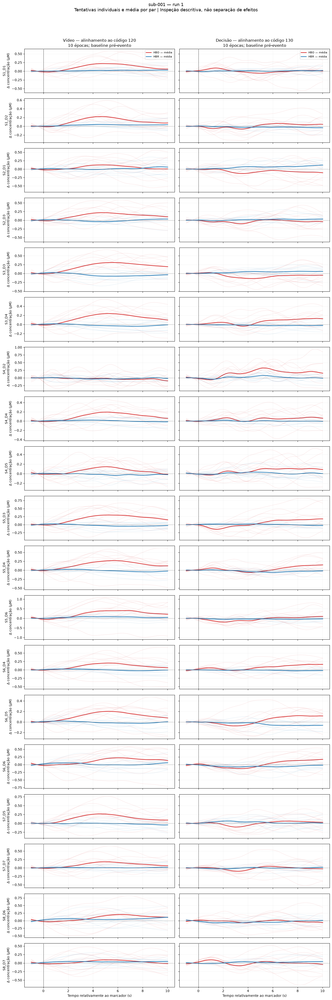

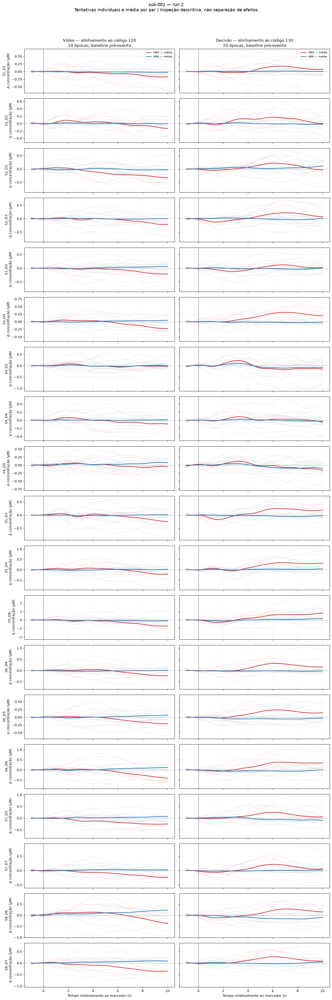

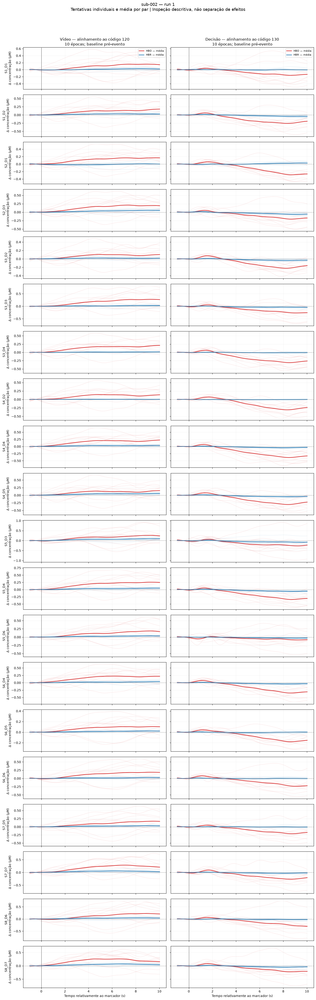

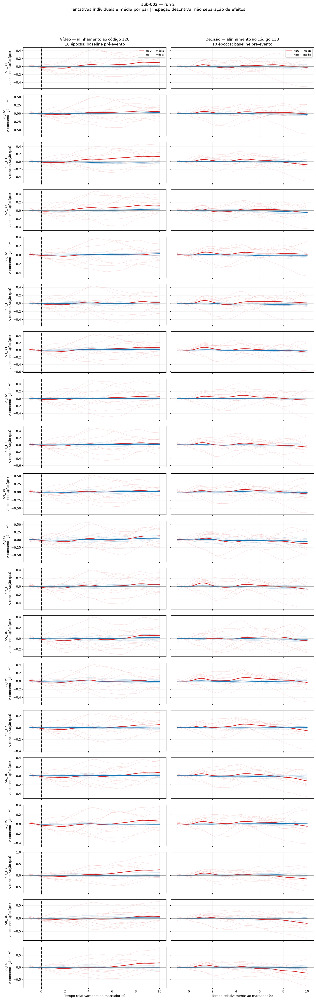


FIGURAS DE INSPEÇÃO CRIADAS
sujeito  run  n_pares  figura_guardada
sub-001    1       19             True
sub-001    2       19             True
sub-002    1       20             True
sub-002    2       20             True

Localização das figuras:

sub-001 — run 1
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-001_ses-01_tk-dm_run-1_nirs_001\sub-001_ses-01_tk-dm_run-1_nirs_001_epochs_baseline_all_pairs.png

sub-001 — run 2
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-001_ses-01_tk-dm_run-2_nirs_001\sub-001_ses-01_tk-dm_run-2_nirs_001_epochs_baseline_all_pairs.png

sub-002 — run 1
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_A

In [11]:
# ============================================================
# ETAPA 13 — INSPEÇÃO VISUAL POR PAR E POR RUN
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "piloto_epocas_com_baseline" not in globals():
    raise RuntimeError(
        "Executar primeiro a Etapa 12."
    )

FASES_INSPECAO = ("video", "decisao")

caminhos_figuras_inspecao = {}

for chave in sorted(piloto_runs):
    for fase in FASES_INSPECAO:
        if (chave, fase) not in piloto_epocas_com_baseline:
            raise RuntimeError(
                f"Faltam épocas para {chave}, {fase}."
            )

    id_gravacao = piloto_runs[chave]["id_gravacao"]

    pasta = Path(
        piloto_runs[chave]["pasta_saida_prevista"]
    )

    caminhos_figuras_inspecao[chave] = (
        pasta
        / f"{id_gravacao}_epochs_baseline_all_pairs.png"
    )

existentes = [
    str(caminho)
    for caminho in caminhos_figuras_inspecao.values()
    if caminho.exists()
]

if existentes:
    raise FileExistsError(
        "As seguintes figuras já existem. "
        "Não foram substituídas:\n"
        + "\n".join(existentes)
    )

registos_figuras = []

for chave in sorted(piloto_runs):
    sujeito, run = chave

    epocas_video = piloto_epocas_com_baseline[
        (chave, "video")
    ]

    epocas_decisao = piloto_epocas_com_baseline[
        (chave, "decisao")
    ]

    if epocas_video.ch_names != epocas_decisao.ch_names:
        raise RuntimeError(
            f"Os canais diferem entre fases: {chave}"
        )

    pares = list(dict.fromkeys(
        nome.split()[0]
        for nome in epocas_video.ch_names
    ))

    dados_por_fase = {}

    for fase in FASES_INSPECAO:
        epocas = piloto_epocas_com_baseline[(chave, fase)]

        if epocas.baseline is None:
            raise RuntimeError(
                f"Épocas sem baseline no objeto esperado: {chave}, {fase}"
            )

        dados = epocas.get_data() * 1e6

        if not np.isfinite(dados).all():
            raise RuntimeError(
                f"Valores não finitos: {chave}, {fase}"
            )

        dados_por_fase[fase] = dados

    fig, eixos = plt.subplots(
        nrows=len(pares),
        ncols=2,
        figsize=(14, 2.2 * len(pares)),
        sharex=True,
        sharey="row",
        squeeze=False,
    )

    for linha, par in enumerate(pares):
        for coluna, fase in enumerate(FASES_INSPECAO):
            ax = eixos[linha, coluna]

            epocas = piloto_epocas_com_baseline[
                (chave, fase)
            ]

            dados = dados_por_fase[fase]

            for cromoforo, cor in (
                ("hbo", "tab:red"),
                ("hbr", "tab:blue"),
            ):
                nome_canal = f"{par} {cromoforo}"

                if nome_canal not in epocas.ch_names:
                    raise RuntimeError(
                        f"Canal ausente: {nome_canal}, {chave}"
                    )

                indice = epocas.ch_names.index(nome_canal)
                curvas = dados[:, indice, :]

                ax.plot(
                    epocas.times,
                    curvas.T,
                    color=cor,
                    alpha=0.18,
                    linewidth=0.6,
                )

                ax.plot(
                    epocas.times,
                    curvas.mean(axis=0),
                    color=cor,
                    linewidth=1.8,
                    label=f"{cromoforo.upper()} — média",
                )

            ax.axvline(
                0,
                color="black",
                linestyle="--",
                linewidth=0.8,
            )

            ax.axhline(
                0,
                color="0.5",
                linewidth=0.5,
            )

            ax.grid(alpha=0.15)

            if coluna == 0:
                ax.set_ylabel(f"{par}\nΔ concentração (µM)")

            if linha == 0:
                titulo = (
                    "Vídeo — alinhamento ao código 120"
                    if fase == "video"
                    else "Decisão — alinhamento ao código 130"
                )

                ax.set_title(
                    f"{titulo}\n"
                    f"{len(epocas)} épocas; baseline pré-evento"
                )

                ax.legend(
                    loc="upper right",
                    fontsize=8,
                )

            if linha == len(pares) - 1:
                ax.set_xlabel(
                    "Tempo relativamente ao marcador (s)"
                )

    fig.suptitle(
        f"{sujeito} — run {run}\n"
        "Tentativas individuais e média por par | "
        "Inspeção descritiva, não separação de efeitos",
        fontsize=13,
        y=0.998,
    )

    fig.tight_layout(rect=(0, 0, 1, 0.98))

    caminho = caminhos_figuras_inspecao[chave]

    fig.savefig(
        caminho,
        dpi=150,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    registos_figuras.append({
        "sujeito": sujeito,
        "run": run,
        "n_pares": len(pares),
        "figura_guardada": caminho.is_file(),
        "caminho": str(caminho),
    })

df_figuras_inspecao_piloto = pd.DataFrame(
    registos_figuras
)

print("\n" + "=" * 90)
print("FIGURAS DE INSPEÇÃO CRIADAS")
print("=" * 90)

print(
    df_figuras_inspecao_piloto[
        ["sujeito", "run", "n_pares", "figura_guardada"]
    ].to_string(index=False)
)

print("\nLocalização das figuras:")

for registo in registos_figuras:
    print(
        f"\n{registo['sujeito']} — run {registo['run']}\n"
        f"{registo['caminho']}"
    )

print("\nNão foram alterados sinais ou épocas.")
print("Não foram excluídas tentativas.")
print("Não foram combinadas runs.")
print("Não foram estimados contrastes ou efeitos de grupo.")
print("\nEtapa 13 concluída.")

## Ponto de paragem — 17/11/2026

### Versão
pilot_dm_epochs_v01

### Estado
Etapas executadas até à Etapa 13, inclusive.

Participantes do piloto:
- sub-001: runs 1 e 2.
- sub-002: runs 1 e 2.

### Processamento registado
- TDDR aplicado.
- Conversão HbO/HbR com PPF = 6.
- Filtro IIR Butterworth, order=4, SOS, fase zero,
  passa-banda de 0,01–0,50 Hz.
- SSR não aplicada nesta versão.
- Seleção de canais longos com distância >15 mm,
  excluindo os marcados como maus.
- 19 pares por run no sub-001.
- 20 pares por run no sub-002.
- Runs mantidas separadas.

### Eventos e épocas
- 40 tentativas reconstruídas: 10 por run.
- 120: início do vídeo.
- 130: início da decisão/resposta explícita.
- Intervalos reconstruídos entre marcadores;
  não usar os 10 s das anotações como duração real das fases.
- Épocas de inspeção pedidas de -1 a +10 s.
- Versões sem baseline e com baseline de -1 a 0 s guardadas.
- Dez épocas retidas por fase e run.
- Figuras por par e run guardadas.

### Interpretação
Inspeção visual preliminar realizada.
Diferenças entre runs e semelhanças entre canais
necessitam de investigação.
Não foram decididas novas exclusões.
Não considerar o sinal validado para inferência cortical.

### Pendências
- Guardar em ficheiro as tabelas temporais das Etapas 10–11,
  ou reconstruí-las a partir das anotações ao retomar.
- Confirmar o mapeamento dos eventos com a versão da tarefa
  efetivamente usada na recolha.
- Preparar e verificar a matriz do GLM.
- Verificar compatibilidade entre filtragem e modelo.
- Definir o controlo da fisiologia sistémica.
- Não combinar runs nem executar análise de grupo nesta fase.

### Retoma
Carregar os derivados já guardados desta versão.
Não executar indiscriminadamente todas as células:
algumas substituem ficheiros e outras param se já existirem saídas.
Não é necessário repetir o pré-processamento para recuperar a sessão.

GLM, betas e contrastes desta nova pipeline ainda não estimados.

In [1]:
from pathlib import Path
import mne

PASTA_ESTUDO = Path(
    r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra"
    r"\PhD_Project_ARDITI_Guilherme Saldanha"
    r"\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
)

VERSAO_PIPELINE_PILOTO = "pilot_dm_epochs_v01"

esperados = {
    ("sub-001", 1): (4323, 38),
    ("sub-001", 2): (4271, 38),
    ("sub-002", 1): (4757, 40),
    ("sub-002", 2): (4278, 40),
}

runs_retoma = {}
longos_retoma = {}

for (sujeito, run), (n_amostras, n_series) in esperados.items():
    id_gravacao = f"{sujeito}_ses-01_tk-dm_run-{run}_nirs_{sujeito[-3:]}"
    pasta = (
        PASTA_ESTUDO / sujeito / "fNIRS_epochs_derivatives"
        / VERSAO_PIPELINE_PILOTO / id_gravacao
    )
    caminho = pasta / f"{id_gravacao}_long_haemo_raw.fif"

    if not caminho.is_file():
        raise FileNotFoundError(f"Derivado da Etapa 9 não encontrado:\n{caminho}")

    raw = mne.io.read_raw_fif(caminho, preload=True, verbose=False)
    tipos = raw.get_channel_types()

    if (
        raw.n_times != n_amostras
        or len(raw.ch_names) != n_series
        or tipos.count("hbo") != n_series // 2
        or tipos.count("hbr") != n_series // 2
        or raw.info["bads"]
        or len(raw.annotations) != 42
    ):
        raise RuntimeError(f"O ficheiro não corresponde ao piloto esperado: {caminho}")

    chave = (sujeito, run)
    longos_retoma[chave] = raw
    runs_retoma[chave] = {
        "id_gravacao": id_gravacao,
        "pasta_saida_prevista": pasta,
    }

    print(
        f"{sujeito} | run {run} | {n_amostras} amostras | "
        f"{n_series // 2} pares | {len(raw.annotations)} anotações"
    )

piloto_longos = longos_retoma
piloto_runs = runs_retoma

print("Retoma concluída: quatro runs carregadas, nenhum ficheiro alterado.")

sub-001 | run 1 | 4323 amostras | 19 pares | 42 anotações
sub-001 | run 2 | 4271 amostras | 19 pares | 42 anotações
sub-002 | run 1 | 4757 amostras | 20 pares | 42 anotações
sub-002 | run 2 | 4278 amostras | 20 pares | 42 anotações
Retoma concluída: quatro runs carregadas, nenhum ficheiro alterado.


## Etapa 14 — Construção e auditoria da matriz do GLM

### Objetivo
Construir uma matriz de desenho por run e verificar se os
regressores de vídeo e de decisão/resposta explícita são
suficientemente distintos antes de ajustar o modelo.

### Entradas
- `piloto_longos`: sinais contínuos HbO/HbR da Etapa 9.
  Nesta etapa, fornecem a grelha temporal de cada run;
  os valores dos sinais não são usados para ajustar o modelo.
- `piloto_tempos_tentativas`: onsets e intervalos entre
  marcadores, reconstruídos na Etapa 11.
- Quatro runs analisadas separadamente, com dez tentativas
  por run.

### Definição dos regressores
- **Vídeo:** início no marcador `120`; duração operacional
  dada pelo intervalo `120 → 130`.
- **Decisão/resposta explícita:** início no marcador `130`;
  duração operacional dada pelo intervalo `130 → 150`.

O marcador `130` corresponde ao início do ecrã de decisão,
não ao clique. O intervalo `130 → 150` não é tratado como
tempo de reação. Não usar os 10 s inscritos nas anotações
como duração das fases. A correspondência dos marcadores
com a versão PsychoPy usada na recolha continua por confirmar.

### Construção da matriz
- Convoluir os regressores de tarefa com a resposta
  hemodinâmica canónica SPM, como escolha provisória.
- Comparar os regressores convolvidos antes e depois de
  aplicar o filtro da Etapa 8: passa-banda de 0,01–0,50 Hz,
  IIR Butterworth (`order=4`), SOS e fase zero.
- Incluir uma constante não filtrada nas duas versões.
- Não acrescentar termos de deriva nem regressores
  fisiológicos nesta auditoria inicial.

### Verificações
- Confirmar dez eventos de cada fase por run.
- Verificar o posto da matriz: o valor esperado é 3.
- Comparar a correlação entre os regressores de vídeo e
  decisão e o número de condição da matriz padronizada.
- Inspecionar visualmente os regressores antes e depois
  da filtragem.

Um posto de 3 indica independência linear, mas não garante
que os efeitos possam ser estimados com precisão se os
regressores forem muito semelhantes.

### Saídas
- `piloto_eventos_glm`: tabela de eventos por run.
- `piloto_matrizes_glm`: matrizes com e sem filtragem dos
  regressores de tarefa, por run.
- `df_auditoria_glm_piloto`: oito linhas de diagnóstico,
  duas por run.

### Limites desta etapa
Não ajustar o GLM, estimar betas ou contrastes, combinar
runs ou gravar ficheiros. As épocas com baseline foram
criadas para inspeção e não são usadas nesta etapa.

Uma matriz bem condicionada não resolve o confundimento
fisiológico. A SSR não foi aplicada nesta versão do piloto
e o controlo da fisiologia sistémica continua pendente.

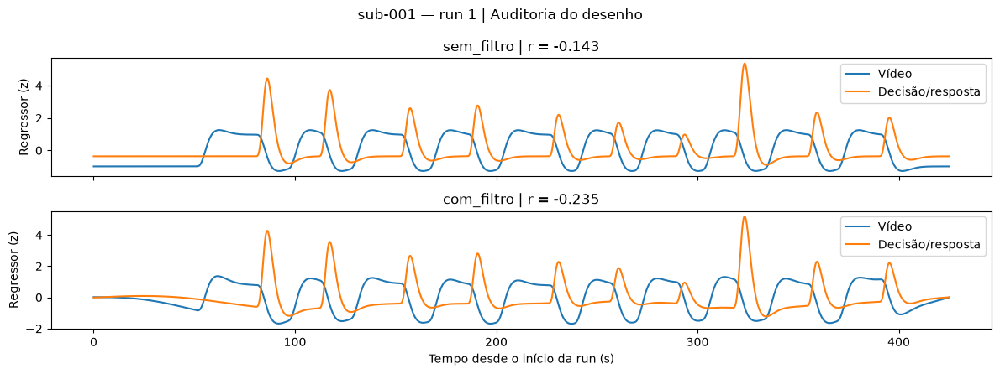

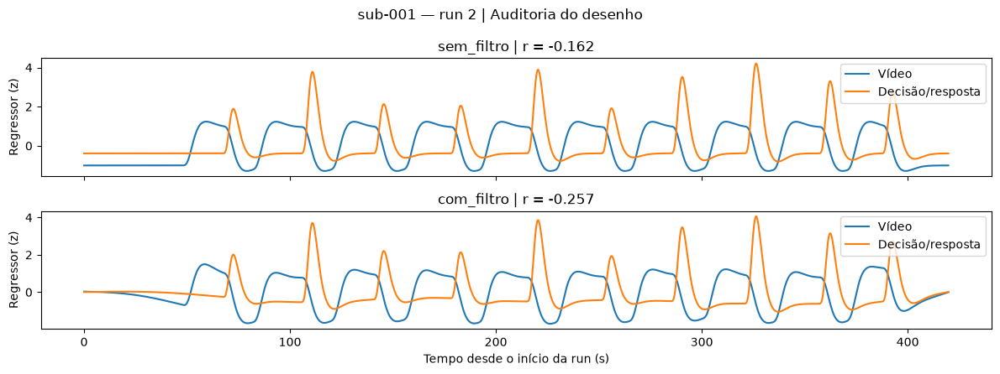

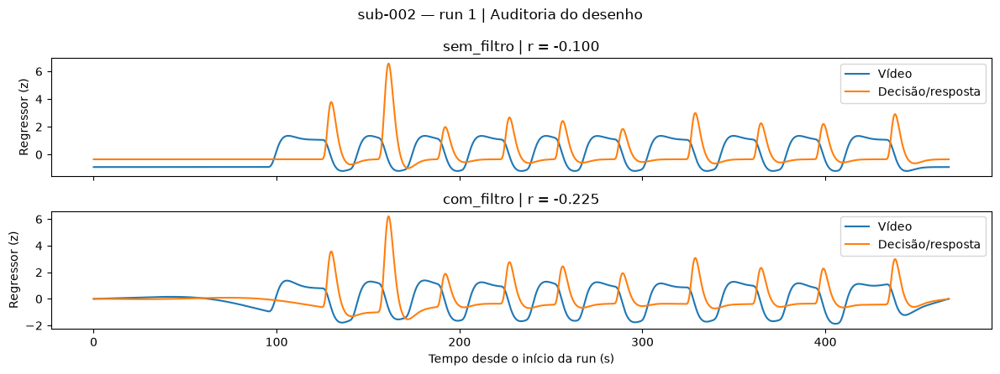

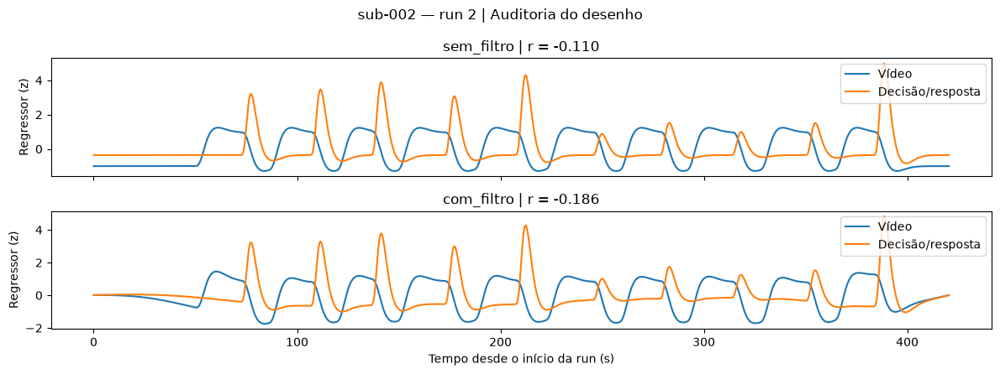


AUDITORIA DAS MATRIZES DO GLM
sujeito  run regressores  n_amostras  posto  n_colunas  r_video_decisao  condicao_padronizada
sub-001    1  sem_filtro        4323      3          3          -0.1429                1.1548
sub-001    1  com_filtro        4323      3          3          -0.2354                1.2711
sub-001    2  sem_filtro        4271      3          3          -0.1622                1.1778
sub-001    2  com_filtro        4271      3          3          -0.2569                1.3006
sub-002    1  sem_filtro        4757      3          3          -0.1003                1.1058
sub-002    1  com_filtro        4757      3          3          -0.2248                1.2570
sub-002    2  sem_filtro        4278      3          3          -0.1098                1.1166
sub-002    2  com_filtro        4278      3          3          -0.1864                1.2076

Matrizes em memória: piloto_matrizes_glm[(sujeito, run)]
Nenhum GLM ajustado. Nenhum ficheiro alterado.


In [4]:
import warnings

import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nilearn.glm.first_level import make_first_level_design_matrix

if not {"piloto_longos", "piloto_tempos_tentativas"} <= globals().keys():
    raise RuntimeError("Executa a célula de retoma e as Etapas 10–11.")

if (
    set(piloto_longos) != set(piloto_tempos_tentativas)
    or len(piloto_longos) != 4
):
    raise RuntimeError("Esperavam-se as mesmas quatro runs nos dois objetos.")

COLUNAS_TAREFA = ["video", "decisao"]
HRF_PILOTO = "spm"

piloto_eventos_glm = {}
piloto_matrizes_glm = {}
registos_auditoria = []

for chave, raw in sorted(piloto_longos.items()):
    sujeito, run = chave
    tentativas = piloto_tempos_tentativas[chave]
    tempos = raw.times
    sfreq = float(raw.info["sfreq"])

    if len(tentativas) != 10:
        raise RuntimeError(f"{chave}: esperavam-se 10 tentativas.")

    # A Etapa 8 trataria estes segmentos separadamente.
    # Este código só reproduz o filtro para uma run contínua.
    if any(
        str(d).lower().startswith(("edge", "bad_acq_skip"))
        for d in raw.annotations.description
    ):
        raise RuntimeError(f"{chave}: verificar os segmentos antes de filtrar.")

    eventos = pd.concat(
        [
            pd.DataFrame({
                "trial_type": fase,
                "onset": tentativas[coluna_onset].to_numpy(dtype=float),
                "duration": tentativas[coluna_duracao].to_numpy(dtype=float),
            })
            for fase, coluna_onset, coluna_duracao in [
                ("video", "onset_video_s", "intervalo_120_130_s"),
                ("decisao", "onset_decisao_s", "intervalo_130_150_s"),
            ]
        ],
        ignore_index=True,
    ).sort_values("onset", ignore_index=True)

    if (
        not np.isfinite(eventos[["onset", "duration"]].to_numpy()).all()
        or (eventos["duration"] <= 0).any()
        or (eventos["onset"] < tempos[0]).any()
        or ((eventos["onset"] + eventos["duration"]) > tempos[-1]).any()
    ):
        raise RuntimeError(f"{chave}: eventos inválidos ou fora do sinal.")

    # Não aceitar silenciosamente uma matriz regularizada pelo Nilearn.
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        desenho = make_first_level_design_matrix(
            frame_times=tempos,
            events=eventos,
            hrf_model=HRF_PILOTO,
            drift_model=None,
            oversampling=50,
        )

    for aviso in avisos:
        mensagem = str(aviso.message)
        if "singular" in mensagem.lower():
            raise RuntimeError(f"{chave}: {mensagem}")
        print(f"Aviso {chave}: {mensagem}")

    X_tarefa = desenho[COLUNAS_TAREFA].to_numpy()

    X_filtrada = mne.filter.filter_data(
        X_tarefa.T.copy(),
        sfreq=sfreq,
        l_freq=0.01,
        h_freq=0.50,
        method="iir",
        iir_params={"order": 4, "ftype": "butter", "output": "sos"},
        phase="zero",
        pad="reflect_limited",
        verbose=False,
    ).T

    piloto_eventos_glm[chave] = eventos
    piloto_matrizes_glm[chave] = {}

    fig, eixos = plt.subplots(2, 1, figsize=(12, 4.5), sharex=True)

    for ax, (versao, X) in zip(eixos, [
        ("sem_filtro", X_tarefa),
        ("com_filtro", X_filtrada),
    ]):
        desvios = X.std(axis=0)
        if not np.isfinite(X).all() or np.any(desvios <= 0):
            raise RuntimeError(f"{chave}, {versao}: regressor inválido.")

        matriz = np.column_stack([X, np.ones(len(X))])
        # A padronização só serve para o diagnóstico e para a figura.
        Z = (X - X.mean(axis=0)) / desvios
        matriz_padronizada = np.column_stack([Z, np.ones(len(Z))])
        r = float(np.corrcoef(Z.T)[0, 1])

        piloto_matrizes_glm[chave][versao] = pd.DataFrame(
            matriz,
            index=pd.Index(tempos, name="tempo_s"),
            columns=COLUNAS_TAREFA + ["constante"],
        )

        registos_auditoria.append({
            "sujeito": sujeito,
            "run": run,
            "regressores": versao,
            "n_amostras": len(X),
            "posto": np.linalg.matrix_rank(matriz),
            "n_colunas": matriz.shape[1],
            "r_video_decisao": r,
            "condicao_padronizada": np.linalg.cond(matriz_padronizada),
        })

        ax.plot(tempos, Z[:, 0], label="Vídeo")
        ax.plot(tempos, Z[:, 1], label="Decisão/resposta")
        ax.set_title(f"{versao} | r = {r:.3f}")
        ax.set_ylabel("Regressor (z)")
        ax.legend(loc="upper right")

    eixos[-1].set_xlabel("Tempo desde o início da run (s)")
    fig.suptitle(f"{sujeito} — run {run} | Auditoria do desenho")
    fig.tight_layout()
    plt.show()
    plt.close(fig)

df_auditoria_glm_piloto = pd.DataFrame(registos_auditoria)

print("\nAUDITORIA DAS MATRIZES DO GLM")
print(df_auditoria_glm_piloto.to_string(index=False, float_format="%.4f"))
print("\nMatrizes em memória: piloto_matrizes_glm[(sujeito, run)]")
print("Nenhum GLM ajustado. Nenhum ficheiro alterado.")

## Etapa 15 — Primeiro ajuste exploratório do GLM por run

### Objetivo
Estimar betas exploratórios por canal e cromóforo e verificar
a qualidade do ajuste e a estrutura temporal dos resíduos.

### Entradas
- Sinais contínuos de `piloto_longos`, sem baseline de épocas.
- Matriz `com_filtro` da Etapa 14: vídeo, decisão e constante.
- Regressores nas escalas originais, não em z.
- Quatro runs mantidas separadas.

### Ajuste e diagnóstico
- Mínimos quadrados ordinários (OLS) por série HbO/HbR.
- Registar betas, R² descritivo e RMSE por série.
- Calcular a autocorrelação residual a 1 amostra e a cerca de 1 s.
- Mostrar sinal observado, ajustado e residual num par comum.

### Saídas
Guardar, por run, um CSV novo com os betas e os diagnósticos.
Manter as previsões e os resíduos completos em memória.
Não substituir ficheiros existentes.

### Limites
Sem testes de significância, contrastes ou análise de grupo.
Sem regressão de canais curtos ou regressão fisiológica.
Os betas não representam efeitos corticais isolados.

ETAPA 15 — RESUMO DO AJUSTE EXPLORATÓRIO
sujeito  run cromoforo  n_series  r2_mediano  rmse_mediano_uM  acf_lag1_mediana  acf_aprox_1s_mediana
sub-001    1       hbo        19      0.0279           0.2256            0.9990                0.9132
sub-001    1       hbr        19      0.0138           0.1149            0.9993                0.9459
sub-001    2       hbo        19      0.1133           0.2261            0.9988                0.8924
sub-001    2       hbr        19      0.0555           0.1076            0.9991                0.9259
sub-002    1       hbo        20      0.1876           0.1636            0.9987                0.8964
sub-002    1       hbr        20      0.1038           0.0311            0.9990                0.9237
sub-002    2       hbo        20      0.0593           0.1404            0.9980                0.8480
sub-002    2       hbr        20      0.0515           0.0268            0.9988                0.9123

Total de séries ajustadas: 156

CSV guar

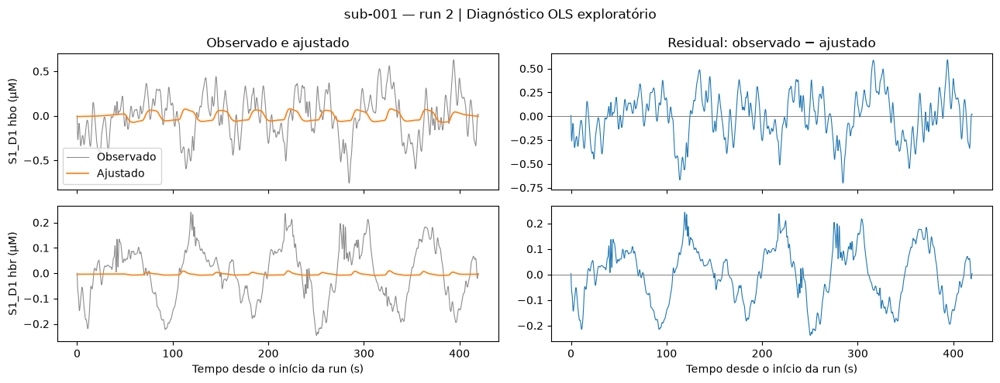


Etapa 15 concluída. Sem testes, contrastes ou combinação de runs.


In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

necessarios = {"piloto_longos", "piloto_matrizes_glm", "piloto_runs"}
em_falta = necessarios - globals().keys()
if em_falta:
    raise RuntimeError(f"Faltam objetos da sessão: {sorted(em_falta)}")

runs_esperadas = {
    ("sub-001", 1): 38,
    ("sub-001", 2): 38,
    ("sub-002", 1): 40,
    ("sub-002", 2): 40,
}

if any(set(globals()[nome]) != set(runs_esperadas) for nome in necessarios):
    raise RuntimeError("Os três objetos devem conter as mesmas quatro runs.")

GUARDAR_CSV_ETAPA15 = True
colunas = ["video", "decisao", "constante"]

caminhos = {}
for chave in sorted(runs_esperadas):
    info = piloto_runs[chave]
    pasta = Path(info["pasta_saida_prevista"])
    if GUARDAR_CSV_ETAPA15 and not pasta.is_dir():
        raise NotADirectoryError(pasta)
    caminhos[chave] = pasta / f"{info['id_gravacao']}_etapa15_ols_exploratorio.csv"

if GUARDAR_CSV_ETAPA15:
    existentes = [str(p) for p in caminhos.values() if p.exists()]
    if existentes:
        raise FileExistsError(
            "Não serão substituídos ficheiros:\n" + "\n".join(existentes)
        )


def autocorrelacao_residual(residuos, lag):
    """ACF descritiva por série, normalizada pela energia total."""
    centrados = residuos - residuos.mean(axis=0)
    denominador = np.sum(centrados ** 2, axis=0)
    numerador = np.sum(centrados[:-lag] * centrados[lag:], axis=0)
    return np.divide(
        numerador,
        denominador,
        out=np.full(denominador.shape, np.nan),
        where=denominador > 0,
    )


ajustes = {}
tabelas = []

for chave, n_series in sorted(runs_esperadas.items()):
    sujeito, run = chave
    raw = piloto_longos[chave]
    desenho = piloto_matrizes_glm[chave]["com_filtro"]
    tipos = raw.get_channel_types()
    tempos = raw.times

    if list(desenho.columns) != colunas:
        raise RuntimeError(f"{chave}: colunas da matriz diferentes do esperado.")

    if len(desenho) != raw.n_times or not np.allclose(
        desenho.index.to_numpy(dtype=float), tempos, rtol=0, atol=1e-8
    ):
        raise RuntimeError(f"{chave}: sinal e matriz não têm a mesma grelha temporal.")

    if (
        len(raw.ch_names) != n_series
        or tipos.count("hbo") != n_series // 2
        or tipos.count("hbr") != n_series // 2
        or raw.info["bads"]
    ):
        raise RuntimeError(f"{chave}: canais diferentes dos esperados na Etapa 9.")

    if any(
        str(d).strip().lower().startswith(("bad", "edge"))
        for d in raw.annotations.description
    ):
        raise RuntimeError(f"{chave}: rever anotações BAD/EDGE antes do ajuste.")

    X = desenho.to_numpy(dtype=float)
    Y = raw.get_data().T  # amostras × séries, nas unidades internas do MNE

    if not (np.isfinite(X).all() and np.isfinite(Y).all()):
        raise RuntimeError(f"{chave}: matriz ou sinal com valores não finitos.")
    if not np.allclose(X[:, 2], 1.0, rtol=0, atol=1e-12):
        raise RuntimeError(f"{chave}: a coluna constante não é unitária.")

    betas, _, posto, _ = np.linalg.lstsq(X, Y, rcond=None)
    if posto != len(colunas):
        raise RuntimeError(f"{chave}: a matriz não tem posto completo.")

    ajustado = X @ betas
    residuos = Y - ajustado
    sse = np.sum(residuos ** 2, axis=0)
    sst = np.sum((Y - Y.mean(axis=0)) ** 2, axis=0)
    if np.any(sst <= 0):
        raise RuntimeError(f"{chave}: existe pelo menos uma série sem variância.")

    sfreq = float(raw.info["sfreq"])
    lag_1s = max(1, round(sfreq))

    tabela = pd.DataFrame({
        "sujeito": sujeito,
        "run": run,
        "canal": raw.ch_names,
        "cromoforo": tipos,
        "n_amostras": raw.n_times,
        "beta_video_uM": betas[0] * 1e6,
        "beta_decisao_uM": betas[1] * 1e6,
        "beta_constante_uM": betas[2] * 1e6,
        "r2": 1 - sse / sst,
        "rmse_uM": np.sqrt(sse / raw.n_times) * 1e6,
        "acf_lag1": autocorrelacao_residual(residuos, 1),
        "acf_aprox_1s": autocorrelacao_residual(residuos, lag_1s),
        "lag_aprox_1s_amostras": lag_1s,
        "lag_aprox_1s_segundos": lag_1s / sfreq,
    })

    ajustes[chave] = {
        "canais": tuple(raw.ch_names),
        "tempo_s": tempos.copy(),
        "ajustado": ajustado,
        "residuos": residuos,
        "tabela": tabela,
    }
    tabelas.append(tabela)

# Só escrever depois de validar e ajustar as quatro runs.
if GUARDAR_CSV_ETAPA15:
    for chave, resultado in ajustes.items():
        resultado["tabela"].to_csv(
            caminhos[chave], index=False, encoding="utf-8-sig", mode="x"
        )

piloto_ajuste_ols = ajustes
df_betas_ols_piloto = pd.concat(tabelas, ignore_index=True)
df_resumo_ols_piloto = (
    df_betas_ols_piloto.groupby(["sujeito", "run", "cromoforo"])
    .agg(
        n_series=("canal", "size"),
        r2_mediano=("r2", "median"),
        rmse_mediano_uM=("rmse_uM", "median"),
        acf_lag1_mediana=("acf_lag1", "median"),
        acf_aprox_1s_mediana=("acf_aprox_1s", "median"),
    )
    .reset_index()
)

print("ETAPA 15 — RESUMO DO AJUSTE EXPLORATÓRIO")
print(df_resumo_ols_piloto.to_string(index=False, float_format="%.4f"))
print(f"\nTotal de séries ajustadas: {len(df_betas_ols_piloto)}")

if GUARDAR_CSV_ETAPA15:
    print("\nCSV guardado por run:")
    for caminho in caminhos.values():
        print(caminho)

# Exemplo fixo: run usada na inspeção visual da matriz.
chave_fig = ("sub-001", 2)
raw = piloto_longos[chave_fig]
resultado = piloto_ajuste_ols[chave_fig]
fig, eixos = plt.subplots(2, 2, figsize=(13, 5), sharex=True)

for linha, canal in enumerate(("S1_D1 hbo", "S1_D1 hbr")):
    j = resultado["canais"].index(canal)
    t = resultado["tempo_s"]
    observado = raw.get_data(picks=[canal])[0] * 1e6
    previsto = resultado["ajustado"][:, j] * 1e6
    residual = resultado["residuos"][:, j] * 1e6

    eixos[linha, 0].plot(t, observado, color="0.55", lw=0.8, label="Observado")
    eixos[linha, 0].plot(t, previsto, color="tab:orange", lw=1.2, label="Ajustado")
    eixos[linha, 0].set_ylabel(f"{canal} (µM)")
    eixos[linha, 1].plot(t, residual, color="tab:blue", lw=0.8)
    eixos[linha, 1].axhline(0, color="0.5", lw=0.7)

eixos[0, 0].set_title("Observado e ajustado")
eixos[0, 0].legend()
eixos[0, 1].set_title("Residual: observado − ajustado")
for ax in eixos[-1]:
    ax.set_xlabel("Tempo desde o início da run (s)")

fig.suptitle("sub-001 — run 2 | Diagnóstico OLS exploratório")
fig.tight_layout()
plt.show()
plt.close(fig)

print("\nEtapa 15 concluída. Sem testes, contrastes ou combinação de runs.")

## Etapa 16 — Autocorrelação dos resíduos do OLS

### Objetivo
Inspecionar a dependência temporal que permanece nos resíduos
do ajuste exploratório da Etapa 15.

### Procedimento
- Calcular a ACF até 20 s por série HbO/HbR.
- Manter as quatro runs e os dois cromóforos separados.
- Mostrar canais individuais a traço fino e a mediana a traço espesso.

### Limites
Diagnóstico descritivo: não selecionar automaticamente uma ordem AR,
não excluir canais, não ajustar outro modelo e não gravar ficheiros.

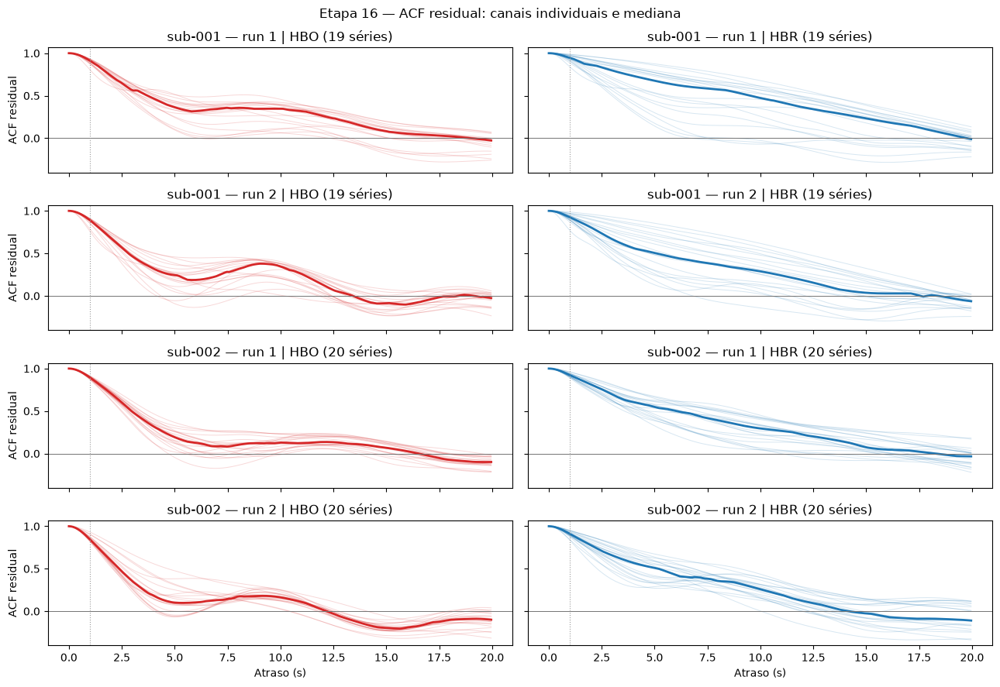

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate

if not {"piloto_ajuste_ols", "piloto_longos"} <= globals().keys():
    raise RuntimeError(
        "Faltam os resíduos em memória. Se reiniciaste o kernel, "
        "recupera os sinais e a matriz e executa a Etapa 15 "
        "com GUARDAR_CSV_ETAPA15 = False."
    )

chaves = sorted(piloto_ajuste_ols)
if len(chaves) != 4 or set(chaves) != set(piloto_longos):
    raise RuntimeError("Esperavam-se as mesmas quatro runs nos dois objetos.")

piloto_acf_residuos = {}
fig, eixos = plt.subplots(
    len(chaves), 2, figsize=(13, 9), sharex=True, sharey=True
)

for linha, chave in enumerate(chaves):
    raw = piloto_longos[chave]
    resultado = piloto_ajuste_ols[chave]
    E = np.asarray(resultado["residuos"], dtype=float)

    if (
        tuple(raw.ch_names) != resultado["canais"]
        or E.shape != (raw.n_times, len(raw.ch_names))
        or not np.isfinite(E).all()
    ):
        raise RuntimeError(f"{chave}: resíduos ou canais inconsistentes.")

    sfreq = float(raw.info["sfreq"])
    lag_max = min(int(np.floor(20 * sfreq)), raw.n_times - 1)
    atrasos_s = np.arange(lag_max + 1) / sfreq

    E = E - E.mean(axis=0)
    energia = np.sum(E**2, axis=0)
    if np.any(energia <= 0):
        raise RuntimeError(f"{chave}: pelo menos um residual sem variância.")

    acf = np.column_stack([
        correlate(serie, serie, mode="full", method="fft")[
            raw.n_times - 1 : raw.n_times + lag_max
        ] / energia[j]
        for j, serie in enumerate(E.T)
    ])

    piloto_acf_residuos[chave] = {
        "atrasos_s": atrasos_s,
        "canais": tuple(raw.ch_names),
        "acf": acf,
    }

    tipos = np.asarray(raw.get_channel_types())
    for coluna, (tipo, cor) in enumerate([
        ("hbo", "tab:red"), ("hbr", "tab:blue")
    ]):
        ax = eixos[linha, coluna]
        curvas = acf[:, tipos == tipo]
        if curvas.shape[1] == 0:
            raise RuntimeError(f"{chave}: não foram encontradas séries {tipo}.")

        ax.plot(atrasos_s, curvas, color=cor, alpha=0.18, lw=0.7)
        ax.plot(atrasos_s, np.median(curvas, axis=1), color=cor, lw=2)
        ax.axhline(0, color="0.45", lw=0.7)
        ax.axvline(1, color="0.6", ls=":", lw=0.8)
        ax.set_title(
            f"{chave[0]} — run {chave[1]} | {tipo.upper()} "
            f"({curvas.shape[1]} séries)"
        )
        if coluna == 0:
            ax.set_ylabel("ACF residual")

for ax in eixos[-1]:
    ax.set_xlabel("Atraso (s)")

fig.suptitle("Etapa 16 — ACF residual: canais individuais e mediana")
fig.tight_layout()
plt.show()
plt.close(fig)

## Etapa 17 — Teste exploratório de prewhitening AR(1)

### Objetivo
Verificar se um modelo AR(1) reduz a dependência temporal
dos resíduos e quanto altera os betas de vídeo e decisão.

### Entradas
- Sinais contínuos `piloto_longos`.
- Matrizes `com_filtro` da Etapa 14, nas escalas originais.
- Resíduos e betas exploratórios do OLS da Etapa 15.

### Procedimento
- Estimar um coeficiente AR(1) por série HbO ou HbR a partir
  dos resíduos OLS, sem iteração.
- Transformar o sinal e toda a matriz, incluindo a constante.
- Reajustar por mínimos quadrados no espaço transformado.
- Comparar a ACF dos resíduos OLS e dos resíduos transformados
  até 20 s, usando o mesmo segmento temporal.
- Comparar os betas por canal e resumir as diferenças por run
  e cromóforo.

### Limites
AR(1) é um primeiro comparador, não o modelo final.
Não calcular testes, contrastes ou diferenças entre grupos.
Não combinar runs, excluir canais ou gravar ficheiros.
O controlo da fisiologia sistémica continua pendente.

C:\Users\guilh\AppData\Local\Temp\ipykernel_8108\2653122792.py:35: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  tabela_ols = ols["tabela"].set_index("canal", verify_integrity=True)


ETAPA 17 — MEDIANAS POR RUN E CROMÓFORO
sujeito  run cromoforo    rho  acf_lag1_ols  acf_lag1_ar1  acf_1s_ols  acf_1s_ar1  abs_delta_video_uM  abs_delta_decisao_uM
sub-001    1       hbo 0.9990        0.9990        0.9893      0.9132      0.4395              0.0434                0.1824
sub-001    1       hbr 0.9993        0.9993        0.9839      0.9459      0.2860              0.0196                0.0777
sub-001    2       hbo 0.9988        0.9988        0.9888      0.8924      0.3567              0.0248                0.3483
sub-001    2       hbr 0.9991        0.9991        0.9847      0.9259      0.1289              0.0145                0.1364
sub-002    1       hbo 0.9987        0.9987        0.9828      0.8964      0.2569              0.0166                0.1360
sub-002    1       hbr 0.9990        0.9990        0.9800      0.9237      0.0797              0.0044                0.0348
sub-002    2       hbo 0.9980        0.9980        0.9740      0.8480      0.1567           

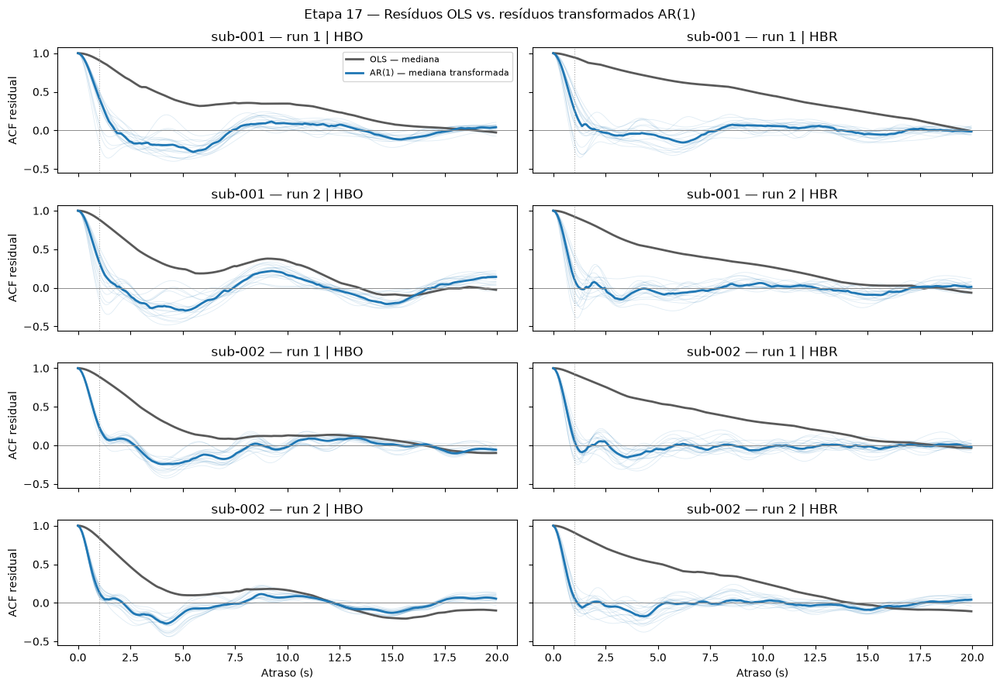


Etapa 17 concluída. Nenhum ficheiro alterado; sem testes ou contrastes.


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import correlate

necessarios = ("piloto_longos", "piloto_matrizes_glm", "piloto_ajuste_ols")
em_falta = [nome for nome in necessarios if nome not in globals()]
if em_falta:
    raise RuntimeError(f"Faltam objetos da sessão: {em_falta}")

chaves = sorted(piloto_longos)
if len(chaves) != 4 or any(
    set(globals()[nome]) != set(chaves) for nome in necessarios
):
    raise RuntimeError("Esperavam-se as mesmas quatro runs nos três objetos.")


def acf_etapa17(serie, lag_max):
    z = serie - serie.mean()
    energia = z @ z
    if not np.isfinite(energia) or energia <= 0:
        raise RuntimeError("Não é possível calcular a ACF: residual sem variância.")
    cc = correlate(z, z, mode="full", method="fft")
    return cc[len(z) - 1 : len(z) + lag_max] / energia


ajustes_ar1 = {}
registos_ar1 = []

for chave in chaves:
    sujeito, run = chave
    raw = piloto_longos[chave]
    desenho = piloto_matrizes_glm[chave]["com_filtro"]
    ols = piloto_ajuste_ols[chave]
    tabela_ols = ols["tabela"].set_index("canal", verify_integrity=True)

    X = desenho.to_numpy(dtype=float)
    Y = raw.get_data().T
    E_ols = np.asarray(ols["residuos"], dtype=float)

    if (
        list(desenho.columns) != ["video", "decisao", "constante"]
        or X.shape != (raw.n_times, 3)
        or not np.allclose(desenho.index.to_numpy(dtype=float),
                           raw.times, rtol=0, atol=1e-8)
        or not np.allclose(ols["tempo_s"], raw.times, rtol=0, atol=1e-8)
        or tuple(raw.ch_names) != ols["canais"]
        or E_ols.shape != Y.shape
        or not all(np.isfinite(a).all() for a in (X, Y, E_ols))
    ):
        raise RuntimeError(f"{chave}: sinal, desenho ou resíduos inconsistentes.")

    sfreq = float(raw.info["sfreq"])
    lag_max = min(int(np.floor(20 * sfreq)), raw.n_times - 2)
    lag_1s = max(1, round(sfreq))
    if lag_max < lag_1s:
        raise RuntimeError(f"{chave}: sinal demasiado curto para este diagnóstico.")

    acf_ols = np.empty((lag_max + 1, Y.shape[1]))
    acf_ar1 = np.empty_like(acf_ols)
    residuos_transf = np.empty_like(Y[1:])
    betas_ar1 = np.empty((3, Y.shape[1]))

    for j, (canal, tipo) in enumerate(zip(raw.ch_names, raw.get_channel_types())):
        e = E_ols[:, j]
        e_centrado = e - e.mean()
        anterior = e_centrado[:-1]
        denominador = anterior @ anterior

        if denominador <= 0:
            raise RuntimeError(f"{chave}, {canal}: residual OLS sem variância.")

        rho = float((anterior @ e_centrado[1:]) / denominador)
        if not np.isfinite(rho) or abs(rho) >= 1:
            raise RuntimeError(
                f"{chave}, {canal}: rho = {rho:.6f} fora de (-1, 1). "
                "Inspecionar antes de prosseguir; não foi truncado."
            )

        Xw = X[1:] - rho * X[:-1]
        yw = Y[1:, j] - rho * Y[:-1, j]
        beta, _, posto, _ = np.linalg.lstsq(Xw, yw, rcond=None)
        if posto != 3 or not np.isfinite(beta).all():
            raise RuntimeError(f"{chave}, {canal}: ajuste transformado inválido.")

        ew = yw - Xw @ beta
        betas_ar1[:, j] = beta
        residuos_transf[:, j] = ew

        # ACF de ambas as versões sobre o mesmo segmento: amostras 1 a N-1.
        acf_ols[:, j] = acf_etapa17(e[1:], lag_max)
        acf_ar1[:, j] = acf_etapa17(ew, lag_max)

        video_ols = tabela_ols.at[canal, "beta_video_uM"]
        decisao_ols = tabela_ols.at[canal, "beta_decisao_uM"]
        video_ar1, decisao_ar1 = beta[:2] * 1e6

        registos_ar1.append({
            "sujeito": sujeito,
            "run": run,
            "canal": canal,
            "cromoforo": tipo,
            "rho": rho,
            "acf_lag1_ols": acf_ols[1, j],
            "acf_lag1_ar1": acf_ar1[1, j],
            "acf_1s_ols": acf_ols[lag_1s, j],
            "acf_1s_ar1": acf_ar1[lag_1s, j],
            "beta_video_ols_uM": video_ols,
            "beta_video_ar1_uM": video_ar1,
            "beta_decisao_ols_uM": decisao_ols,
            "beta_decisao_ar1_uM": decisao_ar1,
            "abs_delta_video_uM": abs(video_ar1 - video_ols),
            "abs_delta_decisao_uM": abs(decisao_ar1 - decisao_ols),
        })

    ajustes_ar1[chave] = {
        "canais": tuple(raw.ch_names),
        "cromoforos": np.asarray(raw.get_channel_types()),
        "atrasos_s": np.arange(lag_max + 1) / sfreq,
        "acf_ols": acf_ols,
        "acf_ar1": acf_ar1,
        "residuos_transformados": residuos_transf,
        "betas": betas_ar1,
    }

piloto_ajuste_ar1 = ajustes_ar1
df_ar1_piloto = pd.DataFrame(registos_ar1)
colunas_resumo = [
    "rho",
    "acf_lag1_ols", "acf_lag1_ar1",
    "acf_1s_ols", "acf_1s_ar1",
    "abs_delta_video_uM", "abs_delta_decisao_uM",
]
df_resumo_ar1_piloto = (
    df_ar1_piloto.groupby(["sujeito", "run", "cromoforo"])[colunas_resumo]
    .median()
    .reset_index()
)

print("ETAPA 17 — MEDIANAS POR RUN E CROMÓFORO")
print(df_resumo_ar1_piloto.to_string(index=False, float_format="%.4f"))
print(f"\nSéries ajustadas: {len(df_ar1_piloto)}")

fig, eixos = plt.subplots(4, 2, figsize=(13, 9), sharex=True, sharey=True)

for linha, chave in enumerate(chaves):
    res = piloto_ajuste_ar1[chave]
    t = res["atrasos_s"]

    for coluna, tipo in enumerate(("hbo", "hbr")):
        ax = eixos[linha, coluna]
        sel = res["cromoforos"] == tipo
        antes = res["acf_ols"][:, sel]
        depois = res["acf_ar1"][:, sel]

        ax.plot(t, depois, color="tab:blue", alpha=0.14, lw=0.6)
        ax.plot(t, np.median(antes, axis=1), color="0.35", lw=2,
                label="OLS — mediana")
        ax.plot(t, np.median(depois, axis=1), color="tab:blue", lw=2,
                label="AR(1) — mediana transformada")
        ax.axhline(0, color="0.55", lw=0.7)
        ax.axvline(1, color="0.65", ls=":", lw=0.8)
        ax.set_title(f"{chave[0]} — run {chave[1]} | {tipo.upper()}")

    eixos[linha, 0].set_ylabel("ACF residual")

for ax in eixos[-1]:
    ax.set_xlabel("Atraso (s)")

eixos[0, 0].legend(fontsize=8)
fig.suptitle("Etapa 17 — Resíduos OLS vs. resíduos transformados AR(1)")
fig.tight_layout()
plt.show()
plt.close(fig)

print("\nEtapa 17 concluída. Nenhum ficheiro alterado; sem testes ou contrastes.")

## Etapa 18 — Comparação exploratória de modelos de ruído temporal

### Objetivo
Comparar OLS, AR(1), AR(2), AR(5) e AR(10) nas quatro runs
de tomada de decisão, sem alterar o desenho da Etapa 14.

### Procedimento
- Estimar os coeficientes AR por canal a partir dos resíduos OLS,
  pelo método de Yule–Walker, sem iteração.
- Aplicar a mesma transformação ao sinal e a todas as colunas
  da matriz, incluindo a constante.
- Ajustar e avaliar todos os modelos nas mesmas amostras,
  descartando as primeiras 10 de cada run.
- Comparar a ACF residual até 20 s e os betas com sinal
  de vídeo e decisão/resposta explícita.

### Limites
Comparação descritiva na própria run. Não selecionar uma ordem
automaticamente, combinar runs, calcular testes ou gravar ficheiros.
O controlo da fisiologia sistémica continua pendente.

ETAPA 18 — COMPARAÇÃO POR RUN E CROMÓFORO
sujeito  run cromoforo modelo  n_validos  acf_lag1  acf_1s  acf_abs_media_20s  delta_abs_video_vs_AR1_uM  delta_abs_decisao_vs_AR1_uM
sub-001    1       hbo    OLS         19    0.9990  0.9132             0.3232                     0.0434                       0.1823
sub-001    1       hbr    OLS         19    0.9992  0.9457             0.4797                     0.0195                       0.0777
sub-001    1       hbo  AR(1)         19    0.9898  0.4463             0.1339                     0.0000                       0.0000
sub-001    1       hbr  AR(1)         19    0.9856  0.2853             0.0958                     0.0000                       0.0000
sub-001    1       hbo  AR(2)         19    0.9765 -0.2154             0.0796                     0.0756                       0.2593
sub-001    1       hbr  AR(2)         19    0.9739 -0.3365             0.0768                     0.0126                       0.0455
sub-001    1       h

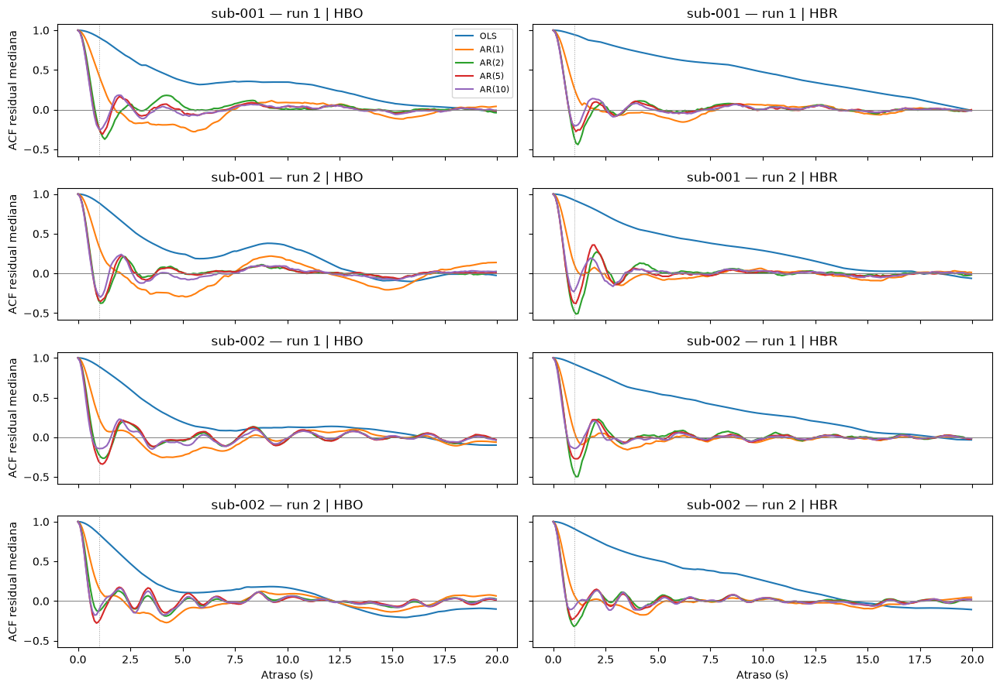

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import solve_toeplitz
from scipy.signal import correlate

ordens = (0, 1, 2, 5, 10)
inicio = max(ordens)
chaves = sorted(piloto_longos)
if len(chaves) != 4 or set(chaves) != set(piloto_matrizes_glm):
    raise RuntimeError("Esperavam-se as mesmas quatro runs no sinal e no desenho.")


def acf18(z, k):
    z = z - z.mean()
    energia = z @ z
    if not np.isfinite(energia) or energia <= 0:
        raise RuntimeError("Residual sem variância ou com valores inválidos.")
    c = correlate(z, z, mode="full", method="fft")
    return c[len(z) - 1 : len(z) + k] / energia


ajustes18 = {}
registos = []

for chave in chaves:
    sujeito, run = chave
    raw = piloto_longos[chave]
    desenho = piloto_matrizes_glm[chave]["com_filtro"]
    X = desenho.to_numpy(dtype=float)
    Y = raw.get_data().T
    tipos = np.asarray(raw.get_channel_types())
    sfreq = float(raw.info["sfreq"])

    if (
        list(desenho.columns) != ["video", "decisao", "constante"]
        or X.shape != (raw.n_times, 3)
        or not np.allclose(desenho.index.to_numpy(float), raw.times,
                           rtol=0, atol=1e-8)
        or not (np.isfinite(X).all() and np.isfinite(Y).all())
    ):
        raise RuntimeError(f"{chave}: desenho ou sinais inconsistentes.")

    lag_max = min(int(20 * sfreq), len(X) - inicio - 1)
    lag_1s = round(sfreq)
    if lag_max < lag_1s:
        raise RuntimeError(f"{chave}: série demasiado curta.")

    beta_ols, _, posto, _ = np.linalg.lstsq(X[inicio:], Y[inicio:], rcond=None)
    if posto != 3:
        raise RuntimeError(f"{chave}: matriz OLS sem posto completo.")

    E = Y[inicio:] - X[inicio:] @ beta_ols
    ajustes18[chave] = {
        "atrasos_s": np.arange(lag_max + 1) / sfreq,
        "canais": tuple(raw.ch_names),
        "tipos": tipos,
        "acf": {},
    }

    for p in ordens:
        nome = "OLS" if p == 0 else f"AR({p})"
        curvas = np.full((lag_max + 1, Y.shape[1]), np.nan)
        ajustes18[chave]["acf"][nome] = curvas

        for j, canal in enumerate(raw.ch_names):
            linha = dict(sujeito=sujeito, run=run, canal=canal,
                         cromoforo=tipos[j], modelo=nome)
            try:
                Xw = X[inicio:].copy()
                yw = Y[inicio:, j].copy()

                if p:
                    r = acf18(E[:, j], p)
                    phi = solve_toeplitz(r[:-1], r[1:])
                    if not np.isfinite(phi).all():
                        raise ValueError("Coeficientes AR não finitos.")
                    if np.any(np.abs(np.roots(np.r_[1.0, -phi])) >= 1):
                        raise ValueError("Modelo AR não estacionário.")
                    for k, coef in enumerate(phi, start=1):
                        Xw -= coef * X[inicio-k : len(X)-k]
                        yw -= coef * Y[inicio-k : len(Y)-k, j]

                beta, _, posto, _ = np.linalg.lstsq(Xw, yw, rcond=None)
                if posto != 3 or not np.isfinite(beta).all():
                    raise ValueError("Ajuste inválido ou sem posto completo.")

                a = acf18(yw - Xw @ beta, lag_max)
                curvas[:, j] = a
                linha.update(
                    estado="ok",
                    acf_lag1=a[1],
                    acf_1s=a[lag_1s],
                    acf_abs_media_20s=np.mean(np.abs(a[1:])),
                    beta_video_uM=beta[0] * 1e6,
                    beta_decisao_uM=beta[1] * 1e6,
                )
            except (ValueError, RuntimeError, np.linalg.LinAlgError) as erro:
                linha["estado"] = str(erro)
            registos.append(linha)

piloto_comparacao_ar = ajustes18
df_ar18 = pd.DataFrame(registos)
ids = ["sujeito", "run", "canal", "cromoforo"]
betas = ["beta_video_uM", "beta_decisao_uM"]

validos = df_ar18.loc[df_ar18["estado"].eq("ok")].copy()
for referencia in ("OLS", "AR(1)"):
    ref = validos.loc[validos["modelo"].eq(referencia), ids + betas]
    ref = ref.set_index(ids)
    for beta in betas:
        coluna = f"delta_{beta}_vs_{referencia}"
        validos[coluna] = validos[beta] - validos.set_index(ids).index.map(ref[beta])

df_ar18_betas = validos
df_resumo_ar18 = (
    validos.groupby(["sujeito", "run", "cromoforo", "modelo"], sort=False)
    .agg(
        n_validos=("canal", "size"),
        acf_lag1=("acf_lag1", "median"),
        acf_1s=("acf_1s", "median"),
        acf_abs_media_20s=("acf_abs_media_20s", "median"),
        delta_abs_video_vs_AR1_uM=(
            "delta_beta_video_uM_vs_AR(1)", lambda x: x.abs().median()
        ),
        delta_abs_decisao_vs_AR1_uM=(
            "delta_beta_decisao_uM_vs_AR(1)", lambda x: x.abs().median()
        ),
    )
    .reset_index()
)

print("ETAPA 18 — COMPARAÇÃO POR RUN E CROMÓFORO")
print(df_resumo_ar18.to_string(index=False, float_format="%.4f"))

falhas = df_ar18.loc[df_ar18["estado"].ne("ok"), ids + ["modelo", "estado"]]
if not falhas.empty:
    print("\nAjustes inválidos; não incluídos nas medianas:")
    print(falhas.to_string(index=False))

fig, eixos = plt.subplots(4, 2, figsize=(13, 9), sharex=True, sharey=True)
for linha, chave in enumerate(chaves):
    res = ajustes18[chave]
    for col, tipo in enumerate(("hbo", "hbr")):
        ax = eixos[linha, col]
        for nome, acf in res["acf"].items():
            canais_ok = (res["tipos"] == tipo) & np.isfinite(acf).all(axis=0)
            if canais_ok.any():
                ax.plot(res["atrasos_s"], np.median(acf[:, canais_ok], axis=1),
                        label=nome)
        ax.axhline(0, color="0.5", lw=0.7)
        ax.axvline(1, color="0.6", ls=":", lw=0.7)
        ax.set_title(f"{chave[0]} — run {chave[1]} | {tipo.upper()}")
    eixos[linha, 0].set_ylabel("ACF residual mediana")

for ax in eixos[-1]:
    ax.set_xlabel("Atraso (s)")
eixos[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()
plt.close(fig)

## Etapa 19A — Estabilidade dos betas entre AR(5) e AR(10)

### Objetivo
Comparar diretamente as estimativas de vídeo e de decisão
nos mesmos canais, separadamente por participante, run e cromóforo.

### Procedimento
- Emparelhar os ajustes válidos por participante, run, canal e cromóforo.
- Calcular a diferença com sinal: beta AR(10) menos beta AR(5).
- Resumir a magnitude dos betas e a mediana e o máximo
  das diferenças absolutas.
- Identificar mudanças de sinal e mostrar os dois betas,
  para distinguir inversões perto de zero de inversões maiores.

### Limites
Diagnóstico descritivo. Sem limiar de relevância pré-definido,
sem testes de significância e sem seleção automática de modelo.
Não alterar sinais nem gravar ficheiros.

In [9]:
import numpy as np
import pandas as pd

if "df_ar18_betas" not in globals():
    raise RuntimeError("Executa primeiro a Etapa 18 para recuperar df_ar18_betas.")

ids = ["sujeito", "run", "canal", "cromoforo"]
fases = ["video", "decisao"]

dados = df_ar18_betas.loc[
    df_ar18_betas["estado"].eq("ok")
    & df_ar18_betas["modelo"].isin(["AR(5)", "AR(10)"])
].copy()

if dados.empty:
    raise RuntimeError("Não foram encontrados ajustes AR(5) ou AR(10) válidos.")

partes = []

for fase in fases:
    coluna = f"beta_{fase}_uM"

    pares = (
        dados.pivot(index=ids, columns="modelo", values=coluna)
        .reindex(columns=["AR(5)", "AR(10)"])
        .rename(columns={"AR(5)": "beta_ar5_uM", "AR(10)": "beta_ar10_uM"})
        .reset_index()
    )

    validos = np.isfinite(pares[["beta_ar5_uM", "beta_ar10_uM"]]).all(axis=1)
    n_sem_par = int((~validos).sum())
    if n_sem_par:
        print(f"{fase}: {n_sem_par} séries sem um par de ajustes válidos.")

    pares = pares.loc[validos].copy()
    pares["fase"] = fase
    pares["delta_uM"] = pares["beta_ar10_uM"] - pares["beta_ar5_uM"]
    pares["delta_abs_uM"] = pares["delta_uM"].abs()
    pares["abs_beta_ar5_uM"] = pares["beta_ar5_uM"].abs()
    pares["abs_beta_ar10_uM"] = pares["beta_ar10_uM"].abs()

    a, b = pares["beta_ar5_uM"], pares["beta_ar10_uM"]
    pares["mudou_sinal"] = ((a < 0) & (b > 0)) | ((a > 0) & (b < 0))
    partes.append(pares)

df_ar19_pares = pd.concat(partes, ignore_index=True)
if df_ar19_pares.empty:
    raise RuntimeError("Não há canais com ajustes válidos em ambos os modelos.")

df_ar19_resumo = (
    df_ar19_pares.groupby(["sujeito", "run", "cromoforo", "fase"])
    .agg(
        n_pares=("canal", "size"),
        beta_abs_mediano_ar5_uM=("abs_beta_ar5_uM", "median"),
        beta_abs_mediano_ar10_uM=("abs_beta_ar10_uM", "median"),
        delta_mediano_uM=("delta_uM", "median"),
        delta_abs_mediano_uM=("delta_abs_uM", "median"),
        delta_abs_max_uM=("delta_abs_uM", "max"),
        n_mudancas_sinal=("mudou_sinal", "sum"),
    )
    .reset_index()
)

print("ETAPA 19A — ESTABILIDADE DOS BETAS AR(5) VS. AR(10)")
print(df_ar19_resumo.to_string(index=False, float_format="%.4f"))

df_ar19_inversoes = df_ar19_pares.loc[df_ar19_pares["mudou_sinal"]].sort_values(
    "delta_abs_uM", ascending=False
)

if df_ar19_inversoes.empty:
    print("\nNenhuma inversão estrita de sinal.")
else:
    colunas = ids + ["fase", "beta_ar5_uM", "beta_ar10_uM", "delta_abs_uM"]
    print(f"\nInversões estritas de sinal: {len(df_ar19_inversoes)}")
    print("Até 12 inversões com maior diferença absoluta:")
    print(df_ar19_inversoes[colunas].head(12).to_string(
        index=False, float_format="%.4f"
    ))

ETAPA 19A — ESTABILIDADE DOS BETAS AR(5) VS. AR(10)
sujeito  run cromoforo    fase  n_pares  beta_abs_mediano_ar5_uM  beta_abs_mediano_ar10_uM  delta_mediano_uM  delta_abs_mediano_uM  delta_abs_max_uM  n_mudancas_sinal
sub-001    1       hbo decisao       19                   0.1228                    0.1291            0.0167                0.0411            0.3143                 1
sub-001    1       hbo   video       19                   0.0441                    0.0468            0.0012                0.0091            0.0704                 1
sub-001    1       hbr decisao       19                   0.0525                    0.0474           -0.0005                0.0182            0.0955                 1
sub-001    1       hbr   video       19                   0.0089                    0.0080           -0.0012                0.0026            0.0177                 3
sub-001    2       hbo decisao       19                   0.2227                    0.2708            0.0251     

## Etapa 19B — Sensibilidade ao passa-banda

### Objetivo
Verificar se o passa-banda altera a dependência temporal do
sinal e se os betas de vídeo e decisão são sensíveis à estratégia
de filtragem e tratamento da deriva.

### Comparação do sinal
Comparar HbO/HbR antes e depois do passa-banda da Etapa 8,
nos mesmos canais e amostras, antes do ajuste do GLM.

### Comparação dos ajustes
- Referência: sinal filtrado e matriz `com_filtro`.
- Sensibilidade: sinal pré-passa-banda, matriz `sem_filtro`
  e termos de deriva em cosseno abaixo de 0,01 Hz.
- OLS em ambos os ramos, por canal e run.
- Mesmos eventos e mesma resposta hemodinâmica SPM.

### Limites
Diagnóstico descritivo. A comparação entre GLM altera
a estratégia de filtragem e deriva; não isola o passa-baixo.
Sem testes, exclusões, combinação de runs ou escrita de ficheiros.
O controlo da fisiologia sistémica continua pendente.

ETAPA 19B — SENSIBILIDADE AO PASSA-BANDA
sujeito  run cromoforo  n_series  sinal_pre_lag1  sinal_pos_lag1  residuo_sens_lag1  residuo_ref_lag1  residuo_sens_1s  residuo_ref_1s  delta_abs_video_uM  delta_abs_decisao_uM  inversoes_video  inversoes_decisao
sub-001    1       hbo        19          0.9600          0.9991             0.9242            0.9990           0.7550          0.9132              0.0177                0.0790                1                  0
sub-001    1       hbr        19          0.9943          0.9993             0.9835            0.9993           0.9310          0.9459              0.0074                0.0332                4                  4
sub-001    2       hbo        19          0.9737          0.9989             0.9282            0.9988           0.7811          0.8924              0.0170                0.0442                1                  1
sub-001    2       hbr        19          0.9944          0.9992             0.9693            0.9991      

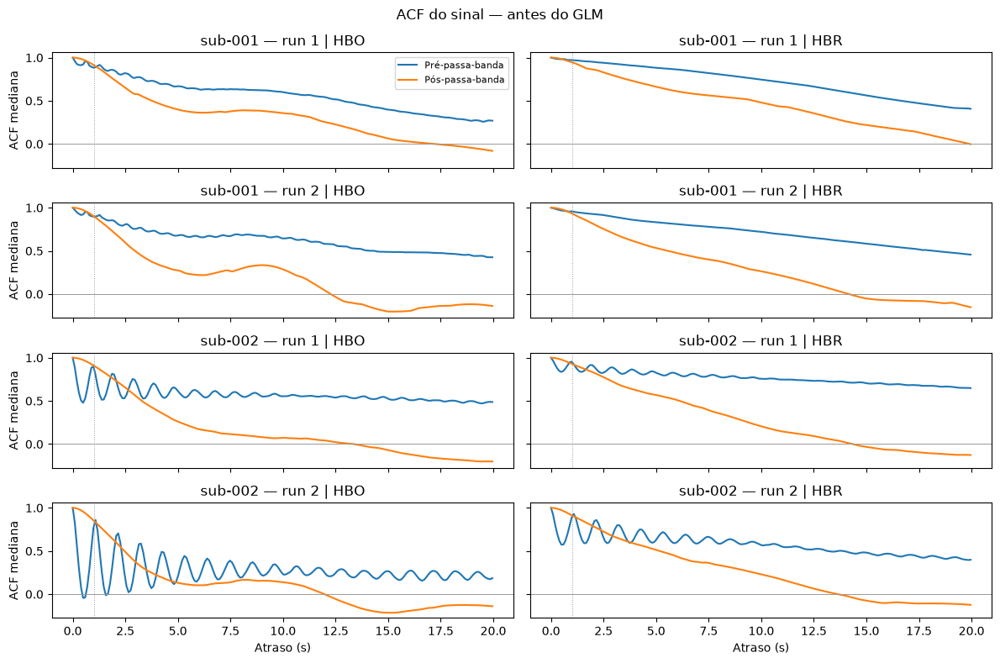

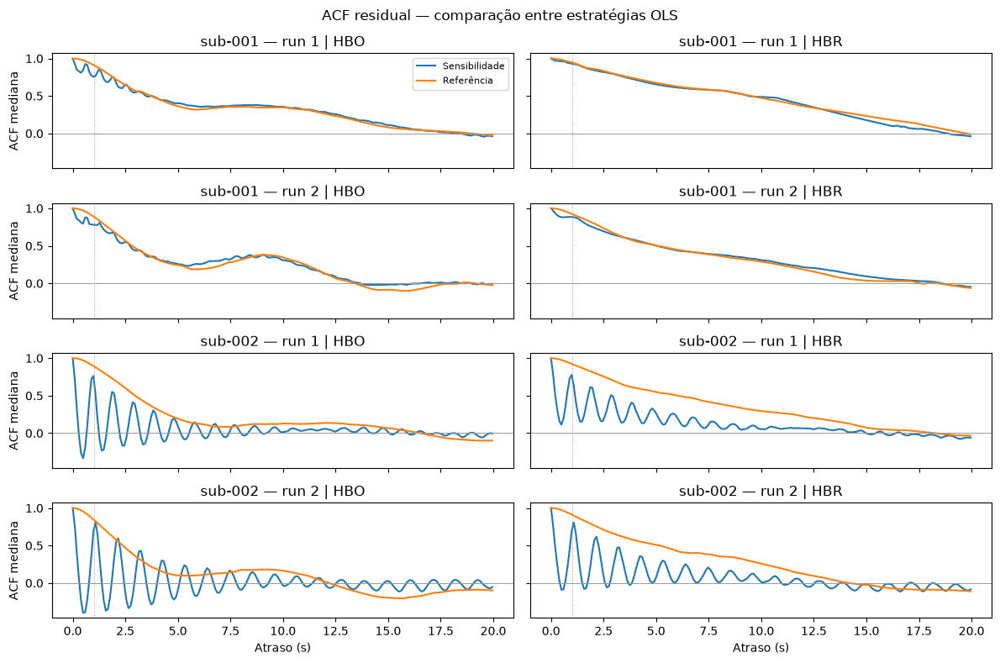


Etapa 19B concluída. Nenhum ficheiro alterado.


In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from scipy.signal import correlate

necessarios = {"piloto_longos", "piloto_runs", "piloto_matrizes_glm"}
faltam = necessarios - globals().keys()
if faltam:
    raise RuntimeError(f"Faltam objetos da sessão: {sorted(faltam)}")

chaves = sorted(piloto_longos)
if len(chaves) != 4 or any(set(globals()[n]) != set(chaves) for n in necessarios):
    raise RuntimeError("Esperavam-se as mesmas quatro runs nos três objetos.")


def acf19b(dados, lag_max):
    """ACF normalizada por série: amostras × canais."""
    z = dados - dados.mean(axis=0)
    n = len(z)
    energia = np.sum(z**2, axis=0)
    if np.any(energia <= 0) or not np.isfinite(energia).all():
        raise RuntimeError("Há séries sem variância ou com valores inválidos.")
    return np.column_stack([
        correlate(s, s, mode="full", method="fft")[n - 1:n + lag_max] / e
        for s, e in zip(z.T, energia)
    ])


def ols19b(X, Y):
    beta, _, posto, _ = np.linalg.lstsq(X, Y, rcond=None)
    if posto != X.shape[1] or not np.isfinite(beta).all():
        raise RuntimeError("Ajuste inválido ou matriz sem posto completo.")
    return beta, Y - X @ beta


piloto_acf_19b = {}
tabelas = []

for chave in chaves:
    sujeito, run = chave
    filtrado = piloto_longos[chave]
    info = piloto_runs[chave]
    gravacao = info["id_gravacao"]
    caminho = (
        Path(info["pasta_saida_prevista"])
        / f"{gravacao}_haemo_unfiltered_raw.fif"
    )

    if not caminho.is_file():
        raise FileNotFoundError(f"Falta o derivado pré-passa-banda:\n{caminho}")

    antes = mne.io.read_raw_fif(caminho, preload=True, verbose=False)
    canais = filtrado.ch_names
    t = filtrado.times
    sfreq = float(filtrado.info["sfreq"])

    if (
        antes.n_times != filtrado.n_times
        or antes.first_samp != filtrado.first_samp
        or not np.isclose(antes.info["sfreq"], sfreq, rtol=0, atol=1e-8)
        or not set(canais) <= set(antes.ch_names)
        or set(canais) & set(antes.info["bads"])
        or filtrado.info["bads"]
        or antes.annotations.orig_time != filtrado.annotations.orig_time
        or not np.array_equal(antes.annotations.description,
                              filtrado.annotations.description)
        or not np.allclose(antes.annotations.onset,
                           filtrado.annotations.onset, rtol=0, atol=1e-6)
    ):
        raise RuntimeError(f"{chave}: sinais, canais ou eventos não emparelhados.")

    Y_pre = antes.get_data(picks=canais).T
    Y_pos = filtrado.get_data().T
    if not (np.isfinite(Y_pre).all() and np.isfinite(Y_pos).all()):
        raise RuntimeError(f"{chave}: sinal com valores não finitos.")

    desenhos = piloto_matrizes_glm[chave]
    for nome in ("com_filtro", "sem_filtro"):
        d = desenhos[nome]
        if (
            list(d.columns) != ["video", "decisao", "constante"]
            or len(d) != len(t)
            or not np.allclose(d.index.to_numpy(float), t, rtol=0, atol=1e-8)
            or not np.isfinite(d.to_numpy(float)).all()
        ):
            raise RuntimeError(f"{chave}: matriz {nome} incompatível.")

    X_pos = desenhos["com_filtro"].to_numpy(float)
    X_pre = desenhos["sem_filtro"].to_numpy(float)

    # Deriva lenta: cossenos com frequências estritamente abaixo de 0,01 Hz.
    # A constante já está na matriz; não a duplicar.
    n = len(t)
    duracao_grelha = n / sfreq
    k = np.arange(1, int(np.ceil(2 * duracao_grelha * 0.01)))
    deriva = np.cos(np.pi * (np.arange(n)[:, None] + 0.5) * k / n)
    X_pre = np.column_stack([X_pre, deriva])

    b_pos, e_pos = ols19b(X_pos, Y_pos)
    b_pre, e_pre = ols19b(X_pre, Y_pre)

    lag_max = min(int(20 * sfreq), n - 1)
    lag_1s = round(sfreq)
    curvas = {
        "sinal_pre": acf19b(Y_pre, lag_max),
        "sinal_pos": acf19b(Y_pos, lag_max),
        "residuo_pre": acf19b(e_pre, lag_max),
        "residuo_pos": acf19b(e_pos, lag_max),
    }
    tipos = np.asarray(filtrado.get_channel_types())
    piloto_acf_19b[chave] = (np.arange(lag_max + 1) / sfreq, tipos, curvas)

    tabela = pd.DataFrame({
        "sujeito": sujeito, "run": run, "canal": canais, "cromoforo": tipos,
        "n_termos_deriva": len(k),
    })
    for nome, a in curvas.items():
        tabela[f"{nome}_lag1"] = a[1]
        tabela[f"{nome}_1s"] = a[lag_1s]

    for j, fase in enumerate(("video", "decisao")):
        a, b = b_pos[j] * 1e6, b_pre[j] * 1e6
        tabela[f"{fase}_ref_uM"] = a
        tabela[f"{fase}_sens_uM"] = b
        tabela[f"{fase}_delta_abs_uM"] = np.abs(b - a)
        tabela[f"{fase}_inversao"] = (a * b) < 0

    tabelas.append(tabela)

df_19b_canais = pd.concat(tabelas, ignore_index=True)
df_19b_resumo = (
    df_19b_canais.groupby(["sujeito", "run", "cromoforo"])
    .agg(
        n_series=("canal", "size"),
        sinal_pre_lag1=("sinal_pre_lag1", "median"),
        sinal_pos_lag1=("sinal_pos_lag1", "median"),
        residuo_sens_lag1=("residuo_pre_lag1", "median"),
        residuo_ref_lag1=("residuo_pos_lag1", "median"),
        residuo_sens_1s=("residuo_pre_1s", "median"),
        residuo_ref_1s=("residuo_pos_1s", "median"),
        delta_abs_video_uM=("video_delta_abs_uM", "median"),
        delta_abs_decisao_uM=("decisao_delta_abs_uM", "median"),
        inversoes_video=("video_inversao", "sum"),
        inversoes_decisao=("decisao_inversao", "sum"),
    )
    .reset_index()
)

print("ETAPA 19B — SENSIBILIDADE AO PASSA-BANDA")
print(df_19b_resumo.to_string(index=False, float_format="%.4f"))
print(f"\nSéries emparelhadas: {len(df_19b_canais)}")

for alvo, titulo in [
    ("sinal", "ACF do sinal — antes do GLM"),
    ("residuo", "ACF residual — comparação entre estratégias OLS"),
]:
    fig, eixos = plt.subplots(4, 2, figsize=(12, 8), sharex=True, sharey=True)
    for linha, chave in enumerate(chaves):
        atrasos, tipos, curvas = piloto_acf_19b[chave]
        for col, tipo in enumerate(("hbo", "hbr")):
            ax = eixos[linha, col]
            sel = tipos == tipo
            for sufixo, rotulo in [
                ("pre", "Pré-passa-banda" if alvo == "sinal" else "Sensibilidade"),
                ("pos", "Pós-passa-banda" if alvo == "sinal" else "Referência"),
            ]:
                a = curvas[f"{alvo}_{sufixo}"][:, sel]
                ax.plot(atrasos, np.median(a, axis=1), label=rotulo)
            ax.axhline(0, color="0.6", lw=0.7)
            ax.axvline(1, color="0.6", ls=":", lw=0.7)
            ax.set_title(f"{chave[0]} — run {chave[1]} | {tipo.upper()}")
        eixos[linha, 0].set_ylabel("ACF mediana")
    eixos[0, 0].legend(fontsize=8)
    for ax in eixos[-1]:
        ax.set_xlabel("Atraso (s)")
    fig.suptitle(titulo)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

print("\nEtapa 19B concluída. Nenhum ficheiro alterado.")

## Etapa 19C — Inspeção dos betas com sinal

Comparar os betas de decisão do ramo de referência
(passa-banda) e do ramo de sensibilidade (sem passa-banda,
com deriva em cosseno), nos mesmos canais e runs.

Calcular a diferença com sinal: sensibilidade menos referência.
Listar as maiores diferenças, todas as inversões de sinal e
os dois canais que se destacaram na comparação AR(5) vs. AR(10).

Diagnóstico descritivo: sem testes, exclusões ou gravação de ficheiros.

In [11]:
if "df_19b_canais" not in globals():
    raise RuntimeError("Executa primeiro a Etapa 19B.")

ids = ["sujeito", "run", "canal", "cromoforo"]
df_19c = df_19b_canais[
    ids + ["decisao_ref_uM", "decisao_sens_uM"]
].copy()

if len(df_19c) != 156 or df_19c.duplicated(ids).any():
    raise RuntimeError("Esperavam-se 156 séries emparelhadas, sem duplicados.")

a = df_19c["decisao_ref_uM"]
b = df_19c["decisao_sens_uM"]
df_19c["delta_uM"] = b - a
df_19c["delta_abs_uM"] = (b - a).abs()
df_19c["inversao"] = ((a < 0) & (b > 0)) | ((a > 0) & (b < 0))
df_19c = df_19c.sort_values("delta_abs_uM", ascending=False)


def mostrar19c(titulo, tabela):
    print(f"\n{titulo} (n = {len(tabela)})")
    print(tabela.to_string(index=False, float_format="%.4f"))


mostrar19c("DECISÃO — 10 MAIORES ALTERAÇÕES ABSOLUTAS", df_19c.head(10))
mostrar19c("DECISÃO — TODAS AS INVERSÕES DE SINAL", df_19c[df_19c["inversao"]])

alvos = df_19c["sujeito"].eq("sub-001") & (
    (df_19c["run"].eq(2) & df_19c["canal"].eq("S5_D6 hbo"))
    | (df_19c["run"].eq(1) & df_19c["canal"].eq("S3_D4 hbo"))
)
mostrar19c("CANAIS SINALIZADOS NA ETAPA 19A", df_19c[alvos])


DECISÃO — 10 MAIORES ALTERAÇÕES ABSOLUTAS (n = 10)
sujeito  run     canal cromoforo  decisao_ref_uM  decisao_sens_uM  delta_uM  delta_abs_uM  inversao
sub-001    2 S5_D6 hbo       hbo         -1.7082          -1.4545    0.2536        0.2536     False
sub-001    1 S5_D6 hbo       hbo         -0.4363          -0.6684   -0.2321        0.2321     False
sub-001    2 S6_D4 hbo       hbo          0.1466           0.3034    0.1569        0.1569     False
sub-001    1 S5_D4 hbo       hbo         -0.3794          -0.5106   -0.1312        0.1312     False
sub-002    1 S3_D3 hbo       hbo          0.0290          -0.0977   -0.1267        0.1267      True
sub-001    1 S6_D6 hbo       hbo         -0.3371          -0.4581   -0.1210        0.1210     False
sub-001    1 S3_D3 hbo       hbo         -0.1797          -0.2946   -0.1149        0.1149     False
sub-001    2 S8_D7 hbo       hbo          0.7166           0.8258    0.1091        0.1091     False
sub-002    1 S1_D1 hbo       hbo         -0.1046

## Etapa 20 — Inspeção dirigida dos sinais contínuos

### Pergunta
As discrepâncias nos betas de decisão coincidem com alterações
identificáveis no sinal ou nos tempos das tentativas?

### Casos
- sub-001, runs 1 e 2: S5_D6, comparado com S6_D6 e S1_D1.
- sub-001, run 1: S3_D4, sinalizado na comparação AR(5) vs. AR(10).
- sub-002, run 1: S3_D3, maior inversão entre as estratégias OLS.

### Procedimento
Sobrepor HbO e HbR antes e depois do passa-banda, sem baseline
por tentativa. Mostrar a run completa e permitir ampliar um trecho.
Marcar o início do vídeo (120) e sombrear o intervalo
de decisão/resposta explícita (130–150).

### Limites
Uma diferença entre modelos não constitui um critério de exclusão.
Se houver uma alteração suspeita, verificar o sinal ótico e o
acoplamento antes de atribuir uma causa.
Não ajustar modelos, alterar sinais ou gravar ficheiros.

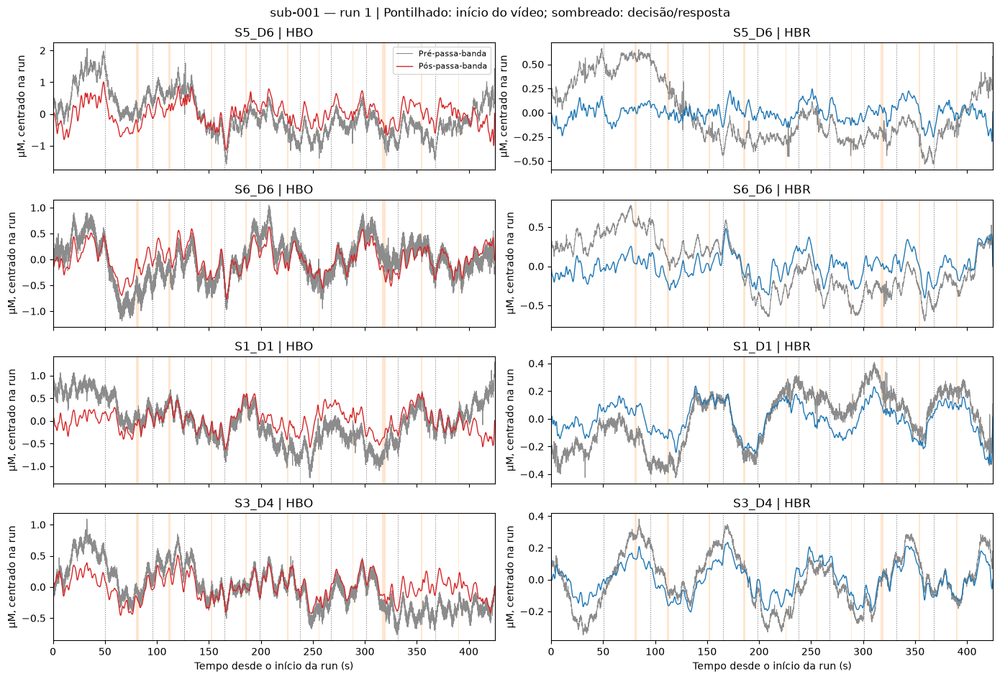

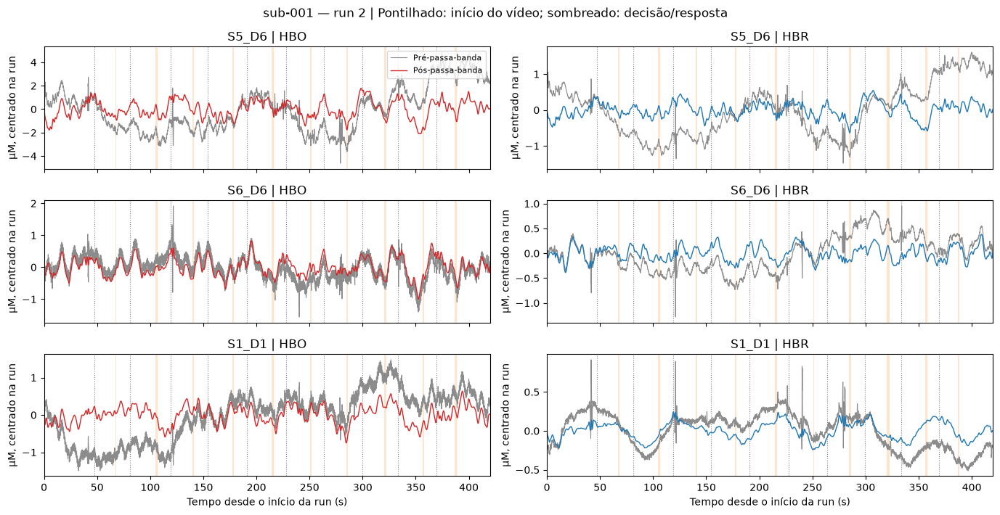

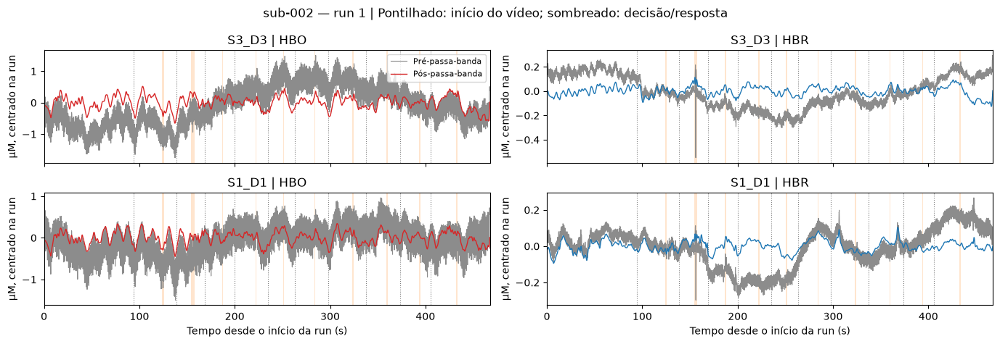

Etapa 20 concluída: inspeção apenas; nenhum ficheiro alterado.


In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np

necessarios = {"piloto_longos", "piloto_runs", "piloto_tempos_tentativas"}
faltam = necessarios - globals().keys()
if faltam:
    raise RuntimeError(f"Faltam objetos da sessão: {sorted(faltam)}")

CASOS_ETAPA20 = {
    ("sub-001", 1): ["S5_D6", "S6_D6", "S1_D1", "S3_D4"],
    ("sub-001", 2): ["S5_D6", "S6_D6", "S1_D1"],
    ("sub-002", 1): ["S3_D3", "S1_D1"],
}

# Para ampliar apenas uma run, define por exemplo CHAVE_ALVO = ("sub-001", 2).
CHAVE_ALVO = None
JANELA_S = None

chaves = list(CASOS_ETAPA20) if CHAVE_ALVO is None else [CHAVE_ALVO]

for chave in chaves:
    sujeito, run = chave
    pares = CASOS_ETAPA20[chave]
    pos = piloto_longos[chave]
    info = piloto_runs[chave]
    id_gravacao = info["id_gravacao"]
    caminho = (
        Path(info["pasta_saida_prevista"])
        / f"{id_gravacao}_haemo_unfiltered_raw.fif"
    )
    if not caminho.is_file():
        raise FileNotFoundError(f"Falta o derivado da Etapa 7:\n{caminho}")

    pre = mne.io.read_raw_fif(caminho, preload=True, verbose=False)
    canais = [f"{par} {tipo}" for par in pares for tipo in ("hbo", "hbr")]
    t = pos.times

    if (
        pre.n_times != pos.n_times
        or pre.first_samp != pos.first_samp
        or not np.isclose(pre.info["sfreq"], pos.info["sfreq"], rtol=0, atol=1e-8)
        or not set(canais) <= set(pre.ch_names) & set(pos.ch_names)
    ):
        raise RuntimeError(f"{chave}: grelha temporal ou canais incompatíveis.")

    y_pre = pre.get_data(picks=canais) * 1e6
    y_pos = pos.get_data(picks=canais) * 1e6
    if not (np.isfinite(y_pre).all() and np.isfinite(y_pos).all()):
        raise RuntimeError(f"{chave}: há valores não finitos.")

    y_pre = y_pre - y_pre.mean(axis=1, keepdims=True)
    y_pos = y_pos - y_pos.mean(axis=1, keepdims=True)

    eventos = piloto_tempos_tentativas[chave]
    limites = (t[0], t[-1]) if JANELA_S is None else JANELA_S
    if not t[0] <= limites[0] < limites[1] <= t[-1]:
        raise ValueError(f"{chave}: janela fora dos limites da run.")
    na_janela = (t >= limites[0]) & (t <= limites[1])

    fig, eixos = plt.subplots(
        len(pares), 2, figsize=(14, 2.4 * len(pares)),
        sharex=True, squeeze=False
    )

    for i, par in enumerate(pares):
        for j, tipo in enumerate(("hbo", "hbr")):
            ax = eixos[i, j]
            indice = 2 * i + j

            for ev in eventos.itertuples(index=False):
                if limites[0] <= ev.onset_video_s <= limites[1]:
                    ax.axvline(ev.onset_video_s, color="0.5", ls=":", lw=0.8)
                if ev.onset_decisao_s < limites[1] and ev.onset_fixacao_pos_s > limites[0]:
                    ax.axvspan(ev.onset_decisao_s, ev.onset_fixacao_pos_s,
                               color="tab:orange", alpha=0.20, lw=0)

            ax.plot(t[na_janela], y_pre[indice, na_janela],
                    color="0.55", lw=0.8, label="Pré-passa-banda")
            ax.plot(t[na_janela], y_pos[indice, na_janela],
                    color="tab:red" if tipo == "hbo" else "tab:blue",
                    lw=1.0, label="Pós-passa-banda")
            ax.set_title(f"{par} | {tipo.upper()}")
            ax.set_ylabel("µM, centrado na run")
            ax.set_xlim(*limites)

    eixos[0, 0].legend(loc="upper right", fontsize=8)
    for ax in eixos[-1]:
        ax.set_xlabel("Tempo desde o início da run (s)")
    fig.suptitle(
        f"{sujeito} — run {run} | Pontilhado: início do vídeo; "
        "sombreado: decisão/resposta"
    )
    fig.tight_layout()
    plt.show()
    plt.close(fig)

print("Etapa 20 concluída: inspeção apenas; nenhum ficheiro alterado.")

## Etapa 21 — Verificação ótica dirigida

### Casos
- sub-001/run 2, 270–370 s: S5_D6, S6_D6 e S1_D1.
- sub-002/run 1, 145–165 s: S3_D3 e S1_D1.

### Procedimento
Comparar a densidade ótica antes e depois do TDDR nos dois
comprimentos de onda de cada par. Marcar o início do vídeo
e sombrear a fase de decisão/resposta explícita.

Se for necessário reconstruir a densidade ótica a partir do
SNIRF, tratar essa reconstrução como diagnóstico em memória,
não como prova de identidade com o derivado original.

### Limites
Não alterar derivados, excluir canais ou reajustar o GLM.
Um transiente junto de um marcador não identifica a sua causa.

sub-001 — run 2 | SNIRF usado: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\nirs\sub-001_ses-01_tk-dm_run-2_nirs_001\sub-001_ses-01_tk-dm_run-2_nirs_001.snirf


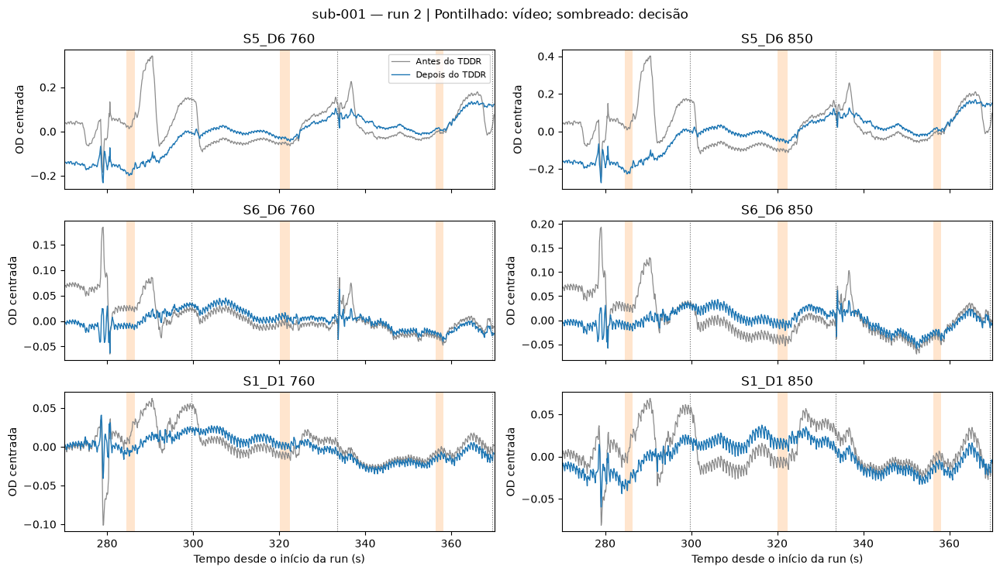

sub-002 — run 1 | SNIRF usado: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-002\nirs\sub-002_ses-01_tk-dm_run-1_nirs_002\sub-002_ses-01_tk-dm_run-1_nirs_002.snirf


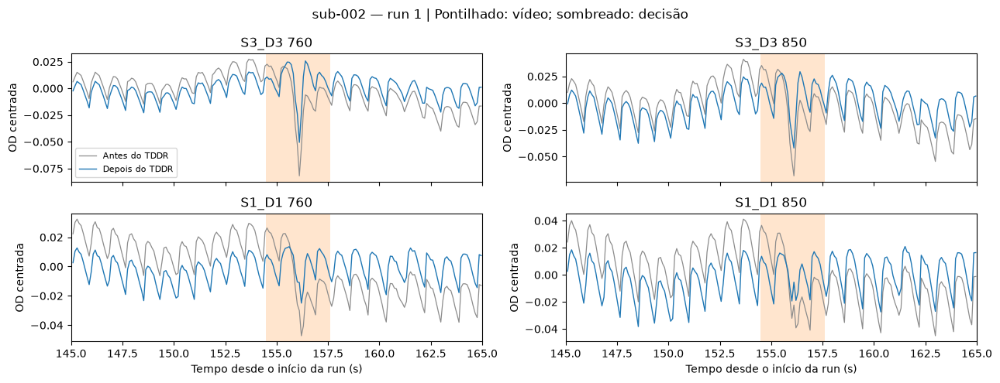

Etapa 21 concluída. Nenhum ficheiro alterado.


In [13]:
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
from mne.preprocessing.nirs import (
    optical_density,
    temporal_derivative_distribution_repair,
)

necessarios = {
    "piloto_runs", "piloto_longos", "piloto_tempos_tentativas"
}
faltam = necessarios - globals().keys()
if faltam:
    raise RuntimeError(f"Faltam objetos da sessão: {sorted(faltam)}")

CASOS_21 = {
    ("sub-001", 2): ((270, 370), ["S5_D6", "S6_D6", "S1_D1"]),
    ("sub-002", 1): ((145, 165), ["S3_D3", "S1_D1"]),
}

# Preencher só se a localização automática não encontrar um único SNIRF.
# Exemplo: ("sub-001", 2): Path(r"C:\...\gravacao.snirf")
SNIRF_EXPLICITOS_21 = {}

for chave, ((inicio, fim), pares) in CASOS_21.items():
    sujeito, run = chave
    registo = piloto_runs[chave]
    id_gravacao = registo["id_gravacao"]
    pasta_derivado = Path(registo["pasta_saida_prevista"])

    # Estrutura confirmada na retoma:
    # <sujeito>/fNIRS_epochs_derivatives/<versão>/<gravação>
    pasta_sujeito = pasta_derivado.parents[2]
    if pasta_sujeito.name != sujeito:
        raise RuntimeError(f"{chave}: estrutura inesperada: {pasta_derivado}")

    if chave in SNIRF_EXPLICITOS_21:
        caminho = Path(SNIRF_EXPLICITOS_21[chave])
    else:
        pasta_nirs = pasta_sujeito / "nirs" / id_gravacao
        candidatos = sorted(pasta_nirs.glob("*.snirf"))
        if len(candidatos) != 1:
            raise RuntimeError(
                f"{chave}: {len(candidatos)} SNIRF em {pasta_nirs}\n"
                f"Candidatos: {candidatos}\n"
                "Indica o caminho verificado em SNIRF_EXPLICITOS_21."
            )
        caminho = candidatos[0]

    intensidade = mne.io.read_raw_snirf(caminho, preload=True, verbose=False)
    ref = piloto_longos[chave]

    if (
        intensidade.n_times != ref.n_times
        or intensidade.first_samp != ref.first_samp
        or not np.isclose(
            intensidade.info["sfreq"], ref.info["sfreq"], rtol=0, atol=1e-6
        )
    ):
        raise RuntimeError(
            f"{chave}: SNIRF e derivado não têm a mesma grelha temporal."
        )

    # Conferir os onsets dos três marcadores usados na figura.
    for codigo in ("120", "130", "150"):
        onsets = []
        for raw in (intensidade, ref):
            anot = raw.annotations
            mascara = np.asarray(
                [str(d).strip() == codigo for d in anot.description]
            )
            onsets.append(anot.onset[mascara] - raw.first_time)

        if (
            any(len(o) != 10 for o in onsets)
            or not np.allclose(onsets[0], onsets[1], rtol=0, atol=1e-3)
        ):
            raise RuntimeError(
                f"{chave}: marcador {codigo} não coincide entre SNIRF e derivado."
            )

    od_pre = optical_density(intensidade)
    od_pos = temporal_derivative_distribution_repair(od_pre.copy())
    t = od_pre.times
    janela = (t >= inicio) & (t <= fim)
    eventos = piloto_tempos_tentativas[chave]

    fig, eixos = plt.subplots(
        len(pares), 2, figsize=(13, 2.5 * len(pares)),
        sharex=True, squeeze=False
    )

    for i, par in enumerate(pares):
        canais = [c for c in od_pre.ch_names if c.split()[0] == par]
        if len(canais) != 2:
            plt.close(fig)
            raise RuntimeError(f"{chave}: esperavam-se duas séries OD em {par}.")

        for j, canal in enumerate(canais):
            ax = eixos[i, j]
            a = od_pre.get_data(picks=[canal])[0][janela]
            b = od_pos.get_data(picks=[canal])[0][janela]
            if not (np.isfinite(a).all() and np.isfinite(b).all()):
                plt.close(fig)
                raise RuntimeError(f"{chave}, {canal}: OD não finita.")

            # Centrar cada traçado pela mediana do trecho, só para visualizar.
            ax.plot(t[janela], a - np.median(a), color="0.55",
                    lw=0.9, label="Antes do TDDR")
            ax.plot(t[janela], b - np.median(b), color="tab:blue",
                    lw=1.0, label="Depois do TDDR")

            for ev in eventos.itertuples(index=False):
                if inicio <= ev.onset_video_s <= fim:
                    ax.axvline(ev.onset_video_s, color="0.4", ls=":", lw=0.8)
                if ev.onset_decisao_s < fim and ev.onset_fixacao_pos_s > inicio:
                    ax.axvspan(ev.onset_decisao_s, ev.onset_fixacao_pos_s,
                               color="tab:orange", alpha=0.20, lw=0)

            ax.set(title=canal, ylabel="OD centrada", xlim=(inicio, fim))

    eixos[0, 0].legend(loc="best", fontsize=8)
    for ax in eixos[-1]:
        ax.set_xlabel("Tempo desde o início da run (s)")

    print(f"{sujeito} — run {run} | SNIRF usado: {caminho}")
    fig.suptitle(
        f"{sujeito} — run {run} | Pontilhado: vídeo; sombreado: decisão"
    )
    fig.tight_layout()
    plt.show()
    plt.close(fig)

print("Etapa 21 concluída. Nenhum ficheiro alterado.")

## Etapa 22 — Inventário de canais curtos e fisiologia periférica

### Objetivo
Verificar, nas quatro runs do piloto de DM, que sinais podem
ser investigados como candidatos a controlo fisiológico.

### Canais curtos
Ler o FIF HbO/HbR completo da Etapa 7, não o objeto só com
canais longos. Registar distância e marcações de qualidade.
Conferir os pares elegíveis registados na Etapa 6.

### WINGS
Localizar o ficheiro da run, incluindo dentro de ZIP sem extrair.
Inventariar GSR, PPG, SpO2 e HR; verificar valores finitos,
variação, cobertura temporal nominal e marcadores gravados.

### Limites
Cobertura nominal não confirma sincronização.
Presença e variabilidade não confirmam qualidade fisiológica.
Não interpolar, aplicar SSR, ajustar o GLM ou gravar ficheiros.

In [14]:
from pathlib import Path
from zipfile import ZipFile, BadZipFile

import mne
import numpy as np
import pandas as pd

if "piloto_runs" not in globals() or "piloto_longos" not in globals():
    raise RuntimeError("Recupera primeiro os objetos do piloto.")

esperados_22 = {
    ("sub-001", 1): set(),
    ("sub-001", 2): {"S5_D12", "S6_D13", "S8_D15"},
    ("sub-002", 1): set(),
    ("sub-002", 2): set(),
}
if set(piloto_runs) != set(esperados_22) or set(piloto_longos) != set(esperados_22):
    raise RuntimeError("Esperavam-se as quatro runs do piloto de DM.")

SINAIS_22 = ("GSR", "PPG", "SpO2", "HR")
WINGS_EXPLICITOS_22 = {}  # Opcional: {("sub-001", 1): Path(r"C:\...\ficheiro.wings")}


def ler_wings_22(fonte):
    primeira = fonte.readline().decode("utf-8-sig").strip()
    fonte.seek(0)
    return pd.read_csv(
        fonte, sep=";", encoding="utf-8-sig",
        skiprows=int(primeira.lower().startswith("generation=")),
    ).rename(columns=lambda c: c.strip())


def alvos_wings_22(pasta):
    diretos = sorted(pasta.rglob("*.wings"))
    if diretos:
        return [(p, None) for p in diretos]

    alvos = []
    for arquivo in sorted(pasta.rglob("*.zip")):
        try:
            with ZipFile(arquivo) as z:
                alvos.extend(
                    (arquivo, nome) for nome in z.namelist()
                    if nome.lower().endswith(".wings")
                )
        except (BadZipFile, OSError) as erro:
            print(f"ZIP não lido: {arquivo} — {erro}")
    return alvos


resumo22, pares22, sinais22 = [], [], []
piloto_wings22 = {}

for chave, esperados in sorted(esperados_22.items()):
    sujeito, run = chave
    info = piloto_runs[chave]
    deriv = Path(info["pasta_saida_prevista"])
    gravacao = info["id_gravacao"]
    pasta = deriv.parents[2] / "nirs" / gravacao
    ref = piloto_longos[chave]

    linha = {
        "sujeito": sujeito, "run": run,
        "elegiveis_etapa6": ", ".join(sorted(esperados)) or "nenhum",
    }
    resumo22.append(linha)

    fif = deriv / f"{gravacao}_haemo_unfiltered_raw.fif"
    if not fif.is_file():
        linha["estado_fif"] = "em falta"
    else:
        raw = mne.io.read_raw_fif(fif, preload=False, verbose=False)
        dist = mne.preprocessing.nirs.source_detector_distances(
            raw.info, picks=np.arange(len(raw.ch_names))
        ) * 1000
        otica = pd.DataFrame({
            "canal": raw.ch_names,
            "par": [c.split()[0] for c in raw.ch_names],
            "tipo": raw.get_channel_types(),
            "dist_mm": dist,
            "mau": [c in raw.info["bads"] for c in raw.ch_names],
        })
        conferidos = set()
        for par, g in otica.groupby("par"):
            if par not in esperados and not g["dist_mm"].le(15).any():
                continue
            par_ok = (
                len(g) == 2 and set(g["tipo"]) == {"hbo", "hbr"}
                and not g["mau"].any()
                and np.isfinite(g["dist_mm"]).all()
                and g["dist_mm"].gt(0).all()
            )
            if par in esperados and par_ok:
                conferidos.add(par)
            pares22.append({
                "sujeito": sujeito, "run": run, "par": par,
                "dist_mm": g["dist_mm"].mean(),
                "hbo_hbr_sem_marcacao_mau": par_ok,
                "elegivel_registado_etapa6": par in esperados,
            })
        linha["estado_fif"] = "lido"
        linha["elegiveis_etapa6_conferidos"] = len(conferidos)

    alvos = (
        [(Path(WINGS_EXPLICITOS_22[chave]), None)]
        if chave in WINGS_EXPLICITOS_22 else alvos_wings_22(pasta)
    )
    if len(alvos) != 1:
        linha["estado_wings"] = "não localizado" if not alvos else "ambíguo"
        print(f"{chave} | {pasta} | candidatos WINGS: {alvos}")
        continue

    caminho, membro = alvos[0]
    linha["fonte_wings"] = f"{caminho}::{membro}" if membro else str(caminho)
    try:
        if membro:
            with ZipFile(caminho) as z, z.open(membro) as fonte:
                df = ler_wings_22(fonte)
        else:
            with caminho.open("rb") as fonte:
                df = ler_wings_22(fonte)
    except (OSError, BadZipFile, ValueError, KeyError) as erro:
        linha["estado_wings"] = f"erro de leitura: {erro}"
        continue

    piloto_wings22[chave] = df
    linha["estado_wings"] = "lido"
    linha["n_linhas_wings"] = len(df)
    linha["tem_timestamp"] = "Timestamp" in df
    linha["colunas_sinais"] = ", ".join(s for s in SINAIS_22 if s in df)
    linha["sincronizacao"] = "por verificar"

    if "Triggers" in df:
        tr = pd.to_numeric(df["Triggers"], errors="coerce")
        codigos = sorted(tr[np.isfinite(tr) & tr.ne(0)].unique())
        linha["triggers_nao_zero"] = ", ".join(map(str, codigos)) or "nenhum"
        linha["triggers_nao_numericos_ou_ausentes"] = int((~np.isfinite(tr)).sum())
    else:
        linha["triggers_nao_zero"] = "coluna ausente"

    t_valido = False
    if "SecondsSinceRunStart" in df:
        t = pd.to_numeric(df["SecondsSinceRunStart"], errors="coerce").to_numpy()
        t_valido = len(t) > 1 and np.isfinite(t).all() and np.all(np.diff(t) > 0)
        if t_valido:
            dt = np.diff(t)
            dentro = (ref.times >= t[0]) & (ref.times <= t[-1])
            linha.update(
                inicio_wings_s=t[0], fim_wings_s=t[-1],
                passo_mediano_ms=np.median(dt) * 1000,
                maior_passo_ms=dt.max() * 1000,
                cobertura_nominal_fnirs_pct=100 * dentro.mean(),
            )
    linha["tempo_finito_e_crescente"] = t_valido

    for sinal in SINAIS_22:
        if sinal not in df:
            continue
        x = pd.to_numeric(df[sinal], errors="coerce").to_numpy()
        finitos = np.isfinite(x)
        xf = x[finitos]
        sinais22.append({
            "sujeito": sujeito, "run": run, "sinal": sinal,
            "pct_finito": 100 * finitos.mean() if len(x) else np.nan,
            "n_valores_distintos_finitos": len(np.unique(xf)),
            "min": xf.min() if len(xf) else np.nan,
            "max": xf.max() if len(xf) else np.nan,
        })

df_22_runs = pd.DataFrame(resumo22)
df_22_pares = pd.DataFrame(pares22)
df_22_sinais = pd.DataFrame(sinais22)

print("ETAPA 22 — INVENTÁRIO POR RUN")
print(df_22_runs.drop(columns="fonte_wings", errors="ignore").to_string(
    index=False, float_format="%.3f"
))
print("\nPARES CURTOS — INVENTÁRIO GEOMÉTRICO E CONFERÊNCIA")
print(df_22_pares.to_string(index=False, float_format="%.3f"))
print("\nWINGS — INVENTÁRIO DE SINAIS")
print(df_22_sinais.to_string(index=False, float_format="%.3f"))
print("\nEtapa 22 concluída. Nenhum ficheiro alterado; sincronização por verificar.")

ETAPA 22 — INVENTÁRIO POR RUN
sujeito  run       elegiveis_etapa6 estado_fif  elegiveis_etapa6_conferidos estado_wings  n_linhas_wings  tem_timestamp     colunas_sinais sincronizacao triggers_nao_zero  triggers_nao_numericos_ou_ausentes  tempo_finito_e_crescente  inicio_wings_s  fim_wings_s  passo_mediano_ms  maior_passo_ms  cobertura_nominal_fnirs_pct
sub-001    1                 nenhum       lido                            0         lido          212447           True GSR, PPG, SpO2, HR por verificar            nenhum                                   0                     False             NaN          NaN               NaN             NaN                          NaN
sub-001    2 S5_D12, S6_D13, S8_D15       lido                            3         lido          209884           True GSR, PPG, SpO2, HR por verificar            nenhum                                   0                     False             NaN          NaN               NaN             NaN                         

## Etapa 23A — Diagnóstico temporal interno do WINGS

- Inspecionar `SecondsSinceRunStart` e `Timestamp` na ordem original.
- Contar valores inválidos, incrementos nulos, recuos e lacunas candidatas.
- Comparar o tempo decorrido nos dois campos dentro do mesmo ficheiro.
- Mostrar o primeiro Timestamp WINGS e a referência temporal do FIF
  sem assumir equivalência de fuso horário ou de origem temporal.
- Não corrigir relógios, validar sincronização ou ajustar o GLM.

In [15]:
import numpy as np
import pandas as pd

if "piloto_wings22" not in globals() or "piloto_longos" not in globals():
    raise RuntimeError("Executa primeiro a Etapa 22.")

if set(piloto_wings22) != set(piloto_longos) or len(piloto_longos) != 4:
    raise RuntimeError("Esperavam-se as mesmas quatro runs no WINGS e no fNIRS.")


def passos_23a(tempo):
    dt = np.diff(tempo)
    positivos = dt[np.isfinite(dt) & (dt > 0)]
    mediana = np.median(positivos) if positivos.size else np.nan

    return {
        "invalidos": int((~np.isfinite(tempo)).sum()),
        "repetidos_adjacentes": int((dt == 0).sum()),
        "recuos": int((dt < 0).sum()),
        "passo_mediano_ms": mediana * 1000,
        "maior_passo_ms": positivos.max() * 1000 if positivos.size else np.nan,
        # Sinalização diagnóstica, não critério de exclusão.
        "lacunas_gt_5x_passo": int((dt > 5 * mediana).sum()),
    }


registos = []
exemplos = []

for (sujeito, run), df in sorted(piloto_wings22.items()):
    chave = (sujeito, run)
    n = len(df)
    relativo = pd.to_numeric(
        df.get("SecondsSinceRunStart", pd.Series(np.nan, index=df.index)),
        errors="coerce",
    ).to_numpy(dtype=float)

    ts_texto = df.get("Timestamp", pd.Series(pd.NA, index=df.index))
    # Comparação interna do tempo decorrido; não se atribui um fuso horário.
    ts = pd.to_datetime(ts_texto, errors="coerce")
    if not pd.api.types.is_datetime64_any_dtype(ts.dtype):
        raise RuntimeError(f"{chave}: formato ou fusos de Timestamp inconsistentes.")

    ts_validos = np.flatnonzero(ts.notna().to_numpy())
    timestamp_s = (
        (ts - ts.iloc[ts_validos[0]]).dt.total_seconds().to_numpy()
        if ts_validos.size else np.full(n, np.nan)
    )

    for nome, tempo in (
        ("SecondsSinceRunStart", relativo),
        ("Timestamp decorrido", timestamp_s),
    ):
        registos.append({
            "sujeito": sujeito, "run": run, "relogio": nome,
            **passos_23a(tempo),
        })

        dt = np.diff(tempo)
        positivos = dt[np.isfinite(dt) & (dt > 0)]
        mediana = np.median(positivos) if positivos.size else np.nan
        indices = np.flatnonzero(
            ~np.isfinite(dt) | (dt <= 0) | (dt > 5 * mediana)
        )
        for i in indices[:5]:
            exemplos.append({
                "sujeito": sujeito, "run": run, "relogio": nome,
                "linha_anterior_0base": i,
                "linha_seguinte_0base": i + 1,
                "t_anterior_s": tempo[i],
                "t_seguinte_s": tempo[i + 1],
                "delta_ms": dt[i] * 1000,
            })

    comum = np.isfinite(relativo) & np.isfinite(timestamp_s)
    if comum.sum() >= 2:
        dif = timestamp_s[comum] - relativo[comum]
        amplitude_ms = np.ptp(dif) * 1000
        mudanca_ms = (dif[-1] - dif[0]) * 1000
    else:
        amplitude_ms = mudanca_ms = np.nan

    raw = piloto_longos[chave]
    print(f"\n{sujeito} — run {run}")
    print("Primeiro Timestamp WINGS válido:",
          ts_texto.iloc[ts_validos[0]] if ts_validos.size else "não disponível")
    print("FIF meas_date:", raw.info["meas_date"])
    print(f"FIF first_time: {raw.first_time:.6f} s")
    print(f"Amplitude da diferença interna entre relógios: {amplitude_ms:.3f} ms")
    print(f"Mudança da diferença entre início e fim: {mudanca_ms:.3f} ms")

df_23a_relogios = pd.DataFrame(registos)
df_23a_exemplos = pd.DataFrame(exemplos)

print("\nETAPA 23A — DIAGNÓSTICO DOS RELÓGIOS WINGS")
print(df_23a_relogios.to_string(index=False, float_format="%.4f"))
if not df_23a_exemplos.empty:
    print("\nPrimeiros cinco passos sinalizados por run e campo:")
    print(df_23a_exemplos.to_string(index=False, float_format="%.6f"))

print("\nNenhuma linha removida. Sincronização WINGS–fNIRS não validada.")


sub-001 — run 1
Primeiro Timestamp WINGS válido: 2026-08-04T14:08:30.156774
FIF meas_date: 2026-08-04 14:08:30+00:00
FIF first_time: 0.000000 s
Amplitude da diferença interna entre relógios: 0.001 ms
Mudança da diferença entre início e fim: 0.000 ms

sub-001 — run 2
Primeiro Timestamp WINGS válido: 2026-08-04T14:26:26.406357
FIF meas_date: 2026-08-04 14:26:26+00:00
FIF first_time: 0.000000 s
Amplitude da diferença interna entre relógios: 0.001 ms
Mudança da diferença entre início e fim: -0.000 ms

sub-002 — run 1
Primeiro Timestamp WINGS válido: 2026-07-28T15:16:54.348448
FIF meas_date: 2026-07-28 15:16:54+00:00
FIF first_time: 0.000000 s
Amplitude da diferença interna entre relógios: 0.001 ms
Mudança da diferença entre início e fim: -0.000 ms

sub-002 — run 2
Primeiro Timestamp WINGS válido: 2026-07-28T15:35:07.755960
FIF meas_date: 2026-07-28 15:35:07+00:00
FIF first_time: 0.000000 s
Amplitude da diferença interna entre relógios: 0.001 ms
Mudança da diferença entre início e fim: -0.

## Etapa 23B — Cobertura nominal do WINGS após o primeiro segundo

- Excluir apenas da cópia em memória as linhas anteriores a 1 s.
- Verificar se o tempo restante é estritamente crescente.
- Conferir a cobertura nominal dos marcadores 100 a 160 e da
  grelha completa do fNIRS, sem deslocar os relógios.
- Comparar, apenas para diagnóstico, a origem implícita nos
  campos WINGS com a hora registada no FIF, sem atribuir fuso.
- Não validar sincronização, extrapolar, ajustar o GLM ou gravar ficheiros.

In [16]:
import numpy as np
import pandas as pd

if not {"piloto_wings22", "piloto_longos"} <= globals().keys():
    raise RuntimeError("Recupera os sinais fNIRS e executa a Etapa 22.")

if set(piloto_wings22) != set(piloto_longos) or len(piloto_longos) != 4:
    raise RuntimeError("Esperavam-se as mesmas quatro runs em ambos os objetos.")

CORTE_WINGS_S = 1.0
registos_23b = []
recortes_23b = {}

for chave, raw in sorted(piloto_longos.items()):
    sujeito, run = chave
    df = piloto_wings22[chave]

    t_original = pd.to_numeric(
        df["SecondsSinceRunStart"], errors="coerce"
    ).to_numpy(dtype=float)
    if not np.isfinite(t_original).all():
        raise RuntimeError(f"{chave}: há tempos WINGS inválidos.")

    manter = t_original >= CORTE_WINGS_S
    t = t_original[manter]
    if len(t) < 2 or np.any(np.diff(t) <= 0):
        raise RuntimeError(
            f"{chave}: o recorte não produziu uma série estritamente crescente."
        )

    dt = np.diff(t)
    recorte = df.loc[manter].copy()
    recortes_23b[chave] = recorte

    descricoes = np.asarray(
        [str(d).strip() for d in raw.annotations.description]
    )
    onsets = np.asarray(raw.annotations.onset) - raw.first_time
    inicios = onsets[descricoes == "100"]
    fins = onsets[descricoes == "160"]

    if len(inicios) != 1 or len(fins) != 1 or inicios[0] >= fins[0]:
        raise RuntimeError(f"{chave}: marcadores 100/160 inesperados.")

    t100, t160 = float(inicios[0]), float(fins[0])
    eventos = (onsets >= t100) & (onsets <= t160)
    eventos_fora = eventos & ((onsets < t[0]) | (onsets > t[-1]))
    grelha = raw.times
    tarefa = (grelha >= t100) & (grelha <= t160)
    cobertas = (grelha >= t[0]) & (grelha <= t[-1])

    # Diferença nominal entre horas apresentadas. Não é um offset validado.
    origem_cartografica_ms = np.nan
    primeiro_ts = pd.to_datetime(
        recorte["Timestamp"].iloc[0], errors="coerce"
    )
    meas_date = raw.info["meas_date"]
    if pd.notna(primeiro_ts) and meas_date is not None:
        origem_wings = primeiro_ts - pd.to_timedelta(t[0], unit="s")
        origem_fnirs = (
            pd.Timestamp(meas_date)
            + pd.to_timedelta(raw.first_time, unit="s")
        )
        # Retirar o fuso apenas para comparar os campos tal como apresentados.
        # Isto não converte o Timestamp WINGS em UTC.
        origem_cartografica_ms = (
            origem_wings.tz_localize(None) - origem_fnirs.tz_localize(None)
        ) / pd.Timedelta(milliseconds=1)

    registos_23b.append({
        "sujeito": sujeito,
        "run": run,
        "linhas_antes_1s": int((~manter).sum()),
        "inicio_wings_s": t[0],
        "fim_wings_s": t[-1],
        "lacunas_gt_5x_passo": int((dt > 5 * np.median(dt)).sum()),
        "onset_100_s": t100,
        "onset_160_s": t160,
        "eventos_100_160_fora": int(eventos_fora.sum()),
        "cobertura_100_160_pct": 100 * cobertas[tarefa].mean(),
        "cobertura_run_pct": 100 * cobertas.mean(),
        "fnirs_sem_wings_inicio": int((grelha < t[0]).sum()),
        "fnirs_sem_wings_fim": int((grelha > t[-1]).sum()),
        "diferenca_nominal_origens_ms": origem_cartografica_ms,
    })

piloto_wings_23b = recortes_23b
df_23b_cobertura = pd.DataFrame(registos_23b)

print("ETAPA 23B — COBERTURA NOMINAL WINGS–fNIRS")
print(df_23b_cobertura.to_string(index=False, float_format="%.3f"))
print("\nNenhum ficheiro alterado. Nenhum desfasamento aplicado.")

ETAPA 23B — COBERTURA NOMINAL WINGS–fNIRS
sujeito  run  linhas_antes_1s  inicio_wings_s  fim_wings_s  lacunas_gt_5x_passo  onset_100_s  onset_160_s  eventos_100_160_fora  cobertura_100_160_pct  cobertura_run_pct  fnirs_sem_wings_inicio  fnirs_sem_wings_fim  diferenca_nominal_origens_ms
sub-001    1              457           1.000      424.971                    0       12.610      393.377                     0                100.000             99.746                      11                    0                        58.356
sub-001    2              455           1.000      419.850                    0        9.896      390.889                     0                100.000             99.742                      11                    0                       304.067
sub-002    1              437           1.002      467.698                    0       56.952      436.260                     0                100.000             99.769                      11                    0         

## Etapa 24 — Sensibilidade a canais curtos: sub-001/run 2

Comparar dois GLM exploratórios por OLS nas mesmas amostras:
- Referência: vídeo, decisão e constante.
- Sensibilidade: mesma matriz, mais três canais curtos do
  mesmo cromóforo da série longa modelada.

Usar o FIF HbO/HbR completo pós-passa-banda da Etapa 8.
Confirmar o emparelhamento temporal e o posto da matriz.
Comparar os betas com sinal e as diferenças absolutas.

Sem WINGS, testes de significância, exclusões ou escrita de ficheiros.
O resultado diz respeito a uma run e não define a política de grupo.

In [17]:
from pathlib import Path

import mne
import numpy as np
import pandas as pd

necessarios = {"piloto_runs", "piloto_longos", "piloto_matrizes_glm"}
faltam = necessarios - globals().keys()
if faltam:
    raise RuntimeError(f"Faltam objetos do piloto: {sorted(faltam)}")

chave = ("sub-001", 2)
pares_curtos = ("S5_D12", "S6_D13", "S8_D15")

info = piloto_runs[chave]
gravacao = info["id_gravacao"]
caminho = (
    Path(info["pasta_saida_prevista"])
    / f"{gravacao}_haemo_filtered_raw.fif"
)
if not caminho.is_file():
    raise FileNotFoundError(f"Falta o FIF completo da Etapa 8:\n{caminho}")

completo = mne.io.read_raw_fif(caminho, preload=True, verbose=False)
longos = piloto_longos[chave]
desenho = piloto_matrizes_glm[chave]["com_filtro"]
X = desenho.to_numpy(dtype=float)

if (
    completo.n_times != longos.n_times
    or completo.first_samp != longos.first_samp
    or completo.info["meas_date"] != longos.info["meas_date"]
    or not np.allclose(completo.times, longos.times, rtol=0, atol=1e-8)
    or list(desenho.columns) != ["video", "decisao", "constante"]
    or X.shape != (longos.n_times, 3)
    or not np.allclose(desenho.index.to_numpy(float), longos.times,
                       rtol=0, atol=1e-8)
    or not np.isfinite(X).all()
    or not np.allclose(X[:, 2], 1.0, rtol=0, atol=1e-12)
):
    raise RuntimeError("FIF completo, sinais longos e matriz não emparelhados.")

if not np.array_equal(
    completo.get_data(picks=longos.ch_names), longos.get_data()
):
    raise RuntimeError("Os canais longos diferem entre os dois objetos.")

tipos = np.asarray(longos.get_channel_types())
tabelas, diagnosticos = [], []

for tipo in ("hbo", "hbr"):
    nomes_longos = [c for c, t in zip(longos.ch_names, tipos) if t == tipo]
    nomes_curtos = [f"{par} {tipo}" for par in pares_curtos]
    if (
        len(nomes_longos) != 19
        or not set(nomes_curtos) <= set(completo.ch_names)
        or set(nomes_curtos) & set(completo.info["bads"])
    ):
        raise RuntimeError(f"{tipo}: canais diferentes dos esperados.")

    Y = longos.get_data(picks=nomes_longos).T
    S = completo.get_data(picks=nomes_curtos).T
    if not (np.isfinite(Y).all() and np.isfinite(S).all()):
        raise RuntimeError(f"{tipo}: valores não finitos.")

    # Padronizar só os regressores curtos; manter as escalas da tarefa.
    sd = S.std(axis=0)
    if np.any(sd <= 0):
        raise RuntimeError(f"{tipo}: canal curto sem variância.")
    Zcurtos = (S - S.mean(axis=0)) / sd
    Xcurtos = np.column_stack([X, Zcurtos])

    b_ref, _, posto_ref, _ = np.linalg.lstsq(X, Y, rcond=None)
    b_cur, _, posto_cur, _ = np.linalg.lstsq(Xcurtos, Y, rcond=None)
    if posto_ref != 3 or posto_cur != 6:
        raise RuntimeError(f"{tipo}: matriz sem posto completo.")

    # Diagnóstico de colinearidade na escala padronizada.
    tarefas = X[:, :2]
    Ztarefas = (tarefas - tarefas.mean(axis=0)) / tarefas.std(axis=0)
    Zdiagnostico = np.column_stack([Ztarefas, Zcurtos, np.ones(len(X))])
    corr = np.corrcoef(np.column_stack([Ztarefas, Zcurtos]), rowvar=False)

    diagnosticos.append({
        "cromoforo": tipo,
        "posto_com_curtos": posto_cur,
        "condicao_padronizada": np.linalg.cond(Zdiagnostico),
        "max_abs_r_video_curto": np.abs(corr[0, 2:]).max(),
        "max_abs_r_decisao_curto": np.abs(corr[1, 2:]).max(),
    })

    for j, fase in enumerate(("video", "decisao")):
        a, b = b_ref[j] * 1e6, b_cur[j] * 1e6
        tabelas.append(pd.DataFrame({
            "cromoforo": tipo,
            "fase": fase,
            "canal": nomes_longos,
            "beta_ref_uM": a,
            "beta_curtos_uM": b,
            "delta_uM": b - a,
            "delta_abs_uM": np.abs(b - a),
            "inversao": (a * b) < 0,
        }))

df_24_betas = pd.concat(tabelas, ignore_index=True)
df_24_resumo = (
    df_24_betas.groupby(["cromoforo", "fase"], as_index=False)
    .agg(
        n_series=("canal", "size"),
        delta_mediano_uM=("delta_uM", "median"),
        delta_abs_mediano_uM=("delta_abs_uM", "median"),
        delta_abs_max_uM=("delta_abs_uM", "max"),
        inversoes=("inversao", "sum"),
    )
)
df_24_desenho = pd.DataFrame(diagnosticos)

print("ETAPA 24 — DIAGNÓSTICO DA MATRIZ COM CANAIS CURTOS")
print(df_24_desenho.to_string(index=False, float_format="%.4f"))

print("\nETAPA 24 — ALTERAÇÕES DOS BETAS")
print(df_24_resumo.to_string(index=False, float_format="%.4f"))

print("\nDECISÃO — CINCO MAIORES ALTERAÇÕES")
print(
    df_24_betas.loc[df_24_betas["fase"].eq("decisao")]
    .nlargest(5, "delta_abs_uM")
    .to_string(index=False, float_format="%.4f")
)

print("\nNenhum ficheiro alterado. Sem WINGS ou testes de significância.")

ETAPA 24 — DIAGNÓSTICO DA MATRIZ COM CANAIS CURTOS
cromoforo  posto_com_curtos  condicao_padronizada  max_abs_r_video_curto  max_abs_r_decisao_curto
      hbo                 6                1.9747                 0.2842                   0.1293
      hbr                 6                2.1701                 0.1705                   0.2624

ETAPA 24 — ALTERAÇÕES DOS BETAS
cromoforo    fase  n_series  delta_mediano_uM  delta_abs_mediano_uM  delta_abs_max_uM  inversoes
      hbo decisao        19           -0.0163                0.0163            0.1579          1
      hbo   video        19            0.0201                0.0201            0.1386          0
      hbr decisao        19            0.0320                0.0697            0.2256          3
      hbr   video        19            0.0012                0.0067            0.0159          3

DECISÃO — CINCO MAIORES ALTERAÇÕES
cromoforo    fase     canal  beta_ref_uM  beta_curtos_uM  delta_uM  delta_abs_uM  inversao
      hbr 

## Etapa 25 — Sensibilidade aos canais curtos com AR(10) comum

### Objetivo
Testar se a alteração dos betas de vídeo e decisão observada
na Etapa 24 se mantém após tratamento da dependência temporal.

### Procedimento
- Usar apenas sub-001/run 2, com os sinais pós-passa-banda.
- Comparar vídeo, decisão e constante com a mesma matriz
  acrescida dos três canais curtos do mesmo cromóforo.
- Estimar um AR(10) por série longa usando os resíduos OLS
  do modelo sem curtos, pelo método de Yule–Walker.
- Aplicar a mesma transformação AR aos dois ajustes da série.
- Usar as mesmas amostras em ambos; iniciar na amostra de índice 10.
- Comparar a ACF residual transformada e os betas com sinal.

### Limites
Teste exploratório de uma run. Não seleciona o modelo final,
não valida a origem cortical dos betas e não permite extrapolar
para o Stroop ou para as comparações entre grupos.
Sem WINGS, testes de significância ou escrita de ficheiros.

In [18]:
from pathlib import Path

import mne
import numpy as np
import pandas as pd
from scipy.linalg import solve_toeplitz
from scipy.signal import correlate

necessarios = {
    "piloto_runs", "piloto_longos", "piloto_matrizes_glm", "df_24_betas"
}
faltam = necessarios - globals().keys()
if faltam:
    raise RuntimeError(f"Faltam objetos da sessão: {sorted(faltam)}")

chave25 = ("sub-001", 2)
p25 = 10
pares25 = ("S5_D12", "S6_D13", "S8_D15")

info25 = piloto_runs[chave25]
id25 = info25["id_gravacao"]
fif25 = (
    Path(info25["pasta_saida_prevista"])
    / f"{id25}_haemo_filtered_raw.fif"
)

longos25 = piloto_longos[chave25]
completo25 = mne.io.read_raw_fif(fif25, preload=True, verbose=False)
desenho25 = piloto_matrizes_glm[chave25]["com_filtro"]
X25 = desenho25.to_numpy(dtype=float)

if (
    completo25.n_times != longos25.n_times
    or completo25.first_samp != longos25.first_samp
    or completo25.info["meas_date"] != longos25.info["meas_date"]
    or not np.allclose(completo25.times, longos25.times, rtol=0, atol=1e-8)
    or list(desenho25.columns) != ["video", "decisao", "constante"]
    or X25.shape != (longos25.n_times, 3)
    or not np.allclose(desenho25.index.to_numpy(float), longos25.times,
                       rtol=0, atol=1e-8)
    or not np.isfinite(X25).all()
    or not np.array_equal(
        completo25.get_data(picks=longos25.ch_names), longos25.get_data()
    )
):
    raise RuntimeError("FIF, sinais longos ou matriz não emparelhados.")

n25 = longos25.n_times
sfreq25 = float(longos25.info["sfreq"])
lag_1s25 = round(sfreq25)
lag_max25 = min(int(20 * sfreq25), n25 - p25 - 1)


def acf25(serie, lag_max):
    z = np.asarray(serie, dtype=float) - np.mean(serie)
    energia = z @ z
    if not np.isfinite(energia) or energia <= 0:
        raise RuntimeError("Residual sem variância ou não finito.")
    c = correlate(z, z, mode="full", method="fft")
    return c[len(z) - 1 : len(z) + lag_max] / energia


def transformar25(a, phi):
    saida = a[p25:].copy()
    for k, coef in enumerate(phi, start=1):
        saida -= coef * a[p25-k : len(a)-k]
    return saida


def ajustar25(X, y):
    beta, _, posto, _ = np.linalg.lstsq(X, y, rcond=None)
    if posto != X.shape[1] or not np.isfinite(beta).all():
        raise RuntimeError("Matriz sem posto completo ou beta não finito.")
    return beta, y - X @ beta


tipos25 = np.asarray(longos25.get_channel_types())
reg_betas25, reg_acf25 = [], []
piloto_acf_25 = {}

for tipo in ("hbo", "hbr"):
    nomes_longos = [
        c for c, t in zip(longos25.ch_names, tipos25) if t == tipo
    ]
    nomes_curtos = [f"{par} {tipo}" for par in pares25]
    if (
        len(nomes_longos) != 19
        or not set(nomes_curtos) <= set(completo25.ch_names)
        or set(nomes_curtos) & set(completo25.info["bads"])
    ):
        raise RuntimeError(f"{tipo}: canais diferentes dos esperados.")

    Y = longos25.get_data(picks=nomes_longos).T
    S = completo25.get_data(picks=nomes_curtos).T
    if not (np.isfinite(Y).all() and np.isfinite(S).all()):
        raise RuntimeError(f"{tipo}: sinais não finitos.")

    sd = S.std(axis=0)
    if np.any(sd <= 0):
        raise RuntimeError(f"{tipo}: canal curto sem variância.")
    Z = (S - S.mean(axis=0)) / sd
    X_com = np.column_stack([X25, Z])

    for j, canal in enumerate(nomes_longos):
        y = Y[:, j]

        # Mesmo segmento de estimação da ACF OLS que na Etapa 18.
        _, e_ols = ajustar25(X25[p25:], y[p25:])
        r = acf25(e_ols, p25)
        phi = solve_toeplitz(r[:-1], r[1:])

        if (
            not np.isfinite(phi).all()
            or np.any(np.abs(np.roots(np.r_[1.0, -phi])) >= 1)
        ):
            raise RuntimeError(f"{canal}: AR(10) inválido ou não estacionário.")

        yw = transformar25(y, phi)
        b_sem, e_sem = ajustar25(transformar25(X25, phi), yw)
        b_com, e_com = ajustar25(transformar25(X_com, phi), yw)

        a_sem = acf25(e_sem, lag_max25)
        a_com = acf25(e_com, lag_max25)
        piloto_acf_25[canal] = {
            "atrasos_s": np.arange(lag_max25 + 1) / sfreq25,
            "sem_curtos": a_sem,
            "com_curtos": a_com,
        }

        reg_acf25.append({
            "cromoforo": tipo, "canal": canal,
            "lag1_sem": a_sem[1], "lag1_com": a_com[1],
            "acf_1s_sem": a_sem[lag_1s25], "acf_1s_com": a_com[lag_1s25],
            "acf_abs_media_20s_sem": np.mean(np.abs(a_sem[1:])),
            "acf_abs_media_20s_com": np.mean(np.abs(a_com[1:])),
        })

        for k, fase in enumerate(("video", "decisao")):
            a, b = b_sem[k] * 1e6, b_com[k] * 1e6
            reg_betas25.append({
                "cromoforo": tipo, "fase": fase, "canal": canal,
                "beta_ar10_sem_uM": a, "beta_ar10_com_uM": b,
                "delta_ar10_uM": b - a,
                "delta_abs_ar10_uM": abs(b - a),
                "inversao_ar10": (a < 0 < b) or (b < 0 < a),
            })

ids25 = ["cromoforo", "fase", "canal"]
df_25_betas = pd.DataFrame(reg_betas25).merge(
    df_24_betas[ids25 + ["delta_uM", "delta_abs_uM", "inversao"]].rename(
        columns={
            "delta_uM": "delta_ols_uM",
            "delta_abs_uM": "delta_abs_ols_uM",
            "inversao": "inversao_ols",
        }
    ),
    on=ids25, how="left", validate="one_to_one", indicator=True,
)
if len(df_25_betas) != 76 or not df_25_betas["_merge"].eq("both").all():
    raise RuntimeError("Emparelhamento incompleto com os betas da Etapa 24.")
df_25_betas = df_25_betas.drop(columns="_merge")

df_25_resumo = (
    df_25_betas.groupby(["cromoforo", "fase"], as_index=False)
    .agg(
        n_series=("canal", "size"),
        delta_mediano_ols_uM=("delta_ols_uM", "median"),
        delta_mediano_ar10_uM=("delta_ar10_uM", "median"),
        delta_abs_mediano_ols_uM=("delta_abs_ols_uM", "median"),
        delta_abs_mediano_ar10_uM=("delta_abs_ar10_uM", "median"),
        inversoes_ols=("inversao_ols", "sum"),
        inversoes_ar10=("inversao_ar10", "sum"),
    )
)
df_25_acf = pd.DataFrame(reg_acf25)
df_25_acf_resumo = df_25_acf.groupby("cromoforo").median(numeric_only=True)

print("ETAPA 25 — ACF DOS RESÍDUOS TRANSFORMADOS")
print(df_25_acf_resumo.to_string(float_format="%.4f"))

print("\nETAPA 25 — ALTERAÇÃO AO INCLUIR CANAIS CURTOS: OLS VS. AR(10)")
print(df_25_resumo.to_string(index=False, float_format="%.4f"))

print("\nDECISÃO — CINCO MAIORES ALTERAÇÕES COM AR(10)")
print(
    df_25_betas.loc[df_25_betas["fase"].eq("decisao")]
    .nlargest(5, "delta_abs_ar10_uM")
    .to_string(index=False, float_format="%.4f")
)

print("\nEtapa 25 concluída. Nenhum ficheiro alterado; sem testes ou WINGS.")

ETAPA 25 — ACF DOS RESÍDUOS TRANSFORMADOS
           lag1_sem  lag1_com  acf_1s_sem  acf_1s_com  acf_abs_media_20s_sem  acf_abs_media_20s_com
cromoforo                                                                                          
hbo          0.9675    0.9674     -0.2773     -0.2772                 0.0791                 0.0787
hbr          0.9648    0.9646     -0.2314     -0.2236                 0.0661                 0.0665

ETAPA 25 — ALTERAÇÃO AO INCLUIR CANAIS CURTOS: OLS VS. AR(10)
cromoforo    fase  n_series  delta_mediano_ols_uM  delta_mediano_ar10_uM  delta_abs_mediano_ols_uM  delta_abs_mediano_ar10_uM  inversoes_ols  inversoes_ar10
      hbo decisao        19               -0.0163                -0.0012                    0.0163                     0.0014              1               0
      hbo   video        19                0.0201                 0.0016                    0.0201                     0.0017              0               0
      hbr decisao       

## Ponto de paragem — 18/11/2026

- Piloto de DM concluído até à Etapa 25.
- No sub-001/run 2, acrescentar os canais curtos alterou menos
  os betas com AR(10) do que com OLS. A autocorrelação residual
  persistiu; não foi escolhido um modelo final.
- WINGS: cobertura nominal confirmada nas quatro runs,
  mas sincronização com o fNIRS ainda não validada.
- Vídeo e decisão continuam separados. Não foram feitas
  comparações de grupo com esta pipeline.
- Retoma: Etapa 26A, inventário dos SNIRF de DM e Stroop
  a partir da lista analítica confirmada dos 51 participantes.

## Etapa 26A — Inventário de gravações da amostra analítica

### Objetivo
Identificar o SNIRF correspondente a cada participante, tarefa
(DM e Stroop) e run (1 e 2), usando a lista analítica confirmada.

### Estados
- SNIRF único localizado.
- Pasta da run localizada, mas sem SNIRF.
- Run não localizada pela convenção de nomes.
- Correspondência ambígua: mais de uma pasta ou mais de um SNIRF.

### Limites
Um SNIRF localizado não confirma que o ficheiro seja legível,
que a gravação esteja completa ou que tenha canais curtos elegíveis.
Não selecionar ficheiros por ordem de listagem. Não alterar derivados.

In [20]:
from pathlib import Path
from numbers import Real
import re
import unicodedata

import pandas as pd

BASE = Path(
    r"C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD"
    r"\data_subjects\01_Dataset_Demografia_MIQ-3_Comportamentais.xlsx"
)
FOLHA = 0  # Primeira folha; substituir pelo nome da folha, se necessário.
EXPORTAR_CSV = False
SAIDA = BASE.parent / "amostra_analitica.csv"


def normalizar(valor):
    if pd.isna(valor):
        return ""
    texto = unicodedata.normalize("NFKD", str(valor))
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r"\s+", " ", texto).strip().casefold()


def normalizar_id(valor):
    if pd.isna(valor) or isinstance(valor, bool):
        return None
    if isinstance(valor, Real) and float(valor).is_integer():
        valor = str(int(valor))
    m = re.fullmatch(r"(?:sub[-_ ]?)?([0-9]{1,3})", normalizar(valor))
    return f"sub-{int(m.group(1)):03d}" if m else None


def rotulos(*valores):
    return {normalizar(v) for v in valores}


SIM = rotulos("Sim")
NAO = rotulos("Não")
COLETIVA = rotulos("Coletiva", "Colectiva",
                  "Modalidade coletiva", "Modalidade colectiva")
INDIVIDUAL = rotulos("Individual", "Modalidade individual")

# Listas explícitas: acrescentar apenas respostas observadas e confirmadas.
FUTEBOL = rotulos("Futebol", "Futebol 11", "Futebol de 11")
OUTRAS_COLETIVAS = rotulos(
    "Futsal", "Basquetebol", "Andebol", "Voleibol", "Râguebi", "Rugby"
)

if FUTEBOL & OUTRAS_COLETIVAS:
    raise ValueError("Há modalidades simultaneamente nas duas listas.")

colunas_esperadas = {
    "id_original": "ID",
    "federado_atual": "É atualmente praticante federado de alguma modalidade desportiva?",
    "tipo_atual": "No caso de ser desportista federado, a sua modalidade principal é:",
    "modalidade_atual": "Indique a modalidade principal",
    "federado_anterior": "Já foi praticante federado anteriormente?",
}

base = pd.read_excel(BASE, sheet_name=FOLHA, dtype=object)
cabecalhos = [normalizar(c) for c in base.columns]
indices = {}

for nome, titulo in colunas_esperadas.items():
    posicoes = [i for i, c in enumerate(cabecalhos) if c == normalizar(titulo)]
    if len(posicoes) != 1:
        raise ValueError(
            f"Esperava uma coluna com o cabeçalho {titulo!r}; "
            f"encontrei {len(posicoes)} na folha {FOLHA!r}."
        )
    indices[nome] = posicoes[0]

df_grupos = base.iloc[:, list(indices.values())].copy()
df_grupos.columns = list(indices)
df_grupos.insert(0, "linha_excel", df_grupos.index + 2)
df_grupos["sujeito"] = df_grupos["id_original"].map(normalizar_id)
df_grupos["id_duplicado"] = (
    df_grupos["sujeito"].notna()
    & df_grupos["sujeito"].duplicated(keep=False)
)


def classificar(r):
    if pd.isna(r.sujeito):
        return ("rever", None, None, "ID em falta ou não reconhecido")
    if r.id_duplicado:
        return ("rever", None, None, "ID duplicado após normalização")

    atual = normalizar(r.federado_atual)
    tipo = normalizar(r.tipo_atual)
    modalidade = normalizar(r.modalidade_atual)

    if atual in NAO:
        # Só os campos sobre a modalidade ATUAL podem gerar este alerta.
        # O historial federado, por si só, nunca exclui alguém de C.
        if tipo in COLETIVA | INDIVIDUAL or modalidade in FUTEBOL | OUTRAS_COLETIVAS:
            return ("rever", None, None,
                    "Não federado, mas campos de modalidade atual preenchidos")
        return ("incluido", "C", 0, "Não federado atualmente")

    if atual not in SIM:
        return ("rever", None, None, "Resposta sobre federação atual não reconhecida")

    if tipo in INDIVIDUAL:
        if modalidade in FUTEBOL | OUTRAS_COLETIVAS:
            return ("rever", None, None, "Tipo individual, mas modalidade coletiva")
        return ("excluido", None, None, "Federado em modalidade individual")

    if tipo not in COLETIVA:
        return ("rever", None, None, "Tipo de modalidade atual não reconhecido")

    if modalidade in FUTEBOL:
        return ("incluido", "A", 1, "Federado em futebol")
    if modalidade in OUTRAS_COLETIVAS:
        return ("incluido", "A", 0, "Federado noutra modalidade coletiva")

    return ("rever", None, None, "Modalidade coletiva em falta ou não reconhecida")


resultado = pd.DataFrame(
    [classificar(r) for r in df_grupos.itertuples(index=False)],
    index=df_grupos.index,
    columns=["estado", "grupo", "ab", "motivo"],
)
df_grupos = df_grupos.join(resultado)
df_grupos["ab"] = df_grupos["ab"].astype("Int64")

print("COMBINAÇÕES DE RESPOSTAS NA BASE")
print(
    df_grupos.groupby(
        ["federado_atual", "tipo_atual", "modalidade_atual"], dropna=False
    ).size().rename("n").reset_index().to_string(index=False)
)

incluidos = df_grupos["estado"].eq("incluido")
a = incluidos & df_grupos["grupo"].eq("A")
ab = a & df_grupos["ab"].eq(1).fillna(False)
c = incluidos & df_grupos["grupo"].eq("C")
excluidos = df_grupos["estado"].eq("excluido")
rever = df_grupos["estado"].eq("rever")

print("\nLEVANTAMENTO DE IDs")
for nome, mascara in [("A (inclui AB)", a), ("AB", ab), ("C", c),
                      ("Excluídos", excluidos)]:
    ids = sorted(df_grupos.loc[mascara, "sujeito"])
    print(f"{nome} — {len(ids)}: {', '.join(ids) or '—'}")

if rever.any():
    print("\nCASOS A REVER")
    print(df_grupos.loc[rever, [
        "linha_excel", "id_original", "sujeito", "federado_atual",
        "tipo_atual", "modalidade_atual", "federado_anterior", "motivo",
    ]].to_string(index=False))

df_amostra_analitica = (
    df_grupos.loc[incluidos, ["sujeito", "grupo", "ab"]]
    .sort_values("sujeito")
    .reset_index(drop=True)
)

contagens = {
    "linhas_base": len(df_grupos),
    "incluidos": len(df_amostra_analitica),
    "A": int(a.sum()),
    "AB": int(ab.sum()),
    "C": int(c.sum()),
    "excluidos": int(excluidos.sum()),
    "a_rever": int(rever.sum()),
}
esperado = {
    "linhas_base": 54, "incluidos": 51, "A": 28, "AB": 22,
    "C": 23, "excluidos": 3, "a_rever": 0,
}
print("\nOBSERVADO:", contagens)
print("ESPERADO: ", esperado)

if contagens != esperado:
    print("\nCSV não criado: resolve as discrepâncias sem forçar as contagens.")
elif EXPORTAR_CSV:
    # O modo "x" impede que um CSV existente seja sobrescrito.
    with SAIDA.open("x", encoding="utf-8-sig", newline="") as f:
        df_amostra_analitica.to_csv(f, sep=";", index=False)
    print(f"\nCSV criado: {SAIDA}")
else:
    print("\nContagens esperadas confirmadas. Nenhum ficheiro foi alterado.")

COMBINAÇÕES DE RESPOSTAS NA BASE
federado_atual            tipo_atual                modalidade_atual  n
           Não                   NaN                             NaN 23
           Sim   Modalidade Coletiva                         Andebol  3
           Sim   Modalidade Coletiva                        Futebol  22
           Sim   Modalidade Coletiva                         Futsal   2
           Sim   Modalidade Coletiva                        Voleibol  1
           Sim Modalidade Individual                       Atletismo  1
           Sim Modalidade Individual                      Atletismo   1
           Sim Modalidade Individual Atletismo e patinagem artistica  1

LEVANTAMENTO DE IDs
A (inclui AB) — 28: sub-003, sub-007, sub-008, sub-010, sub-012, sub-013, sub-015, sub-016, sub-029, sub-030, sub-033, sub-035, sub-036, sub-037, sub-038, sub-041, sub-042, sub-043, sub-044, sub-046, sub-047, sub-048, sub-049, sub-050, sub-051, sub-052, sub-053, sub-054
AB — 22: sub-003, sub-008, 

In [21]:
from pathlib import Path
import re
import pandas as pd

# 1. Recuperar a lista dos participantes do levantamento já executado.
if "df_amostra_analitica" not in globals():
    raise RuntimeError(
        "Corre primeiro a célula do levantamento dos grupos. "
        "Podes manter EXPORTAR_CSV = False."
    )

amostra26 = df_amostra_analitica[["sujeito", "grupo", "ab"]].copy()

if (
    len(amostra26) != 51
    or amostra26["sujeito"].duplicated().any()
    or not amostra26["sujeito"].str.fullmatch(r"sub-\d{3}", na=False).all()
    or amostra26["grupo"].value_counts().to_dict() != {"A": 28, "C": 23}
    or not amostra26["ab"].isin([0, 1]).all()
    or amostra26["ab"].eq(1).sum() != 22
    or (amostra26["ab"].eq(1) & amostra26["grupo"].ne("A")).any()
):
    raise ValueError(
        "A lista em memória não corresponde à amostra confirmada: "
        "51 IDs únicos, A=28, C=23 e AB=22 dentro de A."
    )

# 2. Confirmar a pasta principal dos dados.
if "PASTA_ESTUDO" not in globals():
    raise RuntimeError(
        "Define PASTA_ESTUDO na célula de configuração do piloto. "
        "Tem de ser a pasta que contém diretamente as pastas sub-XXX."
    )

raiz26 = Path(PASTA_ESTUDO).expanduser()

if not raiz26.is_dir():
    raise NotADirectoryError(f"Pasta do estudo não encontrada: {raiz26}")

if not any((raiz26 / sujeito / "nirs").is_dir()
           for sujeito in amostra26["sujeito"]):
    raise RuntimeError(
        f"Não encontrei nenhuma pasta sub-XXX/nirs em {raiz26}. "
        "Confirma se PASTA_ESTUDO aponta para a pasta certa."
    )

# 3. Procurar as duas runs de DM e as duas de Stroop de cada participante.
registos26 = []

for pessoa in amostra26.sort_values("sujeito").itertuples(index=False):
    pasta_nirs = raiz26 / pessoa.sujeito / "nirs"
    pastas = (
        sorted(p for p in pasta_nirs.iterdir() if p.is_dir())
        if pasta_nirs.is_dir() else []
    )

    for tarefa in ("dm", "stroop"):
        for run in (1, 2):
            padrao = rf"(?:^|_)tk-{tarefa}_run-0*{run}(?:_|$)"
            pastas_run = [
                p for p in pastas if re.search(padrao, p.name.lower())
            ]

            snirfs = [
                ficheiro
                for pasta in pastas_run
                for ficheiro in sorted(pasta.iterdir())
                if ficheiro.is_file() and ficheiro.suffix.lower() == ".snirf"
            ]

            if not pastas_run:
                estado = "run_nao_localizada"
            elif len(pastas_run) > 1 or len(snirfs) > 1:
                estado = "ambiguo"
            elif not snirfs:
                estado = "pasta_sem_snirf"
            else:
                estado = "snirf_unico"

            registos26.append({
                "sujeito": pessoa.sujeito,
                "grupo": pessoa.grupo,
                "ab": bool(pessoa.ab),
                "tarefa": tarefa,
                "run": run,
                "estado": estado,
                "pastas_candidatas": " | ".join(map(str, pastas_run)),
                "ficheiros_candidatos": " | ".join(map(str, snirfs)),
                "snirf": str(snirfs[0]) if estado == "snirf_unico" else None,
            })

# 4. Mostrar o inventário e os casos que precisam de conferência.
df_26a_runs = pd.DataFrame(registos26)
estados26 = [
    "snirf_unico", "run_nao_localizada", "pasta_sem_snirf", "ambiguo"
]

df_26a_resumo = (
    df_26a_runs.groupby(["tarefa", "run", "estado"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=estados26, fill_value=0)
)

df_26a_pendentes = df_26a_runs.loc[
    df_26a_runs["estado"].ne("snirf_unico")
].copy()

print("ETAPA 26A — INVENTÁRIO POR TAREFA E RUN")
print(f"Pasta do estudo: {raiz26}")
print(df_26a_resumo.to_string())

print(f"\nGravações esperadas: {len(df_26a_runs)}")
print(f"SNIRF únicos localizados: {df_26a_runs['estado'].eq('snirf_unico').sum()}")
print(f"Casos a conferir: {len(df_26a_pendentes)}")

if not df_26a_pendentes.empty:
    print("\nCASOS A CONFERIR")
    print(df_26a_pendentes[[
        "sujeito", "tarefa", "run", "estado",
        "pastas_candidatas", "ficheiros_candidatos",
    ]].to_string(index=False))

print("\nNenhum sinal processado. Nenhum ficheiro alterado.")

ETAPA 26A — INVENTÁRIO POR TAREFA E RUN
Pasta do estudo: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI
estado      snirf_unico  run_nao_localizada  pasta_sem_snirf  ambiguo
tarefa run                                                           
dm     1             51                   0                0        0
       2             51                   0                0        0
stroop 1             51                   0                0        0
       2             51                   0                0        0

Gravações esperadas: 204
SNIRF únicos localizados: 204
Casos a conferir: 0

Nenhum sinal processado. Nenhum ficheiro alterado.


In [22]:
from pathlib import Path
import warnings

import mne
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Verificar o inventário da Etapa 26A
# ------------------------------------------------------------

if "df_26a_runs" not in globals():
    raise RuntimeError("Executa primeiro a célula da Etapa 26A.")

colunas = ["sujeito", "grupo", "ab", "tarefa", "run", "estado", "snirf"]
inventario26b = df_26a_runs[colunas].copy()
chaves26b = ["sujeito", "tarefa", "run"]

if (
    len(inventario26b) != 204
    or inventario26b.duplicated(chaves26b).any()
    or not inventario26b["estado"].eq("snirf_unico").all()
    or inventario26b["snirf"].isna().any()
):
    raise RuntimeError(
        "A célula espera o inventário confirmado: "
        "204 combinações únicas com um SNIRF localizado."
    )

inventario26b = inventario26b.sort_values(chaves26b)

referencia26b = {
    ("sub-001", "dm", 1): (set(), 19),
    ("sub-001", "dm", 2): ({"S5_D12", "S6_D13", "S8_D15"}, 19),
    ("sub-002", "dm", 1): (set(), 20),
    ("sub-002", "dm", 2): (set(), 20),
}

estados_avaliados26b = {
    "sem_pares_curtos",
    "curtos_sem_elegiveis",
    "com_curtos_elegiveis",
}


# ------------------------------------------------------------
# 2. Aplicar a regra da Etapa 4 a um SNIRF
# ------------------------------------------------------------

def avaliar_run_26b(r):
    resultado = {
        "sujeito": r.sujeito,
        "grupo": r.grupo,
        "ab": r.ab,
        "tarefa": r.tarefa,
        "run": r.run,
        "snirf": r.snirf,
        "estado": None,
        "n_pares": None,
        "n_curtos": None,
        "n_curtos_elegiveis": None,
        "n_longos_validos": None,
        "pares_curtos_elegiveis": None,
        "erro": "",
        "avisos": "",
    }
    pares = None
    fase = "leitura"
    avisos = []

    try:
        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")

            raw = mne.io.read_raw_snirf(
                str(Path(r.snirf)), preload=True, verbose=False
            )

            fase = "densidade_otica"
            od = mne.preprocessing.nirs.optical_density(raw, verbose=False)

            if not all(t == "fnirs_od" for t in od.get_channel_types()):
                raise ValueError("A entrada do SCI não contém apenas séries OD.")

            fase = "sci_e_geometria"
            bads_anteriores = set(od.info["bads"])
            od_sci = od.copy()
            od_sci.info["bads"] = []

            sci = np.asarray(
                mne.preprocessing.nirs.scalp_coupling_index(
                    od_sci,
                    l_freq=0.7,
                    h_freq=1.5,
                    l_trans_bandwidth=0.3,
                    h_trans_bandwidth=0.3,
                    verbose=False,
                ),
                dtype=float,
            )

            distancias = np.asarray(
                mne.preprocessing.nirs.source_detector_distances(od.info),
                dtype=float,
            )
            n_canais = len(od.ch_names)

            if sci.shape != (n_canais,) or distancias.shape != (n_canais,):
                raise ValueError("SCI ou distâncias não correspondem aos canais.")

            if not np.isfinite(distancias).all() or (distancias <= 0).any():
                raise ValueError("Distância em falta, não finita ou não positiva.")

            series = pd.DataFrame({
                "canal": od.ch_names,
                "par": [nome.split()[0] for nome in od.ch_names],
                "distancia_mm": distancias * 1000,
                "tipo_distancia": np.select(
                    [distancias < 0.010, distancias > 0.015],
                    ["curto", "longo"],
                    default="intermedio",
                ),
                "SCI": sci,
                "SCI_nao_finito": ~np.isfinite(sci),
                "mau_previamente": [
                    nome in bads_anteriores for nome in od.ch_names
                ],
            })
            series["sinalizado_SCI"] = (
                series["SCI_nao_finito"] | series["SCI"].lt(0.7)
            )
            series["serie_marcada"] = (
                series["sinalizado_SCI"] | series["mau_previamente"]
            )

            pares = (
                series.groupby("par", sort=False)
                .agg(
                    distancia_mm=("distancia_mm", "first"),
                    tipo_distancia=("tipo_distancia", "first"),
                    n_series=("canal", "size"),
                    n_tipos_distancia=("tipo_distancia", "nunique"),
                    SCI_min=("SCI", "min"),
                    SCI_max=("SCI", "max"),
                    SCI_nao_finito=("SCI_nao_finito", "any"),
                    mau_previamente=("mau_previamente", "any"),
                    sinalizado_SCI=("sinalizado_SCI", "any"),
                    marcado_mau=("serie_marcada", "any"),
                )
                .reset_index()
            )

            # Se a estrutura não permitir aplicar a regra de duas séries,
            # a run fica por avaliar; não é contada como zero elegíveis.
            if not pares["n_series"].eq(2).all():
                raise ValueError("Há pares que não têm exatamente duas séries.")
            if not pares["n_tipos_distancia"].eq(1).all():
                raise ValueError("Há pares com classificação de distância divergente.")

            pares["valido"] = ~pares["marcado_mau"]
            curtos = pares["tipo_distancia"].eq("curto")
            longos = pares["tipo_distancia"].eq("longo")
            elegiveis = tuple(pares.loc[curtos & pares["valido"], "par"])

            if elegiveis:
                estado = "com_curtos_elegiveis"
            elif curtos.any():
                estado = "curtos_sem_elegiveis"
            else:
                estado = "sem_pares_curtos"

            resultado.update(
                estado=estado,
                n_pares=len(pares),
                n_curtos=int(curtos.sum()),
                n_curtos_elegiveis=len(elegiveis),
                n_longos_validos=int((longos & pares["valido"]).sum()),
                pares_curtos_elegiveis=elegiveis,
            )

    except Exception as exc:
        resultado["estado"] = (
            "erro_leitura" if fase == "leitura" else "erro_avaliacao"
        )
        resultado["erro"] = f"{fase}: {type(exc).__name__}: {exc}"
        pares = None

    resultado["avisos"] = " | ".join(
        dict.fromkeys(str(a.message) for a in avisos)
    )
    return resultado, pares


# ------------------------------------------------------------
# 3. Testar primeiro as quatro runs piloto de DM
# ------------------------------------------------------------

resultados26b = []
tabelas_pares26b = {}
falhas_piloto26b = []
tabelas_etapa4 = globals().get("piloto_sci_pares", {})

linhas26b = {
    (r.sujeito, r.tarefa, r.run): r
    for r in inventario26b.itertuples(index=False)
}

if not set(referencia26b).issubset(linhas26b):
    raise RuntimeError("O inventário não contém as quatro runs piloto de DM.")

for chave, (ids_esperados, n_longos_esperado) in referencia26b.items():
    resultado, pares = avaliar_run_26b(linhas26b[chave])
    resultados26b.append(resultado)

    if pares is None:
        falhas_piloto26b.append(f"{chave}: {resultado['erro']}")
        continue

    tabelas_pares26b[chave] = pares
    obtidos = set(resultado["pares_curtos_elegiveis"])

    if (
        obtidos != ids_esperados
        or resultado["n_pares"] != 28
        or resultado["n_curtos"] != 8
        or resultado["n_longos_validos"] != n_longos_esperado
    ):
        falhas_piloto26b.append(
            f"{chave}: pares elegíveis obtidos={sorted(obtidos)}; "
            f"esperados={sorted(ids_esperados)}; "
            f"n_pares={resultado['n_pares']}; "
            f"n_curtos={resultado['n_curtos']}; "
            f"n_longos_validos={resultado['n_longos_validos']}"
        )

    chave_etapa4 = (chave[0], chave[2])
    if chave_etapa4 in tabelas_etapa4:
        antes = tabelas_etapa4[chave_etapa4].set_index("par").sort_index()
        agora = pares.set_index("par").sort_index()

        if not antes.index.equals(agora.index):
            falhas_piloto26b.append(f"{chave}: IDs dos pares diferem da Etapa 4.")
        elif (
            not np.array_equal(antes["valido"], agora["valido"])
            or not np.array_equal(antes["tipo_distancia"], agora["tipo_distancia"])
            or not np.allclose(
                antes[["SCI_min", "SCI_max"]].to_numpy(dtype=float),
                agora[["SCI_min", "SCI_max"]].to_numpy(dtype=float),
                atol=1e-6,
                rtol=0,
                equal_nan=True,
            )
        ):
            falhas_piloto26b.append(
                f"{chave}: classificação ou valores SCI diferem da Etapa 4."
            )

df_26b_piloto = pd.DataFrame(resultados26b)
print(f"MNE: {mne.__version__}")
print("\nETAPA 26B — VERIFICAÇÃO DO PILOTO DM")
print(df_26b_piloto[[
    "sujeito", "run", "estado", "n_curtos",
    "n_curtos_elegiveis", "pares_curtos_elegiveis", "n_longos_validos",
]].to_string(index=False))

if falhas_piloto26b:
    raise RuntimeError(
        "O piloto não foi reproduzido. As restantes runs não foram avaliadas.\n"
        + "\n".join(falhas_piloto26b)
    )


# ------------------------------------------------------------
# 4. Avaliar as restantes runs e resumir a cobertura
# ------------------------------------------------------------

print("\nPiloto confirmado. A avaliar as restantes gravações...")

for chave, linha in linhas26b.items():
    if chave in referencia26b:
        continue

    resultado, pares = avaliar_run_26b(linha)
    resultados26b.append(resultado)

    if pares is not None:
        tabelas_pares26b[chave] = pares

    if len(resultados26b) % 20 == 0 or len(resultados26b) == len(linhas26b):
        print(f"Processadas: {len(resultados26b)}/{len(linhas26b)}")

df_26b_runs = (
    pd.DataFrame(resultados26b)
    .sort_values(chaves26b)
    .reset_index(drop=True)
)

for col in ["n_pares", "n_curtos", "n_curtos_elegiveis", "n_longos_validos"]:
    df_26b_runs[col] = df_26b_runs[col].astype("Int64")

ordem_estados = [
    "sem_pares_curtos", "curtos_sem_elegiveis", "com_curtos_elegiveis",
    "erro_leitura", "erro_avaliacao",
]

df_26b_resumo_runs = (
    df_26b_runs.groupby(["tarefa", "run", "estado"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=ordem_estados, fill_value=0)
)

df_26b_participantes = (
    df_26b_runs.assign(
        avaliada=lambda d: d["estado"].isin(estados_avaliados26b),
        com_elegiveis=lambda d: d["estado"].eq("com_curtos_elegiveis"),
    )
    .groupby(["tarefa", "sujeito", "grupo", "ab"], as_index=False)
    .agg(
        n_runs_avaliadas=("avaliada", "sum"),
        n_runs_com_elegiveis=("com_elegiveis", "sum"),
    )
)

df_26b_participantes["cobertura"] = np.where(
    df_26b_participantes["n_runs_avaliadas"].eq(2),
    df_26b_participantes["n_runs_com_elegiveis"].astype(str),
    "incompleto",
)

p = df_26b_participantes
resumos = []

for comparacao, grupos in [
    ("A vs C", {"A": p["grupo"].eq("A"), "C": p["grupo"].eq("C")}),
    ("AB vs C", {"AB": p["ab"].astype(bool), "C": p["grupo"].eq("C")}),
]:
    for grupo, mascara in grupos.items():
        contagens = (
            p.loc[mascara].groupby(["tarefa", "cobertura"])
            .size()
            .unstack(fill_value=0)
            .reindex(columns=["0", "1", "2", "incompleto"], fill_value=0)
            .reset_index()
        )
        contagens.insert(0, "grupo", grupo)
        contagens.insert(0, "comparacao", comparacao)
        resumos.append(contagens)

df_26b_cobertura = pd.concat(resumos, ignore_index=True)

df_26b_erros = df_26b_runs.loc[
    ~df_26b_runs["estado"].isin(estados_avaliados26b),
    ["sujeito", "tarefa", "run", "estado", "erro", "snirf"],
].copy()

print("\nETAPA 26B — ESTADO DAS RUNS")
print(df_26b_resumo_runs.to_string())

print("\nPARTICIPANTES POR NÚMERO DE RUNS COM CURTOS ELEGÍVEIS")
print(df_26b_cobertura.to_string(index=False))

if not df_26b_erros.empty:
    print("\nRUNS NÃO AVALIADAS")
    print(df_26b_erros.to_string(index=False))

print(f"\nRuns com avisos registados: {df_26b_runs['avisos'].ne('').sum()}")
print("Sem TDDR, SSR ou GLM. Nenhum ficheiro alterado.")

MNE: 1.12.1

ETAPA 26B — VERIFICAÇÃO DO PILOTO DM
sujeito  run               estado  n_curtos  n_curtos_elegiveis   pares_curtos_elegiveis  n_longos_validos
sub-001    1 curtos_sem_elegiveis         8                   0                       ()                19
sub-001    2 com_curtos_elegiveis         8                   3 (S5_D12, S6_D13, S8_D15)                19
sub-002    1 curtos_sem_elegiveis         8                   0                       ()                20
sub-002    2 curtos_sem_elegiveis         8                   0                       ()                20

Piloto confirmado. A avaliar as restantes gravações...
Processadas: 20/204
Processadas: 40/204
Processadas: 60/204
Processadas: 80/204
Processadas: 100/204
Processadas: 120/204
Processadas: 140/204
Processadas: 160/204
Processadas: 180/204
Processadas: 200/204
Processadas: 204/204

ETAPA 26B — ESTADO DAS RUNS
estado      sem_pares_curtos  curtos_sem_elegiveis  com_curtos_elegiveis  erro_leitura  erro_avaliacao


In [23]:
print(
    df_26b_runs.loc[
        df_26b_runs["avisos"].ne(""),
        ["sujeito", "tarefa", "run", "estado", "n_curtos_elegiveis", "avisos"],
    ].to_string(index=False)
)

sujeito tarefa  run               estado  n_curtos_elegiveis                                              avisos
sub-005     dm    2 curtos_sem_elegiveis                   0 Negative intensities encountered. Setting to abs(x)


## Etapa 26A — DM: inventário dos sinais e desenhos pré/pós-filtro

### Objetivo
Localizar os objetos necessários para reproduzir no DM o diagnóstico
pré/pós-filtro do Stroop, nas quatro runs de sub-001 e sub-002.

### Entradas
- `piloto_matrizes_glm`, se estiver disponível na sessão.
- Dicionários em memória com objetos Raw HbO/HbR por (sujeito, run).
- Derivados `*_haemo_filtered_raw.fif`, se a sessão tiver um caminho
  de pesquisa explicitamente indicado.

### Procedimento
1. Inventariar os objetos HbO/HbR: canais, grelha, frequência,
   limites de filtragem registados e ficheiro de origem, se disponível.
2. Inspecionar a estrutura de `piloto_matrizes_glm` por run:
   variantes, colunas, número de linhas e grelha temporal.
3. Listar derivados hemodinâmicos candidatos, sem os carregar.

### Limites
Nomes, grelhas e metadados ajudam a localizar candidatos, mas não
provam a proveniência nem se os regressores foram filtrados.
Não se ajustam modelos, não se modifica nenhum objeto e não
se escrevem ficheiros. A Etapa 25 continua separada.

In [1]:
from collections.abc import Mapping
from pathlib import Path

import pandas as pd
from mne.io import BaseRaw

CHAVES_DM_26A = [
    ("sub-001", 1), ("sub-001", 2),
    ("sub-002", 1), ("sub-002", 2),
]

# Opcional: indicar a pasta de derivados do piloto DM, não a raiz
# de todo o estudo. Com None, só são inspecionados objetos em memória.
PASTA_DM_26A = None

_sinais_26a = []
for _nome, _obj in list(globals().items()):
    if not isinstance(_obj, Mapping):
        continue

    for _chave in CHAVES_DM_26A:
        _raw = _obj.get(_chave)
        if not isinstance(_raw, BaseRaw):
            continue

        _tipos = _raw.get_channel_types()
        if not {"hbo", "hbr"}.issubset(_tipos):
            continue

        _sinais_26a.append({
            "objeto": _nome,
            "sujeito": _chave[0],
            "run": _chave[1],
            "id_raw": id(_raw),
            "n_amostras": _raw.n_times,
            "sfreq": _raw.info["sfreq"],
            "first_samp": _raw.first_samp,
            "n_hbo": _tipos.count("hbo"),
            "n_hbr": _tipos.count("hbr"),
            "n_bads": len(_raw.info["bads"]),
            "highpass_meta": _raw.info["highpass"],
            "lowpass_meta": _raw.info["lowpass"],
            "ficheiros": " | ".join(str(f) for f in _raw.filenames if f),
        })

df_dm_26a_sinais = pd.DataFrame(_sinais_26a)


def inventariar_desenho_26a(obj, sujeito, run, variante="entrada", profundidade=0):
    if isinstance(obj, pd.DataFrame):
        return [{
            "sujeito": sujeito,
            "run": run,
            "variante": variante,
            "n_linhas": len(obj),
            "colunas": " | ".join(map(str, obj.columns)),
            "indice_tipo": type(obj.index).__name__,
            "indice_inicio": obj.index[0] if len(obj) else None,
            "indice_fim": obj.index[-1] if len(obj) else None,
        }]

    if isinstance(obj, Mapping) and profundidade < 2:
        return [
            linha
            for chave, valor in obj.items()
            for linha in inventariar_desenho_26a(
                valor, sujeito, run, f"{variante}/{chave}", profundidade + 1
            )
        ]

    return [{
        "sujeito": sujeito,
        "run": run,
        "variante": variante,
        "tipo_objeto": type(obj).__name__,
        "dimensao": getattr(obj, "shape", None),
    }]


_dm_26a = globals().get("piloto_matrizes_glm")
_matrizes_26a = []
if isinstance(_dm_26a, Mapping):
    for _sujeito, _run in CHAVES_DM_26A:
        _matrizes_26a.extend(inventariar_desenho_26a(
            _dm_26a.get((_sujeito, _run)), _sujeito, _run
        ))

df_dm_26a_matrizes = pd.DataFrame(_matrizes_26a)

print("ETAPA 26A — SINAIS HbO/HbR EM MEMÓRIA")
print(df_dm_26a_sinais.to_string(index=False)
      if not df_dm_26a_sinais.empty else "Nenhum candidato neste formato.")

print("\nETAPA 26A — ESTRUTURA DE piloto_matrizes_glm")
print(df_dm_26a_matrizes.to_string(index=False)
      if not df_dm_26a_matrizes.empty
      else f"Objeto indisponível ou noutro formato: {type(_dm_26a).__name__}.")

if PASTA_DM_26A is not None:
    _pasta = Path(PASTA_DM_26A).expanduser()
    if not _pasta.is_dir():
        raise ValueError(f"Pasta de derivados inválida: {_pasta}")

    print("\nDERIVADOS HEMODINÂMICOS CANDIDATOS")
    _fifs = sorted(_pasta.rglob("*haemo*raw.fif"))
    for _ficheiro in _fifs:
        print(_ficheiro)
    if not _fifs:
        print("Nenhum FIF correspondente ao padrão nesta pasta.")

print("\nSem alterações aos objetos, sem ajuste e sem escrita de ficheiros.")

ETAPA 26A — SINAIS HbO/HbR EM MEMÓRIA
Nenhum candidato neste formato.

ETAPA 26A — ESTRUTURA DE piloto_matrizes_glm
Objeto indisponível ou noutro formato: NoneType.

Sem alterações aos objetos, sem ajuste e sem escrita de ficheiros.


## Etapa 26B — DM: localizar derivados hemodinâmicos em disco

### Objetivo
Localizar os FIF das Etapas 7 e 8 e identificar as entradas
a recuperar no notebook do piloto DM.

### Procedimento
Pesquisar apenas na pasta de derivados indicada pelo utilizador.
Listar os candidatos por caminho, sem selecionar, carregar ou
modificar qualquer ficheiro.

### Limites
O nome do ficheiro é uma pista, não prova da etapa nem da run.
Não se ajusta qualquer GLM e não se escrevem ficheiros.

In [2]:
from pathlib import Path

pasta_26b = Path(
    input("Pasta de derivados da nova pipeline DM: ").strip().strip('"')
).expanduser()

if not pasta_26b.is_dir():
    raise NotADirectoryError(f"Pasta não encontrada: {pasta_26b}")

fifs_26b = sorted(
    p for p in pasta_26b.rglob("*.fif")
    if p.is_file() and "haemo" in p.name.casefold()
)

print(f"ETAPA 26B — {len(fifs_26b)} FIF hemodinâmicos candidatos")
for p in fifs_26b:
    print(p.relative_to(pasta_26b))

ETAPA 26B — 6 FIF hemodinâmicos candidatos
sub-002_ses-01_tk-dm_run-1_nirs_002\sub-002_ses-01_tk-dm_run-1_nirs_002_haemo_filtered_raw.fif
sub-002_ses-01_tk-dm_run-1_nirs_002\sub-002_ses-01_tk-dm_run-1_nirs_002_haemo_unfiltered_raw.fif
sub-002_ses-01_tk-dm_run-1_nirs_002\sub-002_ses-01_tk-dm_run-1_nirs_002_long_haemo_raw.fif
sub-002_ses-01_tk-dm_run-2_nirs_002\sub-002_ses-01_tk-dm_run-2_nirs_002_haemo_filtered_raw.fif
sub-002_ses-01_tk-dm_run-2_nirs_002\sub-002_ses-01_tk-dm_run-2_nirs_002_haemo_unfiltered_raw.fif
sub-002_ses-01_tk-dm_run-2_nirs_002\sub-002_ses-01_tk-dm_run-2_nirs_002_long_haemo_raw.fif


## Etapa 26C — DM: verificar os pares de FIF pré/pós-filtro

### Objetivo
Confirmar que as quatro runs piloto têm um FIF pré-filtro e
um FIF pós-filtro inequivocamente identificados.

### Procedimento
- Pesquisar os derivados DM de sub-001 e sub-002 nas pastas indicadas.
- Abrir os cabeçalhos sem carregar as séries completas.
- Verificar número de amostras, frequência, primeira amostra,
  canais HbO/HbR e marcações de canais maus dentro de cada par.
- Assinalar ausências, duplicados e incompatibilidades.

### Limites
A concordância dos cabeçalhos não confirma a proveniência nem
reproduz a filtragem. Não se carregam matrizes, não se ajustam
modelos e não se escrevem ficheiros.

In [3]:
import re
from pathlib import Path

import mne
import pandas as pd

esperadas_26c = {
    ("sub-001", 1): 4323,
    ("sub-001", 2): 4271,
    ("sub-002", 1): 4757,
    ("sub-002", 2): 4278,
}

# Podes indicar uma pasta comum ou duas pastas separadas, com ";".
entrada_26c = input("Pasta(s) de derivados DM, separadas por ';': ")
pastas_26c = [
    Path(s.strip().strip('"')).expanduser()
    for s in entrada_26c.split(";") if s.strip()
]
if not pastas_26c or any(not p.is_dir() for p in pastas_26c):
    raise ValueError("Indica uma ou mais pastas existentes de derivados DM.")

padrao_26c = re.compile(
    r"^(sub-00[12])_ses-01_tk-dm_run-([12])_nirs_.+"
    r"_haemo_(unfiltered|filtered)_raw\.fif$",
    re.IGNORECASE,
)
ficheiros_26c = {}
for pasta in pastas_26c:
    for p in pasta.rglob("*_haemo_*filtered_raw.fif"):
        m = padrao_26c.fullmatch(p.name)
        if m and p.is_file():
            sujeito, run, ramo = m.groups()
            chave = (sujeito.lower(), int(run), ramo.lower())
            ficheiros_26c.setdefault(chave, set()).add(p.resolve())

linhas_26c = []
for (sujeito, run), n_esperado in esperadas_26c.items():
    linha = {"sujeito": sujeito, "run": run, "n_esperado": n_esperado}
    raws = {}

    for ramo, sufixo in (("pre", "unfiltered"), ("pos", "filtered")):
        candidatos = sorted(ficheiros_26c.get((sujeito, run, sufixo), set()))
        linha[f"n_fif_{ramo}"] = len(candidatos)

        if len(candidatos) == 1:
            raw = mne.io.read_raw_fif(candidatos[0], preload=False, verbose=False)
            raws[ramo] = raw
            linha[f"n_amostras_{ramo}"] = raw.n_times
        elif len(candidatos) > 1:
            print(f"\nDuplicados: {sujeito} | run {run} | {ramo}")
            for p in candidatos:
                print(p)

    if len(raws) == 2:
        pre, pos = raws["pre"], raws["pos"]
        tipos_pre = pre.get_channel_types()
        linha["tempos_ok"] = (
            pre.n_times == pos.n_times == n_esperado
            and pre.first_samp == pos.first_samp
            and pre.info["sfreq"] == pos.info["sfreq"]
        )
        linha["canais_ok"] = (
            pre.ch_names == pos.ch_names
            and tipos_pre == pos.get_channel_types()
            and tipos_pre.count("hbo") == tipos_pre.count("hbr") == 28
            and len(tipos_pre) == 56
        )
        linha["bads_ok"] = set(pre.info["bads"]) == set(pos.info["bads"])

    linhas_26c.append(linha)

df_dm_26c_inventario = pd.DataFrame(linhas_26c)
print("\nETAPA 26C — PARES HEMODINÂMICOS DM")
print(df_dm_26c_inventario.to_string(index=False))


ETAPA 26C — PARES HEMODINÂMICOS DM
sujeito  run  n_esperado  n_fif_pre  n_amostras_pre  n_fif_pos  n_amostras_pos  tempos_ok  canais_ok  bads_ok
sub-001    1        4323          1            4323          1            4323       True       True     True
sub-001    2        4271          1            4271          1            4271       True       True     True
sub-002    1        4757          1            4757          1            4757       True       True     True
sub-002    2        4278          1            4278          1            4278       True       True     True


## Etapa 26D — DM: localizar a construção do desenho original

### Objetivo
Encontrar as células que criam `piloto_matrizes_glm` e identificar
a tabela de eventos, a definição das durações e a eventual
filtragem dos regressores de Vídeo e Decisão.

### Procedimento
Pesquisar o código-fonte dos notebooks guardados na pasta indicada.
Mostrar as ocorrências com o nome do notebook e o número da célula.

### Limites
Inspeção em leitura: não executa notebooks, não reconstrói eventos,
não ajusta modelos e não escreve ficheiros.

In [5]:
import json
from pathlib import Path

pasta_26d = Path(
    input("Pasta onde está guardado o notebook do piloto DM: ")
    .strip().strip('"')
).expanduser()

if not pasta_26d.is_dir():
    raise NotADirectoryError(pasta_26d)

termos_26d = ("piloto_matrizes_glm", "make_first_level_design_matrix")
encontradas_26d = 0

for caminho in sorted(pasta_26d.rglob("*.ipynb")):
    if ".ipynb_checkpoints" in caminho.parts:
        continue

    try:
        notebook = json.loads(caminho.read_text(encoding="utf-8-sig"))
    except (OSError, ValueError) as erro:
        print(f"Não foi possível ler {caminho.name}: {erro}")
        continue

    for numero, celula in enumerate(notebook.get("cells", []), start=1):
        if celula.get("cell_type") != "code":
            continue

        fonte = "".join(celula.get("source", []))
        linhas = fonte.splitlines()
        ocorrencias = [
            i for i, linha in enumerate(linhas)
            if any(termo in linha for termo in termos_26d)
        ]
        if not ocorrencias:
            continue

        encontradas_26d += 1
        print(f"\n{caminho.relative_to(pasta_26d)} | célula {numero}")
        for i in ocorrencias:
            print(f"  L{i + 1}: {linhas[i].strip()}")

print(f"\nCélulas candidatas: {encontradas_26d}")

Não foi possível ler 1.d_multirun_analysis.ipynb: Expecting value: line 1 column 1 (char 0)

1.d_Preprocessing_analysis.ipynb | célula 2
  L18: from nilearn.glm.first_level import make_first_level_design_matrix

1.d_Preprocessing_analysis.ipynb | célula 46
  L4: design_matrix = make_first_level_design_matrix(frame_times,

3.a_task_dm_single_subject_preprocess.ipynb | célula 47
  L6: make_first_level_design_matrix,
  L107: design_glm_candidato = make_first_level_design_matrix(

3.a_task_dm_single_subject_preprocess.ipynb | célula 52
  L9: make_first_level_design_matrix,
  L156: design_glm_antes_filtro = make_first_level_design_matrix(

3.b1_task_dm_preprocess_double-subject_pilot.ipynb | célula 32
  L8: from nilearn.glm.first_level import make_first_level_design_matrix
  L23: piloto_matrizes_glm = {}
  L69: desenho = make_first_level_design_matrix(
  L98: piloto_matrizes_glm[chave] = {}
  L116: piloto_matrizes_glm[chave][versao] = pd.DataFrame(
  L149: print("\nMatrizes em memória: pilo

In [6]:
import json
from pathlib import Path

caminho_dm_26d = (
    Path(pasta_26d) / "3.b1_task_dm_preprocess_double-subject_pilot.ipynb"
)
notebook_dm_26d = json.loads(caminho_dm_26d.read_text(encoding="utf-8-sig"))
celula_dm_26d = notebook_dm_26d["cells"][31]  # Célula 32 na listagem
fonte_dm_26d = "".join(celula_dm_26d["source"])

if celula_dm_26d["cell_type"] != "code" or "piloto_matrizes_glm" not in fonte_dm_26d:
    raise RuntimeError("A célula 32 já não corresponde à encontrada na pesquisa.")

for numero, linha in enumerate(fonte_dm_26d.splitlines(), start=1):
    print(f"{numero:3d} | {linha}")

  1 | import warnings
  2 | 
  3 | import mne
  4 | import numpy as np
  5 | import pandas as pd
  6 | import matplotlib.pyplot as plt
  7 | 
  8 | from nilearn.glm.first_level import make_first_level_design_matrix
  9 | 
 10 | if not {"piloto_longos", "piloto_tempos_tentativas"} <= globals().keys():
 11 |     raise RuntimeError("Executa a célula de retoma e as Etapas 10–11.")
 12 | 
 13 | if (
 14 |     set(piloto_longos) != set(piloto_tempos_tentativas)
 15 |     or len(piloto_longos) != 4
 16 | ):
 17 |     raise RuntimeError("Esperavam-se as mesmas quatro runs nos dois objetos.")
 18 | 
 19 | COLUNAS_TAREFA = ["video", "decisao"]
 20 | HRF_PILOTO = "spm"
 21 | 
 22 | piloto_eventos_glm = {}
 23 | piloto_matrizes_glm = {}
 24 | registos_auditoria = []
 25 | 
 26 | for chave, raw in sorted(piloto_longos.items()):
 27 |     sujeito, run = chave
 28 |     tentativas = piloto_tempos_tentativas[chave]
 29 |     tempos = raw.times
 30 |     sfreq = float(raw.info["sfreq"])
 31 | 
 32 |   

## Etapa 26E — DM: localizar a construção da tabela de tentativas

### Objetivo
Identificar as células anteriores à construção do desenho que
criam `piloto_tempos_tentativas` e definem as janelas 120–130 e 130–150.

### Limites
Inspeção do código guardado. Não se recalculam eventos, não se
ajustam modelos e não se escrevem ficheiros.

In [7]:
termos_26e = (
    "piloto_tempos_tentativas",
    "onset_video_s",
    "onset_decisao_s",
    "intervalo_120_130_s",
    "intervalo_130_150_s",
)

for numero, celula in enumerate(notebook_dm_26d["cells"][:31], start=1):
    if celula.get("cell_type") != "code":
        continue

    linhas = "".join(celula.get("source", [])).splitlines()
    ocorrencias = [
        i for i, linha in enumerate(linhas)
        if any(termo in linha for termo in termos_26e)
    ]
    if ocorrencias:
        print(f"\nCélula {numero}")
        for i in ocorrencias:
            print(f"  L{i + 1}: {linhas[i].strip()}")


Célula 24
  L13: piloto_tempos_tentativas = {}
  L71: "onset_video_s": onset_video,
  L72: "onset_decisao_s": onset_decisao,
  L76: "intervalo_120_130_s": onset_decisao - onset_video,
  L77: "intervalo_130_150_s": onset_pos - onset_decisao,
  L85: "intervalo_120_130_s",
  L86: "intervalo_130_150_s",
  L102: piloto_tempos_tentativas[chave] = tabela_tempos
  L129: piloto_tempos_tentativas.values(),
  L155: "piloto_tempos_tentativas[(sujeito, run)]."

Célula 26
  L19: "onset": "onset_video_s",
  L23: "onset": "onset_decisao_s",
  L29: "piloto_tempos_tentativas",
  L39: == set(piloto_tempos_tentativas)
  L100: piloto_tempos_tentativas[chave]
  L194: "onset_decisao_s"
  L198: tabela_tempos["onset_video_s"].to_numpy()[1:],


## Etapa 26F — DM: verificar a construção da tabela de tentativas

### Objetivo
Identificar as entradas da célula 24 e confirmar como os marcadores
120, 130 e 150 são associados a cada tentativa e convertidos em
onsets e durações para o GLM.

### Limites
Ler apenas o código guardado. Não executar a célula original,
reconstruir eventos, ajustar modelos ou escrever ficheiros.

In [8]:
celula_dm_26f = notebook_dm_26d["cells"][23]  # Célula 24 na listagem
fonte_dm_26f = "".join(celula_dm_26f.get("source", []))

if (
    celula_dm_26f.get("cell_type") != "code"
    or "piloto_tempos_tentativas[chave] =" not in fonte_dm_26f
):
    raise RuntimeError("A célula 24 não corresponde à encontrada na pesquisa.")

for numero, linha in enumerate(fonte_dm_26f.splitlines(), start=1):
    print(f"{numero:3d} | {linha}")

  1 | # ============================================================
  2 | # ETAPA 11 — RECONSTRUÇÃO TEMPORAL DAS TENTATIVAS
  3 | # ============================================================
  4 | 
  5 | import numpy as np
  6 | import pandas as pd
  7 | 
  8 | if "piloto_tabelas_anotacoes" not in globals():
  9 |     raise RuntimeError(
 10 |         "Executar primeiro a inspeção das anotações da Etapa 10."
 11 |     )
 12 | 
 13 | piloto_tempos_tentativas = {}
 14 | resumos_temporais = []
 15 | 
 16 | for chave in sorted(piloto_tabelas_anotacoes):
 17 |     sujeito, run = chave
 18 | 
 19 |     tabela = (
 20 |         piloto_tabelas_anotacoes[chave]
 21 |         .copy()
 22 |         .reset_index(drop=True)
 23 |     )
 24 | 
 25 |     codigos = tabela["descricao"].astype(str).str.strip()
 26 | 
 27 |     # A sequência abaixo é a observada nas quatro runs.
 28 |     # Se houver diferenças, parar antes de reconstruir intervalos.
 29 |     sequencia_esperada = (
 30 |         ["10

## Etapa 26G — DM: verificar a origem dos onsets e os marcadores nos FIF

### Objetivo
Identificar como a Etapa 10 calcula `onset_relativo_s` e verificar
se os FIF pré e pós-filtro preservam a sequência de 42 marcadores
necessária para reconstruir as dez tentativas por run.

### Entradas
- `notebook_dm_26d`: código guardado do piloto DM double.
- `ficheiros_26c`: caminhos dos pares de FIF verificados.

### Limites
Inspeção em leitura. Não se recalculam onsets relativos, não se
carregam as séries completas e não se ajustam modelos.

In [9]:
import mne
import numpy as np
import pandas as pd

print("ETAPA 26G — ORIGEM DE onset_relativo_s")

for numero, celula in enumerate(notebook_dm_26d["cells"][:23], start=1):
    if celula.get("cell_type") != "code":
        continue
    fonte = "".join(celula.get("source", []))
    if "piloto_tabelas_anotacoes" in fonte or "onset_relativo_s" in fonte:
        print(f"\nCélula {numero}")
        for i, linha in enumerate(fonte.splitlines(), start=1):
            print(f"{i:3d} | {linha}")

sequencia_26g = ["100"] + ["110", "120", "130", "150"] * 10 + ["160"]
linhas_26g = []

for sujeito, run in sorted(esperadas_26c):
    anotacoes = {}
    linha = {"sujeito": sujeito, "run": run}

    for ramo, sufixo in (("pre", "unfiltered"), ("pos", "filtered")):
        candidatos = ficheiros_26c.get((sujeito, run, sufixo), set())
        if len(candidatos) != 1:
            raise RuntimeError(f"{sujeito} / run {run} / {ramo}: FIF ambíguo ou ausente.")

        raw = mne.io.read_raw_fif(next(iter(candidatos)), preload=False, verbose=False)
        try:
            a = raw.annotations.copy()
            anotacoes[ramo] = a
            linha[f"n_{ramo}"] = len(a)
            linha[f"sequencia_ok_{ramo}"] = [
                str(d).strip() for d in a.description
            ] == sequencia_26g
            linha[f"onsets_ok_{ramo}"] = (
                np.isfinite(a.onset).all() and np.all(np.diff(a.onset) > 0)
            )
            linha[f"first_time_{ramo}_s"] = raw.first_time
        finally:
            raw.close()

    a, b = anotacoes["pre"], anotacoes["pos"]
    linha["anotacoes_pre_pos_iguais"] = (
        a.orig_time == b.orig_time
        and np.array_equal(a.description, b.description)
        and np.array_equal(a.onset, b.onset)
        and np.array_equal(a.duration, b.duration)
    )
    linhas_26g.append(linha)

df_dm_26g_anotacoes = pd.DataFrame(linhas_26g)
print("\nETAPA 26G — ANOTAÇÕES NOS PARES DE FIF")
print(df_dm_26g_anotacoes.to_string(index=False))

ETAPA 26G — ORIGEM DE onset_relativo_s

Célula 22
  1 | # ============================================================
  2 | # ETAPA 10 — INSPEÇÃO DAS ANOTAÇÕES
  3 | # ============================================================
  4 | 
  5 | import numpy as np
  6 | import pandas as pd
  7 | 
  8 | if "piloto_longos" not in globals():
  9 |     raise RuntimeError(
 10 |         "O objeto piloto_longos não existe. "
 11 |         "Executar primeiro a recuperação e a Etapa 9."
 12 |     )
 13 | 
 14 | if set(piloto_longos) != set(piloto_runs):
 15 |     raise RuntimeError(
 16 |         "As runs de piloto_longos não correspondem a piloto_runs."
 17 |     )
 18 | 
 19 | piloto_tabelas_anotacoes = {}
 20 | resumos_anotacoes = []
 21 | 
 22 | for chave in sorted(piloto_longos):
 23 |     sujeito, run = chave
 24 |     raw = piloto_longos[chave]
 25 |     anotacoes = raw.annotations
 26 | 
 27 |     # Em anotações associadas a Raw, subtrair first_time
 28 |     # para apresentar tempos rela

## Etapa 26H — DM: reconstruir e verificar os desenhos pré/pós-filtro

### Objetivo
Recuperar os desenhos originais do piloto DM a partir dos oito FIF
identificados na Etapa 26C e das anotações verificadas na Etapa 26G.

### Procedimento
1. Confirmar a grelha, os canais e as anotações de cada par de FIF.
2. Reaplicar o filtro da Etapa 8 numa cópia do sinal pré-filtro
   e verificar a reprodução numérica do sinal pós-filtro.
3. Reconstruir dez tentativas por run usando os onsets relativos:
   vídeo = 120 → 130; decisão = 130 → 150.
4. Construir o desenho com HRF SPM, oversampling=50 e sem deriva
   adicional. Filtrar apenas os regressores de tarefa na variante
   `com_filtro`, mantendo a constante igual a 1.
5. Verificar posto, correlação entre regressores e condicionamento.

### Saídas
- `piloto_tempos_tentativas`: dez tentativas por run.
- `piloto_eventos_glm`: vinte eventos de tarefa por run.
- `piloto_matrizes_glm`: variantes `sem_filtro` e `com_filtro`.
- `df_dm_26h_auditoria`: oito linhas de diagnóstico.

### Limites
Não se ajusta o GLM, não se aplicam SSR ou WINGS, não se criam
épocas e não se escrevem ficheiros. O intervalo de decisão não é RT.

In [11]:
import warnings

import mne
import numpy as np
import pandas as pd
from nilearn.glm.first_level import make_first_level_design_matrix

def reconstruir_dm_26h(ficheiros, esperadas):
    sequencia = ["100"] + ["110", "120", "130", "150"] * 10 + ["160"]
    tarefa = ["video", "decisao"]
    filtro = dict(l_freq=0.01, h_freq=0.50, method="iir",
                  phase="zero", pad="reflect_limited", verbose=False)

    def iir():
        return {"order": 4, "ftype": "butter", "output": "sos"}

    def caminho(chave, ramo):
        candidatos = ficheiros.get((*chave, ramo), set())
        if len(candidatos) != 1:
            raise RuntimeError(f"{chave} / {ramo}: FIF ausente ou ambíguo.")
        return next(iter(candidatos))

    tentativas, eventos_glm, matrizes, auditoria = {}, {}, {}, []

    for chave, n_esperado in sorted(esperadas.items()):
        sujeito, run = chave
        pre = mne.io.read_raw_fif(
            caminho(chave, "unfiltered"), preload=True, verbose=False
        )
        pos = mne.io.read_raw_fif(
            caminho(chave, "filtered"), preload=True, verbose=False
        )

        try:
            a, b = pre.annotations, pos.annotations
            tempos = pos.times
            sfreq = float(pos.info["sfreq"])
            if not (
                pre.n_times == pos.n_times == n_esperado
                and pre.first_samp == pos.first_samp
                and pre.info["sfreq"] == pos.info["sfreq"]
                and np.array_equal(pre.times, tempos)
                and pre.ch_names == pos.ch_names
                and pre.get_channel_types() == pos.get_channel_types()
                and set(pre.info["bads"]) == set(pos.info["bads"])
                and a.orig_time == b.orig_time
                and np.array_equal(a.description, b.description)
                and np.array_equal(a.onset, b.onset)
                and np.array_equal(a.duration, b.duration)
                and [str(d).strip() for d in b.description] == sequencia
            ):
                raise RuntimeError(f"{chave}: par de FIF incompatível.")

            onsets = np.asarray(b.onset, dtype=float) - float(pos.first_time)
            if (
                not np.isfinite(onsets).all()
                or np.any(np.diff(onsets) <= 0)
                or onsets[0] < tempos[0]
                or onsets[-1] > tempos[-1]
            ):
                raise RuntimeError(f"{chave}: onsets inválidos ou fora da run.")

            y_pos = pos.get_data() * 1e6
            # Usar todos os canais, incluindo os marcados como maus.
            y_recriado = (
                pre.copy().filter(
                    picks=np.arange(len(pre.ch_names)),
                    iir_params=iir(), **filtro
                ).get_data() * 1e6
            )
            if not (np.isfinite(y_pos).all() and np.isfinite(y_recriado).all()):
                raise RuntimeError(f"{chave}: sinal não finito.")

            erro_max = float(np.max(np.abs(y_recriado - y_pos)))
            if not np.allclose(y_recriado, y_pos, rtol=1e-6, atol=1e-8):
                raise RuntimeError(
                    f"{chave}: o filtro não reproduziu o FIF pós-filtro "
                    f"com a tolerância usada (erro máximo {erro_max:.6g} µM). "
                    "Verificar opções da Etapa 8 e precisão dos FIF."
                )

            blocos = onsets[1:-1].reshape(10, 4)
            fix_pre, video, decisao, fix_pos = blocos.T
            seguinte = np.r_[fix_pre[1:], onsets[-1]]
            t = pd.DataFrame({
                "sujeito": sujeito, "run": run,
                "tentativa_na_run": np.arange(1, 11),
                "onset_fixacao_pre_s": fix_pre,
                "onset_video_s": video,
                "onset_decisao_s": decisao,
                "onset_fixacao_pos_s": fix_pos,
                "onset_fase_seguinte_s": seguinte,
                "intervalo_110_120_s": video - fix_pre,
                "intervalo_120_130_s": decisao - video,
                "intervalo_130_150_s": fix_pos - decisao,
                "intervalo_pos_s": seguinte - fix_pos,
            })
            ev = pd.concat([
                pd.DataFrame(dict(trial_type="video", onset=video,
                                  duration=decisao - video)),
                pd.DataFrame(dict(trial_type="decisao", onset=decisao,
                                  duration=fix_pos - decisao)),
            ], ignore_index=True).sort_values("onset", ignore_index=True)

            with warnings.catch_warnings(record=True) as avisos:
                warnings.simplefilter("always")
                desenho = make_first_level_design_matrix(
                    frame_times=tempos, events=ev, hrf_model="spm",
                    drift_model=None, oversampling=50,
                )
            for aviso in avisos:
                mensagem = str(aviso.message)
                if "singular" in mensagem.lower():
                    raise RuntimeError(f"{chave}: {mensagem}")
                print(f"Aviso {chave}: {mensagem}")

            if not np.array_equal(desenho.index.to_numpy(), tempos):
                raise RuntimeError(f"{chave}: índice do desenho fora da grelha.")

            x_pre = desenho[tarefa].to_numpy(dtype=float)
            x_pos = mne.filter.filter_data(
                x_pre.T.copy(), sfreq=sfreq, iir_params=iir(), **filtro
            ).T

            tentativas[chave], eventos_glm[chave], matrizes[chave] = t, ev, {}
            for versao, x in (("sem_filtro", x_pre), ("com_filtro", x_pos)):
                desvios = x.std(axis=0)
                if not np.isfinite(x).all() or np.any(desvios <= 0):
                    raise RuntimeError(f"{chave} / {versao}: regressor inválido.")
                X = np.column_stack([x, np.ones(len(x))])
                posto = int(np.linalg.matrix_rank(X))
                if posto != 3:
                    raise RuntimeError(f"{chave} / {versao}: posto {posto}.")

                z = (x - x.mean(axis=0)) / desvios
                matrizes[chave][versao] = pd.DataFrame(
                    X, index=pd.Index(tempos, name="tempo_s"),
                    columns=tarefa + ["constante"],
                )
                auditoria.append({
                    "sujeito": sujeito, "run": run, "versao": versao,
                    "n_tentativas": len(t), "n_eventos": len(ev),
                    "n_amostras": len(X), "posto": posto,
                    "r_video_decisao": np.corrcoef(z.T)[0, 1],
                    "condicao_padronizada": np.linalg.cond(
                        np.column_stack([z, np.ones(len(z))])
                    ),
                    "erro_max_reproducao_uM": erro_max,
                })
        finally:
            pre.close()
            pos.close()

    return tentativas, eventos_glm, matrizes, pd.DataFrame(auditoria)


(
    piloto_tempos_tentativas,
    piloto_eventos_glm,
    piloto_matrizes_glm,
    df_dm_26h_auditoria,
) = reconstruir_dm_26h(ficheiros_26c, esperadas_26c)

print("ETAPA 26H — DESENHOS DM RECONSTRUÍDOS")
print(df_dm_26h_auditoria.to_string(
    index=False, float_format=lambda x: f"{x:.6g}"
))
print("\nNenhum GLM ajustado. Nenhum ficheiro escrito.")

RuntimeError: ('sub-001', 1): o filtro não reproduziu o FIF pós-filtro com a tolerância usada (erro máximo 4.03018e-06 µM). Verificar opções da Etapa 8 e precisão dos FIF.

## Etapa 26H — DM: reconstrução dos desenhos e verificação do filtro

### Objetivo
Recuperar as duas matrizes de desenho por run para que o piloto
DM possa ser comparado antes e depois do filtro, como no Stroop.

### Entradas
- `ficheiros_26c`: caminhos dos FIF pré e pós-filtro por run.
- `esperadas_26c`: quatro runs piloto e contagens de amostras.

### Procedimento
1. Verificar a grelha, os canais, as marcações de qualidade e
   a sequência de anotações de cada par de FIF.
2. Reaplicar o filtro a uma cópia do pré-filtro. Registar o teste
   original e verificar o erro RMS e o maior erro pontual, ambos
   normalizados pelo RMS do canal pós-filtro.
3. Reconstruir dez tentativas por run. Usar o intervalo 120–130
   para vídeo e 130–150 para decisão; este último não é o RT.
4. Construir os desenhos `sem_filtro` e `com_filtro`, com HRF SPM,
   sem deriva adicional e com a constante preservada.
5. Verificar a grelha, o posto e o condicionamento das matrizes.

### Saídas
- `piloto_tempos_tentativas`: 40 tentativas no total.
- `piloto_eventos_glm`: 20 eventos de tarefa por run.
- `piloto_matrizes_glm`: oito matrizes, duas por run.
- `df_dm_26h_auditoria`: diagnóstico dos desenhos e do filtro.

### Limites
Os limites de 0,1 ppm (erro RMS) e 1 ppm (erro pontual máximo)
são critérios operacionais de reprodução numérica, não limiares
fisiológicos. Não se ajusta OLS ou AR, não se criam épocas, não se
usam curtos ou WINGS como regressores e não se escrevem ficheiros.

In [13]:
import warnings

import mne
import numpy as np
import pandas as pd
from nilearn.glm.first_level import make_first_level_design_matrix


def reconstruir_dm_26h(ficheiros, esperadas):
    sequencia = ["100"] + ["110", "120", "130", "150"] * 10 + ["160"]
    tarefa = ["video", "decisao"]
    limite_rms_ppm = 0.1
    limite_pico_ppm = 1.0

    filtro = {
        "l_freq": 0.01,
        "h_freq": 0.50,
        "method": "iir",
        "phase": "zero",
        "pad": "reflect_limited",
        "verbose": False,
    }

    def parametros_iir():
        return {"order": 4, "ftype": "butter", "output": "sos"}

    def caminho(chave, ramo):
        candidatos = ficheiros.get((*chave, ramo), set())
        if len(candidatos) != 1:
            raise RuntimeError(f"{chave} / {ramo}: FIF ausente ou ambíguo.")
        return next(iter(candidatos))

    tentativas, eventos_glm, matrizes, auditoria = {}, {}, {}, []

    for chave, n_esperado in sorted(esperadas.items()):
        sujeito, run = chave

        with mne.io.read_raw_fif(
            caminho(chave, "unfiltered"), preload=True, verbose=False
        ) as pre, mne.io.read_raw_fif(
            caminho(chave, "filtered"), preload=True, verbose=False
        ) as pos:

            a, b = pre.annotations, pos.annotations
            tempos = pos.times
            sfreq = float(pos.info["sfreq"])
            tipos = pre.get_channel_types()

            if not (
                pre.n_times == pos.n_times == n_esperado
                and pre.first_samp == pos.first_samp
                and pre.info["sfreq"] == pos.info["sfreq"]
                and np.array_equal(pre.times, tempos)
                and pre.ch_names == pos.ch_names
                and tipos == pos.get_channel_types()
                and len(tipos) == 56
                and tipos.count("hbo") == tipos.count("hbr") == 28
                and set(pre.info["bads"]) == set(pos.info["bads"])
                and a.orig_time == b.orig_time
                and np.array_equal(a.description, b.description)
                and np.array_equal(a.onset, b.onset)
                and np.array_equal(a.duration, b.duration)
                and [str(d).strip() for d in b.description] == sequencia
            ):
                raise RuntimeError(f"{chave}: par de FIF incompatível.")

            onsets = np.asarray(b.onset, dtype=float) - float(pos.first_time)
            if (
                not np.isfinite(onsets).all()
                or np.any(np.diff(onsets) <= 0)
                or onsets[0] < tempos[0]
                or onsets[-1] > tempos[-1]
            ):
                raise RuntimeError(f"{chave}: onsets inválidos ou fora da run.")

            y_pos = pos.get_data() * 1e6
            with pre.copy() as teste:
                teste.filter(
                    picks=np.arange(len(pre.ch_names)),
                    iir_params=parametros_iir(),
                    **filtro,
                )
                y_recriado = teste.get_data() * 1e6

            if not (np.isfinite(y_pos).all() and np.isfinite(y_recriado).all()):
                raise RuntimeError(f"{chave}: sinal não finito.")

            erro = y_recriado - y_pos
            rms_pos = np.sqrt(np.mean(y_pos**2, axis=1))
            rms_erro = np.sqrt(np.mean(erro**2, axis=1))
            pico_erro = np.max(np.abs(erro), axis=1)

            rms_ppm = np.full(len(rms_pos), np.inf)
            pico_ppm = np.full(len(rms_pos), np.inf)
            tem_escala = rms_pos > 0
            rms_ppm[tem_escala] = (
                1e6 * rms_erro[tem_escala] / rms_pos[tem_escala]
            )
            pico_ppm[tem_escala] = (
                1e6 * pico_erro[tem_escala] / rms_pos[tem_escala]
            )
            nulos_iguais = ~tem_escala & (pico_erro == 0)
            rms_ppm[nulos_iguais] = pico_ppm[nulos_iguais] = 0.0

            j_rms = int(np.argmax(rms_ppm))
            j_pico = int(np.argmax(pico_ppm))
            rms_ppm_max = float(rms_ppm[j_rms])
            pico_ppm_max = float(pico_ppm[j_pico])

            if rms_ppm_max > limite_rms_ppm or pico_ppm_max > limite_pico_ppm:
                raise RuntimeError(
                    f"{chave}: reprodução fora do critério operacional. "
                    f"RMS máximo: {rms_ppm_max:.6g} ppm "
                    f"({pos.ch_names[j_rms]}); "
                    f"pico máximo: {pico_ppm_max:.6g} ppm "
                    f"({pos.ch_names[j_pico]}). "
                    "Conferir a chamada original da Etapa 8 antes de avançar."
                )

            diagnostico_filtro = {
                "fmt_pre": pre.orig_format,
                "fmt_pos": pos.orig_format,
                "allclose_original": bool(np.allclose(
                    y_recriado, y_pos, rtol=1e-6, atol=1e-8
                )),
                "erro_max_reproducao_uM": float(pico_erro.max()),
                "rms_rel_max_ppm": rms_ppm_max,
                "pico_rel_max_ppm": pico_ppm_max,
            }

            fix_pre, video, decisao, fix_pos = onsets[1:-1].reshape(10, 4).T
            seguinte = np.r_[fix_pre[1:], onsets[-1]]

            t = pd.DataFrame({
                "sujeito": sujeito,
                "run": run,
                "tentativa_na_run": np.arange(1, 11),
                "onset_fixacao_pre_s": fix_pre,
                "onset_video_s": video,
                "onset_decisao_s": decisao,
                "onset_fixacao_pos_s": fix_pos,
                "onset_fase_seguinte_s": seguinte,
                "intervalo_110_120_s": video - fix_pre,
                "intervalo_120_130_s": decisao - video,
                "intervalo_130_150_s": fix_pos - decisao,
                "intervalo_pos_s": seguinte - fix_pos,
            })

            ev = pd.concat([
                pd.DataFrame({
                    "trial_type": "video",
                    "onset": video,
                    "duration": decisao - video,
                }),
                pd.DataFrame({
                    "trial_type": "decisao",
                    "onset": decisao,
                    "duration": fix_pos - decisao,
                }),
            ], ignore_index=True).sort_values("onset", ignore_index=True)

            with warnings.catch_warnings(record=True) as avisos:
                warnings.simplefilter("always")
                desenho = make_first_level_design_matrix(
                    frame_times=tempos,
                    events=ev,
                    hrf_model="spm",
                    drift_model=None,
                    oversampling=50,
                )

            for aviso in avisos:
                mensagem = str(aviso.message)
                if "singular" in mensagem.lower():
                    raise RuntimeError(f"{chave}: {mensagem}")
                print(f"Aviso {chave}: {mensagem}")

            if not np.array_equal(desenho.index.to_numpy(), tempos):
                raise RuntimeError(f"{chave}: índice do desenho fora da grelha.")

            x_pre = desenho[tarefa].to_numpy(dtype=float)
            x_pos = mne.filter.filter_data(
                x_pre.T.copy(),
                sfreq=sfreq,
                iir_params=parametros_iir(),
                **filtro,
            ).T

            tentativas[chave] = t
            eventos_glm[chave] = ev
            matrizes[chave] = {}

            for versao, x in (("sem_filtro", x_pre), ("com_filtro", x_pos)):
                desvios = x.std(axis=0)
                if not np.isfinite(x).all() or np.any(desvios <= 0):
                    raise RuntimeError(f"{chave} / {versao}: regressor inválido.")

                X = np.column_stack([x, np.ones(len(x))])
                posto = int(np.linalg.matrix_rank(X))
                if posto != 3:
                    raise RuntimeError(f"{chave} / {versao}: posto {posto}.")

                z = (x - x.mean(axis=0)) / desvios
                matrizes[chave][versao] = pd.DataFrame(
                    X,
                    index=pd.Index(tempos, name="tempo_s"),
                    columns=tarefa + ["constante"],
                )
                auditoria.append({
                    "sujeito": sujeito,
                    "run": run,
                    "versao": versao,
                    "n_tentativas": len(t),
                    "n_eventos": len(ev),
                    "n_amostras": len(X),
                    "posto": posto,
                    "r_video_decisao": float(np.corrcoef(z.T)[0, 1]),
                    "condicao_padronizada": float(np.linalg.cond(
                        np.column_stack([z, np.ones(len(z))])
                    )),
                    **diagnostico_filtro,
                })

    return tentativas, eventos_glm, matrizes, pd.DataFrame(auditoria)


(
    piloto_tempos_tentativas,
    piloto_eventos_glm,
    piloto_matrizes_glm,
    df_dm_26h_auditoria,
) = reconstruir_dm_26h(ficheiros_26c, esperadas_26c)

print("ETAPA 26H — DESENHOS DM RECONSTRUÍDOS")
print(df_dm_26h_auditoria.to_string(
    index=False, float_format="{:.6g}".format
))
print("\nNenhum GLM ajustado. Nenhum ficheiro escrito.")

ETAPA 26H — DESENHOS DM RECONSTRUÍDOS
sujeito  run     versao  n_tentativas  n_eventos  n_amostras  posto  r_video_decisao  condicao_padronizada fmt_pre fmt_pos  allclose_original  erro_max_reproducao_uM  rms_rel_max_ppm  pico_rel_max_ppm
sub-001    1 sem_filtro            10         20        4323      3        -0.142903               1.15475  double  double              False             4.03018e-06        0.0798357           0.25069
sub-001    1 com_filtro            10         20        4323      3        -0.235372               1.27108  double  double              False             4.03018e-06        0.0798357           0.25069
sub-001    2 sem_filtro            10         20        4271      3        -0.162217               1.17782  double  double              False             2.35735e-06        0.0699198          0.331873
sub-001    2 com_filtro            10         20        4271      3        -0.256922               1.30058  double  double              False             2.35

## Etapa 27A — DM: recuperar a seleção original de canais longos

### Objetivo
Identificar a célula que cria `piloto_longos` e verificar de onde
vem a lista de pares longos válidos de cada run.

### Entrada
- `notebook_dm_26d`: notebook do piloto DM double, já lido como JSON.

### Procedimento
Procurar, antes da célula 22, as células que atribuem ou preenchem
`piloto_longos`. Mostrar o código completo com números de linha.

### Limites
Apenas leitura do código guardado. Não se executam as células
originais, não se selecionam canais, não se ajusta o GLM e não
se escrevem ficheiros.

In [14]:
import re

padrao_27a = re.compile(
    r"^\s*piloto_longos\s*(?:\[[^\n]+\]\s*)?(?::[^=\n]+)?=(?!=)"
    r"|^\s*piloto_longos\.(?:update|setdefault)\s*\("
)

encontradas_27a = []

for numero, celula in enumerate(notebook_dm_26d["cells"][:21], start=1):
    if celula.get("cell_type") != "code":
        continue

    linhas = "".join(celula.get("source", [])).splitlines()
    if any(padrao_27a.search(linha) for linha in linhas):
        encontradas_27a.append(numero)
        print(f"\nCélula {numero} — seleção de canais longos")
        for i, linha in enumerate(linhas, start=1):
            print(f"{i:3d} | {linha}")

print(f"\nETAPA 27A — Células encontradas: {encontradas_27a}")


Célula 20 — seleção de canais longos
  1 | # ============================================================
  2 | # ETAPA 9 — SELEÇÃO DOS CANAIS LONGOS VÁLIDOS
  3 | # ============================================================
  4 | 
  5 | DISTANCIA_MAX_LONGA_M_PILOTO = None
  6 | 
  7 | if set(piloto_haemo_filtrado) != set(piloto_runs):
  8 |     raise RuntimeError(
  9 |         "Faltam sinais filtrados para alguma run."
 10 |     )
 11 | 
 12 | if (
 13 |     DISTANCIA_MAX_LONGA_M_PILOTO is not None
 14 |     and DISTANCIA_MAX_LONGA_M_PILOTO <= DISTANCIA_MIN_LONGA_M_PILOTO
 15 | ):
 16 |     raise ValueError(
 17 |         "A distância máxima deve ser superior à mínima."
 18 |     )
 19 | 
 20 | piloto_longos = {}
 21 | piloto_selecao_longos = {}
 22 | piloto_pares_longos = {}
 23 | 
 24 | registos_resumo_longos = []
 25 | 
 26 | 
 27 | # ------------------------------------------------------------
 28 | # 9.1 Selecionar e verificar as quatro runs
 29 | # --------------------------

## Etapa 27B — DM: recuperar a seleção guardada de canais longos

### Objetivo
Recuperar os canais longos válidos da Etapa 9 sem refazer a seleção.

### Entradas
- `ficheiros_26c` e `esperadas_26c`: pares de FIF do piloto DM.
- Por run, `*_long_channel_parameters.json` e `*_long_haemo_raw.fif`
  na mesma pasta do FIF pós-filtro.

### Verificações
Confirmar os IDs e a ordem dos canais, os dois cromóforos por par,
a ausência de marcações más nos canais retidos, a grelha e a
correspondência dos valores com o FIF pós-filtro completo.

### Saídas
- `piloto_canais_longos_27b`: lista ordenada de canais por run.
- `df_dm_27b_canais`: IDs dos pares e canais retidos.
- `df_dm_27b_resumo`: contagens e parâmetros originais por run.

### Limites
Só leitura. Não se impõe uma interseção de canais entre runs,
não se ajusta o GLM e não se escrevem ficheiros.

In [15]:
import json

import mne
import numpy as np
import pandas as pd


def recuperar_longos_dm_27b(ficheiros, esperadas):
    pares_esperados = {
        ("sub-001", 1): 19,
        ("sub-001", 2): 19,
        ("sub-002", 1): 20,
        ("sub-002", 2): 20,
    }
    if set(esperadas) != set(pares_esperados):
        raise RuntimeError("As quatro runs do piloto DM não coincidem.")

    selecao, linhas_canais, resumo = {}, [], []
    sufixo_pos = "_haemo_filtered_raw.fif"

    for chave, n_amostras in sorted(esperadas.items()):
        sujeito, run = chave
        caminhos = {}
        for ramo in ("unfiltered", "filtered"):
            candidatos = ficheiros.get((*chave, ramo), set())
            if len(candidatos) != 1:
                raise RuntimeError(f"{chave} / {ramo}: FIF ausente ou ambíguo.")
            caminhos[ramo] = next(iter(candidatos))

        caminho_pos = caminhos["filtered"]
        if not caminho_pos.name.endswith(sufixo_pos):
            raise RuntimeError(f"{chave}: nome inesperado para o FIF pós-filtro.")

        id_gravacao = caminho_pos.name[:-len(sufixo_pos)]
        caminho_json = caminho_pos.with_name(
            f"{id_gravacao}_long_channel_parameters.json"
        )
        caminho_longos = caminho_pos.with_name(
            f"{id_gravacao}_long_haemo_raw.fif"
        )

        for p in (caminho_json, caminho_longos):
            if not p.is_file():
                raise FileNotFoundError(f"{chave}: não encontrado: {p}")

        params = json.loads(caminho_json.read_text(encoding="utf-8-sig"))
        if params.get("etapa") != 9 or params.get("id_gravacao") != id_gravacao:
            raise RuntimeError(f"{chave}: JSON não corresponde à Etapa 9 desta run.")

        canais = params.get("canais_incluidos")
        if (
            not isinstance(canais, list)
            or not canais
            or not all(isinstance(c, str) for c in canais)
            or len(set(canais)) != len(canais)
        ):
            raise RuntimeError(f"{chave}: lista de canais inválida no JSON.")

        with (
            mne.io.read_raw_fif(
                caminhos["unfiltered"], preload=False, verbose=False
            ) as pre,
            mne.io.read_raw_fif(
                caminho_pos, preload=False, verbose=False
            ) as pos,
            mne.io.read_raw_fif(
                caminho_longos, preload=False, verbose=False
            ) as longos,
        ):
            if canais != longos.ch_names:
                raise RuntimeError(f"{chave}: IDs ou ordem diferem entre JSON e FIF longo.")

            for ramo, raw in (("pré", pre), ("pós", pos), ("longo", longos)):
                if (
                    raw.n_times != n_amostras
                    or raw.first_samp != pos.first_samp
                    or raw.info["sfreq"] != pos.info["sfreq"]
                ):
                    raise RuntimeError(f"{chave} / {ramo}: grelha incompatível.")

                indisponiveis = (
                    set(canais) - (set(raw.ch_names) - set(raw.info["bads"]))
                )
                if indisponiveis:
                    raise RuntimeError(
                        f"{chave} / {ramo}: canais ausentes ou maus: "
                        f"{sorted(indisponiveis)}"
                    )

            tipos = longos.get_channel_types()
            for ramo, raw in (("pré", pre), ("pós", pos)):
                tipos_por_canal = dict(zip(raw.ch_names, raw.get_channel_types()))
                if [tipos_por_canal[c] for c in canais] != tipos:
                    raise RuntimeError(f"{chave} / {ramo}: cromóforos incompatíveis.")

            tabela = pd.DataFrame({
                "sujeito": sujeito,
                "run": run,
                "par": [c.split()[0] for c in canais],
                "canal": canais,
                "cromoforo": tipos,
            })
            por_par = tabela.groupby("par", sort=False)["cromoforo"]
            n_pares = por_par.ngroups
            if (
                n_pares != pares_esperados[chave]
                or n_pares != params.get("n_pares")
                or params.get("n_amostras") != n_amostras
                or not all(
                    len(grupo) == 2 and set(grupo) == {"hbo", "hbr"}
                    for _, grupo in por_par
                )
            ):
                raise RuntimeError(f"{chave}: contagem inesperada ou par incompleto.")

            y_longo = longos.get_data()
            y_pos = pos.get_data(picks=canais)
            if not (np.isfinite(y_longo).all() and np.isfinite(y_pos).all()):
                raise RuntimeError(f"{chave}: valores não finitos.")
            if not np.array_equal(y_longo, y_pos):
                erro_uM = float(np.max(np.abs(y_longo - y_pos)) * 1e6)
                raise RuntimeError(
                    f"{chave}: o FIF longo não é numericamente idêntico aos "
                    f"mesmos canais no pós-filtro (máx. {erro_uM:.6g} µM). "
                    "Verificar a origem dos ficheiros antes de avançar."
                )

        selecao[chave] = canais
        linhas_canais.append(tabela)
        resumo.append({
            "sujeito": sujeito,
            "run": run,
            "n_pares": n_pares,
            "n_HbO": tipos.count("hbo"),
            "n_HbR": tipos.count("hbr"),
            "n_amostras": n_amostras,
            "distancia_minima_m": params.get("distancia_minima_m"),
            "distancia_maxima_m": params.get("distancia_maxima_m"),
            "SSR_aplicada": params.get("SSR_aplicada"),
            "longo_igual_ao_pos": True,
        })

    return selecao, pd.concat(linhas_canais, ignore_index=True), pd.DataFrame(resumo)


(
    piloto_canais_longos_27b,
    df_dm_27b_canais,
    df_dm_27b_resumo,
) = recuperar_longos_dm_27b(ficheiros_26c, esperadas_26c)

print("ETAPA 27B — CANAIS LONGOS DO DM RECUPERADOS")
print(df_dm_27b_resumo.to_string(index=False))
print("\nPARES RETIDOS POR RUN")
for chave, grupo in df_dm_27b_canais.groupby(["sujeito", "run"], sort=True):
    print(f"{chave[0]} | run {chave[1]}: {', '.join(grupo['par'].unique())}")
print("\nNenhum GLM ajustado. Nenhum ficheiro escrito.")

ETAPA 27B — CANAIS LONGOS DO DM RECUPERADOS
sujeito  run  n_pares  n_HbO  n_HbR  n_amostras  distancia_minima_m distancia_maxima_m  SSR_aplicada  longo_igual_ao_pos
sub-001    1       19     19     19        4323               0.015               None         False                True
sub-001    2       19     19     19        4271               0.015               None         False                True
sub-002    1       20     20     20        4757               0.015               None         False                True
sub-002    2       20     20     20        4278               0.015               None         False                True

PARES RETIDOS POR RUN
sub-001 | run 1: S1_D1, S1_D2, S2_D1, S2_D3, S3_D3, S3_D4, S4_D2, S4_D4, S4_D5, S5_D3, S5_D4, S5_D6, S6_D4, S6_D5, S6_D6, S7_D5, S7_D7, S8_D6, S8_D7
sub-001 | run 2: S1_D1, S1_D2, S2_D1, S2_D3, S3_D3, S3_D4, S4_D2, S4_D4, S4_D5, S5_D3, S5_D4, S5_D6, S6_D4, S6_D5, S6_D6, S7_D5, S7_D7, S8_D6, S8_D7
sub-002 | run 1: S1_D1, S1_D2,

## Etapa 27C — DM: GLM pré/pós-filtro com OLS, AR(20) e AR(40)

### Objetivo
Repetir no DM o diagnóstico de autocorrelação e sensibilidade
das estimativas realizado no Stroop, mantendo separados os betas
de vídeo (120–130) e decisão (130–150).

### Entradas
- `ficheiros_26c`, `esperadas_26c`: FIF e contagens das quatro runs.
- `piloto_matrizes_glm`: desenhos `sem_filtro` e `com_filtro`.
- `piloto_canais_longos_27b`: canais longos válidos, por run.

### Procedimento
1. Emparelhar FIF pré-filtro com `sem_filtro` e FIF pós-filtro
   com `com_filtro`. Usar os mesmos canais nos dois ramos.
2. Por ramo, canal e run, estimar AR(20) e AR(40) por Yule–Walker
   a partir dos resíduos OLS da série completa.
3. Aplicar a transformação ao sinal e a todas as colunas do
   desenho, incluindo a constante. Ajustar todos os modelos,
   incluindo o OLS de controlo, a partir do índice 40.
4. Guardar os betas de vídeo e decisão em µM, o condicionamento
   do desenho e a ACF residual até 20 s.
5. Emparelhar os resultados e resumir as alterações dos betas
   entre ramos e entre ordens no pré-filtro.

### Saídas
- `df_dm_27c_ajustes`, `df_dm_27c_falhas`: ajustes e falhas por canal.
- `df_dm_27c_acf`: diagnóstico residual por run, cromóforo e modelo.
- `df_dm_27c_betas_pares`, `df_dm_27c_betas_resumo`: comparações dos betas.
- Quatro figuras da ACF, uma por run.

### Limites
Diagnóstico descritivo de dois participantes. Não se usam curtos
nem WINGS, não se combinam runs, não se criam épocas, não se fazem
testes inferenciais e não se escrevem ficheiros. O beta de decisão
corresponde ao intervalo 130–150, não ao tempo de reação.

A ajustar DM: sub-001 | run 1...
A ajustar DM: sub-001 | run 2...
A ajustar DM: sub-002 | run 1...
A ajustar DM: sub-002 | run 2...

ETAPA 27C — ACF RESIDUAL PRÉ/PÓS-FILTRO
sujeito  run cromoforo  ordem modelo ramo  n_canais  n_amostras  acf_lag1_med  abs_acf_1s_med  pico_abs_med  pico_abs_p90  condicao_max  raiz_max
sub-001    1       hbo      0    OLS  pos        19        4283        0.9989          0.9120        0.9989        0.9992       10.8730       NaN
sub-001    1       hbo      0    OLS  pre        19        4283        0.9537          0.8797        0.9586        0.9817       11.9717       NaN
sub-001    1       hbo     20 AR(20)  pos        19        4283        0.9679          0.1557        0.9679        0.9739        8.5788    0.9901
sub-001    1       hbo     20 AR(20)  pre        19        4283       -0.0071          0.0092        0.0752        0.0931        9.5661    0.9955
sub-001    1       hbo     40 AR(40)  pos        19        4283        0.9671          0.1445    

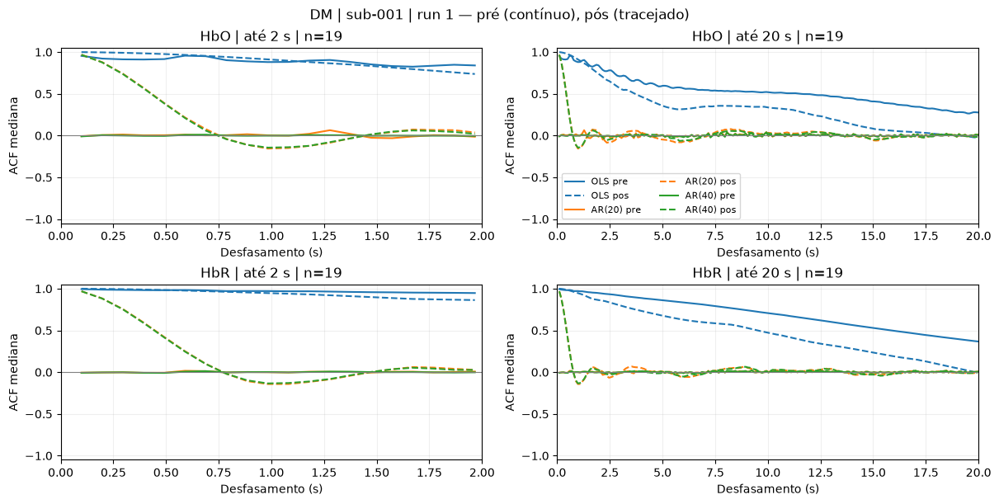

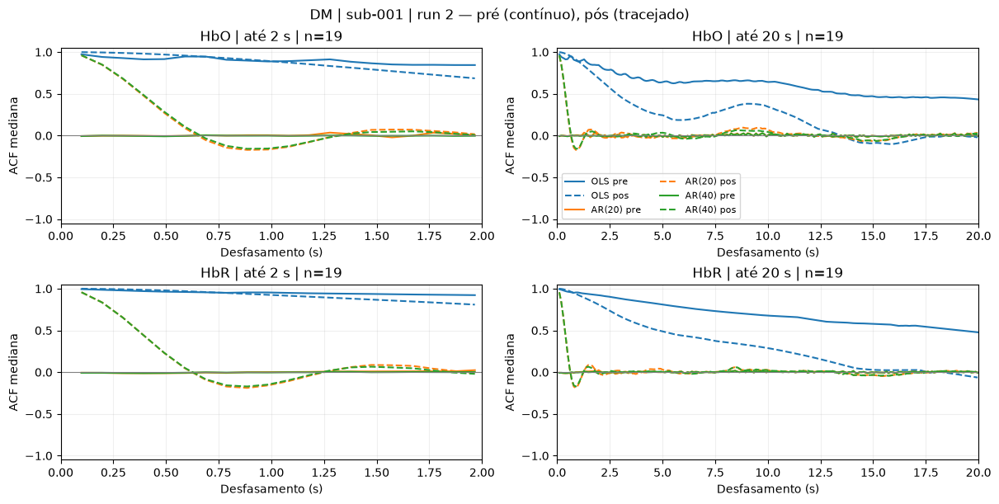

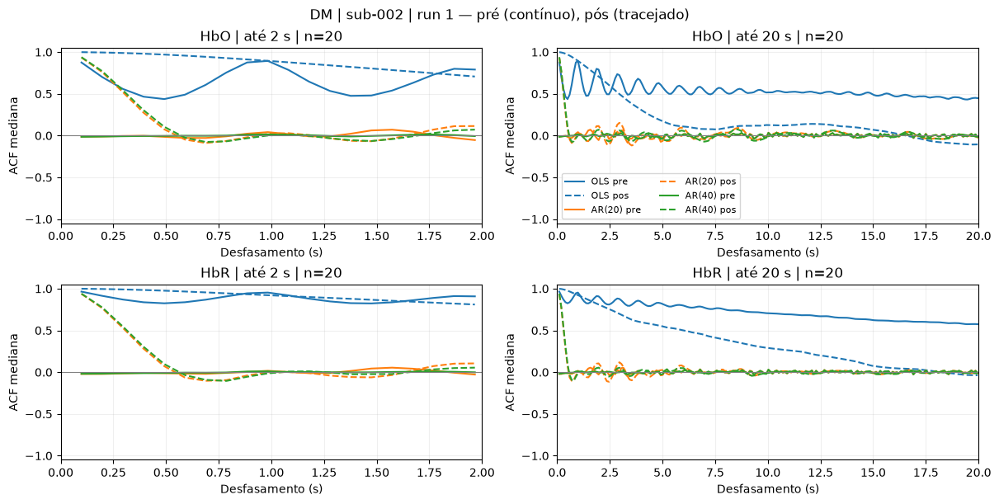

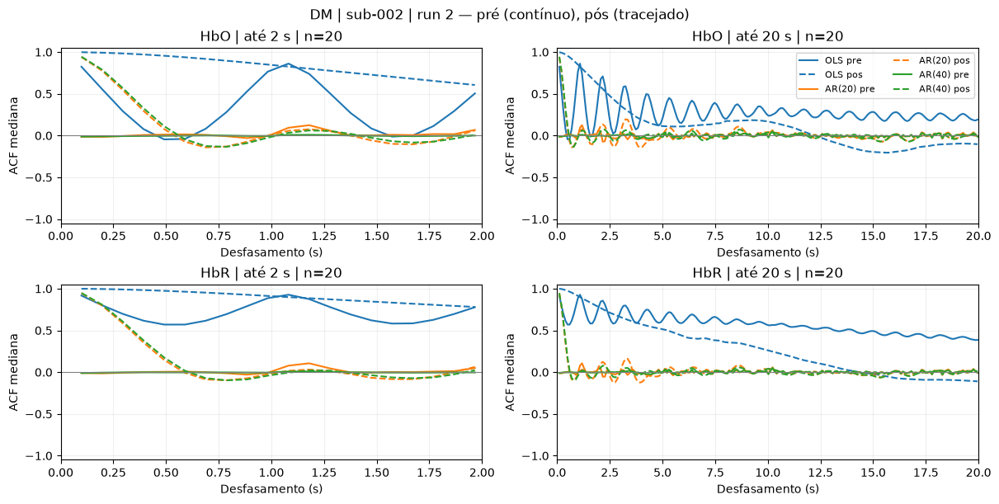


Sem testes inferenciais, SSR, WINGS, épocas ou ficheiros escritos.


In [16]:
import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from scipy.linalg import solve_toeplitz
from scipy.signal import lfilter

ORDENS_27C = (0, 20, 40)
CORTE_27C = 40
COLUNAS_27C = ["video", "decisao", "constante"]
IDS_27C = ["sujeito", "run", "cromoforo", "canal"]
MODELOS_27C = {0: "OLS", 20: "AR(20)", 40: "AR(40)"}
RAMOS_27C = {
    "pre": ("unfiltered", "sem_filtro"),
    "pos": ("filtered", "com_filtro"),
}

if not (
    set(esperadas_26c) == set(piloto_matrizes_glm)
    == set(piloto_canais_longos_27b)
    and len(esperadas_26c) == 4
):
    raise RuntimeError("As entradas não correspondem às mesmas quatro runs do DM.")


def autocov_27c(e, lag_max):
    z = e - e.mean()
    return np.array([
        np.dot(z[k:], z[:len(z) - k]) / len(z)
        for k in range(lag_max + 1)
    ])


def ajustar_dm_27c():
    registos, falhas, curvas, grelhas = [], [], {}, {}

    for chave, n_esperado in sorted(esperadas_26c.items()):
        sujeito, run = chave
        canais = piloto_canais_longos_27b[chave]
        if not canais or len(canais) != len(set(canais)):
            raise RuntimeError(f"{chave}: seleção de canais inválida.")

        print(f"A ajustar DM: {sujeito} | run {run}...", flush=True)

        for ramo, (sufixo, versao) in RAMOS_27C.items():
            candidatos = ficheiros_26c.get((*chave, sufixo), set())
            if len(candidatos) != 1:
                raise RuntimeError(f"{chave} / {ramo}: FIF ausente ou ambíguo.")

            dm = piloto_matrizes_glm[chave][versao]
            with mne.io.read_raw_fif(
                next(iter(candidatos)), preload=False, verbose=False
            ) as raw:
                if (
                    raw.n_times != n_esperado
                    or list(dm.columns) != COLUNAS_27C
                    or not np.array_equal(dm.index.to_numpy(), raw.times)
                ):
                    raise RuntimeError(f"{chave} / {ramo}: desenho ou grelha incompatível.")

                if not set(canais).issubset(set(raw.ch_names) - set(raw.info["bads"])):
                    raise RuntimeError(f"{chave} / {ramo}: canais ausentes ou maus.")

                tipos = raw.get_channel_types(picks=canais)
                y = raw.get_data(picks=canais).T * 1e6
                sfreq = float(raw.info["sfreq"])

            x = dm.to_numpy(dtype=float)
            if not (np.isfinite(x).all() and np.isfinite(y).all()):
                raise RuntimeError(f"{chave} / {ramo}: entrada não finita.")

            lag_1s = max(1, round(sfreq))
            lag_max = min(int(20 * sfreq), len(x) - CORTE_27C - 1)
            if lag_max < lag_1s:
                raise RuntimeError(f"{chave} / {ramo}: janela insuficiente para a ACF.")

            lags = np.arange(lag_max + 1) / sfreq
            if chave in grelhas and not np.array_equal(grelhas[chave], lags):
                raise RuntimeError(f"{chave}: grelhas de ACF pré/pós diferentes.")
            grelhas[chave] = lags

            b_full, _, posto_full, _ = np.linalg.lstsq(x, y, rcond=None)
            if posto_full != 3:
                raise RuntimeError(f"{chave} / {ramo}: OLS inicial sem posto completo.")
            residuos_full = y - x @ b_full

            for j, (canal, tipo) in enumerate(zip(canais, tipos)):
                gamma = autocov_27c(residuos_full[:, j], CORTE_27C)

                for p in ORDENS_27C:
                    ids = {
                        "sujeito": sujeito, "run": run, "cromoforo": tipo,
                        "canal": canal, "ramo": ramo, "ordem": p,
                        "modelo": MODELOS_27C[p],
                    }

                    try:
                        raiz = np.nan
                        if p == 0:
                            xx = x[CORTE_27C:]
                            yy = y[CORTE_27C:, j]
                        else:
                            if not np.isfinite(gamma).all() or gamma[0] <= 0:
                                raise ValueError("Autocovariância inicial inválida.")

                            rho = gamma[:p + 1] / gamma[0]
                            phi = solve_toeplitz(rho[:-1], rho[1:])
                            if not np.isfinite(phi).all():
                                raise ValueError("Coeficientes AR não finitos.")

                            filtro = np.r_[1.0, -phi]
                            raiz = float(np.max(np.abs(np.roots(filtro))))
                            if not np.isfinite(raiz) or raiz >= 1:
                                raise ValueError(f"AR instável: raiz máxima = {raiz:.8g}.")

                            xx = lfilter(filtro, [1.0], x, axis=0)[CORTE_27C:]
                            yy = lfilter(filtro, [1.0], y[:, j])[CORTE_27C:]

                        b, _, posto, sv = np.linalg.lstsq(xx, yy, rcond=None)
                        if posto != 3 or not np.isfinite(b).all():
                            raise ValueError("Ajuste inválido ou posto incompleto.")

                        g = autocov_27c(yy - xx @ b, lag_max)
                        if not np.isfinite(g).all() or g[0] <= 0:
                            raise ValueError("ACF residual indefinida.")
                        acf = g / g[0]

                    except (ValueError, np.linalg.LinAlgError) as erro:
                        if p == 0:
                            raise RuntimeError(
                                f"{chave} / {ramo} / {canal}: OLS inválido."
                            ) from erro
                        falhas.append({**ids, "motivo": str(erro)})
                        continue

                    registos.append({
                        **ids,
                        "n_amostras": len(yy),
                        "beta_video_uM": b[0],
                        "beta_decisao_uM": b[1],
                        "acf_lag1": acf[1],
                        "abs_acf_1s": abs(acf[lag_1s]),
                        "pico_abs_acf": np.max(np.abs(acf[1:])),
                        "condicao_matriz": float(sv[0] / sv[-1]),
                        "raiz_max_ar": raiz,
                    })
                    curvas[(chave, tipo, canal, ramo, p)] = acf

    return pd.DataFrame(registos), pd.DataFrame(falhas), curvas, grelhas


(
    df_dm_27c_ajustes,
    df_dm_27c_falhas,
    curvas_27c,
    grelhas_27c,
) = ajustar_dm_27c()

# Resumir os mesmos canais nos seis ajustes: dois ramos × três ordens.
d = df_dm_27c_ajustes
if d.duplicated(IDS_27C + ["ramo", "ordem"]).any():
    raise RuntimeError("Há ajustes duplicados.")

n_por_canal = d.groupby(IDS_27C)["ordem"].transform("size")
comuns_27c = d.loc[n_por_canal.eq(6)].copy()
if comuns_27c.empty:
    raise RuntimeError("Nenhum canal tem os seis ajustes válidos.")

grupos = ["sujeito", "run", "cromoforo"]
df_dm_27c_acf = comuns_27c.groupby(
    grupos + ["ordem", "modelo", "ramo"], as_index=False
).agg(
    n_canais=("canal", "size"),
    n_amostras=("n_amostras", "first"),
    acf_lag1_med=("acf_lag1", "median"),
    abs_acf_1s_med=("abs_acf_1s", "median"),
    pico_abs_med=("pico_abs_acf", "median"),
    pico_abs_p90=("pico_abs_acf", lambda s: s.quantile(0.90)),
    condicao_max=("condicao_matriz", "max"),
    raiz_max=("raiz_max_ar", "max"),
)

pares = comuns_27c.pivot(
    index=IDS_27C, columns=["ramo", "ordem"],
    values=["beta_video_uM", "beta_decisao_uM", "n_amostras"],
)
if not all(
    pares["n_amostras", "pre", 0].eq(pares["n_amostras", ramo, p]).all()
    for ramo in RAMOS_27C for p in ORDENS_27C
):
    raise RuntimeError("Há ajustes com janelas diferentes.")

comparacoes = [
    (f"{MODELOS_27C[p]} pós − pré", ("pre", p), ("pos", p))
    for p in ORDENS_27C
] + [
    ("AR(40) pré − AR(20) pré", ("pre", 20), ("pre", 40)),
]

tabelas = []
for fase in ("video", "decisao"):
    for nome, a, b in comparacoes:
        v_a = pares[(f"beta_{fase}_uM", *a)]
        v_b = pares[(f"beta_{fase}_uM", *b)]
        tabelas.append(pd.DataFrame({
            "fase": fase,
            "comparacao": nome,
            "beta_a_uM": v_a,
            "beta_b_uM": v_b,
            "delta_uM": v_b - v_a,
            "delta_abs_uM": (v_b - v_a).abs(),
            "inversao": (v_a.lt(0) & v_b.gt(0)) | (v_a.gt(0) & v_b.lt(0)),
        }).reset_index())

df_dm_27c_betas_pares = pd.concat(tabelas, ignore_index=True)
df_dm_27c_betas_resumo = df_dm_27c_betas_pares.groupby(
    ["fase", "comparacao"] + grupos, as_index=False, sort=False
).agg(
    n_canais=("canal", "size"),
    delta_med_uM=("delta_uM", "median"),
    delta_abs_med_uM=("delta_abs_uM", "median"),
    delta_abs_max_uM=("delta_abs_uM", "max"),
    inversoes=("inversao", "sum"),
)

print("\nETAPA 27C — ACF RESIDUAL PRÉ/PÓS-FILTRO")
print(df_dm_27c_acf.round(4).to_string(index=False))
print(f"\nAjustes AR inválidos: {len(df_dm_27c_falhas)}")
print(f"Combinações canal–run comuns aos seis ajustes: {len(pares)}")
if not df_dm_27c_falhas.empty:
    print(df_dm_27c_falhas.to_string(index=False))

print("\nALTERAÇÕES EMPARELHADAS DOS BETAS DE VÍDEO E DECISÃO (µM)")
print(df_dm_27c_betas_resumo.round(4).to_string(index=False))

print("\nMAIOR ALTERAÇÃO ABSOLUTA POR FASE E COMPARAÇÃO")
top = df_dm_27c_betas_pares.groupby(
    ["fase", "comparacao"], sort=False
)["delta_abs_uM"].idxmax()
print(df_dm_27c_betas_pares.loc[top].round(4).to_string(index=False))

for chave, t in grelhas_27c.items():
    sujeito, run = chave
    fig, axs = plt.subplots(2, 2, figsize=(12, 6), layout="constrained")

    for i, (tipo, titulo) in enumerate((("hbo", "HbO"), ("hbr", "HbR"))):
        nomes = comuns_27c.loc[
            comuns_27c["sujeito"].eq(sujeito)
            & comuns_27c["run"].eq(run)
            & comuns_27c["cromoforo"].eq(tipo)
            & comuns_27c["ramo"].eq("pre")
            & comuns_27c["ordem"].eq(0),
            "canal",
        ].tolist()

        for ax, limite in zip(axs[i], (2, 20)):
            janela = (t > 0) & (t <= limite)
            if nomes:
                for p, cor in zip(ORDENS_27C, ("C0", "C1", "C2")):
                    for ramo, estilo in (("pre", "-"), ("pos", "--")):
                        a = np.stack([
                            curvas_27c[(chave, tipo, c, ramo, p)] for c in nomes
                        ])
                        ax.plot(
                            t[janela], np.median(a[:, janela], axis=0),
                            color=cor, linestyle=estilo,
                            label=f"{MODELOS_27C[p]} {ramo}",
                        )

            ax.axhline(0, color="0.5", linewidth=0.8)
            ax.set(
                xlim=(0, limite), ylim=(-1.05, 1.05),
                title=f"{titulo} | até {limite} s | n={len(nomes)}",
                xlabel="Desfasamento (s)", ylabel="ACF mediana",
            )
            ax.grid(alpha=0.2)

    if axs[0, 1].get_legend_handles_labels()[0]:
        axs[0, 1].legend(ncol=2, fontsize=8)
    fig.suptitle(f"DM | {sujeito} | run {run} — pré (contínuo), pós (tracejado)")
    plt.show()
    plt.close(fig)

print("\nSem testes inferenciais, SSR, WINGS, épocas ou ficheiros escritos.")

## Etapa 28A.0 — reconstrução da elegibilidade e dos grupos

### Objetivo
Reconstruir a classificação dos participantes a partir das respostas
sobre prática federada atual no dataset original.

### Saídas
- `df_28a0_grupos`: classificação por ID e indicadores A, AB e C.
- `df_28a0_revisao`: respostas em falta ou por classificar.
- `ids_28a_validados`: lista criada apenas se os totais esperados
  forem reproduzidos e não houver classificações pendentes.

### Limites
Não se usa o historial desportivo para definir a prática atual.
Não se inferem grupos a partir das pastas nem se alteram dados.
Não se escrevem ficheiros.

In [4]:
import re
import unicodedata
from pathlib import Path

import pandas as pd

FICHEIRO_28A0 = Path(
    r"C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects"
    r"\01_Dataset_Demografia_MIQ-3_Comportamentais.xlsx"
)

if not FICHEIRO_28A0.is_file():
    raise FileNotFoundError(FICHEIRO_28A0)


def normalizar_28a0(valor):
    if pd.isna(valor):
        return ""
    s = unicodedata.normalize("NFKD", str(valor))
    s = "".join(c for c in s if not unicodedata.combining(c))
    return re.sub(r"\s+", " ", s).strip().casefold()


colunas_28a0 = {
    "ID": "ID",
    "É atualmente praticante federado de alguma modalidade desportiva?":
        "federado_atual",
    "No caso de ser desportista federado, a sua modalidade principal é:":
        "tipo_modalidade_atual",
    "Indique a modalidade principal":
        "modalidade_principal",
}
nomes_28a0 = {
    normalizar_28a0(coluna): nome for coluna, nome in colunas_28a0.items()
}

with pd.ExcelFile(FICHEIRO_28A0) as excel:
    candidatas = []
    for folha in excel.sheet_names:
        cabecalho = excel.parse(folha, nrows=0).columns.tolist()
        mapa = {}
        for coluna in cabecalho:
            chave = normalizar_28a0(coluna)
            if chave in nomes_28a0:
                destino = nomes_28a0[chave]
                if destino in mapa:
                    raise ValueError(f"Cabeçalho ambíguo na folha {folha!r}: {coluna}")
                mapa[destino] = coluna
        if set(mapa) == set(colunas_28a0.values()):
            candidatas.append((folha, mapa))

    if len(candidatas) != 1:
        raise ValueError(
            f"Esperava uma folha com as quatro colunas; "
            f"encontrei {[folha for folha, _ in candidatas]}. "
            f"Folhas no ficheiro: {excel.sheet_names}"
        )

    folha_28a0, mapa = candidatas[0]
    d = excel.parse(folha_28a0, usecols=list(mapa.values()), dtype=str)
    d = d.rename(columns={coluna: nome for nome, coluna in mapa.items()})

d = d.dropna(how="all").copy()
d["ID"] = d["ID"].map(normalizar_28a0)

ids_invalidos = ~d["ID"].str.fullmatch(r"sub-\d{3}")
if ids_invalidos.any() or d["ID"].duplicated().any():
    raise ValueError(
        f"IDs inválidos: {d.loc[ids_invalidos, 'ID'].tolist()}; "
        f"duplicados: {d.loc[d['ID'].duplicated(keep=False), 'ID'].tolist()}."
    )

federado = d["federado_atual"].map(normalizar_28a0)
tipo = d["tipo_modalidade_atual"].map(normalizar_28a0)
modalidade = d["modalidade_principal"].map(normalizar_28a0)

d["A"] = federado.eq("sim") & tipo.eq("modalidade coletiva")
d["AB"] = d["A"] & modalidade.eq("futebol")
d["C"] = federado.eq("nao")
d["exclusao_individual"] = federado.eq("sim") & tipo.eq("modalidade individual")

d["estado"] = "Por rever"
d.loc[d["A"], "estado"] = "A"
d.loc[d["C"], "estado"] = "C"
d.loc[d["exclusao_individual"], "estado"] = "Exclusão: individual atual"

# Um atleta coletivo sem modalidade indicada pertence a A,
# mas não pode ser classificado com segurança quanto a AB.
d["rever_AB"] = d["A"] & modalidade.eq("")

df_28a0_grupos = d.sort_values("ID").reset_index(drop=True)
df_28a0_revisao = df_28a0_grupos.loc[
    df_28a0_grupos["estado"].eq("Por rever") | df_28a0_grupos["rever_AB"]
].copy()

g = df_28a0_grupos
elegiveis = g["A"] | g["C"]
observado = {
    "Total": len(g),
    "A": int(g["A"].sum()),
    "AB": int(g["AB"].sum()),
    "C": int(g["C"].sum()),
    "Exclusão: individual atual": int(g["exclusao_individual"].sum()),
    "Elegíveis": int(elegiveis.sum()),
}
esperado = {
    "Total": 54,
    "A": 28,
    "AB": 22,
    "C": 23,
    "Exclusão: individual atual": 3,
    "Elegíveis": 51,
}

print(f"ETAPA 28A.0 — Folha: {folha_28a0}")
print(pd.DataFrame({"observado": observado, "esperado": esperado}).to_string())

for grupo in ("A", "AB", "C"):
    print(f"\n{grupo}:")
    print("; ".join(g.loc[g[grupo], "ID"]))

print("\nFEDERADOS ATUAIS EM MODALIDADES INDIVIDUAIS")
print(g.loc[g["exclusao_individual"], [
    "ID", "federado_atual", "tipo_modalidade_atual", "modalidade_principal"
]].to_string(index=False))

print("\nCASOS POR REVER")
print(
    df_28a0_revisao[[
        "ID", "federado_atual", "tipo_modalidade_atual", "modalidade_principal",
        "estado", "rever_AB"
    ]].to_string(index=False)
    if not df_28a0_revisao.empty else "Nenhum."
)

# Evitar reutilizar uma lista de uma execução anterior.
globals().pop("ids_28a_validados", None)

if observado == esperado and df_28a0_revisao.empty:
    ids_28a_validados = g.loc[elegiveis, "ID"].tolist()
    print("\nLISTA DOS 51 PARA COLAR NA ETAPA 28A")
    print("; ".join(ids_28a_validados))
else:
    print("\nLista dos 51 não validada. Rever as diferenças antes da Etapa 28A.")
    print("\nMODALIDADES PRINCIPAIS EM A — conferir classificação de AB")
    print(g.loc[g["A"], ["ID", "modalidade_principal", "AB"]].to_string(index=False))

ETAPA 28A.0 — Folha: Merge Dataset
                            observado  esperado
Total                              54        54
A                                  28        28
AB                                 22        22
C                                  23        23
Exclusão: individual atual          3         3
Elegíveis                          51        51

A:
sub-003; sub-007; sub-008; sub-010; sub-012; sub-013; sub-015; sub-016; sub-029; sub-030; sub-033; sub-035; sub-036; sub-037; sub-038; sub-041; sub-042; sub-043; sub-044; sub-046; sub-047; sub-048; sub-049; sub-050; sub-051; sub-052; sub-053; sub-054

AB:
sub-003; sub-008; sub-016; sub-030; sub-033; sub-035; sub-036; sub-037; sub-038; sub-041; sub-042; sub-043; sub-044; sub-046; sub-047; sub-048; sub-049; sub-050; sub-051; sub-052; sub-053; sub-054

C:
sub-001; sub-002; sub-004; sub-005; sub-006; sub-009; sub-011; sub-017; sub-018; sub-019; sub-020; sub-021; sub-022; sub-024; sub-025; sub-026; sub-027; sub-028; sub-03

## Etapa 28A — Inventário das aquisições fNIRS da amostra analítica

### Objetivo
Localizar os ficheiros SNIRF das duas runs de DM e das duas runs
de Stroop para cada um dos 51 participantes elegíveis.

### Entradas
- `ids_28a_validados`: lista dos 51 IDs produzida na Etapa 28A.0.
- `df_28a0_grupos`: classificação por ID produzida na Etapa 28A.0.
- Pasta que contém as pastas individuais `sub-XXX`.

### Procedimento
1. Confirmar a elegibilidade e os grupos: A = 28, AB = 22 e C = 23.
   AB está contido em A; não constitui um terceiro grupo independente.
2. Criar as 204 combinações esperadas: 51 participantes × duas tarefas
   × duas runs.
3. Procurar ficheiros `.snirf` em `sub-XXX/nirs`, incluindo subpastas.
4. Identificar a tarefa e a run pelo caminho relativo do ficheiro.
   Sinalizar nomes não reconhecidos, contraditórios ou fora das runs 1–2.
5. Registar se cada combinação tem um único SNIRF localizado, nenhum
   candidato ou vários candidatos. Não escolher entre ficheiros ambíguos.

### Saídas
- `df_28a_manifesto`: uma linha por participante × tarefa × run,
  com indicadores A, AB e C, estado e caminhos candidatos.
- `df_28a_nao_classificados`: ficheiros que não puderam ser associados
  com segurança a uma combinação esperada.
- `df_28a_resumo`: contagens por tarefa, run e estado.
- `df_28a_pendentes`: combinações que precisam de revisão.

### Limites
Localizar um SNIRF não confirma que esteja completo ou que tenha qualidade.
Não se abrem os sinais, não se avaliam os canais, não se ajusta o GLM
e não se escrevem ficheiros. O emparelhamento com WINGS e PsychoPy
será feito separadamente.

In [5]:
import re
from itertools import product
from pathlib import Path

import pandas as pd

# Recuperar a amostra validada; não pedir os IDs de novo.
necessarios_28a = {"ids_28a_validados", "df_28a0_grupos"}
if not necessarios_28a.issubset(globals()):
    raise RuntimeError(
        "Corre primeiro a Etapa 28A.0 neste mesmo kernel."
    )

ids_28a = list(ids_28a_validados)
if (
    len(ids_28a) != 51
    or len(set(ids_28a)) != 51
    or not all(re.fullmatch(r"sub-\d{3}", s) for s in ids_28a)
):
    raise ValueError("A lista validada deve conter 51 IDs únicos no formato sub-XXX.")

grupos_28a = df_28a0_grupos.loc[:, ["ID", "A", "AB", "C"]].copy()
if grupos_28a["ID"].duplicated().any():
    raise ValueError("Há IDs duplicados na classificação da Etapa 28A.0.")

elegiveis_28a = grupos_28a.loc[grupos_28a["A"] | grupos_28a["C"]].copy()
if (
    set(elegiveis_28a["ID"]) != set(ids_28a)
    or (grupos_28a["A"] & grupos_28a["C"]).any()
    or (grupos_28a["AB"] & ~grupos_28a["A"]).any()
    or grupos_28a[["A", "AB", "C"]].sum().to_dict()
       != {"A": 28, "AB": 22, "C": 23}
):
    raise ValueError(
        "A lista e a classificação não coincidem. Revê a Etapa 28A.0."
    )

grupos_por_id_28a = elegiveis_28a.set_index("ID").to_dict(orient="index")

entrada_raiz_28a = input(
    "Pasta que contém diretamente as pastas sub-XXX: "
).strip().strip('"')

if not entrada_raiz_28a:
    raise ValueError("Indica a pasta que contém as pastas individuais.")

RAIZ_28A = Path(entrada_raiz_28a).expanduser()
if not RAIZ_28A.is_dir():
    raise NotADirectoryError(RAIZ_28A)

if not any((RAIZ_28A / sujeito).is_dir() for sujeito in ids_28a):
    raise ValueError(
        "Nenhuma pasta individual dos 51 IDs foi encontrada diretamente "
        "neste caminho. Indica a pasta-mãe das pastas sub-XXX."
    )

tarefas_28a = ("dm", "stroop")
runs_28a = (1, 2)
padrao_28a = re.compile(
    r"(?:^|[_/])tk-(dm|stroop)_run-(\d+)(?=[_./]|$)",
    re.IGNORECASE,
)

linhas_28a = []
nao_classificados_28a = []

for sujeito in sorted(ids_28a):
    pasta_sujeito = RAIZ_28A / sujeito
    pasta_nirs = pasta_sujeito / "nirs"
    tem_sujeito = pasta_sujeito.is_dir()
    tem_nirs = pasta_nirs.is_dir()
    encontrados = {chave: set() for chave in product(tarefas_28a, runs_28a)}

    if tem_nirs:
        for ficheiro in sorted(pasta_nirs.rglob("*")):
            if ficheiro.suffix.lower() != ".snirf" or not ficheiro.is_file():
                continue

            relativo = ficheiro.relative_to(pasta_nirs).as_posix()
            marcas = {
                (tarefa.lower(), int(run))
                for tarefa, run in padrao_28a.findall(relativo)
            }

            if len(marcas) == 1:
                chave = next(iter(marcas))
                if chave in encontrados:
                    encontrados[chave].add(str(ficheiro.resolve()))
                    continue
                motivo = "run fora de 1–2"
            elif not marcas:
                motivo = "tarefa/run não reconhecidas"
            else:
                motivo = "identificação contraditória no caminho"

            nao_classificados_28a.append({
                "sujeito": sujeito,
                "ficheiro": str(ficheiro),
                "motivo": motivo,
            })

    for (tarefa, run), candidatos in encontrados.items():
        caminhos = sorted(candidatos)
        n = len(caminhos)

        if not tem_sujeito:
            estado = "pasta do participante não localizada"
        elif not tem_nirs:
            estado = "pasta nirs não localizada"
        elif n == 0:
            estado = "SNIRF por localizar"
        elif n == 1:
            estado = "SNIRF localizado"
        else:
            estado = "ambíguo: vários SNIRF"

        linhas_28a.append({
            "sujeito": sujeito,
            "tarefa": tarefa,
            "run": run,
            **grupos_por_id_28a[sujeito],
            "estado": estado,
            "n_candidatos": n,
            "snirf": caminhos[0] if n == 1 else None,
            "candidatos": " | ".join(caminhos),
        })

df_28a_manifesto = pd.DataFrame(linhas_28a)
df_28a_nao_classificados = pd.DataFrame(
    nao_classificados_28a, columns=["sujeito", "ficheiro", "motivo"]
)

if (
    len(df_28a_manifesto) != 204
    or df_28a_manifesto.duplicated(["sujeito", "tarefa", "run"]).any()
):
    raise RuntimeError("O manifesto não contém as 204 combinações únicas esperadas.")

df_28a_resumo = (
    df_28a_manifesto.groupby(["tarefa", "run", "estado"])
    .size()
    .rename("n_runs")
    .reset_index()
)

df_28a_pendentes = df_28a_manifesto.loc[
    df_28a_manifesto["estado"].ne("SNIRF localizado")
].copy()

print(f"ETAPA 28A — {len(df_28a_manifesto)} combinações esperadas")
print(df_28a_resumo.to_string(index=False))

print(f"\nCombinações pendentes: {len(df_28a_pendentes)}")
if not df_28a_pendentes.empty:
    print(df_28a_pendentes[
        ["sujeito", "tarefa", "run", "estado", "n_candidatos"]
    ].to_string(index=False))

print(f"\nSNIRF não classificados: {len(df_28a_nao_classificados)}")
if not df_28a_nao_classificados.empty:
    print("\nPrimeiros 10 exemplos:")
    print(df_28a_nao_classificados.head(10).to_string(index=False))

print("\nNenhum sinal carregado e nenhum ficheiro escrito.")

ETAPA 28A — 204 combinações esperadas
tarefa  run           estado  n_runs
    dm    1 SNIRF localizado      51
    dm    2 SNIRF localizado      51
stroop    1 SNIRF localizado      51
stroop    2 SNIRF localizado      51

Combinações pendentes: 0

SNIRF não classificados: 0

Nenhum sinal carregado e nenhum ficheiro escrito.


## Etapa 28B — Auditoria dos cabeçalhos SNIRF

### Objetivo
Verificar a leitura e a estrutura das 204 aquisições localizadas
na Etapa 28A, antes do pré-processamento em lote.

### Entrada
- `df_28a_manifesto`: uma linha por sujeito × tarefa × run,
  com caminho SNIRF e indicadores A, AB e C.

### Procedimento
1. Abrir cada SNIRF com `preload=False` e registar erros e avisos.
2. Registar frequência, número de amostras, duração e tipos de canal.
3. Inventariar os pares fonte–detetor e os comprimentos de onda.
4. Contar marcadores de tarefa e registar a sequência observada.
5. Sinalizar diferenças estruturais para revisão, sem excluir runs.

### Saídas
- `df_28b_cabecalhos`: auditoria por aquisição.
- `df_28b_resumo`: leitura dos ficheiros por tarefa e run.
- `df_28b_revisao`: erros, avisos e diferenças a inspecionar.

### Limites
Não se carregam as séries completas, não se calcula SCI, não se
aplicam TDDR, SSR ou filtros e não se escrevem ficheiros. Um cabeçalho
legível não confirma qualidade do sinal nem validade dos eventos.

In [6]:
import json
import re
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import mne
import numpy as np
import pandas as pd

if "df_28a_manifesto" not in globals():
    raise RuntimeError("Corre primeiro a Etapa 28A neste kernel.")

manifesto_28b = df_28a_manifesto.copy()
chaves_28b = ["sujeito", "tarefa", "run"]

if (
    len(manifesto_28b) != 204
    or manifesto_28b.duplicated(chaves_28b).any()
    or not manifesto_28b["estado"].eq("SNIRF localizado").all()
    or manifesto_28b["snirf"].isna().any()
):
    raise RuntimeError("O manifesto não contém as 204 aquisições localizadas.")

if manifesto_28b["snirf"].duplicated().any():
    raise RuntimeError("O mesmo caminho SNIRF está associado a mais de uma run.")

padrao_canal_28b = re.compile(r"^(S\d+_D\d+)\s+(\d+(?:\.\d+)?)$")
codigos_28b = {
    "dm": ("100", "110", "120", "130", "140", "141", "142", "143", "150", "160"),
    "stroop": ("1", "2"),
}
contagens_referencia_28b = {
    "dm": {"100": 1, "110": 10, "120": 10, "130": 10, "150": 10, "160": 1},
    "stroop": {"1": 5, "2": 5},
}

linhas_28b = []

for i, r in enumerate(
    manifesto_28b.sort_values(chaves_28b).itertuples(index=False), start=1
):
    linha = {
        "sujeito": r.sujeito, "tarefa": r.tarefa, "run": r.run,
        "A": r.A, "AB": r.AB, "C": r.C, "snirf": r.snirf,
        "leitura_ok": False, "erro": "", "avisos": "", "alertas": "",
    }
    alertas = []

    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        try:
            with mne.io.read_raw_snirf(
                Path(r.snirf), preload=False, verbose=False
            ) as raw:
                tipos = raw.get_channel_types()
                amplitudes = [
                    nome for nome, tipo in zip(raw.ch_names, tipos)
                    if tipo == "fnirs_cw_amplitude"
                ]
                pares = defaultdict(list)
                nao_reconhecidos = []

                for nome in amplitudes:
                    m = padrao_canal_28b.fullmatch(nome)
                    if m is None:
                        nao_reconhecidos.append(nome)
                    else:
                        par, comprimento = m.groups()
                        pares[par].append(float(comprimento))

                comprimentos = sorted({v for valores in pares.values() for v in valores})
                incompletos = [
                    par for par, valores in pares.items()
                    if len(valores) != 2 or len(set(valores)) != 2
                ]

                descricoes = [str(x).strip() for x in raw.annotations.description]
                contagens = Counter(descricoes)
                previstos = codigos_28b[r.tarefa]
                sequencia = [d for d in descricoes if d in previstos]
                onsets = np.asarray(raw.annotations.onset) - raw.first_time
                mascara = np.isin(descricoes, previstos)
                onsets_tarefa = onsets[mascara]

                if not amplitudes:
                    alertas.append("sem canais de amplitude fNIRS identificados")
                if nao_reconhecidos:
                    alertas.append("nomes de canais de amplitude não reconhecidos")
                if incompletos:
                    alertas.append("pares sem exatamente dois comprimentos de onda distintos")
                if len(comprimentos) != 2:
                    alertas.append("número de comprimentos de onda diferente de dois")
                if not np.isfinite(onsets_tarefa).all():
                    alertas.append("onsets de tarefa não finitos")
                if np.any(np.diff(onsets_tarefa) <= 0):
                    alertas.append("onsets de tarefa não estritamente crescentes")
                if raw.n_times and (
                    np.any(onsets_tarefa < 0) or np.any(onsets_tarefa > raw.times[-1])
                ):
                    alertas.append("onsets de tarefa fora da grelha")
                if any(
                    contagens[c] != n
                    for c, n in contagens_referencia_28b[r.tarefa].items()
                ):
                    alertas.append("contagens de marcadores diferentes da referência piloto")

                # No DM, auditar a ordem das fases sem exigir marcadores
                # de tecla 140–143, que podem não estar no SNIRF.
                if r.tarefa == "dm":
                    fases = [c for c in sequencia if c not in {"140", "141", "142", "143"}]
                    if fases != ["100"] + ["110", "120", "130", "150"] * 10 + ["160"]:
                        alertas.append("ordem das fases DM diferente da referência piloto")

                sfreq = float(raw.info["sfreq"])
                linha.update({
                    "leitura_ok": True,
                    "sfreq_hz": sfreq,
                    "n_amostras": raw.n_times,
                    "tempo_ultima_amostra_s": (
                        (raw.n_times - 1) / sfreq if raw.n_times else np.nan
                    ),
                    "n_canais_total": len(raw.ch_names),
                    "tipos": json.dumps(dict(Counter(tipos)), sort_keys=True),
                    "n_amplitude": len(amplitudes),
                    "n_pares": len(pares),
                    "comprimentos_onda_nm": tuple(comprimentos),
                    "n_pares_incompletos": len(incompletos),
                    "pares_incompletos": "; ".join(incompletos),
                    "canais_nao_reconhecidos": "; ".join(nao_reconhecidos),
                    "n_anotacoes": len(descricoes),
                    "contagens_anotacoes": json.dumps(dict(contagens), sort_keys=True),
                    "sequencia_tarefa": " ".join(sequencia),
                })

        except Exception as erro:
            linha["leitura_ok"] = False
            linha["erro"] = f"{type(erro).__name__}: {erro}"

    linha["avisos"] = " | ".join(dict.fromkeys(str(a.message) for a in avisos))
    linha["alertas"] = " | ".join(alertas)
    linhas_28b.append(linha)

    if i % 25 == 0 or i == len(manifesto_28b):
        print(f"SNIRF inspecionados: {i}/{len(manifesto_28b)}", flush=True)

df_28b_cabecalhos = pd.DataFrame(linhas_28b)

# A estrutura mais frequente é uma referência para revisão, não um critério
# de validade. Em caso de empate, não se escolhe uma referência por ordem.
campos_28b = ["sfreq_hz", "n_amplitude", "n_pares", "comprimentos_onda_nm"]
legiveis_28b = df_28b_cabecalhos.loc[df_28b_cabecalhos["leitura_ok"]]

for tarefa, bloco in legiveis_28b.groupby("tarefa"):
    for campo in campos_28b:
        valores = bloco[campo].round(5) if campo == "sfreq_hz" else bloco[campo]
        frequencias = valores.value_counts()
        if frequencias.empty or (frequencias == frequencias.iloc[0]).sum() != 1:
            continue
        referencia = frequencias.index[0]
        for idx, valor in valores.items():
            if valor != referencia:
                anterior = df_28b_cabecalhos.at[idx, "alertas"]
                novo = f"{campo} diferente do mais frequente em {tarefa}"
                df_28b_cabecalhos.at[idx, "alertas"] = " | ".join(filter(None, [anterior, novo]))

df_28b_cabecalhos["rever"] = (
    ~df_28b_cabecalhos["leitura_ok"]
    | df_28b_cabecalhos["avisos"].ne("")
    | df_28b_cabecalhos["alertas"].ne("")
)
df_28b_revisao = df_28b_cabecalhos.loc[df_28b_cabecalhos["rever"]].copy()

df_28b_resumo = df_28b_cabecalhos.groupby(["tarefa", "run"], as_index=False).agg(
    n_esperadas=("sujeito", "size"),
    n_legiveis=("leitura_ok", "sum"),
    n_rever=("rever", "sum"),
)

print("\nETAPA 28B — LEITURA DOS CABEÇALHOS")
print(df_28b_resumo.to_string(index=False))

if not legiveis_28b.empty:
    print("\nESTRUTURAS OBSERVADAS NOS FICHEIROS LEGÍVEIS")
    estruturas = (
        legiveis_28b.assign(sfreq_hz=legiveis_28b["sfreq_hz"].round(5))
        .groupby(["tarefa"] + campos_28b, dropna=False)
        .size().rename("n_runs").reset_index()
    )
    print(estruturas.to_string(index=False))

print(f"\nAquisições a rever: {len(df_28b_revisao)}")
if not df_28b_revisao.empty:
    print(df_28b_revisao[
        chaves_28b + ["leitura_ok", "erro", "avisos", "alertas"]
    ].head(15).to_string(index=False))

print("\nNenhuma série completa carregada e nenhum ficheiro escrito.")

SNIRF inspecionados: 25/204
SNIRF inspecionados: 50/204
SNIRF inspecionados: 75/204
SNIRF inspecionados: 100/204
SNIRF inspecionados: 125/204
SNIRF inspecionados: 150/204
SNIRF inspecionados: 175/204
SNIRF inspecionados: 200/204
SNIRF inspecionados: 204/204

ETAPA 28B — LEITURA DOS CABEÇALHOS
tarefa  run  n_esperadas  n_legiveis  n_rever
    dm    1           51          51        1
    dm    2           51          51        1
stroop    1           51          51        1
stroop    2           51          51        0

ESTRUTURAS OBSERVADAS NOS FICHEIROS LEGÍVEIS
tarefa  sfreq_hz  n_amplitude  n_pares comprimentos_onda_nm  n_runs
    dm  10.17253           56       28       (760.0, 850.0)     102
stroop  10.17253           56       28       (760.0, 850.0)     102

Aquisições a rever: 3
sujeito tarefa  run  leitura_ok erro avisos                                                                                                     alertas
sub-012     dm    2        True             contage

## Etapa 28C — Inspeção dos marcadores das runs sinalizadas

### Objetivo
Identificar as diferenças nas contagens e na sequência dos marcadores
das três aquisições sinalizadas na Etapa 28B, sem alterar eventos
nem excluir runs.

### Entradas
- `df_28b_revisao`: tabela das aquisições sinalizadas na Etapa 28B,
  incluindo os caminhos SNIRF e o indicador `leitura_ok`.
- Ficheiros SNIRF das aquisições sinalizadas e legíveis:
  - `sub-012` — task decision-making (DM), run 2.
  - `sub-015` — task DM, run 1.
  - `sub-024` — task Stroop, run 1.

### Procedimento
1. Selecionar as aquisições sinalizadas com `leitura_ok=True`.
2. Abrir cada SNIRF com `preload=False`.
3. Listar todas as anotações, incluindo código, início e duração.
   Os inícios são expressos em segundos relativamente ao início
   da aquisição, subtraindo `raw.first_time`.
4. Comparar as contagens observadas com a referência do piloto:
   - Task DM: um marcador `100`, dez de cada código `110`, `120`,
     `130` e `150`, e um marcador `160`.
   - Task Stroop: cinco marcadores `1` e cinco marcadores `2`.
5. Apresentar também os códigos observados sem contagem de referência,
   sem os classificar automaticamente como erros.
6. Na task DM, comparar a sequência de fases observada com:
   `100 → [110 → 120 → 130 → 150] × 10 → 160`.
   Esta comparação considera apenas os códigos de fase indicados,
   sem exigir os marcadores de tecla `140–143`.
7. Apresentar as diferenças de sequência da task DM por segmentos,
   evitando interpretar o deslocamento causado por uma possível
   omissão como vários erros independentes.
8. Na task Stroop, apresentar as anotações e as contagens sem impor
   uma sequência de condições.

### Saídas
- `df_28c_anotacoes`: lista completa das anotações de cada aquisição,
  com posição, código, início e duração.
- `df_28c_contagens`: contagens esperadas e observadas por código,
  respetivas diferenças e indicação dos códigos sem referência.
- `df_28c_diferencas_dm`: segmentos divergentes entre a sequência
  esperada e a sequência observada das fases da task DM.
- Apresentação das três tabelas no output do notebook.

### Limites
- Não se carregam as séries completas do sinal.
- Não se avalia a qualidade do sinal nem se aplica pré-processamento.
- Não se alteram, acrescentam ou removem marcadores.
- Não se excluem runs e não se escrevem ficheiros.
- As referências do piloto são usadas para identificar diferenças,
  não como critérios automáticos de validade.
- A comparação por segmentos não identifica, por si só, a causa
  da discrepância nem o ensaio exato afetado.
- A ausência de diferenças na sequência não confirma a precisão
  temporal dos eventos ou o alinhamento com o PsychoPy.
- As discrepâncias identificadas deverão ser cruzadas com os
  registos PsychoPy da mesma aquisição antes de qualquer decisão.

In [7]:
from collections import Counter
from difflib import SequenceMatcher
from pathlib import Path

import mne
import numpy as np
import pandas as pd


if "df_28b_revisao" not in globals():
    raise RuntimeError("Corre primeiro a Etapa 28B neste kernel.")


referencias_28c = {
    "dm": {
        "100": 1, "110": 10, "120": 10,
        "130": 10, "150": 10, "160": 1,
    },
    "stroop": {"1": 5, "2": 5},
}
fases_dm_28c = {"100", "110", "120", "130", "150", "160"}
sequencia_dm_esperada_28c = (
    ["100"] + ["110", "120", "130", "150"] * 10 + ["160"]
)

alvos_28c = df_28b_revisao.loc[
    df_28b_revisao["leitura_ok"],
    ["sujeito", "tarefa", "run", "snirf"],
].sort_values(["sujeito", "tarefa", "run"])

anotacoes_28c = []
contagens_28c = []
diferencas_dm_28c = []

for r in alvos_28c.itertuples(index=False):
    with mne.io.read_raw_snirf(
        Path(r.snirf), preload=False, verbose=False
    ) as raw:
        descricoes = [
            str(d).strip() for d in raw.annotations.description
        ]
        onsets = (
            np.asarray(raw.annotations.onset, dtype=float)
            - raw.first_time
        )
        duracoes = np.asarray(
            raw.annotations.duration, dtype=float
        )

        for pos, (codigo, onset, duracao) in enumerate(
            zip(descricoes, onsets, duracoes), start=1
        ):
            anotacoes_28c.append({
                "sujeito": r.sujeito,
                "tarefa": r.tarefa,
                "run": r.run,
                "anotacao": pos,
                "codigo": codigo,
                "onset_s": onset,
                "duracao_s": duracao,
            })

        contagem = Counter(descricoes)
        referencia = referencias_28c[r.tarefa]
        codigos = sorted(
            set(contagem) | set(referencia),
            key=lambda x: (
                (0, int(x)) if x.isdigit() else (1, x)
            ),
        )

        for codigo in codigos:
            esperado = referencia.get(codigo)
            observado = contagem[codigo]
            contagens_28c.append({
                "sujeito": r.sujeito,
                "tarefa": r.tarefa,
                "run": r.run,
                "codigo": codigo,
                "esperado": (
                    esperado if esperado is not None else pd.NA
                ),
                "observado": observado,
                "diferenca": (
                    observado - esperado
                    if esperado is not None else pd.NA
                ),
                "comparacao": (
                    "sem referência nesta auditoria"
                    if esperado is None
                    else (
                        "igual" if observado == esperado
                        else "diferente"
                    )
                ),
            })

        if r.tarefa == "dm":
            observada = [
                d for d in descricoes if d in fases_dm_28c
            ]
            comparador = SequenceMatcher(
                None,
                sequencia_dm_esperada_28c,
                observada,
                autojunk=False,
            )

            for tipo, i1, i2, j1, j2 in comparador.get_opcodes():
                if tipo == "equal":
                    continue

                diferencas_dm_28c.append({
                    "sujeito": r.sujeito,
                    "tarefa": r.tarefa,
                    "run": r.run,
                    "tipo_diferenca": tipo,
                    "n_fases_esperadas_antes": i1,
                    "n_fases_observadas_antes": j1,
                    "segmento_esperado": " ".join(
                        sequencia_dm_esperada_28c[i1:i2]
                    ),
                    "segmento_observado": " ".join(
                        observada[j1:j2]
                    ),
                })


df_28c_anotacoes = pd.DataFrame(
    anotacoes_28c,
    columns=[
        "sujeito", "tarefa", "run", "anotacao",
        "codigo", "onset_s", "duracao_s",
    ],
)
df_28c_contagens = pd.DataFrame(
    contagens_28c,
    columns=[
        "sujeito", "tarefa", "run", "codigo",
        "esperado", "observado", "diferenca", "comparacao",
    ],
)
df_28c_diferencas_dm = pd.DataFrame(
    diferencas_dm_28c,
    columns=[
        "sujeito", "tarefa", "run", "tipo_diferenca",
        "n_fases_esperadas_antes",
        "n_fases_observadas_antes",
        "segmento_esperado", "segmento_observado",
    ],
)

print("ETAPA 28C — CONTAGENS DOS MARCADORES")
print(df_28c_contagens.to_string(index=False))

print("\nDIFERENÇAS NA SEQUÊNCIA DE FASES DA TASK DM")
if df_28c_diferencas_dm.empty:
    print("Sem diferenças nas fases comparadas.")
else:
    print(df_28c_diferencas_dm.to_string(index=False))

print("\nANOTAÇÕES COMPLETAS DAS RUNS EM REVISÃO")
for chave, bloco in df_28c_anotacoes.groupby(
    ["sujeito", "tarefa", "run"], sort=False
):
    print(f"\n{chave[0]} | task {chave[1]} | run {chave[2]}")
    print(
        bloco[
            ["anotacao", "codigo", "onset_s", "duracao_s"]
        ].to_string(index=False, float_format=lambda x: f"{x:.3f}")
    )

print("\nNenhum marcador alterado e nenhum ficheiro escrito.")

ETAPA 28C — CONTAGENS DOS MARCADORES
sujeito tarefa  run codigo  esperado  observado  diferenca comparacao
sub-012     dm    2    100         1          0         -1  diferente
sub-012     dm    2    110        10         10          0      igual
sub-012     dm    2    120        10         10          0      igual
sub-012     dm    2    130        10         10          0      igual
sub-012     dm    2    150        10         10          0      igual
sub-012     dm    2    160         1          1          0      igual
sub-015     dm    1    100         1          1          0      igual
sub-015     dm    1    110        10          7         -3  diferente
sub-015     dm    1    120        10          7         -3  diferente
sub-015     dm    1    130        10          6         -4  diferente
sub-015     dm    1    150        10          6         -4  diferente
sub-015     dm    1    160         1          0         -1  diferente
sub-024 stroop    1      1         5          0      

## Etapa 28D — Limites temporais das runs sinalizadas

### Objetivo
Relacionar os marcadores identificados na Etapa 28C com os limites
temporais das aquisições, sem inferir automaticamente interrupções
da tarefa ou falhas de registo.

### Entradas
- `df_28b_cabecalhos`: cabeçalhos e tempo da última amostra de cada run.
- `df_28c_anotacoes`: anotações das runs inspecionadas.
- `df_28c_contagens`: identificação das runs inspecionadas na Etapa 28C.

### Procedimento
1. Selecionar as runs inspecionadas na Etapa 28C.
2. Recuperar o tempo da última amostra de cada aquisição.
3. Contar as anotações disponíveis na tabela da Etapa 28C.
4. Identificar o primeiro e o último marcador, quando existam.
5. Calcular o intervalo entre o início do último marcador e a
   última amostra da aquisição.
6. Confirmar explicitamente as runs sem anotações.

### Saídas
- `df_28d_limites_temporais`: resumo dos limites da aquisição e
  da posição temporal das anotações, por sujeito × task × run.

### Limites
- Não se voltam a abrir os SNIRF nem se carregam séries do sinal.
- O intervalo após o último marcador é calculado a partir do seu
  início, não do fim da duração armazenada na anotação.
- A existência de sinal após o último marcador não demonstra que
  a tarefa tenha continuado.
- A proximidade entre o último marcador e o fim da aquisição não
  demonstra, isoladamente, uma interrupção da gravação.
- Uma tabela de anotações vazia não demonstra que a tarefa não
  tenha sido realizada.
- Não se reconstroem eventos, não se excluem runs e não se escrevem
  ficheiros.
- A interpretação final depende do cruzamento com os registos
  PsychoPy e, quando disponíveis, os registos da sessão.

In [8]:
import numpy as np
import pandas as pd


necessarias_28d = [
    "df_28b_cabecalhos",
    "df_28c_anotacoes",
    "df_28c_contagens",
]
for nome in necessarias_28d:
    if nome not in globals():
        raise RuntimeError(f"Variável em falta: {nome}")


chaves_28d = ["sujeito", "tarefa", "run"]

alvos_28d = (
    df_28c_contagens[chaves_28d]
    .drop_duplicates()
    .sort_values(chaves_28d)
)

base_28d = alvos_28d.merge(
    df_28b_cabecalhos[
        chaves_28d
        + ["leitura_ok", "tempo_ultima_amostra_s", "n_anotacoes"]
    ],
    on=chaves_28d,
    how="left",
    validate="one_to_one",
    indicator=True,
)

if not base_28d["_merge"].eq("both").all():
    raise RuntimeError("Há runs sem correspondência na Etapa 28B.")

if not base_28d["leitura_ok"].eq(True).all():
    raise RuntimeError("Há runs sem leitura confirmada na Etapa 28B.")


linhas_28d = []

for r in base_28d.itertuples(index=False):
    mascara = (
        df_28c_anotacoes["sujeito"].eq(r.sujeito)
        & df_28c_anotacoes["tarefa"].eq(r.tarefa)
        & df_28c_anotacoes["run"].eq(r.run)
    )
    anotacoes = (
        df_28c_anotacoes.loc[mascara]
        .sort_values("anotacao")
    )

    n = len(anotacoes)

    if n != int(r.n_anotacoes):
        raise RuntimeError(
            f"Contagem inconsistente entre 28B e 28C: "
            f"{r.sujeito}, task {r.tarefa}, run {r.run}."
        )

    linha = {
        "sujeito": r.sujeito,
        "tarefa": r.tarefa,
        "run": r.run,
        "tempo_ultima_amostra_s": r.tempo_ultima_amostra_s,
        "n_anotacoes": n,
        "primeiro_codigo": "",
        "primeiro_onset_s": np.nan,
        "ultimo_codigo": "",
        "ultimo_onset_s": np.nan,
        "intervalo_apos_ultimo_onset_s": np.nan,
        "estado_anotacoes": (
            "sem anotações" if n == 0 else "com anotações"
        ),
    }

    if n:
        primeira = anotacoes.iloc[0]
        ultima = anotacoes.iloc[-1]

        linha.update({
            "primeiro_codigo": primeira["codigo"],
            "primeiro_onset_s": float(primeira["onset_s"]),
            "ultimo_codigo": ultima["codigo"],
            "ultimo_onset_s": float(ultima["onset_s"]),
            "intervalo_apos_ultimo_onset_s": (
                float(r.tempo_ultima_amostra_s)
                - float(ultima["onset_s"])
            ),
        })

    linhas_28d.append(linha)


df_28d_limites_temporais = pd.DataFrame(linhas_28d)

print("ETAPA 28D — LIMITES TEMPORAIS DAS RUNS SINALIZADAS")
print(
    df_28d_limites_temporais.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}",
    )
)

print("\nNenhum evento alterado, nenhuma run excluída.")
print("Nenhum SNIRF reaberto e nenhum ficheiro escrito.")

ETAPA 28D — LIMITES TEMPORAIS DAS RUNS SINALIZADAS
sujeito tarefa  run  tempo_ultima_amostra_s  n_anotacoes primeiro_codigo  primeiro_onset_s ultimo_codigo  ultimo_onset_s  intervalo_apos_ultimo_onset_s estado_anotacoes
sub-012     dm    2                 425.853           41             110            44.419           160         397.488                         28.365    com anotações
sub-015     dm    1                 362.250           27             100            98.329           120         343.337                         18.913    com anotações
sub-024 stroop    1                 478.642            0                               NaN                           NaN                            NaN    sem anotações

Nenhum evento alterado, nenhuma run excluída.
Nenhum SNIRF reaberto e nenhum ficheiro escrito.


## Etapa 28E — Registo das ocorrências reportadas durante a recolha

### Objetivo
Estruturar as notas de recolha comunicadas pelo investigador,
mantendo-as separadas dos resultados da auditoria dos ficheiros
e das futuras decisões de inclusão ou exclusão.

### Entradas
Notas de recolha comunicadas pelo investigador:

- `sub-015`, task decision-making (DM), run 1:
  falha do NIRS, com bloqueio do software; a run não decorreu
  corretamente até ao fim e o ficheiro foi guardado.
- `sub-042`, task e run não especificadas:
  falha do PPG, com valores anormais de HR e SpO₂.
- `sub-047`, task Stroop, run 1:
  falha de HR, com valores anormais perto do final da run.

### Procedimento
1. Criar uma linha por ocorrência reportada.
2. Preservar a descrição fornecida pelo investigador.
3. Identificar o sinal ou as medidas referidas na nota.
4. Manter em falta a task e a run quando não foram especificadas.
5. Registar o âmbito temporal apenas com o detalhe disponível.
6. Manter pendentes a verificação e a decisão analítica.

### Saídas
- `df_28e_ocorrencias_recolha`: tabela das ocorrências reportadas.

### Limites
- As notas são relatos da recolha, não resultados de uma inspeção
  adicional dos sinais.
- Não se inferem instantes exatos de falha.
- Não se atribui uma task ou uma run ao `sub-042`.
- Uma ocorrência no PPG, HR ou SpO₂ não é automaticamente
  classificada como falha do sinal fNIRS.
- Não se excluem participantes, runs, épocas ou modalidades.
- Não se alteram as tabelas das etapas anteriores.
- A tabela fica apenas em memória; não se escrevem ficheiros.

In [9]:
import pandas as pd


registos_28e = [
    {
        "sujeito": "sub-015",
        "tarefa": "dm",
        "run": 1,
        "sinal_medidas_reportados": "NIRS",
        "ambito_temporal_reportado": (
            "Durante a run; instante exato não especificado"
        ),
        "nota_reportada": (
            "Falhou o NIRS (o software freezou, "
            "não se correu o resto direito e guardou)"
        ),
        "verificacao_pendente": (
            "Cruzar com PsychoPy e inspecionar os dados "
            "disponíveis antes de definir o tratamento da run"
        ),
    },
    {
        "sujeito": "sub-042",
        "tarefa": pd.NA,
        "run": pd.NA,
        "sinal_medidas_reportados": "PPG; HR; SpO2",
        "ambito_temporal_reportado": "Não especificado",
        "nota_reportada": (
            "O PPG falhou - HR e SPO2 (valores anormais)"
        ),
        "verificacao_pendente": (
            "Identificar task, run e intervalo afetados; "
            "verificar os registos fisiológicos"
        ),
    },
    {
        "sujeito": "sub-047",
        "tarefa": "stroop",
        "run": 1,
        "sinal_medidas_reportados": "HR",
        "ambito_temporal_reportado": (
            "Perto do final da run; instante exato não especificado"
        ),
        "nota_reportada": (
            "A HR falhou no final da Run 1 de stroop, "
            "valores anormais perto fim"
        ),
        "verificacao_pendente": (
            "Localizar o intervalo afetado e verificar "
            "os registos fisiológicos"
        ),
    },
]

df_28e_ocorrencias_recolha = pd.DataFrame(registos_28e)

df_28e_ocorrencias_recolha["run"] = (
    df_28e_ocorrencias_recolha["run"].astype("Int64")
)
df_28e_ocorrencias_recolha["origem"] = (
    "Nota de recolha comunicada pelo investigador"
)
df_28e_ocorrencias_recolha["decisao_analitica"] = "Pendente"

print("ETAPA 28E — OCORRÊNCIAS REPORTADAS NA RECOLHA")
print(df_28e_ocorrencias_recolha.to_string(index=False))

print("\nNenhuma exclusão aplicada.")
print("Tabelas anteriores preservadas e nenhum ficheiro escrito.")

ETAPA 28E — OCORRÊNCIAS REPORTADAS NA RECOLHA
sujeito tarefa  run sinal_medidas_reportados                              ambito_temporal_reportado                                                              nota_reportada                                                                        verificacao_pendente                                       origem decisao_analitica
sub-015     dm    1                     NIRS         Durante a run; instante exato não especificado Falhou o NIRS (o software freezou, não se correu o resto direito e guardou) Cruzar com PsychoPy e inspecionar os dados disponíveis antes de definir o tratamento da run Nota de recolha comunicada pelo investigador          Pendente
sub-042    NaN <NA>            PPG; HR; SpO2                                       Não especificado                                 O PPG falhou - HR e SPO2 (valores anormais)              Identificar task, run e intervalo afetados; verificar os registos fisiológicos Nota de recolha comunica

## Etapa 28E.1 — Atualização do âmbito da ocorrência do sub-042

### Objetivo
Atualizar a ocorrência do `sub-042` com a informação adicional
fornecida pelo investigador, preservando a incerteza do relato.

### Entrada
- `df_28e_ocorrencias_recolha`: tabela criada na Etapa 28E.
- Informação adicional: o investigador recorda que a falha do PPG,
  com valores anormais de HR e SpO₂, terá ocorrido em todas as runs
  de ambas as tasks, mas expressa incerteza sobre essa abrangência.

### Procedimento
1. Localizar a ocorrência do `sub-042`.
2. Preservar a nota original da recolha.
3. Acrescentar a informação adicional e o respetivo grau de certeza.
4. Atualizar o âmbito temporal reportado e a verificação pendente.
5. Manter uma única ocorrência ao nível do participante.
6. Manter task e run sem atribuição individual, uma vez que a
   abrangência de cada aquisição ainda não foi confirmada.

### Saída
- `df_28e_ocorrencias_recolha`: tabela atualizada em memória,
  com campos adicionais para o esclarecimento do relato e
  a certeza sobre a sua abrangência.

### Limites
- A abrangência a todas as runs é uma recordação do investigador,
  ainda não confirmada pela inspeção dos registos.
- Não se classificam automaticamente as quatro aquisições como
  falhas confirmadas.
- Não se infere uma falha do sinal fNIRS.
- Não se excluem dados nem se alteram decisões analíticas.
- Não se escrevem ficheiros.

In [10]:
import pandas as pd


if "df_28e_ocorrencias_recolha" not in globals():
    raise RuntimeError("Corre primeiro a Etapa 28E neste kernel.")

mascara_28e1 = df_28e_ocorrencias_recolha["sujeito"].eq("sub-042")

if mascara_28e1.sum() != 1:
    raise RuntimeError(
        "Era esperada exatamente uma ocorrência para o sub-042."
    )

for coluna in [
    "esclarecimento_investigador",
    "certeza_abrangencia",
]:
    if coluna not in df_28e_ocorrencias_recolha.columns:
        df_28e_ocorrencias_recolha[coluna] = pd.Series(
            pd.NA,
            index=df_28e_ocorrencias_recolha.index,
            dtype="string",
        )

atualizacao_28e1 = {
    "ambito_temporal_reportado": (
        "Provavelmente todas as runs de ambas as tasks; "
        "abrangência por confirmar"
    ),
    "esclarecimento_investigador": (
        "Foi sempre, creio, em todas as runs."
    ),
    "certeza_abrangencia": (
        "Recordação incerta do investigador; não verificada nos registos"
    ),
    "verificacao_pendente": (
        "Verificar PPG, HR e SpO2 nas runs 1 e 2 da task DM "
        "e da task Stroop; determinar a abrangência e os "
        "intervalos afetados"
    ),
}

for coluna, valor in atualizacao_28e1.items():
    df_28e_ocorrencias_recolha.loc[mascara_28e1, coluna] = valor

print("ETAPA 28E.1 — ATUALIZAÇÃO DA OCORRÊNCIA DO SUB-042")
print(
    df_28e_ocorrencias_recolha.loc[mascara_28e1]
    .to_string(index=False)
)

print("\nNota original preservada; abrangência ainda por confirmar.")
print("Nenhuma exclusão aplicada e nenhum ficheiro escrito.")

ETAPA 28E.1 — ATUALIZAÇÃO DA OCORRÊNCIA DO SUB-042
sujeito tarefa  run sinal_medidas_reportados                                                ambito_temporal_reportado                              nota_reportada                                                                                                   verificacao_pendente                                       origem decisao_analitica          esclarecimento_investigador                                             certeza_abrangencia
sub-042    NaN <NA>            PPG; HR; SpO2 Provavelmente todas as runs de ambas as tasks; abrangência por confirmar O PPG falhou - HR e SPO2 (valores anormais) Verificar PPG, HR e SpO2 nas runs 1 e 2 da task DM e da task Stroop; determinar a abrangência e os intervalos afetados Nota de recolha comunicada pelo investigador          Pendente Foi sempre, creio, em todas as runs. Recordação incerta do investigador; não verificada nos registos

Nota original preservada; abrangência ainda por confirmar.

## Etapa 28F — Inspeção dos caminhos disponíveis para o cruzamento com PsychoPy

### Objetivo
Verificar a informação disponível no manifesto para localizar os
registos PsychoPy das três aquisições sinalizadas na auditoria
dos marcadores SNIRF.

### Entradas
- `df_28a_manifesto`: manifesto das aquisições.
- Aquisições a investigar:
  - `sub-012`, task decision-making (DM), run 2.
  - `sub-015`, task DM, run 1.
  - `sub-024`, task Stroop, run 1.

### Procedimento
1. Listar as colunas disponíveis no manifesto.
2. Selecionar as três aquisições através de sujeito, task e run.
3. Confirmar que existe exatamente uma linha por aquisição.
4. Apresentar todos os campos dessas linhas, incluindo os caminhos
   já registados.

### Saída
- `df_28f_alvos_psychopy`: informação disponível no manifesto para
  as três aquisições a cruzar com os registos PsychoPy.
- Listagem das colunas e dos campos de cada aquisição no output.

### Limites
- Não se presume que o manifesto contenha caminhos PsychoPy.
- Não se pesquisam diretórios nem se abrem ficheiros nesta etapa.
- A correspondência no manifesto não valida a correspondência
  temporal entre PsychoPy e SNIRF.
- Não se reconstroem marcadores nem se excluem dados.
- Não se escrevem ficheiros.

In [11]:
import pandas as pd


if "df_28a_manifesto" not in globals():
    raise RuntimeError("Corre primeiro a Etapa 28A neste kernel.")

chaves_28f = ["sujeito", "tarefa", "run"]

faltam_28f = [
    coluna for coluna in chaves_28f
    if coluna not in df_28a_manifesto.columns
]
if faltam_28f:
    raise RuntimeError(
        f"Colunas em falta no manifesto: {faltam_28f}"
    )

alvos_28f = pd.DataFrame([
    {"sujeito": "sub-012", "tarefa": "dm", "run": 2},
    {"sujeito": "sub-015", "tarefa": "dm", "run": 1},
    {"sujeito": "sub-024", "tarefa": "stroop", "run": 1},
])

df_28f_alvos_psychopy = alvos_28f.merge(
    df_28a_manifesto,
    on=chaves_28f,
    how="left",
    validate="one_to_one",
    indicator="_correspondencia_28f",
)

if not df_28f_alvos_psychopy[
    "_correspondencia_28f"
].eq("both").all():
    raise RuntimeError(
        "Uma ou mais aquisições não foram encontradas no manifesto."
    )

df_28f_alvos_psychopy = df_28f_alvos_psychopy.drop(
    columns="_correspondencia_28f"
)

print("ETAPA 28F — COLUNAS DISPONÍVEIS NO MANIFESTO")
for coluna in df_28a_manifesto.columns:
    print(f"- {coluna}")

print("\nINFORMAÇÃO DAS AQUISIÇÕES A INVESTIGAR")
for _, linha in df_28f_alvos_psychopy.iterrows():
    print(
        f"\n{linha['sujeito']} | "
        f"task {linha['tarefa']} | run {linha['run']}"
    )
    for coluna, valor in linha.items():
        print(f"{coluna}: {valor}")

print("\nNenhum diretório pesquisado e nenhum ficheiro aberto ou escrito.")

ETAPA 28F — COLUNAS DISPONÍVEIS NO MANIFESTO
- sujeito
- tarefa
- run
- A
- AB
- C
- estado
- n_candidatos
- snirf
- candidatos

INFORMAÇÃO DAS AQUISIÇÕES A INVESTIGAR

sub-012 | task dm | run 2
sujeito: sub-012
tarefa: dm
run: 2
A: True
AB: False
C: False
estado: SNIRF localizado
n_candidatos: 1
snirf: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-012\nirs\sub-012_ses-01_tk-dm_run-2_nirs_012\sub-012_ses-01_tk-dm_run-2_nirs_012.snirf
candidatos: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-012\nirs\sub-012_ses-01_tk-dm_run-2_nirs_012\sub-012_ses-01_tk-dm_run-2_nirs_012.snirf

sub-015 | task dm | run 1
sujeito: sub-015
tarefa: dm
run: 1
A: True
AB: False
C: False
estado: SNIRF localizado
n_candidatos: 1
snirf: C:\Users\guilh\Desktop\OneDrive - Universidade

## Etapa 28G — Inventário de potenciais registos PsychoPy

### Objetivo
Localizar potenciais registos PsychoPy nas pastas dos três
participantes com aquisições sinalizadas, antes de selecionar
os ficheiros correspondentes a cada task e run.

### Entrada
- `df_28f_alvos_psychopy`: aquisições a investigar, com caminhos SNIRF.

### Procedimento
1. Localizar a pasta de cada participante entre as pastas
   ascendentes do respetivo caminho SNIRF.
2. Confirmar que a pasta existe.
3. Percorrer apenas as pastas dos três participantes.
4. Inventariar ficheiros com extensões `.csv`, `.tsv`, `.log`,
   `.psydat`, `.xlsx`, `.xls` e `.json`.
5. Registar o caminho relativo à pasta do participante, a extensão
   e o tamanho de cada ficheiro.
6. Registar erros de acesso, caso ocorram.
7. Apresentar o inventário sem selecionar automaticamente ficheiros
   por task ou run.

### Saídas
- `df_28g_ficheiros_candidatos`: inventário de ficheiros potencialmente
  relevantes.
- `df_28g_erros`: erros encontrados durante a pesquisa.
- `df_28g_resumo`: número de ficheiros encontrados por participante
  e extensão.

### Limites
- A extensão não confirma que um ficheiro tenha sido produzido
  pelo PsychoPy ou pertença à aquisição pretendida.
- Podem ser encontrados ficheiros de outras tasks, outras runs
  ou resultados derivados.
- Não se usa a data de modificação para estabelecer correspondências.
- Não se lê o conteúdo dos ficheiros.
- Não se abrem ficheiros `.psydat`.
- Não se alteram eventos, não se excluem dados e não se escrevem
  ficheiros.
- A pesquisa pode não encontrar registos guardados fora das pastas
  dos participantes.

In [12]:
import os
from pathlib import Path

import pandas as pd


if "df_28f_alvos_psychopy" not in globals():
    raise RuntimeError("Corre primeiro a Etapa 28F neste kernel.")

extensoes_28g = {
    ".csv", ".tsv", ".log", ".psydat",
    ".xlsx", ".xls", ".json",
}

colunas_ficheiros_28g = [
    "sujeito", "pasta_participante", "nome",
    "extensao", "tamanho_bytes", "caminho_relativo", "caminho",
]
colunas_erros_28g = ["sujeito", "caminho", "erro"]

ficheiros_28g = []
erros_28g = []
pastas_28g = {}

for r in df_28f_alvos_psychopy.itertuples(index=False):
    caminho_snirf = Path(r.snirf)

    pasta = next(
        (
            ascendente
            for ascendente in caminho_snirf.parents
            if ascendente.name == r.sujeito
        ),
        None,
    )

    if pasta is None:
        raise RuntimeError(
            f"Não foi possível identificar a pasta de {r.sujeito} "
            f"no caminho: {caminho_snirf}"
        )

    if not pasta.is_dir():
        raise RuntimeError(
            f"Pasta inexistente ou indisponível: {pasta}"
        )

    if r.sujeito in pastas_28g and pastas_28g[r.sujeito] != pasta:
        raise RuntimeError(
            f"Foram identificadas pastas diferentes para {r.sujeito}."
        )

    pastas_28g[r.sujeito] = pasta


for sujeito, pasta in sorted(pastas_28g.items()):

    def registar_erro_28g(erro, sujeito_atual=sujeito):
        erros_28g.append({
            "sujeito": sujeito_atual,
            "caminho": str(getattr(erro, "filename", "") or ""),
            "erro": f"{type(erro).__name__}: {erro}",
        })

    for diretorio, subpastas, nomes in os.walk(
        pasta,
        topdown=True,
        onerror=registar_erro_28g,
        followlinks=False,
    ):
        subpastas.sort()

        for nome in sorted(nomes):
            caminho = Path(diretorio) / nome

            if caminho.suffix.lower() not in extensoes_28g:
                continue

            try:
                tamanho = caminho.stat().st_size
            except OSError as erro:
                registar_erro_28g(erro)
                tamanho = pd.NA

            ficheiros_28g.append({
                "sujeito": sujeito,
                "pasta_participante": str(pasta),
                "nome": nome,
                "extensao": caminho.suffix.lower(),
                "tamanho_bytes": tamanho,
                "caminho_relativo": str(caminho.relative_to(pasta)),
                "caminho": str(caminho),
            })


df_28g_ficheiros_candidatos = pd.DataFrame(
    ficheiros_28g,
    columns=colunas_ficheiros_28g,
).sort_values(
    ["sujeito", "caminho_relativo"],
    ignore_index=True,
)

df_28g_erros = pd.DataFrame(
    erros_28g,
    columns=colunas_erros_28g,
)

df_28g_resumo = (
    df_28g_ficheiros_candidatos
    .groupby(["sujeito", "extensao"])
    .size()
    .rename("n_ficheiros")
    .reset_index()
)

print("ETAPA 28G — POTENCIAIS REGISTOS PSYCHOPY")

for sujeito in sorted(pastas_28g):
    bloco = df_28g_ficheiros_candidatos.loc[
        df_28g_ficheiros_candidatos["sujeito"].eq(sujeito)
    ]

    print(f"\n{sujeito} | pasta: {pastas_28g[sujeito]}")

    if bloco.empty:
        print("Nenhum ficheiro com as extensões pesquisadas.")
    else:
        print(
            bloco[
                ["caminho_relativo", "extensao", "tamanho_bytes"]
            ].to_string(index=False)
        )

print("\nRESUMO POR PARTICIPANTE E EXTENSÃO")
if df_28g_resumo.empty:
    print("Nenhum candidato encontrado.")
else:
    print(df_28g_resumo.to_string(index=False))

print(f"\nErros de acesso registados: {len(df_28g_erros)}")
if not df_28g_erros.empty:
    print(df_28g_erros.to_string(index=False))

print("\nNenhum conteúdo lido e nenhum ficheiro escrito.")
print("Nenhuma correspondência de task ou run atribuída automaticamente.")

ETAPA 28G — POTENCIAIS REGISTOS PSYCHOPY

sub-012 | pasta: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-012
                                                                      caminho_relativo extensao  tamanho_bytes
              nirs\sub-012_ses-01_tk-dm_run-1_nirs_012\2026-08-18_003_calibration.json    .json           8384
                   nirs\sub-012_ses-01_tk-dm_run-1_nirs_012\2026-08-18_003_config.json    .json           5022
              nirs\sub-012_ses-01_tk-dm_run-1_nirs_012\2026-08-18_003_description.json    .json            149
                nirs\sub-012_ses-01_tk-dm_run-1_nirs_012\2026-08-18_003_probeInfo.json    .json          24698
              nirs\sub-012_ses-01_tk-dm_run-2_nirs_012\2026-08-18_005_calibration.json    .json           8384
                   nirs\sub-012_ses-01_tk-dm_run-2_nirs_012\2026-08-18_005_config.json    .json           50

## F-DM.0 — Recuperação dos tempos da versão de referência

### Objetivo
Recuperar as tabelas temporais das quatro runs do piloto DM,
exclusivamente a partir da versão `pilot_dm_epochs_v01`.

### Origem dos derivados
Para cada participante:

sub-XXX/
    fNIRS_epochs_derivatives/
        pilot_dm_epochs_v01/
            identificador_da_run/
                identificador_da_run_haemo_unfiltered_raw.fif

### Verificações
- Existência dos quatro caminhos explícitos.
- Estrutura completa de 28 séries HbO e 28 séries HbR.
- Número de amostras documentado para cada run.
- Sequência de 42 marcadores.
- Onsets finitos, ordenados e dentro da aquisição.
- Dez tentativas por run, com intervalos positivos.

### Saídas em memória
- `pilototempostentativas`
- `ficheiros_fdm0`
- `df_fdm0_recuperacao`

### Limites
- Não pesquisa nem seleciona derivados de outras versões.
- Não compara o conteúdo de `pilot_dm_epochs_v01` com `v02`.
- Não carrega as séries completas nem repete o pré-processamento.
- Não altera eventos nem escreve ficheiros.
- O intervalo 130–150 não é automaticamente interpretado como tempo de reação.
- Só publica os resultados após verificar as quatro runs.

In [3]:
from pathlib import Path

import mne
import numpy as np
import pandas as pd
from IPython.display import display


def recuperar_tempos_referencia_fdm0(pasta_mae):
    versao = "pilot_dm_epochs_v01"

    esperadas = {
        ("sub-001", 1): 4323,
        ("sub-001", 2): 4271,
        ("sub-002", 1): 4757,
        ("sub-002", 2): 4278,
    }

    sequencia_esperada = (
        ["100"]
        + ["110", "120", "130", "150"] * 10
        + ["160"]
    )

    pasta_mae = Path(pasta_mae).expanduser()

    if not pasta_mae.is_dir():
        raise NotADirectoryError(
            f"Pasta-mãe não encontrada: {pasta_mae}"
        )

    caminhos = {}

    for sujeito, run in sorted(esperadas):
        identificador = (
            f"{sujeito}_ses-01_tk-dm_run-{run}_nirs_{sujeito[-3:]}"
        )

        caminho = (
            pasta_mae
            / sujeito
            / "fNIRS_epochs_derivatives"
            / versao
            / identificador
            / f"{identificador}_haemo_unfiltered_raw.fif"
        )

        if not caminho.is_file():
            raise FileNotFoundError(
                "Derivado de referência não encontrado:\n"
                f"{caminho}\n"
                "Não foi procurado um substituto noutra versão."
            )

        caminhos[(sujeito, run)] = caminho.resolve()

    tabelas = {}
    resumo = []

    for chave, n_esperado in sorted(esperadas.items()):
        sujeito, run = chave
        caminho = caminhos[chave]

        with mne.io.read_raw_fif(
            caminho,
            preload=False,
            verbose=False,
        ) as raw:

            tipos = raw.get_channel_types()

            if not (
                len(tipos) == 56
                and tipos.count("hbo") == 28
                and tipos.count("hbr") == 28
            ):
                raise RuntimeError(
                    f"{chave}: estrutura diferente das "
                    "28 séries HbO e 28 séries HbR esperadas."
                )

            if raw.n_times != n_esperado:
                raise RuntimeError(
                    f"{chave}: foram encontradas {raw.n_times} amostras; "
                    f"esperavam-se {n_esperado}."
                )

            codigos = [
                str(descricao).strip()
                for descricao in raw.annotations.description
            ]

            if codigos != sequencia_esperada:
                raise RuntimeError(
                    f"{chave}: sequência de marcadores diferente "
                    "da documentada no piloto.\n"
                    f"Sequência observada: {codigos}\n"
                    "Nenhum marcador foi imputado ou alterado."
                )

            onsets = (
                np.asarray(raw.annotations.onset, dtype=float)
                - float(raw.first_time)
            )

            if not (
                np.isfinite(onsets).all()
                and np.all(np.diff(onsets) > 0)
                and onsets[0] >= 0
                and onsets[-1] <= raw.times[-1]
            ):
                raise RuntimeError(
                    f"{chave}: onsets não finitos, não ordenados "
                    "ou fora dos limites da aquisição."
                )

            fix_pre, video, decisao, fix_pos = (
                onsets[1:-1].reshape(10, 4).T
            )

            fase_seguinte = np.r_[
                fix_pre[1:],
                onsets[-1],
            ]

            tabela = pd.DataFrame({
                "sujeito": sujeito,
                "run": run,
                "tentativa_na_run": np.arange(1, 11),
                "onset_fixacao_pre_s": fix_pre,
                "onset_video_s": video,
                "onset_decisao_s": decisao,
                "onset_fixacao_pos_s": fix_pos,
                "onset_fase_seguinte_s": fase_seguinte,
                "intervalo_110_120_s": video - fix_pre,
                "intervalo_120_130_s": decisao - video,
                "intervalo_130_150_s": fix_pos - decisao,
                "intervalo_pos_s": fase_seguinte - fix_pos,
            })

            colunas_intervalos = [
                "intervalo_110_120_s",
                "intervalo_120_130_s",
                "intervalo_130_150_s",
                "intervalo_pos_s",
            ]

            intervalos = tabela[
                colunas_intervalos
            ].to_numpy(dtype=float)

            if not (
                np.isfinite(intervalos).all()
                and np.all(intervalos > 0)
            ):
                raise RuntimeError(
                    f"{chave}: foram encontrados intervalos inválidos."
                )

            tabelas[chave] = tabela

            resumo.append({
                "sujeito": sujeito,
                "run": run,
                "versao": versao,
                "n_amostras": int(raw.n_times),
                "sfreq_hz": float(raw.info["sfreq"]),
                "n_marcadores": len(codigos),
                "n_tentativas": len(tabela),
                "sequencia_ok": True,
                "ficheiro": str(caminho),
            })

    return tabelas, caminhos, pd.DataFrame(resumo)


if "pilototempostentativas" in globals():
    raise RuntimeError(
        "'pilototempostentativas' já existe nesta sessão. "
        "Não foi substituído. Executa F-DM.1 para o verificar."
    )

pasta_entrada_fdm0 = globals().get("entrada_fdm0", "")

if not str(pasta_entrada_fdm0).strip():
    pasta_entrada_fdm0 = input(
        "Pasta-mãe que contém sub-001 e sub-002: "
    )

pasta_entrada_fdm0 = (
    str(pasta_entrada_fdm0)
    .strip()
    .strip('"')
    .strip("'")
)

if not pasta_entrada_fdm0:
    raise ValueError("Não foi indicada uma pasta-mãe.")

(
    pilototempostentativas,
    ficheiros_fdm0,
    df_fdm0_recuperacao,
) = recuperar_tempos_referencia_fdm0(pasta_entrada_fdm0)

display(
    df_fdm0_recuperacao.drop(columns="ficheiro")
)

for linha in df_fdm0_recuperacao.itertuples(index=False):
    print(
        f"\n{linha.sujeito} | run {linha.run}\n"
        f"{linha.ficheiro}"
    )

print(
    "\nF-DM.0 concluída."
    "\nRecuperadas 40 tentativas exclusivamente de pilot_dm_epochs_v01."
    "\nNão foram selecionados derivados de v02."
    "\nNão foram carregadas as séries completas."
    "\nNão foram alterados dados nem escritos ficheiros."
    "\nExecuta agora a célula F-DM.1."
)

,sujeito,run,versao,n_amostras,sfreq_hz,n_marcadores,n_tentativas,sequencia_ok
0,sub-001,1,pilot_dm_epochs_v01,4323,10.172526,42,10,True
1,sub-001,2,pilot_dm_epochs_v01,4271,10.172526,42,10,True
2,sub-002,1,pilot_dm_epochs_v01,4757,10.172526,42,10,True
3,sub-002,2,pilot_dm_epochs_v01,4278,10.172526,42,10,True



sub-001 | run 1
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-001_ses-01_tk-dm_run-1_nirs_001\sub-001_ses-01_tk-dm_run-1_nirs_001_haemo_unfiltered_raw.fif

sub-001 | run 2
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-001_ses-01_tk-dm_run-2_nirs_001\sub-001_ses-01_tk-dm_run-2_nirs_001_haemo_unfiltered_raw.fif

sub-002 | run 1
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-002\fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-002_ses-01_tk-dm_run-1_nirs_002\sub-002_ses-01_tk-dm_run-1_nirs_002_haemo_unfiltered_raw.fif

sub-002 | run 2
C:\Us

## F-DM.1 — Verificação dos tempos para a especificação da deriva

### Objetivo
Confirmar os tempos experimentais já reconstruídos nas quatro runs
do piloto DM e resumir as durações e os intervalos entre acontecimentos.

Esta informação será usada para justificar o tratamento da deriva
no modelo contínuo.

### Entrada
- `pilototempostentativas`: tabelas temporais por participante e run.

### Verificações
- Presença das quatro runs esperadas.
- Dez tentativas por run.
- Tempos finitos e ordenados.
- Vídeo anterior à decisão.
- Decisão anterior à fixação pós-resposta.
- Ausência de sobreposição entre tentativas consecutivas.

### Saída
Tabela descritiva apresentada no notebook:
- Duração do vídeo: intervalo 120–130.
- Duração do período de decisão/resposta explícita: intervalo 130–150.
- Intervalo entre inícios consecutivos de vídeo.
- Intervalo entre inícios consecutivos de decisão.

### Limites
- O intervalo 130–150 não é automaticamente interpretado como tempo de reação.
- Não é escolhido ainda um corte para a deriva.
- Não são alterados sinais, eventos ou tabelas de entrada.
- Não são ajustados modelos nem escritos ficheiros.

In [4]:
import numpy as np
import pandas as pd
from IPython.display import display

CHAVES_ESPERADAS_FDM1 = {
    ("sub-001", 1),
    ("sub-001", 2),
    ("sub-002", 1),
    ("sub-002", 2),
}

COLUNAS_TEMPOS_FDM1 = [
    "onset_video_s",
    "onset_decisao_s",
    "onset_fixacao_pos_s",
]

if "pilototempostentativas" not in globals():
    raise RuntimeError(
        "O objeto 'pilototempostentativas' não está disponível neste kernel. "
        "Não executes todo o notebook para o recuperar. "
        "Envia esta mensagem para identificarmos a célula de recuperação adequada."
    )

if not isinstance(pilototempostentativas, dict):
    raise TypeError(
        "'pilototempostentativas' deveria ser um dicionário de tabelas "
        "indexado por (participante, run)."
    )

chaves_disponiveis_fdm1 = set(pilototempostentativas)
chaves_em_falta_fdm1 = (
    CHAVES_ESPERADAS_FDM1 - chaves_disponiveis_fdm1
)

if chaves_em_falta_fdm1:
    raise RuntimeError(
        "Faltam runs no objeto temporal: "
        f"{sorted(chaves_em_falta_fdm1)}."
    )

registos_fdm1 = []

for chave in sorted(CHAVES_ESPERADAS_FDM1):
    sujeito, run = chave
    tabela = pilototempostentativas[chave]

    if not isinstance(tabela, pd.DataFrame):
        raise TypeError(
            f"{chave}: esperava-se uma tabela pandas DataFrame."
        )

    colunas_em_falta = [
        coluna
        for coluna in COLUNAS_TEMPOS_FDM1
        if coluna not in tabela.columns
    ]

    if colunas_em_falta:
        raise RuntimeError(
            f"{chave}: faltam as colunas {colunas_em_falta}. "
            f"Colunas disponíveis: {list(tabela.columns)}. "
            "Não renomeies colunas por suposição; envia esta mensagem."
        )

    if len(tabela) != 10:
        raise RuntimeError(
            f"{chave}: esperavam-se 10 tentativas; "
            f"foram encontradas {len(tabela)}."
        )

    tempos = tabela.loc[:, COLUNAS_TEMPOS_FDM1].to_numpy(
        dtype=float,
        copy=True,
    )

    if not np.isfinite(tempos).all():
        raise RuntimeError(
            f"{chave}: foram encontrados tempos não finitos."
        )

    video = tempos[:, 0]
    decisao = tempos[:, 1]
    fixacao_pos = tempos[:, 2]

    if np.any(video < 0):
        raise RuntimeError(
            f"{chave}: existem inícios de vídeo negativos."
        )

    if not (
        np.all(np.diff(video) > 0)
        and np.all(np.diff(decisao) > 0)
        and np.all(np.diff(fixacao_pos) > 0)
    ):
        raise RuntimeError(
            f"{chave}: os tempos não estão estritamente ordenados "
            "na sequência de linhas da tabela."
        )

    if not (
        np.all(video < decisao)
        and np.all(decisao < fixacao_pos)
    ):
        raise RuntimeError(
            f"{chave}: a sequência vídeo → decisão → fixação pós "
            "não é válida em todas as tentativas."
        )

    if np.any(fixacao_pos[:-1] >= video[1:]):
        raise RuntimeError(
            f"{chave}: uma fixação pós-resposta começa no mesmo instante "
            "ou depois do vídeo da tentativa seguinte."
        )

    medidas = {
        "duracao_video_120_130": decisao - video,
        "duracao_decisao_130_150": fixacao_pos - decisao,
        "intervalo_entre_inicios_video": np.diff(video),
        "intervalo_entre_inicios_decisao": np.diff(decisao),
    }

    for medida, valores in medidas.items():
        registos_fdm1.append(
            {
                "sujeito": sujeito,
                "run": run,
                "medida": medida,
                "n_intervalos": len(valores),
                "min_s": float(np.min(valores)),
                "mediana_s": float(np.median(valores)),
                "max_s": float(np.max(valores)),
            }
        )

df_fdm1_tempos = pd.DataFrame(registos_fdm1)

print("F-DM.1 — VERIFICAÇÃO E RESUMO DOS TEMPOS")
display(
    df_fdm1_tempos.style.format(
        {
            "min_s": "{:.3f}",
            "mediana_s": "{:.3f}",
            "max_s": "{:.3f}",
        }
    )
)

print(
    "\nVerificadas quatro runs, com dez tentativas por run."
    "\nOs intervalos entre inícios têm nove observações por run."
    "\nO intervalo 130–150 não foi classificado como tempo de reação."
    "\nNão foi escolhido um corte de deriva."
    "\nNão foram alterados dados de entrada nem escritos ficheiros."
)

F-DM.1 — VERIFICAÇÃO E RESUMO DOS TEMPOS


,sujeito,run,medida,n_intervalos,min_s,mediana_s,max_s
0,sub-001,1,duracao_video_120_130,10,15.681,21.167,29.693
1,sub-001,1,duracao_decisao_130_150,10,0.618,1.329,2.813
2,sub-001,1,intervalo_entre_inicios_video,9,29.957,33.679,45.151
3,sub-001,1,intervalo_entre_inicios_decisao,9,28.595,33.504,40.376
4,sub-001,2,duracao_video_120_130,10,17.414,21.860,23.722
5,sub-001,2,duracao_decisao_130_150,10,1.094,1.660,2.279
6,sub-001,2,intervalo_entre_inicios_video,9,33.871,35.891,37.905
7,sub-001,2,intervalo_entre_inicios_decisao,9,30.504,36.225,37.882
8,sub-002,1,duracao_video_120_130,10,15.656,21.129,29.617
9,sub-002,1,duracao_decisao_130_150,10,0.917,1.217,3.108



Verificadas quatro runs, com dez tentativas por run.
Os intervalos entre inícios têm nove observações por run.
O intervalo 130–150 não foi classificado como tempo de reação.
Não foi escolhido um corte de deriva.
Não foram alterados dados de entrada nem escritos ficheiros.


## F-DM.2 — Desenho candidato com deriva em cossenos

### Objetivo
Construir e avaliar a matriz de desenho do modelo contínuo DM,
antes do ajuste de HbO/HbR.

### Especificação candidata
- Vídeo: intervalo 120–130 de cada tentativa.
- Decisão/resposta explícita: intervalo 130–150 de cada tentativa.
- HRF: SPM.
- Deriva: cossenos, com corte candidato comum de 0,01 Hz.
- Constante incluída.
- Grelha temporal dos derivados pré-passa-banda.
- Runs mantidas separadas.

### Justificação temporal
Usar o maior intervalo entre inícios consecutivos da mesma condição
como referência para a regra prática 1 / (2 × intervalo máximo).

O corte de 0,01 Hz é uma configuração candidata, não uma validação
automática do modelo nem uma nova filtragem do sinal.

### Verificações
- Correspondência das quatro runs e da versão de referência.
- Eventos finitos, com duração positiva e dentro da aquisição.
- Matriz com valores finitos e posto completo.
- Ausência de regularização automática por singularidade.
- Condicionamento após normalização das colunas.
- Correlação entre os regressores de vídeo e decisão.
- Sobreposição de cada regressor de tarefa com deriva e constante.
- Correlação vídeo–decisão após remover a contribuição da deriva.

### Saídas em memória
- `eventos_fdm2`: eventos por run.
- `desenhos_fdm2`: matrizes candidatas por run.
- `df_fdm2_diagnostico`: resumo das verificações.
- `config_fdm2`: especificação candidata.

### Limites
- Não carrega as séries completas de HbO/HbR.
- Não ajusta GLM, OLS ou modelos autorregressivos.
- Não seleciona AR20 ou AR40.
- Não substitui as matrizes antigas.
- Não escreve ficheiros.
- Posto completo não demonstra separação fisiológica dos efeitos.
- A sobreposição com a deriva é um diagnóstico, não um critério
  automático de exclusão.

In [5]:
import warnings

import mne
import numpy as np
import pandas as pd

from IPython.display import display
from nilearn.glm.first_level import make_first_level_design_matrix


def construir_desenhos_fdm2(tabelas, ficheiros):
    chaves = {
        ("sub-001", 1),
        ("sub-001", 2),
        ("sub-002", 1),
        ("sub-002", 2),
    }

    config = {
        "versao_derivados": "pilot_dm_epochs_v01",
        "ramo": "pre_passa_banda",
        "hrf_model": "spm",
        "drift_model": "cosine",
        "high_pass_hz": 0.01,
        "oversampling": 50,
        "estado": "candidato_sem_ajuste_do_sinal",
    }

    if set(tabelas) != chaves or set(ficheiros) != chaves:
        raise RuntimeError(
            "As entradas devem corresponder exatamente "
            "às quatro runs do piloto."
        )

    maiores_intervalos = []

    for chave in sorted(chaves):
        tabela = tabelas[chave]

        for coluna in ("onset_video_s", "onset_decisao_s"):
            inicios = tabela[coluna].to_numpy(dtype=float)

            if (
                len(inicios) != 10
                or not np.isfinite(inicios).all()
                or np.any(np.diff(inicios) <= 0)
            ):
                raise RuntimeError(
                    f"{chave}: inícios inválidos em {coluna}."
                )

            maiores_intervalos.append(
                float(np.max(np.diff(inicios)))
            )

    maior_intervalo = max(maiores_intervalos)

    config["maior_intervalo_mesma_condicao_s"] = maior_intervalo
    config["corte_referencia_heuristica_hz"] = (
        1.0 / (2.0 * maior_intervalo)
    )

    eventos_por_run = {}
    desenhos_por_run = {}
    diagnosticos = []

    for chave in sorted(chaves):
        sujeito, run = chave
        caminho = ficheiros[chave]
        tabela = tabelas[chave]

        if config["versao_derivados"] not in caminho.parts:
            raise RuntimeError(
                f"{chave}: o caminho não pertence "
                "à versão de referência."
            )

        with mne.io.read_raw_fif(
            caminho,
            preload=False,
            verbose=False,
        ) as raw:
            tempos = raw.times.copy()
            sfreq = float(raw.info["sfreq"])

        eventos = pd.concat(
            [
                pd.DataFrame({
                    "trial_type": "video",
                    "onset": tabela["onset_video_s"].to_numpy(
                        dtype=float
                    ),
                    "duration": (
                        tabela["onset_decisao_s"].to_numpy(dtype=float)
                        - tabela["onset_video_s"].to_numpy(dtype=float)
                    ),
                }),
                pd.DataFrame({
                    "trial_type": "decisao",
                    "onset": tabela["onset_decisao_s"].to_numpy(
                        dtype=float
                    ),
                    "duration": (
                        tabela["onset_fixacao_pos_s"].to_numpy(
                            dtype=float
                        )
                        - tabela["onset_decisao_s"].to_numpy(
                            dtype=float
                        )
                    ),
                }),
            ],
            ignore_index=True,
        ).sort_values("onset", ignore_index=True)

        valores_eventos = eventos[
            ["onset", "duration"]
        ].to_numpy(dtype=float)

        if not (
            len(eventos) == 20
            and np.isfinite(valores_eventos).all()
            and np.all(eventos["duration"] > 0)
            and np.all(eventos["onset"] >= tempos[0])
            and np.all(
                eventos["onset"] + eventos["duration"]
                <= tempos[-1]
            )
        ):
            raise RuntimeError(
                f"{chave}: eventos inválidos ou fora da aquisição."
            )

        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")

            desenho = make_first_level_design_matrix(
                frame_times=tempos,
                events=eventos,
                hrf_model=config["hrf_model"],
                drift_model=config["drift_model"],
                high_pass=config["high_pass_hz"],
                oversampling=config["oversampling"],
            )

        mensagens = list(dict.fromkeys(
            str(aviso.message) for aviso in avisos
        ))

        if any(
            termo in mensagem.lower()
            for mensagem in mensagens
            for termo in ("singular", "regulariz")
        ):
            raise RuntimeError(
                f"{chave}: aviso de singularidade/regularização:\n"
                + "\n".join(mensagens)
            )

        if not np.array_equal(
            desenho.index.to_numpy(dtype=float),
            tempos,
        ):
            raise RuntimeError(
                f"{chave}: grelha temporal incompatível."
            )

        colunas_tarefa = ["video", "decisao"]
        colunas_deriva = [
            coluna
            for coluna in desenho.columns
            if coluna.startswith("drift_")
        ]

        colunas_esperadas = set(
            colunas_tarefa + colunas_deriva + ["constant"]
        )

        if set(desenho.columns) != colunas_esperadas:
            raise RuntimeError(
                f"{chave}: colunas inesperadas: "
                f"{list(desenho.columns)}"
            )

        if not colunas_deriva:
            raise RuntimeError(
                f"{chave}: não foram criados regressores de deriva."
            )

        X = desenho.to_numpy(dtype=float)

        if not np.isfinite(X).all():
            raise RuntimeError(
                f"{chave}: matriz com valores não finitos."
            )

        if not np.allclose(
            desenho["constant"].to_numpy(),
            1.0,
            rtol=0,
            atol=1e-12,
        ):
            raise RuntimeError(
                f"{chave}: constante diferente de um."
            )

        posto = int(np.linalg.matrix_rank(X))

        if posto != X.shape[1]:
            raise RuntimeError(
                f"{chave}: matriz sem posto completo "
                f"({posto}/{X.shape[1]})."
            )

        variaveis = desenho.drop(
            columns="constant"
        ).to_numpy(dtype=float)

        desvios = variaveis.std(axis=0)

        if np.any(desvios <= 0):
            raise RuntimeError(
                f"{chave}: regressor sem variabilidade."
            )

        Z = (
            variaveis - variaveis.mean(axis=0)
        ) / desvios

        condicao = float(np.linalg.cond(
            np.column_stack([Z, np.ones(len(Z))])
        ))

        tarefa = desenho[
            colunas_tarefa
        ].to_numpy(dtype=float)

        nuisance = desenho[
            colunas_deriva + ["constant"]
        ].to_numpy(dtype=float)

        coeficientes = np.linalg.lstsq(
            nuisance,
            tarefa,
            rcond=None,
        )[0]

        tarefa_residual = tarefa - nuisance @ coeficientes

        soma_total = np.sum(
            (tarefa - tarefa.mean(axis=0)) ** 2,
            axis=0,
        )

        soma_residual = np.sum(
            tarefa_residual ** 2,
            axis=0,
        )

        if np.any(soma_total <= 0) or np.any(soma_residual <= 0):
            raise RuntimeError(
                f"{chave}: regressor de tarefa sem variação "
                "antes ou depois da projeção na deriva."
            )

        r2_deriva = 1.0 - soma_residual / soma_total

        eventos_por_run[chave] = eventos
        desenhos_por_run[chave] = desenho

        diagnosticos.append({
            "sujeito": sujeito,
            "run": run,
            "n_amostras": len(desenho),
            "sfreq_hz": sfreq,
            "n_eventos": len(eventos),
            "corte_deriva_hz": config["high_pass_hz"],
            "n_derivas": len(colunas_deriva),
            "n_colunas": X.shape[1],
            "posto": posto,
            "condicao_padronizada": condicao,
            "r_video_decisao": float(
                np.corrcoef(tarefa.T)[0, 1]
            ),
            "r_video_decisao_apos_deriva": float(
                np.corrcoef(tarefa_residual.T)[0, 1]
            ),
            "video_explicado_deriva_pct": float(
                100 * r2_deriva[0]
            ),
            "decisao_explicada_deriva_pct": float(
                100 * r2_deriva[1]
            ),
            "avisos": " | ".join(mensagens),
        })

    return (
        eventos_por_run,
        desenhos_por_run,
        pd.DataFrame(diagnosticos),
        config,
    )


necessarios_fdm2 = [
    "pilototempostentativas",
    "ficheiros_fdm0",
]

faltam_fdm2 = [
    nome
    for nome in necessarios_fdm2
    if nome not in globals()
]

if faltam_fdm2:
    raise RuntimeError(
        f"Faltam entradas em memória: {faltam_fdm2}. "
        "Recupera-as com F-DM.0."
    )

(
    eventos_fdm2,
    desenhos_fdm2,
    df_fdm2_diagnostico,
    config_fdm2,
) = construir_desenhos_fdm2(
    pilototempostentativas,
    ficheiros_fdm0,
)

print("F-DM.2 — CONFIGURAÇÃO CANDIDATA")
display(pd.DataFrame([config_fdm2]))

print("\nF-DM.2 — DIAGNÓSTICO DAS QUATRO MATRIZES")
print(
    df_fdm2_diagnostico.to_string(
        index=False,
        float_format=lambda valor: f"{valor:.5f}",
    )
)

print(
    "\nConstruídas quatro matrizes candidatas com posto completo."
    "\nAs percentagens descrevem sobreposição dos regressores "
    "de tarefa com deriva e constante; não são variância "
    "explicada do sinal HbO/HbR."
    "\nNão foi ajustado qualquer modelo ao sinal."
    "\nNão foram substituídas matrizes antigas nem escritos ficheiros."
)

F-DM.2 — CONFIGURAÇÃO CANDIDATA


,versao_derivados,ramo,hrf_model,drift_model,high_pass_hz,oversampling,estado,maior_intervalo_mesma_condicao_s,corte_referencia_heuristica_hz
0,pilot_dm_epochs_v01,pre_passa_banda,spm,cosine,0.01,50,candidato_sem_ajuste_do_sinal,45.150997,0.011074



F-DM.2 — DIAGNÓSTICO DAS QUATRO MATRIZES
sujeito  run  n_amostras  sfreq_hz  n_eventos  corte_deriva_hz  n_derivas  n_colunas  posto  condicao_padronizada  r_video_decisao  r_video_decisao_apos_deriva  video_explicado_deriva_pct  decisao_explicada_deriva_pct avisos
sub-001    1        4323  10.17253         20          0.01000          8         11     11               1.70721         -0.14290                     -0.22548                    18.20370                       4.88005       
sub-001    2        4271  10.17253         20          0.01000          8         11     11               1.71210         -0.16222                     -0.24782                    17.73134                       3.52943       
sub-002    1        4757  10.17253         20          0.01000          9         12     12               1.88216         -0.10027                     -0.21130                    26.03897                       6.93573       
sub-002    2        4278  10.17253         20          0.0

## F-DM.3 — Recuperação dos canais longos para o GLM

### Objetivo
Recuperar a seleção original de canais longos de cada run,
antes da comparação AR20–AR40.

### Entradas
- `ficheiros_fdm0`: caminhos dos derivados completos pré-passa-banda.
- JSON `long_channel_parameters.json` da mesma run e versão.

### Procedimento
1. Ler a lista de canais incluídos na Etapa 9.
2. Confirmar o identificador da gravação e a versão.
3. Confirmar que os canais existem no derivado pré-passa-banda
   e não estão marcados como maus.
4. Confirmar pares completos HbO/HbR:
   - sub-001: 19 pares por run.
   - sub-002: 20 pares por run.

### Saídas em memória
- `canais_longos_fdm3`: lista ordenada de canais por run.
- `df_fdm3_canais`: identificação dos canais recuperados.
- `df_fdm3_resumo`: resumo por run.

### Limites
- Não recalcula SCI nem redefine a seleção.
- Não impõe uma interseção de canais.
- Não carrega as séries completas.
- Não ajusta modelos nem escreve ficheiros.
- A leitura confirma a seleção guardada; não repete a comparação
  numérica entre os derivados que já foi realizada no piloto.

In [6]:
import json

import mne
import pandas as pd

from IPython.display import display


def recuperar_canais_fdm3(ficheiros):
    pares_esperados = {
        ("sub-001", 1): 19,
        ("sub-001", 2): 19,
        ("sub-002", 1): 20,
        ("sub-002", 2): 20,
    }

    versao = "pilot_dm_epochs_v01"
    sufixo = "_haemo_unfiltered_raw.fif"

    if set(ficheiros) != set(pares_esperados):
        raise RuntimeError(
            "Os caminhos não correspondem às quatro runs esperadas."
        )

    selecoes = {}
    linhas_canais = []
    linhas_resumo = []

    for chave in sorted(pares_esperados):
        sujeito, run = chave
        caminho = ficheiros[chave]

        if versao not in caminho.parts:
            raise RuntimeError(
                f"{chave}: derivado fora da versão de referência."
            )

        if not caminho.name.endswith(sufixo):
            raise RuntimeError(
                f"{chave}: nome inesperado do derivado pré-passa-banda."
            )

        identificador = caminho.name[:-len(sufixo)]

        caminho_json = caminho.with_name(
            f"{identificador}_long_channel_parameters.json"
        )

        if not caminho_json.is_file():
            raise FileNotFoundError(
                f"JSON de seleção não encontrado:\n{caminho_json}\n"
                "Não foi procurado um substituto noutra versão."
            )

        parametros = json.loads(
            caminho_json.read_text(encoding="utf-8-sig")
        )

        if (
            parametros.get("etapa") != 9
            or parametros.get("id_gravacao") != identificador
            or parametros.get("pipeline_version") != versao
        ):
            raise RuntimeError(
                f"{chave}: o JSON não corresponde à Etapa 9, "
                "gravação ou versão esperadas.\n"
                f"Campos disponíveis: {list(parametros)}"
            )

        canais = parametros.get("canais_incluidos")

        if not (
            isinstance(canais, list)
            and canais
            and all(isinstance(c, str) for c in canais)
            and len(canais) == len(set(canais))
        ):
            raise RuntimeError(
                f"{chave}: lista de canais inválida no JSON."
            )

        with mne.io.read_raw_fif(
            caminho,
            preload=False,
            verbose=False,
        ) as raw:

            canais_disponiveis = set(raw.ch_names)
            canais_maus = set(raw.info["bads"])

            if not set(canais).issubset(canais_disponiveis):
                raise RuntimeError(
                    f"{chave}: canais do JSON ausentes no FIF."
                )

            if set(canais) & canais_maus:
                raise RuntimeError(
                    f"{chave}: a seleção contém canais marcados "
                    "como maus no FIF pré-passa-banda."
                )

            tipos_por_nome = dict(zip(
                raw.ch_names,
                raw.get_channel_types(),
            ))

            if parametros.get("n_amostras") != raw.n_times:
                raise RuntimeError(
                    f"{chave}: número de amostras diferente "
                    "entre JSON e FIF."
                )

            tabela = pd.DataFrame({
                "sujeito": sujeito,
                "run": run,
                "par": [c.split()[0] for c in canais],
                "canal": canais,
                "cromoforo": [tipos_por_nome[c] for c in canais],
            })

        grupos = tabela.groupby("par", sort=False)
        n_pares = grupos.ngroups

        pares_completos = all(
            len(grupo) == 2
            and set(grupo["cromoforo"]) == {"hbo", "hbr"}
            for _, grupo in grupos
        )

        if not (
            pares_completos
            and n_pares == pares_esperados[chave]
            and n_pares == parametros.get("n_pares")
            and len(canais) == 2 * n_pares
        ):
            raise RuntimeError(
                f"{chave}: seleção diferente da documentada "
                "ou pares HbO/HbR incompletos."
            )

        selecoes[chave] = list(canais)
        linhas_canais.append(tabela)

        linhas_resumo.append({
            "sujeito": sujeito,
            "run": run,
            "versao": versao,
            "n_pares": n_pares,
            "n_hbo": int(tabela["cromoforo"].eq("hbo").sum()),
            "n_hbr": int(tabela["cromoforo"].eq("hbr").sum()),
            "n_series": len(canais),
            "pares_completos": pares_completos,
            "json": str(caminho_json),
        })

    return (
        selecoes,
        pd.concat(linhas_canais, ignore_index=True),
        pd.DataFrame(linhas_resumo),
    )


if "ficheiros_fdm0" not in globals():
    raise RuntimeError(
        "Falta 'ficheiros_fdm0'. Recupera os caminhos com F-DM.0."
    )

(
    canais_longos_fdm3,
    df_fdm3_canais,
    df_fdm3_resumo,
) = recuperar_canais_fdm3(ficheiros_fdm0)

print("F-DM.3 — SELEÇÃO ORIGINAL RECUPERADA")
display(
    df_fdm3_resumo.drop(columns="json")
)

print(
    "\nRecuperadas as listas de canais das quatro runs."
    "\nNão foram recalculados critérios de qualidade."
    "\nNão foi imposta uma interseção de canais."
    "\nNão foram carregadas as séries completas."
    "\nNão foram ajustados modelos nem escritos ficheiros."
)

F-DM.3 — SELEÇÃO ORIGINAL RECUPERADA


,sujeito,run,versao,n_pares,n_hbo,n_hbr,n_series,pares_completos
0,sub-001,1,pilot_dm_epochs_v01,19,19,19,38,True
1,sub-001,2,pilot_dm_epochs_v01,19,19,19,38,True
2,sub-002,1,pilot_dm_epochs_v01,20,20,20,40,True
3,sub-002,2,pilot_dm_epochs_v01,20,20,20,40,True



Recuperadas as listas de canais das quatro runs.
Não foram recalculados critérios de qualidade.
Não foi imposta uma interseção de canais.
Não foram carregadas as séries completas.
Não foram ajustados modelos nem escritos ficheiros.


## F-DM.4 — Ajustes individuais e comparação AR20–AR40

### Objetivo
Comparar AR20 e AR40 no desenho fixado em F-DM.2,
usando exclusivamente os canais recuperados em F-DM.3.

### Implementação
- Nilearn `run_glm`, por canal.
- Um único canal por chamada, sem agrupamento entre canais.
- Sinal convertido de mol/L para µmol/L antes do ajuste.
- Mesmo desenho para OLS, AR20 e AR40.
- OLS incluído apenas como referência diagnóstica.
- Runs mantidas separadas.

### Diagnósticos
- ACF dos resíduos transformados nos modelos AR.
- ACF dos resíduos ordinários em OLS.
- Diagnósticos calculados após remover as primeiras 40 amostras
  em todos os modelos, para usar o mesmo segmento de avaliação.
- O ajuste propriamente dito usa a série completa, segundo
  a implementação do Nilearn.
- ACF avaliada até 20 segundos.
- Maior módulo das raízes da equação autorregressiva.
- Comparação emparelhada dos betas AR40 menos AR20.

### Saídas em memória
- `resultados_fdm4`: objetos de ajuste por run, canal e modelo.
- `df_fdm4_diagnosticos`: diagnósticos por canal.
- `df_fdm4_resumo`: resumos por run, cromóforo e modelo.
- `df_fdm4_betas`: betas de vídeo e decisão.
- `df_fdm4_comparacao`: diferenças emparelhadas AR40–AR20.
- `df_fdm4_avisos`: avisos emitidos durante os ajustes.
- `config_fdm4`: configuração e versões utilizadas.

### Limites
- Não seleciona automaticamente o modelo vencedor.
- Não aplica testes de grupo nem exclusões.
- Não interpreta pouca autocorrelação como prova de origem cortical.
- As raízes são um diagnóstico do modelo AR, não um critério
  automático de exclusão de canais.
- Não escreve ficheiros.

In [7]:
import warnings
from importlib.metadata import version

import mne
import numpy as np
import pandas as pd

from scipy.signal import correlate
from nilearn.glm.first_level import run_glm


def acf_fdm4(valores, lag_max):
    z = np.asarray(valores, dtype=float).reshape(-1)
    z = z - z.mean()

    energia = np.dot(z, z)

    if not np.isfinite(z).all() or energia <= 0:
        raise RuntimeError("Resíduos inválidos ou sem variabilidade.")

    cov = correlate(z, z, mode="full", method="fft")
    return cov[len(z) - 1:len(z) + lag_max] / energia


def executar_fdm4(ficheiros, desenhos, selecoes):
    chaves = {
        ("sub-001", 1), ("sub-001", 2),
        ("sub-002", 1), ("sub-002", 2),
    }

    if not (
        set(ficheiros) == set(desenhos) == set(selecoes) == chaves
    ):
        raise RuntimeError("As entradas não contêm as mesmas quatro runs.")

    config = {
        "nilearn": version("nilearn"),
        "mne": version("mne"),
        "modelos": ["OLS", "AR20", "AR40"],
        "ajuste": "Nilearn por canal; série completa",
        "inicio_diagnostico_amostras": 40,
        "acf_ate_s": 20.0,
        "unidade_sinal": "µmol/L",
        "random_state": 0,
    }

    resultados = {}
    diagnosticos = []
    betas = []
    avisos_registados = []

    for chave in sorted(chaves):
        sujeito, run = chave
        desenho = desenhos[chave]
        canais = selecoes[chave]

        print(f"A ajustar {sujeito}, run {run}...", flush=True)

        with mne.io.read_raw_fif(
            ficheiros[chave],
            preload=False,
            verbose=False,
        ) as raw:

            if not np.array_equal(
                desenho.index.to_numpy(dtype=float),
                raw.times,
            ):
                raise RuntimeError(f"{chave}: grelhas incompatíveis.")

            if not set(canais).issubset(
                set(raw.ch_names) - set(raw.info["bads"])
            ):
                raise RuntimeError(f"{chave}: seleção de canais inválida.")

            sfreq = float(raw.info["sfreq"])
            tipos = dict(zip(raw.ch_names, raw.get_channel_types()))
            Y = raw.get_data(picks=canais).T * 1e6

        X = desenho.to_numpy(dtype=float)
        nomes = list(desenho.columns)

        if not np.isfinite(Y).all() or not np.isfinite(X).all():
            raise RuntimeError(f"{chave}: dados não finitos.")

        if np.linalg.matrix_rank(X) != X.shape[1]:
            raise RuntimeError(f"{chave}: desenho sem posto completo.")

        lag_max = min(
            int(round(config["acf_ate_s"] * sfreq)),
            len(Y) - 42,
        )
        lag_1s = int(round(sfreq))

        for indice, canal in enumerate(canais):
            y = Y[:, indice:indice + 1]

            for modelo, ordem in [("OLS", 0), ("AR20", 20), ("AR40", 40)]:
                with warnings.catch_warnings(record=True) as capturados:
                    warnings.simplefilter("always")

                    labels, ajustes = run_glm(
                        Y=y,
                        X=X,
                        noise_model="ols" if ordem == 0 else f"ar{ordem}",
                        bins=1,
                        n_jobs=1,
                        random_state=config["random_state"],
                    )

                if len(labels) != 1 or len(ajustes) != 1:
                    raise RuntimeError(
                        f"{chave}, {canal}, {modelo}: saída inesperada."
                    )

                resultado = ajustes[labels[0]]
                theta = np.asarray(resultado.theta).reshape(-1)

                if len(theta) != X.shape[1] or not np.isfinite(theta).all():
                    raise RuntimeError(
                        f"{chave}, {canal}, {modelo}: betas inválidos."
                    )

                for aviso in capturados:
                    avisos_registados.append({
                        "sujeito": sujeito,
                        "run": run,
                        "canal": canal,
                        "modelo": modelo,
                        "aviso": str(aviso.message),
                    })

                if ordem == 0:
                    residuos = y.reshape(-1) - X @ theta
                    raiz_max = np.nan
                    ar_estacionario = None
                else:
                    residuos = np.asarray(
                        resultado.whitened_residuals
                    ).reshape(-1)

                    rho = np.asarray(
                        resultado.model.rho,
                        dtype=float,
                    ).reshape(-1)

                    if len(rho) != ordem or not np.isfinite(rho).all():
                        raise RuntimeError(
                            f"{chave}, {canal}, {modelo}: AR inválido."
                        )

                    raizes = np.roots(np.r_[1.0, -rho])
                    raiz_max = float(np.max(np.abs(raizes)))
                    ar_estacionario = bool(raiz_max < 1.0)

                if len(residuos) != len(y):
                    raise RuntimeError(
                        f"{chave}, {canal}, {modelo}: "
                        "comprimento dos resíduos inesperado."
                    )

                segmento = residuos[40:]
                acf = acf_fdm4(segmento, lag_max)

                resultados[(sujeito, run, canal, modelo)] = resultado

                diagnosticos.append({
                    "sujeito": sujeito,
                    "run": run,
                    "canal": canal,
                    "cromoforo": tipos[canal],
                    "modelo": modelo,
                    "n_amostras_acf": len(segmento),
                    "acf_lag1": float(acf[1]),
                    "abs_acf_1s": float(abs(acf[lag_1s])),
                    "pico_abs_acf_ate_20s": float(
                        np.max(np.abs(acf[1:]))
                    ),
                    "raiz_max": raiz_max,
                    "ar_estacionario": ar_estacionario,
                })

                for condicao in ("video", "decisao"):
                    betas.append({
                        "sujeito": sujeito,
                        "run": run,
                        "canal": canal,
                        "cromoforo": tipos[canal],
                        "modelo": modelo,
                        "condicao": condicao,
                        "beta_uM": float(theta[nomes.index(condicao)]),
                    })

        print(f"Concluído: {sujeito}, run {run}.", flush=True)

    return (
        resultados,
        pd.DataFrame(diagnosticos),
        pd.DataFrame(betas),
        pd.DataFrame(
            avisos_registados,
            columns=["sujeito", "run", "canal", "modelo", "aviso"],
        ),
        config,
    )


necessarios = [
    "ficheiros_fdm0",
    "desenhos_fdm2",
    "canais_longos_fdm3",
]

faltam = [nome for nome in necessarios if nome not in globals()]

if faltam:
    raise RuntimeError(f"Faltam entradas em memória: {faltam}")

(
    resultados_fdm4,
    df_fdm4_diagnosticos,
    df_fdm4_betas,
    df_fdm4_avisos,
    config_fdm4,
) = executar_fdm4(
    ficheiros_fdm0,
    desenhos_fdm2,
    canais_longos_fdm3,
)

df_fdm4_resumo = (
    df_fdm4_diagnosticos
    .groupby(
        ["sujeito", "run", "cromoforo", "modelo"],
        as_index=False,
        sort=False,
    )
    .agg(
        n_canais=("canal", "size"),
        acf_lag1_mediana=("acf_lag1", "median"),
        abs_acf_1s_mediana=("abs_acf_1s", "median"),
        pico_abs_mediana=("pico_abs_acf_ate_20s", "median"),
        pico_abs_p90=(
            "pico_abs_acf_ate_20s",
            lambda x: x.quantile(0.90),
        ),
        raiz_max=("raiz_max", "max"),
    )
)

ids = ["sujeito", "run", "canal", "cromoforo", "condicao"]

df_fdm4_comparacao = (
    df_fdm4_betas[
        df_fdm4_betas["modelo"].isin(["AR20", "AR40"])
    ]
    .pivot(index=ids, columns="modelo", values="beta_uM")
    .reset_index()
)

df_fdm4_comparacao.columns.name = None

if df_fdm4_comparacao[["AR20", "AR40"]].isna().any().any():
    raise RuntimeError("Comparação AR20–AR40 com estimativas em falta.")

df_fdm4_comparacao["delta_uM"] = (
    df_fdm4_comparacao["AR40"] - df_fdm4_comparacao["AR20"]
)
df_fdm4_comparacao["delta_abs_uM"] = (
    df_fdm4_comparacao["delta_uM"].abs()
)
df_fdm4_comparacao["inversao_sinal"] = (
    df_fdm4_comparacao["AR20"]
    * df_fdm4_comparacao["AR40"] < 0
)

resumo_betas_fdm4 = (
    df_fdm4_comparacao
    .groupby(
        ["sujeito", "run", "cromoforo", "condicao"],
        as_index=False,
    )
    .agg(
        n_canais=("canal", "size"),
        delta_mediana_uM=("delta_uM", "median"),
        delta_abs_mediana_uM=("delta_abs_uM", "median"),
        delta_abs_max_uM=("delta_abs_uM", "max"),
        inversoes_sinal=("inversao_sinal", "sum"),
    )
)

ar_nao_estacionarios_fdm4 = df_fdm4_diagnosticos.loc[
    df_fdm4_diagnosticos["modelo"].ne("OLS")
    & df_fdm4_diagnosticos["ar_estacionario"].eq(False)
]

print("\nF-DM.4 — CONFIGURAÇÃO")
print(config_fdm4)

print("\nACF RESIDUAL — RESUMO")
print(df_fdm4_resumo.to_string(
    index=False,
    float_format=lambda x: f"{x:.5f}",
))

print("\nBETAS — AR40 MENOS AR20")
print(resumo_betas_fdm4.to_string(
    index=False,
    float_format=lambda x: f"{x:.5f}",
))

print("\n10 MAIORES PICOS ABSOLUTOS DE ACF NOS AJUSTES AR")
print(
    df_fdm4_diagnosticos.loc[
        df_fdm4_diagnosticos["modelo"].ne("OLS")
    ]
    .nlargest(10, "pico_abs_acf_ate_20s")
    .to_string(index=False, float_format=lambda x: f"{x:.5f}")
)

print(
    "\nAjustes AR com raiz máxima >= 1:",
    len(ar_nao_estacionarios_fdm4),
)

if not ar_nao_estacionarios_fdm4.empty:
    print(ar_nao_estacionarios_fdm4.to_string(index=False))

print("\nAvisos capturados:", len(df_fdm4_avisos))

if not df_fdm4_avisos.empty:
    print(df_fdm4_avisos.to_string(index=False))

print(
    "\nF-DM.4 concluída."
    "\nNenhum modelo foi selecionado automaticamente."
    "\nNão foram aplicadas exclusões nem realizados testes de grupo."
    "\nResultados mantidos em memória; nenhum ficheiro escrito."
)

A ajustar sub-001, run 1...
Concluído: sub-001, run 1.
A ajustar sub-001, run 2...
Concluído: sub-001, run 2.
A ajustar sub-002, run 1...
Concluído: sub-002, run 1.
A ajustar sub-002, run 2...
Concluído: sub-002, run 2.

F-DM.4 — CONFIGURAÇÃO
{'nilearn': '0.14.1', 'mne': '1.12.1', 'modelos': ['OLS', 'AR20', 'AR40'], 'ajuste': 'Nilearn por canal; série completa', 'inicio_diagnostico_amostras': 40, 'acf_ate_s': 20.0, 'unidade_sinal': 'µmol/L', 'random_state': 0}

ACF RESIDUAL — RESUMO
sujeito  run cromoforo modelo  n_canais  acf_lag1_mediana  abs_acf_1s_mediana  pico_abs_mediana  pico_abs_p90  raiz_max
sub-001    1       hbo    OLS        19           0.92469             0.75633           0.93296       0.96298       NaN
sub-001    1       hbo   AR20        19          -0.00555             0.00912           0.07185       0.08927   0.98457
sub-001    1       hbo   AR40        19          -0.00666             0.00453           0.05018       0.06407   0.99049
sub-001    1       hbr    OLS   

## F-DM.5 — Incerteza e condicionamento dos ajustes existentes

### Objetivo
Completar a avaliação dos ajustes AR20 e AR40 já calculados,
sem repetir o ajuste nem abrir os sinais.

### Verificações
- Posto e condicionamento do desenho após transformação AR.
- Betas e erros-padrão de vídeo e decisão.
- Covariância entre os betas de vídeo e decisão.
- Validade numérica da matriz de covariância desses dois efeitos.
- Identificação das maiores alterações AR40–AR20.

### Saídas em memória
- `df_fdm5_incerteza`: estimativas e erros-padrão.
- `df_fdm5_ajustes`: diagnósticos dos desenhos transformados.
- `df_fdm5_comparacao`: comparação emparelhada AR20–AR40.
- `df_fdm5_resumo`: resumo por run, cromóforo e modelo.

### Interpretação
Os erros-padrão são os fornecidos pelo modelo ajustado,
condicionais à especificação e ao tratamento AR estimado.
Não incorporam todas as fontes de incerteza experimental
ou fisiológica.

As diferenças AR40–AR20 são uma análise de sensibilidade.
Não são diferenças entre observações independentes.

### Limites
- Não ajusta novos modelos.
- Não calcula valores de p.
- Não exclui canais.
- Não interpreta inversões de sinal isoladamente.
- Não escreve ficheiros.

In [8]:
import numpy as np
import pandas as pd


def avaliar_ajustes_fdm5(resultados, desenhos, selecoes):
    linhas_efeitos = []
    linhas_ajustes = []

    for chave in sorted(desenhos):
        sujeito, run = chave
        desenho = desenhos[chave]
        X = desenho.to_numpy(dtype=float)
        colunas = list(desenho.columns)

        indices = [
            colunas.index("video"),
            colunas.index("decisao"),
        ]

        C = np.eye(X.shape[1])[indices]

        for canal in selecoes[chave]:
            cromoforo = canal.split()[-1]

            for modelo in ("AR20", "AR40"):
                chave_resultado = (sujeito, run, canal, modelo)

                if chave_resultado not in resultados:
                    raise RuntimeError(
                        f"Falta o ajuste: {chave_resultado}"
                    )

                resultado = resultados[chave_resultado]

                Xw = np.asarray(
                    resultado.model.whiten(X),
                    dtype=float,
                )

                if Xw.shape != X.shape or not np.isfinite(Xw).all():
                    raise RuntimeError(
                        f"{chave_resultado}: desenho transformado inválido."
                    )

                normas = np.linalg.norm(Xw, axis=0)

                if np.any(normas <= 0):
                    raise RuntimeError(
                        f"{chave_resultado}: coluna transformada nula."
                    )

                posto = int(np.linalg.matrix_rank(Xw))
                condicao = float(np.linalg.cond(Xw / normas))

                theta = np.asarray(
                    resultado.theta,
                    dtype=float,
                ).reshape(-1)

                cov = np.asarray(
                    resultado.vcov(matrix=C),
                    dtype=float,
                )

                if cov.size != 4:
                    raise RuntimeError(
                        f"{chave_resultado}: formato inesperado "
                        f"da covariância: {cov.shape}"
                    )

                cov = cov.reshape(2, 2)

                if not np.isfinite(cov).all():
                    raise RuntimeError(
                        f"{chave_resultado}: covariância não finita."
                    )

                escala = max(
                    float(np.max(np.abs(cov))),
                    np.finfo(float).tiny,
                )

                simetrica = bool(
                    np.max(np.abs(cov - cov.T)) <= 1e-8 * escala
                )

                cov_simetrica = (cov + cov.T) / 2
                autovalor_min = float(
                    np.linalg.eigvalsh(cov_simetrica).min()
                )

                cov_psd = bool(
                    autovalor_min >= -1e-8 * escala
                )

                variancias = np.diag(cov)
                variancias_positivas = bool(
                    np.all(variancias > 0)
                )

                if not (
                    simetrica
                    and cov_psd
                    and variancias_positivas
                ):
                    raise RuntimeError(
                        f"{chave_resultado}: matriz de covariância "
                        "requer revisão numérica."
                    )

                erros_padrao = np.sqrt(variancias)

                linhas_ajustes.append({
                    "sujeito": sujeito,
                    "run": run,
                    "canal": canal,
                    "cromoforo": cromoforo,
                    "modelo": modelo,
                    "n_colunas": Xw.shape[1],
                    "posto_transformado": posto,
                    "posto_completo": posto == Xw.shape[1],
                    "condicao_colunas_norma1": condicao,
                    "cov_video_decisao_uM2": float(cov[0, 1]),
                    "cov_simetrica": simetrica,
                    "cov_psd": cov_psd,
                })

                for j, condicao_nome in enumerate(
                    ("video", "decisao")
                ):
                    linhas_efeitos.append({
                        "sujeito": sujeito,
                        "run": run,
                        "canal": canal,
                        "cromoforo": cromoforo,
                        "modelo": modelo,
                        "condicao": condicao_nome,
                        "beta_uM": float(theta[indices[j]]),
                        "se_uM": float(erros_padrao[j]),
                    })

    return (
        pd.DataFrame(linhas_efeitos),
        pd.DataFrame(linhas_ajustes),
    )


necessarios_fdm5 = [
    "resultados_fdm4",
    "desenhos_fdm2",
    "canais_longos_fdm3",
]

faltam_fdm5 = [
    nome for nome in necessarios_fdm5
    if nome not in globals()
]

if faltam_fdm5:
    raise RuntimeError(
        f"Faltam objetos em memória: {faltam_fdm5}"
    )

(
    df_fdm5_incerteza,
    df_fdm5_ajustes,
) = avaliar_ajustes_fdm5(
    resultados_fdm4,
    desenhos_fdm2,
    canais_longos_fdm3,
)

ids_fdm5 = [
    "sujeito", "run", "canal", "cromoforo", "condicao"
]

ar20_fdm5 = (
    df_fdm5_incerteza.loc[
        df_fdm5_incerteza["modelo"].eq("AR20"),
        ids_fdm5 + ["beta_uM", "se_uM"],
    ]
    .rename(columns={
        "beta_uM": "beta_AR20_uM",
        "se_uM": "se_AR20_uM",
    })
)

ar40_fdm5 = (
    df_fdm5_incerteza.loc[
        df_fdm5_incerteza["modelo"].eq("AR40"),
        ids_fdm5 + ["beta_uM", "se_uM"],
    ]
    .rename(columns={
        "beta_uM": "beta_AR40_uM",
        "se_uM": "se_AR40_uM",
    })
)

df_fdm5_comparacao = ar20_fdm5.merge(
    ar40_fdm5,
    on=ids_fdm5,
    how="outer",
    validate="one_to_one",
    indicator=True,
)

if not df_fdm5_comparacao["_merge"].eq("both").all():
    raise RuntimeError("Existem efeitos sem correspondência AR20–AR40.")

df_fdm5_comparacao = df_fdm5_comparacao.drop(columns="_merge")

df_fdm5_comparacao["delta_uM"] = (
    df_fdm5_comparacao["beta_AR40_uM"]
    - df_fdm5_comparacao["beta_AR20_uM"]
)

df_fdm5_comparacao["delta_abs_uM"] = (
    df_fdm5_comparacao["delta_uM"].abs()
)

df_fdm5_comparacao["inversao_sinal"] = (
    df_fdm5_comparacao["beta_AR20_uM"]
    * df_fdm5_comparacao["beta_AR40_uM"] < 0
)

df_fdm5_comparacao["razao_se_AR40_AR20"] = (
    df_fdm5_comparacao["se_AR40_uM"]
    / df_fdm5_comparacao["se_AR20_uM"]
)

df_fdm5_resumo = (
    df_fdm5_incerteza
    .groupby(
        ["sujeito", "run", "cromoforo", "modelo", "condicao"],
        as_index=False,
    )
    .agg(
        n_canais=("canal", "size"),
        se_mediano_uM=("se_uM", "median"),
        se_max_uM=("se_uM", "max"),
    )
)

resumo_numerico_fdm5 = (
    df_fdm5_ajustes
    .groupby(
        ["sujeito", "run", "cromoforo", "modelo"],
        as_index=False,
    )
    .agg(
        n_canais=("canal", "size"),
        todos_posto_completo=("posto_completo", "all"),
        condicao_mediana=("condicao_colunas_norma1", "median"),
        condicao_max=("condicao_colunas_norma1", "max"),
        todas_cov_psd=("cov_psd", "all"),
    )
)

print("F-DM.5 — DESENHOS TRANSFORMADOS")
print(resumo_numerico_fdm5.to_string(
    index=False,
    float_format=lambda x: f"{x:.5f}",
))

print("\nERROS-PADRÃO CONDICIONAIS AO MODELO")
print(df_fdm5_resumo.to_string(
    index=False,
    float_format=lambda x: f"{x:.5f}",
))

for condicao_nome in ("video", "decisao"):
    maiores = (
        df_fdm5_comparacao.loc[
            df_fdm5_comparacao["condicao"].eq(condicao_nome)
        ]
        .nlargest(8, "delta_abs_uM")
    )

    print(
        f"\n{condicao_nome.upper()} — "
        "8 MAIORES ALTERAÇÕES AR40–AR20"
    )
    print(maiores.to_string(
        index=False,
        float_format=lambda x: f"{x:.5f}",
    ))

print(
    "\nF-DM.5 concluída."
    "\nNão foram ajustados novos modelos."
    "\nNão foram calculados valores de p nem aplicadas exclusões."
    "\nNenhum ficheiro foi escrito."
)

F-DM.5 — DESENHOS TRANSFORMADOS
sujeito  run cromoforo modelo  n_canais  todos_posto_completo  condicao_mediana  condicao_max  todas_cov_psd
sub-001    1       hbo   AR20        19                  True           5.39694       7.12045           True
sub-001    1       hbo   AR40        19                  True           5.56689       7.60470           True
sub-001    1       hbr   AR20        19                  True           8.19092      34.28252           True
sub-001    1       hbr   AR40        19                  True           8.64755      34.97366           True
sub-001    2       hbo   AR20        19                  True           4.72190       6.86808           True
sub-001    2       hbo   AR40        19                  True           4.79377       7.08881           True
sub-001    2       hbr   AR20        19                  True           5.16690      30.02331           True
sub-001    2       hbr   AR40        19                  True           5.54282      27.30041   

## F-DM.6 — Ponto de controlo do candidato DM

### Objetivo
Guardar os resultados e a configuração das etapas F-DM.0–F-DM.5,
antes de continuar a consolidação da pipeline.

### Decisão nesta fase
- AR40: referência do candidato DM.
- AR20: análise de sensibilidade.
- OLS: referência diagnóstica.
- Não são propostas novas ordens autorregressivas.
- Não são aplicadas novas exclusões.

### Base da decisão
AR40 melhora os diagnósticos de autocorrelação residual face a AR20.
Os desenhos transformados mantêm posto completo e as covariâncias
dos efeitos passaram as verificações numéricas implementadas.

A sensibilidade de alguns betas à ordem AR permanece documentada.

### Conteúdo guardado
- Tabelas temporais.
- Seleção de canais.
- Eventos e matrizes de desenho.
- Diagnósticos residuais.
- Betas, erros-padrão e covariância vídeo–decisão.
- Avisos de execução.
- Configurações e nota de decisão.
- Manifesto dos ficheiros criados.

### Limites
- Não ajusta novos modelos.
- Não altera os derivados de origem.
- Não substitui ficheiros existentes.
- Não guarda os objetos Python completos dos ajustes.
- Não significa que a pipeline completa esteja pronta para inferência.

In [9]:
from datetime import datetime
from pathlib import Path
import json

import numpy as np
import pandas as pd


def guardar_checkpoint_fdm6(destino, objetos):
    nomes_tabelas = [
        "df_fdm0_recuperacao",
        "df_fdm1_tempos",
        "df_fdm2_diagnostico",
        "df_fdm3_canais",
        "df_fdm3_resumo",
        "df_fdm4_diagnosticos",
        "df_fdm4_resumo",
        "df_fdm4_betas",
        "df_fdm4_comparacao",
        "df_fdm4_avisos",
        "df_fdm5_incerteza",
        "df_fdm5_ajustes",
        "df_fdm5_comparacao",
        "df_fdm5_resumo",
    ]

    nomes_dicionarios = [
        "pilototempostentativas",
        "eventos_fdm2",
        "desenhos_fdm2",
    ]

    necessarios = (
        nomes_tabelas
        + nomes_dicionarios
        + ["config_fdm2", "config_fdm4", "ficheiros_fdm0"]
    )

    faltam = [nome for nome in necessarios if nome not in objetos]

    if faltam:
        raise RuntimeError(
            f"Faltam objetos para guardar o ponto de controlo: {faltam}"
        )

    for nome in nomes_tabelas:
        if not isinstance(objetos[nome], pd.DataFrame):
            raise TypeError(f"{nome} não é uma tabela pandas.")

    for nome in nomes_dicionarios:
        if not isinstance(objetos[nome], dict):
            raise TypeError(f"{nome} não é um dicionário.")

        for chave, tabela in objetos[nome].items():
            if not isinstance(tabela, pd.DataFrame):
                raise TypeError(
                    f"{nome}, {chave}: entrada diferente de DataFrame."
                )

    destino = Path(destino).expanduser()

    if not destino.is_dir():
        raise NotADirectoryError(
            f"A pasta de destino deve existir:\n{destino}"
        )

    instante = datetime.now().astimezone()
    etiqueta = instante.strftime("%Y%m%d_%H%M%S_%f")
    pasta = destino / f"checkpoint_DM_FDM0_FDM5_{etiqueta}"

    def converter_json(valor):
        if isinstance(valor, np.generic):
            return valor.item()
        if isinstance(valor, np.ndarray):
            return valor.tolist()
        if isinstance(valor, Path):
            return str(valor)
        raise TypeError(
            f"Tipo não suportado na configuração: {type(valor).__name__}"
        )

    decisao = {
        "criado_em": instante.isoformat(),
        "estado": "candidato_DM_pos_FDM5",
        "referencia_candidata": "AR40",
        "sensibilidade": "AR20",
        "OLS": "apenas_referencia_diagnostica",
        "novas_exclusoes": False,
        "inferencia_grupo_iniciada": False,
        "config_desenho": objetos["config_fdm2"],
        "config_ajuste": objetos["config_fdm4"],
        "origens": [
            {
                "sujeito": chave[0],
                "run": chave[1],
                "ficheiro": str(caminho),
            }
            for chave, caminho in sorted(
                objetos["ficheiros_fdm0"].items()
            )
        ],
        "limitacoes": [
            "Dois participantes não representam toda a amostra.",
            "Alguns betas são sensíveis à ordem autorregressiva.",
            "Controlo fisiológico e interpretação experimental "
            "não são validados apenas pelos diagnósticos numéricos.",
            "Objetos completos dos ajustes não foram serializados.",
            "Aviso Windows/MKL/KMeans pendente de tratamento "
            "na implementação em lote.",
        ],
    }

    texto_config = json.dumps(
        decisao,
        ensure_ascii=False,
        indent=2,
        default=converter_json,
        allow_nan=False,
    )

    pasta.mkdir(exist_ok=False)
    registos = []

    def registar(caminho, descricao, n_linhas=None):
        if not caminho.is_file() or caminho.stat().st_size == 0:
            raise RuntimeError(
                f"Ficheiro ausente ou vazio após escrita: {caminho}"
            )

        registos.append({
            "ficheiro": caminho.name,
            "descricao": descricao,
            "n_linhas": n_linhas,
            "bytes": caminho.stat().st_size,
        })

    try:
        for nome in nomes_tabelas:
            tabela = objetos[nome]
            caminho = pasta / f"{nome}.csv"

            tabela.to_csv(
                caminho,
                index=False,
                encoding="utf-8-sig",
            )

            registar(caminho, nome, len(tabela))

        for nome in nomes_dicionarios:
            for (sujeito, run), tabela in sorted(
                objetos[nome].items()
            ):
                caminho = pasta / f"{nome}_{sujeito}_run-{run}.csv"

                if nome == "desenhos_fdm2":
                    tabela.to_csv(
                        caminho,
                        index=True,
                        index_label="tempo_s",
                        encoding="utf-8-sig",
                    )
                else:
                    tabela.to_csv(
                        caminho,
                        index=False,
                        encoding="utf-8-sig",
                    )

                registar(
                    caminho,
                    f"{nome}: {sujeito}, run {run}",
                    len(tabela),
                )

        caminho_config = pasta / "configuracao_e_decisao.json"
        caminho_config.write_text(texto_config, encoding="utf-8")
        registar(caminho_config, "Configuração, origens e decisão")

        manifesto = pd.DataFrame(registos)
        caminho_manifesto = pasta / "manifesto.csv"

        manifesto.to_csv(
            caminho_manifesto,
            index=False,
            encoding="utf-8-sig",
        )

        if caminho_manifesto.stat().st_size == 0:
            raise RuntimeError("O manifesto ficou vazio.")

        (pasta / "CONCLUIDO.txt").write_text(
            "Ponto de controlo concluído.\n"
            "Consultar manifesto.csv e configuracao_e_decisao.json.\n",
            encoding="utf-8",
        )

    except Exception:
        print(
            "A escrita não foi concluída. "
            "A pasta parcial foi preservada para inspeção:\n"
            f"{pasta}"
        )
        raise

    return pasta, manifesto


entrada_fdm6 = input(
    "Pasta existente onde guardar o ponto de controlo: "
).strip().strip('"').strip("'")

if not entrada_fdm6:
    raise ValueError("Não foi indicada uma pasta de destino.")

pasta_checkpoint_fdm6, df_fdm6_manifesto = guardar_checkpoint_fdm6(
    entrada_fdm6,
    globals(),
)

print("F-DM.6 — PONTO DE CONTROLO GUARDADO")
print(f"\nPasta criada:\n{pasta_checkpoint_fdm6}")
print("\nFicheiros registados:")
print(df_fdm6_manifesto.to_string(index=False))

print(
    "\nNenhum derivado original foi alterado."
    "\nNenhum ajuste foi repetido."
    "\nOs objetos de ajuste continuam disponíveis no kernel atual."
    "\nA pipeline completa ainda não foi declarada pronta para inferência."
)

F-DM.6 — PONTO DE CONTROLO GUARDADO

Pasta criada:
C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\checkpoint_DM_FDM0_FDM5_20261124_155942_881322

Ficheiros registados:
                                ficheiro                              descricao  n_linhas   bytes
                 df_fdm0_recuperacao.csv                    df_fdm0_recuperacao       4.0    1591
                      df_fdm1_tempos.csv                         df_fdm1_tempos      16.0    1498
                 df_fdm2_diagnostico.csv                    df_fdm2_diagnostico       4.0     810
                      df_fdm3_canais.csv                         df_fdm3_canais     156.0    4872
                      df_fdm3_resumo.csv                         df_fdm3_resumo       4.0    1517
                df_fdm4_diagnosticos.csv                   df_fdm4_diagnosticos     468.0   52628
                      df_fdm4_resu

## F-DM.7 — Verificação da implementação dos marcadores DM

### Objetivo
Inspecionar o código PsychoPy identificado como usado na recolha,
para esclarecer o significado operacional do intervalo 130–150.

### Entrada
Caminho explícito do script Python da tarefa DM usada na recolha.

### Questões
- Onde são enviados os marcadores 130 e 150?
- Quando é detetada e registada a resposta?
- A tecla termina imediatamente a rotina de decisão?
- Existe feedback ou espera adicional antes da fixação pós-resposta?
- Como são tratados ensaios sem resposta?
- Que relógio ou componente fornece o tempo de reação?

### Procedimento
Ler o script como texto e apresentar trechos com números de linha,
sem importar nem executar o ficheiro.

### Saídas em memória
- `fonte_dm_fdm7`: texto integral do script.
- `df_fdm7_trechos`: linhas selecionadas para inspeção.
- `registo_fdm7`: caminho, hash e informação da leitura.

### Limites
- Uma ocorrência textual de um número não demonstra envio de marcador.
- A leitura não confirma, por si só, que esta versão foi usada na recolha.
- Não demonstra a sincronização temporal entre computadores.
- Não modifica a tarefa, os dados ou o modelo.
- Não escreve ficheiros.

In [10]:
from pathlib import Path
import hashlib
import re
import tokenize

import pandas as pd


def inspecionar_script_dm_fdm7(caminho_indicado):
    caminho = Path(caminho_indicado).expanduser()

    if not caminho.is_file():
        raise FileNotFoundError(
            f"Script não encontrado:\n{caminho}"
        )

    if caminho.suffix.lower() != ".py":
        raise ValueError(
            "Indica o ficheiro Python (.py) da tarefa DM. "
            "Esta célula não abre ficheiros .psydat nem executa tarefas."
        )

    conteudo_bytes = caminho.read_bytes()
    hash_sha256 = hashlib.sha256(conteudo_bytes).hexdigest()

    with tokenize.open(str(caminho)) as ficheiro:
        fonte = ficheiro.read()

    linhas = fonte.splitlines()

    padroes = {
        "marcador_130_150": re.compile(r"\b(?:130|150)\b"),
        "envio_marcador": re.compile(
            r"push_sample|push_chunk",
            flags=re.IGNORECASE,
        ),
        "fim_rotina_resposta": re.compile(
            r"forceEndRoutine|continueRoutine\s*=\s*False"
            r"|getKeys\s*\(|\.rt\b|\.tDown\b",
            flags=re.IGNORECASE,
        ),
    }

    motivos_por_linha = {}

    for indice, linha in enumerate(linhas):
        motivos = [
            nome
            for nome, padrao in padroes.items()
            if padrao.search(linha)
        ]

        if motivos:
            motivos_por_linha[indice] = motivos

    indices_contexto = set()

    for indice in motivos_por_linha:
        indices_contexto.update(
            range(
                max(0, indice - 4),
                min(len(linhas), indice + 5),
            )
        )

    tabela = pd.DataFrame(
        [
            {
                "linha": indice + 1,
                "motivo": " | ".join(
                    motivos_por_linha.get(indice, [])
                ),
                "codigo": linhas[indice],
            }
            for indice in sorted(indices_contexto)
        ],
        columns=["linha", "motivo", "codigo"],
    )

    registo = {
        "caminho": str(caminho.resolve()),
        "sha256": hash_sha256,
        "n_linhas_script": len(linhas),
        "n_linhas_selecionadas": len(tabela),
        "correspondencia_com_recolha": (
            "Identificação fornecida pelo investigador; "
            "ainda não verificada contra os registos da aquisição."
        ),
    }

    return fonte, tabela, registo


entrada_fdm7 = input(
    "Caminho completo do script .py da tarefa DM usada na recolha: "
).strip().strip('"').strip("'")

if not entrada_fdm7:
    raise ValueError(
        "Não foi indicado um script. "
        "Não foi feita qualquer pesquisa ou seleção automática."
    )

(
    fonte_dm_fdm7,
    df_fdm7_trechos,
    registo_fdm7,
) = inspecionar_script_dm_fdm7(entrada_fdm7)

print("F-DM.7 — SCRIPT IDENTIFICADO")
for campo, valor in registo_fdm7.items():
    print(f"{campo}: {valor}")

if df_fdm7_trechos.empty:
    print(
        "\nNão foram encontradas ocorrências com os padrões usados."
        "\nIsto não demonstra ausência de marcadores ou de respostas."
    )
else:
    limite_apresentacao = 300
    trechos_mostrados = df_fdm7_trechos.head(limite_apresentacao)

    print("\nTRECHOS PARA INSPEÇÃO — NÚMEROS DE LINHA")
    linha_anterior = None

    for registo in trechos_mostrados.itertuples(index=False):
        if (
            linha_anterior is not None
            and registo.linha > linha_anterior + 1
        ):
            print("\n[...]")

        print(f"{registo.linha:5d} | {registo.codigo}")
        linha_anterior = registo.linha

    if len(df_fdm7_trechos) > limite_apresentacao:
        print(
            f"\nApresentadas as primeiras {limite_apresentacao} "
            f"de {len(df_fdm7_trechos)} linhas selecionadas."
            "\nO texto integral permanece em 'fonte_dm_fdm7' "
            "e os trechos completos em 'df_fdm7_trechos'."
        )

print(
    "\nO script foi apenas lido como texto."
    "\nNão foi executado nem importado."
    "\nNão foram alterados dados, eventos ou modelos."
    "\nNenhum ficheiro foi escrito."
)

ValueError: Indica o ficheiro Python (.py) da tarefa DM. Esta célula não abre ficheiros .psydat nem executa tarefas.

### F-DM.7a — Identificação do ficheiro indicado

Objetivo:
Identificar o nome, a extensão e o caminho introduzido em F-DM.7.

Limites:
- Não abre o conteúdo do ficheiro.
- Não executa código da tarefa.
- Não altera nem escreve ficheiros.

In [11]:
from pathlib import Path

if "entrada_fdm7" not in globals():
    raise RuntimeError(
        "A variável 'entrada_fdm7' não está disponível. "
        "Indica o nome completo e a extensão do ficheiro que selecionaste."
    )

caminho_verificacao_fdm7 = Path(entrada_fdm7).expanduser()

print("F-DM.7a — FICHEIRO INDICADO")
print(f"Nome: {caminho_verificacao_fdm7.name}")
print(f"Extensão: {caminho_verificacao_fdm7.suffix}")
print(f"Caminho: {caminho_verificacao_fdm7}")
print(f"É ficheiro: {caminho_verificacao_fdm7.is_file()}")

print(
    "\nO conteúdo não foi aberto."
    "\nNenhum ficheiro foi executado, alterado ou escrito."
)

F-DM.7a — FICHEIRO INDICADO
Nome: decision-making.psyexp
Extensão: .psyexp
Caminho: C:\Users\guilh\Documents\GitHub\Colab-CISUC-UMad\stimuli\decisionmaking-task\decision-making.psyexp
É ficheiro: True

O conteúdo não foi aberto.
Nenhum ficheiro foi executado, alterado ou escrito.


## F-DM.7 — Inspeção estática do projeto PsychoPy DM

### Objetivo
Ler o projeto `.psyexp` para esclarecer a implementação
dos marcadores e do período 130–150.

### Entrada
Projeto `decision-making.psyexp` explicitamente indicado.

### Procedimento
- Ler o XML sem abrir ou executar a tarefa.
- Apresentar a versão PsychoPy declarada no projeto.
- Apresentar a sequência do Flow.
- Apresentar código personalizado não vazio.
- Apresentar parâmetros dos componentes de teclado.
- Apresentar parâmetros temporais dos restantes componentes.

### Saídas em memória
- `registo_fdm7`: identificação e hash do projeto.
- `df_fdm7_flow`: sequência do Flow.
- `df_fdm7_parametros`: parâmetros dos componentes.
- `df_fdm7_codigo`: blocos de código personalizado.

### Limites
- A inspeção descreve o ficheiro atualmente guardado.
- Não confirma automaticamente correspondência com a versão da recolha.
- Não executa código ou expressões presentes no projeto.
- Não demonstra sincronização entre equipamentos.
- Não altera a tarefa, os sinais, os eventos ou o GLM.
- Não escreve ficheiros.

In [12]:
from pathlib import Path
import hashlib
import xml.etree.ElementTree as ET

import pandas as pd


def nome_tag_fdm7(elemento):
    return elemento.tag.rsplit("}", 1)[-1]


def inspecionar_psyexp_fdm7(caminho_indicado):
    caminho = Path(caminho_indicado).expanduser()

    if not caminho.is_file():
        raise FileNotFoundError(
            f"Projeto não encontrado:\n{caminho}"
        )

    if caminho.suffix.lower() != ".psyexp":
        raise ValueError(
            "Esta célula espera um projeto PsychoPy .psyexp."
        )

    conteudo = caminho.read_bytes()
    raiz = ET.fromstring(conteudo)

    registo = {
        "caminho": str(caminho.resolve()),
        "sha256": hashlib.sha256(conteudo).hexdigest(),
        "tipo_raiz_xml": nome_tag_fdm7(raiz),
        "atributos_raiz_xml": dict(raiz.attrib),
        "correspondencia_com_recolha": "Por confirmar",
    }

    flow = next(
        (
            elemento
            for elemento in raiz
            if nome_tag_fdm7(elemento) == "Flow"
        ),
        None,
    )

    rotinas = next(
        (
            elemento
            for elemento in raiz
            if nome_tag_fdm7(elemento) == "Routines"
        ),
        None,
    )

    if rotinas is None:
        raise RuntimeError(
            "Não foi encontrada a secção Routines no XML."
        )

    linhas_flow = []

    if flow is not None:
        for ordem, elemento in enumerate(flow, start=1):
            linhas_flow.append({
                "ordem": ordem,
                "tipo": nome_tag_fdm7(elemento),
                "nome": elemento.get("name", ""),
                "atributos": repr(dict(elemento.attrib)),
            })

    linhas_parametros = []
    linhas_codigo = []

    for rotina in rotinas:
        nome_rotina = rotina.get("name", nome_tag_fdm7(rotina))

        for ordem, componente in enumerate(rotina, start=1):
            tipo = nome_tag_fdm7(componente)
            nome_componente = componente.get("name", tipo)

            for parametro in componente:
                if nome_tag_fdm7(parametro) != "Param":
                    continue

                nome_parametro = parametro.get("name", "")
                valor = parametro.get("val")

                if valor is None:
                    valor = parametro.text or ""

                linha = {
                    "rotina": nome_rotina,
                    "ordem_componente": ordem,
                    "tipo_componente": tipo,
                    "componente": nome_componente,
                    "parametro": nome_parametro,
                    "valor": valor,
                    "tipo_valor": parametro.get("valType", ""),
                    "atualizacao": parametro.get("updates", ""),
                }

                linhas_parametros.append(linha)

                if (
                    tipo == "CodeComponent"
                    and str(valor).strip()
                    and (
                        parametro.get("valType", "").lower()
                        in {"code", "extendedcode"}
                        or nome_parametro.lower()
                        in {
                            "before experiment",
                            "begin experiment",
                            "begin routine",
                            "each frame",
                            "end routine",
                            "end experiment",
                            "before js experiment",
                            "begin js experiment",
                            "begin js routine",
                            "each js frame",
                            "end js routine",
                            "end js experiment",
                        }
                    )
                ):
                    linhas_codigo.append(linha.copy())

    colunas = [
        "rotina",
        "ordem_componente",
        "tipo_componente",
        "componente",
        "parametro",
        "valor",
        "tipo_valor",
        "atualizacao",
    ]

    return (
        registo,
        pd.DataFrame(
            linhas_flow,
            columns=["ordem", "tipo", "nome", "atributos"],
        ),
        pd.DataFrame(linhas_parametros, columns=colunas),
        pd.DataFrame(linhas_codigo, columns=colunas),
    )


caminho_psyexp_fdm7 = Path(
    r"C:\Users\guilh\Documents\GitHub\Colab-CISUC-UMad"
    r"\stimuli\decisionmaking-task\decision-making.psyexp"
)

(
    registo_fdm7,
    df_fdm7_flow,
    df_fdm7_parametros,
    df_fdm7_codigo,
) = inspecionar_psyexp_fdm7(caminho_psyexp_fdm7)

print("F-DM.7 — IDENTIFICAÇÃO DO PROJETO")
for campo, valor in registo_fdm7.items():
    print(f"{campo}: {valor}")

print("\nFLOW — SEQUÊNCIA GUARDADA")
if df_fdm7_flow.empty:
    print("Não foram encontradas entradas no Flow.")
else:
    print(df_fdm7_flow.to_string(index=False))

print("\nCÓDIGO PERSONALIZADO — BLOCOS NÃO VAZIOS")

if df_fdm7_codigo.empty:
    print("Não foram identificados blocos de código pelos critérios usados.")
else:
    for linha in df_fdm7_codigo.itertuples(index=False):
        print(
            "\n"
            + "=" * 75
            + f"\nRotina: {linha.rotina}"
            + f"\nComponente: {linha.componente}"
            + f"\nPosição na rotina: {linha.ordem_componente}"
            + f"\nCampo: {linha.parametro}"
            + "\n"
            + "-" * 75
        )

        for numero, texto in enumerate(
            str(linha.valor).splitlines(),
            start=1,
        ):
            print(f"{numero:4d} | {texto}")

print("\nCOMPONENTES DE TECLADO — PARÂMETROS")

teclados_fdm7 = df_fdm7_parametros.loc[
    df_fdm7_parametros["tipo_componente"].str.contains(
        "Keyboard",
        case=False,
        na=False,
    )
]

if teclados_fdm7.empty:
    print("Não foram encontrados componentes de teclado com esse nome de tipo.")
else:
    for (rotina, componente), bloco in teclados_fdm7.groupby(
        ["rotina", "componente"],
        sort=False,
    ):
        print(f"\nRotina: {rotina} | Componente: {componente}")

        for linha in bloco.itertuples(index=False):
            print(
                f"  {linha.parametro}: {linha.valor!r}"
                f" | atualização: {linha.atualizacao}"
            )

print("\nRESTANTES COMPONENTES — PARÂMETROS TEMPORAIS")

mascara_temporal_fdm7 = (
    df_fdm7_parametros["parametro"].str.contains(
        r"start|stop|duration|forceEnd|syncScreen|disabled",
        case=False,
        regex=True,
        na=False,
    )
    & ~df_fdm7_parametros["tipo_componente"].str.contains(
        r"Keyboard|CodeComponent",
        case=False,
        regex=True,
        na=False,
    )
)

temporais_fdm7 = df_fdm7_parametros.loc[
    mascara_temporal_fdm7,
    [
        "rotina",
        "ordem_componente",
        "tipo_componente",
        "componente",
        "parametro",
        "valor",
        "atualizacao",
    ],
]

if temporais_fdm7.empty:
    print("Não foram encontrados parâmetros temporais pelos critérios usados.")
else:
    print(temporais_fdm7.to_string(index=False))

print(
    "\nF-DM.7 — leitura concluída."
    "\nO XML foi lido sem executar a experiência ou avaliar expressões."
    "\nNenhum ficheiro foi alterado ou escrito."
    "\nA correspondência com a versão usada na recolha permanece por confirmar."
)

F-DM.7 — IDENTIFICAÇÃO DO PROJETO
caminho: C:\Users\guilh\Documents\GitHub\Colab-CISUC-UMad\stimuli\decisionmaking-task\decision-making.psyexp
sha256: caf8314677d853e22a83a47c376e08b36ca1341c23ee54065e68023a4d8473f7
tipo_raiz_xml: PsychoPy2experiment
atributos_raiz_xml: {'encoding': 'utf-8', 'version': '2026.1.3'}
correspondencia_com_recolha: Por confirmar

FLOW — SEQUÊNCIA GUARDADA
 ordem           tipo            nome                                      atributos
     1        Routine     Preparation                        {'name': 'Preparation'}
     2        Routine        Fixation                           {'name': 'Fixation'}
     3        Routine            Cues                               {'name': 'Cues'}
     4  LoopInitiator          trials {'loopType': 'TrialHandler', 'name': 'trials'}
     5        Routine fixation_jitter                    {'name': 'fixation_jitter'}
     6        Routine           Video                              {'name': 'Video'}
     7        Routi

## F-DM.7b — Conclusão da inspeção do projeto DM

### Evidência observada no projeto atual
- O marcador 130 é agendado com `win.callOnFlip` no início
  da rotina Decision.
- O teclado aceita A–D e guarda a primeira tecla.
- A resposta está configurada para terminar a rotina.
- A rotina Decision tem limite configurado de 6 s.
- fixation_post surge imediatamente depois de Decision no Flow.
- O marcador 150 é agendado com `win.callOnFlip` no início
  da fixação pós-resposta.
- O projeto contém código para envio dos marcadores 140–143.

### Interpretação adotada
O intervalo 130–150 é tratado como período de decisão/resposta
explícita, desde o início do ecrã de decisão até ao início
da fixação pós-resposta.

Não é interpretado como tempo de reação exato nem como
medida exclusiva de um processo cognitivo.

### Limitações
- A correspondência entre este projeto e a versão usada
  na recolha permanece por confirmar.
- Os derivados das quatro runs apresentam os 42 marcadores
  de fase, sem demonstração dos marcadores de tecla 140–143.
- A inspeção do projeto não identifica a causa dessa ausência.
- O jitter apresenta uma variável de duração e um limite
  de rotina cuja execução não foi verificada.
- Não foi validada a sincronização entre equipamentos.

### Decisão
Manter os eventos e os ajustes atuais.
Não repetir o GLM por causa desta inspeção.
Antes de usar RT e acerto nas análises cérebro–comportamento,
verificar os registos comportamentais da recolha.

In [13]:
import pandas as pd

if "registo_fdm7" not in globals():
    raise RuntimeError(
        "Falta 'registo_fdm7'. Executa primeiro a leitura do projeto."
    )

registo_interpretacao_fdm7b = {
    "projeto": registo_fdm7["caminho"],
    "sha256": registo_fdm7["sha256"],
    "correspondencia_com_recolha": "Por confirmar",
    "intervalo_modelado": "130–150",
    "designacao": "Periodo de decisao/resposta explicita",
    "rt_exato_confirmado": False,
    "marcadores_resposta_observados_nos_derivados": False,
    "causa_ausencia_marcadores_resposta": "Nao determinada",
    "repetir_glm_nesta_etapa": False,
}

df_fdm7b_decisoes = pd.DataFrame([
    {
        "questao": "Limites do periodo de decisao",
        "evidencia": (
            "130 no inicio de Decision; "
            "150 no inicio de fixation_post."
        ),
        "decisao": "Manter o intervalo operacional 130–150.",
    },
    {
        "questao": "Resposta e limite temporal",
        "evidencia": (
            "Primeira tecla A–D; forceEndRoutine=True; "
            "limite configurado de 6 s."
        ),
        "decisao": (
            "Verificar RT, resposta e omissoes "
            "nos registos comportamentais antes da sua utilizacao."
        ),
    },
    {
        "questao": "Marcadores 140–143",
        "evidencia": (
            "Programados no projeto atual; "
            "nao observados na sequencia recuperada dos derivados."
        ),
        "decisao": (
            "Nao imputar marcadores nem atribuir uma causa "
            "sem evidencia adicional."
        ),
    },
    {
        "questao": "Versao usada na recolha",
        "evidencia": (
            "Foi inspecionado o projeto atualmente guardado."
        ),
        "decisao": "Manter correspondencia com a recolha por confirmar.",
    },
    {
        "questao": "Ajustes existentes",
        "evidencia": (
            "Nao foi identificada nesta leitura uma razao "
            "para alterar os intervalos observados."
        ),
        "decisao": "Preservar AR40 candidato e AR20 de sensibilidade.",
    },
])

print("F-DM.7b — INTERPRETAÇÃO E DECISÕES")
print(df_fdm7b_decisoes.to_string(index=False))

print(
    "\nRegisto criado apenas em memória."
    "\nNenhum ajuste foi repetido."
    "\nNenhum ficheiro foi alterado ou escrito."
)

F-DM.7b — INTERPRETAÇÃO E DECISÕES
                      questao                                                                           evidencia                                                                                 decisao
Limites do periodo de decisao                          130 no inicio de Decision; 150 no inicio de fixation_post.                                                 Manter o intervalo operacional 130–150.
   Resposta e limite temporal                Primeira tecla A–D; forceEndRoutine=True; limite configurado de 6 s. Verificar RT, resposta e omissoes nos registos comportamentais antes da sua utilizacao.
           Marcadores 140–143 Programados no projeto atual; nao observados na sequencia recuperada dos derivados.                  Nao imputar marcadores nem atribuir uma causa sem evidencia adicional.
      Versao usada na recolha                                     Foi inspecionado o projeto atualmente guardado.                                     Manter 

## F-DM.7c — Confirmação da versão usada na recolha

### Confirmação do investigador
Em 24/11/2026, o investigador confirmou que o projeto
`decision-making.psyexp` inspecionado em F-DM.7 foi usado
nas recolhas de julho/agosto e permaneceu sem alterações
desde então.

### Natureza da evidência
Confirmação explícita do investigador sobre a proveniência
do projeto, sem verificação independente por arquivo
ou histórico de versões.

### Decisão
Encerrar a pendência de correspondência entre o projeto
inspecionado e a versão usada na recolha.

Manter:
- Vídeo: intervalo 120–130.
- Decisão/resposta explícita: intervalo 130–150.
- AR40 como referência candidata.
- AR20 como análise de sensibilidade.

### Limitações que permanecem
- O intervalo 130–150 não foi validado como RT exato.
- A causa da ausência dos marcadores 140–143 nos derivados
  não foi determinada.
- Esta confirmação não valida a sincronização entre equipamentos.
- RT, acerto e omissões ainda exigem verificação nos registos
  comportamentais antes das análises cérebro–comportamento.

In [14]:
necessarios_fdm7c = [
    "registo_fdm7",
    "registo_interpretacao_fdm7b",
    "df_fdm7b_decisoes",
]

faltam_fdm7c = [
    nome
    for nome in necessarios_fdm7c
    if nome not in globals()
]

if faltam_fdm7c:
    raise RuntimeError(
        f"Faltam registos em memória: {faltam_fdm7c}"
    )

estado_fdm7c = (
    "Confirmada pelo investigador: projeto usado nas recolhas "
    "de julho/agosto, sem alterações posteriores."
)

registo_fdm7["correspondencia_com_recolha"] = estado_fdm7c

registo_interpretacao_fdm7b[
    "correspondencia_com_recolha"
] = estado_fdm7c

registo_confirmacao_fdm7c = {
    "data_confirmacao": "2026-11-24",
    "fonte": "Confirmação explícita do investigador nesta conversa",
    "projeto": registo_fdm7["caminho"],
    "sha256_inspecionado": registo_fdm7["sha256"],
    "usado_na_recolha": True,
    "sem_alteracoes_posteriores": True,
    "verificacao_independente_por_historico": False,
    "rt_exato_validado": False,
    "causa_ausencia_marcadores_140_143": "Não determinada",
    "repetir_glm_por_esta_confirmacao": False,
}

df_fdm7c_decisoes = df_fdm7b_decisoes.copy(deep=True)

mascara_versao_fdm7c = (
    df_fdm7c_decisoes["questao"]
    .eq("Versao usada na recolha")
)

if mascara_versao_fdm7c.sum() != 1:
    raise RuntimeError(
        "Não foi encontrada uma única linha sobre a versão da recolha."
    )

df_fdm7c_decisoes.loc[
    mascara_versao_fdm7c, "evidencia"
] = (
    "O investigador confirmou o uso deste projeto na recolha "
    "e a ausência de alterações posteriores."
)

df_fdm7c_decisoes.loc[
    mascara_versao_fdm7c, "decisao"
] = (
    "Correspondência encerrada por confirmação do investigador; "
    "sem verificação independente por histórico."
)

print("F-DM.7c — CORRESPONDÊNCIA COM A RECOLHA")
print(estado_fdm7c)

print("\nDECISÕES ATUALIZADAS")
print(df_fdm7c_decisoes.to_string(index=False))

print(
    "\nNenhum ajuste foi repetido."
    "\nNenhum ficheiro foi escrito."
    "\nO checkpoint F-DM.6 permanece inalterado."
    "\nA confirmação ficou registada em memória e na nota Markdown."
)

F-DM.7c — CORRESPONDÊNCIA COM A RECOLHA
Confirmada pelo investigador: projeto usado nas recolhas de julho/agosto, sem alterações posteriores.

DECISÕES ATUALIZADAS
                      questao                                                                                       evidencia                                                                                                decisao
Limites do periodo de decisao                                      130 no inicio de Decision; 150 no inicio de fixation_post.                                                                Manter o intervalo operacional 130–150.
   Resposta e limite temporal                            Primeira tecla A–D; forceEndRoutine=True; limite configurado de 6 s.                Verificar RT, resposta e omissoes nos registos comportamentais antes da sua utilizacao.
           Marcadores 140–143             Programados no projeto atual; nao observados na sequencia recuperada dos derivados.                        

## F-DM.8 — Especificação das regras para processamento em lote

### Objetivo
Definir as ações da pipeline perante falhas e situações que exigem
revisão, sem aplicar novas exclusões.

### Princípios
- Distinguir aquisição, run, canal, par e participante.
- Não escolher ficheiros ambíguos.
- Não imputar marcadores ou substituir dados em falta por zeros.
- Não excluir com base na direção, magnitude ou significância dos betas.
- Preservar dados utilizáveis sem declarar automaticamente
  a sua elegibilidade para todas as análises.
- Registar os motivos de bloqueio e revisão.

### Estados operacionais
- BLOQUEAR: não produzir ou não utilizar a saída afetada
  até resolver o requisito em falta.
- REVER: preservar a informação e exigir decisão documentada.
- REGISTAR: guardar uma limitação ou métrica sem exclusão automática.
- NAO_EXCLUIR_POR_SI_SO: a situação não constitui critério
  independente de exclusão.

### Limitações
Esta especificação não define ainda:
- Um limiar universal de ACF residual ou condicionamento.
- Um número mínimo de tentativas para uma run parcial.
- Uma cobertura mínima de canais por região.
- A regra final de combinação das runs.
- A estratégia final de controlo fisiológico.
- A elegibilidade inferencial definitiva dos 51 participantes.

### Saídas em memória
- `df_fdm8_regras`
- `df_fdm8_pendencias`

### Preservação
Não são lidos sinais, ajustados modelos, aplicadas exclusões
ou escritos ficheiros.

In [15]:
import pandas as pd


df_fdm8_regras = pd.DataFrame([
    {
        "regra": "R01",
        "situacao": "Ficheiro ausente, ilegivel ou ambiguo",
        "unidade": "aquisicao",
        "acao": "BLOQUEAR",
        "procedimento": (
            "Registar motivo; nao selecionar substituto automaticamente."
        ),
    },
    {
        "regra": "R02",
        "situacao": "Canal reprovado nos criterios de qualidade documentados",
        "unidade": "canal/par na run",
        "acao": "BLOQUEAR",
        "procedimento": (
            "Nao incluir o canal selecionado como mau; preservar "
            "criterio, parametros e motivo."
        ),
    },
    {
        "regra": "R03",
        "situacao": "Valores nao finitos no sinal do canal",
        "unidade": "canal na run",
        "acao": "BLOQUEAR",
        "procedimento": (
            "Nao ajustar esse canal; nao substituir valores por zero."
        ),
    },
    {
        "regra": "R04",
        "situacao": "Par sem HbO/HbR completos",
        "unidade": "par na run",
        "acao": "REVER",
        "procedimento": (
            "Nao completar artificialmente; determinar a origem "
            "e documentar o tratamento."
        ),
    },
    {
        "regra": "R05",
        "situacao": "Eventos invalidos, fora dos limites ou sem ordem valida",
        "unidade": "eventos afetados/aquisicao",
        "acao": "BLOQUEAR",
        "procedimento": (
            "Nao construir automaticamente os eventos afetados "
            "nem corrigir tempos por aproximacao."
        ),
    },
    {
        "regra": "R06",
        "situacao": "Contagem ou sequencia de marcadores diferente",
        "unidade": "aquisicao",
        "acao": "REVER",
        "procedimento": (
            "Comparar com registos da tarefa; nao excluir "
            "definitivamente apenas pela diferenca."
        ),
    },
    {
        "regra": "R07",
        "situacao": "Run incompleta",
        "unidade": "aquisicao",
        "acao": "REVER",
        "procedimento": (
            "Avaliar eventos e janela hemodinamica disponiveis; "
            "nao aprovar segmento parcial automaticamente."
        ),
    },
    {
        "regra": "R08",
        "situacao": "Desenho sem posto completo ou ajuste numericamente invalido",
        "unidade": "ajuste",
        "acao": "BLOQUEAR",
        "procedimento": (
            "Nao utilizar a estimativa; guardar diagnostico e motivo."
        ),
    },
    {
        "regra": "R09",
        "situacao": "ACF residual ou condicionamento a acompanhar",
        "unidade": "ajuste",
        "acao": "REGISTAR",
        "procedimento": (
            "Guardar metricas; regra quantitativa de alerta "
            "ainda por formalizar."
        ),
    },
    {
        "regra": "R10",
        "situacao": "Apenas uma run utilizavel",
        "unidade": "participante/canal",
        "acao": "REVER",
        "procedimento": (
            "Preservar estimativa; aplicar posteriormente "
            "a regra explicita de combinacao e elegibilidade."
        ),
    },
    {
        "regra": "R11",
        "situacao": "Sem controlo fisiologico validado para a aquisicao",
        "unidade": "aquisicao/analise",
        "acao": "REGISTAR",
        "procedimento": (
            "Nao confundir ajuste numerico com especificidade cortical; "
            "estrategia cientifica final pendente."
        ),
    },
    {
        "regra": "R12",
        "situacao": "Beta extremo, negativo, inversao de sinal ou p desfavoravel",
        "unidade": "resultado",
        "acao": "NAO_EXCLUIR_POR_SI_SO",
        "procedimento": (
            "Nao excluir sem justificacao de qualidade "
            "ou validade independente do resultado."
        ),
    },
])

df_fdm8_pendencias = pd.DataFrame([
    {
        "tema": "Aquisicoes excecionais",
        "estado": "PENDENTE",
        "necessario": (
            "Decisao documentada para as aquisicoes ja sinalizadas."
        ),
    },
    {
        "tema": "Controlo fisiologico",
        "estado": "PENDENTE",
        "necessario": (
            "Definir estrategia e limites de interpretacao "
            "antes da inferencia cortical."
        ),
    },
    {
        "tema": "Combinacao das runs",
        "estado": "PENDENTE",
        "necessario": (
            "Definir estimando, combinacao e tratamento "
            "de uma unica run utilizavel."
        ),
    },
    {
        "tema": "Canais e regioes",
        "estado": "PENDENTE",
        "necessario": (
            "Definir desfechos e cobertura necessaria "
            "independentemente dos efeitos observados."
        ),
    },
    {
        "tema": "Alertas quantitativos",
        "estado": "PENDENTE",
        "necessario": (
            "Formalizar regras de revisao sem transformar "
            "limiares arbitrarios em exclusoes automaticas."
        ),
    },
    {
        "tema": "Variaveis comportamentais",
        "estado": "PENDENTE_PARA_INTEGRACAO",
        "necessario": (
            "Verificar RT, acerto, omissoes e correspondencia "
            "entre tentativa, participante e run."
        ),
    },
])

if not df_fdm8_regras["regra"].is_unique:
    raise RuntimeError("Existem identificadores de regra duplicados.")

acoes_permitidas_fdm8 = {
    "BLOQUEAR",
    "REVER",
    "REGISTAR",
    "NAO_EXCLUIR_POR_SI_SO",
}

if not set(df_fdm8_regras["acao"]).issubset(acoes_permitidas_fdm8):
    raise RuntimeError("Foi encontrada uma acao nao prevista.")

print("F-DM.8 — ESPECIFICAÇÃO DAS REGRAS")
print(df_fdm8_regras.to_string(index=False))

print("\nPENDÊNCIAS ANTES DA CONSOLIDAÇÃO FINAL")
print(df_fdm8_pendencias.to_string(index=False))

print(
    "\nEstas tabelas sao uma especificacao; nao aplicam regras aos dados."
    "\nNenhum canal, run ou participante foi excluido nesta etapa."
    "\nNenhum sinal foi lido e nenhum ajuste foi repetido."
    "\nNenhum ficheiro foi escrito."
)

F-DM.8 — ESPECIFICAÇÃO DAS REGRAS
regra                                                    situacao                    unidade                  acao                                                                                     procedimento
  R01                       Ficheiro ausente, ilegivel ou ambiguo                  aquisicao              BLOQUEAR                                      Registar motivo; nao selecionar substituto automaticamente.
  R02     Canal reprovado nos criterios de qualidade documentados           canal/par na run              BLOQUEAR               Nao incluir o canal selecionado como mau; preservar criterio, parametros e motivo.
  R03                       Valores nao finitos no sinal do canal               canal na run              BLOQUEAR                                         Nao ajustar esse canal; nao substituir valores por zero.
  R04                                   Par sem HbO/HbR completos                 par na run                 REVER    

## F-DM.9 — Leitura dos registos PsychoPy das exceções DM

### Objetivo
Consultar os registos comportamentais das duas aquisições DM
já sinalizadas na auditoria:
- sub-012, run 2;
- sub-015, run 1.

### Evidência anterior
- sub-012/run 2: falta do marcador 100, com dez sequências
  de tarefa e marcador final presentes.
- sub-015/run 1: sete inícios de vídeo, seis períodos completos
  de decisão/resposta e ausência do marcador final.
- Existe relato de bloqueio do NIRS para sub-015/run 1.

### Procedimento
1. Procurar apenas CSV na pasta psychopy de cada participante.
2. Exigir um único candidato compatível com tarefa e run.
3. Ler o CSV sem executar código da tarefa.
4. Apresentar nomes de colunas e campos temporais/comportamentais.

### Saídas em memória
- `tabelas_psychopy_fdm9`: tabelas originais lidas.
- `ficheiros_psychopy_fdm9`: caminhos utilizados.
- `df_fdm9_inventario`: resumo da leitura.

### Limites
- Não assume que cada linha representa uma tentativa.
- Não assume que relógios PsychoPy e fNIRS têm a mesma origem.
- Não imputa marcadores ou tempos.
- Não valida automaticamente a correspondência temporal.
- Não aplica exclusões ou ajusta modelos.
- Não escreve ficheiros.

In [16]:
from pathlib import Path
import re

import pandas as pd


def ler_excecoes_psychopy_fdm9(pasta_mae):
    pasta_mae = Path(pasta_mae).expanduser()

    alvos = [
        ("sub-012", 2),
        ("sub-015", 1),
    ]

    caminhos = {}

    for sujeito, run in alvos:
        pasta = pasta_mae / sujeito / "psychopy"

        if not pasta.is_dir():
            raise FileNotFoundError(
                f"Pasta PsychoPy não encontrada:\n{pasta}\n"
                "Não foi feita pesquisa fora desta localização."
            )

        padrao = re.compile(
            rf"(?:tk|task)[_-]dm[_-]run[_-]{run}(?=[_.-]|$)",
            flags=re.IGNORECASE,
        )

        candidatos = sorted({
            caminho.resolve()
            for caminho in pasta.rglob("*")
            if caminho.is_file()
            and caminho.suffix.lower() == ".csv"
            and padrao.search(
                caminho.relative_to(pasta).as_posix()
            )
        })

        if len(candidatos) != 1:
            lista = "\n".join(str(p) for p in candidatos)

            raise RuntimeError(
                f"{sujeito}, DM, run {run}: "
                f"{len(candidatos)} candidatos encontrados.\n"
                f"{lista if lista else 'Nenhum candidato localizado.'}\n"
                "Não foi selecionado um ficheiro por aproximação."
            )

        caminhos[(sujeito, run)] = candidatos[0]

    tabelas = {}
    inventario = []

    for chave, caminho in caminhos.items():
        sujeito, run = chave

        tabela = pd.read_csv(
            caminho,
            sep=None,
            engine="python",
            encoding="utf-8-sig",
        )

        if tabela.shape[1] < 2:
            raise RuntimeError(
                f"{chave}: leitura com menos de duas colunas. "
                "Verificar o separador antes de interpretar a tabela."
            )

        tabelas[chave] = tabela

        inventario.append({
            "sujeito": sujeito,
            "run": run,
            "n_linhas_csv": len(tabela),
            "n_colunas": len(tabela.columns),
            "ficheiro": str(caminho),
        })

    return tabelas, caminhos, pd.DataFrame(inventario)


pasta_mae_fdm9 = globals().get("pasta_entrada_fdm0", "")

if not str(pasta_mae_fdm9).strip():
    pasta_mae_fdm9 = input(
        "Pasta-mãe que contém as pastas sub-XXX: "
    )

pasta_mae_fdm9 = (
    str(pasta_mae_fdm9).strip().strip('"').strip("'")
)

if not pasta_mae_fdm9:
    raise ValueError("Não foi indicada uma pasta-mãe.")

(
    tabelas_psychopy_fdm9,
    ficheiros_psychopy_fdm9,
    df_fdm9_inventario,
) = ler_excecoes_psychopy_fdm9(pasta_mae_fdm9)

print("F-DM.9 — REGISTOS LIDOS")
print(df_fdm9_inventario.to_string(index=False))

padrao_campos_fdm9 = re.compile(
    r"started|stopped|\.rt$|\.keys$|\.corr$"
    r"|video|movie|corrans|participant|session"
    r"|date|expname|psychopyversion|thisn|thisindex",
    flags=re.IGNORECASE,
)

for chave, tabela in tabelas_psychopy_fdm9.items():
    sujeito, run = chave

    print("\n" + "=" * 90)
    print(f"{sujeito} — DM — run {run}")

    print("\nCOLUNAS DISPONÍVEIS")
    for numero, coluna in enumerate(tabela.columns, start=1):
        print(f"{numero:3d} | {coluna}")

    colunas_selecionadas = [
        coluna
        for coluna in tabela.columns
        if padrao_campos_fdm9.search(str(coluna))
        and tabela[coluna].notna().any()
    ]

    print("\nCAMPOS TEMPORAIS E COMPORTAMENTAIS DISPONÍVEIS")

    if not colunas_selecionadas:
        print(
            "Nenhuma coluna foi selecionada pelos padrões usados."
            "\nA tabela integral permanece disponível em memória."
        )
        continue

    apresentacao = tabela[
        colunas_selecionadas
    ].copy()

    apresentacao.insert(
        0,
        "linha_csv_dataframe",
        tabela.index,
    )

    print(
        apresentacao.to_string(
            index=False,
            max_colwidth=100,
            float_format=lambda valor: f"{valor:.6f}",
        )
    )

print(
    "\nF-DM.9 concluída."
    "\nO número de linhas não foi interpretado como número de tentativas."
    "\nNão foram alinhados relógios nem imputados eventos."
    "\nNão foram excluídos dados ou ajustados modelos."
    "\nNenhum ficheiro foi escrito."
)

F-DM.9 — REGISTOS LIDOS
sujeito  run  n_linhas_csv  n_colunas                                                                                                                                                                                                                                                 ficheiro
sub-012    2            14         65 C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-012\psychopy\sub-012_ses-01_tk-dm_run-2_psychopy_012_demo_2026-08-18_11h42.14.694.csv
sub-015    1            14         65 C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-015\psychopy\sub-015_ses-01_tk-dm_run-1_psychopy_015_demo_2026-09-15_13h56.09.336.csv

sub-012 — DM — run 2

COLUNAS DISPONÍVEIS
  1 | videos
  2 | corrAns
  3 | thisN
  4 | thisTrialN
  5 | thisRepN
 

## F-DM.10 — Consistência temporal PsychoPy–SNIRF nas exceções DM

### Objetivo
Comparar acontecimentos comuns entre os CSV PsychoPy e os SNIRF de:
- sub-012/run 2;
- sub-015/run 1.

### Correspondências candidatas
- 120: movie.started
- 130: texto_decisao.started
- 150: fix_cross_post.started

### Procedimento
1. Ler apenas as anotações e os limites dos dois SNIRF.
2. Confirmar a sequência de fases já documentada na auditoria.
3. Identificar as dez tentativas no CSV por vídeos e índice.
4. Emparelhar por código e ordem de ocorrência, apenas após
   confirmar a sequência esperada de cada aquisição.
5. Calcular SNIRF menos PsychoPy nos acontecimentos comuns.
6. Resumir os desvios relativamente a um único offset mediano.
7. Expressar o fim da aquisição na escala PsychoPy usando
   esse offset apenas como referência diagnóstica.

### Limites
- Não assume correspondência apenas pela proximidade temporal.
- Não ajusta deriva de relógio.
- Não imputa eventos ou prolonga a aquisição.
- Não valida automaticamente precisão absoluta de sincronização.
- Não aprova segmentos parciais nem aplica exclusões.
- Não carrega as séries completas.
- Não altera eventos, sinais ou ficheiros.

### Saídas
- df_fdm10_pares
- df_fdm10_resumo
- df_fdm10_cobertura
- ficheiros_snirf_fdm10

In [17]:
from pathlib import Path
import re

import mne
import numpy as np
import pandas as pd


def comparar_tempos_fdm10(pasta_mae, tabelas_psychopy):
    pasta_mae = Path(pasta_mae).expanduser()

    alvos = [("sub-012", 2), ("sub-015", 1)]
    fases = ["100", "110", "120", "130", "150", "160"]
    sequencia_completa = (
        ["100"] + ["110", "120", "130", "150"] * 10 + ["160"]
    )

    esperadas = {
        ("sub-012", 2): sequencia_completa[1:],
        ("sub-015", 1): sequencia_completa[:27],
    }

    correspondencias = {
        "120": "movie.started",
        "130": "texto_decisao.started",
        "150": "fix_cross_post.started",
    }

    caminhos = {}
    todos_pares = []
    resumos = []
    coberturas = []

    for chave in alvos:
        sujeito, run = chave

        if chave not in tabelas_psychopy:
            raise RuntimeError(f"CSV indisponível em memória: {chave}")

        pasta_nirs = pasta_mae / sujeito / "nirs"

        if not pasta_nirs.is_dir():
            raise FileNotFoundError(f"Pasta não encontrada: {pasta_nirs}")

        padrao = re.compile(
            rf"(?:tk|task)[_-]dm[_-]run[_-]{run}(?=[_.-]|$)",
            flags=re.IGNORECASE,
        )

        candidatos = sorted({
            p.resolve()
            for p in pasta_nirs.rglob("*")
            if p.is_file()
            and p.suffix.lower() == ".snirf"
            and padrao.search(p.relative_to(pasta_nirs).as_posix())
        })

        if len(candidatos) != 1:
            lista = "\n".join(str(p) for p in candidatos)
            raise RuntimeError(
                f"{chave}: {len(candidatos)} SNIRF candidatos.\n"
                f"{lista if lista else 'Nenhum candidato.'}\n"
                "Nenhum foi escolhido por aproximação."
            )

        caminhos[chave] = candidatos[0]

        with mne.io.read_raw_snirf(
            candidatos[0],
            preload=False,
            verbose=False,
        ) as raw:
            codigos = [
                str(d).strip()
                for d in raw.annotations.description
            ]
            onsets = (
                np.asarray(raw.annotations.onset, dtype=float)
                - float(raw.first_time)
            )
            fim_snirf = float(raw.times[-1])

        anotacoes = pd.DataFrame({
            "codigo": codigos,
            "onset_snirf_s": onsets,
        })

        anotacoes = anotacoes.loc[
            anotacoes["codigo"].isin(fases)
        ].copy()

        if anotacoes["codigo"].tolist() != esperadas[chave]:
            raise RuntimeError(
                f"{chave}: sequência diferente da documentada "
                "na auditoria. Emparelhamento interrompido."
            )

        if not (
            np.isfinite(anotacoes["onset_snirf_s"]).all()
            and np.all(np.diff(anotacoes["onset_snirf_s"]) > 0)
            and np.all(anotacoes["onset_snirf_s"] >= 0)
            and np.all(anotacoes["onset_snirf_s"] <= fim_snirf)
        ):
            raise RuntimeError(f"{chave}: onsets SNIRF inválidos.")

        tabela = tabelas_psychopy[chave]

        obrigatorias = [
            "videos",
            "trials.thisN",
            "movie.started",
            "texto_decisao.started",
            "fix_cross_post.started",
        ]

        faltam = [c for c in obrigatorias if c not in tabela.columns]

        if faltam:
            raise RuntimeError(f"{chave}: faltam colunas: {faltam}")

        mascara_trial = (
            tabela["videos"].notna()
            & tabela["videos"].astype(str).str.strip().ne("")
        )

        trials = tabela.loc[mascara_trial].copy()

        indices = pd.to_numeric(
            trials["trials.thisN"], errors="raise"
        ).to_numpy(dtype=float)

        if (
            len(trials) != 10
            or not np.array_equal(indices, np.arange(10))
        ):
            raise RuntimeError(
                f"{chave}: esperavam-se dez tentativas ordenadas "
                "com trials.thisN de 0 a 9."
            )

        for coluna in correspondencias.values():
            trials[coluna] = pd.to_numeric(
                trials[coluna], errors="raise"
            )

            valores = trials[coluna].to_numpy(dtype=float)

            if not (
                np.isfinite(valores).all()
                and np.all(np.diff(valores) > 0)
            ):
                raise RuntimeError(
                    f"{chave}: tempos inválidos em {coluna}."
                )

        if not (
            np.all(
                trials["movie.started"]
                < trials["texto_decisao.started"]
            )
            and np.all(
                trials["texto_decisao.started"]
                < trials["fix_cross_post.started"]
            )
        ):
            raise RuntimeError(f"{chave}: ordem visual inválida.")

        pares_run = []

        for codigo, coluna in correspondencias.items():
            tempos_snirf = anotacoes.loc[
                anotacoes["codigo"].eq(codigo),
                "onset_snirf_s",
            ].to_numpy(dtype=float)

            tempos_psy = trials[coluna].to_numpy(dtype=float)

            if len(tempos_snirf) > len(tempos_psy):
                raise RuntimeError(
                    f"{chave}: mais eventos SNIRF do que PsychoPy."
                )

            for i, tempo_snirf in enumerate(tempos_snirf):
                pares_run.append({
                    "sujeito": sujeito,
                    "run": run,
                    "codigo": codigo,
                    "tentativa": i + 1,
                    "campo_psychopy": coluna,
                    "tempo_psychopy_s": tempos_psy[i],
                    "onset_snirf_s": tempo_snirf,
                    "offset_s": tempo_snirf - tempos_psy[i],
                })

        pares_run = pd.DataFrame(pares_run)

        offset_mediano = float(pares_run["offset_s"].median())

        pares_run["residuo_offset_ms"] = (
            pares_run["offset_s"] - offset_mediano
        ) * 1000

        fim_na_escala_psy = fim_snirf - offset_mediano

        for codigo, bloco in pares_run.groupby("codigo", sort=True):
            resumos.append({
                "sujeito": sujeito,
                "run": run,
                "codigo": codigo,
                "n_pares": len(bloco),
                "offset_mediano_codigo_s": bloco["offset_s"].median(),
                "offset_comum_run_s": offset_mediano,
                "residuo_min_ms": bloco["residuo_offset_ms"].min(),
                "residuo_max_ms": bloco["residuo_offset_ms"].max(),
                "residuo_abs_max_ms": (
                    bloco["residuo_offset_ms"].abs().max()
                ),
            })

        for i, (_, trial) in enumerate(trials.iterrows(), start=1):
            coberturas.append({
                "sujeito": sujeito,
                "run": run,
                "tentativa": i,
                "video": trial["videos"],
                "video_psy_s": trial["movie.started"],
                "decisao_psy_s": trial["texto_decisao.started"],
                "fixpos_psy_s": trial["fix_cross_post.started"],
                "fim_snirf_na_escala_psy_s": fim_na_escala_psy,
                "margem_apos_fixpos_s": (
                    fim_na_escala_psy - trial["fix_cross_post.started"]
                ),
            })

        todos_pares.append(pares_run)

    return (
        pd.concat(todos_pares, ignore_index=True),
        pd.DataFrame(resumos),
        pd.DataFrame(coberturas),
        caminhos,
    )


if "tabelas_psychopy_fdm9" not in globals():
    raise RuntimeError("Falta a leitura dos CSV de F-DM.9.")

if "pasta_mae_fdm9" not in globals():
    raise RuntimeError("Falta a pasta-mãe usada em F-DM.9.")

(
    df_fdm10_pares,
    df_fdm10_resumo,
    df_fdm10_cobertura,
    ficheiros_snirf_fdm10,
) = comparar_tempos_fdm10(
    pasta_mae_fdm9,
    tabelas_psychopy_fdm9,
)

print("F-DM.10 — CONSISTÊNCIA DOS OFFSETS")
print(df_fdm10_resumo.to_string(
    index=False,
    float_format=lambda x: f"{x:.6f}",
))

print("\nACONTECIMENTOS COMUNS — DETALHE")
print(
    df_fdm10_pares
    .sort_values(["sujeito", "run", "tentativa", "codigo"])
    .to_string(index=False, float_format=lambda x: f"{x:.6f}")
)

print("\nCOBERTURA TEMPORAL — REFERÊNCIA DIAGNÓSTICA")
print(df_fdm10_cobertura.to_string(
    index=False,
    float_format=lambda x: f"{x:.6f}",
))

print(
    "\nUma margem positiva após a fixação pós-resposta "
    "não demonstra, por si só, cobertura hemodinâmica suficiente."
    "\nNão foram imputados eventos ou aprovados segmentos."
    "\nNão foram carregadas séries completas, ajustados GLM "
    "ou escritos ficheiros."
)

F-DM.10 — CONSISTÊNCIA DOS OFFSETS
sujeito  run codigo  n_pares  offset_mediano_codigo_s  offset_comum_run_s  residuo_min_ms  residuo_max_ms  residuo_abs_max_ms
sub-012    2    120       10                12.404814           12.404766       -0.852200        0.879700            0.879700
sub-012    2    130       10                12.404822           12.404766       -0.840500        0.821700            0.840500
sub-012    2    150       10                12.404719           12.404766       -0.871300        0.787000            0.871300
sub-015    1    120        7                 1.607296            1.607170       -0.433800        3.199600            3.199600
sub-015    1    130        6                 1.607135            1.607170       -0.772700        0.684500            0.772700
sub-015    1    150        6                 1.606629            1.607170       -0.828100        0.642400            0.828100

ACONTECIMENTOS COMUNS — DETALHE
sujeito  run codigo  tentativa         campo_psych

## F-DM.11 — Fecho da revisão temporal das exceções DM

### sub-012 / DM / run 2
- Dez sequências de acontecimentos de interesse confirmadas.
- Correspondência PsychoPy–SNIRF consistente nos 30 acontecimentos.
- Ausência do marcador 100 documentada.
- Não imputar o marcador ausente.
- Utilizar os onsets SNIRF originais na reconstrução.
- Permitir seguimento para QC e ajuste.
- A revisão temporal não constitui aprovação da qualidade do sinal.

### sub-015 / DM / run 1
- PsychoPy documenta dez tentativas.
- SNIRF apresenta seis sequências completas e o início do sétimo vídeo.
- A aquisição disponível termina antes da sétima decisão.
- Não classificar como run completa.
- Recomendação: não incluir como run completa na análise principal.
- Não excluir automaticamente o participante nem a outra run.
- Aproveitamento parcial não autorizado nesta etapa e fora
  do percurso necessário para consolidar a pipeline.

### Limitações
A consistência temporal dos acontecimentos comuns:
- não demonstra integridade do sinal;
- não identifica o instante exato de início de uma falha;
- não constitui calibração independente da sincronização.

### Saídas
- `df_fdm11_excecoes`
- `df_fdm11_evidencia_temporal`

### Preservação
Nenhum evento é imputado, nenhum GLM é ajustado e nenhum
ficheiro é alterado ou escrito.

In [18]:
import pandas as pd


necessarios_fdm11 = [
    "df_fdm10_pares",
    "df_fdm10_cobertura",
]

faltam_fdm11 = [
    nome
    for nome in necessarios_fdm11
    if nome not in globals()
]

if faltam_fdm11:
    raise RuntimeError(
        f"Faltam resultados da comparação temporal: {faltam_fdm11}"
    )

df_fdm11_evidencia_temporal = (
    df_fdm10_pares
    .groupby(["sujeito", "run"], as_index=False)
    .agg(
        n_acontecimentos_comuns=("codigo", "size"),
        offset_mediano_s=("offset_s", "median"),
        desvio_abs_max_ms=(
            "residuo_offset_ms",
            lambda valores: valores.abs().max(),
        ),
    )
)

df_fdm11_excecoes = pd.DataFrame([
    {
        "sujeito": "sub-012",
        "tarefa": "dm",
        "run": 2,
        "estado_eventos": "REVISAO_TEMPORAL_CONCLUIDA",
        "ocorrencia": "Marcador 100 ausente",
        "run_tarefa_completa_documentada": True,
        "seguir_para_qc_e_ajuste": True,
        "qualidade_sinal_aprovada_nesta_etapa": False,
        "recomendacao_analise_principal": (
            "Elegivel quanto aos eventos; depende de QC e ajuste."
        ),
        "aproveitamento_parcial_autorizado": False,
        "exclusao_participante": False,
        "eventos_imputados": False,
    },
    {
        "sujeito": "sub-015",
        "tarefa": "dm",
        "run": 1,
        "estado_eventos": "AQUISICAO_FNIRS_INCOMPLETA",
        "ocorrencia": (
            "Seis sequencias completas e inicio do setimo video; "
            "fim da aquisicao antes da setima decisao."
        ),
        "run_tarefa_completa_documentada": False,
        "seguir_para_qc_e_ajuste": False,
        "qualidade_sinal_aprovada_nesta_etapa": False,
        "recomendacao_analise_principal": (
            "Nao incluir como run completa; manter dados preservados."
        ),
        "aproveitamento_parcial_autorizado": False,
        "exclusao_participante": False,
        "eventos_imputados": False,
    },
])

df_fdm11_excecoes = df_fdm11_excecoes.merge(
    df_fdm11_evidencia_temporal,
    on=["sujeito", "run"],
    how="left",
    validate="one_to_one",
)

if df_fdm11_excecoes["n_acontecimentos_comuns"].isna().any():
    raise RuntimeError(
        "Falta evidência temporal para uma das aquisições."
    )

esperados_fdm11 = {
    ("sub-012", 2): 30,
    ("sub-015", 1): 19,
}

for linha in df_fdm11_excecoes.itertuples(index=False):
    chave = (linha.sujeito, linha.run)

    if linha.n_acontecimentos_comuns != esperados_fdm11[chave]:
        raise RuntimeError(
            f"{chave}: número de acontecimentos diferente "
            "do resultado revisto. Rever antes de consolidar."
        )

print("F-DM.11 — EVIDÊNCIA TEMPORAL")
print(df_fdm11_evidencia_temporal.to_string(
    index=False,
    float_format=lambda valor: f"{valor:.6f}",
))

print("\nF-DM.11 — DECISÕES E RECOMENDAÇÕES")
print(df_fdm11_excecoes.to_string(index=False))

print(
    "\nRegisto criado em memória."
    "\nNenhum participante foi excluído."
    "\nNenhum ficheiro ou tabela de análise foi filtrado."
    "\nNão foram imputados eventos nem ajustados modelos."
    "\nNenhum ficheiro foi escrito."
)

F-DM.11 — EVIDÊNCIA TEMPORAL
sujeito  run  n_acontecimentos_comuns  offset_mediano_s  desvio_abs_max_ms
sub-012    2                       30         12.404766           0.879700
sub-015    1                       19          1.607170           3.199600

F-DM.11 — DECISÕES E RECOMENDAÇÕES
sujeito tarefa  run             estado_eventos                                                                                    ocorrencia  run_tarefa_completa_documentada  seguir_para_qc_e_ajuste  qualidade_sinal_aprovada_nesta_etapa                           recomendacao_analise_principal  aproveitamento_parcial_autorizado  exclusao_participante  eventos_imputados  n_acontecimentos_comuns  offset_mediano_s  desvio_abs_max_ms
sub-012     dm    2 REVISAO_TEMPORAL_CONCLUIDA                                                                          Marcador 100 ausente                             True                     True                                 False     Elegivel quanto aos eventos; depende

## F-DM.12 — Política provisória de controlo fisiológico do candidato DM

### Evidência disponível
- Existem pares geometricamente curtos no piloto.
- Apenas sub-001/run 2 apresentou pares elegíveis segundo
  os critérios aplicados e conferidos na Etapa 22:
  S5_D12, S6_D13 e S8_D15.
- As Etapas 24–25 avaliaram esses pares numa única run,
  no ramo pós-passa-banda, com OLS e AR10.
- Esses resultados não validam uma estratégia geral de correção
  para o candidato atual pré-passa-banda com AR40.
- Existem sinais WINGS nas quatro runs do piloto.
- A sincronização WINGS–fNIRS não foi validada.

### Política operacional
- Manter o candidato de referência sem correção fisiológica
  dedicada, identificando essa característica nas suas saídas.
- Não ativar regressão de canais curtos apenas pela geometria.
- Não incluir WINGS sem validação temporal e de qualidade.
- Não excluir automaticamente runs pela ausência de canais
  curtos elegíveis.
- Se for validada uma variante com correção fisiológica,
  atribuir-lhe identificação própria e preservar a comparabilidade.
- Não misturar silenciosamente modelos corrigidos e não corrigidos.

### Limites de interpretação
- AR trata dependência temporal; não substitui controlo fisiológico.
- ACF residual reduzida não demonstra especificidade cortical.
- Seleção de canais longos não equivale a isolamento cortical.
- O candidato atual estima alterações hemodinâmicas associadas
  à tarefa nos canais longos, sem demonstrar remoção das
  contribuições superficiais e sistémicas.

### Estado
- Política operacional provisória documentada.
- Estratégia fisiológica para a inferência final permanece pendente.
- Nenhum novo ajuste ou inventário é necessário nesta etapa.
- Esta nota não modifica objetos nem ficheiros existentes.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd


def recuperar_checkpoint_fdm6(pasta):
    pasta = Path(pasta).expanduser()

    if not pasta.is_dir():
        raise NotADirectoryError(pasta)

    for nome in [
        "CONCLUIDO.txt",
        "manifesto.csv",
        "configuracao_e_decisao.json",
    ]:
        caminho = pasta / nome
        if not caminho.is_file() or caminho.stat().st_size == 0:
            raise RuntimeError(
                f"Checkpoint sem ficheiro obrigatório válido: {caminho}"
            )

    manifesto = pd.read_csv(
        pasta / "manifesto.csv",
        encoding="utf-8-sig",
    )

    obrigatorias = {"ficheiro", "n_linhas", "bytes"}

    if not obrigatorias.issubset(manifesto.columns):
        raise RuntimeError("Manifesto com estrutura inesperada.")

    if (
        manifesto.empty
        or manifesto["ficheiro"].isna().any()
        or manifesto["ficheiro"].duplicated().any()
    ):
        raise RuntimeError("Manifesto vazio ou com nomes inválidos/duplicados.")

    ficheiros_manifesto = {}

    for linha in manifesto.itertuples(index=False):
        nome = str(linha.ficheiro)

        if (
            Path(nome).name != nome
            or "/" in nome
            or "\\" in nome
            or nome in {".", ".."}
        ):
            raise RuntimeError(f"Nome inseguro no manifesto: {nome}")

        caminho = pasta / nome
        tamanho = float(linha.bytes)

        if not np.isfinite(tamanho) or tamanho != int(tamanho):
            raise RuntimeError(f"Tamanho inválido no manifesto: {nome}")

        if (
            not caminho.is_file()
            or caminho.stat().st_size == 0
            or caminho.stat().st_size != int(tamanho)
        ):
            raise RuntimeError(
                f"Ficheiro ausente, vazio ou com tamanho diferente: {nome}"
            )

        ficheiros_manifesto[nome] = caminho

    if "configuracao_e_decisao.json" not in ficheiros_manifesto:
        raise RuntimeError("A configuração não está registada no manifesto.")

    with (pasta / "configuracao_e_decisao.json").open(
        encoding="utf-8"
    ) as ficheiro:
        decisao = json.load(ficheiro)

    if decisao.get("estado") != "candidato_DM_pos_FDM5":
        raise RuntimeError("Estado do checkpoint diferente do esperado.")

    origens = decisao.get("origens", [])

    esperadas = {
        ("sub-001", 1),
        ("sub-001", 2),
        ("sub-002", 1),
        ("sub-002", 2),
    }

    ficheiros_origem = {}

    for origem in origens:
        chave = (origem["sujeito"], int(origem["run"]))

        if chave in ficheiros_origem:
            raise RuntimeError(f"Origem duplicada: {chave}")

        ficheiros_origem[chave] = Path(origem["ficheiro"])

    if set(ficheiros_origem) != esperadas:
        raise RuntimeError(
            "As origens não correspondem às quatro runs do piloto."
        )

    contagens = manifesto.set_index("ficheiro")["n_linhas"]

    def ler_tabela(nome, desenho=False):
        if nome not in ficheiros_manifesto:
            raise RuntimeError(f"Ficheiro não registado: {nome}")

        esperado = contagens.loc[nome]

        if (
            pd.isna(esperado)
            or not np.isfinite(float(esperado))
            or float(esperado) != int(esperado)
            or int(esperado) < 0
        ):
            raise RuntimeError(f"Contagem de linhas inválida: {nome}")

        try:
            tabela = pd.read_csv(
                ficheiros_manifesto[nome],
                encoding="utf-8-sig",
            )
        except pd.errors.EmptyDataError:
            if int(esperado) != 0:
                raise
            tabela = pd.DataFrame()

        if len(tabela) != int(esperado):
            raise RuntimeError(
                f"{nome}: {len(tabela)} linhas; "
                f"manifesto indica {int(esperado)}."
            )

        if desenho:
            if "tempo_s" not in tabela.columns:
                raise RuntimeError(f"{nome}: falta a coluna tempo_s.")

            tabela = tabela.set_index("tempo_s")
            tempos = tabela.index.to_numpy(dtype=float)
            valores = tabela.to_numpy(dtype=float)

            if (
                len(tempos) < 2
                or not np.isfinite(tempos).all()
                or not np.all(np.diff(tempos) > 0)
                or not np.isfinite(valores).all()
            ):
                raise RuntimeError(f"{nome}: desenho ou tempos inválidos.")

        return tabela

    nomes_tabelas = [
        "df_fdm0_recuperacao",
        "df_fdm1_tempos",
        "df_fdm2_diagnostico",
        "df_fdm3_canais",
        "df_fdm3_resumo",
        "df_fdm4_diagnosticos",
        "df_fdm4_resumo",
        "df_fdm4_betas",
        "df_fdm4_comparacao",
        "df_fdm4_avisos",
        "df_fdm5_incerteza",
        "df_fdm5_ajustes",
        "df_fdm5_comparacao",
        "df_fdm5_resumo",
    ]

    recuperados = {
        nome: ler_tabela(f"{nome}.csv")
        for nome in nomes_tabelas
    }

    for nome in [
        "pilototempostentativas",
        "eventos_fdm2",
        "desenhos_fdm2",
    ]:
        recuperados[nome] = {
            chave: ler_tabela(
                f"{nome}_{chave[0]}_run-{chave[1]}.csv",
                desenho=(nome == "desenhos_fdm2"),
            )
            for chave in sorted(esperadas)
        }

    recuperados.update({
        "config_fdm2": decisao["config_desenho"],
        "config_fdm4": decisao["config_ajuste"],
        "ficheiros_fdm0": ficheiros_origem,
        "pasta_checkpoint_fdm6": pasta,
        "df_fdm6_manifesto": manifesto,
        "decisao_checkpoint_fdm6": decisao,
    })

    return recuperados


entrada_fdmr1 = input(
    "Pasta completa do checkpoint_DM_FDM0_FDM5_...: "
).strip().strip('"').strip("'")

if not entrada_fdmr1:
    raise ValueError("Não foi indicada a pasta do checkpoint.")

objetos_recuperados_fdmr1 = recuperar_checkpoint_fdm6(entrada_fdmr1)

globals().update(objetos_recuperados_fdmr1)

print("F-DM.R1 — CHECKPOINT RECUPERADO")
print(f"\nPasta: {pasta_checkpoint_fdm6}")
print(f"Criado em: {decisao_checkpoint_fdm6.get('criado_em')}")

print("\nCONFIGURAÇÃO DO DESENHO — F-DM.2")
print(json.dumps(config_fdm2, ensure_ascii=False, indent=2))

print("\nCONFIGURAÇÃO DO AJUSTE — F-DM.4")
print(json.dumps(config_fdm4, ensure_ascii=False, indent=2))

print("\nDESENHOS RECUPERADOS")
for chave, tabela in sorted(desenhos_fdm2.items()):
    print(
        f"{chave}: {tabela.shape[0]} amostras, "
        f"{tabela.shape[1]} colunas; "
        f"colunas={list(tabela.columns)}"
    )

print("\nDIAGNÓSTICO DOS DESENHOS")
print(df_fdm2_diagnostico.to_string(index=False))

print("\nSELEÇÃO DE CANAIS — RESUMO")
print(df_fdm3_resumo.to_string(index=False))

print("\nCOLUNAS DAS TABELAS DE AJUSTE")
for nome in [
    "df_fdm4_diagnosticos",
    "df_fdm4_betas",
    "df_fdm5_incerteza",
    "df_fdm5_ajustes",
]:
    print(f"{nome}: {list(globals()[nome].columns)}")

print("\nDISPONIBILIDADE DOS DERIVADOS DE ORIGEM")
for chave, caminho in sorted(ficheiros_fdm0.items()):
    print(f"{chave}: existe={caminho.is_file()} | {caminho}")

print(
    "\nRecuperadas as tabelas e configurações guardadas."
    "\nOs tipos das colunas foram inferidos na leitura dos CSV; "
    "não se trata de uma restauração integral do kernel."
    "\nAs verificações de tamanho não substituem hashes de integridade."
    "\nNenhum sinal foi carregado."
    "\nNenhum pré-processamento ou ajuste foi repetido."
    "\nNenhum ficheiro foi escrito."
)

F-DM.R1 — CHECKPOINT RECUPERADO

Pasta: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\checkpoint_DM_FDM0_FDM5_20261124_155942_881322
Criado em: 2026-11-24T15:59:42.881322+00:00

CONFIGURAÇÃO DO DESENHO — F-DM.2
{
  "versao_derivados": "pilot_dm_epochs_v01",
  "ramo": "pre_passa_banda",
  "hrf_model": "spm",
  "drift_model": "cosine",
  "high_pass_hz": 0.01,
  "oversampling": 50,
  "estado": "candidato_sem_ajuste_do_sinal",
  "maior_intervalo_mesma_condicao_s": 45.150997,
  "corte_referencia_heuristica_hz": 0.011073952586251861
}

CONFIGURAÇÃO DO AJUSTE — F-DM.4
{
  "nilearn": "0.14.1",
  "mne": "1.12.1",
  "modelos": [
    "OLS",
    "AR20",
    "AR40"
  ],
  "ajuste": "Nilearn por canal; série completa",
  "inicio_diagnostico_amostras": 40,
  "acf_ate_s": 20.0,
  "unidade_sinal": "µmol/L",
  "random_state": 0
}

DESENHOS RECUPERADOS
('sub-001', 1): 4323 amostras, 11 colunas

In [2]:
import pandas as pd


nomes_revisao_fdm = [
    "df_fdm4_resumo",
    "df_fdm5_resumo",
]

faltam_revisao_fdm = [
    nome
    for nome in nomes_revisao_fdm
    if nome not in globals()
    or not isinstance(globals()[nome], pd.DataFrame)
]

if faltam_revisao_fdm:
    raise RuntimeError(
        f"Faltam tabelas recuperadas: {faltam_revisao_fdm}"
    )

for nome in nomes_revisao_fdm:
    print("\n" + "=" * 100)
    print(nome)
    print(
        globals()[nome].to_string(
            index=False,
            float_format=lambda valor: f"{valor:.6g}",
        )
    )

print(
    "\nConsulta dos resumos existentes concluída."
    "\nNenhum sinal foi carregado."
    "\nNenhum modelo foi ajustado."
    "\nNenhum ficheiro foi escrito."
)


df_fdm4_resumo
sujeito  run cromoforo modelo  n_canais  acf_lag1_mediana  abs_acf_1s_mediana  pico_abs_mediana  pico_abs_p90  raiz_max
sub-001    1       hbo    OLS        19          0.924686            0.756334          0.932957      0.962976       NaN
sub-001    1       hbo   AR20        19       -0.00555118          0.00911526         0.0718489     0.0892701  0.984574
sub-001    1       hbo   AR40        19       -0.00665753          0.00453209          0.050178     0.0640679  0.990485
sub-001    1       hbr    OLS        19          0.983825             0.93155          0.983825      0.994978       NaN
sub-001    1       hbr   AR20        19       -0.00236735          0.00537273         0.0510215     0.0824483  0.997298
sub-001    1       hbr   AR40        19        0.00144622          0.00452837         0.0432918     0.0665096   0.99632
sub-001    2       hbo    OLS        19            0.9268            0.784594          0.935348      0.962996       NaN
sub-001    2       hbo  

## F-DM.13 — Consolidação do candidato DM após recuperação do checkpoint

### Objetivo
Consolidar a especificação e a decisão sobre o candidato DM
a partir do checkpoint F-DM.6 e dos resumos existentes
de F-DM.4 e F-DM.5, sem repetir ajustes.

### Recuperação
O checkpoint F-DM.6 foi recuperado através de F-DM.R1.

Foram recuperados:
- Tabelas temporais e seleção de canais.
- Eventos e matrizes de desenho.
- Diagnósticos residuais.
- Betas, erros-padrão e covariâncias guardadas.
- Configurações e caminhos dos derivados.

Os quatro derivados de origem foram localizados.
Os objetos completos dos ajustes não foram restaurados.

### Correção da especificação
A hipótese de que o candidato atual não incluía deriva
estava incorreta.

O checkpoint confirma que F-DM.2 já inclui:
- drift_model = cosine;
- high_pass = 0.01 Hz.

A especificação antiga da Etapa 27C não deve ser confundida
com a implementação posterior de F-DM.2–F-DM.5.

Não se realiza a comparação anteriormente proposta com base
na suposta ausência de deriva.

### Especificação atual
- Tarefa: decision-making.
- Piloto: sub-001 e sub-002, runs 1 e 2.
- Derivados: pilot_dm_epochs_v01.
- Sinal: HbO/HbR pré-passa-banda hemodinâmico.
- Vídeo: intervalo operacional 120–130.
- Decisão/resposta explícita: intervalo operacional 130–150.
- O intervalo 130–150 não é tratado como RT exato.
- HRF: SPM.
- Oversampling: 50.
- Deriva: cossenos a 0.01 Hz.
- Constante incluída.
- Ajuste: Nilearn por canal, série completa.
- Diagnóstico residual: a partir do índice de amostra 40,
  até 20 s de desfasamento.
- O início do diagnóstico não deve ser descrito como início
  do ajuste.
- Seleção: 19 pares em cada run de sub-001 e 20 em cada
  run de sub-002.
- Sem regressores fisiológicos adicionais no candidato atual.

### Diagnóstico do desenho
- Todas as matrizes recuperadas apresentam posto completo.
- Condicionamento padronizado entre aproximadamente 1.68 e 1.88.
- Oito termos de deriva em três runs.
- Nove termos de deriva em sub-002/run 1.
- A sobreposição entre deriva e regressores de tarefa
  permanece quantificada nos diagnósticos de F-DM.2.

### Evidência residual
Nas oito combinações run × cromóforo, AR40 apresenta,
face a AR20:
- Menor mediana do valor absoluto da ACF a aproximadamente 1 s.
- Menor mediana do pico absoluto da ACF até 20 s.
- Menor percentil 90 desse pico.

Com AR40:
- Mediana do pico absoluto entre aproximadamente 0.043 e 0.054.
- Percentil 90 do pico entre aproximadamente 0.049 e 0.067.

As raízes máximas reportadas nos ajustes AR são inferiores a 1.

Estes resultados são diagnósticos do piloto, não limiares
universais de aprovação nem prova de resíduos independentes
em todos os canais.

### Incerteza
- Os erros-padrão não diminuem uniformemente com AR40.
- Em sub-002, os erros-padrão medianos de decisão aumentam
  com AR40 nas duas runs e nos dois cromóforos.
- A escolha da ordem não é feita pela redução dos erros-padrão,
  direção dos betas ou significância.
- A sensibilidade dos efeitos à ordem AR continua documentada.
- Os resumos apresentados não substituem as verificações
  por ajuste guardadas em F-DM.5.

### Decisão
- Manter AR40 como referência candidata.
- Manter AR20 como análise de sensibilidade.
- Manter OLS como referência diagnóstica.
- Manter a deriva em cossenos a 0.01 Hz.
- Não testar novas ordens nesta etapa.
- Não repetir ajustes nem criar novas exclusões.

### Limites
- Evidência obtida em dois participantes.
- A adequação numérica não demonstra especificidade cortical.
- O controlo fisiológico permanece uma limitação explícita.
- Não foi validada sincronização WINGS–fNIRS.
- Não foi fechada a combinação das runs.
- Não foi iniciada inferência de grupo com este candidato.
- A pipeline completa ainda não é declarada pronta
  para inferência.

### Preservação
A revisão utilizou apenas resultados existentes.
Não foram carregados sinais, ajustados modelos,
alterados derivados ou escritos ficheiros por código.

## F-DM.14 — Política de combinação das runs e saídas da análise

### Objetivo
Definir como preservar os resultados por run e produzir
estimativas por participante, sem tratar runs ou canais
como participantes independentes.

### Unidade dos resultados de primeiro nível
Uma estimativa por:
- Participante.
- Run.
- Canal.
- Cromóforo.
- Modelo.
- Condição ou contraste.

Os resultados por run são sempre preservados.

### Estimativa agregada proposta
Para cada participante, canal, cromóforo, modelo e condição:
- Duas runs completas e utilizáveis: média com pesos iguais.
- Uma run utilizável: preservar a estimativa disponível,
  identificando que não representa uma média observada
  das duas runs planeadas.
- Nenhuma run utilizável: resultado em falta.

A contagem de runs é específica do desfecho.
Não se assume que todos os canais do participante
tenham a mesma disponibilidade.

### Modelos
- AR40: referência candidata.
- AR20: sensibilidade.
- OLS: diagnóstico.
- Não combinar estimativas de modelos diferentes.
- Registar as runs utilizadas em cada modelo.
- Comparações diretas entre modelos devem identificar
  e, quando necessário, restringir-se às mesmas runs.

### Ponderação
A proposta principal é atribuir pesos iguais às runs utilizáveis.

A ponderação pelo inverso da variância não é ativada
automaticamente nem escolhida pela significância obtida.

### Incerteza
Sob independência dos erros de estimação entre runs:
- Duas runs:
  var_media = (var_run1 + var_run2) / 4.
- Uma run:
  preservar a variância dessa run.

Não fazer a média dos erros-padrão.

A variância propagada dos GLM não incorpora automaticamente
heterogeneidade real entre runs.

Preservar:
- Betas e erros-padrão por run.
- Variâncias dos efeitos.
- Covariância vídeo–decisão por run.
- Diferença beta_run2 menos beta_run1 quando disponível.

### Contrastes entre condições
Se forem definidos contrastes entre vídeo e decisão:
- Calculá-los primeiro dentro de cada run.
- Utilizar a covariância entre os efeitos dessa run.
- Combinar depois os contrastes das runs utilizáveis.
- Não subtrair médias calculadas a partir de conjuntos
  diferentes de runs sem explicitar essa diferença.

A possibilidade de calcular um contraste não o torna,
por si só, uma hipótese principal do estudo.

### Participantes com uma única run
Proposta para a análise posterior:
- Permitir estimativas baseadas numa run utilizável.
- Identificar sempre

## F-DM.15 — Combinação técnica das runs do piloto DM

### Objetivo
Implementar a combinação com pesos iguais das estimativas
já guardadas em F-DM.5, sem carregar sinais ou repetir ajustes.

### Entradas
- df_fdm5_incerteza: beta e erro-padrão por run e condição.
- df_fdm5_ajustes: verificações numéricas e covariância
  vídeo–decisão por run.

### Verificações
- Identificadores completos e sem duplicados.
- Correspondência entre efeitos e diagnósticos de ajuste.
- Betas e erros-padrão finitos.
- Erros-padrão estritamente positivos.
- Posto transformado completo.
- Covariância simétrica e semidefinida positiva segundo
  as verificações guardadas em F-DM.5.
- Presença de vídeo e decisão em cada ajuste.
- Apenas AR20 e AR40.
- Mesmas runs disponíveis para vídeo e decisão em cada ajuste.

Qualquer falha interrompe esta etapa.
Não são removidos ajustes silenciosamente.

### Combinação
Para cada participante, canal, cromóforo, modelo e condição:
- beta agregado = média dos betas disponíveis;
- variância agregada = soma das variâncias / n_runs²;
- erro-padrão agregado = raiz da variância agregada.

Para a covariância vídeo–decisão:
- covariância agregada = soma das covariâncias / n_runs².

Estas expressões pressupõem independência dos erros
de estimação entre runs.

### Rastreabilidade
Preservar:
- Resultados por run.
- Número e identificação das runs utilizadas.
- Diferença beta_run2 menos beta_run1.
- Identificação como combinação técnica do candidato.

### Limites
- A incerteza propagada não incorpora automaticamente
  heterogeneidade real entre runs.
- Não se combinam modelos diferentes.
- Não se calculam contrastes entre condições nesta etapa.
- Não se agregam canais em regiões.
- Não se aprovam resultados para inferência de grupo.
- Não se aplica esta função aos 51 participantes sem
  a integração prévia das regras de elegibilidade.

### Saídas em memória
- df_fdm15_por_run
- df_fdm15_cov_por_run
- df_fdm15_participante
- df_fdm15_cov_participante
- df_fdm15_resumo

### Preservação
Não são carregados sinais, ajustados modelos, aplicadas
novas exclusões ou escritos ficheiros.

In [3]:
import numpy as np
import pandas as pd


def combinar_runs_piloto_fdm15(incerteza, ajustes):
    ids = ["sujeito", "run", "canal", "cromoforo", "modelo"]
    grupo = ["sujeito", "canal", "cromoforo", "modelo"]

    campos_efeitos = ids + ["condicao", "beta_uM", "se_uM"]
    campos_ajustes = ids + [
        "n_colunas",
        "posto_transformado",
        "posto_completo",
        "cov_video_decisao_uM2",
        "cov_simetrica",
        "cov_psd",
    ]

    for nome, tabela, campos in [
        ("incerteza", incerteza, campos_efeitos),
        ("ajustes", ajustes, campos_ajustes),
    ]:
        faltam = sorted(set(campos) - set(tabela.columns))
        if faltam:
            raise RuntimeError(f"{nome}: faltam colunas {faltam}")

    efeitos = incerteza[campos_efeitos].copy()
    diagnosticos = ajustes[campos_ajustes].copy()

    if efeitos.empty or diagnosticos.empty:
        raise RuntimeError("Uma das tabelas está vazia.")

    if (
        efeitos[ids + ["condicao"]].isna().any().any()
        or diagnosticos[ids].isna().any().any()
        or efeitos.duplicated(ids + ["condicao"]).any()
        or diagnosticos.duplicated(ids).any()
    ):
        raise RuntimeError("Identificadores em falta ou duplicados.")

    for tabela in [efeitos, diagnosticos]:
        tabela["run"] = pd.to_numeric(tabela["run"], errors="raise")

        if not tabela["run"].isin([1, 2]).all():
            raise RuntimeError("Foram encontradas runs diferentes de 1 e 2.")

        tabela["run"] = tabela["run"].astype(int)

        if set(tabela["modelo"]) != {"AR20", "AR40"}:
            raise RuntimeError("Esperavam-se apenas AR20 e AR40.")

        if set(tabela["sujeito"]) != {"sub-001", "sub-002"}:
            raise RuntimeError("Esta função está limitada ao piloto.")

    if set(efeitos["condicao"]) != {"video", "decisao"}:
        raise RuntimeError("Esperavam-se as condições video e decisao.")

    for coluna in ["beta_uM", "se_uM"]:
        efeitos[coluna] = pd.to_numeric(
            efeitos[coluna], errors="raise"
        )

    if (
        not np.isfinite(efeitos[["beta_uM", "se_uM"]]).all().all()
        or not efeitos["se_uM"].gt(0).all()
    ):
        raise RuntimeError("Betas ou erros-padrão inválidos.")

    def converter_booleanos(serie, nome):
        mapa = {"true": True, "false": False}
        resultado = serie.astype(str).str.strip().str.lower().map(mapa)

        if resultado.isna().any():
            raise RuntimeError(f"Valores booleanos inválidos em {nome}.")

        return resultado.astype(bool)

    for coluna in ["posto_completo", "cov_simetrica", "cov_psd"]:
        diagnosticos[coluna] = converter_booleanos(
            diagnosticos[coluna], coluna
        )

        if not diagnosticos[coluna].all():
            raise RuntimeError(
                f"Há ajustes com {coluna}=False. "
                "Nenhum foi removido ou combinado."
            )

    for coluna in [
        "n_colunas",
        "posto_transformado",
        "cov_video_decisao_uM2",
    ]:
        diagnosticos[coluna] = pd.to_numeric(
            diagnosticos[coluna], errors="raise"
        )

        if not np.isfinite(diagnosticos[coluna]).all():
            raise RuntimeError(f"Valores não finitos em {coluna}.")

    if not (
        diagnosticos["posto_transformado"]
        .eq(diagnosticos["n_colunas"])
        .all()
    ):
        raise RuntimeError("Posto transformado diferente de n_colunas.")

    correspondencia = efeitos[ids].drop_duplicates().merge(
        diagnosticos[ids],
        on=ids,
        how="outer",
        validate="one_to_one",
        indicator=True,
    )

    if not correspondencia["_merge"].eq("both").all():
        raise RuntimeError("Efeitos e diagnósticos não correspondem.")

    condicoes_por_ajuste = efeitos.groupby(ids)["condicao"].agg(set)

    if not condicoes_por_ajuste.map(
        lambda valores: valores == {"video", "decisao"}
    ).all():
        raise RuntimeError("Existe ajuste sem as duas condições.")

    efeitos["variancia_uM2"] = efeitos["se_uM"] ** 2
    efeitos.insert(1, "tarefa", "dm")

    cov_run = diagnosticos[
        ids + ["cov_video_decisao_uM2"]
    ].copy()
    cov_run.insert(1, "tarefa", "dm")

    linhas_efeitos = []

    for chave, bloco in efeitos.groupby(
        grupo + ["condicao"], sort=True
    ):
        bloco = bloco.sort_values("run")
        runs = bloco["run"].tolist()
        n = len(bloco)

        if n not in [1, 2]:
            raise RuntimeError("Número inesperado de runs por efeito.")

        variancia = bloco["variancia_uM2"].sum() / n**2
        betas_runs = bloco.set_index("run")["beta_uM"]

        linhas_efeitos.append({
            **dict(zip(grupo + ["condicao"], chave)),
            "tarefa": "dm",
            "n_runs": n,
            "runs_utilizadas": ",".join(map(str, runs)),
            "metodo_combinacao": "pesos_iguais",
            "beta_uM": bloco["beta_uM"].mean(),
            "variancia_uM2": variancia,
            "se_uM": np.sqrt(variancia),
            "diferenca_run2_menos_run1_uM": (
                betas_runs.loc[2] - betas_runs.loc[1]
                if set(runs) == {1, 2}
                else np.nan
            ),
            "estado": "combinacao_tecnica_candidato",
        })

    participante = pd.DataFrame(linhas_efeitos)
    linhas_cov = []

    for chave, bloco in cov_run.groupby(grupo, sort=True):
        bloco = bloco.sort_values("run")
        n = len(bloco)

        linhas_cov.append({
            **dict(zip(grupo, chave)),
            "tarefa": "dm",
            "n_runs": n,
            "runs_utilizadas": ",".join(
                map(str, bloco["run"].tolist())
            ),
            "cov_video_decisao_uM2": (
                bloco["cov_video_decisao_uM2"].sum() / n**2
            ),
            "estado": "combinacao_tecnica_candidato",
        })

    cov_participante = pd.DataFrame(linhas_cov)

    resumo = (
        participante
        .groupby(
            ["sujeito", "cromoforo", "modelo", "condicao"],
            as_index=False,
        )
        .agg(
            n_canais=("canal", "size"),
            n_runs_min=("n_runs", "min"),
            n_runs_max=("n_runs", "max"),
            se_mediano_uM=("se_uM", "median"),
            se_max_uM=("se_uM", "max"),
        )
    )

    return efeitos, cov_run, participante, cov_participante, resumo


necessarios_fdm15 = ["df_fdm5_incerteza", "df_fdm5_ajustes"]

if any(nome not in globals() for nome in necessarios_fdm15):
    raise RuntimeError("Recupera primeiro o checkpoint com F-DM.R1.")

(
    df_fdm15_por_run,
    df_fdm15_cov_por_run,
    df_fdm15_participante,
    df_fdm15_cov_participante,
    df_fdm15_resumo,
) = combinar_runs_piloto_fdm15(
    df_fdm5_incerteza,
    df_fdm5_ajustes,
)

print("F-DM.15 — COMBINAÇÃO TÉCNICA DAS RUNS")
print(df_fdm15_resumo.to_string(
    index=False,
    float_format=lambda valor: f"{valor:.6g}",
))

print("\nDIMENSÕES DAS SAÍDAS")
for nome in [
    "df_fdm15_por_run",
    "df_fdm15_cov_por_run",
    "df_fdm15_participante",
    "df_fdm15_cov_participante",
]:
    print(f"{nome}: {len(globals()[nome])} linhas")

print(
    "\nVariâncias e covariâncias propagadas sob independência "
    "dos erros de estimação entre runs."
    "\nNenhum resultado foi aprovado automaticamente para inferência."
    "\nNenhum sinal foi carregado ou modelo ajustado."
    "\nNenhuma exclusão foi aplicada e nenhum ficheiro foi escrito."
)

F-DM.15 — COMBINAÇÃO TÉCNICA DAS RUNS
sujeito cromoforo modelo condicao  n_canais  n_runs_min  n_runs_max  se_mediano_uM  se_max_uM
sub-001       hbo   AR20  decisao        19           2           2       0.147122   0.301666
sub-001       hbo   AR20    video        19           2           2      0.0451817  0.0964833
sub-001       hbo   AR40  decisao        19           2           2       0.139131   0.302703
sub-001       hbo   AR40    video        19           2           2      0.0409386  0.0931096
sub-001       hbr   AR20  decisao        19           2           2      0.0466908   0.110867
sub-001       hbr   AR20    video        19           2           2      0.0163351   0.033075
sub-001       hbr   AR40  decisao        19           2           2       0.045624   0.110882
sub-001       hbr   AR40    video        19           2           2      0.0155548  0.0326913
sub-002       hbo   AR20  decisao        20           2           2        0.11293   0.178712
sub-002       hbo   AR

## F-DM.16 — Teste funcional da combinação com uma única run

### Objetivo
Verificar o ramo da função F-DM.15 correspondente à existência
de uma única run disponível.

### Procedimento
- Criar entradas temporárias contendo apenas a run 1 do piloto.
- Executar a função de combinação nessas entradas.
- Comparar as saídas com as estimativas originais da run 1.

### Critérios de sucesso
- Mesmos identificadores e número de efeitos.
- n_runs igual a 1.
- runs_utilizadas igual a "1".
- Beta preservado.
- Variância igual ao quadrado do erro-padrão original.
- Erro-padrão preservado.
- Covariância vídeo–decisão preservada.
- Diferença run2 menos run1 em falta.

### Limites
- Teste funcional, não uma análise de sensibilidade científica.
- Não demonstra elegibilidade de nenhuma aquisição.
- Não testa a hipótese de independência entre runs.
- Não altera os resultados reais de F-DM.15.
- Não constitui exclusão da run 2.
- Não utiliza ou aprova dados de sub-015.

### Saída
- df_fdm16_testes

### Preservação
Nenhum sinal é carregado, nenhum GLM é ajustado,
nenhuma tabela original é modificada e nenhum ficheiro é escrito.

In [4]:
import numpy as np
import pandas as pd


def testar_run_unica_fdm16(incerteza, ajustes, combinar):
    entrada_efeitos = incerteza.loc[
        incerteza["run"].eq(1)
    ].copy()

    entrada_ajustes = ajustes.loc[
        ajustes["run"].eq(1)
    ].copy()

    if entrada_efeitos.empty or entrada_ajustes.empty:
        raise RuntimeError("Não foram encontradas entradas da run 1.")

    (
        _,
        _,
        agregado,
        cov_agregada,
        _,
    ) = combinar(entrada_efeitos, entrada_ajustes)

    ids = ["sujeito", "canal", "cromoforo", "modelo"]
    ids_efeitos = ids + ["condicao"]

    referencia = entrada_efeitos.set_index(
        ids_efeitos
    ).sort_index()

    resultado = agregado.set_index(
        ids_efeitos
    ).sort_index()

    cov_referencia = entrada_ajustes.set_index(
        ids
    ).sort_index()

    cov_resultado = cov_agregada.set_index(
        ids
    ).sort_index()

    if not referencia.index.equals(resultado.index):
        raise RuntimeError("Identificadores dos efeitos não correspondem.")

    if not cov_referencia.index.equals(cov_resultado.index):
        raise RuntimeError("Identificadores das covariâncias não correspondem.")

    def iguais(a, b):
        return np.allclose(
            np.asarray(a, dtype=float),
            np.asarray(b, dtype=float),
            rtol=1e-12,
            atol=1e-15,
        )

    verificacoes = {
        "identificadores_efeitos_preservados": True,
        "identificadores_covariancias_preservados": True,
        "n_runs_igual_a_1": (
            resultado["n_runs"].eq(1).all()
            and cov_resultado["n_runs"].eq(1).all()
        ),
        "run_utilizada_igual_a_1": (
            resultado["runs_utilizadas"].eq("1").all()
            and cov_resultado["runs_utilizadas"].eq("1").all()
        ),
        "beta_preservado": iguais(
            resultado["beta_uM"],
            referencia["beta_uM"],
        ),
        "variancia_preservada": iguais(
            resultado["variancia_uM2"],
            referencia["se_uM"] ** 2,
        ),
        "erro_padrao_preservado": iguais(
            resultado["se_uM"],
            referencia["se_uM"],
        ),
        "covariancia_preservada": iguais(
            cov_resultado["cov_video_decisao_uM2"],
            cov_referencia["cov_video_decisao_uM2"],
        ),
        "diferenca_entre_runs_em_falta": (
            resultado["diferenca_run2_menos_run1_uM"].isna().all()
        ),
    }

    testes = pd.DataFrame({
        "verificacao": list(verificacoes),
        "passou": [bool(v) for v in verificacoes.values()],
    })

    if not testes["passou"].all():
        raise RuntimeError(
            "Falhou o teste de uma única run:\n"
            + testes.to_string(index=False)
        )

    return testes


df_fdm16_testes = testar_run_unica_fdm16(
    df_fdm5_incerteza,
    df_fdm5_ajustes,
    combinar_runs_piloto_fdm15,
)

print("F-DM.16 — TESTE FUNCIONAL DE UMA ÚNICA RUN")
print(df_fdm16_testes.to_string(index=False))

print(
    "\nOs resultados reais de F-DM.15 foram preservados."
    "\nA run 2 não foi excluída de nenhuma análise."
    "\nNenhum sinal foi carregado ou GLM ajustado."
    "\nNenhum ficheiro foi escrito."
)

F-DM.16 — TESTE FUNCIONAL DE UMA ÚNICA RUN
                             verificacao  passou
     identificadores_efeitos_preservados    True
identificadores_covariancias_preservados    True
                        n_runs_igual_a_1    True
                 run_utilizada_igual_a_1    True
                         beta_preservado    True
                    variancia_preservada    True
                  erro_padrao_preservado    True
                  covariancia_preservada    True
           diferenca_entre_runs_em_falta    True

Os resultados reais de F-DM.15 foram preservados.
A run 2 não foi excluída de nenhuma análise.
Nenhum sinal foi carregado ou GLM ajustado.
Nenhum ficheiro foi escrito.


## F-DM.17 — Elegibilidade operacional e rastreabilidade das saídas DM

### Objetivo
Traduzir as regras de F-DM.8 em estados explícitos nas saídas
da pipeline, antes de generalizar o processamento para o lote.

### Base técnica concluída
- F-DM.15 produziu a combinação técnica das duas runs do piloto.
- As dimensões das saídas corresponderam às entradas previstas.
- F-DM.16 passou as nove verificações do caso de uma única run.
- Os resultados reais do piloto não foram modificados pelo teste.

Esta verificação funcional não constitui validação científica
da elegibilidade das aquisições.

### Princípio
Distinguir:
- Não avaliado.
- Avaliado e aprovado para uma operação.
- Em revisão.
- Bloqueado para uma operação.
- Não aplicável.

Não converter ausência de avaliação em aprovação ou reprovação.

### Níveis de rastreabilidade

#### Aquisição
Chave:
- sujeito
- tarefa
- run

Preservar:
- Caminho do ficheiro de origem.
- Identificação dos derivados utilizados.
- Estado da leitura.
- Estado dos eventos.
- Completude da aquisição para o protocolo analisado.
- Ocorrências da recolha e respetiva origem.
- Decisão sobre utilização integral ou parcial.
- Motivo e evidência da decisão.

#### Canal e cromóforo na run
Chave:
- sujeito
- tarefa
- run
- canal
- cromoforo

Preservar:
- Distância fonte–detetor.
- Seleção e critérios de qualidade aplicados.
- Motivos de não seleção.
- Estado dos valores finitos.
- Estado de elegibilidade para tentativa de ajuste.

Não recalcular ou alterar seleções anteriores silenciosamente.

#### Ajuste
Chave:
- sujeito
- tarefa
- run
- canal
- cromoforo
- modelo

Preservar:
- Identificação da configuração.
- Estado do ajuste.
- Avisos e erros.
- Posto e condicionamento.
- Diagnósticos residuais.
- Verificações da covariância.
- Elegibilidade para combinação.
- Motivo de bloqueio ou revisão.

#### Efeito
Acrescentar à chave do ajuste:
- condicao_ou_contraste

Preservar:
- Beta.
- Variância.
- Erro-padrão.
- Unidade.
- Covariâncias necessárias aos contrastes.

### Autorização para ajustar
pode_ajustar não é inferido apenas da existência de um ficheiro.

Requer:
- Origem identificada sem ambiguidade.
- Entradas compatíveis com a configuração.
- Eventos necessários válidos.
- Aquisição autorizada para o tipo de utilização previsto.
- Canal selecionado segundo critérios documentados.
- Dados necessários finitos.

Um ajuste pode ainda falhar depois desta autorização.
A falha deve ficar registada sem interromper todo o lote.

### Autorização para combinar
pode_combinar requer:
- Aquisição e canal elegíveis para a análise especificada.
- Ajuste concluído.
- Efeito e incerteza numericamente válidos.
- Verificações obrigatórias do desenho e da covariância aprovadas.
- Ausência de bloqueio ou revisão obrigatória por resolver.

Um alerta apenas descritivo não é convertido automaticamente
numa exclusão.

Os limiares quantitativos de revisão residual ainda não definidos
não devem ser inventados durante a execução do lote.

### Estados conhecidos das exceções DM

#### sub-012 / run 2
- Revisão temporal concluída.
- Ausência do marcador 100 documentada.
- Não imputar o marcador.
- Pode prosseguir para as restantes verificações.
- Não assumir aprovação do sinal apenas pela revisão temporal.

#### sub-015 / run 1
- Aquisição fNIRS incompleta para o protocolo de dez tentativas.
- Recomendação de não utilização como run completa
  na análise principal.
- Aproveitamento parcial não autorizado.
- Bloquear a via automática de processamento como run completa.
- Não excluir automaticamente o participante ou a run 2.

### Controlo fisiológico
Registar separadamente:
- Correção por canais curtos aplicada ou não aplicada.
- Regressores WINGS aplicados ou não aplicados.
- Estado da respetiva validação.

Não usar apenas um campo genérico "corrigido".

O candidato atual não inclui regressores fisiológicos adicionais.
A elegibilidade operacional não demonstra especificidade cortical.

### Combinação das runs
A função geral deverá receber apenas efeitos autorizados
para combinação, acompanhados da respetiva rastreabilidade.

Preservar separadamente os resultados não incluídos e os motivos.

- Duas runs elegíveis: combinar segundo F-DM.14.
- Uma run elegível: preservar a estimativa e identificar a run.
- Nenhuma run elegível: resultado em falta.
- Nunca substituir ausência por zero.
- Não misturar modelos ou configurações incompatíveis.

### Estado
Especificação operacional para a implementação em lote.
Não constitui execução do lote nem aprovação para inferência.

### Preservação
Nenhum novo ajuste, exclusão ou alteração de ficheiros
é realizado nesta etapa.

## F-DM.18 — Recuperação documental da configuração dos derivados

### Objetivo
Recuperar os parâmetros registados nos derivados do piloto
antes de implementar a função de processamento por aquisição.

### Entradas
- df_fdm3_resumo, recuperado pelo checkpoint F-DM.6.
- JSON de seleção de canais longos identificado nessa tabela.
- Caminhos dos derivados pré-passa-banda em ficheiros_fdm0.

### Procedimento
1. Confirmar as quatro aquisições do piloto.
2. Ler os quatro JSON de seleção de canais longos.
3. Confirmar a associação entre cada JSON e a pasta
   do derivado utilizado pelo candidato.
4. Inventariar os restantes JSON de parâmetros na mesma pasta,
   sem os selecionar ou executar automaticamente.
5. Apresentar o conteúdo dos JSON de seleção.

### Distinção metodológica
- A seleção de canais tem proveniência própria.
- O ramo de sinal utilizado no GLM é definido pela configuração
  atual e pelos ficheiros de origem.
- A informação de filtragem no JSON de seleção antigo
  não implica que o GLM atual use o sinal pós-passa-banda.

### Limites
- Não recalcula SCI.
- Não reaplica TDDR, MBLL, SSR ou filtros.
- Não altera a seleção de canais.
- Não carrega os sinais.
- Não atribui aprovação global de QC apenas pela existência
  de um JSON.
- Não inicia processamento dos 51 participantes.

### Saídas em memória
- parametros_longos_fdm18
- df_fdm18_origens
- df_fdm18_json_disponiveis

### Preservação
Leitura de metadados apenas.
Nenhum ficheiro é escrito ou alterado.

In [5]:
from pathlib import Path
import json

import pandas as pd


def recuperar_parametros_derivados_fdm18(resumo, origens):
    colunas = {"sujeito", "run", "json"}

    if not colunas.issubset(resumo.columns):
        raise RuntimeError(
            f"Faltam colunas em df_fdm3_resumo: "
            f"{sorted(colunas - set(resumo.columns))}"
        )

    base = resumo[["sujeito", "run", "json"]].copy()

    if base.isna().any().any():
        raise RuntimeError("Existem identificadores ou caminhos em falta.")

    base["run"] = pd.to_numeric(base["run"], errors="raise")

    if not base["run"].isin([1, 2]).all():
        raise RuntimeError("Foram encontradas runs inesperadas.")

    base["run"] = base["run"].astype(int)

    esperadas = {
        ("sub-001", 1),
        ("sub-001", 2),
        ("sub-002", 1),
        ("sub-002", 2),
    }

    chaves = set(zip(base["sujeito"], base["run"]))

    if (
        base.duplicated(["sujeito", "run"]).any()
        or chaves != esperadas
        or set(origens) != esperadas
    ):
        raise RuntimeError(
            "As entradas não correspondem às quatro runs do piloto."
        )

    parametros = {}
    linhas_origens = []
    linhas_json = []

    for linha in base.sort_values(
        ["sujeito", "run"]
    ).itertuples(index=False):
        chave = (linha.sujeito, linha.run)

        caminho_json = Path(linha.json).expanduser()
        caminho_sinal = Path(origens[chave]).expanduser()

        for caminho in [caminho_json, caminho_sinal]:
            if not caminho.is_file() or caminho.stat().st_size == 0:
                raise FileNotFoundError(
                    f"{chave}: ficheiro ausente ou vazio:\n{caminho}"
                )

        if caminho_json.parent.resolve() != caminho_sinal.parent.resolve():
            raise RuntimeError(
                f"{chave}: JSON e derivado de origem não estão "
                "na mesma pasta. Rever a correspondência."
            )

        with caminho_json.open(encoding="utf-8-sig") as ficheiro:
            conteudo = json.load(ficheiro)

        if not isinstance(conteudo, dict):
            raise RuntimeError(
                f"{chave}: o JSON não contém um objeto de parâmetros."
            )

        parametros[chave] = conteudo

        linhas_origens.append({
            "sujeito": chave[0],
            "run": chave[1],
            "json_selecao": str(caminho_json),
            "derivado_glm": str(caminho_sinal),
            "mesma_pasta": True,
            "chaves_json": ", ".join(sorted(conteudo)),
        })

        for candidato in sorted(caminho_json.parent.iterdir()):
            if (
                candidato.is_file()
                and candidato.suffix.lower() == ".json"
                and any(
                    termo in candidato.stem.lower()
                    for termo in ["parameter", "config"]
                )
            ):
                linhas_json.append({
                    "sujeito": chave[0],
                    "run": chave[1],
                    "nome": candidato.name,
                    "bytes": candidato.stat().st_size,
                    "caminho": str(candidato),
                    "lido_nesta_etapa": (
                        candidato.resolve() == caminho_json.resolve()
                    ),
                })

    return (
        parametros,
        pd.DataFrame(linhas_origens),
        pd.DataFrame(linhas_json),
    )


if (
    "df_fdm3_resumo" not in globals()
    or "ficheiros_fdm0" not in globals()
):
    raise RuntimeError("Recupera primeiro o checkpoint com F-DM.R1.")

(
    parametros_longos_fdm18,
    df_fdm18_origens,
    df_fdm18_json_disponiveis,
) = recuperar_parametros_derivados_fdm18(
    df_fdm3_resumo,
    ficheiros_fdm0,
)

print("F-DM.18 — CORRESPONDÊNCIA DOS REGISTOS")
print(
    df_fdm18_origens[
        ["sujeito", "run", "mesma_pasta"]
    ].to_string(index=False)
)

print("\nPARÂMETROS DE SELEÇÃO GUARDADOS")
for chave, parametros in sorted(parametros_longos_fdm18.items()):
    print("\n" + "=" * 90)
    print(f"{chave[0]} — DM — run {chave[1]}")
    print(json.dumps(
        parametros,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    ))

print("\nJSON DE PARÂMETROS DISPONÍVEIS NAS MESMAS PASTAS")
print(
    df_fdm18_json_disponiveis[
        ["sujeito", "run", "nome", "bytes", "lido_nesta_etapa"]
    ].to_string(index=False)
)

print(
    "\nRecuperação documental concluída."
    "\nA existência e a localização dos ficheiros não constituem "
    "aprovação global de qualidade."
    "\nNenhum sinal foi carregado ou reprocessado."
    "\nNenhuma seleção foi alterada."
    "\nNenhum GLM foi ajustado e nenhum ficheiro foi escrito."
)

F-DM.18 — CORRESPONDÊNCIA DOS REGISTOS
sujeito  run  mesma_pasta
sub-001    1         True
sub-001    2         True
sub-002    1         True
sub-002    2         True

PARÂMETROS DE SELEÇÃO GUARDADOS

sub-001 — DM — run 1
{
  "id_gravacao": "sub-001_ses-01_tk-dm_run-1_nirs_001",
  "pipeline_version": "pilot_dm_epochs_v01",
  "etapa": 9,
  "mne_version": "1.12.1",
  "distancia_minima_m": 0.015,
  "criterio_minimo": "estritamente superior",
  "distancia_maxima_m": null,
  "excluir_canais_marcados_maus": true,
  "canais_incluidos": [
    "S1_D1 hbo",
    "S1_D2 hbo",
    "S2_D1 hbo",
    "S2_D3 hbo",
    "S3_D3 hbo",
    "S3_D4 hbo",
    "S4_D2 hbo",
    "S4_D4 hbo",
    "S4_D5 hbo",
    "S5_D3 hbo",
    "S5_D4 hbo",
    "S5_D6 hbo",
    "S6_D4 hbo",
    "S6_D5 hbo",
    "S6_D6 hbo",
    "S7_D5 hbo",
    "S7_D7 hbo",
    "S8_D6 hbo",
    "S8_D7 hbo",
    "S1_D1 hbr",
    "S1_D2 hbr",
    "S2_D1 hbr",
    "S2_D3 hbr",
    "S3_D3 hbr",
    "S3_D4 hbr",
    "S4_D2 hbr",
    "S4_D4 hbr",
  

## F-DM.19 — Recuperação dos parâmetros de preparação do sinal

### Objetivo
Recuperar, numa única leitura, os parâmetros específicos
de OD, SCI, TDDR e MBLL das quatro runs do piloto.

### Base confirmada em F-DM.18
- Seleção de canais com distância estritamente superior a 15 mm.
- Sem limite máximo adicional de distância.
- Exclusão de canais marcados como maus.
- PPF registado como 6.0.
- TDDR aplicado.
- SSR não aplicada nas quatro runs.
- Motivos de não aplicação da SSR preservados por aquisição.

### Procedimento
1. Construir os caminhos exatos a partir de id_gravacao
   e da pasta já identificada.
2. Ler apenas os JSON OD, SCI, TDDR e MBLL.
3. Confirmar o identificador da gravação e a versão.
4. Apresentar os campos comuns às quatro runs.
5. Apresentar separadamente os campos variáveis.

### Interpretação
- Campos variáveis não são classificados automaticamente como erros.
- As marcações e contagens podem legitimamente variar.
- A leitura dos parâmetros documenta o processamento registado;
  não revalida a qualidade temporal de todos os canais.
- O passa-banda antigo não é reaplicado.
- A SSR não é ativada automaticamente.

### Saídas em memória
- parametros_preparacao_fdm19
- df_fdm19_leitura

### Preservação
Não são carregados sinais, recalculados indicadores,
alteradas seleções, ajustados modelos ou escritos ficheiros.

In [6]:
from pathlib import Path
import json

import pandas as pd


def recuperar_preparacao_fdm19(parametros_longos, resumo_origens):
    tipos = ["od", "sci", "tddr", "mbll"]

    esperadas = {
        ("sub-001", 1),
        ("sub-001", 2),
        ("sub-002", 1),
        ("sub-002", 2),
    }

    if set(parametros_longos) != esperadas:
        raise RuntimeError("As quatro runs esperadas não correspondem.")

    campos = {"sujeito", "run", "json_selecao"}

    if not campos.issubset(resumo_origens.columns):
        raise RuntimeError("Faltam campos de origem de F-DM.18.")

    base = resumo_origens[
        ["sujeito", "run", "json_selecao"]
    ].copy()

    if (
        base.isna().any().any()
        or base.duplicated(["sujeito", "run"]).any()
        or set(zip(base["sujeito"], base["run"])) != esperadas
    ):
        raise RuntimeError("Tabela de origens inconsistente.")

    resultados = {}
    leitura = []

    for linha in base.itertuples(index=False):
        chave = (linha.sujeito, int(linha.run))
        referencia = parametros_longos[chave]

        id_gravacao = referencia.get("id_gravacao")
        versao = referencia.get("pipeline_version")

        if not isinstance(id_gravacao, str) or not versao:
            raise RuntimeError(
                f"{chave}: identificador ou versão em falta."
            )

        pasta = Path(linha.json_selecao).parent
        resultados[chave] = {}

        for tipo in tipos:
            caminho = pasta / f"{id_gravacao}_{tipo}_parameters.json"

            if not caminho.is_file() or caminho.stat().st_size == 0:
                raise FileNotFoundError(
                    f"{chave}, {tipo}: ficheiro ausente ou vazio:\n"
                    f"{caminho}"
                )

            with caminho.open(encoding="utf-8-sig") as ficheiro:
                conteudo = json.load(ficheiro)

            if not isinstance(conteudo, dict):
                raise RuntimeError(
                    f"{chave}, {tipo}: JSON sem objeto de parâmetros."
                )

            if conteudo.get("id_gravacao") != id_gravacao:
                raise RuntimeError(
                    f"{chave}, {tipo}: id_gravacao não corresponde."
                )

            if conteudo.get("pipeline_version") != versao:
                raise RuntimeError(
                    f"{chave}, {tipo}: versão diferente da referência."
                )

            resultados[chave][tipo] = conteudo

            leitura.append({
                "sujeito": chave[0],
                "run": chave[1],
                "tipo": tipo,
                "id_confirmado": True,
                "versao_confirmada": True,
                "ficheiro": str(caminho),
            })

    return resultados, pd.DataFrame(leitura)


def apresentar_preparacao_fdm19(parametros):
    chaves_runs = sorted(parametros)
    tipos = ["od", "sci", "tddr", "mbll"]

    def assinatura(valor):
        return json.dumps(
            valor,
            sort_keys=True,
            ensure_ascii=False,
            allow_nan=False,
        )

    for tipo in tipos:
        documentos = {
            chave: parametros[chave][tipo]
            for chave in chaves_runs
        }

        todas_chaves = sorted(set().union(
            *(set(documento) for documento in documentos.values())
        ))

        comuns = {}
        variaveis = []

        for campo in todas_chaves:
            presente_em_todos = all(
                campo in documento
                for documento in documentos.values()
            )

            if presente_em_todos:
                valores = [
                    documentos[chave][campo]
                    for chave in chaves_runs
                ]

                if len({assinatura(v) for v in valores}) == 1:
                    comuns[campo] = valores[0]
                    continue

            variaveis.append(campo)

        print("\n" + "=" * 90)
        print(f"{tipo.upper()} — CAMPOS COMUNS ÀS QUATRO RUNS")
        print(json.dumps(
            comuns,
            ensure_ascii=False,
            indent=2,
            allow_nan=False,
        ))

        print(f"\n{tipo.upper()} — CAMPOS VARIÁVEIS")

        if not variaveis:
            print("Nenhum.")
            continue

        for chave in chaves_runs:
            campos_run = {
                campo: documentos[chave][campo]
                for campo in variaveis
                if campo in documentos[chave]
            }

            ausentes = [
                campo
                for campo in variaveis
                if campo not in documentos[chave]
            ]

            print(f"\n{chave[0]} — run {chave[1]}")
            print(json.dumps(
                campos_run,
                ensure_ascii=False,
                indent=2,
                allow_nan=False,
            ))

            if ausentes:
                print(f"Campos ausentes neste documento: {ausentes}")


if (
    "parametros_longos_fdm18" not in globals()
    or "df_fdm18_origens" not in globals()
):
    raise RuntimeError("Executa primeiro F-DM.18.")

(
    parametros_preparacao_fdm19,
    df_fdm19_leitura,
) = recuperar_preparacao_fdm19(
    parametros_longos_fdm18,
    df_fdm18_origens,
)

print("F-DM.19 — LEITURA DOS PARÂMETROS")
print(
    df_fdm19_leitura[
        ["sujeito", "run", "tipo",
         "id_confirmado", "versao_confirmada"]
    ].to_string(index=False)
)

apresentar_preparacao_fdm19(parametros_preparacao_fdm19)

print(
    "\nParâmetros recuperados; diferenças apenas apresentadas."
    "\nNenhum sinal foi carregado ou reprocessado."
    "\nNenhum critério ou seleção foi alterado."
    "\nNenhum modelo foi ajustado e nenhum ficheiro foi escrito."
)

F-DM.19 — LEITURA DOS PARÂMETROS
sujeito  run tipo  id_confirmado  versao_confirmada
sub-001    1   od           True               True
sub-001    1  sci           True               True
sub-001    1 tddr           True               True
sub-001    1 mbll           True               True
sub-001    2   od           True               True
sub-001    2  sci           True               True
sub-001    2 tddr           True               True
sub-001    2 mbll           True               True
sub-002    1   od           True               True
sub-002    1  sci           True               True
sub-002    1 tddr           True               True
sub-002    1 mbll           True               True
sub-002    2   od           True               True
sub-002    2  sci           True               True
sub-002    2 tddr           True               True
sub-002    2 mbll           True               True

OD — CAMPOS COMUNS ÀS QUATRO RUNS
{
  "anotacoes_preservadas": true,
  "bads": [],

## F-DM.20 — Verificação das entradas por aquisição

### Objetivo
Implementar uma função de verificação das entradas do candidato
DM, usando os derivados existentes, sem repetir pré-processamento
ou ajustar o GLM.

### Entradas por aquisição
- Caminho explícito do FIF pré-passa-banda.
- Parâmetros OD, SCI, TDDR e MBLL.
- Parâmetros da seleção de canais longos.
- Matriz de desenho recuperada de F-DM.6.

### Verificações ao nível da aquisição
- Identificadores e versões compatíveis entre os JSON.
- Configuração de preparação correspondente à especificação.
- Ausência de SSR e de passa-banda hemodinâmico na MBLL.
- Dimensões e marcações do FIF compatíveis com a MBLL.
- Grelha temporal compatível com o desenho.
- Desenho finito.
- Seleção guardada com nomes únicos e pares HbO/HbR completos.
- Canais selecionados presentes e não marcados como maus.
- Distâncias compatíveis com a seleção guardada.

### Verificação ao nível do canal/par
- Valores finitos nos canais selecionados.
- Um canal com valores não finitos bloqueia o respetivo par
  para a via automática.
- Os restantes pares não são excluídos por essa ocorrência.

### Interpretação dos estados
- ENTRADAS_COMPATIVEIS:
  todas as verificações desta etapa passaram.
- ENTRADAS_COMPATIVEIS_COM_PARES_BLOQUEADOS:
  aquisição estruturalmente compatível, mas existem pares
  selecionados com valores não finitos.
- BLOQUEAR_ENTRADAS:
  incompatibilidade estrutural, de configuração ou ausência
  de pares utilizáveis nesta verificação.

Estes estados não constituem autorização final para ajuste
ou combinação.

### Fora do âmbito
- Nova avaliação da precisão temporal dos eventos.
- Critérios de revisão residual.
- Aprovação para inferência.
- Reclassificação por SCI.
- Reprocessamento dos sinais.
- Ajuste de modelos.
- Processamento dos 51 participantes.

### Saídas em memória
- df_fdm20_aquisicoes
- df_fdm20_canais

### Preservação
O sinal é consultado apenas para verificar os canais selecionados.
Nenhum sinal é alterado e nenhum ficheiro é escrito.

In [7]:
from pathlib import Path

import mne
import numpy as np
import pandas as pd


def verificar_entradas_dm_fdm20(
    sujeito,
    run,
    caminho_pre,
    preparacao,
    selecao,
    desenho,
):
    def exigir(condicao, mensagem):
        if not condicao:
            raise ValueError(mensagem)

    def perto(a, b, atol=1e-10):
        return np.isclose(
            float(a), float(b), rtol=0, atol=atol
        )

    exigir(
        set(preparacao) == {"od", "sci", "tddr", "mbll"},
        "Conjunto de parâmetros de preparação incompleto.",
    )

    od = preparacao["od"]
    sci = preparacao["sci"]
    tddr = preparacao["tddr"]
    mbll = preparacao["mbll"]

    identificador = selecao["id_gravacao"]
    versao = selecao["pipeline_version"]

    for tipo, documento in preparacao.items():
        exigir(
            documento.get("id_gravacao") == identificador,
            f"{tipo}: identificador incompatível.",
        )
        exigir(
            documento.get("pipeline_version") == versao,
            f"{tipo}: versão incompatível.",
        )

    exigir(
        identificador.startswith(
            f"{sujeito}_ses-01_tk-dm_run-{run}_"
        ),
        "Identificador incompatível com sujeito/tarefa/run.",
    )

    exigir(
        od["metodo"] == "mne.preprocessing.nirs.optical_density",
        "Método OD diferente.",
    )
    exigir(
        od["valores_nao_finitos_na_entrada"] == 0
        and od["valores_nao_positivos_na_entrada"] == 0,
        "A preparação regista intensidade de entrada inválida.",
    )
    exigir(
        sci["avaliacao"] == "gravacao completa"
        and sci["criterio"] == "SCI abaixo do limiar ou nao finito"
        and sci["marcacao"] == "par fonte-detetor completo",
        "Política SCI diferente.",
    )
    exigir(
        np.allclose(
            np.asarray(sci["banda_SCI_hz"], dtype=float),
            [0.7, 1.5],
            rtol=0,
            atol=1e-12,
        )
        and perto(sci["limiar_SCI"], 0.7)
        and perto(sci["l_trans_bandwidth_hz"], 0.3)
        and perto(sci["h_trans_bandwidth_hz"], 0.3),
        "Parâmetros numéricos SCI diferentes.",
    )
    exigir(
        sci["tddr_aplicado"] is False
        and tddr["reclassificacao_canais"] is False,
        "Sequência SCI/TDDR ou reclassificação diferente.",
    )
    exigir(
        tddr["metodo"]
        == "mne.preprocessing.nirs.temporal_derivative_distribution_repair"
        and tddr["dominio_entrada"] == "densidade otica"
        and tddr["parametros_internos"]
        == "predefinidos da implementacao MNE",
        "Configuração TDDR diferente.",
    )
    exigir(
        mbll["metodo"] == "mne.preprocessing.nirs.beer_lambert_law"
        and perto(mbll["ppf"], 6.0)
        and mbll["ppf_comum_aos_comprimentos_onda"] is True
        and mbll["tddr_aplicado"] is True
        and mbll["SSR_aplicada"] is False
        and mbll["filtro_hemodinamico_aplicado"] is False,
        "Configuração MBLL incompatível com o candidato.",
    )
    exigir(
        perto(selecao["distancia_minima_m"], 0.015)
        and selecao["criterio_minimo"] == "estritamente superior"
        and selecao["distancia_maxima_m"] is None
        and selecao["excluir_canais_marcados_maus"] is True,
        "Política de seleção de canais diferente.",
    )

    caminho_pre = Path(caminho_pre)
    exigir(caminho_pre.is_file(), "FIF de origem ausente.")
    exigir(
        caminho_pre.name == f"{identificador}_haemo_unfiltered_raw.fif",
        "Nome do derivado pré-passa-banda incompatível.",
    )

    canais = selecao["canais_incluidos"]
    exigir(
        isinstance(canais, list)
        and len(canais) > 0
        and all(isinstance(c, str) for c in canais)
        and len(canais) == len(set(canais)),
        "Lista de canais selecionados inválida.",
    )

    tempos = desenho.index.to_numpy(dtype=float)
    matriz = desenho.to_numpy(dtype=float)

    exigir(
        len(tempos) > 1
        and np.isfinite(tempos).all()
        and np.all(np.diff(tempos) > 0)
        and np.isfinite(matriz).all(),
        "Desenho ou tempos inválidos.",
    )

    with mne.io.read_raw_fif(
        caminho_pre, preload=False, verbose=False
    ) as raw:
        exigir(
            raw.n_times == int(mbll["n_amostras"])
            == int(selecao["n_amostras"]),
            "Número de amostras incompatível.",
        )
        exigir(
            len(raw.ch_names) == int(mbll["n_series"]),
            "Número de canais incompatível com MBLL.",
        )
        exigir(
            perto(raw.info["sfreq"], mbll["sfreq_hz"], atol=1e-8),
            "Frequência de amostragem incompatível.",
        )
        exigir(
            set(raw.info["bads"]) == set(mbll["bads"]),
            "Marcações de canais maus incompatíveis com MBLL.",
        )
        exigir(
            len(tempos) == raw.n_times
            and np.allclose(
                tempos, raw.times, rtol=0, atol=1e-8
            ),
            "Grelha do desenho incompatível com o sinal.",
        )
        exigir(
            set(canais).issubset(set(raw.ch_names)),
            "Canais selecionados ausentes no FIF.",
        )
        exigir(
            not set(canais).intersection(raw.info["bads"]),
            "A seleção contém canais marcados como maus.",
        )

        indices = [raw.ch_names.index(c) for c in canais]
        tipos = raw.get_channel_types(picks=indices)
        distancias = mne.preprocessing.nirs.source_detector_distances(
            raw.info, picks=indices
        )

        exigir(
            np.isfinite(distancias).all()
            and np.all(distancias > 0.015),
            "Distâncias incompatíveis com a seleção.",
        )

        dados = raw.get_data(picks=indices)

        tabela = pd.DataFrame({
            "sujeito": sujeito,
            "run": int(run),
            "canal": canais,
            "par": [c.split()[0] for c in canais],
            "cromoforo": tipos,
            "distancia_mm": distancias * 1000,
            "n_nao_finitos": (~np.isfinite(dados)).sum(axis=1),
        })

    for par, bloco in tabela.groupby("par"):
        exigir(
            len(bloco) == 2
            and set(bloco["cromoforo"]) == {"hbo", "hbr"},
            f"Par HbO/HbR incompleto: {par}",
        )

    exigir(
        tabela["par"].nunique() == int(selecao["n_pares"]),
        "Contagem de pares diferente do JSON.",
    )

    tabela["par_bloqueado"] = (
        tabela.groupby("par")["n_nao_finitos"]
        .transform("sum")
        .gt(0)
    )
    tabela["motivo"] = np.where(
        tabela["par_bloqueado"],
        "Par com valores nao finitos",
        "",
    )

    n_pares_bloqueados = tabela.loc[
        tabela["par_bloqueado"], "par"
    ].nunique()

    n_pares_compativeis = (
        tabela["par"].nunique() - n_pares_bloqueados
    )

    if n_pares_compativeis == 0:
        estado = "BLOQUEAR_ENTRADAS"
        motivo = "Nenhum par selecionado com valores integralmente finitos."
    elif n_pares_bloqueados:
        estado = "ENTRADAS_COMPATIVEIS_COM_PARES_BLOQUEADOS"
        motivo = "Consultar tabela de canais."
    else:
        estado = "ENTRADAS_COMPATIVEIS"
        motivo = ""

    resumo = {
        "sujeito": sujeito,
        "run": int(run),
        "estado": estado,
        "n_pares_selecionados": tabela["par"].nunique(),
        "n_pares_compativeis": n_pares_compativeis,
        "n_pares_bloqueados": n_pares_bloqueados,
        "eventos_reavaliados_nesta_etapa": False,
        "autorizacao_final_ajuste": False,
        "motivo": motivo,
    }

    return resumo, tabela


necessarios_fdm20 = [
    "ficheiros_fdm0",
    "parametros_preparacao_fdm19",
    "parametros_longos_fdm18",
    "desenhos_fdm2",
]

faltam_fdm20 = [
    nome for nome in necessarios_fdm20 if nome not in globals()
]

if faltam_fdm20:
    raise RuntimeError(f"Faltam entradas: {faltam_fdm20}")

chaves_fdm20 = set(ficheiros_fdm0)

if not all(
    set(globals()[nome]) == chaves_fdm20
    for nome in necessarios_fdm20
):
    raise RuntimeError("Os dicionários não contêm as mesmas aquisições.")

resumos_fdm20 = []
canais_fdm20 = []

for chave in sorted(chaves_fdm20):
    try:
        resumo, tabela = verificar_entradas_dm_fdm20(
            sujeito=chave[0],
            run=chave[1],
            caminho_pre=ficheiros_fdm0[chave],
            preparacao=parametros_preparacao_fdm19[chave],
            selecao=parametros_longos_fdm18[chave],
            desenho=desenhos_fdm2[chave],
        )
        resumos_fdm20.append(resumo)
        canais_fdm20.append(tabela)

    except Exception as erro:
        resumos_fdm20.append({
            "sujeito": chave[0],
            "run": chave[1],
            "estado": "BLOQUEAR_ENTRADAS",
            "eventos_reavaliados_nesta_etapa": False,
            "autorizacao_final_ajuste": False,
            "motivo": f"{type(erro).__name__}: {erro}",
        })

df_fdm20_aquisicoes = pd.DataFrame(resumos_fdm20)

df_fdm20_canais = (
    pd.concat(canais_fdm20, ignore_index=True)
    if canais_fdm20
    else pd.DataFrame()
)

print("F-DM.20 — VERIFICAÇÃO DAS ENTRADAS")
print(df_fdm20_aquisicoes.to_string(index=False))

print(
    "\nOs bloqueios registam falhas de verificação, "
    "não exclusões definitivas."
    "\nNenhum critério SCI foi recalculado ou alterado."
    "\nNenhum sinal foi modificado e nenhum GLM foi ajustado."
    "\nNenhum ficheiro foi escrito."
)

F-DM.20 — VERIFICAÇÃO DAS ENTRADAS
sujeito  run            estado  eventos_reavaliados_nesta_etapa  autorizacao_final_ajuste                                             motivo
sub-001    1 BLOQUEAR_ENTRADAS                            False                     False ValueError: Frequência de amostragem incompatível.
sub-001    2 BLOQUEAR_ENTRADAS                            False                     False ValueError: Frequência de amostragem incompatível.
sub-002    1 BLOQUEAR_ENTRADAS                            False                     False ValueError: Frequência de amostragem incompatível.
sub-002    2 BLOQUEAR_ENTRADAS                            False                     False ValueError: Frequência de amostragem incompatível.

Os bloqueios registam falhas de verificação, não exclusões definitivas.
Nenhum critério SCI foi recalculado ou alterado.
Nenhum sinal foi modificado e nenhum GLM foi ajustado.
Nenhum ficheiro foi escrito.


## F-DM.20A — Diagnóstico da diferença de frequência JSON–FIF

### Motivo
F-DM.20 bloqueou as quatro aquisições na comparação entre
a frequência de amostragem do JSON MBLL e a frequência
lida do FIF, usando tolerância absoluta de 1e-8 Hz.

Este resultado não é interpretado como falha confirmada
das aquisições.

### Objetivo
Distinguir uma diferença de representação numérica de uma
incompatibilidade efetiva da grelha temporal.

### Verificações
- Frequência registada no JSON.
- Frequência lida do FIF.
- Diferença absoluta e relativa.
- Correspondência com a representação float32 do valor JSON.
- Diferença entre os tempos finais calculados pelas duas frequências.
- Correspondência entre a grelha do desenho e a grelha do FIF.

### Limites
- Não altera frequências, tempos ou matrizes.
- Não muda ainda as tolerâncias de F-DM.20.
- Não reamostra sinais.
- Não aprova automaticamente as restantes verificações.
- Não carrega os valores dos sinais.

### Saída
- df_fdm20a_frequencias

### Preservação
Leitura de cabeçalhos e comparação numérica em memória.
Nenhum ficheiro é escrito.

In [8]:
import mne
import numpy as np
import pandas as pd


necessarios_fdm20a = [
    "ficheiros_fdm0",
    "parametros_preparacao_fdm19",
    "desenhos_fdm2",
]

faltam_fdm20a = [
    nome for nome in necessarios_fdm20a
    if nome not in globals()
]

if faltam_fdm20a:
    raise RuntimeError(f"Faltam entradas: {faltam_fdm20a}")

registos_fdm20a = []

for chave in sorted(ficheiros_fdm0):
    fs_json = float(
        parametros_preparacao_fdm19[chave]["mbll"]["sfreq_hz"]
    )

    with mne.io.read_raw_fif(
        ficheiros_fdm0[chave],
        preload=False,
        verbose=False,
    ) as raw:
        fs_fif = float(raw.info["sfreq"])
        n = int(raw.n_times)
        tempos_fif = raw.times.copy()

    tempos_desenho = desenhos_fdm2[chave].index.to_numpy(
        dtype=float
    )

    if (
        not np.isfinite([fs_json, fs_fif]).all()
        or fs_json <= 0
        or fs_fif <= 0
    ):
        raise RuntimeError(f"{chave}: frequência inválida.")

    mesma_dimensao = len(tempos_desenho) == n

    erro_grelha = (
        float(np.max(np.abs(tempos_desenho - tempos_fif)))
        if mesma_dimensao
        else np.nan
    )

    registos_fdm20a.append({
        "sujeito": chave[0],
        "run": chave[1],
        "n_amostras": n,
        "fs_json_hz": fs_json,
        "fs_fif_hz": fs_fif,
        "delta_fs_hz": fs_fif - fs_json,
        "delta_fs_relativo": (fs_fif - fs_json) / fs_json,
        "fs_json_convertida_float32": float(np.float32(fs_json)),
        "fif_igual_float32_json": (
            fs_fif == float(np.float32(fs_json))
        ),
        "delta_t_final_json_fif_ms": (
            ((n - 1) / fs_json - (n - 1) / fs_fif) * 1000
        ),
        "desenho_mesmo_n_amostras": mesma_dimensao,
        "erro_max_grelha_desenho_fif_s": erro_grelha,
        "grelha_compativel_atol_1e8": (
            mesma_dimensao
            and np.allclose(
                tempos_desenho,
                tempos_fif,
                rtol=0,
                atol=1e-8,
            )
        ),
    })

df_fdm20a_frequencias = pd.DataFrame(registos_fdm20a)

print("F-DM.20A — FREQUÊNCIA E GRELHA TEMPORAL")
print(df_fdm20a_frequencias.to_string(
    index=False,
    float_format=lambda valor: f"{valor:.16g}",
))

print(
    "\nNenhuma tolerância de F-DM.20 foi alterada."
    "\nNenhuma frequência ou grelha foi modificada."
    "\nOs valores dos sinais não foram carregados."
    "\nNenhum ajuste foi repetido e nenhum ficheiro foi escrito."
)

F-DM.20A — FREQUÊNCIA E GRELHA TEMPORAL
sujeito  run  n_amostras        fs_json_hz         fs_fif_hz           delta_fs_hz     delta_fs_relativo  fs_json_convertida_float32  fif_igual_float32_json  delta_t_final_json_fif_ms  desenho_mesmo_n_amostras  erro_max_grelha_desenho_fif_s  grelha_compativel_atol_1e8
sub-001    1        4323 10.17252604166667 10.17252635955811 3.178914376178454e-07 3.124999988358468e-08           10.17252635955811                    True        0.01327718354104945                      True          5.684341886080801e-14                        True
sub-001    2        4271 10.17252604166667 10.17252635955811 3.178914376178454e-07 3.124999988358468e-08           10.17252635955811                    True        0.01311743955056954                      True          5.684341886080801e-14                        True
sub-002    1        4757 10.17252604166667 10.17252635955811 3.178914393942023e-07 3.125000005820767e-08           10.17252635955811                    T

## F-DM.20B — Correção da comparação de frequência JSON–FIF

### Evidência de F-DM.20A
Nas quatro runs:
- A frequência lida do FIF coincide exatamente com
  float(np.float32(frequencia_JSON)).
- A diferença JSON–FIF é aproximadamente 3.18e-7 Hz.
- A diferença temporal calculada até à última amostra
  situa-se entre aproximadamente 0.013 e 0.015 ms.
- O desenho e a grelha efetiva do FIF têm o mesmo número
  de amostras e diferença máxima de aproximadamente 5.68e-14 s.

### Interpretação
O bloqueio inicial de F-DM.20 resultou de um teste demasiado
restritivo para a representação da frequência nos metadados.

Não foi identificada incompatibilidade da grelha do desenho
com a grelha do FIF.

### Correção
Na comparação da frequência JSON–FIF, aceitar:
1. Correspondência com atol=1e-8 Hz e rtol=0; ou
2. Igualdade exata com a representação float32 do valor JSON.

Manter a verificação independente da grelha desenho–FIF
com atol=1e-8 s e rtol=0.

### Preservação
- Não alterar frequências ou tempos.
- Não reamostrar sinais.
- Não reconstruir desenhos.
- Não alterar os restantes critérios.
- Não interpretar esta correção como aprovação global de QC.

### Reexecução
Reexecutar a célula F-DM.20 após a alteração específica.

Esta reexecução consulta os valores

In [11]:
from pathlib import Path

import mne
import numpy as np
import pandas as pd


def verificar_entradas_dm_fdm20(
    sujeito,
    run,
    caminho_pre,
    preparacao,
    selecao,
    desenho,
):
    def exigir(condicao, mensagem):
        if not condicao:
            raise ValueError(mensagem)

    def perto(a, b, atol=1e-10):
        return np.isclose(
            float(a),
            float(b),
            rtol=0,
            atol=atol,
        )

    exigir(
        set(preparacao) == {"od", "sci", "tddr", "mbll"},
        "Conjunto de parâmetros de preparação incompleto.",
    )

    od = preparacao["od"]
    sci = preparacao["sci"]
    tddr = preparacao["tddr"]
    mbll = preparacao["mbll"]

    identificador = selecao["id_gravacao"]
    versao = selecao["pipeline_version"]

    for tipo, documento in preparacao.items():
        exigir(
            documento.get("id_gravacao") == identificador,
            f"{tipo}: identificador incompatível.",
        )
        exigir(
            documento.get("pipeline_version") == versao,
            f"{tipo}: versão incompatível.",
        )

    exigir(
        identificador.startswith(
            f"{sujeito}_ses-01_tk-dm_run-{run}_"
        ),
        "Identificador incompatível com sujeito/tarefa/run.",
    )

    exigir(
        od["metodo"]
        == "mne.preprocessing.nirs.optical_density",
        "Método OD diferente.",
    )
    exigir(
        od["valores_nao_finitos_na_entrada"] == 0
        and od["valores_nao_positivos_na_entrada"] == 0,
        "A preparação regista intensidade de entrada inválida.",
    )

    exigir(
        sci["avaliacao"] == "gravacao completa"
        and sci["criterio"] == "SCI abaixo do limiar ou nao finito"
        and sci["marcacao"] == "par fonte-detetor completo",
        "Política SCI diferente.",
    )
    exigir(
        np.allclose(
            np.asarray(sci["banda_SCI_hz"], dtype=float),
            [0.7, 1.5],
            rtol=0,
            atol=1e-12,
        )
        and perto(sci["limiar_SCI"], 0.7)
        and perto(sci["l_trans_bandwidth_hz"], 0.3)
        and perto(sci["h_trans_bandwidth_hz"], 0.3),
        "Parâmetros numéricos SCI diferentes.",
    )
    exigir(
        sci["tddr_aplicado"] is False
        and tddr["reclassificacao_canais"] is False,
        "Sequência SCI/TDDR ou reclassificação diferente.",
    )

    exigir(
        tddr["metodo"]
        == (
            "mne.preprocessing.nirs."
            "temporal_derivative_distribution_repair"
        )
        and tddr["dominio_entrada"] == "densidade otica"
        and tddr["parametros_internos"]
        == "predefinidos da implementacao MNE",
        "Configuração TDDR diferente.",
    )

    exigir(
        mbll["metodo"]
        == "mne.preprocessing.nirs.beer_lambert_law"
        and perto(mbll["ppf"], 6.0)
        and mbll["ppf_comum_aos_comprimentos_onda"] is True
        and mbll["tddr_aplicado"] is True
        and mbll["SSR_aplicada"] is False
        and mbll["filtro_hemodinamico_aplicado"] is False,
        "Configuração MBLL incompatível com o candidato.",
    )

    exigir(
        perto(selecao["distancia_minima_m"], 0.015)
        and selecao["criterio_minimo"] == "estritamente superior"
        and selecao["distancia_maxima_m"] is None
        and selecao["excluir_canais_marcados_maus"] is True,
        "Política de seleção de canais diferente.",
    )

    caminho_pre = Path(caminho_pre)

    exigir(
        caminho_pre.is_file(),
        "FIF de origem ausente.",
    )
    exigir(
        caminho_pre.name
        == f"{identificador}_haemo_unfiltered_raw.fif",
        "Nome do derivado pré-passa-banda incompatível.",
    )

    canais = selecao["canais_incluidos"]

    exigir(
        isinstance(canais, list)
        and len(canais) > 0
        and all(isinstance(c, str) for c in canais)
        and len(canais) == len(set(canais)),
        "Lista de canais selecionados inválida.",
    )

    tempos = desenho.index.to_numpy(dtype=float)
    matriz = desenho.to_numpy(dtype=float)

    exigir(
        len(tempos) > 1
        and np.isfinite(tempos).all()
        and np.all(np.diff(tempos) > 0)
        and np.isfinite(matriz).all(),
        "Desenho ou tempos inválidos.",
    )

    with mne.io.read_raw_fif(
        caminho_pre,
        preload=False,
        verbose=False,
    ) as raw:
        exigir(
            raw.n_times == int(mbll["n_amostras"])
            == int(selecao["n_amostras"]),
            "Número de amostras incompatível.",
        )
        exigir(
            len(raw.ch_names) == int(mbll["n_series"]),
            "Número de canais incompatível com MBLL.",
        )

        fs_fif = float(raw.info["sfreq"])
        fs_json = float(mbll["sfreq_hz"])

        frequencias_validas = (
            np.isfinite(fs_fif)
            and np.isfinite(fs_json)
            and fs_fif > 0
            and fs_json > 0
        )

        frequencias_compativeis = (
            frequencias_validas
            and (
                perto(fs_fif, fs_json, atol=1e-8)
                or fs_fif == float(np.float32(fs_json))
            )
        )

        exigir(
            frequencias_compativeis,
            "Frequência de amostragem incompatível: "
            f"FIF={fs_fif:.17g}; JSON={fs_json:.17g}.",
        )

        exigir(
            set(raw.info["bads"]) == set(mbll["bads"]),
            "Marcações de canais maus incompatíveis com MBLL.",
        )
        exigir(
            len(tempos) == raw.n_times
            and np.allclose(
                tempos,
                raw.times,
                rtol=0,
                atol=1e-8,
            ),
            "Grelha do desenho incompatível com o sinal.",
        )
        exigir(
            set(canais).issubset(set(raw.ch_names)),
            "Canais selecionados ausentes no FIF.",
        )
        exigir(
            not set(canais).intersection(raw.info["bads"]),
            "A seleção contém canais marcados como maus.",
        )

        indices = [
            raw.ch_names.index(canal)
            for canal in canais
        ]

        tipos = raw.get_channel_types(picks=indices)

        distancias = (
            mne.preprocessing.nirs.source_detector_distances(
                raw.info,
                picks=indices,
            )
        )

        exigir(
            np.isfinite(distancias).all()
            and np.all(distancias > 0.015),
            "Distâncias incompatíveis com a seleção.",
        )

        dados = raw.get_data(picks=indices)

        tabela = pd.DataFrame({
            "sujeito": sujeito,
            "run": int(run),
            "canal": canais,
            "par": [
                canal.split()[0]
                for canal in canais
            ],
            "cromoforo": tipos,
            "distancia_mm": distancias * 1000,
            "n_nao_finitos": (
                ~np.isfinite(dados)
            ).sum(axis=1),
        })

    for par, bloco in tabela.groupby("par"):
        exigir(
            len(bloco) == 2
            and set(bloco["cromoforo"]) == {"hbo", "hbr"},
            f"Par HbO/HbR incompleto: {par}",
        )

    exigir(
        tabela["par"].nunique() == int(selecao["n_pares"]),
        "Contagem de pares diferente do JSON.",
    )

    tabela["par_bloqueado"] = (
        tabela.groupby("par")["n_nao_finitos"]
        .transform("sum")
        .gt(0)
    )

    tabela["motivo"] = np.where(
        tabela["par_bloqueado"],
        "Par com valores nao finitos",
        "",
    )

    n_pares_bloqueados = tabela.loc[
        tabela["par_bloqueado"],
        "par",
    ].nunique()

    n_pares_compativeis = (
        tabela["par"].nunique()
        - n_pares_bloqueados
    )

    if n_pares_compativeis == 0:
        estado = "BLOQUEAR_ENTRADAS"
        motivo = (
            "Nenhum par selecionado com valores "
            "integralmente finitos."
        )
    elif n_pares_bloqueados:
        estado = "ENTRADAS_COMPATIVEIS_COM_PARES_BLOQUEADOS"
        motivo = "Consultar tabela de canais."
    else:
        estado = "ENTRADAS_COMPATIVEIS"
        motivo = ""

    resumo = {
        "sujeito": sujeito,
        "run": int(run),
        "estado": estado,
        "n_pares_selecionados": tabela["par"].nunique(),
        "n_pares_compativeis": n_pares_compativeis,
        "n_pares_bloqueados": n_pares_bloqueados,
        "eventos_reavaliados_nesta_etapa": False,
        "autorizacao_final_ajuste": False,
        "motivo": motivo,
    }

    return resumo, tabela


necessarios_fdm20 = [
    "ficheiros_fdm0",
    "parametros_preparacao_fdm19",
    "parametros_longos_fdm18",
    "desenhos_fdm2",
]

faltam_fdm20 = [
    nome
    for nome in necessarios_fdm20
    if nome not in globals()
]

if faltam_fdm20:
    raise RuntimeError(
        f"Faltam entradas: {faltam_fdm20}"
    )

chaves_fdm20 = set(ficheiros_fdm0)

if not all(
    set(globals()[nome]) == chaves_fdm20
    for nome in necessarios_fdm20
):
    raise RuntimeError(
        "Os dicionários não contêm as mesmas aquisições."
    )

resumos_fdm20 = []
canais_fdm20 = []

for chave in sorted(chaves_fdm20):
    try:
        resumo, tabela = verificar_entradas_dm_fdm20(
            sujeito=chave[0],
            run=chave[1],
            caminho_pre=ficheiros_fdm0[chave],
            preparacao=parametros_preparacao_fdm19[chave],
            selecao=parametros_longos_fdm18[chave],
            desenho=desenhos_fdm2[chave],
        )

        resumos_fdm20.append(resumo)
        canais_fdm20.append(tabela)

    except Exception as erro:
        resumos_fdm20.append({
            "sujeito": chave[0],
            "run": chave[1],
            "estado": "BLOQUEAR_ENTRADAS",
            "eventos_reavaliados_nesta_etapa": False,
            "autorizacao_final_ajuste": False,
            "motivo": (
                f"{type(erro).__name__}: {erro}"
            ),
        })

df_fdm20_aquisicoes = pd.DataFrame(resumos_fdm20)

df_fdm20_canais = (
    pd.concat(
        canais_fdm20,
        ignore_index=True,
    )
    if canais_fdm20
    else pd.DataFrame()
)

print("F-DM.20 — VERIFICAÇÃO DAS ENTRADAS")
print(
    df_fdm20_aquisicoes.to_string(index=False)
)

print(
    "\nOs bloqueios registam falhas de verificação, "
    "não exclusões definitivas."
    "\nNenhum critério SCI foi recalculado ou alterado."
    "\nNenhum sinal foi modificado e nenhum GLM foi ajustado."
    "\nNenhum ficheiro foi escrito."
)

F-DM.20 — VERIFICAÇÃO DAS ENTRADAS
sujeito  run               estado  n_pares_selecionados  n_pares_compativeis  n_pares_bloqueados  eventos_reavaliados_nesta_etapa  autorizacao_final_ajuste motivo
sub-001    1 ENTRADAS_COMPATIVEIS                    19                   19                   0                            False                     False       
sub-001    2 ENTRADAS_COMPATIVEIS                    19                   19                   0                            False                     False       
sub-002    1 ENTRADAS_COMPATIVEIS                    20                   20                   0                            False                     False       
sub-002    2 ENTRADAS_COMPATIVEIS                    20                   20                   0                            False                     False       

Os bloqueios registam falhas de verificação, não exclusões definitivas.
Nenhum critério SCI foi recalculado ou alterado.
Nenhum sinal foi modificado 

## F-DM.21 — Reconstrução dos eventos e do desenho por aquisição

### Objetivo
Implementar a reconstrução por aquisição e verificar a reprodução
dos desenhos guardados no checkpoint F-DM.6.

### Pré-requisito
F-DM.20 concluída nas quatro runs do piloto com estado
ENTRADAS_COMPATIVEIS.

### Eventos
- Vídeo: início em 120; duração até 130.
- Decisão/resposta explícita: início em 130; duração até 150.
- Dez tentativas completas.
- Marcador 160 presente no fim da sequência de fases.
- Marcador 100 esperado no início.

### Exceção controlada
A ausência de 100 só é permitida por argumento explícito,
associado a uma decisão documentada para a aquisição.

Não imputar o marcador ausente.
Não aceitar outras omissões por aproximação.
Não reconstruir runs parciais por esta via.

### Outros marcadores
- 140–143 não são exigidos para os regressores atuais.
- São contabilizados separadamente quando presentes.
- Outros códigos são registados, não apagados dos ficheiros.

### Desenho
- HRF SPM.
- Deriva em cossenos.
- Corte de deriva de 0.01 Hz.
- Oversampling 50.
- Grelha efetiva do FIF.
- Constante incluída.

### Verificação no piloto
Comparar o desenho reconstruído com o desenho recuperado:
- Mesmas dimensões.
- Mesmas colunas e ordem.
- Tempos compatíveis.
- Valores compatíveis com rtol=1e-7 e atol=1e-10.

A tolerância dos valores serve à reprodução numérica,
incluindo a leitura dos desenhos guardados em CSV.
Não é um limiar de qualidade do sinal.

### Limites
- Não ajusta GLM.
- Não modifica anotações.
- Não reprocessa sinais.
- Não demonstra precisão física da apresentação visual.
- Não aprova automaticamente a inferência ou a combinação.
- Não aplica a exceção de sub-012 ao piloto.

### Saídas em memória
- eventos_fdm21
- desenhos_fdm21
- df_fdm21_auditoria

### Preservação
Leitura de cabeçalhos e construção de matrizes em memória.
Nenhum ficheiro é escrito.

In [13]:
import warnings

import mne
import numpy as np
import pandas as pd
from nilearn.glm.first_level import make_first_level_design_matrix


def reconstruir_eventos_desenho_dm_fdm21(
    caminho_pre,
    permitir_ausencia_100=False,
    justificacao_ausencia_100="",
):
    with mne.io.read_raw_fif(
        caminho_pre,
        preload=False,
        verbose=False,
    ) as raw:
        tempos = raw.times.copy()
        codigos = np.asarray([
            str(c).strip()
            for c in raw.annotations.description
        ])
        onsets = (
            np.asarray(raw.annotations.onset, dtype=float)
            - float(raw.first_time)
        )

    fases = {"100", "110", "120", "130", "150", "160"}
    mascara = np.isin(codigos, list(fases))

    codigos_fase = codigos[mascara].tolist()
    tempos_fase = onsets[mascara]

    sequencia_sem_100 = (
        ["110", "120", "130", "150"] * 10 + ["160"]
    )
    sequencia_completa = ["100"] + sequencia_sem_100

    ausencia_100 = codigos_fase == sequencia_sem_100

    if ausencia_100:
        if (
            not permitir_ausencia_100
            or not justificacao_ausencia_100.strip()
        ):
            raise ValueError(
                "Marcador 100 ausente sem autorização "
                "e justificação explícitas."
            )
        blocos = tempos_fase[:-1].reshape(10, 4)

    elif codigos_fase == sequencia_completa:
        blocos = tempos_fase[1:-1].reshape(10, 4)

    else:
        raise ValueError(
            "Sequência de fases incompatível com uma run "
            "completa de dez tentativas. Não foram imputados eventos."
        )

    if (
        not np.isfinite(tempos_fase).all()
        or not np.all(np.diff(tempos_fase) > 0)
        or np.any(tempos_fase < tempos[0])
        or np.any(tempos_fase > tempos[-1])
    ):
        raise ValueError("Tempos das fases inválidos ou fora do sinal.")

    _, video, decisao, fixpos = blocos.T

    eventos = pd.concat([
        pd.DataFrame({
            "trial_type": "video",
            "onset": video,
            "duration": decisao - video,
        }),
        pd.DataFrame({
            "trial_type": "decisao",
            "onset": decisao,
            "duration": fixpos - decisao,
        }),
    ], ignore_index=True).sort_values(
        "onset",
        kind="stable",
        ignore_index=True,
    )

    if (
        len(eventos) != 20
        or not np.isfinite(
            eventos[["onset", "duration"]].to_numpy()
        ).all()
        or not eventos["duration"].gt(0).all()
        or (
            eventos["onset"] + eventos["duration"]
            > tempos[-1]
        ).any()
    ):
        raise ValueError("Eventos reconstruídos inválidos.")

    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")

        desenho = make_first_level_design_matrix(
            frame_times=tempos,
            events=eventos,
            hrf_model="spm",
            drift_model="cosine",
            high_pass=0.01,
            oversampling=50,
        )

    mensagens = [str(aviso.message) for aviso in avisos]

    if any("singular" in mensagem.lower() for mensagem in mensagens):
        raise ValueError(
            "Aviso de singularidade na construção do desenho: "
            + " | ".join(mensagens)
        )

    valores = desenho.to_numpy(dtype=float)

    if not np.isfinite(valores).all():
        raise ValueError("Desenho com valores não finitos.")

    posto = np.linalg.matrix_rank(valores)

    if posto != desenho.shape[1]:
        raise ValueError("Desenho sem posto completo.")

    if not {"video", "decisao", "constant"}.issubset(desenho.columns):
        raise ValueError("Faltam regressores obrigatórios no desenho.")

    if not np.allclose(
        desenho["constant"].to_numpy(),
        1.0,
        rtol=0,
        atol=1e-12,
    ):
        raise ValueError("Coluna constante inesperada.")

    extras = sorted(set(codigos) - fases)

    diagnostico = {
        "n_tentativas": 10,
        "n_eventos": len(eventos),
        "marcador_100_ausente": ausencia_100,
        "n_marcadores_140_143": int(np.isin(
            codigos, ["140", "141", "142", "143"]
        ).sum()),
        "codigos_fora_das_fases": ",".join(extras),
        "n_colunas": desenho.shape[1],
        "posto": posto,
        "avisos": " | ".join(mensagens),
    }

    return eventos, desenho, diagnostico


necessarios_fdm21 = [
    "df_fdm20_aquisicoes",
    "ficheiros_fdm0",
    "desenhos_fdm2",
    "config_fdm2",
]

faltam_fdm21 = [
    nome for nome in necessarios_fdm21
    if nome not in globals()
]

if faltam_fdm21:
    raise RuntimeError(f"Faltam entradas: {faltam_fdm21}")

if not (
    config_fdm2.get("ramo") == "pre_passa_banda"
    and config_fdm2.get("hrf_model") == "spm"
    and config_fdm2.get("drift_model") == "cosine"
    and np.isclose(
        float(config_fdm2["high_pass_hz"]),
        0.01,
        rtol=0,
        atol=1e-12,
    )
    and config_fdm2.get("oversampling") == 50
):
    raise RuntimeError("A configuração recuperada difere da especificação.")

estados_fdm21 = df_fdm20_aquisicoes.set_index(
    ["sujeito", "run"]
)["estado"]

if not estados_fdm21.index.is_unique:
    raise RuntimeError(
        "Existem aquisições duplicadas na tabela de F-DM.20."
    )

if (
    set(estados_fdm21.index) != set(ficheiros_fdm0)
    or set(desenhos_fdm2) != set(ficheiros_fdm0)
    or not estados_fdm21.eq("ENTRADAS_COMPATIVEIS").all()
):
    raise RuntimeError(
        "As entradas do piloto não estão integralmente compatíveis."
    )

eventos_fdm21 = {}
desenhos_fdm21 = {}
auditoria_fdm21 = []

for chave in sorted(ficheiros_fdm0):
    try:
        eventos, desenho, diagnostico = (
            reconstruir_eventos_desenho_dm_fdm21(
                ficheiros_fdm0[chave],
                permitir_ausencia_100=False,
            )
        )

        referencia = desenhos_fdm2[chave]

        mesmas_colunas = (
            list(desenho.columns) == list(referencia.columns)
        )
        mesmas_dimensoes = desenho.shape == referencia.shape

        if not mesmas_colunas or not mesmas_dimensoes:
            raise ValueError(
                "Colunas ou dimensões diferem do checkpoint."
            )

        if not np.allclose(
            desenho.index.to_numpy(dtype=float),
            referencia.index.to_numpy(dtype=float),
            rtol=0,
            atol=1e-8,
        ):
            raise ValueError("Tempos diferem do checkpoint.")

        a = desenho.to_numpy(dtype=float)
        b = referencia.to_numpy(dtype=float)

        erro_maximo = float(np.max(np.abs(a - b)))

        if not np.allclose(a, b, rtol=1e-7, atol=1e-10):
            raise ValueError(
                "Desenho não reproduzido dentro da tolerância; "
                f"erro máximo={erro_maximo:.12g}."
            )

        eventos_fdm21[chave] = eventos
        desenhos_fdm21[chave] = desenho

        auditoria_fdm21.append({
            "sujeito": chave[0],
            "run": chave[1],
            "estado": "DESENHO_REPRODUZIDO",
            **diagnostico,
            "erro_max_desenho": erro_maximo,
            "motivo": "",
        })

    except Exception as erro:
        auditoria_fdm21.append({
            "sujeito": chave[0],
            "run": chave[1],
            "estado": "BLOQUEAR_RECONSTRUCAO",
            "motivo": f"{type(erro).__name__}: {erro}",
        })

df_fdm21_auditoria = pd.DataFrame(auditoria_fdm21)

print("F-DM.21 — EVENTOS E DESENHOS")
print(df_fdm21_auditoria.to_string(
    index=False,
    float_format=lambda valor: f"{valor:.12g}",
))

print(
    "\nOs desenhos originais recuperados foram preservados."
    "\nNenhuma ausência de marcador foi autorizada no piloto."
    "\nNenhum sinal foi reprocessado e nenhum GLM foi ajustado."
    "\nNenhum ficheiro foi escrito."
)

F-DM.21 — EVENTOS E DESENHOS
sujeito  run              estado  n_tentativas  n_eventos  marcador_100_ausente  n_marcadores_140_143 codigos_fora_das_fases  n_colunas  posto avisos  erro_max_desenho motivo
sub-001    1 DESENHO_REPRODUZIDO            10         20                 False                     0                                11     11        2.22044604925e-16       
sub-001    2 DESENHO_REPRODUZIDO            10         20                 False                     0                                11     11        2.22044604925e-16       
sub-002    1 DESENHO_REPRODUZIDO            10         20                 False                     0                                12     12        2.22044604925e-16       
sub-002    2 DESENHO_REPRODUZIDO            10         20                 False                     0                                11     11        2.22044604925e-16       

Os desenhos originais recuperados foram preservados.
Nenhuma ausência de marcador foi autorizad

### Resultado da execução

As quatro runs apresentaram estado DESENHO_REPRODUZIDO.

- Dez tentativas e vinte eventos de tarefa por run.
- Marcador 100 presente nas quatro aquisições.
- Nenhum marcador 140–143 observado.
- Nenhum código adicional às fases identificado.
- Desenhos com 11 colunas em três runs e 12 em sub-002/run 1.
- Posto completo nas quatro matrizes.
- Erro máximo absoluto face ao checkpoint:
  aproximadamente 2.22e-16.

A reconstrução por aquisição reproduz numericamente
os desenhos do candidato guardado.

### Aviso de compatibilidade
Foi emitido um aviso de descontinuação do argumento
verify_integrity de DataFrame.set_index.

O aviso não impediu a execução.
A implementação foi atualizada para verificar
explicitamente index.is_unique.

### Alcance da verificação
A reprodução dos desenhos não demonstra:
- Precisão física independente dos marcadores.
- Qualidade integral do sinal.
- Validade do ajuste autorregressivo.
- Especificidade cortical.
- Elegibilidade para inferência de grupo.

A via de ausência autorizada do marcador 100 não foi
exercitada nesta execução do piloto.

Nenhum sinal foi reprocessado, nenhum GLM foi ajustado
e nenhum ficheiro foi escrito.

## F-DM.22 — Recuperação da implementação de ajuste e incerteza

### Objetivo
Recuperar o código original de F-DM.4 e F-DM.5 antes
de o integrar na função por aquisição.

### Estado
- Código completo de F-DM.4 recebido e inspecionado.
- Código de F-DM.5 ainda por recuperar.
- Nenhum ajuste novo autorizado nesta etapa.

### Elementos a preservar de F-DM.4
- Ajuste Nilearn separado por canal.
- OLS, AR20 e AR40 sobre a série completa.
- bins=1, n_jobs=1 e random_state=0.
- Sinal convertido para µmol/L antes do ajuste.
- Diagnóstico residual a partir da amostra de índice 40.
- Resíduos ordinários no OLS e transformados nos modelos AR.
- Registo dos avisos e da estabilidade AR.
- Extração dos efeitos pelos nomes dos regressores.

### Adaptações operacionais identificadas
- Utilizar a comparação temporal com tolerância documentada
  para entradas recuperadas de CSV.
- Separar a produção de uma estimativa da sua autorização
  para combinação.
- Não perder a marcação de instabilidade autorregressiva.

### Preservação
Inspeção de código apenas.
Nenhum sinal carregado, nenhum modelo ajustado
e nenhum ficheiro escrito.

## F-DM.23 — Núcleo de ajuste por canal

### Objetivo
Integrar a lógica de F-DM.4 e F-DM.5 numa função por canal,
preservando a especificação estatística do candidato.

### Entradas
- Identificadores de participante, run, canal e cromóforo.
- Sinal do canal já expresso em µmol/L.
- Desenho validado e alinhado com o sinal.
- Frequência efetiva do FIF.

### Ajuste preservado
- Nilearn run_glm.
- Série completa.
- OLS, AR20 e AR40.
- bins=1.
- n_jobs=1.
- random_state=0.

### Diagnóstico preservado
- Resíduos ordinários no OLS.
- whitened_residuals nos modelos AR.
- ACF calculada após as primeiras 40 amostras.
- Diagnóstico até aproximadamente 20 s.
- Registo da estabilidade AR.

### Incerteza preservada
Nos modelos AR:
- Transformar o desenho pelo modelo ajustado.
- Verificar posto e condicionamento.
- Extrair a covariância conjunta vídeo–decisão por vcov.
- Aplicar as verificações numéricas de F-DM.5.
- Extrair os erros-padrão da diagonal da covariância.

### Estados
- AJUSTE_NUMERICAMENTE_COMPATIVEL:
  verificações implementadas aprovadas.
- REVER_AJUSTE:
  estimativa produzida, mas existe instabilidade AR
  ou posto transformado incompleto.
- FALHA_AJUSTE:
  ajuste ou extração não concluídos.

OLS permanece apenas diagnóstico.

### Limites
- Compatibilidade numérica não equivale a aprovação analítica.
- Nenhum limiar novo de ACF ou condicionamento é introduzido.
- Avisos são preservados, não considerados resolvidos.
- A função recebe o sinal em µmol/L; não volta a multiplicá-lo.
- Os erros-padrão são condicionais ao modelo estimado.
- Não se fazem testes de grupo ou seleção por significância.

### Execução desta célula
Define a função.
Não chama run_glm enquanto a função não for invocada.

### Preservação
Não altera os resultados anteriores e não escreve ficheiros.

In [14]:
import warnings

import numpy as np
import pandas as pd

from scipy.signal import correlate
from nilearn.glm.first_level import run_glm


def ajustar_canal_dm_fdm23(
    sujeito,
    run,
    canal,
    cromoforo,
    y_uM,
    desenho,
    sfreq,
):
    y = np.asarray(y_uM, dtype=float).reshape(-1, 1)
    X = desenho.to_numpy(dtype=float)
    colunas = list(desenho.columns)
    sfreq = float(sfreq)

    if (
        not np.isfinite(sfreq)
        or sfreq <= 0
        or X.ndim != 2
        or len(y) != len(X)
        or not np.isfinite(y).all()
        or not np.isfinite(X).all()
    ):
        raise ValueError("Sinal, desenho ou frequência inválidos.")

    if not desenho.columns.is_unique:
        raise ValueError("Colunas duplicadas no desenho.")

    if not {"video", "decisao"}.issubset(colunas):
        raise ValueError("Faltam os regressores de tarefa.")

    if np.linalg.matrix_rank(X) != X.shape[1]:
        raise ValueError("Desenho inicial sem posto completo.")

    lag_max = min(int(round(20.0 * sfreq)), len(y) - 42)
    lag_1s = int(round(sfreq))

    if lag_1s < 1 or lag_max < max(1, lag_1s):
        raise ValueError("Série insuficiente para o diagnóstico previsto.")

    indices = [colunas.index("video"), colunas.index("decisao")]
    C = np.eye(X.shape[1])[indices]

    ids = {
        "sujeito": sujeito,
        "run": int(run),
        "canal": canal,
        "cromoforo": cromoforo,
    }

    resultados = {}
    diagnosticos = []
    efeitos = []
    ajustes_numericos = []
    avisos_registados = []
    estados = []

    for modelo, ordem in [("OLS", 0), ("AR20", 20), ("AR40", 40)]:
        identificacao = {**ids, "modelo": modelo}

        try:
            with warnings.catch_warnings(record=True) as capturados:
                warnings.simplefilter("always")

                try:
                    labels, ajustes = run_glm(
                        Y=y,
                        X=X,
                        noise_model=(
                            "ols" if ordem == 0 else f"ar{ordem}"
                        ),
                        bins=1,
                        n_jobs=1,
                        random_state=0,
                    )
                finally:
                    for aviso in capturados:
                        avisos_registados.append({
                            **identificacao,
                            "categoria": aviso.category.__name__,
                            "aviso": str(aviso.message),
                        })

            if len(labels) != 1 or len(ajustes) != 1:
                raise RuntimeError("Saída inesperada de run_glm.")

            resultado = ajustes[labels[0]]
            theta = np.asarray(
                resultado.theta, dtype=float
            ).reshape(-1)

            if (
                theta.size != X.shape[1]
                or not np.isfinite(theta).all()
            ):
                raise RuntimeError("Betas inválidos.")

            motivos_revisao = []

            if ordem == 0:
                residuos = y.reshape(-1) - X @ theta
                raiz_max = np.nan
                estacionario = None
            else:
                residuos = np.asarray(
                    resultado.whitened_residuals,
                    dtype=float,
                ).reshape(-1)

                rho = np.asarray(
                    resultado.model.rho,
                    dtype=float,
                ).reshape(-1)

                if rho.size != ordem or not np.isfinite(rho).all():
                    raise RuntimeError("Coeficientes AR inválidos.")

                raiz_max = float(
                    np.max(np.abs(np.roots(np.r_[1.0, -rho])))
                )

                if not np.isfinite(raiz_max):
                    raise RuntimeError("Raízes AR inválidas.")

                estacionario = bool(raiz_max < 1.0)

                if not estacionario:
                    motivos_revisao.append("AR nao estacionario")

            if len(residuos) != len(y):
                raise RuntimeError("Comprimento dos resíduos inesperado.")

            segmento = residuos[40:]
            z = segmento - segmento.mean()
            energia = np.dot(z, z)

            if not np.isfinite(z).all() or energia <= 0:
                raise RuntimeError("Resíduos inválidos ou sem variabilidade.")

            correlacao = correlate(z, z, mode="full", method="fft")
            acf = correlacao[
                len(z) - 1:len(z) + lag_max
            ] / energia

            diagnostico = {
                **identificacao,
                "n_amostras_acf": len(segmento),
                "acf_lag1": float(acf[1]),
                "abs_acf_1s": float(abs(acf[lag_1s])),
                "pico_abs_acf_ate_20s": float(
                    np.max(np.abs(acf[1:]))
                ),
                "raiz_max": raiz_max,
                "ar_estacionario": estacionario,
            }

            efeitos_modelo = []
            numerico = None

            if ordem > 0:
                Xw = np.asarray(
                    resultado.model.whiten(X),
                    dtype=float,
                )

                if Xw.shape != X.shape or not np.isfinite(Xw).all():
                    raise RuntimeError("Desenho transformado inválido.")

                normas = np.linalg.norm(Xw, axis=0)

                if np.any(normas <= 0):
                    raise RuntimeError("Coluna transformada nula.")

                posto = int(np.linalg.matrix_rank(Xw))
                condicao_matriz = float(
                    np.linalg.cond(Xw / normas)
                )

                if posto != Xw.shape[1]:
                    motivos_revisao.append(
                        "Desenho transformado sem posto completo"
                    )

                cov = np.asarray(
                    resultado.vcov(matrix=C),
                    dtype=float,
                )

                if cov.size != 4:
                    raise RuntimeError(
                        f"Formato inesperado da covariância: {cov.shape}"
                    )

                cov = cov.reshape(2, 2)

                if not np.isfinite(cov).all():
                    raise RuntimeError("Covariância não finita.")

                escala = max(
                    float(np.max(np.abs(cov))),
                    np.finfo(float).tiny,
                )

                simetrica = bool(
                    np.max(np.abs(cov - cov.T)) <= 1e-8 * escala
                )
                cov_simetrizada = (cov + cov.T) / 2
                cov_psd = bool(
                    np.linalg.eigvalsh(cov_simetrizada).min()
                    >= -1e-8 * escala
                )
                variancias = np.diag(cov)

                if not (
                    simetrica
                    and cov_psd
                    and np.all(variancias > 0)
                ):
                    raise RuntimeError(
                        "Covariância requer revisão numérica."
                    )

                erros_padrao = np.sqrt(variancias)

                numerico = {
                    **identificacao,
                    "n_colunas": Xw.shape[1],
                    "posto_transformado": posto,
                    "posto_completo": posto == Xw.shape[1],
                    "condicao_colunas_norma1": condicao_matriz,
                    "cov_video_decisao_uM2": float(cov[0, 1]),
                    "cov_simetrica": simetrica,
                    "cov_psd": cov_psd,
                }

            for j, nome in enumerate(["video", "decisao"]):
                efeitos_modelo.append({
                    **identificacao,
                    "condicao": nome,
                    "beta_uM": float(theta[indices[j]]),
                    "se_uM": (
                        float(erros_padrao[j])
                        if ordem > 0 else np.nan
                    ),
                })

            estado = (
                "REVER_AJUSTE"
                if motivos_revisao
                else "AJUSTE_NUMERICAMENTE_COMPATIVEL"
            )

            for efeito in efeitos_modelo:
                efeito["estado_ajuste"] = estado

            diagnosticos.append(diagnostico)
            efeitos.extend(efeitos_modelo)

            if numerico is not None:
                ajustes_numericos.append(numerico)

            resultados[modelo] = resultado

            estados.append({
                **identificacao,
                "estado": estado,
                "uso_previsto": (
                    "diagnostico" if ordem == 0 else "candidato"
                ),
                "motivo": "; ".join(motivos_revisao),
                "autorizacao_final_combinacao": False,
            })

        except Exception as erro:
            estados.append({
                **identificacao,
                "estado": "FALHA_AJUSTE",
                "uso_previsto": (
                    "diagnostico" if ordem == 0 else "candidato"
                ),
                "motivo": f"{type(erro).__name__}: {erro}",
                "autorizacao_final_combinacao": False,
            })

    return {
        "resultados": resultados,
        "diagnosticos": pd.DataFrame(diagnosticos),
        "efeitos": pd.DataFrame(efeitos),
        "ajustes_numericos": pd.DataFrame(ajustes_numericos),
        "avisos": pd.DataFrame(
            avisos_registados,
            columns=[
                "sujeito", "run", "canal", "cromoforo",
                "modelo", "categoria", "aviso",
            ],
        ),
        "estados": pd.DataFrame(estados),
    }

## F-DM.24 — Verificação de equivalência do núcleo integrado

### Objetivo
Verificar se a função definida em F-DM.23 reproduz os resultados
guardados de F-DM.4 e F-DM.5 num caso delimitado.

### Caso
- Participante: sub-001.
- Run: 1.
- Canal: S1_D1 hbo.
- Modelos: OLS, AR20 e AR40.

### Entradas
- Derivado pré-passa-banda já identificado.
- Desenho reconstruído e verificado em F-DM.21.
- Resultados de referência recuperados do checkpoint.

### Verificações
- Versões de MNE e Nilearn iguais às registadas no checkpoint.
- Estado compatível das entradas e reprodução do desenho.
- Presença do canal na seleção guardada e ausência de marcação má.
- Três ajustes numericamente compatíveis.
- Betas reproduzidos nos três modelos.
- Diagnósticos residuais e raízes AR reproduzidos.
- Erros-padrão reproduzidos nos modelos AR.
- Covariância e diagnósticos do desenho transformado reproduzidos.
- Indicadores de estabilidade e validade numérica preservados.

### Tolerâncias
- Comparações numéricas: rtol=1e-6 e atol=1e-9.
- Identificadores, contagens e indicadores: correspondência exata.
- NaN apenas aceite quando também está em falta na referência.

Estas tolerâncias são de reprodução computacional.
Não são critérios de qualidade fisiológica ou significância.

### Avisos
Os avisos da nova execução são preservados.
A sua quantidade é apresentada separadamente.
Não é exigida igualdade literal das mensagens.

### Limites
- Repetição limitada a um canal e três modelos.
- Não demonstra equivalência em todos os canais ou aquisições.
- Não valida a cobertura dos erros-padrão.
- Não altera critérios, modelos ou resultados de referência.
- Não autoriza inferência de grupo.

### Saídas em memória
- saida_fdm24
- df_fdm24_testes
- df_fdm24_resumo

### Preservação
Nenhuma tabela anterior é substituída.
Nenhum sinal é reprocessado.
Nenhum ficheiro é escrito.

In [15]:
from importlib.metadata import version

import mne
import numpy as np
import pandas as pd


necessarios_fdm24 = [
    "ajustar_canal_dm_fdm23",
    "ficheiros_fdm0",
    "parametros_longos_fdm18",
    "desenhos_fdm21",
    "df_fdm20_aquisicoes",
    "df_fdm21_auditoria",
    "config_fdm4",
    "df_fdm4_diagnosticos",
    "df_fdm4_betas",
    "df_fdm4_avisos",
    "df_fdm5_incerteza",
    "df_fdm5_ajustes",
]

faltam_fdm24 = [
    nome for nome in necessarios_fdm24
    if nome not in globals()
]

if faltam_fdm24:
    raise RuntimeError(f"Faltam entradas: {faltam_fdm24}")

for pacote in ["mne", "nilearn"]:
    atual = version(pacote)
    guardada = config_fdm4[pacote]

    if atual != guardada:
        raise RuntimeError(
            f"{pacote}: versão atual={atual}; "
            f"checkpoint={guardada}. "
            "Rever o ambiente antes da comparação."
        )

chave_fdm24 = ("sub-001", 1)
canal_fdm24 = "S1_D1 hbo"


def obter_estado_fdm24(tabela, coluna, esperado):
    bloco = tabela.loc[
        tabela["sujeito"].eq(chave_fdm24[0])
        & tabela["run"].eq(chave_fdm24[1])
    ]

    if len(bloco) != 1 or bloco.iloc[0][coluna] != esperado:
        raise RuntimeError(
            f"Pré-requisito não confirmado: {coluna}={esperado}."
        )


obter_estado_fdm24(
    df_fdm20_aquisicoes,
    "estado",
    "ENTRADAS_COMPATIVEIS",
)
obter_estado_fdm24(
    df_fdm21_auditoria,
    "estado",
    "DESENHO_REPRODUZIDO",
)

if canal_fdm24 not in parametros_longos_fdm18[
    chave_fdm24
]["canais_incluidos"]:
    raise RuntimeError("Canal fora da seleção guardada.")

desenho_teste_fdm24 = desenhos_fdm21[chave_fdm24]

with mne.io.read_raw_fif(
    ficheiros_fdm0[chave_fdm24],
    preload=False,
    verbose=False,
) as raw:
    if (
        canal_fdm24 not in raw.ch_names
        or canal_fdm24 in raw.info["bads"]
    ):
        raise RuntimeError("Canal ausente ou marcado como mau.")

    if not np.allclose(
        desenho_teste_fdm24.index.to_numpy(dtype=float),
        raw.times,
        rtol=0,
        atol=1e-8,
    ):
        raise RuntimeError("Desenho e sinal não estão alinhados.")

    indice = raw.ch_names.index(canal_fdm24)
    cromoforo_fdm24 = raw.get_channel_types(picks=[indice])[0]
    sfreq_fdm24 = float(raw.info["sfreq"])
    sinal_uM_fdm24 = raw.get_data(picks=[indice])[0] * 1e6

if cromoforo_fdm24 != "hbo":
    raise RuntimeError("Cromóforo diferente do previsto.")

saida_fdm24 = ajustar_canal_dm_fdm23(
    sujeito=chave_fdm24[0],
    run=chave_fdm24[1],
    canal=canal_fdm24,
    cromoforo=cromoforo_fdm24,
    y_uM=sinal_uM_fdm24,
    desenho=desenho_teste_fdm24,
    sfreq=sfreq_fdm24,
)

print("F-DM.24 — ESTADO DOS TRÊS AJUSTES")
print(saida_fdm24["estados"].to_string(index=False))

estados_fdm24 = saida_fdm24["estados"]

if (
    len(estados_fdm24) != 3
    or set(estados_fdm24["modelo"]) != {"OLS", "AR20", "AR40"}
    or not estados_fdm24["estado"].eq(
        "AJUSTE_NUMERICAMENTE_COMPATIVEL"
    ).all()
):
    raise RuntimeError(
        "Nem todos os modelos ficaram numericamente compatíveis. "
        "A saída foi preservada em saida_fdm24."
    )


def referencia_canal_fdm24(tabela):
    return tabela.loc[
        tabela["sujeito"].eq(chave_fdm24[0])
        & tabela["run"].eq(chave_fdm24[1])
        & tabela["canal"].eq(canal_fdm24)
    ].copy()


testes_fdm24 = []


def comparar_fdm24(
    bloco,
    nova,
    referencia,
    chaves,
    numericas=(),
    exatas=(),
):
    for tabela in [nova, referencia]:
        if tabela.empty or tabela.duplicated(chaves).any():
            raise RuntimeError(
                f"{bloco}: tabela vazia ou chaves duplicadas."
            )

    pares = nova.merge(
        referencia,
        on=chaves,
        how="outer",
        validate="one_to_one",
        suffixes=("_novo", "_ref"),
        indicator=True,
    )

    if not pares["_merge"].eq("both").all():
        raise RuntimeError(f"{bloco}: identificadores não correspondem.")

    for coluna in numericas:
        a = pd.to_numeric(
            pares[f"{coluna}_novo"], errors="raise"
        ).to_numpy(dtype=float)

        b = pd.to_numeric(
            pares[f"{coluna}_ref"], errors="raise"
        ).to_numpy(dtype=float)

        passou = np.isclose(
            a, b, rtol=1e-6, atol=1e-9, equal_nan=True
        )

        for i, ok in enumerate(passou):
            testes_fdm24.append({
                "bloco": bloco,
                "chave": str(tuple(pares.loc[i, chaves])),
                "campo": coluna,
                "novo": a[i],
                "referencia": b[i],
                "passou": bool(ok),
            })

    def normalizar_exato(valor):
        if pd.isna(valor):
            return None
        if isinstance(valor, str):
            texto = valor.strip().lower()
            if texto == "true":
                return True
            if texto == "false":
                return False
        return valor

    for coluna in exatas:
        for i, linha in pares.iterrows():
            a = normalizar_exato(linha[f"{coluna}_novo"])
            b = normalizar_exato(linha[f"{coluna}_ref"])

            testes_fdm24.append({
                "bloco": bloco,
                "chave": str(tuple(linha[chaves])),
                "campo": coluna,
                "novo": a,
                "referencia": b,
                "passou": bool(a == b),
            })


comparar_fdm24(
    "betas",
    saida_fdm24["efeitos"],
    referencia_canal_fdm24(df_fdm4_betas),
    chaves=["modelo", "condicao"],
    numericas=["beta_uM"],
)

comparar_fdm24(
    "diagnosticos",
    saida_fdm24["diagnosticos"],
    referencia_canal_fdm24(df_fdm4_diagnosticos),
    chaves=["modelo"],
    numericas=[
        "acf_lag1",
        "abs_acf_1s",
        "pico_abs_acf_ate_20s",
        "raiz_max",
    ],
    exatas=["n_amostras_acf", "ar_estacionario"],
)

comparar_fdm24(
    "incerteza",
    saida_fdm24["efeitos"].loc[
        saida_fdm24["efeitos"]["modelo"].isin(["AR20", "AR40"])
    ],
    referencia_canal_fdm24(df_fdm5_incerteza),
    chaves=["modelo", "condicao"],
    numericas=["beta_uM", "se_uM"],
)

comparar_fdm24(
    "desenho_transformado_covariancia",
    saida_fdm24["ajustes_numericos"],
    referencia_canal_fdm24(df_fdm5_ajustes),
    chaves=["modelo"],
    numericas=[
        "condicao_colunas_norma1",
        "cov_video_decisao_uM2",
    ],
    exatas=[
        "n_colunas",
        "posto_transformado",
        "posto_completo",
        "cov_simetrica",
        "cov_psd",
    ],
)

df_fdm24_testes = pd.DataFrame(testes_fdm24)

df_fdm24_resumo = (
    df_fdm24_testes
    .groupby("bloco", as_index=False)
    .agg(
        n_verificacoes=("passou", "size"),
        todas_passaram=("passou", "all"),
    )
)

print("\nF-DM.24 — EQUIVALÊNCIA COM O CHECKPOINT")
print(df_fdm24_resumo.to_string(index=False))

avisos_antigos_fdm24 = referencia_canal_fdm24(df_fdm4_avisos)

print(
    "\nAvisos no checkpoint para este canal:",
    len(avisos_antigos_fdm24),
)
print(
    "Avisos nesta execução:",
    len(saida_fdm24["avisos"]),
)

if not saida_fdm24["avisos"].empty:
    print(saida_fdm24["avisos"].to_string(index=False))

if not df_fdm24_testes["passou"].all():
    print("\nDIFERENÇAS FORA DA TOLERÂNCIA")
    print(
        df_fdm24_testes.loc[
            ~df_fdm24_testes["passou"]
        ].to_string(index=False)
    )
    raise RuntimeError(
        "Equivalência não confirmada. "
        "Não avançar para a execução nas quatro runs."
    )

print(
    "\nEquivalência confirmada no canal testado, "
    "dentro das tolerâncias especificadas."
    "\nForam repetidos apenas OLS, AR20 e AR40 deste canal."
    "\nOs resultados do checkpoint não foram substituídos."
    "\nNenhum sinal foi reprocessado e nenhum ficheiro foi escrito."
)

F-DM.24 — ESTADO DOS TRÊS AJUSTES
sujeito  run     canal cromoforo modelo                          estado uso_previsto motivo  autorizacao_final_combinacao
sub-001    1 S1_D1 hbo       hbo    OLS AJUSTE_NUMERICAMENTE_COMPATIVEL  diagnostico                                False
sub-001    1 S1_D1 hbo       hbo   AR20 AJUSTE_NUMERICAMENTE_COMPATIVEL    candidato                                False
sub-001    1 S1_D1 hbo       hbo   AR40 AJUSTE_NUMERICAMENTE_COMPATIVEL    candidato                                False

F-DM.24 — EQUIVALÊNCIA COM O CHECKPOINT
                           bloco  n_verificacoes  todas_passaram
                           betas               6            True
desenho_transformado_covariancia              14            True
                    diagnosticos              18            True
                       incerteza               8            True

Avisos no checkpoint para este canal: 2
Avisos nesta execução: 2
sujeito  run     canal cromoforo modelo   cate

## F-DM.25 — Controlo das threads na execução do núcleo

### Base
F-DM.24 passou as 46 verificações de equivalência no canal
sub-001/run 1/S1_D1 hbo.

Persistiram os dois avisos KMeans/Windows/MKL já presentes
no checkpoint, um em AR20 e outro em AR40.

### Objetivo
Verificar uma execução com limitação temporária dos pools
nativos a uma thread, sem reiniciar o kernel nem ocultar avisos.

### Procedimento
- Aplicar threadpool_limits(limits=1) durante o ajuste.
- Registar os pools e limites observados dentro do contexto.
- Repetir apenas o canal e os três modelos de F-DM.24.
- Comparar as tabelas numéricas e os estados com F-DM.24.
- Apresentar todos os avisos produzidos.

### Critérios
- Pools observados dentro do contexto com uma thread.
- Mesmos resultados e estados dentro das tolerâncias
  rtol=1e-6 e atol=1e-9.
- Ausência do aviso específico KMeans/Windows/MKL.

Outros avisos não são considerados automaticamente resolvidos.

### Limites
- A ausência do aviso não prova ausência de qualquer
  crescimento de memória em execuções prolongadas.
- A verificação é limitada a um canal.
- Não altera a especificação estatística do candidato.
- Não autoriza ainda o processamento dos 51 participantes.

### Saídas em memória
- saida_fdm25
- df_fdm25_threads
- df_fdm25_testes

### Preservação
Os resultados de F-DM.24 e do checkpoint são preservados.
Nenhum sinal é reprocessado e nenhum ficheiro é escrito.

In [16]:
import pandas as pd

from threadpoolctl import threadpool_info, threadpool_limits


def ajustar_canal_com_threads_fdm25(**argumentos):
    with threadpool_limits(limits=1):
        pools = threadpool_info()

        if not pools:
            raise RuntimeError(
                "Não foi possível observar os pools nativos. "
                "O controlo de threads não ficou verificado."
            )

        if any(pool.get("num_threads") != 1 for pool in pools):
            raise RuntimeError(
                "Nem todos os pools observados ficaram limitados "
                "a uma thread."
            )

        saida = ajustar_canal_dm_fdm23(**argumentos)

        pools_depois = threadpool_info()

        if (
            not pools_depois
            or any(
                pool.get("num_threads") != 1
                for pool in pools_depois
            )
        ):
            raise RuntimeError(
                "O limite de threads não ficou confirmado "
                "no final do ajuste."
            )

    registos = []

    for momento, informacao in [
        ("antes_ajuste", pools),
        ("depois_ajuste", pools_depois),
    ]:
        for pool in informacao:
            registos.append({
                "momento": momento,
                "user_api": pool.get("user_api"),
                "internal_api": pool.get("internal_api"),
                "prefix": pool.get("prefix"),
                "num_threads": pool.get("num_threads"),
            })

    return saida, pd.DataFrame(registos)


necessarios_fdm25 = [
    "ajustar_canal_dm_fdm23",
    "saida_fdm24",
    "chave_fdm24",
    "canal_fdm24",
    "cromoforo_fdm24",
    "sinal_uM_fdm24",
    "desenho_teste_fdm24",
    "sfreq_fdm24",
]

faltam_fdm25 = [
    nome for nome in necessarios_fdm25
    if nome not in globals()
]

if faltam_fdm25:
    raise RuntimeError(f"Faltam entradas: {faltam_fdm25}")

saida_fdm25, df_fdm25_threads = ajustar_canal_com_threads_fdm25(
    sujeito=chave_fdm24[0],
    run=chave_fdm24[1],
    canal=canal_fdm24,
    cromoforo=cromoforo_fdm24,
    y_uM=sinal_uM_fdm24,
    desenho=desenho_teste_fdm24,
    sfreq=sfreq_fdm24,
)

testes_fdm25 = []

for nome in [
    "diagnosticos",
    "efeitos",
    "ajustes_numericos",
    "estados",
]:
    try:
        pd.testing.assert_frame_equal(
            saida_fdm25[nome],
            saida_fdm24[nome],
            check_dtype=False,
            check_exact=False,
            rtol=1e-6,
            atol=1e-9,
        )
        passou = True
        detalhe = ""

    except AssertionError as erro:
        passou = False
        detalhe = str(erro)

    testes_fdm25.append({
        "verificacao": f"equivalencia_{nome}",
        "passou": passou,
        "detalhe": detalhe,
    })

avisos_fdm25 = saida_fdm25["avisos"]

aviso_mkl_fdm25 = avisos_fdm25["aviso"].str.contains(
    "KMeans is known to have a memory leak on Windows",
    regex=False,
    na=False,
)

testes_fdm25.append({
    "verificacao": "ausencia_aviso_KMeans_Windows_MKL",
    "passou": not aviso_mkl_fdm25.any(),
    "detalhe": "",
})

df_fdm25_testes = pd.DataFrame(testes_fdm25)

print("F-DM.25 — THREADS OBSERVADAS DENTRO DO CONTEXTO")
print(df_fdm25_threads.to_string(index=False))

print("\nEQUIVALÊNCIA E AVISO ESPECÍFICO")
print(
    df_fdm25_testes[
        ["verificacao", "passou"]
    ].to_string(index=False)
)

print("\nAVISOS DESTA EXECUÇÃO")
if avisos_fdm25.empty:
    print("Nenhum aviso capturado.")
else:
    print(avisos_fdm25.to_string(index=False))

if not df_fdm25_testes["passou"].all():
    falhas = df_fdm25_testes.loc[
        ~df_fdm25_testes["passou"]
    ]
    print("\nVERIFICAÇÕES QUE NÃO PASSARAM")
    print(falhas.to_string(index=False))

    raise RuntimeError(
        "Controlo de execução ainda não consolidado. "
        "As saídas foram preservadas para revisão."
    )

print(
    "\nControlo de threads e equivalência verificados neste caso."
    "\nOs limites temporários foram restaurados ao sair do contexto."
    "\nOs resultados anteriores não foram substituídos."
    "\nNenhum sinal foi reprocessado e nenhum ficheiro foi escrito."
)

F-DM.25 — THREADS OBSERVADAS DENTRO DO CONTEXTO
      momento user_api internal_api  prefix  num_threads
 antes_ajuste     blas          mkl  mkl_rt            1
 antes_ajuste   openmp       openmp   vcomp            1
 antes_ajuste   openmp       openmp libiomp            1
depois_ajuste     blas          mkl  mkl_rt            1
depois_ajuste   openmp       openmp   vcomp            1
depois_ajuste   openmp       openmp libiomp            1

EQUIVALÊNCIA E AVISO ESPECÍFICO
                      verificacao  passou
        equivalencia_diagnosticos    True
             equivalencia_efeitos    True
   equivalencia_ajustes_numericos    True
             equivalencia_estados    True
ausencia_aviso_KMeans_Windows_MKL    True

AVISOS DESTA EXECUÇÃO
Nenhum aviso capturado.

Controlo de threads e equivalência verificados neste caso.
Os limites temporários foram restaurados ao sair do contexto.
Os resultados anteriores não foram substituídos.
Nenhum sinal foi reprocessado e nenhum ficheiro fo

## F-DM.26 — Função integrada por aquisição DM

### Objetivo
Integrar os componentes verificados em F-DM.20–F-DM.25
numa função por aquisição.

### Componentes reutilizados
- F-DM.20: compatibilidade das entradas e canais.
- F-DM.21: reconstrução dos eventos e desenho.
- F-DM.23: ajuste e extração da incerteza por canal.
- F-DM.25: controlo temporário das threads.

### Proteções
- Exigir autorização explícita para a via de run completa.
- Exigir uma nota que documente essa autorização.
- Ausência de 100 apenas mediante autorização e justificação.
- Não reconstruir aquisições incompletas por aproximação.
- Não ajustar pares bloqueados por valores não finitos.
- Preservar os motivos de bloqueio.
- Registar falhas e estados por canal e modelo.
- Não autorizar automaticamente a combinação das runs.

### Controlo de execução
- Limitar os pools nativos a uma thread durante os ajustes.
- Verificar os limites antes e depois dos ajustes.
- Preservar avisos.
- Não ocultar o aviso KMeans/Windows/MKL.

### Resultados
- Resumo da aquisição.
- Verificação dos canais.
- Eventos e desenho.
- Diagnósticos residuais.
- Efeitos e erros-padrão.
- Diagnósticos numéricos e covariâncias.
- Estados e avisos por canal/modelo.
- Registo dos pools de threads.

### Memória
Os objetos completos dos ajustes não são acumulados
para todos os canais.

As tabelas necessárias são preservadas.
Nenhum ficheiro é escrito pela função.

### Limites
- Compatibilidade técnica não equivale a elegibilidade inferencial.
- Não resolve o controlo fisiológico.
- Não define novos limiares residuais.
- Não seleciona modelos pela significância.
- Não combina runs.
- Não processa automaticamente os 51 participantes.

### Execução desta célula
Define a função.
Não carrega sinais nem executa ajustes enquanto a função
não for invocada.

A integração completa ainda deverá ser verificada antes
da utilização no lote.

In [17]:
from pathlib import Path

import mne
import numpy as np
import pandas as pd

from threadpoolctl import threadpool_info, threadpool_limits


def executar_aquisicao_dm_fdm26(
    sujeito,
    run,
    caminho_pre,
    preparacao,
    selecao,
    autorizar_run_completa=False,
    nota_autorizacao="",
    permitir_ausencia_100=False,
    justificacao_ausencia_100="",
):
    identidade = {
        "sujeito": sujeito,
        "tarefa": "dm",
        "run": int(run),
    }

    nomes_tabelas = [
        "canais",
        "diagnosticos",
        "efeitos",
        "ajustes_numericos",
        "estados",
        "avisos",
        "threads",
    ]

    saida = {
        "aquisicao": {
            **identidade,
            "estado": "NAO_EXECUTADA",
            "etapa": "autorizacao",
            "motivo": "",
            "nota_autorizacao": nota_autorizacao,
            "autorizacao_final_combinacao": False,
        },
        "eventos": None,
        "desenho": None,
        "diagnostico_eventos": None,
    }

    saida.update({
        nome: pd.DataFrame()
        for nome in nomes_tabelas
    })

    if (
        autorizar_run_completa is not True
        or not isinstance(nota_autorizacao, str)
        or not nota_autorizacao.strip()
    ):
        saida["aquisicao"].update({
            "estado": "BLOQUEAR_AQUISICAO",
            "motivo": (
                "Via de run completa sem autorização "
                "e nota explícitas."
            ),
        })
        return saida

    etapa = "eventos_desenho"
    acumulados = {
        nome: []
        for nome in [
            "diagnosticos",
            "efeitos",
            "ajustes_numericos",
            "estados",
            "avisos",
        ]
    }
    registos_threads = []

    try:
        eventos, desenho, diagnostico_eventos = (
            reconstruir_eventos_desenho_dm_fdm21(
                caminho_pre=Path(caminho_pre),
                permitir_ausencia_100=permitir_ausencia_100,
                justificacao_ausencia_100=justificacao_ausencia_100,
            )
        )

        saida["eventos"] = eventos
        saida["desenho"] = desenho
        saida["diagnostico_eventos"] = diagnostico_eventos

        etapa = "entradas_canais"

        resumo_entradas, canais = verificar_entradas_dm_fdm20(
            sujeito=sujeito,
            run=run,
            caminho_pre=caminho_pre,
            preparacao=preparacao,
            selecao=selecao,
            desenho=desenho,
        )

        saida["canais"] = canais
        saida["verificacao_entradas"] = resumo_entradas

        if resumo_entradas["estado"] == "BLOQUEAR_ENTRADAS":
            saida["aquisicao"].update({
                "estado": "BLOQUEAR_AQUISICAO",
                "etapa": etapa,
                "motivo": resumo_entradas["motivo"],
            })
            return saida

        canais_utilizados = canais.loc[
            ~canais["par_bloqueado"],
            "canal",
        ].tolist()

        if not canais_utilizados:
            raise RuntimeError("Nenhum canal disponível para ajuste.")

        etapa = "leitura_sinal"

        with mne.io.read_raw_fif(
            caminho_pre,
            preload=False,
            verbose=False,
        ) as raw:
            sfreq = float(raw.info["sfreq"])

            tipos = dict(zip(
                raw.ch_names,
                raw.get_channel_types(),
            ))

            sinais_uM = (
                raw.get_data(picks=canais_utilizados) * 1e6
            )

        etapa = "ajustes"

        with threadpool_limits(limits=1):
            for momento in ["antes_ajustes", "depois_ajustes"]:
                if momento == "depois_ajustes":
                    break

                pools = threadpool_info()

                if not pools or any(
                    pool.get("num_threads") != 1
                    for pool in pools
                ):
                    raise RuntimeError(
                        "Controlo de threads não confirmado "
                        "antes dos ajustes."
                    )

                for pool in pools:
                    registos_threads.append({
                        **identidade,
                        "momento": momento,
                        "user_api": pool.get("user_api"),
                        "internal_api": pool.get("internal_api"),
                        "prefix": pool.get("prefix"),
                        "num_threads": pool.get("num_threads"),
                    })

            for indice, canal in enumerate(canais_utilizados):
                try:
                    resultado_canal = ajustar_canal_dm_fdm23(
                        sujeito=sujeito,
                        run=run,
                        canal=canal,
                        cromoforo=tipos[canal],
                        y_uM=sinais_uM[indice],
                        desenho=desenho,
                        sfreq=sfreq,
                    )

                    for nome in acumulados:
                        tabela = resultado_canal[nome]

                        if not tabela.empty:
                            acumulados[nome].append(tabela)

                    del resultado_canal

                except Exception as erro:
                    acumulados["estados"].append(pd.DataFrame([
                        {
                            "sujeito": sujeito,
                            "run": int(run),
                            "canal": canal,
                            "cromoforo": tipos[canal],
                            "modelo": modelo,
                            "estado": "FALHA_AJUSTE",
                            "uso_previsto": (
                                "diagnostico"
                                if modelo == "OLS"
                                else "candidato"
                            ),
                            "motivo": (
                                f"{type(erro).__name__}: {erro}"
                            ),
                            "autorizacao_final_combinacao": False,
                        }
                        for modelo in ["OLS", "AR20", "AR40"]
                    ]))

            pools = threadpool_info()

            for pool in pools:
                registos_threads.append({
                    **identidade,
                    "momento": "depois_ajustes",
                    "user_api": pool.get("user_api"),
                    "internal_api": pool.get("internal_api"),
                    "prefix": pool.get("prefix"),
                    "num_threads": pool.get("num_threads"),
                })

            if not pools or any(
                pool.get("num_threads") != 1
                for pool in pools
            ):
                raise RuntimeError(
                    "Controlo de threads não confirmado "
                    "no final dos ajustes."
                )

        estados = pd.concat(
            acumulados["estados"],
            ignore_index=True,
        )

        n_esperados = len(canais_utilizados) * 3

        if (
            len(estados) != n_esperados
            or estados.duplicated(
                ["sujeito", "run", "canal", "modelo"]
            ).any()
        ):
            raise RuntimeError(
                "Contagem ou identificação dos estados inconsistente."
            )

        todos_compativeis = estados["estado"].eq(
            "AJUSTE_NUMERICAMENTE_COMPATIVEL"
        ).all()

        n_pares_bloqueados = int(
            resumo_entradas["n_pares_bloqueados"]
        )

        n_avisos = sum(
            len(tabela)
            for tabela in acumulados["avisos"]
        )

        sem_pendencias_execucao = (
            todos_compativeis
            and n_pares_bloqueados == 0
            and n_avisos == 0
        )

        saida["aquisicao"].update({
            "estado": (
                "EXECUCAO_TECNICA_CONCLUIDA"
                if sem_pendencias_execucao
                else "EXECUCAO_CONCLUIDA_COM_OCORRENCIAS"
            ),
            "etapa": "concluida",
            "motivo": "",
            "n_canais_ajustados": len(canais_utilizados),
            "n_estados_modelo": len(estados),
            "n_falhas_ajuste": int(
                estados["estado"].eq("FALHA_AJUSTE").sum()
            ),
            "n_ajustes_rever": int(
                estados["estado"].eq("REVER_AJUSTE").sum()
            ),
            "n_pares_bloqueados": n_pares_bloqueados,
            "n_avisos": n_avisos,
        })

    except Exception as erro:
        saida["aquisicao"].update({
            "estado": "BLOQUEAR_AQUISICAO",
            "etapa": etapa,
            "motivo": f"{type(erro).__name__}: {erro}",
        })

    for nome, tabelas in acumulados.items():
        saida[nome] = (
            pd.concat(tabelas, ignore_index=True)
            if tabelas
            else pd.DataFrame()
        )

    saida["threads"] = pd.DataFrame(registos_threads)

    return saida

## F-DM.27 — Verificação integrada nas quatro runs do piloto

### Objetivo
Verificar se a função por aquisição de F-DM.26 reproduz
os resultados guardados em F-DM.6.

### Âmbito
- sub-001, runs 1 e 2.
- sub-002, runs 1 e 2.
- Seleção de canais já documentada.
- OLS, AR20 e AR40.
- Mesma especificação de preparação, eventos, desenho e ajuste.

### Justificação da repetição
Verificação de regressão da implementação integrada.
Não é uma nova exploração estatística ou seleção de modelo.

### Proteções
- Confirmar as versões de MNE e Nilearn do checkpoint.
- Exigir as quatro runs do piloto.
- Autorizar explicitamente a via de run completa apenas
  para estas aquisições.
- Não autorizar ausência do marcador 100 neste teste.
- Não substituir tabelas ou resultados de referência.
- Preservar saídas parciais e motivos de falha.

### Comparações
- Betas OLS, AR20 e AR40.
- Diagnósticos residuais e raízes AR.
- Erros-padrão AR20 e AR40.
- Posto, condicionamento e covariância vídeo–decisão.
- Indicadores de estabilidade e validade numérica.

### Tolerâncias
- Valores numéricos: rtol=1e-6 e atol=1e-9.
- Identificadores: correspondência exata.
- Mesma disponibilidade de valores em falta.

### Avisos
Apresentar os avisos da execução integrada.
A ausência de avisos não prova ausência de crescimento
de memória em processamento prolongado.

### Saídas em memória
- resultados_aquisicoes_fdm27
- df_fdm27_aquisicoes
- tabelas_integradas_fdm27
- df_fdm27_equivalencia

### Limites
- Reproduzir o checkpoint valida esta reorganização do código
  no piloto, não a validade científica de todas as suas hipóteses.
- Não testa ainda aquisições excecionais ou todos os ramos
  de tratamento de falhas.
- Não inicia o lote dos 51 participantes.
- Não autoriza automaticamente combinação ou inferência.

### Preservação
Os ajustes são repetidos apenas para esta verificação.
O pré-processamento não é repetido.
Nenhum ficheiro é escrito.

In [18]:
from importlib.metadata import version

import pandas as pd


necessarios_fdm27 = [
    "executar_aquisicao_dm_fdm26",
    "ficheiros_fdm0",
    "parametros_preparacao_fdm19",
    "parametros_longos_fdm18",
    "config_fdm4",
    "df_fdm4_betas",
    "df_fdm4_diagnosticos",
    "df_fdm5_incerteza",
    "df_fdm5_ajustes",
]

faltam_fdm27 = [
    nome for nome in necessarios_fdm27
    if nome not in globals()
]

if faltam_fdm27:
    raise RuntimeError(f"Faltam entradas: {faltam_fdm27}")

for pacote in ["mne", "nilearn"]:
    atual = version(pacote)
    guardada = config_fdm4[pacote]

    if atual != guardada:
        raise RuntimeError(
            f"{pacote}: versão atual={atual}; "
            f"checkpoint={guardada}."
        )

esperadas_fdm27 = {
    ("sub-001", 1),
    ("sub-001", 2),
    ("sub-002", 1),
    ("sub-002", 2),
}

for nome in [
    "ficheiros_fdm0",
    "parametros_preparacao_fdm19",
    "parametros_longos_fdm18",
]:
    if set(globals()[nome]) != esperadas_fdm27:
        raise RuntimeError(
            f"{nome}: aquisições diferentes das quatro runs previstas."
        )

resultados_aquisicoes_fdm27 = {}

for numero, chave in enumerate(sorted(esperadas_fdm27), start=1):
    print(
        f"[{numero}/4] A executar {chave[0]}, run {chave[1]}...",
        flush=True,
    )

    saida = executar_aquisicao_dm_fdm26(
        sujeito=chave[0],
        run=chave[1],
        caminho_pre=ficheiros_fdm0[chave],
        preparacao=parametros_preparacao_fdm19[chave],
        selecao=parametros_longos_fdm18[chave],
        autorizar_run_completa=True,
        nota_autorizacao=(
            "Run do piloto com revisão de entradas concluída "
            "em F-DM.20 e desenho reproduzido em F-DM.21. "
            "Autorização limitada à verificação de regressão F-DM.27."
        ),
        permitir_ausencia_100=False,
    )

    resultados_aquisicoes_fdm27[chave] = saida

    print(
        f"    {saida['aquisicao']['estado']}",
        flush=True,
    )

df_fdm27_aquisicoes = pd.DataFrame([
    saida["aquisicao"]
    for saida in resultados_aquisicoes_fdm27.values()
])

print("\nF-DM.27 — ESTADO DAS AQUISIÇÕES")
print(df_fdm27_aquisicoes.to_string(index=False))

avisos_para_mostrar_fdm27 = [
    saida["avisos"]
    for saida in resultados_aquisicoes_fdm27.values()
    if not saida["avisos"].empty
]

if avisos_para_mostrar_fdm27:
    print("\nAVISOS CAPTURADOS")
    print(
        pd.concat(
            avisos_para_mostrar_fdm27,
            ignore_index=True,
        ).to_string(index=False)
    )

if df_fdm27_aquisicoes["estado"].eq(
    "BLOQUEAR_AQUISICAO"
).any():
    raise RuntimeError(
        "Existe aquisição bloqueada. "
        "As saídas foram preservadas em resultados_aquisicoes_fdm27."
    )

nomes_tabelas_fdm27 = [
    "diagnosticos",
    "efeitos",
    "ajustes_numericos",
    "estados",
    "avisos",
    "canais",
    "threads",
]

tabelas_integradas_fdm27 = {}

for nome in nomes_tabelas_fdm27:
    blocos = [
        saida[nome]
        for saida in resultados_aquisicoes_fdm27.values()
        if not saida[nome].empty
    ]

    tabelas_integradas_fdm27[nome] = (
        pd.concat(blocos, ignore_index=True)
        if blocos
        else pd.DataFrame()
    )

estados_integrados_fdm27 = tabelas_integradas_fdm27["estados"]

if (
    estados_integrados_fdm27.empty
    or not estados_integrados_fdm27["estado"].eq(
        "AJUSTE_NUMERICAMENTE_COMPATIVEL"
    ).all()
):
    if not estados_integrados_fdm27.empty:
        print("\nAJUSTES COM OCORRÊNCIAS")
        print(
            estados_integrados_fdm27.loc[
                ~estados_integrados_fdm27["estado"].eq(
                    "AJUSTE_NUMERICAMENTE_COMPATIVEL"
                )
            ].to_string(index=False)
        )

    raise RuntimeError(
        "Nem todos os ajustes ficaram numericamente compatíveis. "
        "As saídas foram preservadas."
    )


def comparar_tabelas_fdm27(
    nome,
    nova,
    referencia,
    chaves,
    numericas,
    exatas,
):
    campos = chaves + numericas + exatas

    for rotulo, tabela in [
        ("nova", nova),
        ("referencia", referencia),
    ]:
        faltam = sorted(set(campos) - set(tabela.columns))

        if faltam:
            raise RuntimeError(
                f"{nome}/{rotulo}: faltam campos {faltam}"
            )

        if (
            tabela.empty
            or tabela[chaves].isna().any().any()
            or tabela.duplicated(chaves).any()
        ):
            raise RuntimeError(
                f"{nome}/{rotulo}: identificadores inválidos."
            )

    a = nova[campos].copy()
    b = referencia[campos].copy()

    for tabela in [a, b]:
        for coluna in numericas:
            tabela[coluna] = pd.to_numeric(
                tabela[coluna],
                errors="raise",
            )

        for coluna in exatas:
            tabela[coluna] = tabela[coluna].map(
                lambda valor: (
                    None
                    if pd.isna(valor)
                    else (
                        True
                        if str(valor).strip().lower() == "true"
                        else (
                            False
                            if str(valor).strip().lower() == "false"
                            else valor
                        )
                    )
                )
            )

    a = a.set_index(chaves).sort_index()
    b = b.set_index(chaves).sort_index()

    try:
        pd.testing.assert_index_equal(a.index, b.index)

        pd.testing.assert_frame_equal(
            a[numericas],
            b[numericas],
            check_dtype=False,
            check_exact=False,
            rtol=1e-6,
            atol=1e-9,
        )

        if exatas:
            pd.testing.assert_frame_equal(
                a[exatas],
                b[exatas],
                check_dtype=False,
                check_exact=True,
            )

        passou = True
        detalhe = ""

    except AssertionError as erro:
        passou = False
        detalhe = str(erro)

    return {
        "bloco": nome,
        "n_linhas_novas": len(a),
        "n_linhas_referencia": len(b),
        "passou": passou,
        "detalhe": detalhe,
    }


ids_fdm27 = [
    "sujeito", "run", "canal", "cromoforo", "modelo"
]

efeitos_ar_fdm27 = tabelas_integradas_fdm27["efeitos"].loc[
    tabelas_integradas_fdm27["efeitos"]["modelo"].isin(
        ["AR20", "AR40"]
    )
].copy()

comparacoes_fdm27 = [
    comparar_tabelas_fdm27(
        nome="betas",
        nova=tabelas_integradas_fdm27["efeitos"],
        referencia=df_fdm4_betas,
        chaves=ids_fdm27 + ["condicao"],
        numericas=["beta_uM"],
        exatas=[],
    ),
    comparar_tabelas_fdm27(
        nome="diagnosticos",
        nova=tabelas_integradas_fdm27["diagnosticos"],
        referencia=df_fdm4_diagnosticos,
        chaves=ids_fdm27,
        numericas=[
            "acf_lag1",
            "abs_acf_1s",
            "pico_abs_acf_ate_20s",
            "raiz_max",
        ],
        exatas=[
            "n_amostras_acf",
            "ar_estacionario",
        ],
    ),
    comparar_tabelas_fdm27(
        nome="incerteza",
        nova=efeitos_ar_fdm27,
        referencia=df_fdm5_incerteza,
        chaves=ids_fdm27 + ["condicao"],
        numericas=["beta_uM", "se_uM"],
        exatas=[],
    ),
    comparar_tabelas_fdm27(
        nome="desenho_transformado_covariancia",
        nova=tabelas_integradas_fdm27["ajustes_numericos"],
        referencia=df_fdm5_ajustes,
        chaves=ids_fdm27,
        numericas=[
            "condicao_colunas_norma1",
            "cov_video_decisao_uM2",
        ],
        exatas=[
            "n_colunas",
            "posto_transformado",
            "posto_completo",
            "cov_simetrica",
            "cov_psd",
        ],
    ),
]

df_fdm27_equivalencia = pd.DataFrame(comparacoes_fdm27)

print("\nF-DM.27 — EQUIVALÊNCIA COM O CHECKPOINT")
print(
    df_fdm27_equivalencia.drop(
        columns="detalhe"
    ).to_string(index=False)
)

if not df_fdm27_equivalencia["passou"].all():
    print("\nDISCREPÂNCIAS")
    print(
        df_fdm27_equivalencia.loc[
            ~df_fdm27_equivalencia["passou"],
            ["bloco", "detalhe"],
        ].to_string(index=False)
    )

    raise RuntimeError(
        "Equivalência integrada não confirmada. "
        "Não avançar para o lote."
    )

print(
    "\nEquivalência numérica confirmada nas quatro runs do piloto."
    "\nConsultar separadamente os estados e avisos de execução."
    "\nNenhuma tabela de referência foi substituída."
    "\nO pré-processamento não foi repetido."
    "\nNenhum ficheiro foi escrito."
    "\nO processamento dos 51 participantes não foi iniciado."
)

[1/4] A executar sub-001, run 1...
    EXECUCAO_TECNICA_CONCLUIDA
[2/4] A executar sub-001, run 2...
    EXECUCAO_TECNICA_CONCLUIDA
[3/4] A executar sub-002, run 1...
    EXECUCAO_TECNICA_CONCLUIDA
[4/4] A executar sub-002, run 2...
    EXECUCAO_TECNICA_CONCLUIDA

F-DM.27 — ESTADO DAS AQUISIÇÕES
sujeito tarefa  run                     estado     etapa motivo                                                                                                                                      nota_autorizacao  autorizacao_final_combinacao  n_canais_ajustados  n_estados_modelo  n_falhas_ajuste  n_ajustes_rever  n_pares_bloqueados  n_avisos
sub-001     dm    1 EXECUCAO_TECNICA_CONCLUIDA concluida        Run do piloto com revisão de entradas concluída em F-DM.20 e desenho reproduzido em F-DM.21. Autorização limitada à verificação de regressão F-DM.27.                         False                  38               114                0                0                   0         0
sub-001    

### Conclusão de F-DM.27

A função integrada por aquisição reproduziu os resultados
do checkpoint nas quatro runs do piloto:
sub-001/run 1, sub-001/run 2, sub-002/run 1 e sub-002/run 2.

As quatro aquisições terminaram com:
EXECUCAO_TECNICA_CONCLUIDA.

Foram executados 468 ajustes, correspondentes a 156 combinações
canal–run e três modelos por combinação.

Passaram as comparações de:
- 936 linhas de betas;
- 468 linhas de diagnósticos;
- 624 linhas de incerteza dos modelos AR;
- 312 linhas de desenho transformado e covariância.

As comparações numéricas usaram rtol=1e-6 e atol=1e-9.

Não foram registados:
- falhas de ajuste;
- ajustes assinalados para revisão;
- pares bloqueados;
- avisos.

A verificação de reprodução da implementação integrada
fica concluída no piloto.

Este resultado não valida todos os ramos de exceção,
não resolve os requisitos científicos ainda pendentes
e não autoriza a combinação das runs ou inferência.

F-DM.6 permanece inalterado.
Não é necessário repetir estes ajustes sem uma alteração
concreta da implementação ou uma discrepância identificada.

Os resultados desta etapa permanecem em memória:
não foi escrito um novo checkpoint persistente.

## F-DM.28 — Recuperação da informação comportamental das exceções DM

### Objetivo
Recuperar uma saída legível dos CSV comportamentais de:
- sub-012/DM/run 2;
- sub-015/DM/run 1.

A saída anterior de F-DM.9 ficou truncada/contaminada
e não permitiu concluir a leitura comportamental.

### Procedimento
- Selecionar explicitamente cada ficheiro.
- Confirmar o nome exato.
- Ler o CSV sem substituir campos em falta por zeros.
- Apresentar dimensões e inventário completo das colunas.
- Apresentar campos potencialmente relevantes para:
  identificação da tentativa, estímulo, resposta, RT,
  omissão e tempos das rotinas.
- Preservar os índices originais das linhas.

### Limites
A seleção de colunas nesta etapa é apenas para inspeção.
Não define ainda a correspondência entre campos e eventos.

Não calcular omissões automaticamente.
Não interpretar linhas sem resposta como ensaios omitidos
antes de identificar as linhas de ensaio e as colunas corretas.

Não imputar marcadores 140–143.
Não repetir a auditoria SNIRF.
Não decidir validade parcial ou exclusão.

### Saídas em memória
- csvs_fdm28
- df_fdm28_inventario

### Preservação
Nenhum ficheiro é modificado ou escrito.
Nenhum ajuste ou pré-processamento é executado.

In [1]:
from pathlib import Path

import pandas as pd


caminhos_fdm28 = {
    ("sub-012", 2): Path(
        r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra"
        r"\PhD_Project_ARDITI_Guilherme Saldanha"
        r"\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
        r"\sub-012\psychopy"
        r"\sub-012_ses-01_tk-dm_run-2_psychopy_012_demo_2026-08-18_11h42.14.694.csv"
    ),
    ("sub-015", 1): Path(
        r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra"
        r"\PhD_Project_ARDITI_Guilherme Saldanha"
        r"\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
        r"\sub-015\psychopy"
        r"\sub-015_ses-01_tk-dm_run-1_psychopy_015_demo_2026-09-15_13h56.09.336.csv"
    ),
}

csvs_fdm28 = {}
inventario_fdm28 = []

for chave, caminho in caminhos_fdm28.items():
    print(
        f"\nA verificar {chave[0]} / DM / run {chave[1]}...",
        flush=True,
    )

    if not caminho.is_file():
        raise FileNotFoundError(
            f"Ficheiro não encontrado:\n{caminho}"
        )

    print("A ler o CSV...", flush=True)

    tabela = pd.read_csv(
        caminho,
        encoding="utf-8-sig",
        dtype=str,
        keep_default_na=False,
    )

    csvs_fdm28[chave] = tabela

    print(
        f"Leitura concluída: {len(tabela)} linhas × "
        f"{len(tabela.columns)} colunas.",
        flush=True,
    )

    if tabela.shape != (14, 65):
        print(
            "ATENÇÃO: dimensões diferentes das registadas "
            "em F-DM.9; não interpretar antes de rever."
        )

    for ordem, coluna in enumerate(tabela.columns):
        nao_vazios = tabela[coluna].str.strip().ne("")

        inventario_fdm28.append({
            "sujeito": chave[0],
            "run": chave[1],
            "ordem_coluna": ordem,
            "coluna": coluna,
            "n_campos_nao_vazios": int(nao_vazios.sum()),
        })

    print("\nCOLUNAS E NÚMERO DE CAMPOS NÃO VAZIOS")

    inventario_local = pd.DataFrame(
        [
            registo
            for registo in inventario_fdm28
            if registo["sujeito"] == chave[0]
            and registo["run"] == chave[1]
        ]
    )

    print(
        inventario_local[
            ["ordem_coluna", "coluna", "n_campos_nao_vazios"]
        ].to_string(index=False),
        flush=True,
    )

df_fdm28_inventario = pd.DataFrame(inventario_fdm28)

print(
    "\nF-DM.28 — leitura e inventário concluídos."
    "\nOs dois CSV estão preservados em csvs_fdm28."
    "\nCampos vazios não foram substituídos por zeros."
    "\nNenhuma omissão foi classificada."
    "\nNenhum GLM ou pré-processamento foi executado."
    "\nNenhum ficheiro foi modificado ou escrito."
)


A verificar sub-012 / DM / run 2...
A ler o CSV...
Leitura concluída: 14 linhas × 65 colunas.

COLUNAS E NÚMERO DE CAMPOS NÃO VAZIOS
 ordem_coluna                   coluna  n_campos_nao_vazios
            0                   videos                   10
            1                  corrAns                   10
            2                    thisN                   10
            3               thisTrialN                   10
            4                 thisRepN                   10
            5            key_resp.keys                   10
            6            key_resp.corr                   10
            7              key_resp.rt                   10
            8        key_resp.duration                   10
            9          trials.thisRepN                   10
           10        trials.thisTrialN                   10
           11             trials.thisN                   10
           12         trials.thisIndex                   10
           13             

In [2]:
import pandas as pd


if "csvs_fdm28" not in globals():
    raise RuntimeError(
        "csvs_fdm28 não está em memória. "
        "Executar apenas a leitura direta de F-DM.28."
    )

colunas_respostas_fdm29 = [
    "videos",
    "corrAns",
    "trials.thisN",
    "trials.thisTrialN",
    "trials.thisIndex",
    "key_resp.keys",
    "key_resp.corr",
    "key_resp.rt",
    "key_resp.duration",
    "trials.key_resp.keys",
    "trials.key_resp.corr",
    "trials.key_resp.rt",
    "trials.key_resp.duration",
]

colunas_tempos_fdm29 = [
    "fixation_jitter.started",
    "fixation_jitter.stopped",
    "Video.started",
    "Video.stopped",
    "Decision.started",
    "key_resp.started",
    "Decision.stopped",
    "fixation_post.started",
    "fixation_post.stopped",
]

pares_colunas_fdm29 = [
    ("key_resp.keys", "trials.key_resp.keys"),
    ("key_resp.corr", "trials.key_resp.corr"),
    ("key_resp.rt", "trials.key_resp.rt"),
    ("key_resp.duration", "trials.key_resp.duration"),
]

ensaios_fdm29 = {}
resumo_duplicados_fdm29 = []

for chave, tabela in csvs_fdm28.items():
    exigidas = set(
        colunas_respostas_fdm29 + colunas_tempos_fdm29
    )

    faltam = sorted(exigidas - set(tabela.columns))

    if faltam:
        raise RuntimeError(f"{chave}: faltam colunas {faltam}")

    mascara = tabela["videos"].str.strip().ne("")
    ensaios = tabela.loc[mascara].copy()
    ensaios.insert(0, "linha_csv", ensaios.index)

    ensaios_fdm29[chave] = ensaios

    print(
        f"\n{'=' * 72}\n"
        f"F-DM.29 — {chave[0]} / DM / run {chave[1]}\n"
        f"Linhas com campo videos preenchido: {len(ensaios)}"
    )

    print("\nRESPOSTAS E RT — CAMPOS ORIGINAIS")
    print(
        ensaios[
            ["linha_csv"] + colunas_respostas_fdm29
        ].to_string(index=False)
    )

    print("\nTEMPOS DAS ROTINAS — CAMPOS ORIGINAIS")
    print(
        ensaios[
            ["linha_csv"] + colunas_tempos_fdm29
        ].to_string(index=False)
    )

    print("\nBASELINE FINAL")

    for coluna in [
        "Fixation2_post.started",
        "baseline_post.started",
        "Fixation2_post.stopped",
    ]:
        valores = tabela.loc[
            tabela[coluna].str.strip().ne(""),
            coluna,
        ]
        print(f"{coluna}: {valores.to_dict()}")

    for direta, loop in pares_colunas_fdm29:
        iguais = ensaios[direta].eq(ensaios[loop])

        resumo_duplicados_fdm29.append({
            "sujeito": chave[0],
            "run": chave[1],
            "campo": direta,
            "n_linhas": len(ensaios),
            "n_diferencas_textuais": int((~iguais).sum()),
        })

    print("\nLINHAS COM RT VAZIO")

    sem_rt = ensaios["key_resp.rt"].str.strip().eq("")

    if sem_rt.any():
        print(
            ensaios.loc[
                sem_rt,
                [
                    "linha_csv",
                    "videos",
                    "key_resp.keys",
                    "key_resp.corr",
                    "key_resp.rt",
                    "Decision.started",
                    "Decision.stopped",
                    "fixation_post.started",
                ],
            ].to_string(index=False)
        )
    else:
        print("Nenhuma nas linhas selecionadas.")

df_fdm29_duplicados = pd.DataFrame(
    resumo_duplicados_fdm29
)

print("\nCOMPARAÇÃO TEXTUAL DAS COLUNAS DIRETAS E DO LOOP")
print(df_fdm29_duplicados.to_string(index=False))

print(
    "\nInspeção concluída."
    "\nNenhum valor foi imputado ou convertido em zero."
    "\nNenhuma omissão foi classificada automaticamente."
    "\nNenhum alinhamento com o relógio NIRS foi efetuado."
    "\nNenhum ficheiro foi escrito."
)


F-DM.29 — sub-012 / DM / run 2
Linhas com campo videos preenchido: 10

RESPOSTAS E RT — CAMPOS ORIGINAIS
 linha_csv                                          videos corrAns trials.thisN trials.thisTrialN trials.thisIndex key_resp.keys key_resp.corr         key_resp.rt key_resp.duration trials.key_resp.keys trials.key_resp.corr  trials.key_resp.rt trials.key_resp.duration
         3 ./resources/videos/Run 2/Clip 13 - PsychoPY.mp4       c            0                 0                2             c             1  0.4807657999917865              None                    c                    1  0.4807657999917865                     None
         4 ./resources/videos/Run 2/Clip 18 - PsychoPY.mp4       a            1                 1                7             a             1 0.45910590002313256              None                    a                    1 0.45910590002313256                     None
         5 ./resources/videos/Run 2/Clip 20 - PsychoPY.mp4       b            2           

### Conclusão de F-DM.28–F-DM.29

Foi recuperada a informação comportamental anteriormente
pendente em F-DM.9.

Os dois CSV têm 14 linhas e 65 colunas, incluindo dez linhas
de ensaio com trials.thisN de 0 a 9.

#### sub-012/DM/run 2
- Dez respostas A–D e dez RT preenchidos.
- Cinco respostas corretas e cinco incorretas.
- Nenhuma omissão de resposta nos dez ensaios.
- Dez registos de início e fim das rotinas de vídeo,
  decisão e fixação pós-resposta.
- Baseline final com início e fim registados.

A ausência do marcador NIRS 100 permanece uma exceção
de eventos/aquisição, não uma ausência de ensaios no CSV.

#### sub-015/DM/run 1
- Dez ensaios comportamentais registados.
- Primeiro ensaio, Clip 5: resposta None e RT vazio.
- Classificação: omissão de resposta registada.
- Nove respostas A–D com RT preenchidos.
- Cinco respostas corretas, quatro respostas incorretas
  com tecla registada e uma omissão.
- Dez registos de início e fim das rotinas de vídeo,
  decisão e fixação pós-resposta.
- Baseline final com início e fim registados.

O registo comportamental prossegue até ao fim.
A aquisição NIRS permanece incompleta segundo a auditoria
anterior; não confundir conclusão comportamental com
completude da aquisição NIRS.

#### Representação dos dados
As colunas key_resp.* e trials.key_resp.* coincidem
textualmente nas dez linhas de ensaio de cada CSV.

Usar key_resp.* como representação principal,
sem duplicar observações.

O RT da omissão permanece em falta.
Não substituir por zero, 6 s ou duração da rotina.

#### Limites
Não foi confirmado o alinhamento dos relógios PsychoPy–NIRS.
Não foram imputados marcadores ou tempos.
Não foi decidida a validade parcial da aquisição sub-015.
Não foi autorizada a combinação das runs.
F-DM.6 permanece inalterado.

## F-DM.30 — Decisões sobre as exceções DM

### Objetivo
Fixar o encaminhamento de sub-012/DM/run 2 e
sub-015/DM/run 1 antes da implementação do lote.

Estas decisões não substituem os controlos gerais de sinal,
desenho e ajuste, nem autorizam inferência ou combinação de runs.

### 1. sub-012/DM/run 2

#### Evidência disponível
- Marcador 100 ausente na sequência NIRS observada.
- Dez marcadores de cada fase 110/120/130/150.
- Marcador final 160 presente.
- Aquisição continua depois do marcador 160.
- CSV PsychoPy com dez ensaios, dez respostas e dez RT.
- Baseline final com início e fim registados no CSV.
- Intervalo programado 100–110 de 25 s confirmado pelo investigador.

#### Decisão
A ausência isolada de 100 não determina exclusão automática.

A aquisição é candidata à via de run completa, sujeita
aos mesmos controlos gerais aplicados às restantes aquisições.

#### Tratamento do baseline
Se uma etapa precisar do início do baseline:
- poderá usar t110 − 25 s como início esperado;
- deverá verificar que a janela pertence ao sinal adquirido;
- deverá identificar o tempo como derivado do intervalo programado;
- não deverá inserir um marcador 100 na sequência original.

Se a etapa não depender desse início, usar os eventos observados,
sem reconstrução desnecessária.

#### Estado
CANDIDATA_RUN_COMPLETA_COM_EXCECAO_DOCUMENTADA

Este estado não equivale a aprovação final da aquisição.


### 2. sub-015/DM/run 1 — NIRS

#### Evidência disponível
- Sete inícios de vídeo.
- Seis decisões e seis fixações pós-resposta.
- Último marcador observado: sétimo início de vídeo.
- Aquisição termina durante a sequência da tarefa.
- Existe relato de bloqueio do software NIRS.

#### Decisão principal
Não encaminhar esta aquisição para a via de runs completas.

Preservar os dados originais e o registo da exceção.
Não executar agora um GLM parcial apenas para aproveitar a run.

#### Análise parcial
Uma eventual análise parcial fica reservada a uma estratégia
de sensibilidade definida separadamente e aplicável
a todas as aquisições com interrupção semelhante.

Não assumir que sete inícios de vídeo representam
sete decisões ou sete respostas cobertas pelo NIRS.

Não completar o sinal, os eventos ou os efeitos por proporção.

#### Estado
FORA_VIA_PRINCIPAL_RUN_COMPLETA

A decisão é sobre esta aquisição NIRS, não sobre
a exclusão integral do participante.


### 3. sub-015/DM/run 1 — comportamento

#### Evidência disponível
- Dez ensaios registados no CSV PsychoPy.
- Registos das rotinas até ao baseline final.
- Cinco respostas corretas.
- Quatro respostas incorretas com tecla registada.
- Uma omissão no primeiro ensaio, Clip 5:
  resposta None e RT vazio.

#### Decisão
Preservar os dez ensaios comportamentais.

Manter separadas as contagens de:
- acertos;
- erros com resposta;
- omissões.

O RT da omissão permanece em falta.
Não substituir por zero, 6 s ou duração da rotina.

Não reduzir automaticamente o comportamento
aos primeiros seis ou sete ensaios.

#### Estado
COMPORTAMENTO_COMPLETO_COM_UMA_OMISSAO


### 4. Participante sub-015

Não excluir automaticamente o participante
por indisponibilidade de uma run NIRS.

A utilização da run 2 depende dos respetivos controlos.
A utilização de participantes com uma ou duas runs
depende de uma regra de combinação ainda por definir.

Não:
- duplicar a estimativa da run disponível;
- preencher a run ausente com zero;
- apresentar uma run como duas;
- emparelhar silenciosamente comportamento e NIRS
  provenientes de conjuntos diferentes de runs.


### 5. Regras transversais

- Preservar a sequência original de eventos.
- Distinguir eventos observados de tempos derivados.
- Não imputar marcadores 140–143.
- Não assumir alinhamento dos relógios PsychoPy–NIRS.
- Não escolher inclusões pela direção ou significância dos betas.
- Distinguir completude comportamental de completude NIRS.
- Registar decisões por aquisição e por modalidade.
- Aplicar os mesmos critérios às restantes exceções.


### 6. Pendências antes do lote

- Implementar estas decisões como regras explícitas,
  não como autorizações automáticas.
- Verificar a cobertura da janela derivada em sub-012
  apenas se essa janela for necessária.
- Definir a regra de combinação de runs.
- Consolidar os requisitos científicos pendentes do modelo DM.
- Definir e verificar a preservação persistente dos resultados.


### Preservação e limites

Esta célula documenta decisões; não executa análises.
Não escreve tabelas de resultados ou um novo checkpoint.
Não modifica os ficheiros originais.
F-DM.6 permanece inalterado.

## F-DM.31 — Contrato de preservação persistente de DM

### Objetivo
Definir o conteúdo e as verificações de um checkpoint DM
antes de implementar a sua escrita.

A escrita só será implementada depois de identificar:
- o checkpoint existente;
- os ficheiros e tabelas efetivamente disponíveis;
- o diretório de destino;
- os elementos novos que precisam de ser preservados.

### 1. Separação entre referência e resultados novos

#### Referência
F-DM.6 permanece inalterado.

Não sobrescrever os seus ficheiros.
Não substituir as tabelas de referência por resultados novos.
Preservar a ligação entre as tabelas e a configuração original.

#### Resultados integrados
Os resultados de uma futura execução integrada terão
identificação e diretório próprios.

A reprodução verificada em F-DM.24–F-DM.27 será documentada,
mas não será confundida com a aprovação científica final
do modelo individual.

### 2. Identificação das aquisições

Cada aquisição deverá ser identificada por:
- participante;
- sessão;
- tarefa;
- run.

Os ficheiros de entrada deverão ser identificados pelo
caminho e por uma impressão digital do conteúdo.

Não depender apenas do nome do ficheiro.
Não selecionar automaticamente entre ficheiros ambíguos.

### 3. Configuração e proveniência

Preservar:
- versão da especificação de análise;
- versões de Python e bibliotecas relevantes;
- identificação do código usado;
- ramo de sinal utilizado e unidade;
- parâmetros dos eventos e do desenho;
- parâmetros dos ajustes OLS/AR20/AR40;
- parâmetros dos diagnósticos;
- tolerâncias das verificações;
- seleção de canais e respetivos motivos;
- data da execução.

Não guardar apenas o nome do modelo.
Não inferir os parâmetros a partir dos resultados.

### 4. Eventos e desenho

Preservar por aquisição:
- eventos originais observados;
- eventos efetivamente usados no desenho;
- tempos derivados, quando existirem;
- origem e justificação de cada tempo derivado;
- desenho com nomes das colunas e grelha temporal;
- resultado das verificações de alinhamento.

Os tempos derivados não substituem os eventos originais.

Em sub-012/run 2, qualquer utilização de t110 − 25 s
deverá ser identificada como derivada do intervalo programado.

Não arredondar nem alterar os tempos para forçar correspondência.

### 5. Tabelas de resultados GLM

#### Efeitos
Uma linha por:
participante × sessão × tarefa × run × canal ×
cromóforo × modelo × condição.

Preservar:
- beta;
- erro-padrão, quando calculado;
- unidade;
- estado associado ao ajuste.

#### Incerteza conjunta
Preservar por ajuste AR:
- variância do efeito de vídeo;
- variância do efeito de decisão;
- covariância vídeo–decisão;
- identificação e ordem das condições.

Não interpretar valores ausentes de incerteza como zero.
Não reconstruir covariância a partir dos erros-padrão isolados.

#### Diagnósticos
Preservar:
- diagnósticos residuais calculados;
- quantidade de amostras utilizada;
- informação sobre raízes e estabilidade AR;
- posto e condicionamento do desenho transformado;
- verificações da covariância;
- estados, avisos e falhas.

As medidas de incerteza permanecem condicionais
ao modelo ajustado.

### 6. Qualidade e elegibilidade

Preservar separadamente:
- estado técnico da aquisição;
- canais incluídos e excluídos;
- motivos de bloqueio ou revisão;
- completude dos eventos;
- exceções documentadas;
- elegibilidade para a via de run completa;
- autorização para combinação, quando vier a existir.

Uma execução tecnicamente concluída não autoriza
automaticamente inferência ou combinação de runs.

As decisões de F-DM.30 deverão ser representadas
sem apagar os dados originais.

### 7. Informação comportamental

Preservar os dados por ensaio:
- identificação da aquisição;
- índice original da linha;
- ordem do ensaio;
- identificação do clip;
- resposta;
- resposta correta;
- acerto;
- omissão;
- RT;
- origem do registo.

Distinguir os campos originais das classificações derivadas.

Não duplicar observações pelas colunas key_resp.*
e trials.key_resp.*.

Não substituir RT ausente por zero ou duração da rotina.
Os resumos terão denominadores explicitamente definidos.

### 8. Formatos de preservação

#### Tabelas interoperáveis
CSV em UTF-8, sem arredondamento manual dos valores,
com representação de valores ausentes documentada.

#### Configuração e manifesto
JSON com identificação do checkpoint, configuração,
inventário de ficheiros e impressões digitais.

#### Sinais e épocas
Referências aos derivados efetivamente preservados,
com formato, unidade e proveniência documentados.

As épocas ainda não finalizadas não serão apresentadas
como concluídas neste checkpoint.

#### Objetos Python
Não constituem a única forma de preservação.

A leitura das tabelas não deverá depender de manter
a sessão do notebook ativa.

### 9. Validação antes de declarar o checkpoint pronto

Após a escrita, reler os ficheiros num conjunto novo
de variáveis e verificar:
- existência e integridade dos ficheiros;
- contagem de linhas e colunas;
- unicidade das chaves;
- identificadores;
- disponibilidade de valores ausentes;
- tipos e unidades;
- equivalência numérica;
- consistência entre efeitos, covariâncias e estados;
- cobertura das aquisições previstas.

Uma discrepância impede declarar o checkpoint validado.

O manifesto final deverá distinguir:
- pacote incompleto;
- pacote escrito;
- pacote relido e validado.

### 10. Proteções de escrita

- Criar um destino novo.
- Recusar sobrescrita de resultados existentes.
- Não modificar os ficheiros de entrada.
- Não escrever um pacote parcial como

In [7]:
from pathlib import Path
import json

import pandas as pd


pasta_fdm32 = Path(
    r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra"
    r"\PhD_Project_ARDITI_Guilherme Saldanha"
    r"\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
    r"\checkpoint_DM_FDM0_FDM5_20261124_155942_881322"
)

esperados_fdm32 = {
    "df_fdm0_recuperacao.csv": (4, 1591),
    "df_fdm1_tempos.csv": (16, 1498),
    "df_fdm2_diagnostico.csv": (4, 810),
    "df_fdm3_canais.csv": (156, 4872),
    "df_fdm3_resumo.csv": (4, 1517),
    "df_fdm4_diagnosticos.csv": (468, 52628),
    "df_fdm4_resumo.csv": (24, 2908),
    "df_fdm4_betas.csv": (936, 53728),
    "df_fdm4_comparacao.csv": (312, 38194),
    "df_fdm4_avisos.csv": (312, 65555),
    "df_fdm5_incerteza.csv": (624, 48724),
    "df_fdm5_ajustes.csv": (312, 28655),
    "df_fdm5_comparacao.csv": (312, 56746),
    "df_fdm5_resumo.csv": (32, 2319),
    "pilototempostentativas_sub-001_run-1.csv": (10, 1607),
    "pilototempostentativas_sub-001_run-2.csv": (10, 1604),
    "pilototempostentativas_sub-002_run-1.csv": (10, 1593),
    "pilototempostentativas_sub-002_run-2.csv": (10, 1581),
    "eventos_fdm2_sub-001_run-1.csv": (20, 771),
    "eventos_fdm2_sub-001_run-2.csv": (20, 770),
    "eventos_fdm2_sub-002_run-1.csv": (20, 766),
    "eventos_fdm2_sub-002_run-2.csv": (20, 753),
    "desenhos_fdm2_sub-001_run-1.csv": (4323, 991100),
    "desenhos_fdm2_sub-001_run-2.csv": (4271, 981796),
    "desenhos_fdm2_sub-002_run-1.csv": (4757, 1180805),
    "desenhos_fdm2_sub-002_run-2.csv": (4278, 981734),
    "configuracao_e_decisao.json": (None, 3004),
}

if not pasta_fdm32.is_dir():
    raise FileNotFoundError(
        f"Diretório do checkpoint não encontrado:\n{pasta_fdm32}"
    )

tabelas_checkpoint_fdm32 = {}
configuracao_checkpoint_fdm32 = None
registos_fdm32 = []

for nome, (linhas_esperadas, bytes_esperados) in esperados_fdm32.items():
    caminho = pasta_fdm32 / nome

    registo = {
        "ficheiro": nome,
        "existe": caminho.is_file(),
        "bytes_esperados": bytes_esperados,
        "bytes_observados": None,
        "linhas_esperadas": linhas_esperadas,
        "linhas_observadas": None,
        "leitura_ok": False,
        "bytes_iguais": False,
        "linhas_iguais": None,
        "erro": "",
    }

    if caminho.is_file():
        try:
            registo["bytes_observados"] = caminho.stat().st_size
            registo["bytes_iguais"] = (
                registo["bytes_observados"] == bytes_esperados
            )

            if caminho.suffix == ".csv":
                tabela = pd.read_csv(
                    caminho,
                    encoding="utf-8-sig",
                    low_memory=False,
                )

                tabelas_checkpoint_fdm32[nome] = tabela
                registo["linhas_observadas"] = len(tabela)
                registo["linhas_iguais"] = (
                    len(tabela) == linhas_esperadas
                )

            else:
                with caminho.open(
                    "r", encoding="utf-8-sig"
                ) as ficheiro:
                    configuracao_checkpoint_fdm32 = json.load(
                        ficheiro
                    )

            registo["leitura_ok"] = True

        except Exception as erro:
            registo["erro"] = f"{type(erro).__name__}: {erro}"

    registos_fdm32.append(registo)

df_fdm32_inventario = pd.DataFrame(registos_fdm32)

print("F-DM.32 — VERIFICAÇÃO DO CHECKPOINT")
print(df_fdm32_inventario.to_string(index=False))

extras_fdm32 = sorted(
    caminho.name
    for caminho in pasta_fdm32.iterdir()
    if caminho.is_file()
    and caminho.name not in esperados_fdm32
)

print("\nFICHEIROS ADICIONAIS NÃO INCLUÍDOS NO REGISTO")
print(extras_fdm32 if extras_fdm32 else "Nenhum.")

print("\nCOLUNAS DAS TABELAS PRINCIPAIS")

for nome in [
    "df_fdm4_betas.csv",
    "df_fdm4_diagnosticos.csv",
    "df_fdm5_incerteza.csv",
    "df_fdm5_ajustes.csv",
]:
    if nome in tabelas_checkpoint_fdm32:
        print(
            f"\n{nome}:\n"
            f"{tabelas_checkpoint_fdm32[nome].columns.tolist()}"
        )

print("\nCHAVES DA CONFIGURAÇÃO JSON")

if isinstance(configuracao_checkpoint_fdm32, dict):
    for chave, valor in configuracao_checkpoint_fdm32.items():
        if isinstance(valor, dict):
            print(f"{chave}: {list(valor.keys())}")
        else:
            print(f"{chave}: tipo {type(valor).__name__}")
else:
    print("Configuração ausente ou sem estrutura de dicionário.")

csvs_fdm32 = df_fdm32_inventario["ficheiro"].str.endswith(".csv")

verificacao_ok_fdm32 = (
    df_fdm32_inventario["existe"].all()
    and df_fdm32_inventario["leitura_ok"].all()
    and df_fdm32_inventario["bytes_iguais"].all()
    and df_fdm32_inventario.loc[
        csvs_fdm32, "linhas_iguais"
    ].eq(True).all()
    and isinstance(configuracao_checkpoint_fdm32, dict)
)

if not verificacao_ok_fdm32:
    raise RuntimeError(
        "A verificação inicial não passou integralmente. "
        "Rever o inventário; não alterar os ficheiros."
    )

print(
    "\nPresença, tamanhos, contagens e leitura confirmados "
    "face ao registo fornecido."
    "\nTabelas recuperadas em tabelas_checkpoint_fdm32."
    "\nJSON recuperado em configuracao_checkpoint_fdm32."
    "\nEsta verificação não demonstra identidade do conteúdo "
    "por comparação com hashes originais."
    "\nNenhum ficheiro foi escrito ou alterado."
    "\nNenhum ajuste ou pré-processamento foi executado."
)

F-DM.32 — VERIFICAÇÃO DO CHECKPOINT
                                ficheiro  existe  bytes_esperados  bytes_observados  linhas_esperadas  linhas_observadas  leitura_ok  bytes_iguais linhas_iguais erro
                 df_fdm0_recuperacao.csv    True             1591              1591               4.0                4.0        True          True          True     
                      df_fdm1_tempos.csv    True             1498              1498              16.0               16.0        True          True          True     
                 df_fdm2_diagnostico.csv    True              810               810               4.0                4.0        True          True          True     
                      df_fdm3_canais.csv    True             4872              4872             156.0              156.0        True          True          True     
                      df_fdm3_resumo.csv    True             1517              1517               4.0                4.0        True  

In [4]:
import json

import numpy as np
import pandas as pd


necessarios_fdm33 = [
    "pasta_fdm32",
    "tabelas_checkpoint_fdm32",
    "configuracao_checkpoint_fdm32",
]

faltam_fdm33 = [
    nome for nome in necessarios_fdm33
    if nome not in globals()
]

if faltam_fdm33:
    raise RuntimeError(f"Faltam entradas: {faltam_fdm33}")

manifesto_checkpoint_fdm33 = pd.read_csv(
    pasta_fdm32 / "manifesto.csv",
    encoding="utf-8-sig",
    low_memory=False,
)

conclusao_checkpoint_fdm33 = (
    pasta_fdm32 / "CONCLUIDO.txt"
).read_text(encoding="utf-8-sig")

print("F-DM.33 — MANIFESTO EXISTENTE")
print(manifesto_checkpoint_fdm33.to_string(index=False))

print("\nREGISTO DE CONCLUSÃO")
print(conclusao_checkpoint_fdm33)

print("\nCONFIGURAÇÃO GUARDADA")
print(
    json.dumps(
        configuracao_checkpoint_fdm32,
        ensure_ascii=False,
        indent=2,
    )
)

betas_fdm33 = tabelas_checkpoint_fdm32["df_fdm4_betas.csv"]
diagnosticos_fdm33 = tabelas_checkpoint_fdm32[
    "df_fdm4_diagnosticos.csv"
]
incerteza_fdm33 = tabelas_checkpoint_fdm32[
    "df_fdm5_incerteza.csv"
]
ajustes_fdm33 = tabelas_checkpoint_fdm32[
    "df_fdm5_ajustes.csv"
]

ids_ajuste_fdm33 = [
    "sujeito", "run", "canal", "cromoforo", "modelo"
]
ids_efeito_fdm33 = ids_ajuste_fdm33 + ["condicao"]

testes_fdm33 = []


def registar_fdm33(nome, passou, detalhe=""):
    testes_fdm33.append({
        "verificacao": nome,
        "passou": bool(passou),
        "detalhe": detalhe,
    })


def conjunto_chaves_fdm33(tabela, colunas):
    return set(
        tabela[colunas].itertuples(index=False, name=None)
    )


for nome, tabela, chaves in [
    ("betas", betas_fdm33, ids_efeito_fdm33),
    ("diagnosticos", diagnosticos_fdm33, ids_ajuste_fdm33),
    ("incerteza", incerteza_fdm33, ids_efeito_fdm33),
    ("ajustes", ajustes_fdm33, ids_ajuste_fdm33),
]:
    registar_fdm33(
        f"{nome}_chaves_preenchidas",
        not tabela[chaves].isna().any().any(),
    )
    registar_fdm33(
        f"{nome}_chaves_unicas",
        not tabela.duplicated(chaves).any(),
    )

betas_ar_fdm33 = betas_fdm33.loc[
    betas_fdm33["modelo"].isin(["AR20", "AR40"])
]

diagnosticos_ar_fdm33 = diagnosticos_fdm33.loc[
    diagnosticos_fdm33["modelo"].isin(["AR20", "AR40"])
]

registar_fdm33(
    "betas_diagnosticos_mesmos_ajustes",
    conjunto_chaves_fdm33(betas_fdm33, ids_ajuste_fdm33)
    == conjunto_chaves_fdm33(
        diagnosticos_fdm33, ids_ajuste_fdm33
    ),
)

registar_fdm33(
    "betas_AR_incerteza_mesmos_efeitos",
    conjunto_chaves_fdm33(betas_ar_fdm33, ids_efeito_fdm33)
    == conjunto_chaves_fdm33(
        incerteza_fdm33, ids_efeito_fdm33
    ),
)

registar_fdm33(
    "diagnosticos_AR_covariancia_mesmos_ajustes",
    conjunto_chaves_fdm33(
        diagnosticos_ar_fdm33, ids_ajuste_fdm33
    )
    == conjunto_chaves_fdm33(
        ajustes_fdm33, ids_ajuste_fdm33
    ),
)

for nome, tabela in [
    ("betas", betas_fdm33),
    ("incerteza", incerteza_fdm33),
]:
    n_condicoes = tabela.groupby(
        ids_ajuste_fdm33,
        dropna=False,
    )["condicao"].nunique()

    registar_fdm33(
        f"{nome}_duas_condicoes_por_ajuste",
        n_condicoes.eq(2).all(),
        f"Condições observadas: "
        f"{sorted(tabela['condicao'].unique().tolist())}",
    )

chaves_validas_fdm33 = all(
    teste["passou"]
    for teste in testes_fdm33
    if teste["verificacao"].endswith(
        ("chaves_preenchidas", "chaves_unicas")
    )
)

if chaves_validas_fdm33:
    comparacao_betas_fdm33 = betas_ar_fdm33.merge(
        incerteza_fdm33,
        on=ids_efeito_fdm33,
        how="outer",
        validate="one_to_one",
        suffixes=("_fdm4", "_fdm5"),
        indicator=True,
    )

    correspondencia = comparacao_betas_fdm33[
        "_merge"
    ].eq("both").all()

    registar_fdm33(
        "betas_AR_correspondencia_completa",
        correspondencia,
    )

    if correspondencia:
        a = pd.to_numeric(
            comparacao_betas_fdm33["beta_uM_fdm4"],
            errors="raise",
        ).to_numpy(dtype=float)

        b = pd.to_numeric(
            comparacao_betas_fdm33["beta_uM_fdm5"],
            errors="raise",
        ).to_numpy(dtype=float)

        registar_fdm33(
            "betas_AR_equivalentes_FDM4_FDM5",
            np.isclose(
                a, b, rtol=1e-6, atol=1e-9, equal_nan=True
            ).all(),
        )

se_fdm33 = pd.to_numeric(
    incerteza_fdm33["se_uM"],
    errors="raise",
).to_numpy(dtype=float)

registar_fdm33(
    "SE_AR_finitos_e_positivos",
    (np.isfinite(se_fdm33) & (se_fdm33 > 0)).all(),
)

for nome, tabela in [
    ("betas", betas_fdm33),
    ("incerteza", incerteza_fdm33),
]:
    valores = pd.to_numeric(
        tabela["beta_uM"],
        errors="raise",
    ).to_numpy(dtype=float)

    registar_fdm33(
        f"{nome}_betas_finitos",
        np.isfinite(valores).all(),
    )

cov_fdm33 = pd.to_numeric(
    ajustes_fdm33["cov_video_decisao_uM2"],
    errors="raise",
).to_numpy(dtype=float)

registar_fdm33(
    "covariancias_AR_finitas",
    np.isfinite(cov_fdm33).all(),
)

df_fdm33_testes = pd.DataFrame(testes_fdm33)

print("\nCONSISTÊNCIA DAS TABELAS")
print(df_fdm33_testes.to_string(index=False))

if not df_fdm33_testes["passou"].all():
    raise RuntimeError(
        "Existem verificações que não passaram. "
        "Preservar as saídas e rever antes de exportar."
    )

print(
    "\nVerificações de consistência desta etapa concluídas."
    "\nA integridade por hashes depende do conteúdo do manifesto "
    "e ainda não foi verificada por esta célula."
    "\nNão foram reconstruídos objetos de ajuste."
    "\nNenhum ajuste foi repetido."
    "\nNenhum ficheiro foi escrito ou alterado."
)

F-DM.33 — MANIFESTO EXISTENTE
                                ficheiro                              descricao  n_linhas   bytes
                 df_fdm0_recuperacao.csv                    df_fdm0_recuperacao       4.0    1591
                      df_fdm1_tempos.csv                         df_fdm1_tempos      16.0    1498
                 df_fdm2_diagnostico.csv                    df_fdm2_diagnostico       4.0     810
                      df_fdm3_canais.csv                         df_fdm3_canais     156.0    4872
                      df_fdm3_resumo.csv                         df_fdm3_resumo       4.0    1517
                df_fdm4_diagnosticos.csv                   df_fdm4_diagnosticos     468.0   52628
                      df_fdm4_resumo.csv                         df_fdm4_resumo      24.0    2908
                       df_fdm4_betas.csv                          df_fdm4_betas     936.0   53728
                  df_fdm4_comparacao.csv                     df_fdm4_comparacao     312.

### Conclusão de F-DM.32–F-DM.33

O checkpoint F-DM.6 foi recuperado e verificado
sem repetir ajustes ou pré-processamento.

#### Verificações concluídas
- Presença e leitura dos 27 ficheiros registados.
- Tamanhos e contagens iguais ao registo fornecido.
- Leitura de manifesto.csv e CONCLUIDO.txt.
- Chaves preenchidas e únicas nas quatro tabelas principais.
- Correspondência entre efeitos, diagnósticos,
  incerteza e ajustes numéricos.
- Duas condições por ajuste: video e decisao.
- Betas AR equivalentes entre F-DM.4 e F-DM.5.
- Betas e covariâncias finitos.
- Erros-padrão AR finitos e positivos.

#### Integridade
O manifesto original não contém hashes.

As verificações não demonstram identidade histórica
do conteúdo por comparação com uma impressão digital
calculada no momento da escrita original.

#### Estado da referência
F-DM.6 permanece inalterado e recuperável.

O seu estado permanece:
candidato_DM_pos_FDM5.

AR40 permanece referência candidata.
AR20 permanece análise de sensibilidade.
OLS permanece referência diagnóstica.

A deriva cosine a 0.01 Hz é a especificação guardada,
não uma decisão científica definitivamente consolidada.

#### Verificações posteriores
F-DM.24–F-DM.27 documentam reprodução da implementação
integrada no piloto.

F-DM.25 e F-DM.27 documentam execução com controlo
de threads e ausência de avisos capturados nesses testes.

Estas verificações não modificam retroativamente
a configuração ou os avisos do checkpoint original.

#### Limites de preservação
- Objetos completos dos ajustes não serializados.
- Resultados integrados de F-DM.27 não incluídos
  neste checkpoint.
- Parâmetros adicionais da execução deverão constar
  explicitamente da especificação integrada futura.

#### Decisão
Encerrar a verificação de recuperação da referência.

Não repetir ajustes para recriar tabelas já preservadas.
Não sobrescrever o checkpoint original.

O próximo passo é preservar um suplemento separado
com as decisões e verificações posteriores.

## F-DM.34 — Suplemento documental ao checkpoint F-DM.6

### Objetivo
Preservar as decisões e verificações posteriores a F-DM.6,
sem modificar o checkpoint de referência.

### Conteúdo
- Decisões sobre sub-012/DM/run 2 e sub-015/DM/run 1.
- Resultados documentados de F-DM.24–F-DM.27.
- Conclusão da recuperação em F-DM.32–F-DM.33.
- Pendências científicas e de implementação.

### Proveniência
Os resultados de F-DM.24–F-DM.27 são transcritos das saídas
registadas na conversa/notebook.

Não são apresentados como resultados recuperados
de objetos de ajuste após o restart.

### Escrita
- Criar um diretório novo, ao lado do checkpoint original.
- Recusar reutilização de um diretório existente.
- Guardar o suplemento em JSON.
- Calcular SHA-256 do JSON e guardar um manifesto.
- Reler e comparar o conteúdo.
- Criar VALIDADO.txt apenas depois das verificações.

### Limites
O hash protege a verificação futura deste suplemento.
Não certifica retroativamente os ficheiros de F-DM.6.

O suplemento não contém:
- novos ajustes;
- resultados integrados completos de F-DM.27;
- autorização de inferência;
- aprovação científica final do modelo.

### Preservação
F-DM.6 permanece inalterado.
Nenhum ficheiro de entrada é modificado.

In [5]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json


necessarios_fdm34 = [
    "pasta_fdm32",
    "df_fdm32_inventario",
    "df_fdm33_testes",
]

faltam_fdm34 = [
    nome for nome in necessarios_fdm34
    if nome not in globals()
]

if faltam_fdm34:
    raise RuntimeError(f"Faltam entradas: {faltam_fdm34}")

referencia_fdm34 = Path(pasta_fdm32)

if not referencia_fdm34.is_dir():
    raise FileNotFoundError("Checkpoint de referência não encontrado.")

csvs_fdm34 = df_fdm32_inventario[
    "ficheiro"
].str.endswith(".csv")

recuperacao_ok_fdm34 = (
    df_fdm32_inventario["existe"].all()
    and df_fdm32_inventario["leitura_ok"].all()
    and df_fdm32_inventario["bytes_iguais"].all()
    and df_fdm32_inventario.loc[
        csvs_fdm34, "linhas_iguais"
    ].eq(True).all()
    and df_fdm33_testes["passou"].all()
)

if not recuperacao_ok_fdm34:
    raise RuntimeError(
        "As verificações F-DM.32–33 não passaram integralmente. "
        "O suplemento não será escrito."
    )

agora_fdm34 = datetime.now(timezone.utc)

destino_fdm34 = referencia_fdm34.parent / (
    "suplemento_DM_FDM34_"
    + agora_fdm34.strftime("%Y%m%d_%H%M%S_%f")
)

suplemento_fdm34 = {
    "versao_documento": "F-DM.34_v1",
    "criado_em_utc": agora_fdm34.isoformat(),
    "tipo": "suplemento_documental",
    "checkpoint_referencia": str(referencia_fdm34),
    "checkpoint_referencia_modificado": False,
    "estado_modelo": "candidato_DM_nao_finalizado",
    "autorizacao_inferencia": False,
    "autorizacao_final_combinacao": False,

    "proveniencia": {
        "FDM24_a_FDM27": (
            "Transcrição das saídas registadas na conversa/notebook; "
            "não recuperadas de objetos de ajuste após o restart."
        ),
        "FDM32_a_FDM33": (
            "Verificações de leitura e consistência executadas "
            "na sessão atual."
        ),
        "novos_resultados_GLM_incluidos": False,
    },

    "verificacoes_implementacao": {
        "FDM24": {
            "aquisicao": "sub-001/DM/run-1",
            "canal": "S1_D1 hbo",
            "modelos": ["OLS", "AR20", "AR40"],
            "n_verificacoes": 46,
            "todas_passaram": True,
            "rtol": 1e-6,
            "atol": 1e-9,
            "n_avisos": 2,
        },
        "FDM25": {
            "mesmo_canal_de_FDM24": True,
            "pools_observados_limitados_a_uma_thread": True,
            "equivalencia_quatro_tabelas": True,
            "n_avisos_capturados": 0,
            "limite_conclusao": (
                "Verificação delimitada; não prova ausência "
                "de crescimento de memória em lote prolongado."
            ),
        },
        "FDM27": {
            "aquisicoes": [
                {
                    "sujeito": "sub-001", "run": 1,
                    "n_canais": 38, "n_ajustes": 114,
                },
                {
                    "sujeito": "sub-001", "run": 2,
                    "n_canais": 38, "n_ajustes": 114,
                },
                {
                    "sujeito": "sub-002", "run": 1,
                    "n_canais": 40, "n_ajustes": 120,
                },
                {
                    "sujeito": "sub-002", "run": 2,
                    "n_canais": 40, "n_ajustes": 120,
                },
            ],
            "n_ajustes_total": 468,
            "estado_quatro_aquisicoes": "EXECUCAO_TECNICA_CONCLUIDA",
            "equivalencia_linhas": {
                "betas": 936,
                "diagnosticos": 468,
                "incerteza": 624,
                "desenho_transformado_covariancia": 312,
            },
            "todas_comparacoes_passaram": True,
            "rtol": 1e-6,
            "atol": 1e-9,
            "n_falhas": 0,
            "n_ajustes_rever": 0,
            "n_pares_bloqueados": 0,
            "n_avisos_capturados": 0,
            "resultados_completos_preservados_neste_suplemento": False,
        },
    },

    "decisoes_excecoes_FDM30": {
        "sub-012_DM_run-2": {
            "estado": (
                "CANDIDATA_RUN_COMPLETA_COM_EXCECAO_DOCUMENTADA"
            ),
            "marcador_100_observado": False,
            "n_ensaios_comportamentais": 10,
            "n_respostas": 10,
            "n_omissoes": 0,
            "baseline_final_comportamental_registado": True,
            "intervalo_programado_100_110_s": 25,
            "origem_intervalo": "confirmacao_do_investigador",
            "regra_baseline": (
                "Usar t110 - 25 s apenas se necessário, "
                "com cobertura da janela verificada e origem derivada "
                "explicitamente registada. Não inserir marcador 100."
            ),
            "aprovacao_final_aquisicao": False,
        },
        "sub-015_DM_run-1": {
            "estado_NIRS": "FORA_VIA_PRINCIPAL_RUN_COMPLETA",
            "n_inicios_video_NIRS": 7,
            "n_decisoes_NIRS": 6,
            "n_fixacoes_pos_NIRS": 6,
            "estado_comportamento": (
                "COMPORTAMENTO_COMPLETO_COM_UMA_OMISSAO"
            ),
            "n_ensaios_comportamentais": 10,
            "n_acertos": 5,
            "n_erros_com_resposta": 4,
            "n_omissoes": 1,
            "ensaio_omissao": {
                "ordem_um_base": 1,
                "clip": "Clip 5",
                "RT": None,
            },
            "regra": (
                "Preservar comportamento completo. "
                "Não executar agora GLM parcial. "
                "Análise parcial apenas mediante estratégia geral "
                "de sensibilidade definida separadamente."
            ),
            "exclusao_automatica_participante": False,
            "run_2_aprovada_por_esta_decisao": False,
        },
        "regras_transversais": [
            "Não imputar marcadores 140–143.",
            "Não assumir alinhamento dos relógios PsychoPy–NIRS.",
            "Não substituir RT ausente por zero ou duração da rotina.",
            "Não escolher inclusões pela direção ou significância.",
            "Distinguir completude comportamental de completude NIRS.",
        ],
    },

    "recuperacao_referencia": {
        "FDM32": {
            "n_ficheiros_registados_verificados": 27,
            "presenca_leitura_tamanhos_contagens_passaram": True,
            "ficheiros_adicionais": [
                "manifesto.csv", "CONCLUIDO.txt"
            ],
        },
        "FDM33": {
            "n_verificacoes_consistencia": int(
                len(df_fdm33_testes)
            ),
            "todas_passaram": True,
        },
        "hashes_originais_disponiveis": False,
        "identidade_historica_por_hash_demonstrada": False,
        "objetos_completos_ajustes_serializados": False,
    },

    "pendencias": [
        "Consolidar deriva e dependência residual do modelo DM.",
        "Consolidar controlo fisiológico e especificidade cortical.",
        "Validar sincronização e medidas periféricas pertinentes.",
        "Definir combinação de runs e canais/regiões.",
        "Definir alertas quantitativos e elegibilidade final.",
        "Preservar explicitamente todos os argumentos de execução.",
        "Finalizar épocas DM; adaptar e validar Stroop posteriormente.",
        "Não iniciar lote ou inferência apenas por este suplemento.",
    ],
}

destino_fdm34.mkdir(exist_ok=False)

caminho_json_fdm34 = destino_fdm34 / "suplemento_documental.json"

conteudo_fdm34 = (
    json.dumps(
        suplemento_fdm34,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    ) + "\n"
).encode("utf-8")

with caminho_json_fdm34.open("xb") as ficheiro:
    ficheiro.write(conteudo_fdm34)

hash_fdm34 = hashlib.sha256(conteudo_fdm34).hexdigest()

manifesto_fdm34 = {
    "versao_manifesto": "1",
    "ficheiro": caminho_json_fdm34.name,
    "bytes": len(conteudo_fdm34),
    "sha256": hash_fdm34,
    "alcance": (
        "Integridade futura do suplemento escrito nesta etapa; "
        "não certifica historicamente F-DM.6."
    ),
}

caminho_manifesto_fdm34 = destino_fdm34 / "manifesto.json"

with caminho_manifesto_fdm34.open(
    "x", encoding="utf-8"
) as ficheiro:
    json.dump(
        manifesto_fdm34,
        ficheiro,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    )

bytes_relidos_fdm34 = caminho_json_fdm34.read_bytes()
suplemento_relido_fdm34 = json.loads(
    bytes_relidos_fdm34.decode("utf-8")
)

with caminho_manifesto_fdm34.open(
    "r", encoding="utf-8"
) as ficheiro:
    manifesto_relido_fdm34 = json.load(ficheiro)

if (
    suplemento_relido_fdm34 != suplemento_fdm34
    or manifesto_relido_fdm34 != manifesto_fdm34
    or len(bytes_relidos_fdm34) != manifesto_relido_fdm34["bytes"]
    or hashlib.sha256(bytes_relidos_fdm34).hexdigest()
    != manifesto_relido_fdm34["sha256"]
):
    raise RuntimeError(
        "A releitura não passou. "
        "O diretório permanece sem VALIDADO.txt."
    )

with (destino_fdm34 / "VALIDADO.txt").open(
    "x", encoding="utf-8"
) as ficheiro:
    ficheiro.write(
        "Suplemento documental escrito e relido com sucesso.\n"
        "Conteúdo JSON, tamanho e SHA-256 verificados.\n"
        "Não contém novos resultados GLM.\n"
        "Não autoriza inferência nem combinação de runs.\n"
        "Checkpoint F-DM.6 não modificado pela célula.\n"
    )

print("F-DM.34 — SUPLEMENTO DOCUMENTAL GUARDADO E RELIDO")
print(f"\nDiretório: {destino_fdm34}")
print(f"SHA-256 do suplemento: {hash_fdm34}")
print(
    "\nFicheiros: suplemento_documental.json, "
    "manifesto.json, VALIDADO.txt"
)
print(
    "\nNenhum ajuste ou pré-processamento foi executado."
    "\nNenhum resultado GLM foi recriado."
    "\nF-DM.6 não foi modificado."
    "\nApenas o suplemento documental foi escrito."
)

F-DM.34 — SUPLEMENTO DOCUMENTAL GUARDADO E RELIDO

Diretório: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\suplemento_DM_FDM34_20261125_122624_230167
SHA-256 do suplemento: a9c80930463c2734c1af536488664ebf3783a2eeb9e5445df6835d2b59aa2a27

Ficheiros: suplemento_documental.json, manifesto.json, VALIDADO.txt

Nenhum ajuste ou pré-processamento foi executado.
Nenhum resultado GLM foi recriado.
F-DM.6 não foi modificado.
Apenas o suplemento documental foi escrito.


In [6]:
nome = "df_fdm2_diagnostico.csv"

if "tabelas_checkpoint_fdm32" not in globals():
    raise RuntimeError(
        "As tabelas recuperadas de F-DM.32 não estão em memória. "
        "Não executar o notebook inteiro."
    )

if nome not in tabelas_checkpoint_fdm32:
    raise RuntimeError(f"Tabela não recuperada: {nome}")

print("F-DM.2 — DIAGNÓSTICO GUARDADO DAS QUATRO MATRIZES")
print(
    tabelas_checkpoint_fdm32[nome].to_string(
        index=False,
        float_format=lambda valor: f"{valor:.6f}",
    )
)

F-DM.2 — DIAGNÓSTICO GUARDADO DAS QUATRO MATRIZES
sujeito  run  n_amostras  sfreq_hz  n_eventos  corte_deriva_hz  n_derivas  n_colunas  posto  condicao_padronizada  r_video_decisao  r_video_decisao_apos_deriva  video_explicado_deriva_pct  decisao_explicada_deriva_pct  avisos
sub-001    1        4323 10.172526         20         0.010000          8         11     11              1.707205        -0.142903                    -0.225476                   18.203699                      4.880047     NaN
sub-001    2        4271 10.172526         20         0.010000          8         11     11              1.712102        -0.162217                    -0.247820                   17.731344                      3.529427     NaN
sub-002    1        4757 10.172526         20         0.010000          9         12     12              1.882163        -0.100268                    -0.211296                   26.038973                      6.935726     NaN
sub-002    2        4278 10.172526         20 

## F-DM.35 — Avaliação estrutural da deriva candidata

### Evidência
F-DM.2 avaliou um único desenho candidato:
- ramo pré-passa-banda;
- HRF SPM;
- deriva em cossenos a 0.01 Hz;
- vídeo 120–130;
- decisão 130–150.

Não foi realizada uma comparação entre opções de deriva.

Nas quatro runs do piloto:
- todas as matrizes têm posto completo;
- condicionamento padronizado entre 1.684 e 1.882;
- correlação vídeo–decisão após projeção na deriva
  entre aproximadamente −0.248 e −0.172;
- sobreposição com deriva de 17.73%–26.04% para vídeo
  e 3.53%–6.94% para decisão.

Estas percentagens referem-se aos regressors,
não à variância do sinal HbO/HbR.

### Decisão
Manter cosine a 0.01 Hz como especificação de referência
para o próximo passo de avaliação do modelo DM.

Não existe, nos diagnósticos apresentados, um problema
estrutural que obrigue a alterar a deriva.

Não iniciar uma procura de cortes pela direção,
significância dos betas ou redução isolada da ACF.

### Limites
Esta decisão não demonstra:
- controlo suficiente da deriva observada no sinal;
- branqueamento suficiente dos resíduos;
- validade da incerteza ou especificidade cortical.

Antes do lote, verificar a referência temporal
nas restantes aquisições.

F-DM.6 permanece inalterado.
Nenhum ajuste é necessário para este registo.

In [7]:
nome = "df_fdm4_resumo.csv"

if (
    "tabelas_checkpoint_fdm32" not in globals()
    or nome not in tabelas_checkpoint_fdm32
):
    raise RuntimeError(
        "Resumo de F-DM.4 não recuperado. "
        "Não executar o notebook inteiro."
    )

print("F-DM.4 — RESUMO RESIDUAL GUARDADO")
print(
    tabelas_checkpoint_fdm32[nome].to_string(
        index=False,
        float_format=lambda valor: f"{valor:.6f}",
    )
)

F-DM.4 — RESUMO RESIDUAL GUARDADO
sujeito  run cromoforo modelo  n_canais  acf_lag1_mediana  abs_acf_1s_mediana  pico_abs_mediana  pico_abs_p90  raiz_max
sub-001    1       hbo    OLS        19          0.924686            0.756334          0.932957      0.962976       NaN
sub-001    1       hbo   AR20        19         -0.005551            0.009115          0.071849      0.089270  0.984574
sub-001    1       hbo   AR40        19         -0.006658            0.004532          0.050178      0.064068  0.990485
sub-001    1       hbr    OLS        19          0.983825            0.931550          0.983825      0.994978       NaN
sub-001    1       hbr   AR20        19         -0.002367            0.005373          0.051021      0.082448  0.997298
sub-001    1       hbr   AR40        19          0.001446            0.004528          0.043292      0.066510  0.996320
sub-001    2       hbo    OLS        19          0.926800            0.784594          0.935348      0.962996       NaN
sub-00

## F-DM.36 — Avaliação dos diagnósticos residuais do candidato DM

### Evidência
No ramo pré-passa-banda, com deriva cosine a 0.01 Hz:

- OLS apresenta dependência residual elevada.
- AR20 reduz substancialmente a dependência.
- AR40 apresenta menor mediana e percentil 90
  do pico absoluto de ACF até 20 s nas oito combinações
  participante–run–cromóforo.

OLS foi avaliado pelos resíduos ordinários.
AR20 e AR40 foram avaliados pelos resíduos branqueados.

### Decisão provisória
Manter:
- AR40 como referência candidata;
- AR20 como sensibilidade;
- OLS como referência diagnóstica.

Não iniciar nova procura de ordens AR ou cortes de deriva
apenas para reduzir a ACF ou obter significância.

### Limites
Os resumos não demonstram:
- independência completa dos resíduos;
- cobertura correta dos erros-padrão;
- ausência de canais extremos;
- controlo fisiológico ou especificidade cortical.

Os indicadores de estabilidade e validade numérica
devem ser verificados por canal.

F-DM.6 permanece inalterado.
Nenhum novo ajuste é autorizado por esta etapa.

In [8]:
necessarios = [
    "df_fdm4_diagnosticos.csv",
    "df_fdm5_ajustes.csv",
]

if "tabelas_checkpoint_fdm32" not in globals():
    raise RuntimeError("Tabelas de F-DM.32 não recuperadas.")

for nome in necessarios:
    if nome not in tabelas_checkpoint_fdm32:
        raise RuntimeError(f"Tabela em falta: {nome}")

diagnosticos = tabelas_checkpoint_fdm32[
    "df_fdm4_diagnosticos.csv"
]
ajustes = tabelas_checkpoint_fdm32["df_fdm5_ajustes.csv"]

print("F-DM.36 — INDICADORES GUARDADOS POR MODELO")

bloco_ar = diagnosticos.loc[
    diagnosticos["modelo"].isin(["AR20", "AR40"])
]

print("\nESTABILIDADE AR")
print(
    bloco_ar.groupby(
        ["modelo", "ar_estacionario"],
        dropna=False,
    ).size().rename("n_ajustes").to_string()
)

for campo in [
    "posto_completo",
    "cov_simetrica",
    "cov_psd",
]:
    print(f"\n{campo.upper()}")
    print(
        ajustes.groupby(
            ["modelo", campo],
            dropna=False,
        ).size().rename("n_ajustes").to_string()
    )

print(
    "\nApenas leitura dos indicadores existentes."
    "\nNenhum ajuste, exclusão ou escrita de ficheiros."
)

F-DM.36 — INDICADORES GUARDADOS POR MODELO

ESTABILIDADE AR
modelo  ar_estacionario
AR20    True               156
AR40    True               156

POSTO_COMPLETO
modelo  posto_completo
AR20    True              156
AR40    True              156

COV_SIMETRICA
modelo  cov_simetrica
AR20    True             156
AR40    True             156

COV_PSD
modelo  cov_psd
AR20    True       156
AR40    True       156

Apenas leitura dos indicadores existentes.
Nenhum ajuste, exclusão ou escrita de ficheiros.


### Conclusão de F-DM.36

Nos 156 ajustes de cada modelo AR:
- ar_estacionario = True;
- posto_completo = True;
- cov_simetrica = True;
- cov_psd = True.

Não foram apresentados indicadores negativos ou em falta
nestes quatro campos.

Em conjunto com F-DM.2 e o resumo residual de F-DM.4,
os resultados sustentam manter no piloto:
- AR40 como referência candidata;
- AR20 como sensibilidade;
- OLS como referência diagnóstica;
- deriva cosine a 0.01 Hz como especificação de referência.

A avaliação numérica delimitada do candidato no piloto
fica concluída nesta fase.

Não repetir ajustes ou procurar outras ordens AR
sem uma discrepância ou necessidade concreta.

### Limites
Os resultados não demonstram:
- independência completa dos resíduos;
- cobertura correta dos erros-padrão;
- controlo fisiológico suficiente;
- especificidade cortical;
- validade uniforme nas restantes aquisições.

F-DM.6 permanece inalterado.
Não foi autorizada inferência ou combinação de runs.

### Política de canais curtos — DM

A avaliação de qualidade e geometria identificou canais
curtos elegíveis em 3 das 102 aquisições DM.

Não será aplicada regressão com canais curtos nas
aquisições sem pares elegíveis.

Os critérios de qualidade não serão flexibilizados
para aumentar a disponibilidade de canais curtos.

O modelo de referência será desenvolvido sem SSR,
mantendo essa condição explícita e comum às aquisições.

Os canais curtos elegíveis serão preservados para
uma análise de sensibilidade delimitada, que não
será generalizada às aquisições sem curtos utilizáveis.

A possibilidade de controlo complementar por fisiologia
periférica permanece em avaliação.

A ausência de SSR limita a especificidade cortical
das interpretações e será reportada.

Esta decisão não altera F-DM.6 ou F-DM.36.

## F-DM.37A — Inventário dos auxiliares fisiológicos SNIRF

### Objetivo
Inventariar os auxiliares das quatro runs do piloto,
preservando os valores e a referência temporal armazenada.

### Entradas
Caminhos SNIRF já identificados em pilotoruns.

### Procedimento
- Identificar GSR, PPG, SpO2 e Heartrate pelo campo name.
- Registar unidades, dimensões e timeOffset.
- Conferir correspondência entre tempos e valores.
- Contar tempos/valores não finitos, repetições e recuos.
- Registar limites temporais e igualdade dos tempos entre sinais.
- Preservar os sinais separadamente em memória.

### Limites
- Não avalia ainda a qualidade fisiológica.
- Não valida sincronização ou latências dos sensores.
- Não aplica offsets, cortes, filtros ou interpolação.
- Não compara ainda com WINGS.
- Não ajusta GLM nem escreve ficheiros.
- F-DM.6 e F-DM.36 permanecem inalterados.

In [3]:
from collections.abc import Mapping

nomes_referencias = [
    "ficheiros_fdm0",
    "tabelas_checkpoint_fdm32",
    "df_inventario_piloto",
    "df28a_manifesto",
    "pilotoruns",
]

print("F-DM.37A.0 — REFERÊNCIAS DISPONÍVEIS NO KERNEL")

for nome in nomes_referencias:
    if nome not in globals():
        print(f"\n{nome}: ausente")
        continue

    objeto = globals()[nome]
    print(f"\n{nome}: {type(objeto).__name__}")

    if isinstance(objeto, Mapping):
        print("Chaves:", list(objeto.keys()))

        if nome == "ficheiros_fdm0":
            for chave, caminho in objeto.items():
                print(f"  {chave}: {caminho}")

    elif hasattr(objeto, "columns"):
        print("Colunas:", list(objeto.columns))
        print("Dimensão:", objeto.shape)

print(
    "\nNenhum ficheiro aberto ou escrito."
    "\nNenhum sinal carregado e nenhum ajuste executado."
)

F-DM.37A.0 — REFERÊNCIAS DISPONÍVEIS NO KERNEL

ficheiros_fdm0: ausente

tabelas_checkpoint_fdm32: ausente

df_inventario_piloto: ausente

df28a_manifesto: ausente

pilotoruns: ausente

Nenhum ficheiro aberto ou escrito.
Nenhum sinal carregado e nenhum ajuste executado.


In [4]:
from pathlib import Path

def obter_referencias_snirf_fdm37():
    esperadas = [
        ("sub-001", 1),
        ("sub-001", 2),
        ("sub-002", 1),
        ("sub-002", 2),
    ]

    referencias = {}

    for sujeito, run in esperadas:
        identificador = (
            f"{sujeito}_ses-01_tk-dm_run-{run}"
            f"_nirs_{sujeito.removeprefix('sub-')}"
        )

        texto = input(
            f"\nCaminho completo do SNIRF — {sujeito}, DM, run {run}:\n"
        ).strip()

        if (
            len(texto) >= 2
            and texto[0] == texto[-1]
            and texto[0] in ('"', "'")
        ):
            texto = texto[1:-1]

        if not texto:
            raise RuntimeError(
                f"{sujeito}/run {run}: caminho não fornecido."
            )

        caminho = Path(texto).expanduser()

        if not caminho.is_absolute():
            raise RuntimeError("É necessário um caminho absoluto.")

        if not caminho.is_file():
            raise FileNotFoundError(caminho)

        if caminho.name != f"{identificador}.snirf":
            raise RuntimeError(
                f"Nome diferente do esperado.\n"
                f"Esperado: {identificador}.snirf\n"
                f"Recebido: {caminho.name}\n"
                "Não foi selecionado um substituto."
            )

        if caminho.parent.name != identificador:
            raise RuntimeError(
                f"A pasta da run não corresponde a {identificador}."
            )

        pastas_sujeito = [
            p for p in caminho.parents if p.name == sujeito
        ]

        if len(pastas_sujeito) != 1:
            raise RuntimeError(
                f"{sujeito}/run {run}: pasta do participante "
                "não identificada de forma única."
            )

        referencias[(sujeito, run)] = {
            "id_gravacao": identificador,
            "caminho_snirf": str(caminho.resolve()),
        }

    caminhos = [
        r["caminho_snirf"] for r in referencias.values()
    ]

    if len(set(caminhos)) != 4:
        raise RuntimeError(
            "O mesmo ficheiro foi indicado para várias runs."
        )

    return referencias


referencias_snirf_fdm37 = obter_referencias_snirf_fdm37()

print("\nF-DM.37A.1 — REFERÊNCIAS EXPLÍCITAS VERIFICADAS")

for chave, referencia in referencias_snirf_fdm37.items():
    print(f"{chave}: {referencia['caminho_snirf']}")

print(
    "\nApenas existência e organização dos caminhos verificadas."
    "\nNenhum conteúdo SNIRF lido e nenhum ficheiro escrito."
    "\nIdentidade interna e sincronização ainda não validadas."
)


F-DM.37A.1 — REFERÊNCIAS EXPLÍCITAS VERIFICADAS
('sub-001', 1): C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\nirs\sub-001_ses-01_tk-dm_run-1_nirs_001\sub-001_ses-01_tk-dm_run-1_nirs_001.snirf
('sub-001', 2): C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\nirs\sub-001_ses-01_tk-dm_run-2_nirs_001\sub-001_ses-01_tk-dm_run-2_nirs_001.snirf
('sub-002', 1): C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-002\nirs\sub-002_ses-01_tk-dm_run-1_nirs_002\sub-002_ses-01_tk-dm_run-1_nirs_002.snirf
('sub-002', 2): C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherm

In [5]:
# ============================================================
# F-DM.37A — INVENTÁRIO DOS AUXILIARES FISIOLÓGICOS SNIRF
# Apenas leitura. Sem correções, filtros, SSR, GLM ou escrita.
# ============================================================

from pathlib import Path

import h5py
import numpy as np
import pandas as pd
from IPython.display import display


def inventariar_auxiliares_fdm37a(referencias):
    esperadas = {
        ("sub-001", 1),
        ("sub-001", 2),
        ("sub-002", 1),
        ("sub-002", 2),
    }

    mapa_sinais = {
        "GSR": "GSR",
        "PPG": "PPG",
        "SpO2": "SpO2",
        "Heartrate": "HR",
    }

    if set(referencias) != esperadas:
        raise RuntimeError(
            "As referências não correspondem às quatro runs esperadas."
        )

    caminhos = {}

    for chave in sorted(esperadas):
        sujeito, run = chave
        referencia = referencias[chave]

        identificador_esperado = (
            f"{sujeito}_ses-01_tk-dm_run-{run}"
            f"_nirs_{sujeito.removeprefix('sub-')}"
        )

        if referencia["id_gravacao"] != identificador_esperado:
            raise RuntimeError(
                f"{chave}: identificador diferente do esperado."
            )

        caminho = Path(referencia["caminho_snirf"])

        if not caminho.is_absolute() or not caminho.is_file():
            raise FileNotFoundError(
                f"{chave}: caminho absoluto existente necessário:\n"
                f"{caminho}"
            )

        if (
            caminho.name != f"{identificador_esperado}.snirf"
            or caminho.parent.name != identificador_esperado
        ):
            raise RuntimeError(
                f"{chave}: nome ou pasta da run não corresponde."
            )

        pastas_sujeito = [
            p for p in caminho.parents if p.name == sujeito
        ]

        if len(pastas_sujeito) != 1:
            raise RuntimeError(
                f"{chave}: pasta do participante não é única."
            )

        caminhos[chave] = caminho.resolve()

    if len(set(caminhos.values())) != 4:
        raise RuntimeError(
            "O mesmo SNIRF está associado a várias runs."
        )

    def ler_texto(grupo, campo):
        if campo not in grupo:
            return None

        valores = np.asarray(grupo[campo]).reshape(-1)

        if valores.size != 1:
            raise RuntimeError(
                f"{grupo.name}/{campo}: esperado um valor textual único."
            )

        valor = valores[0]

        if isinstance(valor, bytes):
            return valor.decode("utf-8")

        return str(valor)

    auxiliares = {}
    linhas_auxiliares = []
    linhas_runs = []
    linhas_inventario = []

    for chave, caminho in sorted(caminhos.items()):
        sujeito, run = chave
        dados_run = {sinal: [] for sinal in mapa_sinais.values()}
        linhas_run_aux = []

        with h5py.File(caminho, "r") as arquivo:
            grupos_nirs = [
                grupo
                for nome, grupo in arquivo.items()
                if nome.startswith("nirs")
                and isinstance(grupo, h5py.Group)
            ]

            if len(grupos_nirs) != 1:
                raise RuntimeError(
                    f"{chave}: esperado um único grupo NIRS; "
                    f"encontrados {len(grupos_nirs)}."
                )

            nirs = grupos_nirs[0]
            metadados = (
                nirs["metaDataTags"]
                if "metaDataTags" in nirs else None
            )

            unidade_tempo = (
                ler_texto(metadados, "TimeUnit")
                if metadados is not None else None
            )

            for nome_grupo, grupo in nirs.items():
                if (
                    not nome_grupo.startswith("aux")
                    or not isinstance(grupo, h5py.Group)
                ):
                    continue

                nome_original = ler_texto(grupo, "name")

                linhas_inventario.append({
                    "sujeito": sujeito,
                    "run": run,
                    "grupo": grupo.name,
                    "nome_original": nome_original,
                    "sinal_reconhecido": nome_original in mapa_sinais,
                })

                if nome_original not in mapa_sinais:
                    continue

                sinal = mapa_sinais[nome_original]

                if "time" not in grupo or "dataTimeSeries" not in grupo:
                    raise RuntimeError(
                        f"{chave}/{grupo.name}: "
                        "campo time ou dataTimeSeries ausente."
                    )

                valores = np.asarray(
                    grupo["dataTimeSeries"], dtype=float
                )

                forma_original = tuple(valores.shape)

                if valores.ndim == 2 and valores.shape[1] == 1:
                    valores = valores[:, 0]
                elif valores.ndim != 1:
                    raise RuntimeError(
                        f"{chave}/{sinal}: formato inesperado "
                        f"{forma_original}."
                    )

                tempos_guardados = np.asarray(
                    grupo["time"], dtype=float
                ).reshape(-1)

                tempo_compacto = (
                    tempos_guardados.size == 2
                    and valores.size != 2
                )

                if tempo_compacto:
                    tempos = (
                        tempos_guardados[0]
                        + np.arange(valores.size) * tempos_guardados[1]
                    )
                else:
                    tempos = tempos_guardados.copy()

                offset = (
                    np.asarray(
                        grupo["timeOffset"], dtype=float
                    ).reshape(-1)
                    if "timeOffset" in grupo else None
                )

                if offset is None:
                    estado_offset = "ausente"
                    offset_requer_revisao = False
                elif offset.size != 1 or not np.isfinite(offset).all():
                    estado_offset = "rever formato/valor"
                    offset_requer_revisao = True
                elif offset[0] != 0:
                    estado_offset = "não nulo; não aplicado"
                    offset_requer_revisao = True
                else:
                    estado_offset = "presente e nulo"
                    offset_requer_revisao = False

                dt = np.diff(tempos)
                dt_positivos = dt[np.isfinite(dt) & (dt > 0)]

                correspondencia = tempos.size == valores.size
                tempos_finitos = np.isfinite(tempos).all()
                valores_finitos = np.isfinite(valores).all()

                temporal_ok = bool(
                    correspondencia
                    and tempos.size >= 2
                    and tempos_finitos
                    and np.all(dt > 0)
                )

                valores_validos = valores[np.isfinite(valores)]
                motivos_revisao = []

                if unidade_tempo != "s":
                    motivos_revisao.append(
                        "unidade temporal ausente/diferente de s"
                    )
                if not correspondencia:
                    motivos_revisao.append(
                        "número de tempos e valores diferente"
                    )
                if not temporal_ok:
                    motivos_revisao.append(
                        "eixo temporal não validado"
                    )
                if not valores_finitos:
                    motivos_revisao.append(
                        "valores não finitos"
                    )
                if offset_requer_revisao:
                    motivos_revisao.append(
                        "timeOffset requer interpretação"
                    )

                unidade = ler_texto(grupo, "dataUnit")

                dados_run[sinal].append({
                    "grupo": grupo.name,
                    "nome_original": nome_original,
                    "unidade": unidade,
                    "unidade_tempo": unidade_tempo,
                    "forma_dados_original": forma_original,
                    "tempos_guardados": tempos_guardados.copy(),
                    "tempo_compacto": tempo_compacto,
                    "tempos": tempos.copy(),
                    "valores": valores.copy(),
                    "timeOffset": (
                        None if offset is None else offset.copy()
                    ),
                    "estado_timeOffset": estado_offset,
                })

                linha = {
                    "sujeito": sujeito,
                    "run": run,
                    "sinal": sinal,
                    "grupo": grupo.name,
                    "unidade": unidade,
                    "unidade_tempo": unidade_tempo,
                    "forma_dados": str(forma_original),
                    "n_valores": int(valores.size),
                    "n_tempos_guardados": int(tempos_guardados.size),
                    "tempo_compacto": tempo_compacto,
                    "n_tempos": int(tempos.size),
                    "tempos_valores_correspondem": correspondencia,
                    "tempos_nao_finitos": int(
                        (~np.isfinite(tempos)).sum()
                    ),
                    "valores_nao_finitos": int(
                        (~np.isfinite(valores)).sum()
                    ),
                    "repeticoes_adjacentes": int((dt == 0).sum()),
                    "recuos": int((dt < 0).sum()),
                    "tempo_estritamente_crescente": temporal_ok,
                    "inicio_tempo_armazenado": (
                        float(tempos[0]) if tempos.size else np.nan
                    ),
                    "fim_tempo_armazenado": (
                        float(tempos[-1]) if tempos.size else np.nan
                    ),
                    "dt_positivo_mediano": (
                        float(np.median(dt_positivos))
                        if dt_positivos.size else np.nan
                    ),
                    "dt_positivo_max": (
                        float(dt_positivos.max())
                        if dt_positivos.size else np.nan
                    ),
                    "min_valor_finito": (
                        float(valores_validos.min())
                        if valores_validos.size else np.nan
                    ),
                    "max_valor_finito": (
                        float(valores_validos.max())
                        if valores_validos.size else np.nan
                    ),
                    "estado_timeOffset": estado_offset,
                    "timeOffset_guardado": (
                        None if offset is None else str(offset.tolist())
                    ),
                    "revisao_estrutural_temporal": bool(motivos_revisao),
                    "motivos_revisao": "; ".join(motivos_revisao),
                }

                linhas_auxiliares.append(linha)
                linhas_run_aux.append(linha)

        auxiliares[chave] = dados_run

        quatro_unicos = all(
            len(lista) == 1 for lista in dados_run.values()
        )

        tempos_iguais = (
            all(
                np.array_equal(
                    dados_run["GSR"][0]["tempos"],
                    dados_run[sinal][0]["tempos"],
                )
                for sinal in dados_run
            )
            if quatro_unicos else None
        )

        motivos_run = []

        for sinal, lista in dados_run.items():
            if not lista:
                motivos_run.append(f"{sinal} ausente")
            elif len(lista) > 1:
                motivos_run.append(f"{sinal} duplicado")

        if quatro_unicos and not tempos_iguais:
            motivos_run.append("tempos diferentes entre sinais")

        if any(
            linha["revisao_estrutural_temporal"]
            for linha in linhas_run_aux
        ):
            motivos_run.append(
                "rever indicadores estruturais/temporais dos auxiliares"
            )

        linhas_runs.append({
            "sujeito": sujeito,
            "run": run,
            "GSR_n": len(dados_run["GSR"]),
            "PPG_n": len(dados_run["PPG"]),
            "SpO2_n": len(dados_run["SpO2"]),
            "HR_n": len(dados_run["HR"]),
            "quatro_sinais_unicos": quatro_unicos,
            "tempos_iguais_entre_sinais": tempos_iguais,
            "requer_revisao": bool(motivos_run),
            "motivos_revisao": "; ".join(motivos_run),
            "snirf": str(caminho),
        })

    return (
        auxiliares,
        pd.DataFrame(linhas_auxiliares),
        pd.DataFrame(linhas_runs),
        pd.DataFrame(linhas_inventario),
    )


if "referencias_snirf_fdm37" not in globals():
    raise RuntimeError(
        "Faltam as referências confirmadas em F-DM.37A.1. "
        "Não foram procurados caminhos alternativos."
    )

(
    auxiliares_fdm37a,
    df_fdm37a_auxiliares,
    df_fdm37a_runs,
    df_fdm37a_inventario,
) = inventariar_auxiliares_fdm37a(
    referencias_snirf_fdm37
)

print("=" * 80)
print("F-DM.37A — DISPONIBILIDADE POR RUN")
print("=" * 80)

display(df_fdm37a_runs.drop(columns="snirf"))

print("\n" + "=" * 80)
print("F-DM.37A — AUXILIARES E DIAGNÓSTICO TEMPORAL")
print("=" * 80)

if df_fdm37a_auxiliares.empty:
    print("Nenhum dos quatro sinais esperados foi identificado.")
else:
    print(
        df_fdm37a_auxiliares.to_string(
            index=False,
            float_format=lambda x: f"{x:.9f}",
        )
    )

if not df_fdm37a_runs["quatro_sinais_unicos"].all():
    print("\nINVENTÁRIO DOS NOMES AUXILIARES PARA REVISÃO")
    print(df_fdm37a_inventario.to_string(index=False))

print(
    "\nSinais preservados separadamente em auxiliares_fdm37a."
    "\nTempos compactos, quando presentes, foram apenas "
    "representados pela regra início + índice × passo."
    "\nNenhum timeOffset aplicado."
    "\nNenhum corte, filtro, interpolação, SSR, época ou GLM."
    "\nNenhum ficheiro escrito."
    "\nOs indicadores não validam qualidade fisiológica "
    "ou sincronização."
    "\nF-DM.6 e F-DM.36 permanecem inalterados."
)

F-DM.37A — DISPONIBILIDADE POR RUN


,sujeito,run,GSR_n,PPG_n,SpO2_n,HR_n,quatro_sinais_unicos,tempos_iguais_entre_sinais,requer_revisao,motivos_revisao
0,sub-001,1,1,1,1,1,True,True,False,
1,sub-001,2,1,1,1,1,True,True,False,
2,sub-002,1,1,1,1,1,True,True,False,
3,sub-002,2,1,1,1,1,True,True,False,



F-DM.37A — AUXILIARES E DIAGNÓSTICO TEMPORAL
sujeito  run sinal       grupo unidade unidade_tempo forma_dados  n_valores  n_tempos_guardados  tempo_compacto  n_tempos  tempos_valores_correspondem  tempos_nao_finitos  valores_nao_finitos  repeticoes_adjacentes  recuos  tempo_estritamente_crescente  inicio_tempo_armazenado  fim_tempo_armazenado  dt_positivo_mediano  dt_positivo_max  min_valor_finito  max_valor_finito estado_timeOffset timeOffset_guardado  revisao_estrutural_temporal motivos_revisao
sub-001    1    HR /nirs/aux10   1/min             s   (212447,)     212447              212447           False    212447                         True                   0                    0                      0       0                          True              0.086246400         424.970940500          0.002000000      0.002076000      88.000000000     103.000000000           ausente                None                        False                
sub-001    1   GSR  /nirs/aux7      µS  

### F-DM.37A — Conclusão

As quatro runs do piloto contêm um auxiliar único
para GSR, PPG, SpO2 e HR.

Dentro de cada run:
- os quatro vetores temporais são iguais;
- o número de tempos corresponde ao número de valores;
- tempos e valores são finitos;
- não existem repetições adjacentes ou recuos;
- o tempo é estritamente crescente;
- TimeUnit = s;
- timeOffset está ausente e não foi aplicado.

Unidades confirmadas:
- GSR: µS;
- PPG: ADU;
- SpO2: %;
- HR: 1/min.

Os auxiliares SNIRF permanecem como fonte candidata
de trabalho para a fisiologia do piloto.

Não foi aplicado o corte inicial usado no diagnóstico WINGS.

Pendentes:
- correspondência dos valores SNIRF–WINGS;
- proveniência da transformação temporal;
- cobertura dos eventos na referência auxiliar;
- qualidade fisiológica;
- decisão sobre inclusão de regressores no GLM.

Nenhum ficheiro foi escrito.
F-DM.6 e F-DM.36 permanecem inalterados.

## F-DM.37B — Comparação dos auxiliares SNIRF com o WINGS original

### Objetivo
Verificar se os valores fisiológicos armazenados no SNIRF
correspondem aos do WINGS original e caracterizar as diferenças
entre os respetivos vetores temporais.

### Entradas
- `auxiliares_fdm37a`: auxiliares SNIRF recuperados em F-DM.37A.
- Caminhos WINGS indicados explicitamente para as quatro runs.
- É aceite um ZIP apenas quando contém um único membro `.wings`,
  sem extração para disco.

### Procedimento
1. Ler o WINGS na ordem original, sem corte ou ordenação.
2. Conferir as colunas e o número de linhas.
3. Comparar GSR, PPG, SpO2 e HR por posição de linha,
   quando os números de valores forem iguais.
4. Quantificar diferenças exatas e diferenças absolutas dos valores.
5. Comparar os vetores temporais SNIRF e WINGS.
6. Apresentar o contexto dos recuos WINGS e das diferenças temporais.

### Convenções
- Diferença temporal: tempo SNIRF menos tempo WINGS.
- A igualdade exata é avaliada sem tolerância de aprovação.
- A comparação após 1 s é apenas diagnóstica:
  nenhuma linha é removida.
- A correspondência por linha é uma hipótese a verificar,
  não uma premissa de alinhamento.

### Saídas em memória
- `wings_fdm37b`
- `df_fdm37b_fontes`
- `df_fdm37b_sinais`
- `df_fdm37b_tempos`
- `df_fdm37b_contexto`

### Limites
- Não valida independentemente a sincronização com os eventos.
- Não determina, por si só, a transformação aplicada pelo exportador.
- Não avalia ainda a qualidade fisiológica.
- Não ordena, remove ou corrige linhas.
- Não aplica offsets, filtros, interpolação, SSR ou GLM.
- Não extrai nem escreve ficheiros.
- F-DM.6 e F-DM.36 permanecem inalterados.

### Decisão após a execução
Interpretar a correspondência dos valores e as diferenças temporais
antes de autorizar qualquer processamento fisiológico adicional.

In [6]:
# ============================================================
# F-DM.37B — COMPARAÇÃO DOS AUXILIARES SNIRF COM WINGS ORIGINAL
# Sem corte, ordenação, interpolação, offsets ou escrita.
# ============================================================

from pathlib import Path
from zipfile import ZipFile

import numpy as np
import pandas as pd


def comparar_snirf_wings_fdm37b(auxiliares):
    esperadas = {
        ("sub-001", 1),
        ("sub-001", 2),
        ("sub-002", 1),
        ("sub-002", 2),
    }
    sinais = ["GSR", "PPG", "SpO2", "HR"]

    if set(auxiliares) != esperadas:
        raise RuntimeError("Esperavam-se as quatro runs de F-DM.37A.")

    for chave in sorted(esperadas):
        if any(
            len(auxiliares[chave].get(sinal, [])) != 1
            for sinal in sinais
        ):
            raise RuntimeError(
                f"{chave}: é necessário um auxiliar único por sinal."
            )

    def ler_tabela(fonte):
        primeira = fonte.readline().decode("utf-8-sig").strip()
        fonte.seek(0)

        tabela = pd.read_csv(
            fonte,
            sep=";",
            encoding="utf-8-sig",
            skiprows=int(primeira.lower().startswith("generation")),
        )
        tabela.columns = tabela.columns.str.strip()

        if tabela.columns.duplicated().any():
            raise RuntimeError("Colunas WINGS duplicadas após strip.")

        return tabela

    def ler_wings(caminho):
        if caminho.suffix.lower() == ".wings":
            with caminho.open("rb") as fonte:
                return ler_tabela(fonte), None

        if caminho.suffix.lower() == ".zip":
            with ZipFile(caminho, "r") as arquivo:
                membros = [
                    nome for nome in arquivo.namelist()
                    if nome.lower().endswith(".wings")
                    and not nome.endswith("/")
                ]

                if len(membros) != 1:
                    raise RuntimeError(
                        f"ZIP com {len(membros)} candidatos WINGS:\n"
                        + "\n".join(membros)
                        + "\nNão foi escolhido um candidato."
                    )

                with arquivo.open(membros[0], "r") as fonte:
                    tabela = ler_tabela(fonte)

                return tabela, membros[0]

        raise RuntimeError("Indica um ficheiro .wings ou .zip.")

    referencias = {}

    for sujeito, run in sorted(esperadas):
        texto = input(
            f"\nCaminho do WINGS original ou ZIP — "
            f"{sujeito}, DM, run {run}:\n"
        ).strip()

        if (
            len(texto) >= 2
            and texto[0] == texto[-1]
            and texto[0] in ('"', "'")
        ):
            texto = texto[1:-1]

        if not texto:
            raise RuntimeError("Caminho não fornecido.")

        caminho = Path(texto).expanduser()

        if not caminho.is_absolute() or not caminho.is_file():
            raise FileNotFoundError(caminho)

        referencias[(sujeito, run)] = caminho.resolve()

    if len(set(referencias.values())) != 4:
        raise RuntimeError(
            "Foi indicado o mesmo ficheiro para várias runs."
        )

    tabelas_wings = {}
    linhas_sinais = []
    linhas_tempos = []
    linhas_contexto = []
    linhas_fontes = []

    for chave, caminho in sorted(referencias.items()):
        sujeito, run = chave
        wings, membro = ler_wings(caminho)

        necessarias = ["SecondsSinceRunStart"] + sinais
        faltam = [c for c in necessarias if c not in wings.columns]

        if faltam:
            raise RuntimeError(
                f"{chave}: colunas WINGS em falta: {faltam}.\n"
                f"Disponíveis: {list(wings.columns)}"
            )

        tabelas_wings[chave] = wings

        linhas_fontes.append({
            "sujeito": sujeito,
            "run": run,
            "fonte": str(caminho),
            "membro_zip": membro,
            "n_linhas": len(wings),
            "primeiro_Timestamp": (
                str(wings["Timestamp"].iloc[0])
                if "Timestamp" in wings and len(wings) else None
            ),
            "ultimo_Timestamp": (
                str(wings["Timestamp"].iloc[-1])
                if "Timestamp" in wings and len(wings) else None
            ),
        })

        for sinal in sinais:
            x = auxiliares[chave][sinal][0]["valores"]
            y = pd.to_numeric(
                wings[sinal], errors="coerce"
            ).to_numpy(dtype=float)

            mesmo_n = len(x) == len(y)
            finitos = (
                np.isfinite(x) & np.isfinite(y)
                if mesmo_n else None
            )

            diferencas = (
                x[finitos] - y[finitos]
                if mesmo_n else np.array([], dtype=float)
            )

            linhas_sinais.append({
                "sujeito": sujeito,
                "run": run,
                "sinal": sinal,
                "n_SNIRF": len(x),
                "n_WINGS": len(y),
                "mesmo_n": mesmo_n,
                "nao_finitos_WINGS": int(
                    (~np.isfinite(y)).sum()
                ),
                "iguais_exatamente_por_linha": (
                    bool(np.array_equal(x, y))
                    if mesmo_n else None
                ),
                "n_diferentes_em_pares_finitos": (
                    int(np.count_nonzero(x[finitos] != y[finitos]))
                    if mesmo_n else None
                ),
                "max_diferenca_abs": (
                    float(np.max(np.abs(diferencas)))
                    if diferencas.size else np.nan
                ),
                "mediana_diferenca_abs": (
                    float(np.median(np.abs(diferencas)))
                    if diferencas.size else np.nan
                ),
            })

        t_sn = auxiliares[chave]["GSR"][0]["tempos"]
        t_w = pd.to_numeric(
            wings["SecondsSinceRunStart"], errors="coerce"
        ).to_numpy(dtype=float)

        dt_w = np.diff(t_w)
        mesmo_n = len(t_sn) == len(t_w)

        linha_t = {
            "sujeito": sujeito,
            "run": run,
            "n_tempos_SNIRF": len(t_sn),
            "n_tempos_WINGS": len(t_w),
            "mesmo_n": mesmo_n,
            "tempos_WINGS_nao_finitos": int(
                (~np.isfinite(t_w)).sum()
            ),
            "repeticoes_WINGS": int((dt_w == 0).sum()),
            "recuos_WINGS": int((dt_w < 0).sum()),
            "inicio_WINGS_s": t_w[0] if len(t_w) else np.nan,
            "fim_WINGS_s": t_w[-1] if len(t_w) else np.nan,
        }

        if mesmo_n:
            finitos = np.isfinite(t_sn) & np.isfinite(t_w)
            delta = t_sn - t_w
            indices_diferentes = np.flatnonzero(
                finitos & (t_sn != t_w)
            )
            depois_1s = finitos & (t_sn >= 1.0) & (t_w >= 1.0)

            linha_t.update({
                "delta_inicio_ms": (
                    float(delta[0] * 1000)
                    if len(delta) and finitos[0] else np.nan
                ),
                "delta_fim_ms": (
                    float(delta[-1] * 1000)
                    if len(delta) and finitos[-1] else np.nan
                ),
                "max_abs_delta_ms": (
                    float(np.max(np.abs(delta[finitos])) * 1000)
                    if finitos.any() else np.nan
                ),
                "max_abs_delta_apos_1s_ms": (
                    float(np.max(np.abs(delta[depois_1s])) * 1000)
                    if depois_1s.any() else np.nan
                ),
                "n_tempos_diferentes_exatamente": int(
                    len(indices_diferentes)
                ),
                "primeira_linha_diferente_0base": (
                    int(indices_diferentes[0])
                    if len(indices_diferentes) else None
                ),
                "ultima_linha_diferente_0base": (
                    int(indices_diferentes[-1])
                    if len(indices_diferentes) else None
                ),
            })

            recuos = np.flatnonzero(dt_w < 0)
            contexto = set()

            for i in recuos[:5]:
                contexto.update(
                    range(max(0, i - 2), min(len(t_w), i + 4))
                )

            for i in indices_diferentes[:10]:
                contexto.add(int(i))

            if len(indices_diferentes):
                contexto.add(int(indices_diferentes[-1]))

            for i in sorted(contexto):
                linhas_contexto.append({
                    "sujeito": sujeito,
                    "run": run,
                    "linha_0base": i,
                    "tempo_SNIRF_s": t_sn[i],
                    "tempo_WINGS_s": t_w[i],
                    "delta_SNIRF_menos_WINGS_ms": delta[i] * 1000,
                })

        linhas_tempos.append(linha_t)

    return (
        tabelas_wings,
        pd.DataFrame(linhas_fontes),
        pd.DataFrame(linhas_sinais),
        pd.DataFrame(linhas_tempos),
        pd.DataFrame(linhas_contexto),
    )


if "auxiliares_fdm37a" not in globals():
    raise RuntimeError(
        "Faltam os auxiliares em memória de F-DM.37A."
    )

(
    wings_fdm37b,
    df_fdm37b_fontes,
    df_fdm37b_sinais,
    df_fdm37b_tempos,
    df_fdm37b_contexto,
) = comparar_snirf_wings_fdm37b(auxiliares_fdm37a)

print("\nF-DM.37B — FONTES EXPLICITAMENTE INDICADAS")
print(df_fdm37b_fontes.to_string(index=False))

print("\nF-DM.37B — COMPARAÇÃO DOS VALORES POR LINHA")
print(
    df_fdm37b_sinais.to_string(
        index=False,
        float_format=lambda x: f"{x:.12g}",
    )
)

print("\nF-DM.37B — COMPARAÇÃO TEMPORAL")
print(
    df_fdm37b_tempos.to_string(
        index=False,
        float_format=lambda x: f"{x:.12g}",
    )
)

print("\nF-DM.37B — CONTEXTO DAS DIFERENÇAS TEMPORAIS")
if df_fdm37b_contexto.empty:
    print("Sem contexto a apresentar.")
else:
    print(
        df_fdm37b_contexto.to_string(
            index=False,
            float_format=lambda x: f"{x:.12g}",
        )
    )

print(
    "\nDelta definido como tempo SNIRF menos tempo WINGS."
    "\nIgualdade exata foi avaliada sem tolerância de aprovação."
    "\nA comparação após 1 s é apenas diagnóstica; não houve corte."
    "\nNenhuma linha ordenada, removida ou corrigida."
    "\nNenhum offset, filtro, interpolação, SSR ou GLM."
    "\nNenhum ficheiro extraído ou escrito."
    "\nCorrespondência por linha não valida sincronização independente."
    "\nF-DM.6 e F-DM.36 permanecem inalterados."
)


F-DM.37B — FONTES EXPLICITAMENTE INDICADAS
sujeito  run                                                                                                                                                                                                                                                      fonte           membro_zip  n_linhas         primeiro_Timestamp           ultimo_Timestamp
sub-001    1 C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\nirs\sub-001_ses-01_tk-dm_run-1_nirs_001\dados_wings_extraidos\2026-08-04_002.wings                  NaN    212447 2026-08-04T14:08:30.156774 2026-08-04T14:15:35.029297
sub-001    2                         C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\nirs\sub-001_ses-01_tk-dm_run-2_nirs_001\2026-08-04_00

### F-DM.37B — Conclusão e decisão

Nas quatro runs do piloto, GSR, PPG, SpO2 e HR do SNIRF
coincidem exatamente com os valores do WINGS, por posição
de linha, com igual número de valores e sem valores não finitos.

Diferenças entre os vetores temporais:
- sub-001/run 1: linhas 0–119; máximo absoluto 12.1711 ms;
- sub-001/run 2: linhas 0–320; máximo absoluto 12.2678 ms;
- sub-002/run 1: nenhuma diferença;
- sub-002/run 2: linhas 0–39; máximo absoluto 5.0071 ms.

Após 1 s, os tempos SNIRF e WINGS coincidem exatamente
nas quatro runs.

A comparação não identifica o procedimento que originou
as diferenças temporais iniciais.

### Decisão
- Manter auxiliares SNIRF como fonte de trabalho da próxima etapa.
- Preservar WINGS original como fonte de auditoria.
- Não aplicar offset global ou corte inicial aos auxiliares.
- Não repetir F-DM.37A/B.
- Verificar a cobertura dos eventos e a coincidência temporal
  no intervalo da tarefa antes de preparar regressores.

### Organização dos ficheiros
Foram lidos WINGS diretamente ou dentro de ZIP.
Não é necessária extração para disco para esta leitura.
A mesma organização foi reportada para o Stroop.

### Limites
A correspondência SNIRF–WINGS não constitui validação
independente da sincronização com os eventos ou das
latências dos sensores.

Nenhum ficheiro foi escrito.
F-DM.6 e F-DM.36 permanecem inalterados.

In [7]:
# ============================================================
# F-DM.37B — CONSOLIDAÇÃO DOS RESULTADOS EXISTENTES
# Sem leitura adicional, processamento ou escrita.
# ============================================================

import pandas as pd

necessarios = {
    "df_fdm37b_sinais",
    "df_fdm37b_tempos",
}

faltam = necessarios - globals().keys()

if faltam:
    raise RuntimeError(
        f"Faltam resultados de F-DM.37B: {sorted(faltam)}"
    )

esperadas = {
    ("sub-001", 1),
    ("sub-001", 2),
    ("sub-002", 1),
    ("sub-002", 2),
}

sinais_esperados = {"GSR", "PPG", "SpO2", "HR"}

if (
    len(df_fdm37b_sinais) != 16
    or df_fdm37b_sinais.duplicated(
        ["sujeito", "run", "sinal"]
    ).any()
):
    raise RuntimeError(
        "A tabela de sinais não contém 16 comparações únicas."
    )

for chave, grupo in df_fdm37b_sinais.groupby(["sujeito", "run"]):
    if chave not in esperadas or set(grupo["sinal"]) != sinais_esperados:
        raise RuntimeError(f"Comparações inesperadas ou incompletas: {chave}")

if (
    len(df_fdm37b_tempos) != 4
    or df_fdm37b_tempos.duplicated(["sujeito", "run"]).any()
    or set(
        df_fdm37b_tempos[["sujeito", "run"]]
        .itertuples(index=False, name=None)
    ) != esperadas
):
    raise RuntimeError("A tabela temporal não contém as quatro runs.")

valores_por_run = (
    df_fdm37b_sinais
    .groupby(["sujeito", "run"], as_index=False)
    .agg(
        n_sinais=("sinal", "size"),
        valores_exatamente_iguais=(
            "iguais_exatamente_por_linha", "all"
        ),
        mesmo_n_valores=("mesmo_n", "all"),
        nao_finitos_WINGS=("nao_finitos_WINGS", "sum"),
    )
)

df_fdm37b_conclusao = valores_por_run.merge(
    df_fdm37b_tempos[[
        "sujeito",
        "run",
        "recuos_WINGS",
        "max_abs_delta_ms",
        "max_abs_delta_apos_1s_ms",
        "n_tempos_diferentes_exatamente",
        "primeira_linha_diferente_0base",
        "ultima_linha_diferente_0base",
    ]],
    on=["sujeito", "run"],
    validate="one_to_one",
)

df_fdm37b_conclusao["tempos_iguais_apos_1s"] = (
    df_fdm37b_conclusao["max_abs_delta_apos_1s_ms"].eq(0)
)

print("F-DM.37B — CONCLUSÃO CONSOLIDADA")
print(df_fdm37b_conclusao.to_string(index=False))

print(
    "\nResultados existentes consolidados em memória."
    "\nSem releitura, extração, correção ou escrita de ficheiros."
    "\nCobertura dos eventos e qualidade fisiológica ainda pendentes."
)

F-DM.37B — CONCLUSÃO CONSOLIDADA
sujeito  run  n_sinais  valores_exatamente_iguais  mesmo_n_valores  nao_finitos_WINGS  recuos_WINGS  max_abs_delta_ms  max_abs_delta_apos_1s_ms  n_tempos_diferentes_exatamente  primeira_linha_diferente_0base  ultima_linha_diferente_0base  tempos_iguais_apos_1s
sub-001    1         4                       True             True                  0             2           12.1711                       0.0                             120                             0.0                         119.0                   True
sub-001    2         4                       True             True                  0             2           12.2678                       0.0                             321                             0.0                         320.0                   True
sub-002    1         4                       True             True                  0             0            0.0000                       0.0                               0         

## F-DM.37C — Cobertura dos eventos pelos auxiliares fisiológicos

### Objetivo
Verificar, nas quatro runs do piloto:
- cobertura dos onsets dos marcadores de fase;
- cobertura nominal do intervalo 100–160;
- coincidência dos tempos auxiliares SNIRF e WINGS nesse intervalo;
- posição das diferenças temporais iniciais relativamente à tarefa.

### Entradas
- `referencias_snirf_fdm37`: caminhos SNIRF confirmados.
- `auxiliares_fdm37a`: sinais e tempos auxiliares em memória.
- `wings_fdm37b`: WINGS original em memória.

### Procedimento
1. Ler os cabeçalhos e as anotações SNIRF com preload=False.
2. Expressar os onsets relativamente ao início do objeto MNE,
   subtraindo raw.first_time.
3. Verificar os marcadores de fase 100, 110, 120, 130, 150 e 160.
4. Conferir a cobertura dos seus onsets pelos auxiliares.
5. Conferir a cobertura nominal da grelha fNIRS entre 100 e 160.
6. Comparar tempos SNIRF–WINGS por linha nesse intervalo.
7. Registar até quando existem diferenças temporais.

### Convenções
- Usar os onsets, não as durações armazenadas das anotações.
- Cobertura significa estar entre o primeiro e o último tempo auxiliar.
- A percentagem de cobertura não avalia lacunas internas
  nem qualidade fisiológica.
- Não exigir marcadores de tecla 140–143.

### Saídas em memória
- `df_fdm37c_eventos`
- `df_fdm37c_runs`

### Limites
- Não valida independentemente sincronização ou latências.
- Não altera tempos, eventos ou sinais.
- Não aplica cortes, filtros, interpolação, SSR ou GLM.
- Não escreve ficheiros.
- F-DM.6 e F-DM.36 permanecem inalterados.

In [8]:
# ============================================================
# F-DM.37C — COBERTURA DOS EVENTOS E COMPARAÇÃO DURANTE A TAREFA
# Cabeçalhos/anotações apenas; fisiologia já em memória.
# ============================================================

import mne
import numpy as np
import pandas as pd


def verificar_cobertura_fdm37c(referencias, auxiliares, wings):
    esperadas = {
        ("sub-001", 1),
        ("sub-001", 2),
        ("sub-002", 1),
        ("sub-002", 2),
    }

    codigos_fase = {"100", "110", "120", "130", "150", "160"}
    contagens_esperadas = {
        "100": 1,
        "110": 10,
        "120": 10,
        "130": 10,
        "150": 10,
        "160": 1,
    }

    for nome, objeto in [
        ("referencias", referencias),
        ("auxiliares", auxiliares),
        ("wings", wings),
    ]:
        if set(objeto) != esperadas:
            raise RuntimeError(
                f"{nome}: esperavam-se as quatro runs do piloto."
            )

    def interpretar_codigo(descricao):
        texto = str(descricao).strip()
        try:
            numero = float(texto)
        except ValueError:
            return texto

        if np.isfinite(numero) and numero.is_integer():
            return str(int(numero))
        return texto

    linhas_eventos = []
    linhas_runs = []

    for chave in sorted(esperadas):
        sujeito, run = chave
        dados = auxiliares[chave]

        if any(
            len(dados.get(sinal, [])) != 1
            for sinal in ["GSR", "PPG", "SpO2", "HR"]
        ):
            raise RuntimeError(f"{chave}: auxiliares não únicos.")

        t_aux = dados["GSR"][0]["tempos"]

        if any(
            dados[sinal][0]["unidade_tempo"] != "s"
            or not np.array_equal(
                dados[sinal][0]["tempos"], t_aux
            )
            for sinal in ["GSR", "PPG", "SpO2", "HR"]
        ):
            raise RuntimeError(
                f"{chave}: unidades ou tempos auxiliares incompatíveis."
            )

        if (
            len(t_aux) < 2
            or not np.isfinite(t_aux).all()
            or np.any(np.diff(t_aux) <= 0)
        ):
            raise RuntimeError(f"{chave}: tempo auxiliar inválido.")

        t_wings = pd.to_numeric(
            wings[chave]["SecondsSinceRunStart"],
            errors="coerce",
        ).to_numpy(dtype=float)

        if (
            len(t_aux) != len(t_wings)
            or not np.isfinite(t_wings).all()
        ):
            raise RuntimeError(
                f"{chave}: comparação temporal por linha indisponível."
            )

        caminho = referencias[chave]["caminho_snirf"]

        with mne.io.read_raw_snirf(
            caminho,
            preload=False,
            verbose=False,
        ) as raw:
            codigos = np.array([
                interpretar_codigo(d)
                for d in raw.annotations.description
            ])
            onsets = (
                np.asarray(raw.annotations.onset, dtype=float)
                - raw.first_time
            )

            mascara_fase = np.isin(codigos, list(codigos_fase))
            onsets_fase = onsets[mascara_fase]
            codigos_observados = codigos[mascara_fase]

            if (
                not np.isfinite(onsets_fase).all()
                or np.any(np.diff(onsets_fase) <= 0)
            ):
                raise RuntimeError(
                    f"{chave}: onsets de fase inválidos ou fora de ordem."
                )

            contagens = {
                c: int(np.count_nonzero(codigos == c))
                for c in contagens_esperadas
            }

            if contagens != contagens_esperadas:
                raise RuntimeError(
                    f"{chave}: contagens diferentes da referência piloto:\n"
                    f"{contagens}\nNenhum evento foi reconstruído."
                )

            t100 = float(onsets[codigos == "100"][0])
            t160 = float(onsets[codigos == "160"][0])

            if t100 >= t160:
                raise RuntimeError(f"{chave}: limites 100–160 inválidos.")

            grelha = raw.times
            tarefa_fnirs = (grelha >= t100) & (grelha <= t160)
            coberta_fnirs = (
                (grelha >= t_aux[0])
                & (grelha <= t_aux[-1])
            )

            if not tarefa_fnirs.any():
                raise RuntimeError(
                    f"{chave}: nenhuma amostra fNIRS entre 100 e 160."
                )

            for posicao, (codigo, onset) in enumerate(
                zip(codigos_observados, onsets_fase),
                start=1,
            ):
                linhas_eventos.append({
                    "sujeito": sujeito,
                    "run": run,
                    "posicao_fase": posicao,
                    "codigo": codigo,
                    "onset_s": float(onset),
                    "coberto_auxiliares": bool(
                        t_aux[0] <= onset <= t_aux[-1]
                    ),
                    "dentro_grelha_fnirs": bool(
                        grelha[0] <= onset <= grelha[-1]
                    ),
                })

            linhas_run = [
                r for r in linhas_eventos
                if r["sujeito"] == sujeito and r["run"] == run
            ]

            intervalo_aux = (t_aux >= t100) & (t_aux <= t160)
            intervalo_wings = (
                (t_wings >= t100) & (t_wings <= t160)
            )
            linhas_intervalo = intervalo_aux | intervalo_wings

            diferentes = np.flatnonzero(t_aux != t_wings)
            delta = t_aux - t_wings

            ultima_diferenca = (
                int(diferentes[-1]) if len(diferentes) else None
            )
            diferencas_antes_tarefa = (
                bool(
                    np.all(t_aux[diferentes] < t100)
                    and np.all(t_wings[diferentes] < t100)
                )
                if len(diferentes) else True
            )

            linhas_runs.append({
                "sujeito": sujeito,
                "run": run,
                "onset_100_s": t100,
                "onset_160_s": t160,
                "inicio_aux_s": float(t_aux[0]),
                "fim_aux_s": float(t_aux[-1]),
                "n_onsets_fase": len(linhas_run),
                "n_onsets_fora_aux": sum(
                    not r["coberto_auxiliares"]
                    for r in linhas_run
                ),
                "intervalo_100_160_coberto": bool(
                    t_aux[0] <= t100 and t_aux[-1] >= t160
                ),
                "cobertura_grelha_100_160_pct": float(
                    100 * coberta_fnirs[tarefa_fnirs].mean()
                ),
                "n_linhas_aux_100_160": int(intervalo_aux.sum()),
                "mesmas_linhas_100_160_SNIRF_WINGS": bool(
                    np.array_equal(intervalo_aux, intervalo_wings)
                ),
                "tempos_exatamente_iguais_100_160": (
                    bool(np.array_equal(
                        t_aux[linhas_intervalo],
                        t_wings[linhas_intervalo],
                    ))
                    if linhas_intervalo.any() else None
                ),
                "max_abs_delta_100_160_ms": (
                    float(
                        np.max(np.abs(delta[linhas_intervalo])) * 1000
                    )
                    if linhas_intervalo.any() else np.nan
                ),
                "todas_diferencas_antes_100": diferencas_antes_tarefa,
                "ultima_linha_diferente_0base": ultima_diferenca,
                "tempo_aux_ultima_diferenca_s": (
                    float(t_aux[ultima_diferenca])
                    if ultima_diferenca is not None else np.nan
                ),
                "tempo_WINGS_ultima_diferenca_s": (
                    float(t_wings[ultima_diferenca])
                    if ultima_diferenca is not None else np.nan
                ),
                "first_time_fnirs_s": float(raw.first_time),
                "fim_grelha_fnirs_s": float(grelha[-1]),
            })

    return (
        pd.DataFrame(linhas_eventos),
        pd.DataFrame(linhas_runs),
    )


necessarios = {
    "referencias_snirf_fdm37",
    "auxiliares_fdm37a",
    "wings_fdm37b",
}
faltam = necessarios - globals().keys()

if faltam:
    raise RuntimeError(
        f"Faltam entradas em memória: {sorted(faltam)}"
    )

(
    df_fdm37c_eventos,
    df_fdm37c_runs,
) = verificar_cobertura_fdm37c(
    referencias_snirf_fdm37,
    auxiliares_fdm37a,
    wings_fdm37b,
)

print("F-DM.37C — COBERTURA E TEMPOS NO INTERVALO DA TAREFA")
print(
    df_fdm37c_runs.to_string(
        index=False,
        float_format=lambda x: f"{x:.9f}",
    )
)

eventos_rever = df_fdm37c_eventos.loc[
    ~df_fdm37c_eventos["coberto_auxiliares"]
    | ~df_fdm37c_eventos["dentro_grelha_fnirs"]
]

print("\nF-DM.37C — ONSETS A REVER")
if eventos_rever.empty:
    print("Nenhum onset de fase fora dos limites verificados.")
else:
    print(eventos_rever.to_string(index=False))

print(
    "\nTabela completa de onsets: df_fdm37c_eventos."
    "\nCobertura nominal não valida sincronização ou qualidade."
    "\nNenhuma série fNIRS completa carregada."
    "\nWINGS e auxiliares reutilizados em memória."
    "\nSem correção, corte, filtro, interpolação, SSR ou GLM."
    "\nNenhum ficheiro escrito."
    "\nF-DM.6 e F-DM.36 permanecem inalterados."
)

F-DM.37C — COBERTURA E TEMPOS NO INTERVALO DA TAREFA
sujeito  run  onset_100_s   onset_160_s  inicio_aux_s     fim_aux_s  n_onsets_fase  n_onsets_fora_aux  intervalo_100_160_coberto  cobertura_grelha_100_160_pct  n_linhas_aux_100_160  mesmas_linhas_100_160_SNIRF_WINGS  tempos_exatamente_iguais_100_160  max_abs_delta_100_160_ms  todas_diferencas_antes_100  ultima_linha_diferente_0base  tempo_aux_ultima_diferenca_s  tempo_WINGS_ultima_diferenca_s  first_time_fnirs_s  fim_grelha_fnirs_s
sub-001    1 12.610214000 393.377166000   0.086246400 424.970940500             42                  0                       True                 100.000000000                190388                               True                              True               0.000000000                        True                 119.000000000                   0.324246400                     0.326416800         0.000000000       424.869888000
sub-001    2  9.896490000 390.888796000   0.090021700 419.849698800        

## F-DM.37 — Conclusão da verificação de fontes e cobertura

### Evidência consolidada

F-DM.37A:
- GSR, PPG, SpO2 e HR identificados de forma única nas quatro runs.
- Unidades explícitas e TimeUnit = s.
- Tempos e valores finitos.
- Vetores temporais iguais entre os quatro sinais de cada run.
- Tempos estritamente crescentes, sem repetições ou recuos.
- timeOffset ausente; nenhum offset aplicado.

F-DM.37B:
- Os quatro sinais SNIRF coincidem exatamente com o WINGS
  por posição de linha nas quatro runs.
- As diferenças temporais estão limitadas ao segmento inicial.
- Após 1 s, os tempos coincidem exatamente.

F-DM.37C:
- Os 42 onsets de fase de cada run estão cobertos pelos auxiliares.
- O intervalo 100–160 está integralmente coberto.
- Cobertura nominal da grelha fNIRS no intervalo: 100%.
- SNIRF e WINGS selecionam as mesmas linhas no intervalo.
- Os tempos coincidem exatamente no intervalo 100–160.
- Todas as diferenças temporais observadas ocorrem antes de 100.

### Decisão
- Manter auxiliares SNIRF como fonte de trabalho da fisiologia.
- Preservar WINGS como fonte de auditoria.
- Não aplicar offset global.
- Não aplicar o corte inicial de 1 s aos auxiliares.
- Encerrar a investigação da discrepância inicial como
  bloqueio ao processamento do intervalo da tarefa.
- Não repetir F-DM.37A–C sem nova discrepância concreta.

### Limites
- Correspondência SNIRF–WINGS não é validação independente
  da sincronização com PsychoPy/LSL ou das latências dos sensores.
- Cobertura temporal não demonstra qualidade fisiológica.
- Ainda não foram definidos ou incluídos regressores fisiológicos.
- As conclusões dizem respeito às quatro runs do piloto.

### Estado
Nenhum ficheiro foi escrito.
F-DM.6 e F-DM.36 permanecem inalterados.

In [9]:
# F-DM.37A–C concluído a partir das saídas já apresentadas.
# Não executar nova leitura, consolidação redundante ou ajuste.
# Resultados disponíveis:
# auxiliares_fdm37a
# wings_fdm37b
# df_fdm37b_conclusao
# df_fdm37c_eventos
# df_fdm37c_runs

## F-DM.38 — Inspeção dos sinais fisiológicos contínuos

### Objetivo
Inspecionar GSR, PPG, SpO2 e HR nas quatro runs do piloto
antes de decidir quais os sinais que justificam preparação
adicional para uma sensibilidade fisiológica do GLM.

### Entradas
- `auxiliares_fdm37a`: valores e tempos SNIRF em memória.
- `df_fdm37c_eventos`: onsets de fase já verificados.

### Procedimento
1. Apresentar os sinais contínuos sem processamento adicional.
2. Assinalar o intervalo 100–160 e os inícios de vídeo e decisão.
3. Resumir cada sinal no intervalo 100–160:
   valores finitos, amplitude, quantis e número de valores distintos.
4. Descrever a repetição exata de valores consecutivos.
5. Apresentar um trecho de 10 s de PPG após o marcador 100,
   para observar o sinal numa escala temporal mais curta.

### Convenções
- Preservar tempos, valores e unidades armazenados.
- Usar escalas próprias por sinal e run.
- A repetição consecutiva de valores é um indicador descritivo,
  não um critério automático de falha.
- O trecho PPG é ilustrativo; não representa toda a run.
- A frequência das linhas não é interpretada como frequência
  de atualização independente de cada sensor.

### Saídas em memória
- `df_fdm38_resumo`
- Figuras apresentadas no notebook, sem gravação em disco.

### Limites
- Não valida qualidade fisiológica apenas pelos indicadores numéricos.
- Não calcula HRV, batimentos, decomposição de GSR ou saturação derivada.
- Não aplica filtros, cortes, interpolação ou offsets.
- Não exclui sinais, ensaios, runs ou participantes.
- Não inclui fisiologia no GLM.
- Não escreve ficheiros.
- F-DM.6 e F-DM.36 permanecem inalterados.

### Decisão após a inspeção
Identificar sinais ou segmentos que exigem revisão específica
e decidir quais os sinais justificam preparação adicional.
Não selecionar pela direção ou significância dos betas.

F-DM.38 — RESUMO DESCRITIVO NO INTERVALO 100–160
sujeito  run sinal unidade  n_linhas_100_160       min       p01        p25    mediana        p75        p99        max  desvio_padrao  n_valores_distintos  pct_transicoes_sem_mudanca  maior_bloco_valor_igual_n_linhas  maior_bloco_valor_igual_span_s
sub-001    1   GSR      µS            190388  3.634687  3.769125   4.698469   5.522062   6.346687   8.143406   9.061406       1.066501                44525                    4.548105                                 5                        0.008000
sub-001    1   PPG     ADU            190388 16.135000 16.246000  16.320999  16.378000  16.436001  16.556000  16.670000       0.077992                  465                   85.453839                                34                        0.065968
sub-001    1  SpO2       %            190388 95.000000 96.000000  98.000000  99.000000  99.000000 100.000000 100.000000       0.913810                    6                   99.789376                  

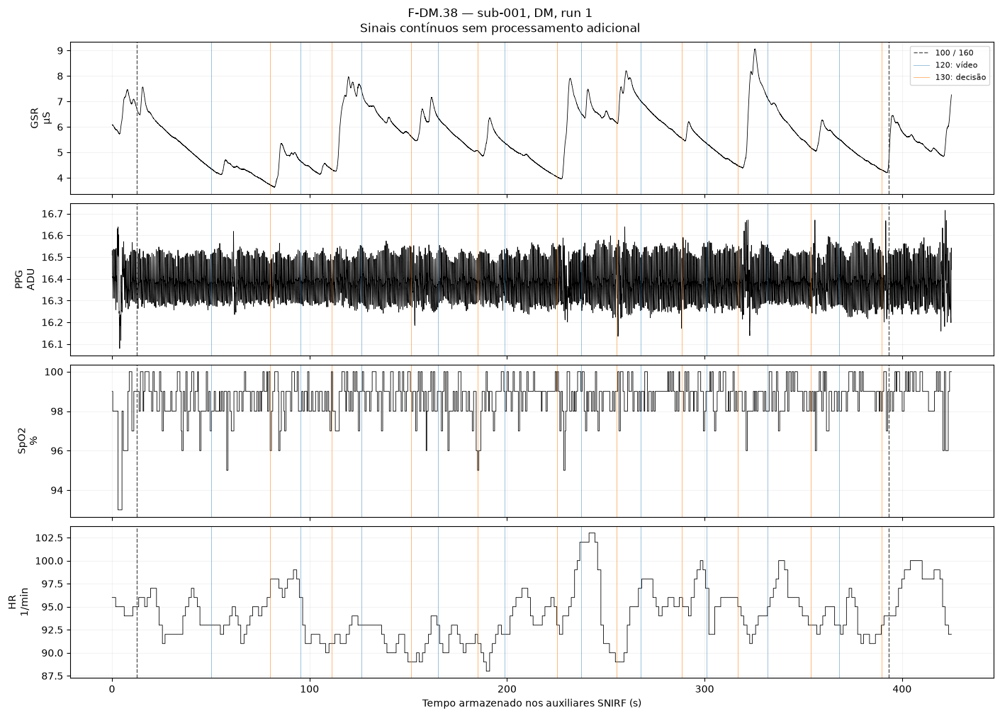

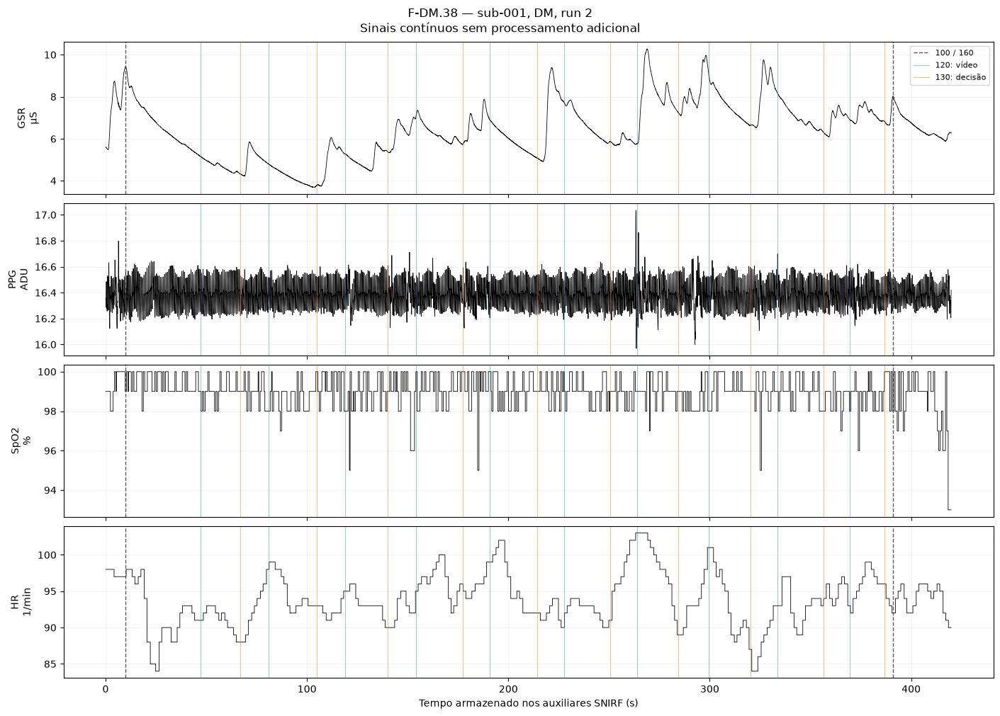

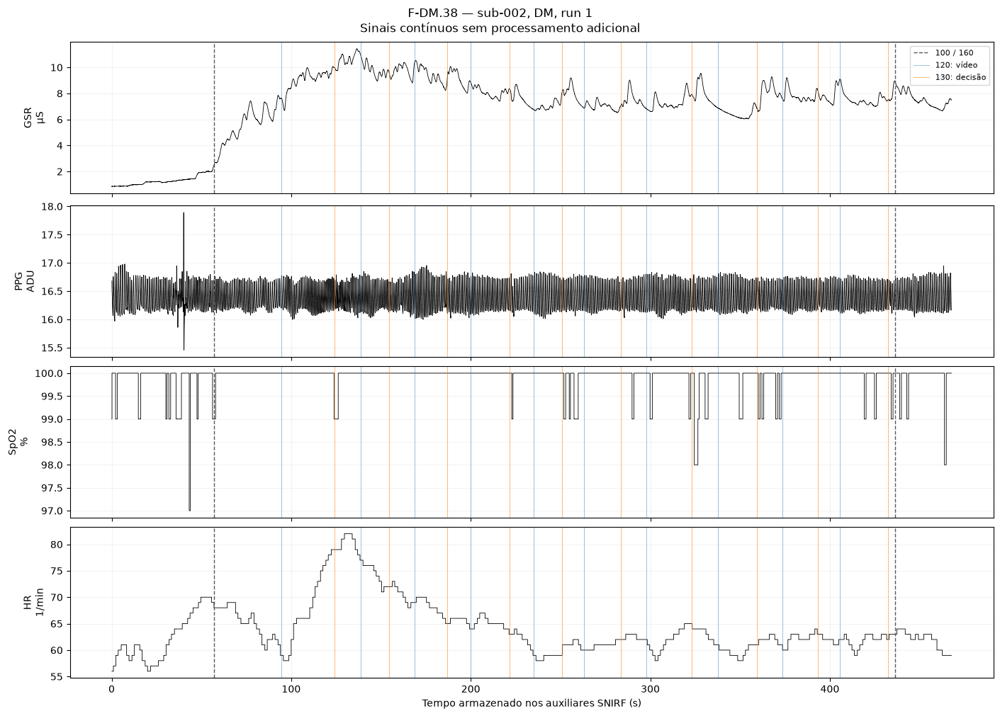

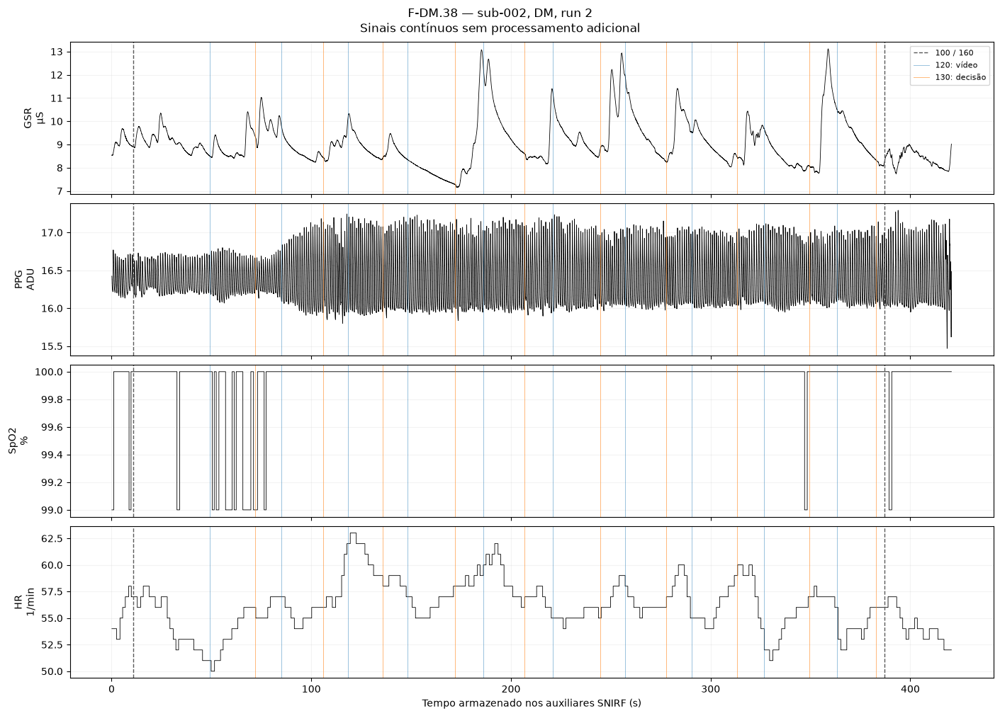

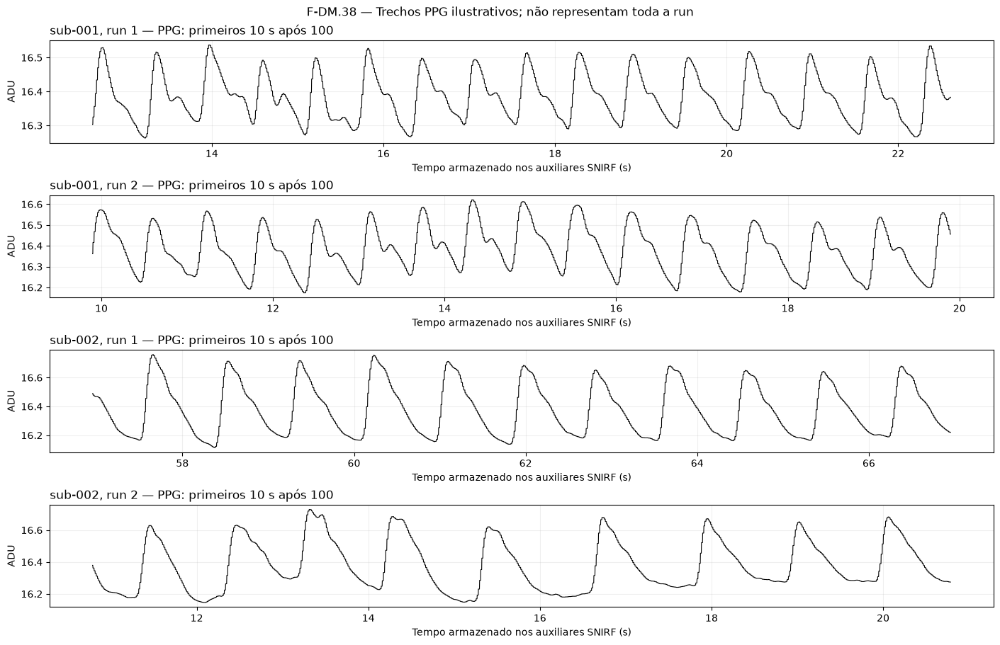


Inspeção descritiva concluída.
Bloco de valor igual: igualdade numérica exata consecutiva.
Span: tempo entre a primeira e a última linha desse bloco.
Estes indicadores não são critérios de exclusão.
Sem releitura, filtro, interpolação, offset, SSR ou GLM.
Nenhum ficheiro escrito.
F-DM.6 e F-DM.36 permanecem inalterados.


In [10]:
# ============================================================
# F-DM.38 — INSPEÇÃO DESCRITIVA DA FISIOLOGIA EM MEMÓRIA
# Sem processamento adicional ou escrita de ficheiros.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def inspecionar_fisiologia_fdm38(auxiliares, eventos):
    esperadas = {
        ("sub-001", 1),
        ("sub-001", 2),
        ("sub-002", 1),
        ("sub-002", 2),
    }
    sinais = ["GSR", "PPG", "SpO2", "HR"]

    if set(auxiliares) != esperadas:
        raise RuntimeError("Esperavam-se as quatro runs do piloto.")

    colunas = {"sujeito", "run", "codigo", "onset_s"}
    if not colunas.issubset(eventos.columns):
        raise RuntimeError("Tabela de eventos sem as colunas necessárias.")

    chaves_eventos = set(
        eventos[["sujeito", "run"]]
        .itertuples(index=False, name=None)
    )
    if chaves_eventos != esperadas:
        raise RuntimeError("Eventos não correspondem às quatro runs.")

    preparados = {}
    linhas = []

    for chave in sorted(esperadas):
        sujeito, run = chave
        ev = eventos.loc[
            eventos["sujeito"].eq(sujeito)
            & eventos["run"].eq(run)
        ].copy()

        ev["codigo"] = ev["codigo"].astype(str)
        ev = ev.sort_values("onset_s")

        inicio = ev.loc[ev["codigo"].eq("100"), "onset_s"]
        fim = ev.loc[ev["codigo"].eq("160"), "onset_s"]

        if len(inicio) != 1 or len(fim) != 1:
            raise RuntimeError(f"{chave}: limites 100–160 não únicos.")

        t100 = float(inicio.iloc[0])
        t160 = float(fim.iloc[0])

        if not np.isfinite([t100, t160]).all() or t100 >= t160:
            raise RuntimeError(f"{chave}: limites temporais inválidos.")

        dados_run = {}

        for sinal in sinais:
            entradas = auxiliares[chave].get(sinal, [])
            if len(entradas) != 1:
                raise RuntimeError(f"{chave}/{sinal}: auxiliar não único.")

            registo = entradas[0]
            t = np.asarray(registo["tempos"], dtype=float)
            x = np.asarray(registo["valores"], dtype=float)

            if (
                registo["unidade_tempo"] != "s"
                or len(t) != len(x)
                or len(t) < 2
                or not np.isfinite(t).all()
                or not np.isfinite(x).all()
                or np.any(np.diff(t) <= 0)
            ):
                raise RuntimeError(f"{chave}/{sinal}: entrada inválida.")

            mascara = (t >= t100) & (t <= t160)
            tt = t[mascara]
            xx = x[mascara]

            if len(xx) < 2:
                raise RuntimeError(
                    f"{chave}/{sinal}: dados insuficientes na tarefa."
                )

            mudancas = np.flatnonzero(xx[1:] != xx[:-1]) + 1
            inicios_blocos = np.r_[0, mudancas]
            fins_blocos = np.r_[mudancas - 1, len(xx) - 1]
            comprimentos = fins_blocos - inicios_blocos + 1
            duracoes_observadas = (
                tt[fins_blocos] - tt[inicios_blocos]
            )
            quantis = np.quantile(xx, [0.01, 0.25, 0.5, 0.75, 0.99])

            linhas.append({
                "sujeito": sujeito,
                "run": run,
                "sinal": sinal,
                "unidade": registo["unidade"],
                "n_linhas_100_160": len(xx),
                "min": float(xx.min()),
                "p01": float(quantis[0]),
                "p25": float(quantis[1]),
                "mediana": float(quantis[2]),
                "p75": float(quantis[3]),
                "p99": float(quantis[4]),
                "max": float(xx.max()),
                "desvio_padrao": float(xx.std(ddof=1)),
                "n_valores_distintos": int(len(np.unique(xx))),
                "pct_transicoes_sem_mudanca": float(
                    100 * np.mean(xx[1:] == xx[:-1])
                ),
                "maior_bloco_valor_igual_n_linhas": int(
                    comprimentos.max()
                ),
                "maior_bloco_valor_igual_span_s": float(
                    duracoes_observadas.max()
                ),
            })

            dados_run[sinal] = {
                "t": t,
                "x": x,
                "unidade": registo["unidade"],
            }

        preparados[chave] = {
            "eventos": ev,
            "t100": t100,
            "t160": t160,
            "sinais": dados_run,
        }

    resumo = pd.DataFrame(linhas)

    print("F-DM.38 — RESUMO DESCRITIVO NO INTERVALO 100–160")
    print(
        resumo.to_string(
            index=False,
            float_format=lambda v: f"{v:.6f}",
        )
    )

    for chave, preparado in sorted(preparados.items()):
        sujeito, run = chave
        ev = preparado["eventos"]
        t100 = preparado["t100"]
        t160 = preparado["t160"]

        fig, eixos = plt.subplots(
            4, 1,
            figsize=(14, 10),
            sharex=True,
            constrained_layout=True,
        )

        for ax, sinal in zip(eixos, sinais):
            dados = preparado["sinais"][sinal]
            t, x = dados["t"], dados["x"]

            ax.plot(
                t, x,
                linewidth=0.6,
                color="black",
                drawstyle=(
                    "steps-post" if sinal in ["HR", "SpO2"]
                    else "default"
                ),
            )

            ax.axvline(
                t100, color="0.35", linestyle="--",
                linewidth=1, label="100 / 160",
            )
            ax.axvline(
                t160, color="0.35", linestyle="--", linewidth=1
            )

            videos = ev.loc[ev["codigo"].eq("120"), "onset_s"]
            decisoes = ev.loc[ev["codigo"].eq("130"), "onset_s"]

            for i, onset in enumerate(videos):
                ax.axvline(
                    onset, color="tab:blue", alpha=0.45,
                    linewidth=0.7,
                    label="120: vídeo" if i == 0 else None,
                )

            for i, onset in enumerate(decisoes):
                ax.axvline(
                    onset, color="tab:orange", alpha=0.55,
                    linewidth=0.7,
                    label="130: decisão" if i == 0 else None,
                )

            ax.set_ylabel(f"{sinal}\n{dados['unidade']}")
            ax.grid(alpha=0.15)

        eixos[0].legend(loc="upper right", fontsize=8)
        eixos[-1].set_xlabel("Tempo armazenado nos auxiliares SNIRF (s)")
        fig.suptitle(
            f"F-DM.38 — {sujeito}, DM, run {run}\n"
            "Sinais contínuos sem processamento adicional"
        )
        plt.show()
        plt.close(fig)

    fig, eixos = plt.subplots(
        4, 1,
        figsize=(14, 9),
        constrained_layout=True,
    )

    for ax, (chave, preparado) in zip(
        eixos, sorted(preparados.items())
    ):
        sujeito, run = chave
        dados = preparado["sinais"]["PPG"]
        inicio = preparado["t100"]
        fim = min(inicio + 10.0, preparado["t160"])
        mascara = (dados["t"] >= inicio) & (dados["t"] <= fim)

        ax.plot(
            dados["t"][mascara],
            dados["x"][mascara],
            color="black",
            linewidth=0.8,
        )
        ax.set_title(
            f"{sujeito}, run {run} — PPG: primeiros 10 s após 100",
            loc="left",
        )
        ax.set_ylabel(dados["unidade"])
        ax.set_xlabel("Tempo armazenado nos auxiliares SNIRF (s)")
        ax.grid(alpha=0.2)

    fig.suptitle(
        "F-DM.38 — Trechos PPG ilustrativos; não representam toda a run"
    )
    plt.show()
    plt.close(fig)

    return resumo


necessarios = {"auxiliares_fdm37a", "df_fdm37c_eventos"}
faltam = necessarios - globals().keys()

if faltam:
    raise RuntimeError(
        f"Faltam entradas em memória: {sorted(faltam)}"
    )

df_fdm38_resumo = inspecionar_fisiologia_fdm38(
    auxiliares_fdm37a,
    df_fdm37c_eventos,
)

print(
    "\nInspeção descritiva concluída."
    "\nBloco de valor igual: igualdade numérica exata consecutiva."
    "\nSpan: tempo entre a primeira e a última linha desse bloco."
    "\nEstes indicadores não são critérios de exclusão."
    "\nSem releitura, filtro, interpolação, offset, SSR ou GLM."
    "\nNenhum ficheiro escrito."
    "\nF-DM.6 e F-DM.36 permanecem inalterados."
)

## F-DM.38 — Conclusão da inspeção descritiva inicial

### Evidência
Foram inspecionados:
- resumo numérico das quatro runs;
- contínuos GSR, PPG, SpO2 e HR das quatro runs;
- trechos PPG de 10 s após o marcador 100.

Os trechos PPG apresentam ciclos discerníveis.
Os contínuos mostram variação, mudanças de amplitude
e transientes pontuais.

### Observações específicas de sub-002
Run 1:
- subida prolongada inicial de GSR;
- transiente PPG aproximado aos 40 s, antes de 100,
  próximo de uma descida SpO2;
- elevação ampla de HR aproximadamente entre 100–170 s;
- SpO2 sobretudo em 100%.

Run 2:
- variação GSR com aumentos e descidas prolongadas;
- mudança de amplitude PPG aproximadamente entre 80–110 s;
- transiente PPG perto do fim, depois de 160;
- HR variável em degraus;
- pouca variação de SpO2.

Os tempos indicados são aproximações visuais,
não limites de rejeição.

### Decisão
- Encerrar a inspeção descritiva inicial.
- Não excluir automaticamente sinais, runs ou participantes.
- Manter GSR e HR como candidatos a preparação adicional.
- Preservar PPG para avaliação específica se necessária.
- Preservar SpO2 como medida complementar, sem inclusão automática.
- Não usar amplitude PPG bruta como regressor já validado.
- Não iniciar deteção de pulsos ou novas explorações
  sem uma necessidade decisória concreta.

### Limites
A inspeção não demonstra:
- ausência de artefactos;
- validade fisiológica de cada variação;
- sincronização independente;
- adequação dos sinais como regressores do GLM.

### Próximo passo
Definir a especificação da sensibilidade fisiológica,
recuperando primeiro o processamento de GSR/HR
já documentado e distinguindo épocas de GLM contínuo.

Nenhum ajuste ou processamento adicional autorizado nesta conclusão.
F-DM.6 e F-DM.36 permanecem inalterados.

In [1]:
# F-DM.38: inspeção descritiva inicial concluída.
# Nenhuma nova execução necessária nesta conclusão.
# Não aplicar filtros, correções, exclusões ou ajustes.
# A especificação da sensibilidade fisiológica é o próximo passo.

## F-DM.39 — Especificação da preparação fisiológica
### F-DM.39A — Recuperação documental e delimitação

### Objetivo
Definir a preparação de GSR e HR para uma sensibilidade
do GLM contínuo, sem copiar automaticamente a preparação
destinada às épocas.

### Processamento histórico recuperado
Fonte: 3.a_task_dm_single_subject_preprocess.pdf,
Passo 16, páginas 85–90.

- Fonte: auxiliares SNIRF.
- Grelha uniforme com passo mediano dos tempos originais.
- Origem temporal preservada; sem extrapolação.
- GSR: interpolação linear e passa-baixo Butterworth
  de ordem 4 a 5 Hz, SOS, nos dois sentidos.
- HR: última observação disponível, sem suavização adicional.
- PPG e SpO2 preservados, não preparados nessa etapa.
- Filtro GSR explicitamente ainda em validação.
- Inclusão no GLM não aprovada pelo processamento histórico.

### Delimitação atual
- GSR e HR são candidatos à primeira sensibilidade.
- Não aplicar baseline por tentativa.
- Não aplicar decomposição tónica/fásica.
- Não incluir automaticamente PPG ou SpO2.
- Não aplicar offsets ou extrapolação.
- Não adotar automaticamente o filtro histórico de 5 Hz.

### Próxima subetapa
Fechar o tratamento temporal de GSR e a representação
de GSR/HR na grelha do GLM.

Depois, auditar as colunas candidatas e a matriz aumentada
antes de qualquer ajuste:
- cobertura;
- finitude e variância;
- correlações;
- posto;
- condicionamento.

### Estado
Recuperação documental concluída.
Especificação temporal ainda por fechar.
Nenhum sinal transformado e nenhum GLM reajustado.
F-DM.6 e F-DM.36 permanecem inalterados.
Sem combinação de runs, lote ou inferência de grupo.

### F-DM.39B — Identificação das entradas por nome e estrutura

### Motivo
A pesquisa pelos números 36, 37 e 38 não encontrou objetos.
Esse resultado não demonstra ausência das entradas em memória.

### Objetivo
Localizar os objetos existentes relacionados com:
- auxiliares fisiológicos SNIRF;
- GSR e HR;
- desenhos do GLM;
- resultados e configuração da referência atual.

### Procedimento
Pesquisar nomes de variáveis por termos relacionados com
essas entradas e apresentar apenas metadados superficiais.

Não apresentar os valores dos sinais ou executar funções
guardadas nos objetos.

### Limites
Não ler ficheiros, reconstruir matrizes, transformar sinais,
ajustar modelos ou escrever ficheiros.

### Resultado esperado
Identificar os objetos candidatos e os seus campos.
A escolha das entradas será explícita após analisar o output.

F-DM.6 e os resultados de F-DM.36 permanecem inalterados.

In [3]:
import re
from collections.abc import Mapping

def resumo_entrada_dm39(obj):
    info = {"tipo": type(obj).__name__}

    if hasattr(obj, "shape"):
        info["shape"] = tuple(obj.shape)

    if hasattr(obj, "columns"):
        info["colunas"] = list(obj.columns)

    if isinstance(obj, Mapping):
        chaves = list(obj.keys())
        info["n_chaves"] = len(chaves)
        info["chaves_iniciais"] = chaves[:6]

        if chaves:
            primeiro = obj[chaves[0]]
            info["tipo_primeiro_valor"] = type(primeiro).__name__

            if isinstance(primeiro, Mapping):
                campos = list(primeiro.keys())
                info["campos_primeiro_valor"] = campos

                info["estrutura_campos"] = {
                    str(campo): {
                        "tipo": type(primeiro[campo]).__name__,
                        **(
                            {"shape": tuple(primeiro[campo].shape)}
                            if hasattr(primeiro[campo], "shape")
                            else {}
                        ),
                    }
                    for campo in campos[:12]
                }

            elif hasattr(primeiro, "columns"):
                info["colunas_primeiro_valor"] = list(primeiro.columns)

            elif hasattr(primeiro, "shape"):
                info["shape_primeiro_valor"] = tuple(primeiro.shape)

    return info

padrao_entradas_dm39 = re.compile(
    r"aux|fisio|gsr|(^|_)hr($|_)|snirf|"
    r"matriz|matric|design|desenh|glm|"
    r"ajust|refer|cos|deriva",
    re.IGNORECASE,
)

entradas_candidatas_dm39 = [
    (nome, obj)
    for nome, obj in list(globals().items())
    if not nome.startswith("_")
    and not nome.endswith("dm39")
    and padrao_entradas_dm39.search(nome)
    and not callable(obj)
    and (
        isinstance(obj, Mapping)
        or hasattr(obj, "shape")
        or isinstance(obj, (list, tuple))
    )
]

for nome, obj in sorted(entradas_candidatas_dm39, key=lambda item: item[0]):
    print(f"\n{nome}")
    print(resumo_entrada_dm39(obj))

if not entradas_candidatas_dm39:
    print(
        "Nenhum candidato identificado por nome. "
        "Consultar as linhas que criam os auxiliares SNIRF "
        "e as entradas do ajuste de F-DM.36; não reexecutar etapas."
    )

Nenhum candidato identificado por nome. Consultar as linhas que criam os auxiliares SNIRF e as entradas do ajuste de F-DM.36; não reexecutar etapas.


### F-DM.39B — Pausa técnica para identificar as entradas

### Estado
As duas pesquisas por nomes não identificaram os objetos
necessários à preparação fisiológica.

Esse resultado não demonstra que os dados ou os resultados
anteriores estejam perdidos.

### Informação necessária
Consultar o código já existente e recuperar:

1. A célula de F-DM.37 que disponibiliza os auxiliares SNIRF:
   nomes dos objetos, campos de tempos/valores e chaves das runs.

2. As linhas de F-DM.36 que identificam:
   - o sinal fNIRS usado;
   - a matriz de referência com deriva cosine;
   - a configuração e a função do ajuste.

3. As linhas de F-DM.38 que acedem aos auxiliares
   para produzir as figuras, caso sejam mais fáceis de localizar.

### Procedimento
Copiar o código existente, sem o executar.

Não é necessário enviar valores dos sinais, figuras repetidas
ou todos os resultados numéricos.

### Limites
Não reconstruir matrizes, recuperar objetos por tentativa,
repetir ajustes ou aplicar processamento fisiológico.

### Critério de continuação
Escrever a preparação apenas depois de identificar
explicitamente as entradas e a sua estrutura.

F-DM.39B permanece pendente.
F-DM.6 e os resultados de F-DM.36 permanecem inalterados.

In [4]:
# Não executar novas pesquisas ou processamento nesta pausa.
# Copiar, sem executar, as linhas existentes que identificam:
# 1. os auxiliares SNIRF de F-DM.37 ou usados em F-DM.38;
# 2. o sinal e a matriz de referência usados em F-DM.36.

### F-DM.39B — Verificação direta das entradas identificadas

### Entradas fisiológicas identificadas
O código de F-DM.38 utiliza:
- auxiliares_fdm37a;
- df_fdm37c_eventos.

Estrutura dos auxiliares:
- chave: (sujeito, run);
- sinal: GSR, PPG, SpO2 ou HR;
- uma lista com um único registo por sinal;
- campos: tempos, valores, unidade_tempo e unidade.

### Objetivo
Confirmar que estas entradas estão disponíveis na sessão atual
e identificar as tabelas disponíveis no checkpoint de F-DM.32.

### Procedimento
Verificar nomes exatos e apresentar apenas:
- disponibilidade;
- tipo;
- chaves das runs;
- colunas da tabela de eventos;
- nomes das tabelas do checkpoint.

### Limites
Não ler ficheiros.
Não apresentar valores dos sinais.
Não repetir F-DM.38.
Não aplicar filtros, interpolação, offsets ou exclusões.
Não reconstruir o desenho nem ajustar modelos.

### Continuação
Se os auxiliares estiverem disponíveis, preservar esses objetos.

A preparação para a grelha fNIRS só será escrita depois de
identificar a matriz de referência e o seu eixo temporal.

F-DM.6 e os resultados de F-DM.36 permanecem inalterados.

In [5]:
from collections.abc import Mapping

nomes_entradas_dm39 = (
    "auxiliares_fdm37a",
    "df_fdm37c_eventos",
    "tabelas_checkpoint_fdm32",
)

for nome in nomes_entradas_dm39:
    presente = nome in globals()
    print(f"\n{nome}: {'presente' if presente else 'ausente'}")

    if not presente:
        continue

    obj = globals()[nome]
    print("Tipo:", type(obj).__name__)

    if nome == "auxiliares_fdm37a" and isinstance(obj, Mapping):
        print("Runs:", list(obj.keys()))
        for chave, dados in obj.items():
            print(chave, "— sinais:", list(dados.keys()))

    elif nome == "df_fdm37c_eventos" and hasattr(obj, "columns"):
        print("Dimensões:", obj.shape)
        print("Colunas:", list(obj.columns))

    elif nome == "tabelas_checkpoint_fdm32" and isinstance(obj, Mapping):
        print("Tabelas disponíveis:")
        for chave in obj:
            print(" -", chave)

print("\nVerificação direta concluída. Nenhum processamento realizado.")


auxiliares_fdm37a: ausente

df_fdm37c_eventos: ausente

tabelas_checkpoint_fdm32: ausente

Verificação direta concluída. Nenhum processamento realizado.


### F-DM.39B — Identificar a grelha dos desenhos guardados

### Evidência
O checkpoint de F-DM.32 foi recuperado com sucesso.

Inclui:
- os quatro desenhos de F-DM.2;
- a tabela de recuperação de F-DM.0;
- a configuração do desenho e do ajuste;
- os resultados e diagnósticos existentes.

Presença, tamanho, contagem de linhas e leitura passaram
face ao registo fornecido.

Essa verificação não demonstra identidade por hashes.

### Objetivo
Identificar:
1. As colunas e a representação temporal dos desenhos guardados.
2. As origens registadas no checkpoint.
3. Os campos da tabela de recuperação que permitem localizar
   os ficheiros da referência.

### Procedimento
Consultar apenas os objetos recuperados em memória.
Apresentar as configurações, as origens e duas linhas
de cada desenho.

### Limites
Não reler ficheiros.
Não reconstruir desenhos.
Não carregar sinais fNIRS ou auxiliares nesta célula.
Não repetir F-DM.36 ou F-DM.38.
Não aplicar filtros, interpolação, offsets ou ajustes.

### Próxima dependência
Recuperar os auxiliares SNIRF através do código existente
de F-DM.37A e identificar a origem de df_fdm37c_eventos.

F-DM.6 e os resultados de F-DM.36 permanecem inalterados.

### F-DM.39B — Consulta do checkpoint recuperado

### Estado
A recuperação de F-DM.32 já foi executada.

### Objetivo
Identificar, nos objetos recuperados:
- as origens dos dados;
- os caminhos registados na tabela de recuperação;
- as colunas e a representação temporal dos quatro desenhos;
- a configuração de referência.

### Procedimento
Consultar apenas as tabelas e o JSON em memória.

### Limites
Não repetir F-DM.32.
Não carregar SNIRF ou sinais fNIRS.
Não reconstruir desenhos.
Não aplicar processamento ou ajustar modelos.
Não escrever ficheiros.

### Resultado esperado
Obter as informações concretas para ligar os auxiliares SNIRF
à grelha do desenho guardado.

F-DM.6 e os resultados de F-DM.36 permanecem inalterados.

In [8]:
import json
from collections.abc import Mapping

tabelas_dm39 = globals().get("tabelas_checkpoint_fdm32")
config_dm39 = globals().get("configuracao_checkpoint_fdm32")

if not isinstance(tabelas_dm39, Mapping):
    raise RuntimeError(
        "O checkpoint não está visível neste kernel. "
        "Confirma que esta célula está no mesmo notebook/kernel "
        "onde acabaste de executar F-DM.32; não a repitas ainda."
    )

if not isinstance(config_dm39, Mapping):
    raise RuntimeError("Configuração do checkpoint ausente neste kernel.")

runs_dm39 = (
    ("sub-001", 1),
    ("sub-001", 2),
    ("sub-002", 1),
    ("sub-002", 2),
)

nomes_dm39 = [
    "df_fdm0_recuperacao.csv",
    *[
        f"desenhos_fdm2_{sujeito}_run-{run}.csv"
        for sujeito, run in runs_dm39
    ],
]

faltam_dm39 = [nome for nome in nomes_dm39 if nome not in tabelas_dm39]
if faltam_dm39:
    raise RuntimeError(f"Tabelas necessárias ausentes: {faltam_dm39}")

for campo in ("origens", "config_desenho", "config_ajuste"):
    print(f"\n{campo.upper()}")
    print(
        json.dumps(
            config_dm39.get(campo),
            ensure_ascii=False,
            indent=2,
            default=str,
        )
    )

print("\nRECUPERAÇÃO F-DM.0")
print(tabelas_dm39["df_fdm0_recuperacao.csv"].to_string(index=False))

for sujeito, run in runs_dm39:
    nome = f"desenhos_fdm2_{sujeito}_run-{run}.csv"
    desenho = tabelas_dm39[nome]

    print(f"\n{nome}")
    print("Dimensões:", desenho.shape)
    print("Colunas:", desenho.columns.tolist())
    print("Primeira linha:")
    print(desenho.head(1).to_string(index=False))
    print("Última linha:")
    print(desenho.tail(1).to_string(index=False))

print("\nConsulta em memória concluída. Nenhum processamento realizado.")


ORIGENS
[
  {
    "sujeito": "sub-001",
    "run": 1,
    "ficheiro": "C:\\Users\\guilh\\Desktop\\OneDrive - Universidade de Coimbra\\PhD_Project_ARDITI_Guilherme Saldanha\\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\\sub-001\\fNIRS_epochs_derivatives\\pilot_dm_epochs_v01\\sub-001_ses-01_tk-dm_run-1_nirs_001\\sub-001_ses-01_tk-dm_run-1_nirs_001_haemo_unfiltered_raw.fif"
  },
  {
    "sujeito": "sub-001",
    "run": 2,
    "ficheiro": "C:\\Users\\guilh\\Desktop\\OneDrive - Universidade de Coimbra\\PhD_Project_ARDITI_Guilherme Saldanha\\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\\sub-001\\fNIRS_epochs_derivatives\\pilot_dm_epochs_v01\\sub-001_ses-01_tk-dm_run-2_nirs_001\\sub-001_ses-01_tk-dm_run-2_nirs_001_haemo_unfiltered_raw.fif"
  },
  {
    "sujeito": "sub-002",
    "run": 1,
    "ficheiro": "C:\\Users\\guilh\\Desktop\\OneDrive - Universidade de Coimbra\\PhD_Project_ARDITI_Guilherme Saldanha\\Study2_Data Collection Files_PhD_Guilherme Saldanha_

### F-DM.39B.1 — Localizar os SNIRF das quatro runs do piloto

### Evidência confirmada
O checkpoint contém os desenhos de referência.

- `tempo_s` representa o eixo temporal, não um regressor.
- Preservar a ordem e os valores das restantes colunas.
- Preservar os termos de deriva guardados.
- Não reconstruir a matriz.

As origens registadas apontam para derivados
`haemo_unfiltered_raw.fif`, não para os SNIRF originais.

### Objetivo
Localizar os quatro SNIRF necessários à recuperação
dos auxiliares fisiológicos.

### Procedimento
A partir da pasta do estudo indicada pelo checkpoint:
- considerar apenas sub-001 e sub-002;
- considerar apenas as runs DM 1 e 2;
- procurar nas duas localizações de aquisição:
  pasta da run diretamente no participante ou dentro de `nirs`;
- exigir um único SNIRF com o identificador exato da gravação.

Não procurar dentro de derivados ou em toda a amostra.

### Limites
Não abrir SNIRF ou FIF.
Não carregar sinais.
Não aplicar filtros, interpolação ou offsets.
Não ajustar o GLM.
Não escrever ficheiros.

### Resultado esperado
Um dicionário de caminhos SNIRF com as quatro runs.

Se houver ausência ou ambiguidade, apresentar os candidatos
e parar sem selecionar automaticamente.

F-DM.6 e os resultados de F-DM.36 permanecem inalterados.

In [9]:
from pathlib import Path
from collections.abc import Mapping
import pandas as pd

checkpoint_dm39 = globals().get("tabelas_checkpoint_fdm32")
if not isinstance(checkpoint_dm39, Mapping):
    raise RuntimeError("Checkpoint ausente neste kernel.")

recuperacao_dm39 = checkpoint_dm39[
    "df_fdm0_recuperacao.csv"
].copy()

esperadas_dm39 = {
    ("sub-001", 1),
    ("sub-001", 2),
    ("sub-002", 1),
    ("sub-002", 2),
}

if (
    len(recuperacao_dm39) != 4
    or recuperacao_dm39.duplicated(["sujeito", "run"]).any()
    or set(
        recuperacao_dm39[["sujeito", "run"]]
        .itertuples(index=False, name=None)
    ) != esperadas_dm39
):
    raise RuntimeError("Tabela de recuperação diferente do piloto esperado.")

caminhos_candidatos_dm39 = {}
registos_localizacao_dm39 = []

for linha in recuperacao_dm39.itertuples(index=False):
    chave = (linha.sujeito, int(linha.run))
    fif = Path(linha.ficheiro)
    sufixo = "_haemo_unfiltered_raw.fif"

    if not fif.name.endswith(sufixo):
        raise RuntimeError(f"{chave}: sufixo FIF inesperado.")

    gravacao = fif.name[:-len(sufixo)]

    pastas_participante = [
        pasta
        for pasta in fif.parents
        if pasta.name == linha.sujeito
    ]
    if len(pastas_participante) != 1:
        raise RuntimeError(f"{chave}: pasta do participante não única.")

    participante = pastas_participante[0]
    pastas_aquisicao = (
        participante / gravacao,
        participante / "nirs" / gravacao,
    )

    candidatos = sorted({
        caminho.resolve()
        for pasta in pastas_aquisicao
        if pasta.is_dir()
        for caminho in pasta.iterdir()
        if caminho.is_file()
        and caminho.suffix.lower() == ".snirf"
        and caminho.stem == gravacao
    })

    caminhos_candidatos_dm39[chave] = candidatos

    registos_localizacao_dm39.append({
        "sujeito": chave[0],
        "run": chave[1],
        "n_snيرf": len(candidatos),
        "pastas_verificadas": " | ".join(map(str, pastas_aquisicao)),
        "candidatos": " | ".join(map(str, candidatos)),
    })

df_localizacao_dm39 = pd.DataFrame(registos_localizacao_dm39)
df_localizacao_dm39 = df_localizacao_dm39.rename(
    columns={"n_snيرf": "n_snirf"}
)
print(df_localizacao_dm39.to_string(index=False))

if any(len(c) != 1 for c in caminhos_candidatos_dm39.values()):
    raise RuntimeError(
        "Há SNIRF ausentes ou ambíguos nas localizações delimitadas. "
        "Não foi selecionado um conjunto de caminhos. "
        "Usar os caminhos explícitos da leitura original de F-DM.37A."
    )

snirfs_dm39 = {
    chave: candidatos[0]
    for chave, candidatos in caminhos_candidatos_dm39.items()
}

print(
    "\nQuatro caminhos SNIRF únicos localizados."
    "\nObjeto: snirfs_dm39."
    "\nNenhum SNIRF/FIF aberto, sinal carregado ou ficheiro escrito."
)

sujeito  run  n_snirf                                                                                                                                                                                                                                                                                                                                                                                                           pastas_verificadas                                                                                                                                                                                                                                                candidatos
sub-001    1        1 C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\sub-001_ses-01_tk-dm_run-1_nirs_001 | C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme S

### F-DM.39B.2 — Recuperação de GSR/HR e cobertura do desenho

### Objetivo
Recuperar GSR e HR dos quatro SNIRF identificados e verificar
a cobertura dos tempos guardados nos desenhos de referência.

### Entradas
- snirfs_dm39: quatro caminhos únicos;
- tabelas_checkpoint_fdm32: desenhos guardados de F-DM.2.

### Procedimento
- Abrir cada SNIRF apenas para ler os auxiliares necessários.
- Identificar GSR e Heartrate pelo campo name.
- Exigir um único auxiliar por sinal.
- Conferir unidades, timeOffset, dimensões e finitude.
- Exigir tempos estritamente crescentes.
- Preservar tempos e valores originais.
- Comparar a cobertura dos auxiliares com tempo_s do desenho.
- Registar a máscara comum de cobertura GSR/HR.

### Limites
Não aplicar offsets, cortes, filtros ou interpolação.
Não carregar sinais fNIRS.
Não modificar os desenhos.
Não repetir figuras ou ajustes.
Não escrever ficheiros.

A máscara de cobertura é diagnóstica.
Não é aplicada ao desenho nesta etapa.

### Saídas
- auxiliares_dm39: GSR/HR originais por run;
- cobertura_dm39: máscaras de cobertura por run;
- df_cobertura_dm39: resumo da recuperação e cobertura.

### Continuação
Analisar a cobertura antes de preparar as séries.
A coerência temporal interna não valida latências dos sensores.

F-DM.6 e os resultados de F-DM.36 permanecem inalterados.

In [10]:
import h5py
import numpy as np
import pandas as pd
from collections.abc import Mapping

def texto_dm39(dataset):
    valor = np.asarray(dataset[()]).reshape(-1)
    if valor.size != 1:
        raise RuntimeError("Campo textual não escalar.")
    item = valor[0]
    return item.decode("utf-8") if isinstance(item, bytes) else str(item)

def recuperar_auxiliares_dm39(caminhos, tabelas):
    esperadas = {
        ("sub-001", 1), ("sub-001", 2),
        ("sub-002", 1), ("sub-002", 2),
    }
    if set(caminhos) != esperadas:
        raise RuntimeError("Esperavam-se as quatro runs do piloto.")

    mapa = {"GSR": "GSR", "Heartrate": "HR"}
    recuperados, coberturas, linhas = {}, {}, []

    for chave in sorted(esperadas):
        sujeito, run = chave
        nome_desenho = f"desenhos_fdm2_{sujeito}_run-{run}.csv"
        if nome_desenho not in tabelas:
            raise RuntimeError(f"Desenho ausente: {nome_desenho}")

        desenho = tabelas[nome_desenho]
        if "tempo_s" not in desenho.columns:
            raise RuntimeError(f"{chave}: falta tempo_s.")

        tg = desenho["tempo_s"].to_numpy(dtype=float)
        if (
            len(tg) < 2
            or not np.isfinite(tg).all()
            or np.any(np.diff(tg) <= 0)
        ):
            raise RuntimeError(f"{chave}: grelha do desenho inválida.")

        dados = {}
        with h5py.File(caminhos[chave], "r") as ficheiro:
            grupos = [
                g for nome, g in ficheiro.items()
                if nome.startswith("nirs") and isinstance(g, h5py.Group)
            ]
            if len(grupos) != 1:
                raise RuntimeError(f"{chave}: grupo NIRS não único.")

            nirs = grupos[0]
            if texto_dm39(nirs["metaDataTags"]["TimeUnit"]) != "s":
                raise RuntimeError(f"{chave}: unidade temporal diferente de s.")

            for nome, grupo in nirs.items():
                if (
                    not nome.startswith("aux")
                    or not isinstance(grupo, h5py.Group)
                    or "name" not in grupo
                ):
                    continue

                nome_original = texto_dm39(grupo["name"])
                if nome_original not in mapa:
                    continue

                sinal = mapa[nome_original]
                if sinal in dados:
                    raise RuntimeError(f"{chave}/{sinal}: auxiliar duplicado.")

                x = np.asarray(grupo["dataTimeSeries"][()], dtype=float)
                if x.ndim == 2 and x.shape[1] == 1:
                    x = x[:, 0]
                elif x.ndim != 1:
                    raise RuntimeError(f"{chave}/{sinal}: dimensões inesperadas.")

                t = np.asarray(grupo["time"][()], dtype=float).reshape(-1)
                if len(t) == 2 and len(x) != 2:
                    if not np.isfinite(t).all() or t[1] <= 0:
                        raise RuntimeError(f"{chave}/{sinal}: tempo compacto inválido.")
                    t = t[0] + np.arange(len(x)) * t[1]

                if (
                    len(t) != len(x)
                    or len(t) < 2
                    or not np.isfinite(t).all()
                    or not np.isfinite(x).all()
                    or np.any(np.diff(t) <= 0)
                ):
                    raise RuntimeError(f"{chave}/{sinal}: tempos/valores inválidos.")

                estado_offset = "ausente"
                if "timeOffset" in grupo:
                    offset = np.asarray(
                        grupo["timeOffset"][()], dtype=float
                    ).reshape(-1)
                    if (
                        offset.size != 1
                        or not np.isfinite(offset).all()
                        or offset[0] != 0
                    ):
                        raise RuntimeError(
                            f"{chave}/{sinal}: timeOffset requer interpretação."
                        )
                    estado_offset = "presente e nulo"

                if "dataUnit" not in grupo:
                    raise RuntimeError(f"{chave}/{sinal}: unidade ausente.")

                unidade = texto_dm39(grupo["dataUnit"])
                if not unidade.strip():
                    raise RuntimeError(f"{chave}/{sinal}: unidade vazia.")

                dados[sinal] = {
                    "tempos": t,
                    "valores": x,
                    "unidade": unidade,
                    "unidade_tempo": "s",
                    "timeOffset": estado_offset,
                    "grupo": grupo.name,
                    "ficheiro": str(caminhos[chave]),
                }

        if set(dados) != {"GSR", "HR"}:
            raise RuntimeError(f"{chave}: falta GSR ou Heartrate.")

        mascaras = {
            sinal: (tg >= reg["tempos"][0]) & (tg <= reg["tempos"][-1])
            for sinal, reg in dados.items()
        }
        comum = mascaras["GSR"] & mascaras["HR"]
        if comum.sum() < 2:
            raise RuntimeError(f"{chave}: cobertura comum insuficiente.")

        coberturas[chave] = {
            "tempo_s": tg.copy(),
            "GSR": mascaras["GSR"],
            "HR": mascaras["HR"],
            "comum": comum,
        }
        recuperados[chave] = dados

        for sinal, reg in dados.items():
            t = reg["tempos"]
            dt = np.diff(t)
            linhas.append({
                "sujeito": sujeito,
                "run": run,
                "sinal": sinal,
                "unidade": reg["unidade"],
                "n_aux": len(t),
                "inicio_aux_s": t[0],
                "fim_aux_s": t[-1],
                "dt_mediano_s": np.median(dt),
                "dt_max_s": dt.max(),
                "n_intervalos_gt_1p5_mediana": int(
                    (dt > 1.5 * np.median(dt)).sum()
                ),
                "n_desenho": len(tg),
                "n_cobertas": int(mascaras[sinal].sum()),
                "n_antes_cobertura": int((tg < t[0]).sum()),
                "n_depois_cobertura": int((tg > t[-1]).sum()),
                "n_cobertura_comum": int(comum.sum()),
                "timeOffset": reg["timeOffset"],
            })

    return recuperados, coberturas, pd.DataFrame(linhas)

if not isinstance(globals().get("snirfs_dm39"), Mapping):
    raise RuntimeError("snirfs_dm39 ausente ou inválido.")

if not isinstance(globals().get("tabelas_checkpoint_fdm32"), Mapping):
    raise RuntimeError("Checkpoint ausente ou inválido.")

auxiliares_dm39, cobertura_dm39, df_cobertura_dm39 = (
    recuperar_auxiliares_dm39(
        snirfs_dm39,
        tabelas_checkpoint_fdm32,
    )
)

print(
    df_cobertura_dm39.to_string(
        index=False,
        float_format=lambda v: f"{v:.9f}",
    )
)
print(
    "\nGSR/HR recuperados nos tempos originais."
    "\nMáscaras de cobertura apenas registadas, não aplicadas."
    "\nSem filtro, interpolação, offset, figuras ou GLM."
    "\nNenhum ficheiro escrito."
)

sujeito  run sinal unidade  n_aux  inicio_aux_s     fim_aux_s  dt_mediano_s    dt_max_s  n_intervalos_gt_1p5_mediana  n_desenho  n_cobertas  n_antes_cobertura  n_depois_cobertura  n_cobertura_comum timeOffset
sub-001    1    HR   1/min 212447   0.086246400 424.970940500   0.002000000 0.002076000                            0       4323        4322                  1                   0               4322    ausente
sub-001    1   GSR      µS 212447   0.086246400 424.970940500   0.002000000 0.002076000                            0       4323        4322                  1                   0               4322    ausente
sub-001    2    HR   1/min 209884   0.090021700 419.849698800   0.002000000 0.002162100                            0       4271        4270                  1                   0               4270    ausente
sub-001    2   GSR      µS 209884   0.090021700 419.849698800   0.002000000 0.002162100                            0       4271        4270                  1      

### F-DM.39B.3 — Preparação temporal de GSR e HR

### Evidência anterior
GSR e HR foram recuperados com unidades explícitas,
valores finitos e tempos estritamente crescentes.

Não foram encontrados intervalos superiores a
1.5 vezes o intervalo mediano.

A cobertura original deixa de fora:
- uma amostra inicial em cada run de sub-001;
- duas amostras iniciais em cada run de sub-002.

Não existem amostras finais fora da cobertura original.

### Objetivo
Preparar representações contínuas de GSR e HR alinhadas
aos tempos guardados no desenho, sem ajustar o GLM.

### GSR
- Regularização linear numa grelha uniforme com passo mediano.
- Origem temporal preservada.
- Reamostragem polifásica com antialiasing FIR.
- Grelha intermédia próxima de duas vezes a frequência do desenho.
- Alinhamento linear aos tempos exatos do desenho apenas
  dentro da cobertura das grelhas original e intermédia.
- Sem Butterworth adicional, passa-alto ou decomposição tónica/fásica.

### HR
Transportar a última observação disponível para cada
tempo retido do desenho, sem suavização adicional.

### Cobertura
Não extrapolar nem preencher com zeros.

A máscara final considera a cobertura original e a cobertura
da representação GSR reamostrada.

Registar qualquer amostra adicional não coberta.
A máscara será comum à referência e ao modelo aumentado
num eventual ajuste posterior.

### Saídas
- preparados_dm39: séries preparadas, máscara e cópia do desenho;
- df_preparacao_dm39: parâmetros e cobertura por run.

### Limites
Sem baseline por tentativa ou padronização nesta célula.
Sem alteração dos auxiliares e desenhos originais.
Sem novas figuras, ajustes ou escrita de ficheiros.

A preparação temporal não valida qualidade fisiológica,
latências dos sensores ou adequação como regressores.

F-DM.6 e os resultados de F-DM.36 permanecem inalterados.

In [11]:
from fractions import Fraction
import numpy as np
import pandas as pd
from scipy.signal import resample_poly

def preparar_fisiologia_dm39(auxiliares, tabelas, coberturas):
    esperadas = {
        ("sub-001", 1), ("sub-001", 2),
        ("sub-002", 1), ("sub-002", 2),
    }
    if set(auxiliares) != esperadas or set(coberturas) != esperadas:
        raise RuntimeError("Entradas diferentes das quatro runs esperadas.")

    preparados, resumo = {}, []

    for chave in sorted(esperadas):
        sujeito, run = chave
        original = tabelas[
            f"desenhos_fdm2_{sujeito}_run-{run}.csv"
        ]
        tg = original["tempo_s"].to_numpy(dtype=float)
        dtg = np.diff(tg)

        if (
            not np.isfinite(tg).all()
            or np.any(dtg <= 0)
            or not np.allclose(
                dtg, np.median(dtg), rtol=1e-6, atol=1e-9
            )
        ):
            raise RuntimeError(f"{chave}: desenho sem grelha uniforme.")

        if not np.array_equal(tg, coberturas[chave]["tempo_s"]):
            raise RuntimeError(f"{chave}: grelha diferente da cobertura auditada.")

        gsr = auxiliares[chave]["GSR"]
        hr = auxiliares[chave]["HR"]
        t = np.asarray(gsr["tempos"], dtype=float)
        x = np.asarray(gsr["valores"], dtype=float)
        th = np.asarray(hr["tempos"], dtype=float)
        xh = np.asarray(hr["valores"], dtype=float)

        for sinal, ts, xs in (("GSR", t, x), ("HR", th, xh)):
            if (
                ts.ndim != 1 or xs.ndim != 1
                or len(ts) != len(xs) or len(ts) < 2
                or not np.isfinite(ts).all()
                or not np.isfinite(xs).all()
                or np.any(np.diff(ts) <= 0)
            ):
                raise RuntimeError(f"{chave}/{sinal}: entrada inválida.")

        dt = float(np.median(np.diff(t)))
        if np.any(np.diff(t) > 1.5 * dt):
            raise RuntimeError(f"{chave}: lacuna GSR requer revisão.")

        fs_aux = 1.0 / dt
        fs_desenho = 1.0 / float(np.median(dtg))
        n_uniforme = int(np.floor((t[-1] - t[0]) / dt)) + 1
        tu = t[0] + np.arange(n_uniforme) * dt
        tu = tu[tu <= t[-1]]
        xu = np.interp(tu, t, x)

        razao = Fraction(
            2.0 * fs_desenho / fs_aux
        ).limit_denominator(10000)
        up, down = razao.numerator, razao.denominator
        fs_intermedia = fs_aux * up / down

        xr = resample_poly(
            xu,
            up=up,
            down=down,
            window=("kaiser", 5.0),
            padtype="line",
        )
        tr = tu[0] + np.arange(len(xr)) / fs_intermedia

        dentro_uniforme = tr <= tu[-1]
        tr, xr = tr[dentro_uniforme], xr[dentro_uniforme]

        if len(tr) < 2 or not np.isfinite(xr).all():
            raise RuntimeError(f"{chave}: reamostragem GSR inválida.")

        cobertura_original = np.asarray(
            coberturas[chave]["comum"], dtype=bool
        )
        mascara = (
            cobertura_original
            & (tg >= tr[0])
            & (tg <= tr[-1])
        )
        if mascara.sum() < 2:
            raise RuntimeError(f"{chave}: cobertura final insuficiente.")

        tempos = tg[mascara]
        gsr_alinhado = np.interp(tempos, tr, xr)
        indices_hr = np.searchsorted(th, tempos, side="right") - 1

        if np.any(indices_hr < 0) or np.any(tempos > th[-1]):
            raise RuntimeError(f"{chave}: transporte HR fora da cobertura.")

        hr_alinhado = xh[indices_hr]
        if not (
            np.isfinite(gsr_alinhado).all()
            and np.isfinite(hr_alinhado).all()
        ):
            raise RuntimeError(f"{chave}: saída não finita.")

        desenho = original.loc[mascara].drop(
            columns="tempo_s"
        ).copy()
        desenho.index = pd.Index(tempos, name="tempo_s")

        fisiologia = pd.DataFrame(
            {"GSR": gsr_alinhado, "HR": hr_alinhado},
            index=desenho.index.copy(),
        )

        preparados[chave] = {
            "mascara": mascara.copy(),
            "indices_originais": np.flatnonzero(mascara),
            "desenho_referencia": desenho,
            "fisiologia": fisiologia,
            "unidades": {
                "GSR": gsr["unidade"],
                "HR": hr["unidade"],
            },
            "parametros": {
                "fs_aux_uniforme": fs_aux,
                "fs_desenho": fs_desenho,
                "fs_intermedia": fs_intermedia,
                "up": up,
                "down": down,
                "window": ("kaiser", 5.0),
                "padtype": "line",
            },
        }

        resumo.append({
            "sujeito": sujeito,
            "run": run,
            "n_desenho_original": len(tg),
            "n_cobertura_original": int(cobertura_original.sum()),
            "n_preparadas": int(mascara.sum()),
            "n_adicionais_fora_cobertura": int(
                (cobertura_original & ~mascara).sum()
            ),
            "primeiro_indice_retido": int(np.flatnonzero(mascara)[0]),
            "ultimo_indice_retido": int(np.flatnonzero(mascara)[-1]),
            "inicio_retido_s": tempos[0],
            "fim_retido_s": tempos[-1],
            "fs_aux_uniforme_hz": fs_aux,
            "fs_desenho_hz": fs_desenho,
            "fs_intermedia_hz": fs_intermedia,
            "up": up,
            "down": down,
            "GSR_sd": float(gsr_alinhado.std(ddof=1)),
            "HR_sd": float(hr_alinhado.std(ddof=1)),
        })

    return preparados, pd.DataFrame(resumo)

necessarios_dm39 = (
    "auxiliares_dm39",
    "tabelas_checkpoint_fdm32",
    "cobertura_dm39",
)
faltam_dm39 = [
    nome for nome in necessarios_dm39 if nome not in globals()
]
if faltam_dm39:
    raise RuntimeError(f"Entradas ausentes: {faltam_dm39}")

preparados_dm39, df_preparacao_dm39 = preparar_fisiologia_dm39(
    auxiliares_dm39,
    tabelas_checkpoint_fdm32,
    cobertura_dm39,
)

print(
    df_preparacao_dm39.to_string(
        index=False,
        float_format=lambda v: f"{v:.9f}",
    )
)
print(
    "\nPreparação temporal concluída em novos objetos."
    "\nAntialiasing GSR: FIR polifásico, Kaiser 5.0; padtype=line."
    "\nO tratamento de borda do filtro não é extrapolação de cobertura."
    "\nHR: última observação disponível, sem suavização."
    "\nOriginais preservados; sem padronização, figuras ou GLM."
    "\nNenhum ficheiro escrito."
)

sujeito  run  n_desenho_original  n_cobertura_original  n_preparadas  n_adicionais_fora_cobertura  primeiro_indice_retido  ultimo_indice_retido  inicio_retido_s  fim_retido_s  fs_aux_uniforme_hz  fs_desenho_hz  fs_intermedia_hz  up  down      GSR_sd       HR_sd
sub-001    1                4323                  4322          4322                            0                       1                  4322      0.098303997 424.869874723       499.999999998   10.172526360      20.345052083 125  3072 1.037543860 2.904081189
sub-001    2                4271                  4270          4270                            0                       1                  4270      0.098303997 419.758066883       499.999999998   10.172526360      20.345052083 125  3072 1.324131046 3.579750847
sub-002    1                4757                  4755          4755                            0                       2                  4756      0.196607994 467.533809390       499.999999998   10.172526360     

## F-DM.39C — Auditoria da matriz aumentada com GSR e HR

### Evidência da preparação
- Não houve perda adicional de cobertura.
- GSR e HR apresentam desvio-padrão positivo nas quatro runs.
- Os auxiliares e desenhos originais foram preservados.
- Nenhum GLM fNIRS foi ajustado.

### Objetivo
Avaliar a estrutura numérica da matriz de referência
acrescida de GSR e HR, antes de estimar novos betas.

### Procedimento
Por run:
1. Usar as mesmas amostras retidas para os dois desenhos.
2. Padronizar GSR e HR uma única vez nessas amostras,
   usando desvio-padrão amostral.
3. Preservar as colunas e escalas do desenho de referência.
4. Acrescentar GSR_z e HR_z, sem convolução ou atrasos.
5. Comparar posto, valores singulares e condicionamento.
6. Calcular VIF de vídeo e decisão em ambos os desenhos.
7. Registar correlações GSR–HR e com tarefa/deriva.

### Escalas diagnósticas
O condicionamento será calculado após normalizar cada coluna
pela sua norma euclidiana.

Essa normalização serve apenas à auditoria.
Não substitui a matriz destinada a um eventual ajuste.

### Critérios
- Colunas inválidas, constantes inesperadas ou posto incompleto:
  impedem avançar.
- Condicionamento e VIF:
  serão analisados em conjunto, sem exclusão automática.
- Não ortogonalizar GSR/HR em relação à tarefa.
- Não selecionar regressores pela alteração dos betas.

### Saídas
- matrizes_dm39: referência e aumentada por run;
- df_matrizes_dm39: auditoria numérica;
- df_vif_dm39: VIF de vídeo/decisão;
- df_correlacoes_dm39: correlações fisiologia–desenho;
- df_padronizacao_dm39: médias e desvios usados.

### Limites
Sem ajuste do GLM fNIRS, figuras, exclusões ou escrita de ficheiros.
Os diagnósticos não validam qualidade fisiológica,
sincronização independente ou especificidade cortical.

F-DM.6 e os resultados de F-DM.36 permanecem inalterados.

In [12]:
import numpy as np
import pandas as pd

def diagnostico_matriz_dm39(X):
    a = X.to_numpy(dtype=float)
    if not np.isfinite(a).all():
        raise RuntimeError("Matriz com valores não finitos.")

    normas = np.linalg.norm(a, axis=0)
    if np.any(normas == 0):
        raise RuntimeError("Matriz com coluna nula.")

    normalizada = a / normas
    singulares = np.linalg.svd(normalizada, compute_uv=False)
    tolerancia = (
        max(normalizada.shape)
        * np.finfo(float).eps
        * singulares[0]
    )
    posto = int((singulares > tolerancia).sum())

    return {
        "n_amostras": a.shape[0],
        "n_colunas": a.shape[1],
        "posto": posto,
        "posto_completo": posto == a.shape[1],
        "singular_max_norma1": float(singulares[0]),
        "singular_min_norma1": float(singulares[-1]),
        "condicao_norma1": (
            float(singulares[0] / singulares[-1])
            if singulares[-1] > tolerancia else np.inf
        ),
    }

def vif_tarefa_dm39(X, alvo):
    y = X[alvo].to_numpy(dtype=float)
    z = X.drop(columns=alvo).to_numpy(dtype=float)
    normas = np.linalg.norm(z, axis=0)

    if np.any(normas == 0):
        raise RuntimeError("Coluna nula na regressão auxiliar do VIF.")

    z = z / normas
    beta = np.linalg.lstsq(z, y, rcond=None)[0]
    residuo = y - z @ beta
    sst = float(np.sum((y - y.mean()) ** 2))
    sse = float(residuo @ residuo)

    if sst <= 0:
        raise RuntimeError(f"{alvo}: coluna sem variância.")

    fracao_residual = sse / sst
    return {
        "R2_auxiliar": float(1.0 - fracao_residual),
        "VIF": (
            float(1.0 / fracao_residual)
            if fracao_residual > np.finfo(float).eps
            else np.inf
        ),
    }

def auditar_matrizes_dm39(preparados):
    esperadas = {
        ("sub-001", 1), ("sub-001", 2),
        ("sub-002", 1), ("sub-002", 2),
    }
    if set(preparados) != esperadas:
        raise RuntimeError("Esperavam-se as quatro runs do piloto.")

    matrizes = {}
    numerica, vifs, correlacoes, parametros = [], [], [], []

    for chave in sorted(esperadas):
        sujeito, run = chave
        entrada = preparados[chave]
        referencia = entrada["desenho_referencia"].copy()
        fisio = entrada["fisiologia"]

        if (
            not referencia.index.equals(fisio.index)
            or referencia.columns.duplicated().any()
            or list(fisio.columns) != ["GSR", "HR"]
            or "tempo_s" in referencia.columns
            or not {"video", "decisao", "constant"}.issubset(
                referencia.columns
            )
            or {"GSR_z", "HR_z"} & set(referencia.columns)
        ):
            raise RuntimeError(f"{chave}: estrutura incompatível.")

        if not np.allclose(
            referencia["constant"].to_numpy(dtype=float),
            1.0, rtol=0, atol=1e-12
        ):
            raise RuntimeError(f"{chave}: constante não unitária.")

        xref = referencia.to_numpy(dtype=float)
        f = fisio.to_numpy(dtype=float)
        if not np.isfinite(xref).all() or not np.isfinite(f).all():
            raise RuntimeError(f"{chave}: valores não finitos.")

        variaveis_ref = referencia.drop(columns="constant")
        if np.any(
            variaveis_ref.to_numpy(dtype=float).std(axis=0, ddof=1) == 0
        ):
            raise RuntimeError(f"{chave}: coluna de referência constante.")

        medias = fisio.mean()
        desvios = fisio.std(ddof=1)
        if not np.isfinite(desvios).all() or np.any(desvios <= 0):
            raise RuntimeError(f"{chave}: fisiologia sem variância válida.")

        z = ((fisio - medias) / desvios).rename(
            columns={"GSR": "GSR_z", "HR": "HR_z"}
        )
        aumentada = pd.concat([referencia, z], axis=1)

        if not np.array_equal(
            aumentada[referencia.columns].to_numpy(), xref
        ):
            raise RuntimeError(f"{chave}: referência alterada.")

        for sinal in ("GSR", "HR"):
            parametros.append({
                "sujeito": sujeito,
                "run": run,
                "sinal": sinal,
                "unidade": entrada["unidades"][sinal],
                "media": float(medias[sinal]),
                "sd_ddof1": float(desvios[sinal]),
            })

        for modelo, desenho in (
            ("referencia", referencia),
            ("mais_GSR_HR", aumentada),
        ):
            numerica.append({
                "sujeito": sujeito,
                "run": run,
                "desenho": modelo,
                **diagnostico_matriz_dm39(desenho),
            })
            for alvo in ("video", "decisao"):
                vifs.append({
                    "sujeito": sujeito,
                    "run": run,
                    "desenho": modelo,
                    "regressor": alvo,
                    **vif_tarefa_dm39(desenho, alvo),
                })

        corr = aumentada.drop(columns="constant").corr()
        for sinal in ("GSR_z", "HR_z"):
            for alvo in variaveis_ref.columns:
                correlacoes.append({
                    "sujeito": sujeito,
                    "run": run,
                    "regressor_1": sinal,
                    "regressor_2": alvo,
                    "r": float(corr.loc[sinal, alvo]),
                })

        correlacoes.append({
            "sujeito": sujeito,
            "run": run,
            "regressor_1": "GSR_z",
            "regressor_2": "HR_z",
            "r": float(corr.loc["GSR_z", "HR_z"]),
        })

        matrizes[chave] = {
            "referencia": referencia,
            "aumentada": aumentada,
            "indices_originais": entrada["indices_originais"].copy(),
            "mascara": entrada["mascara"].copy(),
        }

    return (
        matrizes,
        pd.DataFrame(numerica),
        pd.DataFrame(vifs),
        pd.DataFrame(correlacoes),
        pd.DataFrame(parametros),
    )

if "preparados_dm39" not in globals():
    raise RuntimeError("Preparação temporal ausente neste kernel.")

(
    matrizes_dm39,
    df_matrizes_dm39,
    df_vif_dm39,
    df_correlacoes_dm39,
    df_padronizacao_dm39,
) = auditar_matrizes_dm39(preparados_dm39)

for titulo, tabela in (
    ("AUDITORIA NUMÉRICA", df_matrizes_dm39),
    ("VIF DE VÍDEO E DECISÃO", df_vif_dm39),
    ("CORRELAÇÕES", df_correlacoes_dm39),
    ("PADRONIZAÇÃO FISIOLÓGICA", df_padronizacao_dm39),
):
    print(f"\n{titulo}")
    print(tabela.to_string(index=False, float_format=lambda v: f"{v:.6f}"))

if not df_matrizes_dm39["posto_completo"].all():
    print(
        "\nATENÇÃO: existe desenho sem posto completo."
        "\nNão avançar para o ajuste."
    )

print(
    "\nAuditoria concluída nas mesmas amostras por run."
    "\nRegressões auxiliares usadas apenas para calcular VIF."
    "\nNenhum sinal fNIRS modelado ou ficheiro escrito."
    "\nA decisão de avançar depende da avaliação deste output."
)


AUDITORIA NUMÉRICA
sujeito  run     desenho  n_amostras  n_colunas  posto  posto_completo  singular_max_norma1  singular_min_norma1  condicao_norma1
sub-001    1  referencia        4322         11     11            True             1.384300             0.446265         3.101966
sub-001    1 mais_GSR_HR        4322         13     13            True             1.418714             0.349985         4.053644
sub-001    2  referencia        4270         11     11            True             1.387892             0.438993         3.161535
sub-001    2 mais_GSR_HR        4270         13     13            True             1.425373             0.356204         4.001560
sub-002    1  referencia        4755         12     12            True             1.384703             0.445812         3.106027
sub-002    1 mais_GSR_HR        4755         14     14            True             1.602729             0.156355        10.250560
sub-002    2  referencia        4276         11     11            True

## F-DM.40A — Ligação dos desenhos aos sinais fNIRS de referência

### Conclusão de F-DM.39C
Todos os desenhos de referência e aumentados têm posto completo.

Nos desenhos aumentados:
- condicionamento normalizado: aproximadamente 4 em três runs;
- sub-002/run 1: aproximadamente 10.25;
- VIF de vídeo e decisão inferior a 2 nas quatro runs.

Manter GSR e HR na comparação delimitada.
Não excluir ou ortogonalizar regressores.

A auditoria refere-se aos desenhos não branqueados.
Posto e condicionamento serão novamente verificados
após a transformação AR.

### Objetivo desta subetapa
Confirmar a ligação entre:
- FIF pré-passa-banda registados no checkpoint;
- canais selecionados em F-DM.3;
- grelha temporal guardada;
- máscaras usadas nos dois desenhos.

### Procedimento
Abrir os FIF com preload=False.
Verificar:
- número de amostras;
- correspondência temporal com tempo_s;
- disponibilidade e marcações dos canais selecionados;
- contagens HbO/HbR;
- unidades declaradas no cabeçalho;
- índices retidos e igualdade dos desenhos de referência.

### Unidades
A configuração do checkpoint declara µmol/L.
Essa declaração não será usada automaticamente como prova
da escala numérica dos arrays.

Registar o cabeçalho e conferir depois com o código
do ajuste original antes de converter betas.

### Limites
Não carregar as séries completas.
Não reconstruir desenhos ou selecionar novos canais.
Não aplicar transformação AR ou ajustar modelos.
Não escrever ficheiros.

F-DM.6 e os resultados anteriores permanecem inalterados.
Sem combinação de runs ou inferência de grupo.

In [13]:
from pathlib import Path
import mne
import numpy as np
import pandas as pd

def ligar_sinais_dm40(tabelas, matrizes):
    esperadas = {
        ("sub-001", 1): 19,
        ("sub-001", 2): 19,
        ("sub-002", 1): 20,
        ("sub-002", 2): 20,
    }
    if set(matrizes) != set(esperadas):
        raise RuntimeError("Matrizes diferentes das quatro runs esperadas.")

    origens = tabelas["df_fdm0_recuperacao.csv"]
    canais = tabelas["df_fdm3_canais.csv"]

    if not {"sujeito", "run", "canal"}.issubset(canais.columns):
        raise RuntimeError("Tabela de canais sem os campos necessários.")

    entradas, resumo, unidades = {}, [], []

    for chave, n_pares in sorted(esperadas.items()):
        sujeito, run = chave
        origem = origens.loc[
            origens["sujeito"].eq(sujeito) & origens["run"].eq(run)
        ]
        selecao = canais.loc[
            canais["sujeito"].eq(sujeito) & canais["run"].eq(run),
            "canal",
        ].tolist()

        if (
            len(origem) != 1
            or len(selecao) != 2 * n_pares
            or len(set(selecao)) != len(selecao)
        ):
            raise RuntimeError(f"{chave}: origem ou seleção inesperada.")

        caminho = Path(origem.iloc[0]["ficheiro"])
        if not caminho.is_file():
            raise FileNotFoundError(caminho)

        guardado = tabelas[
            f"desenhos_fdm2_{sujeito}_run-{run}.csv"
        ]
        tg = guardado["tempo_s"].to_numpy(dtype=float)
        indices = np.asarray(
            matrizes[chave]["indices_originais"], dtype=int
        )

        if (
            indices.ndim != 1
            or len(indices) < 2
            or np.any(np.diff(indices) != 1)
            or indices[0] < 0
            or indices[-1] >= len(tg)
        ):
            raise RuntimeError(f"{chave}: índices retidos inválidos.")

        referencia = matrizes[chave]["referencia"]
        aumentada = matrizes[chave]["aumentada"]

        if (
            not referencia.index.equals(aumentada.index)
            or not np.array_equal(
                referencia.index.to_numpy(dtype=float), tg[indices]
            )
            or not np.array_equal(
                referencia.to_numpy(dtype=float),
                guardado.drop(columns="tempo_s")
                .iloc[indices].to_numpy(dtype=float),
            )
            or not np.array_equal(
                aumentada[referencia.columns].to_numpy(dtype=float),
                referencia.to_numpy(dtype=float),
            )
        ):
            raise RuntimeError(f"{chave}: desenho ou amostras alterados.")

        raw = mne.io.read_raw_fif(
            caminho, preload=False, verbose=False
        )
        try:
            if (
                raw.n_times != len(tg)
                or raw.n_times != int(origem.iloc[0]["n_amostras"])
            ):
                raise RuntimeError(f"{chave}: contagem FIF incompatível.")

            erro_t = float(np.max(np.abs(raw.times - tg)))
            if not np.allclose(
                raw.times, tg, rtol=0, atol=1e-6
            ):
                raise RuntimeError(
                    f"{chave}: grelha incompatível; erro={erro_t:.9g} s."
                )

            faltantes = set(selecao) - set(raw.ch_names)
            maus_retidos = set(selecao) & set(raw.info["bads"])
            if faltantes or maus_retidos:
                raise RuntimeError(
                    f"{chave}: canais ausentes={sorted(faltantes)}; "
                    f"marcados maus={sorted(maus_retidos)}."
                )

            tipos = dict(zip(raw.ch_names, raw.get_channel_types()))
            n_hbo = sum(tipos[c] == "hbo" for c in selecao)
            n_hbr = sum(tipos[c] == "hbr" for c in selecao)

            if n_hbo != n_pares or n_hbr != n_pares:
                raise RuntimeError(f"{chave}: cromóforos incompatíveis.")

            for canal in selecao:
                ch = raw.info["chs"][raw.ch_names.index(canal)]
                unidades.append({
                    "sujeito": sujeito,
                    "run": run,
                    "canal": canal,
                    "tipo": tipos[canal],
                    "unit_cabecalho": str(ch["unit"]),
                    "unit_mul_cabecalho": str(ch["unit_mul"]),
                })

            entradas[chave] = {
                "ficheiro": caminho,
                "canais": tuple(selecao),
                "indices_originais": indices.copy(),
                "sfreq_hz": float(raw.info["sfreq"]),
                "first_samp": int(raw.first_samp),
            }
            resumo.append({
                "sujeito": sujeito,
                "run": run,
                "n_amostras_fif": raw.n_times,
                "n_amostras_comuns": len(indices),
                "n_HbO": n_hbo,
                "n_HbR": n_hbr,
                "sfreq_hz": float(raw.info["sfreq"]),
                "first_samp": int(raw.first_samp),
                "erro_temporal_max_s": erro_t,
                "preload": raw.preload,
            })
        finally:
            raw.close()

    return entradas, pd.DataFrame(resumo), pd.DataFrame(unidades)

if not {"tabelas_checkpoint_fdm32", "matrizes_dm39"}.issubset(
    globals()
):
    raise RuntimeError("Checkpoint ou matrizes ausentes neste kernel.")

entradas_dm40, df_ligacao_dm40, df_unidades_dm40 = ligar_sinais_dm40(
    tabelas_checkpoint_fdm32, matrizes_dm39
)

print("\nLIGAÇÃO FIF–DESENHOS")
print(df_ligacao_dm40.to_string(index=False))

print("\nUNIDADES DECLARADAS NOS CANAIS SELECIONADOS")
print(
    df_unidades_dm40.groupby(
        ["sujeito", "run", "tipo",
         "unit_cabecalho", "unit_mul_cabecalho"],
        dropna=False,
    ).size().rename("n_canais").to_string()
)

print(
    "\nLigação técnica concluída, sem carregar séries completas."
    "\nNenhuma conversão de unidades ou ajuste executado."
    "\nO cabeçalho não substitui a verificação da escala "
    "usada pelo código do ajuste original."
)


LIGAÇÃO FIF–DESENHOS
sujeito  run  n_amostras_fif  n_amostras_comuns  n_HbO  n_HbR  sfreq_hz  first_samp  erro_temporal_max_s  preload
sub-001    1            4323               4322     19     19 10.172526           0         5.684342e-14    False
sub-001    2            4271               4270     19     19 10.172526           0         5.684342e-14    False
sub-002    1            4757               4755     20     20 10.172526           0         5.684342e-14    False
sub-002    2            4278               4276     20     20 10.172526           0         5.684342e-14    False

UNIDADES DECLARADAS NOS CANAIS SELECIONADOS
sujeito  run  tipo  unit_cabecalho     unit_mul_cabecalho 
sub-001  1    hbo   6 (FIFF_UNIT_MOL)  0 (FIFF_UNITM_NONE)    19
              hbr   6 (FIFF_UNIT_MOL)  0 (FIFF_UNITM_NONE)    19
         2    hbo   6 (FIFF_UNIT_MOL)  0 (FIFF_UNITM_NONE)    19
              hbr   6 (FIFF_UNIT_MOL)  0 (FIFF_UNITM_NONE)    19
sub-002  1    hbo   6 (FIFF_UNIT_MOL)  0 (FI

### F-DM.40A — Conclusão da ligação FIF–desenhos

### Verificações concluídas
Nas quatro runs:
- número de amostras FIF igual ao desenho guardado;
- canais selecionados disponíveis e sem marcações más;
- pares completos HbO/HbR: 19 em sub-001 e 20 em sub-002;
- first_samp=0;
- correspondência temporal dentro da tolerância definida;
- referência preservada nas mesmas amostras do desenho aumentado.

Diferença temporal máxima observada:
aproximadamente 5.68e-14 s.

### Unidades declaradas
Todos os canais selecionados apresentam:
- FIFF_UNIT_MOL;
- FIFF_UNITM_NONE.

Nenhuma conversão foi aplicada nesta subetapa.

### Decisão
Encerrar a verificação técnica FIF–desenhos.
Não repetir a leitura dos cabeçalhos.

### Pendente antes do ajuste
Verificar no código original:
1. Como o array do sinal é obtido e eventualmente escalado.
2. Como os coeficientes são convertidos para beta_uM.
3. A chamada e os argumentos do estimador AR40.

O cabeçalho e a configuração textual não substituem
essa verificação da cadeia numérica.

### Limites
Nenhum novo GLM ajustado.
Nenhuma conversão de unidades autorizada nesta conclusão.
F-DM.6 e os resultados existentes permanecem inalterados.

In [14]:
# Nenhuma nova execução necessária para concluir F-DM.40A.
#
# Consultar, sem executar, o código original de F-DM.4/F-DM.5.
# Copiar:
# - a obtenção do sinal com get_data();
# - qualquer multiplicação ou divisão aplicada ao sinal;
# - a chamada do ajuste AR40 e os seus argumentos;
# - a conversão e o armazenamento de beta_uM.
#
# Não repetir ajustes nem voltar a ler os cabeçalhos FIF.

### F-DM.40A — Implementação original identificada

### Escala
F-DM.4:
- sinal obtido com raw.get_data();
- conversão por multiplicação por 1e6 antes do ajuste;
- coeficientes guardados diretamente como beta_uM.

F-DM.5:
- nenhuma conversão adicional;
- erros-padrão obtidos da covariância dos efeitos de tarefa;
- covariância vídeo–decisão na escala uM².

### Estimador original
Nilearn run_glm, por canal:
- noise_model="ar40" para a referência candidata;
- bins=1;
- n_jobs=1;
- random_state=0.

### Diagnósticos
- AR: resíduos branqueados.
- ACF: após retirar as primeiras 40 amostras
  apenas da avaliação residual.
- Desenho transformado: resultado.model.whiten(X).
- Covariância de vídeo/decisão: resultado.vcov(matrix=C).

A avaliação numérica verifica:
- posto;
- condicionamento com colunas normalizadas;
- simetria da covariância;
- semidefinição positiva;
- variâncias estritamente positivas.

### Estado
As informações pedidas sobre F-DM.4/F-DM.5 foram recebidas.
Não é necessário repetir esses ajustes ou diagnósticos.

Mantida a pausa solicitada.
Nenhum novo modelo executado.

F-DM.6 e os resultados existentes permanecem inalterados.

In [15]:
# Pausa mantida: nenhuma execução necessária.
# Não reexecutar F-DM.4 ou F-DM.5.
#
# A próxima célula, quando autorizada, usará:
# - entradas_dm40;
# - matrizes_dm39;
# - referência e referência + GSR/HR nas mesmas amostras;
# - sinal convertido por 1e6 uma única vez;
# - AR40 por canal com a implementação original.

## F-DM.40B — Sensibilidade AR40 à inclusão de GSR e HR

### Objetivo
Comparar os efeitos de vídeo e decisão entre:
- referência;
- referência acrescida de GSR_z e HR_z.

Usar os mesmos canais e as mesmas amostras nos dois desenhos.

### Necessidade do ajuste da referência
Os resultados históricos foram obtidos na série completa.

A comparação atual utiliza a cobertura comum definida
em F-DM.39B. Por isso, a referência será ajustada novamente
apenas nesse segmento emparelhado.

Os resultados históricos não serão substituídos.

### Implementação
- Nilearn run_glm por canal.
- AR40, bins=1, n_jobs=1, random_state=0.
- Sinal multiplicado por 1e6 uma única vez antes do ajuste.
- AR estimado separadamente para cada desenho.
- Ajuste sobre todas as amostras do segmento comum.
- Primeiras 40 amostras removidas apenas do diagnóstico de ACF.
- ACF até 20 s.

### Verificações por ajuste
- betas e resíduos finitos;
- estabilidade AR;
- posto e condicionamento do desenho transformado;
- covariância vídeo–decisão finita, simétrica e PSD;
- variâncias dos efeitos de tarefa positivas.

### Comparação
Calcular:
- beta aumentado menos beta de referência;
- diferença absoluta;
- inversões estritas de sinal;
- razão dos erros-padrão;
- diagnósticos residuais por desenho.

A comparação inclui mudanças da estimação AR decorrentes
da alteração do desenho. Não usa uma transformação AR comum.

### Interpretação
Os efeitos aumentados são condicionais às medidas GSR/HR incluídas.
Não são automaticamente efeitos corticais isolados.

Os erros-padrão permanecem condicionais ao modelo ajustado.
Não selecionar o desenho por significância ou por menor ACF.

### Saídas
- resultados_dm40b;
- df_diagnosticos_dm40b;
- df_efeitos_dm40b;
- df_comparacao_dm40b;
- df_avisos_dm40b;
- config_dm40b.

### Limites
Apenas as quatro runs do piloto, mantidas separadas.
Sem OLS/AR20 novos, valores de p, combinação de runs,
exclusões ou escrita de ficheiros.

F-DM.6 e os resultados históricos permanecem inalterados.

In [16]:
import warnings
from importlib.metadata import version

import mne
import numpy as np
import pandas as pd
from scipy.signal import correlate
from nilearn.glm.first_level import run_glm

def executar_sensibilidade_dm40b(entradas, matrizes, config_original):
    esperadas = {
        ("sub-001", 1): 38,
        ("sub-001", 2): 38,
        ("sub-002", 1): 40,
        ("sub-002", 2): 40,
    }
    if set(entradas) != set(esperadas) or set(matrizes) != set(esperadas):
        raise RuntimeError("Entradas diferentes das quatro runs do piloto.")

    for pacote in ("nilearn", "mne"):
        instalada = version(pacote)
        if instalada != config_original[pacote]:
            raise RuntimeError(
                f"{pacote}: versão atual {instalada}, "
                f"original {config_original[pacote]}. "
                "Rever antes de ajustar; não alterar automaticamente."
            )

    config = {
        "nilearn": version("nilearn"),
        "mne": version("mne"),
        "noise_model": "ar40",
        "bins": 1,
        "n_jobs": 1,
        "random_state": 0,
        "fator_sinal": 1e6,
        "unidade_ajuste": "µmol/L",
        "inicio_diagnostico": 40,
        "acf_ate_s": 20.0,
        "AR_separado_por_desenho": True,
    }
    resultados, diagnosticos, efeitos, avisos = {}, [], [], []

    for chave in sorted(esperadas):
        sujeito, run = chave
        entrada = entradas[chave]
        canais = list(entrada["canais"])
        indices = np.asarray(entrada["indices_originais"], dtype=int)
        desenhos = {
            "referencia": matrizes[chave]["referencia"],
            "mais_GSR_HR": matrizes[chave]["aumentada"],
        }

        if (
            len(canais) != esperadas[chave]
            or not np.array_equal(
                indices, matrizes[chave]["indices_originais"]
            )
            or len(indices) <= 80
            or np.any(np.diff(indices) != 1)
        ):
            raise RuntimeError(f"{chave}: seleção ou segmento incompatível.")

        print(f"A ajustar {sujeito}, run {run}...", flush=True)

        with mne.io.read_raw_fif(
            entrada["ficheiro"], preload=False, verbose=False
        ) as raw:
            if not set(canais).issubset(
                set(raw.ch_names) - set(raw.info["bads"])
            ):
                raise RuntimeError(f"{chave}: seleção de canais inválida.")

            if indices[0] < 0 or indices[-1] >= raw.n_times:
                raise RuntimeError(f"{chave}: índices fora do FIF.")

            sfreq = float(raw.info["sfreq"])
            if not np.isclose(
                sfreq, entrada["sfreq_hz"], rtol=0, atol=1e-8
            ):
                raise RuntimeError(f"{chave}: frequência alterada.")

            tipos = dict(zip(raw.ch_names, raw.get_channel_types()))
            tempos = raw.times[indices]
            Y = raw.get_data(
                picks=canais,
                start=int(indices[0]),
                stop=int(indices[-1]) + 1,
            ).T * config["fator_sinal"]

        if not np.isfinite(Y).all() or len(Y) != len(indices):
            raise RuntimeError(f"{chave}: sinal inválido.")

        for nome, desenho in desenhos.items():
            if (
                len(desenho) != len(Y)
                or not np.allclose(
                    desenho.index.to_numpy(dtype=float),
                    tempos, rtol=0, atol=1e-6
                )
            ):
                raise RuntimeError(f"{chave}/{nome}: grelha incompatível.")

        ref = desenhos["referencia"]
        if not np.array_equal(
            desenhos["mais_GSR_HR"][ref.columns].to_numpy(),
            ref.to_numpy(),
        ):
            raise RuntimeError(f"{chave}: referência alterada.")

        lag_max = min(int(round(20 * sfreq)), len(Y) - 41)
        lag_1s = int(round(sfreq))

        for nome, desenho in desenhos.items():
            X = desenho.to_numpy(dtype=float)
            colunas = list(desenho.columns)
            if (
                not np.isfinite(X).all()
                or np.linalg.matrix_rank(X) != X.shape[1]
            ):
                raise RuntimeError(f"{chave}/{nome}: desenho inválido.")

            idx = [colunas.index("video"), colunas.index("decisao")]
            C = np.eye(X.shape[1])[idx]

            for j, canal in enumerate(canais):
                identidade = (sujeito, run, canal, nome)
                y = Y[:, j:j + 1]

                with warnings.catch_warnings(record=True) as capturados:
                    warnings.simplefilter("always")
                    labels, ajustes = run_glm(
                        Y=y, X=X,
                        noise_model="ar40",
                        bins=1, n_jobs=1, random_state=0,
                    )

                for aviso in capturados:
                    avisos.append({
                        "sujeito": sujeito,
                        "run": run,
                        "canal": canal,
                        "desenho": nome,
                        "aviso": str(aviso.message),
                    })

                if len(labels) != 1 or len(ajustes) != 1:
                    raise RuntimeError(f"{identidade}: saída inesperada.")

                resultado = ajustes[labels[0]]
                theta = np.asarray(resultado.theta, dtype=float).reshape(-1)
                rho = np.asarray(
                    resultado.model.rho, dtype=float
                ).reshape(-1)
                residuos = np.asarray(
                    resultado.whitened_residuals, dtype=float
                ).reshape(-1)
                Xw = np.asarray(resultado.model.whiten(X), dtype=float)

                if (
                    len(theta) != X.shape[1]
                    or len(rho) != 40
                    or len(residuos) != len(Y)
                    or Xw.shape != X.shape
                    or not all(
                        np.isfinite(a).all()
                        for a in (theta, rho, residuos, Xw)
                    )
                ):
                    raise RuntimeError(f"{identidade}: ajuste inválido.")

                normas = np.linalg.norm(Xw, axis=0)
                if np.any(normas <= 0):
                    raise RuntimeError(f"{identidade}: coluna transformada nula.")

                posto = int(np.linalg.matrix_rank(Xw))
                condicao = float(np.linalg.cond(Xw / normas))
                raiz = float(np.max(np.abs(np.roots(np.r_[1.0, -rho]))))

                cov = np.asarray(resultado.vcov(matrix=C), dtype=float)
                if cov.size != 4 or not np.isfinite(cov).all():
                    raise RuntimeError(f"{identidade}: covariância inválida.")
                cov = cov.reshape(2, 2)
                escala = max(float(np.abs(cov).max()), np.finfo(float).tiny)
                simetrica = bool(
                    np.abs(cov - cov.T).max() <= 1e-8 * escala
                )
                psd = bool(
                    np.linalg.eigvalsh((cov + cov.T) / 2).min()
                    >= -1e-8 * escala
                )
                positivas = bool(np.all(np.diag(cov) > 0))

                if not (simetrica and psd and positivas):
                    raise RuntimeError(
                        f"{identidade}: covariância requer revisão."
                    )

                z = residuos[40:].copy()
                z -= z.mean()
                energia = float(z @ z)
                if energia <= 0 or not np.isfinite(energia):
                    raise RuntimeError(f"{identidade}: resíduos sem variância.")

                a = correlate(z, z, mode="full", method="fft")
                acf = a[len(z) - 1:len(z) + lag_max] / energia

                diagnosticos.append({
                    "sujeito": sujeito,
                    "run": run,
                    "canal": canal,
                    "cromoforo": tipos[canal],
                    "desenho": nome,
                    "n_amostras_ajuste": len(Y),
                    "n_amostras_acf": len(z),
                    "n_colunas": X.shape[1],
                    "posto_transformado": posto,
                    "posto_completo": posto == X.shape[1],
                    "condicao_norma1": condicao,
                    "raiz_max": raiz,
                    "ar_estacionario": raiz < 1.0,
                    "acf_lag1": float(acf[1]),
                    "abs_acf_1s": float(abs(acf[lag_1s])),
                    "pico_abs_acf_ate_20s": float(np.abs(acf[1:]).max()),
                    "cov_video_decisao_uM2": float(cov[0, 1]),
                    "cov_simetrica": simetrica,
                    "cov_psd": psd,
                })

                se = np.sqrt(np.diag(cov))
                for k, fase in enumerate(("video", "decisao")):
                    efeitos.append({
                        "sujeito": sujeito,
                        "run": run,
                        "canal": canal,
                        "cromoforo": tipos[canal],
                        "desenho": nome,
                        "condicao": fase,
                        "beta_uM": float(theta[idx[k]]),
                        "se_uM": float(se[k]),
                    })

                resultados[identidade] = resultado

        print(f"Concluído: {sujeito}, run {run}.", flush=True)

    return (
        resultados,
        pd.DataFrame(diagnosticos),
        pd.DataFrame(efeitos),
        pd.DataFrame(
            avisos,
            columns=["sujeito", "run", "canal", "desenho", "aviso"],
        ),
        config,
    )

necessarios_dm40b = (
    "entradas_dm40", "matrizes_dm39", "configuracao_checkpoint_fdm32"
)
faltam_dm40b = [n for n in necessarios_dm40b if n not in globals()]
if faltam_dm40b:
    raise RuntimeError(f"Entradas ausentes: {faltam_dm40b}")

if "resultados_dm40b" in globals():
    raise RuntimeError(
        "resultados_dm40b já existe. Não repetir os ajustes "
        "sem uma necessidade concreta."
    )

(
    resultados_dm40b,
    df_diagnosticos_dm40b,
    df_efeitos_dm40b,
    df_avisos_dm40b,
    config_dm40b,
) = executar_sensibilidade_dm40b(
    entradas_dm40,
    matrizes_dm39,
    configuracao_checkpoint_fdm32["config_ajuste"],
)

ids_dm40b = ["sujeito", "run", "canal", "cromoforo", "condicao"]
a = df_efeitos_dm40b.loc[
    df_efeitos_dm40b["desenho"].eq("referencia")
].drop(columns="desenho").rename(
    columns={"beta_uM": "beta_ref_uM", "se_uM": "se_ref_uM"}
)
b = df_efeitos_dm40b.loc[
    df_efeitos_dm40b["desenho"].eq("mais_GSR_HR")
].drop(columns="desenho").rename(
    columns={"beta_uM": "beta_fisio_uM", "se_uM": "se_fisio_uM"}
)
df_comparacao_dm40b = a.merge(
    b, on=ids_dm40b, how="outer",
    validate="one_to_one", indicator=True,
)
if (
    len(df_diagnosticos_dm40b) != 312
    or len(df_efeitos_dm40b) != 624
    or len(df_comparacao_dm40b) != 312
    or not df_comparacao_dm40b["_merge"].eq("both").all()
):
    raise RuntimeError("Contagens ou emparelhamento incompletos.")

df_comparacao_dm40b = df_comparacao_dm40b.drop(columns="_merge")
df_comparacao_dm40b["delta_uM"] = (
    df_comparacao_dm40b["beta_fisio_uM"]
    - df_comparacao_dm40b["beta_ref_uM"]
)
df_comparacao_dm40b["delta_abs_uM"] = (
    df_comparacao_dm40b["delta_uM"].abs()
)
df_comparacao_dm40b["inversao_sinal"] = (
    df_comparacao_dm40b["beta_fisio_uM"]
    * df_comparacao_dm40b["beta_ref_uM"] < 0
)
df_comparacao_dm40b["razao_se_fisio_ref"] = (
    df_comparacao_dm40b["se_fisio_uM"]
    / df_comparacao_dm40b["se_ref_uM"]
)

df_resumo_diagnosticos_dm40b = (
    df_diagnosticos_dm40b.groupby(
        ["sujeito", "run", "cromoforo", "desenho"], as_index=False
    ).agg(
        n_canais=("canal", "size"),
        todos_AR_estacionarios=("ar_estacionario", "all"),
        todos_posto_completo=("posto_completo", "all"),
        todas_cov_simetricas=("cov_simetrica", "all"),
        todas_cov_psd=("cov_psd", "all"),
        condicao_mediana=("condicao_norma1", "median"),
        condicao_max=("condicao_norma1", "max"),
        pico_acf_mediana=("pico_abs_acf_ate_20s", "median"),
        pico_acf_p90=("pico_abs_acf_ate_20s", lambda s: s.quantile(0.90)),
    )
)
df_resumo_comparacao_dm40b = (
    df_comparacao_dm40b.groupby(
        ["sujeito", "run", "cromoforo", "condicao"], as_index=False
    ).agg(
        n_canais=("canal", "size"),
        delta_mediana_uM=("delta_uM", "median"),
        delta_abs_mediana_uM=("delta_abs_uM", "median"),
        delta_abs_max_uM=("delta_abs_uM", "max"),
        inversoes=("inversao_sinal", "sum"),
        razao_se_mediana=("razao_se_fisio_ref", "median"),
    )
)

print("\nCONFIGURAÇÃO")
print(config_dm40b)
for titulo, tabela in (
    ("DIAGNÓSTICOS", df_resumo_diagnosticos_dm40b),
    ("EFEITOS: AUMENTADO MENOS REFERÊNCIA", df_resumo_comparacao_dm40b),
):
    print(f"\n{titulo}")
    print(tabela.to_string(index=False, float_format=lambda v: f"{v:.6f}"))

print("\nAvisos capturados:", len(df_avisos_dm40b))
if not df_avisos_dm40b.empty:
    print(df_avisos_dm40b["aviso"].value_counts().to_string())

print(
    "\nComparação AR40 concluída em novos objetos."
    "\nResultados históricos preservados."
    "\nSem valores de p, exclusões, combinação de runs ou ficheiros escritos."
)

A ajustar sub-001, run 1...
Concluído: sub-001, run 1.
A ajustar sub-001, run 2...
Concluído: sub-001, run 2.
A ajustar sub-002, run 1...
Concluído: sub-002, run 1.
A ajustar sub-002, run 2...
Concluído: sub-002, run 2.

CONFIGURAÇÃO
{'nilearn': '0.14.1', 'mne': '1.12.1', 'noise_model': 'ar40', 'bins': 1, 'n_jobs': 1, 'random_state': 0, 'fator_sinal': 1000000.0, 'unidade_ajuste': 'µmol/L', 'inicio_diagnostico': 40, 'acf_ate_s': 20.0, 'AR_separado_por_desenho': True}

DIAGNÓSTICOS
sujeito  run cromoforo     desenho  n_canais  todos_AR_estacionarios  todos_posto_completo  todas_cov_simetricas  todas_cov_psd  condicao_mediana  condicao_max  pico_acf_mediana  pico_acf_p90
sub-001    1       hbo mais_GSR_HR        19                    True                  True                  True           True          5.707762      7.486964          0.050257      0.067085
sub-001    1       hbo  referencia        19                    True                  True                  True           True    

## F-DM.40C — Inspeção emparelhada dos efeitos de tarefa

### Objetivo
Examinar os betas de referência e os betas com GSR/HR,
juntamente com os respetivos erros-padrão.

### Inspeção
Separadamente para vídeo e decisão:
- oito maiores alterações absolutas;
- todas as inversões estritas de sinal.

### Campos
- beta de referência;
- beta com GSR/HR;
- erros-padrão de ambos os modelos;
- diferença aumentado menos referência;
- diferença absoluta;
- razão dos erros-padrão;
- indicador de inversão estrita de sinal.

### Limites
A diferença entre betas não recebe um erro-padrão ou teste.
As inversões de sinal não constituem critério de exclusão.
Os erros-padrão permanecem condicionais a cada modelo.

Nenhum novo ajuste, leitura de FIF ou ficheiro escrito.
F-DM.6 e os resultados existentes permanecem inalterados.

In [17]:
import numpy as np

if "df_comparacao_dm40b" not in globals():
    raise RuntimeError("Falta df_comparacao_dm40b em memória.")

colunas_dm40c = [
    "sujeito",
    "run",
    "canal",
    "cromoforo",
    "condicao",
    "beta_ref_uM",
    "se_ref_uM",
    "beta_fisio_uM",
    "se_fisio_uM",
    "delta_uM",
    "delta_abs_uM",
    "inversao_sinal",
    "razao_se_fisio_ref",
]

faltam_dm40c = [
    c for c in colunas_dm40c
    if c not in df_comparacao_dm40b.columns
]
if faltam_dm40c:
    raise RuntimeError(f"Faltam colunas: {faltam_dm40c}")

numericas_dm40c = [
    "beta_ref_uM",
    "se_ref_uM",
    "beta_fisio_uM",
    "se_fisio_uM",
    "delta_uM",
    "delta_abs_uM",
    "razao_se_fisio_ref",
]

if not np.isfinite(
    df_comparacao_dm40b[numericas_dm40c].to_numpy(dtype=float)
).all():
    raise RuntimeError("A comparação contém valores não finitos.")

if (
    df_comparacao_dm40b[["se_ref_uM", "se_fisio_uM"]] <= 0
).any().any():
    raise RuntimeError("Existem erros-padrão não positivos.")

for fase_dm40c in ("video", "decisao"):
    tabela_dm40c = df_comparacao_dm40b.loc[
        df_comparacao_dm40b["condicao"].eq(fase_dm40c),
        colunas_dm40c,
    ].copy()

    if tabela_dm40c.empty:
        raise RuntimeError(f"Não existem resultados para {fase_dm40c}.")

    maiores_dm40c = (
        tabela_dm40c
        .sort_values(
            ["delta_abs_uM", "sujeito", "run", "canal"],
            ascending=[False, True, True, True],
        )
        .head(8)
    )

    inversoes_dm40c = (
        tabela_dm40c.loc[tabela_dm40c["inversao_sinal"].eq(True)]
        .sort_values(
            ["sujeito", "run", "cromoforo", "delta_abs_uM"],
            ascending=[True, True, True, False],
        )
    )

    print(f"\n{fase_dm40c.upper()} — 8 MAIORES ALTERAÇÕES ABSOLUTAS")
    print(maiores_dm40c.to_string(
        index=False,
        float_format=lambda v: f"{v:.6f}",
    ))

    print(
        f"\n{fase_dm40c.upper()} — INVERSÕES ESTRITAS DE SINAL "
        f"({len(inversoes_dm40c)}/{len(tabela_dm40c)})"
    )

    if inversoes_dm40c.empty:
        print("Nenhuma inversão estrita de sinal.")
    else:
        print(inversoes_dm40c.to_string(
            index=False,
            float_format=lambda v: f"{v:.6f}",
        ))

print(
    "\nF-DM.40C — inspeção apresentada."
    "\nNenhum novo ajuste ou leitura de FIF."
    "\nResultados existentes preservados; nenhum ficheiro escrito."
)


VIDEO — 8 MAIORES ALTERAÇÕES ABSOLUTAS
sujeito  run     canal cromoforo condicao  beta_ref_uM  se_ref_uM  beta_fisio_uM  se_fisio_uM  delta_uM  delta_abs_uM  inversao_sinal  razao_se_fisio_ref
sub-001    1 S5_D3 hbo       hbo    video    -0.142483   0.060010      -0.074358     0.060423  0.068126      0.068126           False            1.006885
sub-001    1 S5_D6 hbo       hbo    video    -0.054324   0.090508       0.010346     0.094097  0.064670      0.064670            True            1.039658
sub-001    2 S6_D6 hbo       hbo    video    -0.401324   0.049853      -0.352626     0.052436  0.048698      0.048698           False            1.051809
sub-001    2 S5_D4 hbo       hbo    video    -0.241232   0.070144      -0.196290     0.064236  0.044942      0.044942           False            0.915764
sub-001    1 S2_D3 hbo       hbo    video     0.004615   0.046571       0.047123     0.047875  0.042508      0.042508           False            1.028011
sub-001    1 S1_D1 hbo       hbo    

## F-DM.40C — Inspeção emparelhada concluída

### Resultados
Foram inspecionadas:
- as oito maiores alterações absolutas de vídeo e decisão;
- todas as inversões estritas de sinal.

Inversões:
- vídeo: 10/156 efeitos canal–run;
- decisão: 20/156 efeitos canal–run.

Estas contagens não representam observações independentes
nem constituem critérios de exclusão.

### Leitura dos coeficientes
As mudanças incluem:
- aproximações de zero;
- afastamentos de zero;
- inversões estritas de sinal.

Não existe uma atenuação uniforme dos efeitos após GSR/HR.

Nas inversões de vídeo, todos os betas têm módulo inferior
ao respetivo erro-padrão nos dois desenhos.

Nas inversões de decisão, todos os betas de referência e
19 dos 20 betas aumentados têm módulo inferior ao respetivo
erro-padrão.

Estas comparações são descritivas, não testes inferenciais.

### Conclusão delimitada
Os efeitos de tarefa, sobretudo decisão–HbO, apresentam
sensibilidade à inclusão conjunta de GSR/HR.

A comparação não separa a contribuição de GSR e HR nem
a contribuição da reestimação AR.

Não demonstra remoção específica de contaminação fisiológica
ou melhor identificação de efeitos corticais.

### Decisão
Preservar:
- AR40 de referência como referência candidata;
- AR40 + GSR/HR como sensibilidade fisiológica delimitada.

Não selecionar automaticamente um desenho.
Não aplicar exclusões nem repetir ajustes.

### Unidades
Convenção operacional identificada:
- fator 1e6 aplicado uma única vez antes do ajuste;
- betas e erros-padrão sem conversão adicional.

A identificação desta convenção não resolve, por si só,
a escala física dos valores originalmente gravados nos FIF.

### Estado
F-DM.40B–C concluídas no âmbito do piloto.

Resultados históricos e F-DM.6 permanecem inalterados.
Sem combinação de runs, inferência de grupo ou novos ficheiros.

## Checkpoint de fim de sessão — 2026-11-25

### Âmbito
Piloto DM individual:
- sub-001, runs 1 e 2;
- sub-002, runs 1 e 2.

Não está autorizada a execução em lote para 51 participantes.
Runs mantidas separadas.
F-DM.6 permanece inalterado.
Sem combinação de runs ou inferência de grupo.

### Estado do GLM
F-DM.36:
- 156 ajustes AR20 e 156 AR40 avaliados;
- indicadores reportados de estabilidade AR, posto completo,
  simetria e PSD da covariância: todos True;
- AR40 permanece referência candidata;
- AR20: sensibilidade;
- OLS: diagnóstico;
- deriva cosine: 0.01 Hz.

Não repetir estes ajustes sem discrepância concreta.

### Auxiliares e sincronização
F-DM.37A–C:
- GSR, PPG, SpO2 e HR SNIRF disponíveis nas quatro runs;
- sinais únicos, finitos e com unidades explícitas;
- SNIRF–WINGS coincidem por linhas entre marcadores 100–160;
- 42 onsets/run cobertos;
- diferença máxima de 0 ms no intervalo auditado.

SNIRF: fonte de trabalho.
WINGS: auditoria.
Sem offsets ou cortes corretivos aplicados.

Não foram validadas independentemente:
- sincronização PsychoPy/LSL;
- latências dos sensores.

### Preparação fisiológica
F-DM.38: inspeção descritiva, não validação de regressores.

F-DM.39:
- GSR: regularização/interpolação e reamostragem com antialiasing;
- HR: última observação disponível;
- sem extrapolação;
- sem baseline por tentativa, detrending, decomposição ou atrasos;
- PPG e SpO2 fora da primeira sensibilidade;
- referência e aumentado comparados na mesma cobertura.

### F-DM.40B — Sensibilidade AR40 com GSR/HR
Concluídos 312 ajustes:
- 156 séries canal–run;
- dois desenhos: referência e referência + GSR/HR;
- mesmas amostras e canais nos dois desenhos;
- AR estimado separadamente por desenho.

Configuração:
- Nilearn 0.14.1;
- MNE 1.12.1;
- noise_model="ar40";
- bins=1;
- n_jobs=1;
- random_state=0;
- fator 1e6 aplicado ao sinal uma única vez antes do GLM;
- primeiras 40 amostras removidas apenas do diagnóstico de ACF.

Todos os indicadores apresentados:
- AR estacionário;
- posto completo;
- covariância simétrica;
- covariância PSD;
foram True.

ACF residual:
- sem melhoria consistente com GSR/HR.

Efeitos:
- maior sensibilidade observada em decisão–HbO;
- mudanças incluem aproximações e afastamentos de zero;
- não existe atenuação uniforme.

Avisos:
- 312 ocorrências do mesmo aviso KMeans/Windows/MKL;
- não repetir os ajustes apenas para eliminar esse aviso.

### F-DM.40C — Inspeção emparelhada
Inspecionadas:
- oito maiores alterações absolutas por condição;
- todas as inversões estritas de sinal.

Inversões:
- vídeo: 10/156 efeitos canal–run;
- decisão: 20/156 efeitos canal–run.

Nas inversões de vídeo, todos os betas têm módulo inferior
ao respetivo erro-padrão nos dois desenhos.

Nas inversões de decisão, todos os betas de referência
e 19/20 betas aumentados têm módulo inferior ao respetivo SE.

Comparações descritivas, não testes.
Sem exclusões ou seleção automática de modelo.

### Decisão atual
Manter:
- AR40 de referência como referência candidata;
- AR40 + GSR/HR como sensibilidade fisiológica delimitada.

A sensibilidade não demonstra:
- especificidade cortical;
- remoção quantitativa de contaminação;
- contribuição separada de GSR e HR;
- cobertura correta dos erros-padrão.

### Unidades — ponto aberto
A escala operacional do GLM está identificada:
raw.get_data(...).T * 1e6.

Betas e SE não recebem conversão adicional.

Os cabeçalhos FIF auditados declaram:
- FIFF_UNIT_MOL;
- FIFF_UNITM_NONE.

Ainda falta confirmar a escala física originalmente gravada
nos FIF, seguindo o código de conversão e gravação.

### Resultados da sessão
- resultados_dm40b;
- df_diagnosticos_dm40b;
- df_efeitos_dm40b;
- df_comparacao_dm40b;
- df_avisos_dm40b;
- df_resumo_diagnosticos_dm40b;
- df_resumo_comparacao_dm40b;
- config_dm40b.

Guardar separadamente os objetos antes de encerrar o kernel.
O notebook, por si só, não restaura essas variáveis.

### Próxima sessão — primeiro passo
Localizar e inspecionar, sem executar:
1. conversão de densidade ótica para HbO/HbR;
2. escalamentos posteriores;
3. gravação dos FIF utilizados no piloto.

Não voltar a ler FIF nem ajustar GLM para esta auditoria.

Depois:
- consolidar pré-processamento, qualidade e sincronização;
- fixar modelo principal, sensibilidades e saídas;
- organizar a pipeline individual;
- testar integração numa sessão limpa antes de autorizar lote.

In [18]:
from pathlib import Path
from datetime import datetime
import pickle
import sys

obrigatorios_checkpoint_dm = [
    "resultados_dm40b",
    "df_diagnosticos_dm40b",
    "df_efeitos_dm40b",
    "df_comparacao_dm40b",
    "df_avisos_dm40b",
    "df_resumo_diagnosticos_dm40b",
    "df_resumo_comparacao_dm40b",
    "config_dm40b",
]

faltam_checkpoint_dm = [
    nome for nome in obrigatorios_checkpoint_dm
    if nome not in globals()
]
if faltam_checkpoint_dm:
    raise RuntimeError(
        f"Checkpoint não iniciado. Faltam: {faltam_checkpoint_dm}"
    )

contexto_checkpoint_dm = [
    "entradas_dm40",
    "matrizes_dm39",
    "configuracao_checkpoint_fdm32",
    "config_fdm4",
    "desenhos_fdm2",
    "canais_longos_fdm3",
]

nomes_checkpoint_dm = obrigatorios_checkpoint_dm + [
    nome for nome in contexto_checkpoint_dm
    if nome in globals()
]

pasta_checkpoint_dm = Path.home() / "DM_piloto_checkpoints"
pasta_checkpoint_dm.mkdir(parents=True, exist_ok=True)

instante_checkpoint_dm = datetime.now().strftime("%Y%m%d_%H%M%S")
ficheiro_checkpoint_dm = (
    pasta_checkpoint_dm / f"DM_FDM40BC_{instante_checkpoint_dm}.pkl"
)

pacote_checkpoint_dm = {
    "metadados": {
        "criado_em": datetime.now().isoformat(timespec="seconds"),
        "python": sys.version,
        "ambito": "Piloto DM; F-DM.40B–C; quatro runs separadas",
        "nomes_guardados": nomes_checkpoint_dm,
        "proximo_passo": (
            "Auditar conversão, escalamentos e gravação dos FIF "
            "sem novos ajustes."
        ),
        "lote_autorizado": False,
    },
    "objetos": {
        nome: globals()[nome]
        for nome in nomes_checkpoint_dm
    },
}

with ficheiro_checkpoint_dm.open("xb") as f:
    pickle.dump(
        pacote_checkpoint_dm,
        f,
        protocol=pickle.HIGHEST_PROTOCOL,
    )

tamanho_checkpoint_dm = ficheiro_checkpoint_dm.stat().st_size
if tamanho_checkpoint_dm <= 0:
    raise RuntimeError("O checkpoint está vazio.")

with ficheiro_checkpoint_dm.open("rb") as f:
    verificacao_checkpoint_dm = pickle.load(f)

if set(verificacao_checkpoint_dm["objetos"]) != set(nomes_checkpoint_dm):
    raise RuntimeError("A verificação dos objetos guardados falhou.")

print("Checkpoint escrito e relido com sucesso.")
print("Ficheiro:", ficheiro_checkpoint_dm)
print("Tamanho em bytes:", tamanho_checkpoint_dm)
print("Objetos:", verificacao_checkpoint_dm["metadados"]["nomes_guardados"])

del verificacao_checkpoint_dm

Checkpoint escrito e relido com sucesso.
Ficheiro: C:\Users\guilh\DM_piloto_checkpoints\DM_FDM40BC_20261125_175442.pkl
Tamanho em bytes: 311295225
Objetos: ['resultados_dm40b', 'df_diagnosticos_dm40b', 'df_efeitos_dm40b', 'df_comparacao_dm40b', 'df_avisos_dm40b', 'df_resumo_diagnosticos_dm40b', 'df_resumo_comparacao_dm40b', 'config_dm40b', 'entradas_dm40', 'matrizes_dm39', 'configuracao_checkpoint_fdm32']


### Checkpoint local
Ficheiro:
C:\Users\guilh\DM_piloto_checkpoints\DM_FDM40BC_20261125_175442.pkl

Objetos guardados:
- resultados_dm40b
- df_diagnosticos_dm40b
- df_efeitos_dm40b
- df_comparacao_dm40b
- df_avisos_dm40b
- df_resumo_diagnosticos_dm40b
- df_resumo_comparacao_dm40b
- config_dm40b
- entradas_dm40
- matrizes_dm39
- configuracao_checkpoint_fdm32

Não incluídos:
- config_fdm4
- desenhos_fdm2
- canais_longos_fdm3

Uso:
carregar apenas este ficheiro local, no ambiente NIRS.
Não carregar checkpoints recebidos de terceiros.
Não repetir os 312 ajustes para recuperar estes objetos.

### F-DM.41 — Recuperação do checkpoint e leitura de proveniência

Objetivo:
- recarregar entradas_dm40 a partir do checkpoint local;
- listar o FIF usado em cada run e os JSON de parâmetros guardados ao lado dele.

Limites:
- ficheiro local de confiança, no ambiente NIRS;
- nenhum FIF é aberto, nenhum GLM é ajustado, nada é escrito;
- resultados_dm40b (objetos de ajuste) é descartado da memória após o carregamento, por não ser necessário.

In [2]:
import json
import pickle
from pathlib import Path
from datetime import datetime

caminho_checkpoint = Path(
    r"C:\Users\guilh\DM_piloto_checkpoints\DM_FDM40BC_20261125_175442.pkl"
)
if not caminho_checkpoint.is_file():
    raise FileNotFoundError(caminho_checkpoint)

with caminho_checkpoint.open("rb") as f:
    pacote = pickle.load(f)

if "entradas_dm40" not in pacote["objetos"]:
    raise RuntimeError("entradas_dm40 não está no checkpoint.")

entradas_dm40 = pacote["objetos"]["entradas_dm40"]
del pacote

chaves_interesse = ("metodo", "ppf", "conver", "unid", "filtro", "lfreq",
                    "hfreq", "version", "ssr", "fase", "iir", "canais_inclu")

for chave in sorted(entradas_dm40):
    ficheiro = Path(entradas_dm40[chave]["ficheiro"])
    print("=" * 80)
    print(chave)
    print("Ficheiro:", ficheiro.name)
    print("Pasta:", ficheiro.parent)
    print("Modificado:", datetime.fromtimestamp(ficheiro.stat().st_mtime))

    prefixo = ficheiro.name
    for sufixo in ("_long_haemo_raw.fif", "_haemo_filtered_raw.fif",
                   "_haemo_unfiltered_raw.fif"):
        if prefixo.endswith(sufixo):
            prefixo = prefixo[:-len(sufixo)]
            print("Tipo de FIF:", sufixo)
            break

    for nome_json in ("_mbll_parameters.json", "_filter_parameters.json",
                      "_long_channel_parameters.json"):
        caminho = ficheiro.parent / f"{prefixo}{nome_json}"
        if not caminho.is_file():
            print("JSON em falta:", caminho.name)
            continue
        dados = json.loads(caminho.read_text(encoding="utf-8-sig"))
        print("\n", caminho.name)
        for k, v in dados.items():
            if any(t in k.lower() for t in chaves_interesse):
                print(f"  {k}: {v}")

('sub-001', 1)
Ficheiro: sub-001_ses-01_tk-dm_run-1_nirs_001_haemo_unfiltered_raw.fif
Pasta: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-001_ses-01_tk-dm_run-1_nirs_001


FileNotFoundError: [WinError 3] O sistema não conseguiu localizar o caminho especificado: 'C:\\Users\\guilh\\Desktop\\OneDrive - Universidade de Coimbra\\PhD_Project_ARDITI_Guilherme Saldanha\\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\\sub-001\\fNIRS_epochs_derivatives\\pilot_dm_epochs_v01\\sub-001_ses-01_tk-dm_run-1_nirs_001\\sub-001_ses-01_tk-dm_run-1_nirs_001_haemo_unfiltered_raw.fif'

### F-DM.41B — Localização dos FIF registados

Achado:
- entradas_dm40 regista haemo_unfiltered_raw.fif como entrada do piloto;
- o caminho gravado não existe nesta máquina (WinError 3).

Objetivo:
- listar o caminho registado por run;
- identificar a pasta mais profunda existente;
- listar aí os ficheiros de derivados.

Limites:
- sem abrir FIF, sem GLM, sem escrita de ficheiros;
- ficheiro registado em entradas_dm40 não prova que F-DM.4 usou o mesmo FIF.

In [3]:
from pathlib import Path

if "entradas_dm40" not in globals():
    raise RuntimeError("Carrega primeiro entradas_dm40 do checkpoint.")

for chave in sorted(entradas_dm40):
    ficheiro = Path(entradas_dm40[chave]["ficheiro"])
    print("=" * 80)
    print(chave)
    print("Registado:", ficheiro)
    print("Existe:", ficheiro.is_file())

    existente = ficheiro
    while not existente.exists() and existente != existente.parent:
        existente = existente.parent
    print("Pasta mais profunda existente:", existente)

    if existente.is_dir():
        for p in sorted(existente.iterdir())[:20]:
            print("  ", "[pasta]" if p.is_dir() else "[ficheiro]", p.name)

('sub-001', 1)
Registado: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha\Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI\sub-001\fNIRS_epochs_derivatives\pilot_dm_epochs_v01\sub-001_ses-01_tk-dm_run-1_nirs_001\sub-001_ses-01_tk-dm_run-1_nirs_001_haemo_unfiltered_raw.fif
Existe: False
Pasta mais profunda existente: C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra\PhD_Project_ARDITI_Guilherme Saldanha
   [pasta] 01_Scoping Review
   [pasta] 02_Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI
   [pasta] 05_Renovação Bolsa 2026-2027
   [ficheiro] Comissão Científica FCDEF-UC_Projeto Tese_J.Guilherme Saldanha_2024232413_CC.pdf
   [ficheiro] Ponto Situação PhD Guilherme Saldanha - 27 Novembro 2026 - Reunião Orientação.pptx
   [ficheiro] Project Guilherme Saldanha - Candidatura ARDITI.pdf
   [ficheiro] Update_Gantt Chart_PhD Project_Guilherme Saldanha.pdf
('sub-001', 2)
Registado: C:\Users\guilh\Desktop\One

### F-DM.41C — Remapeamento do caminho e leitura de proveniência

Achado:
- a pasta do estudo foi renomeada para "02_Study2_Data Collection Files_...";
- o caminho gravado em entradas_dm40 não tem o prefixo "02_".

Procedimento:
- remapear apenas o nome da pasta, em variável local;
- confirmar a existência do FIF e dos JSON de parâmetros;
- imprimir os campos relevantes dos JSON.

Limites:
- entradas_dm40 não é alterado;
- nenhum FIF é aberto, nenhum GLM ajustado, nenhum ficheiro escrito;
- o ficheiro registado não prova, por si só, que F-DM.4 o usou.

In [4]:
import json
from datetime import datetime
from pathlib import Path

if "entradas_dm40" not in globals():
    raise RuntimeError("Carrega primeiro entradas_dm40 do checkpoint.")

antigo = "Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
novo = "02_" + antigo
chaves_interesse = ("metodo", "ppf", "conver", "unid", "filtro", "lfreq",
                    "hfreq", "version", "ssr", "fase", "iir", "canais_inclu")

caminhos_resolvidos_dm41 = {}

for chave in sorted(entradas_dm40):
    registado = Path(entradas_dm40[chave]["ficheiro"])
    candidato = Path(str(registado).replace(antigo, novo))

    print("=" * 80)
    print(chave)
    print("Ficheiro:", candidato.name)
    print("Existe (remapeado):", candidato.is_file())
    if not candidato.is_file():
        continue

    caminhos_resolvidos_dm41[chave] = candidato
    print("Modificado:", datetime.fromtimestamp(candidato.stat().st_mtime))

    prefixo = candidato.name.removesuffix("_haemo_unfiltered_raw.fif")
    for nome_json in ("_mbll_parameters.json", "_filter_parameters.json",
                      "_long_channel_parameters.json"):
        caminho = candidato.parent / f"{prefixo}{nome_json}"
        if not caminho.is_file():
            print("JSON em falta:", caminho.name)
            continue
        dados = json.loads(caminho.read_text(encoding="utf-8-sig"))
        print("\n", caminho.name)
        for k, v in dados.items():
            if any(t in k.lower() for t in chaves_interesse):
                print(f"  {k}: {v}")

print("\nFicheiros remapeados:", len(caminhos_resolvidos_dm41), "/ 4")

('sub-001', 1)
Ficheiro: sub-001_ses-01_tk-dm_run-1_nirs_001_haemo_unfiltered_raw.fif
Existe (remapeado): True
Modificado: 2026-11-17 15:47:41.746024

 sub-001_ses-01_tk-dm_run-1_nirs_001_mbll_parameters.json
  pipeline_version: pilot_dm_epochs_v01
  mne_version: 1.12.1
  metodo: mne.preprocessing.nirs.beer_lambert_law
  ppf: 6.0
  ppf_comum_aos_comprimentos_onda: True
  SSR_aplicada: False
  motivo_SSR: Sem canais curtos elegiveis segundo o criterio SCI adotado.
  filtro_hemodinamico_aplicado: False
  conversao_uM_apenas_na_figura: True

 sub-001_ses-01_tk-dm_run-1_nirs_001_filter_parameters.json
  pipeline_version: pilot_dm_epochs_v01
  mne_version: 1.12.1
  metodo: iir
  iir_params: {'order': 4, 'ftype': 'butter', 'output': 'sos'}
  ppf: 6.0
  SSR_aplicada: False
  motivo_SSR: Sem canais curtos elegiveis segundo o criterio SCI adotado.

 sub-001_ses-01_tk-dm_run-1_nirs_001_long_channel_parameters.json
  pipeline_version: pilot_dm_epochs_v01
  mne_version: 1.12.1
  canais_incluidos: 

### F-DM.41 — Proveniência de unidades (fechada ao nível de código/metadados)

Verificado por leitura dos JSON de parâmetros (sem abrir FIF):
- conversão única: mne.preprocessing.nirs.beer_lambert_law, PPF 6.0, MNE 1.12.1;
- conversao_uM_apenas_na_figura = True; nenhum escalamento até à gravação;
- FIF gravados na unidade interna do MNE (cabeçalho FIFF_UNIT_MOL);
- fator 1e6 aplicado uma única vez em F-DM.4/F-DM.40B → betas e SE em µmol/L;
- a etiqueta "µmol/L" da config de F-DM.4 refere-se ao sinal após 1e6.

Entrada do GLM no piloto:
- haemo_unfiltered_raw.fif (sem filtro hemodinâmico);
- deriva cosine 0.01 Hz no desenho;
- canais longos segundo F-DM.3: 19 (sub-001) e 20 (sub-002) pares por run.

Limitações:
- convenção de saída do MNE (mol/L) não verificada em documentação nesta sessão;
- ficheiros_fdm0 (F-DM.4) vs entradas_dm40 (F-DM.40B): coincidência não provada;
- histórico single-subject usava sinal filtrado: opção a fixar na pipeline;
- SSR não aplicada; sub-001 run 2 tem 3 pares curtos elegíveis (adiada);
- pasta do estudo renomeada (prefixo "02_"); caminhos do checkpoint precisam de remapeamento.

Sem ajustes, sem leitura de FIF, sem escrita de ficheiros.

### F-DM.41D — Confirmação do FIF usado em F-DM.4

Objetivo:
- localizar no notebook guardado a célula que cria ficheiros_fdm0;
- confirmar o tipo de FIF (unfiltered / filtered / long) usado em F-DM.4.

Limites:
- leitura do ficheiro .ipynb, sem executar células;
- nenhum FIF aberto, nenhum GLM ajustado, nenhuma escrita;
- a escolha da entrada oficial da pipeline é uma decisão metodológica, não uma verificação.

In [5]:
import json
from pathlib import Path

caminho_nb = Path(input("Caminho completo do notebook do piloto DM (.ipynb): ")
                  .strip().strip('"')).expanduser()
if not caminho_nb.is_file():
    raise FileNotFoundError(caminho_nb)

nb = json.loads(caminho_nb.read_text(encoding="utf-8-sig"))
termos = ("ficheiros_fdm0", "unfiltered", "filtered_raw", "long_haemo")

for numero, celula in enumerate(nb.get("cells", []), start=1):
    if celula.get("cell_type") != "code":
        continue
    linhas = "".join(celula.get("source", [])).splitlines()
    achadas = [(i, l) for i, l in enumerate(linhas, 1)
               if any(t in l for t in termos)]
    if not achadas:
        continue
    print(f"--- célula {numero} ---")
    for i, l in achadas[:15]:
        print(f"  L{i}: {l.strip()}")

--- célula 14 ---
  L217: pasta_saida / f"{id_gravacao}_haemo_unfiltered_raw.fif",
  L304: pasta_saida / f"{id_gravacao}_haemo_unfiltered.png",
--- célula 16 ---
  L155: pasta_saida / f"{id_gravacao}_haemo_filtered_raw.fif",
--- célula 18 ---
  L17: sufixo = "_haemo_filtered_raw.fif"
--- célula 19 ---
  L79: / f"{id_gravacao}_haemo_filtered_raw.fif"
--- célula 20 ---
  L220: pasta_saida / f"{id_gravacao}_long_haemo_raw.fif",
--- célula 30 ---
  L28: caminho = pasta / f"{id_gravacao}_long_haemo_raw.fif"
--- célula 44 ---
  L49: / f"{gravacao}_haemo_unfiltered_raw.fif"
--- célula 48 ---
  L32: / f"{id_gravacao}_haemo_unfiltered_raw.fif"
--- célula 52 ---
  L68: fif = deriv / f"{gravacao}_haemo_unfiltered_raw.fif"
--- célula 58 ---
  L19: / f"{gravacao}_haemo_filtered_raw.fif"
--- célula 60 ---
  L24: / f"{id25}_haemo_filtered_raw.fif"
--- célula 72 ---
  L25: r"_haemo_(unfiltered|filtered)_raw\.fif$",
  L30: for p in pasta.rglob("*_haemo_*filtered_raw.fif"):
  L42: for ramo, sufixo in ((

### Decisão metodológica provisória — entrada do GLM

Entrada: haemo_unfiltered_raw.fif (sem filtro hemodinâmico).
Modelo: deriva cosine 0.01 Hz no desenho; prewhitening AR40 (referência candidata).

Justificação:
- evita autocorrelação induzida por filtragem prévia;
- filtragem tratada dentro do GLM;
- sem duplicação passa-alto + deriva;
- é a entrada validada em F-DM.36, F-DM.40B.

Limitações:
- sem passa-baixo: cardíaco/respiração não removidos;
- confirmar o maior intervalo entre eventos da mesma condição (regra do Nilearn para a deriva);
- confirmar com o orientador;
- haemo_filtered reservado ao módulo de epochs/baseline.

Pendente: confirmar que ficheiros_fdm0 (F-DM.4) usou o mesmo tipo de FIF (F-DM.41D).

### F-DM.41D — Entrada do GLM confirmada

Evidência (leitura do notebook double-subject pilot):
- ficheiros_fdm0 construído com sufixo "_haemo_unfiltered_raw.fif"
  (células 111, 117, 157, 161);
- F-DM.4 e F-DM.40B usam o mesmo tipo de entrada;
- "haemo_filtered" aparece apenas como ramo "pos" de diagnósticos.

Decisão provisória mantida:
- entrada do GLM sem filtro hemodinâmico;
- deriva cosine 0.01 Hz; prewhitening AR40;
- haemo_filtered reservado ao módulo de epochs.

Pendente: confirmar com o orientador.

### Especificação v1 — pipeline individual DM (rascunho)

Entrada: haemo_unfiltered_raw.fif; MBLL PPF 6.0 (MNE 1.12.1).
Canais: longos (>15 mm), não maus, por run.
Desenho: vídeo + decisão; HRF SPM sem derivadas; cosine 0.01 Hz.
Ruído: AR40 por canal (referência); AR20 e AR40+GSR/HR como sensibilidades.
Fisiologia: SSR não aplicada (1/4 runs com pares curtos elegíveis).
Saídas: betas, SE, cov(vídeo, decisão), diagnósticos, canais/eventos usados, avisos, versões.

Decisões abertas:
D1. Hipótese primária (cromóforo, condição, canal vs região).
D2. Critérios de qualidade e limiares (recuperar dos JSON; congelar).
D3. GSR/HR como sensibilidade pré-especificada.
D4. Método de correção para comparações múltiplas.
D5. Confirmação do orientador sobre entrada sem filtro.

Regras: sem afinar a pipeline com a amostra restante; qualquer mudança = emenda
documentada; tag de versão do código antes do lote.

# Especificação v1 — Pipeline individual DM (fNIRS) — RASCUNHO
Data: 2026-11-27 | Âmbito: piloto (sub-001, sub-002; runs 1 e 2, separadas)
Estado: não autorizada execução em lote (51 participantes).

## 1. Âmbito e limites
- Análise individual por run, por canal, sem combinação de runs.
- Sem inferência de grupo nesta versão.
- F-DM.6 e resultados históricos preservados.

## 2. Entradas e proveniência
- Sinal: haemo_unfiltered_raw.fif (HbO/HbR, sem filtro hemodinâmico).
- Conversão: mne.preprocessing.nirs.beer_lambert_law, PPF 6.0 (MNE 1.12.1).
- Versão de derivados: pilot_dm_epochs_v01 (FIF gerados a 2026-11-17).
- Unidade: gravada na unidade interna do MNE (cabeçalho FIFF_UNIT_MOL);
  fator 1e6 aplicado uma única vez antes do GLM; betas e SE em µmol/L.
- Cadeia verificada em F-DM.41 (JSON + código), sem escalamento intermédio.
- Caminhos: pasta do estudo renomeada com prefixo "02_" (remapear).

## 3. Pré-processamento (já aplicado nos derivados)
- OD → TDDR → conversão MBLL.
- SSR não aplicada no piloto (1/4 runs com pares curtos elegíveis pelo SCI;
  SSR adiada nessa run).
- Filtro 0.01–0.5 Hz (Butterworth SOS, fase zero) existe como derivado
  separado; NÃO é a entrada do GLM.
- Critérios de qualidade: SCI e limiares do pipeline atual — recuperar e congelar (D2).

## 4. Seleção de canais
- HbO/HbR; distância fonte–detetor > 15 mm; não marcado mau.
- Seleção por run; sem impor canais comuns.
- Piloto: 19 pares (sub-001) e 20 pares (sub-002) por run.

## 5. Modelo (GLM por canal)
- Biblioteca: Nilearn 0.14.1 run_glm, um canal por chamada.
- Regressores: vídeo e decisão (desenho F-DM.2); confirmar HRF e durações no F-DM.2.
- Deriva: cosine 0.01 Hz no desenho.
- Ruído: AR40 (referência candidata), bins=1, n_jobs=1, random_state=0.
- Diagnóstico: ACF dos resíduos (sem as 40 primeiras amostras), raízes AR,
  posto e condicionamento do desenho transformado, covariância (simétrica, PSD).

## 6. Sensibilidades pré-especificadas
- AR20 e OLS: diagnóstico/sensibilidade (já avaliados em F-DM.36).
- AR40 + GSR/HR: sensibilidade fisiológica delimitada (F-DM.40B–C).
  - GSR regularizado e reamostrado; HR por última observação disponível;
    sem extrapolação.
  - PPG e SpO2 fora desta primeira sensibilidade.
- Nenhum modelo é selecionado por significância ou por menor ACF.

## 7. Saídas por run e canal
- Betas, SE, covariância vídeo–decisão, diagnósticos, canais e eventos usados,
  avisos, versões, unidade e identificação do modelo.

## 8. Validação no piloto (resumo)
- 156 ajustes AR20 + 156 AR40 (F-DM.36): indicadores numéricos todos True.
- 312 ajustes de F-DM.40B: indicadores numéricos todos True.
- GSR/HR alteram betas, sobretudo decisão–HbO; sem melhoria consistente da ACF.
- Inversões de sinal: vídeo 10/156; decisão 20/156 (descritivo, sem exclusões).

## 9. Limitações declaradas
- Sem SSR; contributo sistémico/superficial não removido; GSR/HR não o substituem.
- Sem passa-baixo: cardíaco/respiração permanecem no sinal.
- SNIRF–WINGS coincidem; sincronização PsychoPy/LSL e latências de sensores
  não validadas.
- Erros-padrão condicionais ao modelo; não provam cobertura correta.
- Resultados do piloto (n=2) não permitem generalização.

## 10. Decisões abertas
- D1 Hipótese primária (cromóforo, condição, canal vs região).
- D2 Critérios de qualidade e limiares (SCI, TDDR, exclusão de run).
- D3 Estatuto de GSR/HR (sensibilidade pré-especificada).
- D4 Correção para comparações múltiplas e segundo nível.
- D5 Confirmação da entrada sem filtro; confirmar intervalo máximo entre
  eventos da mesma condição (regra da deriva).

## 11. Controlo de alterações
- Sem afinar a pipeline com a amostra restante.
- Qualquer mudança = emenda registada; tag de versão antes do lote.

1. Hipótese principal: HbO, HbR ou ambos? Efeito do vídeo, da decisão, ou a diferença?
2. Unidade de análise: canais individuais ou regiões? Se regiões, qual o mapa canal→região?
3. Critérios de qualidade: aceita os limiares do SCI atual e a política de exclusão de runs?
4. Controlo fisiológico: usamos GSR/HR como sensibilidade? Aceita que não haja SSR como estratégia primária?
5. Entrada do GLM: sinal sem filtro hemodinâmico + cosine 0,01 Hz, ou o sinal filtrado 0,01–0,5 Hz?
6. Segundo nível: modelo misto (participante aleatório) e método de correção para comparações múltiplas?

### F-DM.42 — Recuperação dos critérios de qualidade (D2)

Objetivo:
- encontrar no notebook as definições de SCI, limiares, TDDR e exclusão de canais/runs;
- listar nos JSON de derivados os campos de qualidade registados.

Limites:
- leitura de .ipynb e JSON apenas; sem executar células, abrir FIF, ajustar GLM ou escrever ficheiros;
- os valores recuperados descrevem o que foi aplicado no piloto, não validam os limiares.

In [6]:
import json
import re
from pathlib import Path

caminho_nb = Path(input("Caminho completo do notebook double-subject pilot (.ipynb): ")
                  .strip().strip('"')).expanduser()
if not caminho_nb.is_file():
    raise FileNotFoundError(caminho_nb)

padrao = re.compile(
    r"(sci|scalp_coupling|limiar|threshold|psp|peak_power|tddr|"
    r"distancia_min|distancia_max|marcar_mau|info\[.bads.\])",
    re.IGNORECASE,
)

nb = json.loads(caminho_nb.read_text(encoding="utf-8-sig"))
print("A. Notebook — linhas com critérios de qualidade")
for numero, celula in enumerate(nb.get("cells", []), start=1):
    if celula.get("cell_type") != "code":
        continue
    linhas = "".join(celula.get("source", [])).splitlines()
    achadas = [(i, l.strip()) for i, l in enumerate(linhas, 1)
               if padrao.search(l) and not l.strip().startswith("#")]
    if achadas:
        print(f"--- célula {numero} ---")
        for i, l in achadas[:10]:
            print(f"  L{i}: {l[:160]}")

print("\nB. JSON de derivados (sub-001, run 1) — campos de qualidade")
if "entradas_dm40" in globals():
    antigo = "Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI"
    pasta = Path(str(entradas_dm40[("sub-001", 1)]["ficheiro"])
                 .replace(antigo, "02_" + antigo)).parent
else:
    pasta = Path(input("Pasta da run sub-001/run-1: ").strip().strip('"'))

for js in sorted(pasta.glob("*.json")):
    dados = json.loads(js.read_text(encoding="utf-8-sig"))
    campos = {k: v for k, v in dados.items() if padrao.search(k)}
    print(f"\n{js.name}")
    for k, v in campos.items():
        print(f"  {k}: {str(v)[:160]}")
    if not campos:
        print("  (sem campos de qualidade)")

A. Notebook — linhas com critérios de qualidade
--- célula 4 ---
  L112: nome in raw_piloto.info["bads"]
  L396: print("Não foram aplicados filtros ou critérios SCI.")
--- célula 6 ---
  L130: if raw_od_piloto.info["bads"] != raw_entrada.info["bads"]:
  L226: "bads": list(raw_od_piloto.info["bads"]),
  L227: "sci_calculado": False,
  L228: "tddr_aplicado": False,
  L238: ensure_ascii=False,
  L310: print("Não foram aplicados SCI, TDDR, SSR ou filtragem.")
--- célula 8 ---
  L5: LIMIAR_SCI_PILOTO = 0.7
  L6: SCI_LOW_HZ_PILOTO = 0.7
  L7: SCI_HIGH_HZ_PILOTO = 1.5
  L9: DISTANCIA_MAX_CURTA_M_PILOTO = 0.010
  L10: DISTANCIA_MIN_LONGA_M_PILOTO = 0.015
  L18: piloto_sci_series = {}
  L19: piloto_sci_pares = {}
  L21: registos_resumo_sci = []
  L27: print(f"\nA calcular SCI: {chave[0]} — run {chave[1]}...")
  L37: bads_anteriores = list(raw_od_entrada.info["bads"])
--- célula 10 ---
  L7: "Faltam objetos com controlo SCI para alguma run."
  L10: if (df_sci_piloto["n_longos_validos"] == 0).any

### F-DM.42 — Critérios de qualidade recuperados (D2)

SCI (célula 8; sci_parameters.json):
- limiar 0.7; banda 0.7–1.5 Hz; largura de transição inferior 0.3 Hz;
- exclusão: SCI abaixo do limiar ou não finito;
- avaliação: gravação completa; marcação do par fonte–detetor inteiro;
- calculado sobre OD antes do TDDR.

Geometria:
- curto < 10 mm; longo > 15 mm; sem máximo; zona 10–15 mm excluída de ambos.

TDDR: parâmetros predefinidos do MNE; sem campos de qualidade no JSON.
Amplitude: limiar_amplitude = None (sem rejeição por amplitude).

Não definido no piloto:
- critério de exclusão de uma run (existe apenas verificação n_longos_validos == 0);
- avaliação por janelas;
- rejeição por tentativa;
- justificação da origem do limiar SCI.

Proposta (a confirmar): run processável com ≥ 10 pares longos válidos;
reportar exclusões por run/participante/grupo; ver distribuição do SCI na
amostra completa antes de congelar o limiar; SCI por janelas como sensibilidade.

### F-DM.42 — Regra de run processável (D2, revista)

Correção: o mínimo de 10 pares não tem apoio direto na literatura.

Literatura:
- não há mínimo universal; exige-se critério declarado a priori e reportado
  (retenção de canais, limiares, comparação excluídos vs retidos);
- orientação informal (não revista por pares): >40% de canais perdidos
  pode justificar exclusão ou análise com conjunto reduzido de canais.

Proposta a levar ao orientador:
- run processável: ≥ 12 de 20 pares longos válidos (≥ 60% retidos);
- reportar perdas por run, participante e grupo;
- critério relativo (média ± DP de canais maus) como verificação;
- mínimo por região só após fixar o mapa canal→região (D1);
- sem rejeição por tentativa no piloto.

Piloto: 19–20/20 pares longos válidos por run; a regra não seria ativada.

# Especificação v1.1 — decisões D1–D5 (proposta, a confirmar com o orientador)
Data: 2026-11-27 | Estado: não autorizado o lote.

## D1. Hipótese primária
- Diferença entre grupos A (atletas federados, modalidades coletivas) e C (não federados)
  na resposta de HbO no DLPFC bilateral, fase de decisão, tarefa Decision Making.
- HbR co-primário (reportado sempre).
- Bilateral (sem direção prévia).
- Secundários: fase de vídeo; contraste AB–C; ROI frontal inferior;
  ROI frontopolar (opcional).
- Exploratório: canal a canal; HbDiff; HbTotal.

## D2. Qualidade (cega ao grupo)
- SCI < 0.7 (banda 0.7–1.5 Hz): par marcado mau; TDDR com parâmetros predefinidos.
- Run processável: ≥ 12 de 20 pares longos válidos.
- ROI válida na run: ≥ 2 pares longos válidos.
- Reportar perdas por run, participante, grupo e ROI.

## D3. Fisiologia
- Primário: sem GSR/HR no modelo.
- Sensibilidade: AR40 + GSR/HR (F-DM.39–40).
- HR e GSR analisados também como resultados (SPA).
- Razão: possível diferença autonómica real entre grupos.

## D4. Segundo nível
- Modelo misto por cromóforo: beta ~ grupo × condição + run
  + covariáveis pré-especificadas (idade, sexo) + (1 | participante).
- Holm nos testes primários; FDR (Benjamini–Hochberg) nas ROIs secundárias;
  canal a canal: exploratório com FDR.
- Reportar tamanhos de efeito e intervalos de confiança, não só p.
- Potência/efeito mínimo detetável: calcular com n por grupo real.

## D5. Entrada do GLM
- haemo_unfiltered_raw.fif; cosine 0.01 Hz; AR40. Filtrado só para epochs/baseline.

## Pendentes
- Mapa canal→ROI (a partir da montagem/fOLD), a fixar antes dos 51.
- N por grupo; montagem final (bi- vs unilateral).

## Portões
1. Congelar especificação e etiquetar versão do código.
2. Teste de integração em sessão limpa (piloto).
3. Lote com relatório de qualidade por participante, cego ao grupo.
4. Segundo nível só após fecho do lote e do relatório de qualidade.

# Especificação v1.2 — Pipeline individual DM (fNIRS) e plano estatístico
Data: 2026-11-27
Estado: proposta para confirmação do orientador. Execução em lote não autorizada.

Legenda: [Fixo] validado no piloto · [Proposta] a confirmar · [Pendente] por definir

---

## 1. Âmbito
- Estudo 2: transversal, observacional, descritivo e correlacional; uma sessão por participante.
- Tarefa: Decision Making (vídeo + decisão), duas runs por participante, mantidas separadas no primeiro nível.
- Medidas: HbO e HbR (primárias); HR e GSR (WINGS).
- Piloto de desenvolvimento: sub-001 e sub-002 (runs 1 e 2). Ambos pertencem ao grupo C.
- Fora do âmbito desta versão: combinação de runs no primeiro nível, inferência de grupo sobre o piloto.

## 2. Amostra
- Total 54; excluídos 3 federados atuais em modalidades individuais (sub-014, sub-023, sub-032); elegíveis 51.
- A = 28 atletas federados de modalidades coletivas.
- AB = 22 futebolistas (subconjunto de A).
- Outras coletivas = 6 (A menos AB): sub-007, 010, 012, 013, 015, 029.
- C = 23 não federados.

## 3. Entradas e unidades [Fixo]
- Sinal do GLM: haemo_unfiltered_raw.fif (HbO/HbR, sem filtro hemodinâmico).
- Conversão: mne.preprocessing.nirs.beer_lambert_law, PPF 6.0, MNE 1.12.1.
- Derivados: pilot_dm_epochs_v01. Pasta do estudo com prefixo "02_" no caminho atual.
- Unidade: os FIF mantêm a unidade interna do MNE (cabeçalho FIFF_UNIT_MOL).
  Fator 1e6 aplicado uma única vez antes do GLM; betas e erros-padrão em µmol/L.
- Cadeia verificada nos JSON de parâmetros: conversão única, sem escalamento intermédio.
- O sinal filtrado (0.01–0.5 Hz, Butterworth SOS, fase zero) existe como derivado separado
  e é reservado ao módulo de epochs/baseline.

## 4. Pré-processamento e qualidade
- Sequência: OD → SCI → TDDR → conversão MBLL.
- SCI [Fixo no piloto]: limiar 0.7; banda 0.7–1.5 Hz; transição inferior 0.3 Hz;
  avaliação na gravação completa; par fonte–detetor marcado mau se SCI abaixo do limiar ou não finito;
  calculado sobre OD antes do TDDR.
- TDDR: parâmetros predefinidos do MNE.
- Sem rejeição por amplitude e sem rejeição por tentativa.
- Geometria: curto < 10 mm; longo > 15 mm, sem máximo; zona 10–15 mm excluída de ambos os usos.
- SSR: não aplicada (piloto: 1 de 4 runs com pares curtos elegíveis; SSR adiada nessa run).
- Critérios de qualidade aplicados sem conhecer o grupo.
- Run processável [Proposta]: ≥ 12 de 20 pares longos válidos.
- ROI válida numa run [Proposta]: ≥ 2 pares longos válidos.
- Reportar perdas por run, participante, grupo e ROI.

## 5. Seleção de canais [Fixo]
- HbO/HbR de pares longos não marcados maus; seleção por run, sem impor canais comuns.
- Piloto: 28 pares por run (20 longos, 8 curtos); 19 pares longos válidos em sub-001 (ambas as runs)
  e 20 em sub-002 (ambas as runs).

## 6. Modelo individual (GLM por canal)
- Nilearn 0.14.1, run_glm, um canal por chamada [Fixo].
- Regressores: vídeo e decisão; HRF e durações conforme F-DM.2 [Pendente: confirmar no registo].
- Deriva: cosine 0.01 Hz; confirmar o maior intervalo entre eventos da mesma condição [Pendente].
- Ruído: AR40 (ordem = round(4 × fs); fs ≈ 10.17 Hz), bins=1, n_jobs=1, random_state=0 [Fixo].
- Diagnósticos por ajuste: ACF residual (sem as 40 primeiras amostras), raízes AR,
  posto e condicionamento do desenho transformado, covariância vídeo–decisão
  (simétrica, PSD, variâncias positivas).
- Sem seleção de modelo por significância ou por menor ACF.

## 7. Sensibilidades pré-especificadas
- AR20 e OLS (diagnóstico).
- AR40 + GSR/HR: GSR regularizado e reamostrado com antialiasing; HR por última observação;
  sem extrapolação, sem atrasos; PPG e SpO2 fora desta versão.
- Excluir sub-001 e sub-002.
- Contraste A vs C sem o subgrupo "outras coletivas".

## 8. Saídas por run e canal
- Betas, erros-padrão, covariância vídeo–decisão, diagnósticos do ajuste,
  canais e eventos usados, avisos, versões, unidade e identificação do modelo.

## 9. Plano estatístico (segundo nível) [Proposta]
- Hipótese primária: diferença entre A (n = 28) e C (n = 23) na resposta de HbO
  no DLPFC bilateral, fase de decisão. HbR co-primário. Bilateral, sem direção prévia.
- Agregação por ROI: média dos betas dos canais válidos da ROI, por run.
  Sensibilidade: modelo ao nível do canal com efeitos aleatórios.
- Modelo por cromóforo: beta ~ grupo + run + idade + sexo + (1 | participante).
- Codificação do grupo: C (23), futebol (22), outras coletivas (6); A = futebol + outras.
- Família primária: A vs C × {HbO, HbR}; correção de Holm.
- Família exploratória pré-declarada: AB vs C; fase de vídeo; ROIs secundárias
  (frontal inferior; frontopolar); canal a canal. Correção FDR; sem conclusões confirmatórias.
- Reportar tamanhos de efeito e intervalos de confiança, não apenas p.
- HR e GSR analisados também como resultados próprios (SPA).
- GSR/HR fora do modelo primário: possíveis diferenças autonómicas reais entre grupos.

## 10. Potência
- A (28) vs C (23): efeito mínimo detetável d ≈ 0.79 (aprox. normal, bilateral, α 0.05, potência 80%).
- AB (22) vs C (23): d ≈ 0.84.
- Com dois cromóforos e Holm, o limiar é mais alto.
- Confirmar com software de potência antes de citar.
- Interpretar como caracterização; potência apenas para efeitos grandes.

## 11. Validação no piloto
- 156 ajustes AR20 e 156 AR40 (F-DM.36): estabilidade AR, posto completo, simetria e PSD da covariância: todos True.
- 312 ajustes (F-DM.40B): idem. GSR/HR alteram os betas, sobretudo decisão–HbO,
  sem melhoria consistente da ACF residual.
- Inversões de sinal entre desenhos: vídeo 10/156; decisão 20/156 (descritivo; sem exclusões).
- Auxiliares: SNIRF e WINGS coincidem entre os marcadores 100–160 (42 onsets por run; diferença máxima 0 ms).

## 12. Limitações declaradas
- Sem SSR: o contributo superficial/sistémico não é removido; GSR/HR não o substituem.
- Sem passa-baixo no sinal do GLM: componentes cardíaca e respiratória permanecem.
- Sincronização PsychoPy/LSL e latências dos sensores não validadas.
- Erros-padrão condicionais ao modelo; cobertura não demonstrada.
- Resultados do piloto (n = 2, ambos em C) não permitem generalização.
- O SCI é avaliado na gravação completa, não por janelas.
- A convenção do MNE para a unidade de saída (mol/L) não foi verificada em documentação.

## 13. Pendentes
- Mapa canal→ROI (DLPFC bilateral, frontal inferior, frontopolar), a fixar antes dos 51.
- Montagem final (bi- vs unilateral) e cobertura efetiva das ROIs.
- Confirmação do orientador: hipótese primária, regras de qualidade, entrada sem filtro, plano de segundo nível.
- HRF e durações do desenho (F-DM.2) e intervalo máximo entre eventos da mesma condição.

## 14. Portões e controlo de alterações
1. Congelar a especificação e etiquetar a versão do código antes do lote.
2. Teste de integração em sessão limpa, comparando com os resultados guardados do piloto.
3. Lote nos 51, com relatório de qualidade por participante, cego ao grupo.
4. Segundo nível só depois de fechado o relatório de qualidade.
- Qualquer alteração posterior fica registada com data, motivo e versão.

### F-DM.43 — Mapa provisório canal→ROI a partir do probeInfo

Objetivo: listar os 28 canais com etiquetas 10-10, coordenadas, distância fonte–detetor
e ROI provisória (por posição).
Limites: leitura apenas; mapa provisório, a confirmar por especificidade no fOLD.

In [7]:
import json
from pathlib import Path
import numpy as np
import pandas as pd

caminho = Path(r"C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\2026-08-04_002_probeInfo.json")
p = json.loads(caminho.read_text(encoding="utf-8-sig"))["probeInfo"]["probes"]

idx = [tuple(int(v) for v in c) for c in p["index_c"]]
c3, s3, d3 = (np.asarray(p[k]) for k in ("coords_c3", "coords_s3", "coords_d3"))
ls, ld = p["labels_s"], p["labels_d"]
curtos = {tuple(int(v) for v in par) for par in p["sdd_pairs"]}

roi = {}
for nome, canais in {
    "DLPFC_E": ["S1_D1", "S1_D2", "S3_D2", "S3_D4"],
    "DLPFC_D": ["S6_D4", "S6_D5", "S7_D5", "S7_D7"],
    "IFG_E": ["S2_D1", "S2_D3"],
    "IFG_D": ["S8_D7", "S8_D6"],
    "FP_E": ["S3_D3", "S5_D3"],
    "FP_D": ["S5_D6", "S6_D6"],
    "FP_MEDIAL": ["S5_D4"],
    "SUPERIOR_MEDIAL_FORA": ["S4_D2", "S4_D4", "S4_D5"],
}.items():
    for c in canais:
        roi[c] = nome

linhas = []
for (s, d), pos in zip(idx, c3):
    curto = (s, d) in curtos
    linhas.append({
        "canal": f"S{s}_D{d}",
        "tipo": "curto" if curto else "longo",
        "fonte": ls[s - 1],
        "detetor": ld[d - 1] or "(curto)",
        "x": round(pos[0], 1), "y": round(pos[1], 1), "z": round(pos[2], 1),
        "sdd_mm": round(float(np.linalg.norm(s3[s - 1] - d3[d - 1])), 1),
        "roi_provisoria": roi.get(f"S{s}_D{d}", "-") if not curto else "-",
    })

df_mapa_roi_dm43 = pd.DataFrame(linhas)
longos = df_mapa_roi_dm43[df_mapa_roi_dm43["tipo"].eq("longo")]

assert len(df_mapa_roi_dm43) == 28 and len(longos) == 20
assert (longos["roi_provisoria"] != "-").all()

print(df_mapa_roi_dm43.to_string(index=False))
print("\nCanais por ROI:")
print(longos["roi_provisoria"].value_counts().to_string())

 canal  tipo fonte detetor     x    y     z  sdd_mm       roi_provisoria
 S1_D1 longo    F3      F5 -58.8 54.1  23.5    30.6              DLPFC_E
 S1_D2 longo    F3      F1 -41.4 58.4  48.9    30.5              DLPFC_E
 S1_D8 curto    F3 (curto) -48.7 59.3  37.2     8.7                    -
 S2_D1 longo   AF7      F5 -59.6 60.2  -4.4    36.0                IFG_E
 S2_D3 longo   AF7     Fp1 -42.9 78.1 -17.0    30.4                IFG_E
 S2_D9 curto   AF7 (curto) -51.1 72.3 -18.8     8.2                    -
 S3_D2 longo   AF3      F1 -33.7 71.6  38.2    45.6              DLPFC_E
 S3_D3 longo   AF3     Fp1 -31.8 82.0   0.6    31.6                 FP_E
 S3_D4 longo   AF3     AFz -18.4 83.5  24.2    39.1              DLPFC_E
S3_D10 curto   AF3 (curto) -31.7 80.8  16.7     7.9                    -
 S4_D2 longo    Fz      F1 -15.8 63.1  62.1    30.4 SUPERIOR_MEDIAL_FORA
 S4_D4 longo    Fz     AFz   0.2 75.2  49.4    39.8 SUPERIOR_MEDIAL_FORA
 S4_D5 longo    Fz      F2  14.8 63.3  62.2    30.2

# Especificação v1.3 — Pipeline individual DM (fNIRS) e plano estatístico
Data: 2026-11-27
Estado: proposta para confirmação do orientador. Execução em lote não autorizada.

Legenda: [Fixo] validado no piloto · [Proposta] a confirmar · [Pendente] por definir

---

## 1. Âmbito
- Estudo 2: transversal, observacional, descritivo e correlacional; uma sessão por participante.
- Tarefa: Decision Making (vídeo + decisão), duas runs por participante, mantidas separadas no primeiro nível.
- Medidas: HbO e HbR (primárias); HR e GSR (WINGS).
- Piloto de desenvolvimento: sub-001 e sub-002 (runs 1 e 2). Ambos pertencem ao grupo C.
- Fora do âmbito: combinação de runs no primeiro nível; inferência de grupo sobre o piloto.

## 2. Amostra
- Total 54; excluídos 3 federados atuais em modalidades individuais (sub-014, sub-023, sub-032); elegíveis 51.
- A = 28 atletas federados de modalidades coletivas.
- AB = 22 futebolistas (subconjunto de A).
- Outras coletivas = 6 (A menos AB): sub-007, 010, 012, 013, 015, 029.
- C = 23 não federados.

## 3. Entradas e unidades [Fixo]
- Sinal do GLM: haemo_unfiltered_raw.fif (HbO/HbR, sem filtro hemodinâmico).
- Conversão: mne.preprocessing.nirs.beer_lambert_law, PPF 6.0, MNE 1.12.1.
- Derivados: pilot_dm_epochs_v01. Pasta do estudo com prefixo "02_" no caminho atual.
- Unidade: os FIF mantêm a unidade interna do MNE (cabeçalho FIFF_UNIT_MOL).
  Fator 1e6 aplicado uma única vez antes do GLM; betas e erros-padrão em µmol/L.
- Cadeia verificada nos JSON de parâmetros: conversão única, sem escalamento intermédio.
- O sinal filtrado (0.01–0.5 Hz, Butterworth SOS, fase zero) existe como derivado separado
  e é reservado ao módulo de epochs/baseline.

## 4. Montagem
- Ficheiro: 2026-08-04_002_probeInfo.json (NIRSite; ICBM152; MNI; mm).
- 8 fontes, 15 detetores (7 longos com etiqueta 10-10 + 8 curtos), 28 canais (20 longos, 8 curtos).
- Fontes: S1 F3, S2 AF7, S3 AF3, S4 Fz, S5 Fpz, S6 AF4, S7 F4, S8 AF8.
- Detetores longos: D1 F5, D2 F1, D3 Fp1, D4 AFz, D5 F2, D6 Fp2, D7 F6.
- Montagem bilateral, frontal e pré-frontal.
- Distâncias fonte–detetor (calculadas com as coordenadas): maioria ≈ 30 mm;
  S2_D1 e S8_D7 ≈ 36 mm; pares com AFz ≈ 39–40 mm; S3_D2 e S6_D5 ≈ 45 mm.
- [Pendente] Confirmar que a montagem é a mesma nos 51 participantes.

## 5. Pré-processamento e qualidade
- Sequência: OD → SCI → TDDR → conversão MBLL.
- SCI [Fixo no piloto]: limiar 0.7; banda 0.7–1.5 Hz; transição inferior 0.3 Hz;
  avaliação na gravação completa; par marcado mau se SCI abaixo do limiar ou não finito;
  calculado sobre OD antes do TDDR.
- TDDR: parâmetros predefinidos do MNE.
- Sem rejeição por amplitude e sem rejeição por tentativa.
- Geometria: curto < 10 mm; longo > 15 mm, sem máximo; zona 10–15 mm excluída de ambos os usos.
- SSR: não aplicada (piloto: 1 de 4 runs com pares curtos elegíveis; SSR adiada nessa run).
- Qualidade avaliada sem conhecer o grupo.
- Run processável [Proposta]: ≥ 12 de 20 pares longos válidos.
- Reportar perdas por run, participante, grupo e ROI.

## 6. Mapa canal→ROI [Proposta; a confirmar por especificidade no fOLD]
- Atribuição provisória por posição 10-10 e coordenadas (F-DM.43):
  - DLPFC esquerdo: S1_D1, S1_D2, S3_D2, S3_D4.
  - DLPFC direito: S6_D4, S6_D5, S7_D5, S7_D7.
  - Frontal inferior esquerdo: S2_D1, S2_D3. Frontal inferior direito: S8_D7, S8_D6.
  - Frontopolar: S3_D3, S5_D3 (esq.); S5_D6, S6_D6 (dir.); S5_D4 (medial).
  - Fora das ROIs (superior/medial): S4_D2, S4_D4, S4_D5.
- Confirmação: especificidade por canal no fOLD (parcelação e limiar fixados antes de ver dados dos 51;
  convenção de referência: especificidade > 50% para a região-alvo).
- Regra de validade [Proposta]: hemisfério válido com ≥ 2 canais válidos na ROI;
  ROI bilateral válida se ambos os hemisférios forem válidos.
- Piloto: sub-001 não tem S3_D2 (DLPFC esquerdo com 3 canais).

## 7. Modelo individual (GLM por canal)
- Nilearn 0.14.1, run_glm, um canal por chamada [Fixo].
- Regressores: vídeo e decisão; HRF e durações conforme F-DM.2 [Pendente: confirmar no registo].
- Deriva: cosine 0.01 Hz; confirmar o maior intervalo entre eventos da mesma condição [Pendente].
- Ruído: AR40 (ordem = round(4 × fs); fs ≈ 10.17 Hz), bins=1, n_jobs=1, random_state=0 [Fixo].
- Diagnósticos por ajuste: ACF residual (sem as 40 primeiras amostras), raízes AR,
  posto e condicionamento do desenho transformado, covariância vídeo–decisão
  (simétrica, PSD, variâncias positivas).
- Sem seleção de modelo por significância ou por menor ACF.

## 8. Sensibilidades pré-especificadas
- AR20 e OLS (diagnóstico).
- AR40 + GSR/HR: GSR regularizado e reamostrado com antialiasing; HR por última observação;
  sem extrapolação, sem atrasos; PPG e SpO2 fora desta versão.
- Excluir sub-001 e sub-002.
- Contraste A vs C sem o subgrupo "outras coletivas".
- ROI DLPFC sem os canais de 45 mm (S3_D2, S6_D5).

## 9. Saídas por run e canal
- Betas, erros-padrão, covariância vídeo–decisão, diagnósticos do ajuste,
  canais e eventos usados, avisos, versões, unidade e identificação do modelo.

## 10. Plano estatístico (segundo nível) [Proposta]
- Hipótese primária: diferença entre A (n = 28) e C (n = 23) na resposta de HbO
  no DLPFC bilateral, fase de decisão. HbR co-primário. Bilateral, sem direção prévia.
- Agregação por ROI: média dos betas dos canais válidos por hemisfério e depois entre hemisférios, por run.
  Sensibilidade: modelo ao nível do canal com efeitos aleatórios.
- Modelo por cromóforo: beta ~ grupo + run + idade + sexo + (1 | participante).
- Codificação do grupo: C (23), futebol (22), outras coletivas (6); A = futebol + outras.
- Família primária: A vs C × {HbO, HbR}; correção de Holm.
- Família exploratória pré-declarada: AB vs C; fase de vídeo; ROIs frontal inferior e frontopolar;
  lateralidade (esquerda vs direita); canal a canal. Correção FDR; sem conclusões confirmatórias.
- Reportar tamanhos de efeito e intervalos de confiança, não apenas p.
- HR e GSR analisados também como resultados próprios (SPA).
- GSR/HR fora do modelo primário: possíveis diferenças autonómicas reais entre grupos.

## 11. Potência
- A (28) vs C (23): efeito mínimo detetável d ≈ 0.79 (aprox. normal, bilateral, α 0.05, potência 80%).
- AB (22) vs C (23): d ≈ 0.84.
- Com dois cromóforos e Holm, o limiar é mais alto.
- Confirmar com software de potência antes de citar.
- Interpretar como caracterização; potência apenas para efeitos grandes.

## 12. Validação no piloto
- 156 ajustes AR20 e 156 AR40 (F-DM.36): estabilidade AR, posto completo, simetria e PSD da covariância: todos True.
- 312 ajustes (F-DM.40B): idem. GSR/HR alteram os betas, sobretudo decisão–HbO,
  sem melhoria consistente da ACF residual.
- Inversões de sinal entre desenhos: vídeo 10/156; decisão 20/156 (descritivo; sem exclusões).
- Auxiliares: SNIRF e WINGS coincidem entre os marcadores 100–160 (42 onsets por run; diferença máxima 0 ms).

## 13. Limitações declaradas
- Sem SSR: o contributo superficial/sistémico não é removido; GSR/HR não o substituem.
- Sem passa-baixo no sinal do GLM: componentes cardíaca e respiratória permanecem.
- Sincronização PsychoPy/LSL e latências dos sensores não validadas.
- Erros-padrão condicionais ao modelo; cobertura não demonstrada.
- Resultados do piloto (n = 2, ambos em C) não permitem generalização.
- O SCI é avaliado na gravação completa, não por janelas.
- Mapa canal→ROI provisório, baseado em posição no escalpe; a especificidade cortical não está confirmada.
- A convenção do MNE para a unidade de saída (mol/L) não foi verificada em documentação.

## 14. Pendentes
- Confirmar o mapa canal→ROI por especificidade no fOLD e fixar parcelação e limiar.
- Confirmar que a montagem é igual nos 51 participantes.
- Confirmação do orientador: hipótese primária, regras de qualidade, entrada sem filtro, plano de segundo nível.
- HRF e durações do desenho (F-DM.2) e intervalo máximo entre eventos da mesma condição.

## 15. Portões e controlo de alterações
1. Congelar a especificação e etiquetar a versão do código antes do lote.
2. Teste de integração em sessão limpa, comparando com os resultados guardados do piloto.
3. Lote nos 51, com relatório de qualidade por participante, cego ao grupo.
4. Segundo nível só depois de fechado o relatório de qualidade.
- Qualquer alteração posterior fica registada com data, motivo e versão.

### F-DM.44 — Especificidade por canal sem a interface fOLD

Objetivo: ler as tabelas do fOLD (10-10.xls) e inspecionar o formato.
Motivo: a interface gráfica do fOLD não está a funcionar; as tabelas são
a fonte dos valores de especificidade.

Passos:
1. descarregar fOLD-public e localizar a pasta Supplementary;
2. inspecionar folhas e colunas (leitura apenas);
3. procurar os 20 pares longos por etiqueta 10-10;
4. aplicar a regra a priori (Brodmann; limiar > 50%).

Limites: leitura apenas; sem escrever ficheiros; o mapa continua provisório até ao passo 4.

In [11]:
from pathlib import Path
import pandas as pd

pasta = Path(input("Pasta 'Supplementary' do fOLD-public (com 10-10.xls e 10-5.xls): ")
             .strip().strip('"')).expanduser()

for nome in ("10-10.xls", "10-5.xls"):
    print(nome, "existe:", (pasta / nome).is_file())

xls = pd.ExcelFile(pasta / "10-10.xls")
print("\nFolhas:", xls.sheet_names)

for folha in xls.sheet_names[:6]:
    d = xls.parse(folha, header=None, nrows=6)
    print(f"\n--- {folha} | formato das primeiras linhas: {d.shape} ---")
    print(d.iloc[:, :12].to_string(index=False, header=False))

10-10.xls existe: True
10-5.xls existe: True

Folhas: ['AAL2', '1_Lnd', '1_Chn', 'AICHA', '2_Lnd', '2_Chn', 'Brodmann', '3_Lnd', '3_Chn', 'Juelich', '4_Lnd', '4_Chn', 'LONI', '5_Lnd', '5_Chn']

--- AAL2 | formato das primeiras linhas: (6, 1) ---
Landmarks: AAL2
   Precentral_L
   Precentral_R
Frontal_Sup_2_L
Frontal_Sup_2_R
Frontal_Mid_2_L

--- 1_Lnd | formato das primeiras linhas: (6, 8) ---
Precentral_L    NaN      NaN         NaN           NaN    NaN    NaN    NaN
         NaN Source Detector Specificity Distance (mm) X (mm) Y (mm) Z (mm)
         NaN     C3      FC3      0.5412            37    -50     -3     50
         NaN     C3       C1    0.493761            40    -42    -20     62
         NaN    FC5      FC3    0.424384            36    -55     12     34
         NaN    FC1       C1    0.358833            39    -26     -5     68

--- 1_Chn | formato das primeiras linhas: (6, 10) ---
Channel Source Detector Distance (mm) brainSens X (mm) Y (mm) Z (mm)             Landmark Spe

### F-DM.45 — Especificidade (Brodmann) dos 20 pares longos

Fonte: fOLD, tabela 10-10, folha 3_Chn (parcelação Brodmann).
Procedimento:
- propagar os campos do canal nas linhas de região;
- procurar cada par longo sem considerar a ordem fonte–detetor;
- listar as 4 regiões com maior especificidade por par.

Limites: leitura apenas; sem escrever ficheiros; mapa ainda não atribuído por esta tabela.

### F-DM.45 — Especificidade (Brodmann) dos 20 pares longos (v2)

Alteração técnica: caminho do fOLD numa variável própria (ficheiro_fold),
sem depender de variáveis de células anteriores.
Procedimento e limites inalterados: leitura apenas; sem escrever ficheiros.

In [14]:
import pandas as pd
from pathlib import Path

ficheiro_fold = Path(
    r"C:\Users\guilh\Documents\fOLD-public-master\fOLD-public-master\Supplementary\10-10.xls"
)
if not ficheiro_fold.is_file():
    raise FileNotFoundError(ficheiro_fold)

xls = pd.ExcelFile(ficheiro_fold)
lnd = xls.parse("Brodmann", header=None)
print("Regiões na folha Brodmann:")
print(lnd.iloc[:, 0].dropna().tolist())

chn = xls.parse("3_Chn")
chn.columns = [str(c).strip() for c in chn.columns]
campos = ["Channel", "Source", "Detector", "Distance (mm)", "brainSens"]
chn[campos] = chn[campos].ffill()
chn["Specificity"] = pd.to_numeric(chn["Specificity"], errors="coerce")

pares = {
    "S1_D1": ("F3", "F5"), "S1_D2": ("F3", "F1"), "S2_D1": ("AF7", "F5"),
    "S2_D3": ("AF7", "Fp1"), "S3_D2": ("AF3", "F1"), "S3_D3": ("AF3", "Fp1"),
    "S3_D4": ("AF3", "AFz"), "S4_D2": ("Fz", "F1"), "S4_D4": ("Fz", "AFz"),
    "S4_D5": ("Fz", "F2"), "S5_D3": ("Fpz", "Fp1"), "S5_D4": ("Fpz", "AFz"),
    "S5_D6": ("Fpz", "Fp2"), "S6_D4": ("AF4", "AFz"), "S6_D5": ("AF4", "F2"),
    "S6_D6": ("AF4", "Fp2"), "S7_D5": ("F4", "F2"), "S7_D7": ("F4", "F6"),
    "S8_D6": ("AF8", "Fp2"), "S8_D7": ("AF8", "F6"),
}

chn["par"] = [frozenset((str(s).strip(), str(d).strip()))
              for s, d in zip(chn["Source"], chn["Detector"])]

print("\nESPECIFICIDADE (4 maiores) POR PAR")
nao_encontrados = []
for canal, (s, d) in pares.items():
    sub = chn[chn["par"] == frozenset((s, d))]
    if sub.empty:
        nao_encontrados.append(canal)
        continue
    sub = sub.dropna(subset=["Landmark"]).sort_values("Specificity", ascending=False)
    dist = sub["Distance (mm)"].iloc[0]
    top = "; ".join(f"{r.Landmark}={r.Specificity:.2f}" for r in sub.head(4).itertuples())
    print(f"{canal} ({s}-{d}, {dist:.0f} mm fOLD): {top}")

print("\nPares não encontrados na tabela:", nao_encontrados)

Regiões na folha Brodmann:
['Landmarks: Brodmann', '1 - Primary Somatosensory Cortex', '2 - Primary Somatosensory Cortex', '3 - Primary Somatosensory Cortex', '4 - Primary Motor Cortex', '5 - Somatosensory Association Cortex', '6 - Pre-Motor and Supplementary Motor Cortex', '7 - Somatosensory Association Cortex', '8 - Includes Frontal eye fields', '9 - Dorsolateral prefrontal cortex', '10 - Frontopolar area', '11 - Orbitofrontal area', '17 - Primary Visual Cortex (V1)', '18 - Visual Association Cortex (V2)', '19 - V3', '20 - Inferior Temporal gyrus', '21 - Middle Temporal gyrus', '22 - Superior Temporal Gyrus', '23 - Ventral Posterior cingulate cortex', '24 - Ventral Anterior cingulate cortex', '25 - Subgenual cortex', '32 - Dorsal anterior cingulate cortex', '37 - Fusiform gyrus', '38 - Temporopolar area', "39 - Angular gyrus, part of Wernicke's area", "40 - Supramarginal gyrus part of Wernicke's area", '41 - Primary and Auditory Association Cortex', '42 - Primary and Auditory Associa

### F-DM.46 — Figura da montagem e da especificidade por ROI

Entrada: probeInfo.json (coordenadas 2D) + especificidade fOLD (Brodmann) já obtida.
Apenas visualização: não lê FIF, não ajusta modelos, não escreve ficheiros.
ROI por regra a priori: especificidade ≥ 0,50 (DLPFC = BA9+46; IFG = BA44+45; frontopolar = BA10).

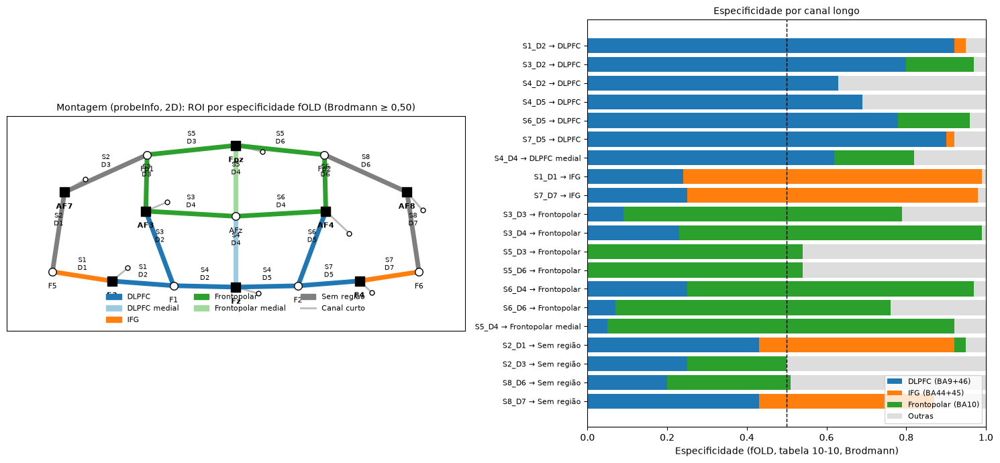

In [15]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

caminho = Path(r"C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\2026-08-04_002_probeInfo.json")
p = json.loads(caminho.read_text(encoding="utf-8-sig"))["probeInfo"]["probes"]

roi = {"S1_D2":"DLPFC","S3_D2":"DLPFC","S4_D2":"DLPFC","S4_D5":"DLPFC","S6_D5":"DLPFC","S7_D5":"DLPFC",
       "S4_D4":"DLPFC medial","S1_D1":"IFG","S7_D7":"IFG",
       "S3_D3":"Frontopolar","S3_D4":"Frontopolar","S5_D3":"Frontopolar","S5_D6":"Frontopolar",
       "S6_D4":"Frontopolar","S6_D6":"Frontopolar","S5_D4":"Frontopolar medial",
       "S2_D1":"Sem região","S2_D3":"Sem região","S8_D6":"Sem região","S8_D7":"Sem região"}
cores = {"DLPFC":"#1f77b4","DLPFC medial":"#9ecae1","IFG":"#ff7f0e","Frontopolar":"#2ca02c",
         "Frontopolar medial":"#a1d99b","Sem região":"#7f7f7f"}
spec = {"S1_D1":(.24,.75,0),"S1_D2":(.92,.03,0),"S2_D1":(.43,.49,.03),"S2_D3":(.25,0,.25),
        "S3_D2":(.80,0,.17),"S3_D3":(.09,0,.70),"S3_D4":(.23,0,.76),"S4_D2":(.63,0,0),
        "S4_D4":(.62,0,.20),"S4_D5":(.69,0,0),"S5_D3":(0,0,.54),"S5_D4":(.05,0,.87),
        "S5_D6":(0,0,.54),"S6_D4":(.25,0,.72),"S6_D5":(.78,0,.18),"S6_D6":(.07,0,.69),
        "S7_D5":(.90,.02,0),"S7_D7":(.25,.73,0),"S8_D6":(.20,0,.31),"S8_D7":(.43,.44,0)}

s2, d2 = np.array(p["coords_s2"]), np.array(p["coords_d2"])
curtos = {tuple(int(v) for v in c) for c in p["sdd_pairs"]}
fig, (ax, bx) = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1.15, 1]})

for s, d in p["index_c"]:
    s, d = int(s), int(d); a, b = s2[s-1], d2[d-1]; nome = f"S{s}_D{d}"
    if (s, d) in curtos:
        ax.plot([a[0], b[0]], [a[1], b[1]], color="#bbbbbb", lw=2, zorder=1)
    else:
        ax.plot([a[0], b[0]], [a[1], b[1]], color=cores[roi[nome]], lw=5, solid_capstyle="round", zorder=2)
        m = (a + b) / 2
        ax.text(m[0], m[1] + 0.12, nome.replace("_", "\n"), fontsize=7, ha="center", va="bottom", zorder=4)
for i, (x, y) in enumerate(s2):
    ax.scatter(x, y, marker="s", s=110, color="black", zorder=3)
    ax.text(x, y - 0.3, p["labels_s"][i], fontsize=8, ha="center", va="top", weight="bold")
for i, (x, y) in enumerate(d2):
    ax.scatter(x, y, marker="o", s=70 if i < 7 else 25, color="white", edgecolor="black", zorder=3)
    if p["labels_d"][i]:
        ax.text(x, y - 0.3, p["labels_d"][i], fontsize=8, ha="center", va="top")
ax.set_aspect("equal"); ax.set_xlim(-6.3, 6.3); ax.set_ylim(2.7, 8.6); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Montagem (probeInfo, 2D): ROI por especificidade fOLD (Brodmann ≥ 0,50)", fontsize=10)
ax.legend(handles=[Patch(color=c, label=k) for k, c in cores.items()] +
          [Line2D([0], [0], color="#bbbbbb", lw=2, label="Canal curto")],
          loc="lower center", ncol=3, fontsize=8, frameon=False)

ordem = sorted(roi, key=lambda c: (list(cores).index(roi[c]), c)); y = np.arange(len(ordem))[::-1]
dl, ifg, fp = (np.array([spec[c][k] for c in ordem]) for k in range(3))
out = np.clip(1 - dl - ifg - fp, 0, 1)
bx.barh(y, dl, color="#1f77b4", label="DLPFC (BA9+46)")
bx.barh(y, ifg, left=dl, color="#ff7f0e", label="IFG (BA44+45)")
bx.barh(y, fp, left=dl + ifg, color="#2ca02c", label="Frontopolar (BA10)")
bx.barh(y, out, left=dl + ifg + fp, color="#dddddd", label="Outras")
bx.axvline(0.5, color="k", ls="--", lw=1)
bx.set_yticks(y); bx.set_yticklabels([f"{c} → {roi[c]}" for c in ordem], fontsize=8)
bx.set_xlim(0, 1); bx.set_xlabel("Especificidade (fOLD, tabela 10-10, Brodmann)")
bx.legend(fontsize=8, loc="lower right"); bx.set_title("Especificidade por canal longo", fontsize=10)
plt.tight_layout(); plt.show()

# Especificação v1.4 — Pipeline individual DM (fNIRS) e plano estatístico
Data: 2026-11-27
Estado: proposta para confirmação do orientador. Execução em lote não autorizada.

Legenda: [Fixo] validado no piloto · [Proposta] a confirmar · [Pendente] por definir

---

## 1. Âmbito
- Estudo 2: transversal, observacional, descritivo e correlacional; uma sessão por participante.
- Tarefa: Decision Making (vídeo + decisão), duas runs por participante, mantidas separadas no primeiro nível.
- Medidas: HbO e HbR (primárias); HR e GSR (WINGS).
- Piloto de desenvolvimento: sub-001 e sub-002 (runs 1 e 2). Ambos pertencem ao grupo C.
- Fora do âmbito: combinação de runs no primeiro nível; inferência de grupo sobre o piloto.

## 2. Amostra
- Total 54; excluídos 3 federados atuais em modalidades individuais (sub-014, sub-023, sub-032); elegíveis 51.
- A = 28 atletas federados de modalidades coletivas.
- AB = 22 futebolistas (subconjunto de A).
- Outras coletivas = 6 (A menos AB): sub-007, 010, 012, 013, 015, 029.
- C = 23 não federados.

## 3. Entradas e unidades [Fixo]
- Sinal do GLM: haemo_unfiltered_raw.fif (HbO/HbR, sem filtro hemodinâmico).
- Conversão: mne.preprocessing.nirs.beer_lambert_law, PPF 6.0, MNE 1.12.1.
- Derivados: pilot_dm_epochs_v01. Pasta do estudo com prefixo "02_" no caminho atual.
- Unidade: os FIF mantêm a unidade interna do MNE (cabeçalho FIFF_UNIT_MOL).
  Fator 1e6 aplicado uma única vez antes do GLM; betas e erros-padrão em µmol/L.
- Cadeia verificada nos JSON de parâmetros: conversão única, sem escalamento intermédio.
- O sinal filtrado (0.01–0.5 Hz, Butterworth SOS, fase zero) existe como derivado separado
  e é reservado ao módulo de epochs/baseline.

## 4. Montagem
- Ficheiro: 2026-08-04_002_probeInfo.json (NIRSite; ICBM152; MNI; mm).
- 8 fontes, 15 detetores (7 longos com etiqueta 10-10 + 8 curtos), 28 canais (20 longos, 8 curtos).
- Fontes: S1 F3, S2 AF7, S3 AF3, S4 Fz, S5 Fpz, S6 AF4, S7 F4, S8 AF8.
- Detetores longos: D1 F5, D2 F1, D3 Fp1, D4 AFz, D5 F2, D6 Fp2, D7 F6.
- Montagem bilateral, frontal e pré-frontal.
- Distâncias fonte–detetor (calculadas): maioria ≈ 30 mm; S2_D1 e S8_D7 ≈ 36 mm;
  pares com AFz ≈ 39–40 mm; S3_D2 e S6_D5 ≈ 45 mm. Curtos: 7.1–8.8 mm.
- [Pendente] Confirmar que a montagem é a mesma nos 51 participantes.

## 5. Pré-processamento e qualidade
- Sequência: OD → SCI → TDDR → conversão MBLL.
- SCI [Fixo no piloto]: limiar 0.7; banda 0.7–1.5 Hz; transição inferior 0.3 Hz;
  avaliação na gravação completa; par marcado mau se SCI abaixo do limiar ou não finito;
  calculado sobre OD antes do TDDR.
- TDDR: parâmetros predefinidos do MNE.
- Sem rejeição por amplitude e sem rejeição por tentativa.
- Geometria: curto < 10 mm; longo > 15 mm, sem máximo; zona 10–15 mm excluída de ambos os usos.
- SSR: não aplicada (piloto: 1 de 4 runs com pares curtos elegíveis; SSR adiada nessa run).
- Qualidade avaliada sem conhecer o grupo.
- Run processável [Proposta]: ≥ 12 de 20 pares longos válidos.
- Reportar perdas por run, participante, grupo e ROI.

## 6. Mapa canal→ROI [Proposta; definido a priori pela especificidade do fOLD]
- Fonte: fOLD, tabela 10-10, parcelação Brodmann (folha 3_Chn). Limiar: especificidade ≥ 0.50.
- Regiões-alvo: DLPFC = BA9 + BA46; frontal inferior (IFG) = BA44 + BA45; frontopolar = BA10.
- Hemisfério: pelo sinal de x do canal; |x| ≤ 5 mm = medial.
- DLPFC esquerdo: S1_D2 (0.92), S3_D2 (0.80), S4_D2 (0.63).
- DLPFC direito: S4_D5 (0.69), S6_D5 (0.78), S7_D5 (0.90).
- DLPFC medial: S4_D4 (0.62); fora das ROIs hemisféricas.
- IFG: S1_D1 (0.75, esq.) e S7_D7 (0.73, dir.); um canal por hemisfério; análise ao nível do canal.
- Frontopolar esquerdo: S3_D3 (0.70), S3_D4 (0.76), S5_D3 (0.54).
- Frontopolar direito: S5_D6 (0.54), S6_D4 (0.72), S6_D6 (0.69).
- Frontopolar medial: S5_D4 (0.87).
- Sem região atribuída (nenhuma ≥ 0.50): S2_D1, S2_D3, S8_D6, S8_D7.
  S2_D1 e S8_D7 ficam logo abaixo do limiar (BA44+BA45 = 0.49 e 0.44; BA46 = 0.43 em ambos);
  não reatribuir após ver resultados.
- Regra de validade [Proposta]: hemisfério válido com ≥ 2 canais válidos na ROI;
  ROI bilateral válida se ambos os hemisférios forem válidos.
- Piloto: sub-001 não tem S3_D2 (DLPFC esquerdo com 2 canais).
- Limitações do mapa: tabelas fOLD baseadas em modelo de cabeça de referência; BA9 inclui
  córtex frontal superior e medial (canais Fz); especificidade não é medida individual.

## 7. Modelo individual (GLM por canal)
- Nilearn 0.14.1, run_glm, um canal por chamada [Fixo].
- Regressores: vídeo e decisão; HRF e durações conforme F-DM.2 [Pendente: confirmar no registo].
- Deriva: cosine 0.01 Hz; confirmar o maior intervalo entre eventos da mesma condição [Pendente].
- Ruído: AR40 (ordem = round(4 × fs); fs ≈ 10.17 Hz), bins=1, n_jobs=1, random_state=0 [Fixo].
- Diagnósticos por ajuste: ACF residual (sem as 40 primeiras amostras), raízes AR,
  posto e condicionamento do desenho transformado, covariância vídeo–decisão
  (simétrica, PSD, variâncias positivas).
- Sem seleção de modelo por significância ou por menor ACF.

## 8. Sensibilidades pré-especificadas
- AR20 e OLS (diagnóstico).
- AR40 + GSR/HR: GSR regularizado e reamostrado com antialiasing; HR por última observação;
  sem extrapolação, sem atrasos; PPG e SpO2 fora desta versão.
- Excluir sub-001 e sub-002.
- Contraste A vs C sem o subgrupo "outras coletivas".
- ROI DLPFC sem os canais de 45 mm (S3_D2, S6_D5).
- ROI DLPFC com a limiar de especificidade alterado para 0.40 e 0.60.

## 9. Saídas por run e canal
- Betas, erros-padrão, covariância vídeo–decisão, diagnósticos do ajuste,
  canais e eventos usados, avisos, versões, unidade e identificação do modelo.

## 10. Plano estatístico (segundo nível) [Proposta]
- Hipótese primária: diferença entre A (n = 28) e C (n = 23) na resposta de HbO
  no DLPFC bilateral (6 canais), fase de decisão. HbR co-primário. Bilateral, sem direção prévia.
- Agregação por ROI: média dos betas dos canais válidos por hemisfério e depois entre hemisférios, por run.
  Sensibilidade: modelo ao nível do canal com efeitos aleatórios.
- Modelo por cromóforo: beta ~ grupo + run + idade + sexo + (1 | participante).
- Codificação do grupo: C (23), futebol (22), outras coletivas (6); A = futebol + outras.
- Família primária: A vs C × {HbO, HbR}; correção de Holm.
- Família exploratória pré-declarada: AB vs C; fase de vídeo; ROI frontopolar;
  canais IFG individuais (S1_D1, S7_D7); lateralidade (esquerda vs direita); canal a canal.
  Correção FDR; sem conclusões confirmatórias.
- Reportar tamanhos de efeito e intervalos de confiança, não apenas p.
- HR e GSR analisados também como resultados próprios (SPA).
- GSR/HR fora do modelo primário: possíveis diferenças autonómicas reais entre grupos.

## 11. Potência
- A (28) vs C (23): efeito mínimo detetável d ≈ 0.79 (aprox. normal, bilateral, α 0.05, potência 80%).
- AB (22) vs C (23): d ≈ 0.84.
- Com dois cromóforos e Holm, o limiar é mais alto.
- Confirmar com software de potência antes de citar.
- Interpretar como caracterização; potência apenas para efeitos grandes.

## 12. Validação no piloto
- 156 ajustes AR20 e 156 AR40 (F-DM.36): estabilidade AR, posto completo, simetria e PSD da covariância: todos True.
- 312 ajustes (F-DM.40B): idem. GSR/HR alteram os betas, sobretudo decisão–HbO,
  sem melhoria consistente da ACF residual.
- Inversões de sinal entre desenhos: vídeo 10/156; decisão 20/156 (descritivo; sem exclusões).
- Auxiliares: SNIRF e WINGS coincidem entre os marcadores 100–160 (42 onsets por run; diferença máxima 0 ms).

## 13. Limitações declaradas
- Sem SSR: o contributo superficial/sistémico não é removido; GSR/HR não o substituem.
- Sem passa-baixo no sinal do GLM: componentes cardíaca e respiratória permanecem.
- Sincronização PsychoPy/LSL e latências dos sensores não validadas.
- Erros-padrão condicionais ao modelo; cobertura não demonstrada.
- Resultados do piloto (n = 2, ambos em C) não permitem generalização.
- O SCI é avaliado na gravação completa, não por janelas.
- O mapa canal→ROI usa especificidade de uma tabela de referência (fOLD), não individual.
- O frontal inferior fica sem ROI (um canal por hemisfério).
- A convenção do MNE para a unidade de saída (mol/L) não foi verificada em documentação.

## 14. Pendentes
- Confirmação do orientador: hipótese primária, regras de qualidade, entrada sem filtro,
  limiar de 0.50 e soma BA9+BA46, plano de segundo nível.
- Confirmar que a montagem é igual nos 51 participantes.
- HRF e durações do desenho (F-DM.2) e intervalo máximo entre eventos da mesma condição.

## 15. Portões e controlo de alterações
1. Congelar a especificação e etiquetar a versão do código antes do lote.
2. Teste de integração em sessão limpa, comparando com os resultados guardados do piloto.
3. Lote nos 51, com relatório de qualidade por participante, cego ao grupo.
4. Segundo nível só depois de fechado o relatório de qualidade.
- Qualquer alteração posterior fica registada com data, motivo e versão.

### F-DM.47 — Inventário e auditoria da montagem (51 participantes, tarefa DM)

Objetivo (bloqueios B1 e B3):
- verificar, por participante e run, a presença de SNIRF, probeInfo, lsl.tri e pasta comprimida;
- comparar a topologia da montagem de cada probeInfo com a de referência;
- listar o conteúdo da primeira pasta comprimida encontrada (nomes, sem extrair).

Limites: só metadados e probeInfo (24 KB cada); não abre SNIRF nem FIF; não extrai zips;
não executa pré-processamento nem GLM; não escreve ficheiros. Cego ao grupo.

In [16]:
import json
import re
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = Path(r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra"
            r"\PhD_Project_ARDITI_Guilherme Saldanha"
            r"\02_Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI")
if not RAIZ.is_dir():
    raise NotADirectoryError(RAIZ)

ELEGIVEIS = [f"sub-{i:03d}" for i in range(1, 55) if i not in (14, 23, 32)]
assert len(ELEGIVEIS) == 51

def ler_probe(caminho):
    p = json.loads(caminho.read_text(encoding="utf-8-sig"))["probeInfo"]["probes"]
    return {
        "index_c": [tuple(int(v) for v in c) for c in p["index_c"]],
        "labels_s": list(p["labels_s"]),
        "labels_d": list(p["labels_d"]),
        "coords_c3": np.asarray(p["coords_c3"], dtype=float),
    }

linhas, referencia, amostra_zip = [], None, None

for sujeito in ELEGIVEIS:
    for run in (1, 2):
        nome = f"{sujeito}_ses-01_tk-dm_run-{run}_nirs_{sujeito[-3:]}"
        pasta = RAIZ / sujeito / "nirs" / nome
        linha = {"sujeito": sujeito, "run": run, "pasta_existe": pasta.is_dir()}
        if not pasta.is_dir():
            linhas.append(linha)
            continue

        snirf = sorted(pasta.glob("*.snirf"))
        probes = sorted(pasta.glob("*_probeInfo.json"))
        tris = sorted(pasta.glob("*_lsl.tri"))
        zips = sorted(pasta.glob("*.zip"))
        linha.update({
            "n_snirf": len(snirf),
            "snirf_mb": round(snirf[0].stat().st_size / 1e6, 2) if snirf else None,
            "n_probeinfo": len(probes),
            "n_lsl_tri": len(tris),
            "n_zip": len(zips),
            "derivados_fnirs": (RAIZ / sujeito / "fNIRS_epochs_derivatives").is_dir(),
            "id_gravacao": probes[0].name.replace("_probeInfo.json", "") if probes else None,
        })

        if probes:
            try:
                atual = ler_probe(probes[0])
                if referencia is None:
                    referencia = atual
                linha["topologia_igual"] = (
                    atual["index_c"] == referencia["index_c"]
                    and atual["labels_s"] == referencia["labels_s"]
                    and atual["labels_d"] == referencia["labels_d"]
                )
                if atual["coords_c3"].shape == referencia["coords_c3"].shape:
                    linha["dif_max_coords_mm"] = round(
                        float(np.abs(atual["coords_c3"] - referencia["coords_c3"]).max()), 1)
            except Exception as erro:
                linha["erro_probe"] = str(erro)[:80]

        if run == 2 and zips and amostra_zip is None:
            with zipfile.ZipFile(zips[0]) as z:
                amostra_zip = (zips[0].name, z.namelist()[:15])

        linhas.append(linha)

df_inventario_dm47 = pd.DataFrame(linhas)
print("Linhas:", len(df_inventario_dm47), "(esperado 102)")
print("\nPastas em falta:\n", df_inventario_dm47.loc[~df_inventario_dm47["pasta_existe"], ["sujeito", "run"]].to_string(index=False))

presentes = df_inventario_dm47[df_inventario_dm47["pasta_existe"]]
anomalias = presentes[(presentes["n_snirf"] != 1) | (presentes["n_probeinfo"] != 1)
                      | (presentes["n_lsl_tri"] != 1)]
print("\nRuns com n SNIRF/probeInfo/lsl.tri diferente de 1:\n",
      anomalias[["sujeito", "run", "n_snirf", "n_probeinfo", "n_lsl_tri"]].to_string(index=False))

print("\nTopologia diferente da referência:\n",
      presentes.loc[presentes["topologia_igual"].eq(False),
                    ["sujeito", "run", "dif_max_coords_mm"]].to_string(index=False))
print("\nZip por run:\n", presentes.groupby("run")["n_zip"].value_counts().to_string())
print("\nDerivados fNIRS existentes:",
      presentes.groupby("sujeito")["derivados_fnirs"].first().sum(), "participantes")
print("\nCoordenadas: diferença máxima por run (mm):\n",
      presentes.groupby("run")["dif_max_coords_mm"].describe().round(1).to_string())
print("\nAmostra do conteúdo do primeiro zip:", amostra_zip)

Linhas: 102 (esperado 102)

Pastas em falta:
 Empty DataFrame
Columns: [sujeito, run]
Index: []

Runs com n SNIRF/probeInfo/lsl.tri diferente de 1:
 Empty DataFrame
Columns: [sujeito, run, n_snirf, n_probeinfo, n_lsl_tri]
Index: []

Topologia diferente da referência:
 Empty DataFrame
Columns: [sujeito, run, dif_max_coords_mm]
Index: []

Zip por run:
 run  n_zip
1    1        51
2    1        51

Derivados fNIRS existentes: 2 participantes

Coordenadas: diferença máxima por run (mm):
      count  mean  std  min  25%  50%  75%  max
run                                           
1     51.0   0.0  0.0  0.0  0.0  0.0  0.0  0.0
2     51.0   0.0  0.0  0.0  0.0  0.0  0.0  0.0

Amostra do conteúdo do primeiro zip: ('2026-08-04_004.zip', ['2026-08-04_004.roh', '2026-08-04_004.acc', '2026-08-04_004.wings'])


### F-DM.47 — Inventário, montagem e localização do WINGS (51 participantes, tarefa DM)

Objetivo (B1, B3):
- presença de SNIRF, probeInfo, lsl.tri por run;
- topologia da montagem igual à de referência (etiquetas 10-10 e index_c);
- localização do WINGS: pasta dados_wings_extraidos (run 1) ou pasta comprimida (run 2);
- coerência do id do WINGS com o id da gravação fNIRS.

Limites: só metadados, probeInfo e lista de nomes dentro do zip; não extrai nem abre
SNIRF/WINGS/FIF; não pré-processa nem ajusta GLM; não escreve ficheiros. Cego ao grupo.

In [17]:
import json
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = Path(r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra"
            r"\PhD_Project_ARDITI_Guilherme Saldanha"
            r"\02_Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI")
if not RAIZ.is_dir():
    raise NotADirectoryError(RAIZ)

ELEGIVEIS = [f"sub-{i:03d}" for i in range(1, 55) if i not in (14, 23, 32)]
assert len(ELEGIVEIS) == 51

def ler_probe(caminho):
    p = json.loads(caminho.read_text(encoding="utf-8-sig"))["probeInfo"]["probes"]
    return {"index_c": [tuple(int(v) for v in c) for c in p["index_c"]],
            "labels_s": list(p["labels_s"]), "labels_d": list(p["labels_d"]),
            "coords_c3": np.asarray(p["coords_c3"], dtype=float)}

linhas, referencia, amostra_zip = [], None, None

for sujeito in ELEGIVEIS:
    for run in (1, 2):
        nome = f"{sujeito}_ses-01_tk-dm_run-{run}_nirs_{sujeito[-3:]}"
        pasta = RAIZ / sujeito / "nirs" / nome
        linha = {"sujeito": sujeito, "run": run, "pasta_existe": pasta.is_dir()}
        if not pasta.is_dir():
            linhas.append(linha)
            continue

        snirf = sorted(pasta.glob("*.snirf"))
        probes = sorted(pasta.glob("*_probeInfo.json"))
        tris = sorted(pasta.glob("*_lsl.tri"))
        zips = sorted(pasta.glob("*.zip"))
        pasta_wings = pasta / "dados_wings_extraidos"
        extraidos = sorted(pasta_wings.glob("*.wings")) if pasta_wings.is_dir() else []

        wings_zip = []
        for z in zips:
            with zipfile.ZipFile(z) as zf:
                nomes_zip = zf.namelist()
                wings_zip += [Path(n).stem for n in nomes_zip if n.lower().endswith(".wings")]
                if run == 2 and amostra_zip is None:
                    amostra_zip = (z.name, nomes_zip[:15])

        id_grav = probes[0].name.replace("_probeInfo.json", "") if probes else None
        id_wings = (extraidos[0].stem if extraidos else (wings_zip[0] if wings_zip else None))
        linha.update({
            "n_snirf": len(snirf), "n_probeinfo": len(probes), "n_lsl_tri": len(tris),
            "wings_extraido": len(extraidos), "wings_no_zip": len(wings_zip),
            "id_gravacao": id_grav, "id_wings": id_wings,
            "ids_coincidem": (id_grav == id_wings) if (id_grav and id_wings) else None,
            "derivados_fnirs": (RAIZ / sujeito / "fNIRS_epochs_derivatives").is_dir(),
        })

        if probes:
            try:
                atual = ler_probe(probes[0])
                referencia = referencia or atual
                linha["topologia_igual"] = (atual["index_c"] == referencia["index_c"]
                    and atual["labels_s"] == referencia["labels_s"]
                    and atual["labels_d"] == referencia["labels_d"])
                if atual["coords_c3"].shape == referencia["coords_c3"].shape:
                    linha["dif_max_coords_mm"] = round(
                        float(np.abs(atual["coords_c3"] - referencia["coords_c3"]).max()), 1)
            except Exception as erro:
                linha["erro_probe"] = str(erro)[:80]
        linhas.append(linha)

df_inventario_dm47 = pd.DataFrame(linhas)
presentes = df_inventario_dm47[df_inventario_dm47["pasta_existe"]]

print("Linhas:", len(df_inventario_dm47), "(esperado 102)")
print("\nPastas em falta:\n",
      df_inventario_dm47.loc[~df_inventario_dm47["pasta_existe"], ["sujeito", "run"]].to_string(index=False))
print("\nRuns com n SNIRF/probeInfo/lsl.tri diferente de 1:\n",
      presentes.loc[(presentes["n_snirf"] != 1) | (presentes["n_probeinfo"] != 1) | (presentes["n_lsl_tri"] != 1),
                    ["sujeito", "run", "n_snirf", "n_probeinfo", "n_lsl_tri"]].to_string(index=False))
print("\nRuns sem WINGS (nem extraído nem no zip):\n",
      presentes.loc[(presentes["wings_extraido"] == 0) & (presentes["wings_no_zip"] == 0),
                    ["sujeito", "run"]].to_string(index=False))
print("\nWINGS por run (extraído / no zip):\n",
      presentes.groupby("run")[["wings_extraido", "wings_no_zip"]].agg(lambda s: int((s > 0).sum())).to_string())
print("\nIds do WINGS que não coincidem com o id da gravação:\n",
      presentes.loc[presentes["ids_coincidem"].eq(False), ["sujeito", "run", "id_gravacao", "id_wings"]].to_string(index=False))
print("\nTopologia diferente da referência:\n",
      presentes.loc[presentes["topologia_igual"].eq(False), ["sujeito", "run"]].to_string(index=False))
print("\nDiferença máxima das coordenadas (mm), por run:\n",
      presentes.groupby("run")["dif_max_coords_mm"].describe().round(1).to_string())
print("\nParticipantes com derivados fNIRS:", int(presentes.groupby("sujeito")["derivados_fnirs"].first().sum()))
print("\nAmostra do conteúdo do primeiro zip (run 2):", amostra_zip)

Linhas: 102 (esperado 102)

Pastas em falta:
 Empty DataFrame
Columns: [sujeito, run]
Index: []

Runs com n SNIRF/probeInfo/lsl.tri diferente de 1:
 Empty DataFrame
Columns: [sujeito, run, n_snirf, n_probeinfo, n_lsl_tri]
Index: []

Runs sem WINGS (nem extraído nem no zip):
 Empty DataFrame
Columns: [sujeito, run]
Index: []

WINGS por run (extraído / no zip):
      wings_extraido  wings_no_zip
run                              
1                51            51
2                 0            51

Ids do WINGS que não coincidem com o id da gravação:
 Empty DataFrame
Columns: [sujeito, run, id_gravacao, id_wings]
Index: []

Topologia diferente da referência:
 Empty DataFrame
Columns: [sujeito, run]
Index: []

Diferença máxima das coordenadas (mm), por run:
      count  mean  std  min  25%  50%  75%  max
run                                           
1     51.0   0.0  0.0  0.0  0.0  0.0  0.0  0.0
2     51.0   0.0  0.0  0.0  0.0  0.0  0.0  0.0

Participantes com derivados fNIRS: 2

Amostra d

### F-DM.48 — Auditoria de eventos e auxiliares nos SNIRF (51 × 2 runs, DM)

Esperado por run (Mapa de triggers LSL): 100 ×1; 110, 120, 130, 150 ×10; resposta (140–143) ≤10; 160 ×1.

Verifica por run:
- contagem de cada código e de eventos desconhecidos;
- ordem dos tempos e intervalo 130 → resposta;
- decisões sem resposta;
- frequência de amostragem, duração, número de canais;
- nomes dos canais auxiliares no SNIRF.

Limites: leitura apenas de cabeçalhos, anotações e nomes dos auxiliares; não abre WINGS,
não pré-processa, não ajusta GLM, não escreve ficheiros. Cego ao grupo.

In [18]:
from collections import Counter
from pathlib import Path

import h5py
import mne
import numpy as np
import pandas as pd

mne.set_log_level("ERROR")

if "RAIZ" not in globals() or "ELEGIVEIS" not in globals():
    raise RuntimeError("Corre primeiro a célula F-DM.47 (define RAIZ e ELEGIVEIS).")

linhas = []
for sujeito in ELEGIVEIS:
    for run in (1, 2):
        nome = f"{sujeito}_ses-01_tk-dm_run-{run}_nirs_{sujeito[-3:]}"
        pasta = RAIZ / sujeito / "nirs" / nome
        linha = {"sujeito": sujeito, "run": run}
        try:
            caminho = sorted(pasta.glob("*.snirf"))[0]
            raw = mne.io.read_raw_snirf(caminho, preload=False, verbose=False)
            ann = pd.DataFrame({"onset": raw.annotations.onset,
                                "cod": pd.to_numeric(raw.annotations.description, errors="coerce")})
            ann = ann.sort_values("onset").reset_index(drop=True)
            cont = Counter(ann["cod"].dropna().astype(int))
            resp = [c for c in cont if 140 <= c <= 143]
            rts, sem_resp = [], 0
            cods, ons = ann["cod"].to_numpy(), ann["onset"].to_numpy()
            for i in np.flatnonzero(cods == 130):
                j = i + 1
                while j < len(cods) and not (140 <= cods[j] <= 143) and cods[j] not in (120, 130, 150, 160):
                    j += 1
                if j < len(cods) and 140 <= cods[j] <= 143:
                    rts.append(ons[j] - ons[i])
                else:
                    sem_resp += 1
            with h5py.File(caminho, "r") as f:
                aux = []
                for k in sorted(k for k in f["nirs"].keys() if k.startswith("aux")):
                    v = f["nirs"][k]["name"][()]
                    aux.append(v.decode() if hasattr(v, "decode") else str(v))
            linha.update({
                "sfreq": round(float(raw.info["sfreq"]), 4),
                "duracao_s": round(float(raw.times[-1]), 1),
                "n_canais": len(raw.ch_names),
                "n100": cont.get(100, 0), "n110": cont.get(110, 0), "n120": cont.get(120, 0),
                "n130": cont.get(130, 0), "n_resp": sum(cont[c] for c in resp),
                "n150": cont.get(150, 0), "n160": cont.get(160, 0),
                "n_desconhecidos": int(ann["cod"].isna().sum()
                                      + sum(v for c, v in cont.items() if c not in (100, 110, 120, 130, 140, 141, 142, 143, 150, 160))),
                "ordem_ok": bool(np.all(np.diff(ons) >= 0)),
                "decisoes_sem_resposta": sem_resp,
                "rt_min": round(min(rts), 2) if rts else None,
                "rt_mediana": round(float(np.median(rts)), 2) if rts else None,
                "rt_max": round(max(rts), 2) if rts else None,
                "aux": "|".join(aux),
            })
        except Exception as erro:
            linha["erro"] = str(erro)[:100]
        linhas.append(linha)

df_eventos_dm48 = pd.DataFrame(linhas)
ok = df_eventos_dm48[df_eventos_dm48.get("erro").isna()] if "erro" in df_eventos_dm48 else df_eventos_dm48

print("Linhas:", len(df_eventos_dm48), "| com erro:", int(df_eventos_dm48.get("erro", pd.Series(dtype=object)).notna().sum()))
print("\nFrequências de amostragem:", ok["sfreq"].value_counts().to_dict())
print("\nDuração (s) por run:\n", ok.groupby("run")["duracao_s"].describe().round(1).to_string())
print("\nNúmero de canais:", ok["n_canais"].value_counts().to_dict())

esperado = ok[(ok["n100"] == 1) & (ok["n120"] == 10) & (ok["n130"] == 10) & (ok["n150"] == 10)
              & (ok["n160"] == 1) & (ok["n_desconhecidos"] == 0) & ok["ordem_ok"]]
print("\nRuns com a estrutura esperada:", len(esperado), "de", len(ok))
print("\nRuns fora da estrutura esperada:\n",
      ok.drop(index=esperado.index)[["sujeito", "run", "n100", "n110", "n120", "n130", "n_resp", "n150", "n160", "n_desconhecidos", "ordem_ok"]].to_string(index=False))
print("\nRuns com decisões sem resposta:\n",
      ok.loc[ok["decisoes_sem_resposta"] > 0, ["sujeito", "run", "n130", "n_resp", "decisoes_sem_resposta"]].to_string(index=False))
print("\nIntervalo 130 → resposta (s), mediana de cada run:\n", ok["rt_mediana"].describe().round(2).to_string())
print("\nCanais auxiliares (frequência dos conjuntos):\n", ok["aux"].value_counts().to_string())

Linhas: 102 | com erro: 0

Frequências de amostragem: {10.1725: 102}

Duração (s) por run:
      count   mean   std    min    25%    50%    75%    max
run                                                       
1     51.0  447.6  31.6  362.3  425.4  445.1  465.2  527.4
2     51.0  414.7   9.8  399.0  408.8  412.3  418.8  447.5

Número de canais: {56: 102}

Runs com a estrutura esperada: 100 de 102

Runs fora da estrutura esperada:
 sujeito  run  n100  n110  n120  n130  n_resp  n150  n160  n_desconhecidos  ordem_ok
sub-012    2     0    10    10    10       0    10     1                0      True
sub-015    1     1     7     7     6       0     6     0                0      True

Runs com decisões sem resposta:
 sujeito  run  n130  n_resp  decisoes_sem_resposta
sub-001    1    10       0                     10
sub-001    2    10       0                     10
sub-002    1    10       0                     10
sub-002    2    10       0                     10
sub-003    1    10       0   

### F-DM.49 — Guardar os inventários de F-DM.47 e F-DM.48

Escreve dois CSV com data e hora na pasta DM_piloto_checkpoints (sem sobrescrever);
exige que df_inventario_dm47 e df_eventos_dm48 existam na sessão.

In [19]:
from datetime import datetime
from pathlib import Path

for nome in ("df_inventario_dm47", "df_eventos_dm48"):
    if nome not in globals():
        raise RuntimeError(f"Falta {nome} em memória.")

pasta = Path.home() / "DM_piloto_checkpoints"
pasta.mkdir(parents=True, exist_ok=True)
carimbo = datetime.now().strftime("%Y%m%d_%H%M%S")

for nome in ("df_inventario_dm47", "df_eventos_dm48"):
    caminho = pasta / f"{nome}_{carimbo}.csv"
    globals()[nome].to_csv(caminho, index=False, encoding="utf-8-sig")
    print(caminho, "| bytes:", caminho.stat().st_size)

C:\Users\guilh\DM_piloto_checkpoints\df_inventario_dm47_20261127_161257.csv | bytes: 7920
C:\Users\guilh\DM_piloto_checkpoints\df_eventos_dm48_20261127_161257.csv | bytes: 13103


# Especificação v1.5 — Pipeline individual DM (fNIRS) e plano estatístico
Data: 2026-11-27
Estado: proposta para confirmação do orientador. Execução em lote não autorizada.

Legenda: [Fixo] validado · [Proposta] a confirmar · [Pendente] por definir

---

## 1. Âmbito
- Estudo 2: transversal, observacional, descritivo e correlacional; uma sessão por participante.
- Tarefa: Decision Making (vídeo + decisão), duas runs por participante, mantidas separadas no primeiro nível.
- Medidas: HbO e HbR (primárias); HR e GSR.
- Piloto de desenvolvimento: sub-001 e sub-002 (runs 1 e 2). Ambos pertencem ao grupo C.
- Fora do âmbito: combinação de runs no primeiro nível; inferência de grupo sobre o piloto.

## 2. Amostra
- Total 54; excluídos 3 federados atuais em modalidades individuais (sub-014, sub-023, sub-032); elegíveis 51.
- A = 28 atletas federados de modalidades coletivas.
- AB = 22 futebolistas (subconjunto de A).
- Outras coletivas = 6 (A menos AB): sub-007, 010, 012, 013, 015, 029.
- C = 23 não federados.

## 3. Dados brutos e auditoria (F-DM.47–48) [Fixo]
- Estrutura por participante: nirs, psychopy, quest-miq3, quest-qdemo.
- Por run DM: um SNIRF, um probeInfo.json, um _lsl.tri, ficheiros .nirs/.wl1/.wl2, config, calibration, digpts.
- WINGS (.roh, .acc, .wings): run 1 em dados_wings_extraidos (e no zip); run 2 no zip.
  Id do WINGS coincide com o id da gravação fNIRS nas 102 runs.
- 51 participantes × 2 runs DM, sem pastas em falta; 102 SNIRF com fs = 10.1725 Hz e 56 canais.
- Duração: run 1 média 447.6 s (362.3–527.4); run 2 média 414.7 s (399.0–447.5).
- Auxiliares no SNIRF (todas as runs): ACCEL_X/Y/Z, GYRO_X/Y/Z, Heartrate, GSR, PPG, SpO2.
- Derivados fNIRS existentes: só sub-001 e sub-002; os restantes 49 requerem pré-processamento.

### Eventos (Mapa de triggers LSL)
- Esperado por run: 100 ×1; 110, 120, 130, 150 ×10; 160 ×1; resposta 140–143 ≤10.
- 100 de 102 runs têm a estrutura esperada, exceto resposta.
- Exceções: sub-012 run 2 (sem marcador 100); sub-015 run 1 (7 vídeos, 6 decisões, sem 160).
- Nenhum SNIRF contém marcadores de resposta (140–143); não há códigos desconhecidos.
- Política para runs incompletas [Proposta]: usar apenas tentativas completas (vídeo + decisão);
  incluir sub-015 run 1 com as tentativas disponíveis; sensibilidade sem essa run;
  sub-012 run 2 incluída (o baseline inicial não entra no GLM), sujeita à confirmação do sincronismo.

## 4. Entradas e unidades [Fixo]
- Sinal do GLM: haemo_unfiltered_raw.fif (HbO/HbR, sem filtro hemodinâmico).
- Conversão: mne.preprocessing.nirs.beer_lambert_law, PPF 6.0, MNE 1.12.1.
- Derivados: pilot_dm_epochs_v01. Pasta do estudo com prefixo "02_" no caminho atual.
- Unidade: os FIF mantêm a unidade interna do MNE (cabeçalho FIFF_UNIT_MOL).
  Fator 1e6 aplicado uma única vez antes do GLM; betas e erros-padrão em µmol/L.
- Cadeia verificada nos JSON de parâmetros: conversão única, sem escalamento intermédio.
- O sinal filtrado (0.01–0.5 Hz, Butterworth SOS, fase zero) existe como derivado separado
  e é reservado ao módulo de epochs/baseline.

## 5. Montagem [Fixo]
- 8 fontes, 15 detetores (7 longos com etiqueta 10-10 + 8 curtos), 28 canais (20 longos, 8 curtos).
- Fontes: S1 F3, S2 AF7, S3 AF3, S4 Fz, S5 Fpz, S6 AF4, S7 F4, S8 AF8.
- Detetores longos: D1 F5, D2 F1, D3 Fp1, D4 AFz, D5 F2, D6 Fp2, D7 F6.
- Topologia e coordenadas idênticas nos 102 probeInfo (diferença máxima 0.0 mm): os ficheiros
  reproduzem o modelo; não são registos individuais da cabeça.
- Distâncias fonte–detetor: maioria ≈ 30 mm; S2_D1 e S8_D7 ≈ 36 mm; pares com AFz ≈ 39–40 mm;
  S3_D2 e S6_D5 ≈ 45 mm. Curtos: 7.1–8.8 mm.

## 6. Pré-processamento e qualidade
- Sequência: OD → SCI → TDDR → conversão MBLL.
- SCI [Fixo no piloto]: limiar 0.7; banda 0.7–1.5 Hz; transição inferior 0.3 Hz;
  avaliação na gravação completa; par marcado mau se SCI abaixo do limiar ou não finito;
  calculado sobre OD antes do TDDR.
- TDDR: parâmetros predefinidos do MNE.
- Sem rejeição por amplitude e sem rejeição por tentativa.
- Geometria: curto < 10 mm; longo > 15 mm, sem máximo; zona 10–15 mm excluída de ambos os usos.
- SSR: não aplicada (piloto: 1 de 4 runs com pares curtos elegíveis; SSR adiada nessa run).
- Qualidade avaliada sem conhecer o grupo.
- Run processável [Proposta]: ≥ 12 de 20 pares longos válidos.
- Reportar perdas por run, participante, grupo e ROI.

## 7. Mapa canal→ROI [Proposta; definido a priori pela especificidade do fOLD]
- Fonte: fOLD, tabela 10-10, parcelação Brodmann (folha 3_Chn). Limiar: especificidade ≥ 0.50.
- Regiões-alvo: DLPFC = BA9 + BA46; frontal inferior (IFG) = BA44 + BA45; frontopolar = BA10.
- Hemisfério: pelo sinal de x do canal; |x| ≤ 5 mm = medial.
- DLPFC esquerdo: S1_D2 (0.92), S3_D2 (0.80), S4_D2 (0.63).
- DLPFC direito: S4_D5 (0.69), S6_D5 (0.78), S7_D5 (0.90).
- DLPFC medial: S4_D4 (0.62); fora das ROIs hemisféricas.
- IFG: S1_D1 (0.75, esq.) e S7_D7 (0.73, dir.); um canal por hemisfério; análise ao nível do canal.
- Frontopolar esquerdo: S3_D3 (0.70), S3_D4 (0.76), S5_D3 (0.54).
- Frontopolar direito: S5_D6 (0.54), S6_D4 (0.72), S6_D6 (0.69).
- Frontopolar medial: S5_D4 (0.87).
- Sem região atribuída (nenhuma ≥ 0.50): S2_D1, S2_D3, S8_D6, S8_D7; não reatribuir após ver resultados.
- Regra de validade [Proposta]: hemisfério válido com ≥ 2 canais válidos na ROI;
  ROI bilateral válida se ambos os hemisférios forem válidos.
- Piloto: sub-001 não tem S3_D2 (DLPFC esquerdo com 2 canais).
- Limitações: tabelas fOLD baseadas em modelo de cabeça de referência; BA9 inclui córtex frontal
  superior e medial (canais Fz); especificidade não é medida individual.

## 8. Modelo individual (GLM por canal)
- Nilearn 0.14.1, run_glm, um canal por chamada [Fixo].
- Regressores: vídeo (120) e decisão (130); HRF conforme F-DM.2 [Pendente: confirmar no registo].
- Duração do regressor de decisão [Pendente]: o SNIRF não tem marcadores de resposta (140–143);
  confirmar a definição usada em F-DM.2 (por exemplo, 130 → 150 ou duração fixa) e, se necessário,
  obter o tempo de resposta do PsychoPy ou do ficheiro _lsl.tri.
- Deriva: cosine 0.01 Hz; confirmar o maior intervalo entre eventos da mesma condição [Pendente].
- Ruído: AR40 (ordem = round(4 × fs); fs = 10.1725 Hz), bins=1, n_jobs=1, random_state=0 [Fixo].
- Diagnósticos por ajuste: ACF residual (sem as 40 primeiras amostras), raízes AR,
  posto e condicionamento do desenho transformado, covariância vídeo–decisão
  (simétrica, PSD, variâncias positivas).
- Sem seleção de modelo por significância ou por menor ACF.

## 9. Sensibilidades pré-especificadas
- AR20 e OLS (diagnóstico).
- AR40 + GSR/HR: GSR regularizado e reamostrado com antialiasing; HR por última observação;
  sem extrapolação, sem atrasos; PPG e SpO2 fora desta versão.
- Excluir sub-001 e sub-002; excluir sub-015 run 1.
- Contraste A vs C sem o subgrupo "outras coletivas".
- ROI DLPFC sem os canais de 45 mm (S3_D2, S6_D5).
- ROI DLPFC com limiar de especificidade 0.40 e 0.60.

## 10. Saídas por run e canal
- Betas, erros-padrão, covariância vídeo–decisão, diagnósticos do ajuste,
  canais e eventos usados, avisos, versões, unidade e identificação do modelo.

## 11. Plano estatístico (segundo nível) [Proposta]
- Hipótese primária: diferença entre A (n = 28) e C (n = 23) na resposta de HbO
  no DLPFC bilateral (6 canais), fase de decisão. HbR co-primário. Bilateral, sem direção prévia.
- Agregação por ROI: média dos betas dos canais válidos por hemisfério e depois entre hemisférios, por run.
  Sensibilidade: modelo ao nível do canal com efeitos aleatórios.
- Modelo por cromóforo: beta ~ grupo + run + idade + sexo + (1 | participante).
- Codificação do grupo: C (23), futebol (22), outras coletivas (6); A = futebol + outras.
- Família primária: A vs C × {HbO, HbR}; correção de Holm.
- Família exploratória pré-declarada: AB vs C; fase de vídeo; ROI frontopolar;
  canais IFG individuais (S1_D1, S7_D7); lateralidade; canal a canal. Correção FDR; sem conclusões confirmatórias.
- Reportar tamanhos de efeito e intervalos de confiança, não apenas p.
- HR e GSR analisados também como resultados próprios.
- GSR/HR fora do modelo primário: possíveis diferenças autonómicas reais entre grupos.

## 12. Potência
- A (28) vs C (23): efeito mínimo detetável d ≈ 0.79 (aprox. normal, bilateral, α 0.05, potência 80%).
- AB (22) vs C (23): d ≈ 0.84.
- Com dois cromóforos e Holm, o limiar é mais alto.
- Confirmar com software de potência antes de citar.
- Interpretar como caracterização; potência apenas para efeitos grandes.

## 13. Validação no piloto
- 156 ajustes AR20 e 156 AR40 (F-DM.36): estabilidade AR, posto completo, simetria e PSD da covariância: todos True.
- 312 ajustes (F-DM.40B): idem. GSR/HR alteram os betas, sobretudo decisão–HbO,
  sem melhoria consistente da ACF residual.
- Inversões de sinal entre desenhos: vídeo 10/156; decisão 20/156 (descritivo; sem exclusões).
- Auxiliares: SNIRF e WINGS coincidem entre os marcadores 100–160 no piloto (42 onsets por run;
  diferença máxima 0 ms). 42 coincide com 100, 110, 120, 130, 150 e 160 (1+10+10+10+10+1), sem respostas.

## 14. Limitações declaradas
- Sem SSR: o contributo superficial/sistémico não é removido; GSR/HR não o substituem.
- Sem passa-baixo no sinal do GLM: componentes cardíaca e respiratória permanecem.
- Sincronização PsychoPy/LSL e latências dos sensores não validadas.
- Erros-padrão condicionais ao modelo; cobertura não demonstrada.
- Resultados do piloto (n = 2, ambos em C) não permitem generalização.
- O SCI é avaliado na gravação completa, não por janelas.
- O mapa canal→ROI usa especificidade de uma tabela de referência (fOLD), não individual.
- O frontal inferior fica sem ROI (um canal por hemisfério).
- Sem marcadores de resposta no SNIRF.
- A convenção do MNE para a unidade de saída (mol/L) não foi verificada em documentação.

## 15. Pendentes
- Duração do regressor de decisão sem marcadores de resposta (F-DM.2; _lsl.tri; CSV do PsychoPy).
- HRF e durações do desenho (F-DM.2) e intervalo máximo entre eventos da mesma condição.
- Pares curtos válidos nos 51 (SCI), para decidir se SSR é viável como sensibilidade.
- Confirmação do orientador: hipótese primária, regras de qualidade, entrada sem filtro,
  limiar 0.50 e soma BA9+BA46, plano de segundo nível, runs incompletas.

## 16. Portões e controlo de alterações
1. Congelar a especificação e etiquetar a versão do código antes do lote.
2. Teste de integração em sessão limpa, comparando com os resultados guardados do piloto.
3. Lote nos 51, com relatório de qualidade por participante, cego ao grupo.
4. Segundo nível só depois de fechado o relatório de qualidade.
- Qualquer alteração posterior fica registada com data, motivo e versão.

## 17. Estado da sessão (2026-11-27) e primeiro passo da próxima
- Concluído: proveniência de unidades; mapa canal→ROI (fOLD); figura da montagem;
  auditoria de ficheiros e montagem (F-DM.47); auditoria de eventos e auxiliares (F-DM.48).
- Guardados: checkpoint de F-DM.40B–C (pickle) e inventários F-DM.47–48 (CSV), em DM_piloto_checkpoints.
- Primeiro passo: ler, sem executar, a célula de F-DM.2 para ver como foi definida a duração da decisão;
  abrir um _lsl.tri e o CSV do PsychoPy de uma run para ver se há marcadores/tempos de resposta.
- Depois: enviar as perguntas ao orientador; auditoria do SCI nos 49 sem derivados (cega ao grupo).

### F-DM.50 — Durações e intervalos dos eventos nos SNIRF (51 × 2 runs, DM)

Objetivo (fecho do B2 para os 51):
- reconstruir tentativas completas (120 → 130 → 150);
- durações do vídeo (120→130) e da decisão (130→150), por tentativa;
- maior intervalo entre inícios consecutivos da mesma condição, por run;
- runs com mais de 50 s (limite para o corte de 0,01 Hz) e com menos de 10 tentativas completas.

Limites: leitura de anotações dos SNIRF apenas; sem pré-processamento nem GLM; sem escrever ficheiros.
Cego ao grupo.

In [20]:
from pathlib import Path

import mne
import numpy as np
import pandas as pd

mne.set_log_level("ERROR")

RAIZ = Path(r"C:\Users\guilh\Desktop\OneDrive - Universidade de Coimbra"
            r"\PhD_Project_ARDITI_Guilherme Saldanha"
            r"\02_Study2_Data Collection Files_PhD_Guilherme Saldanha_UC-UMa-ITI")
ELEGIVEIS = [f"sub-{i:03d}" for i in range(1, 55) if i not in (14, 23, 32)]
LIMITE_INTERVALO_S = 50.0

runs, tentativas = [], []
for sujeito in ELEGIVEIS:
    for run in (1, 2):
        pasta = RAIZ / sujeito / "nirs" / f"{sujeito}_ses-01_tk-dm_run-{run}_nirs_{sujeito[-3:]}"
        raw = mne.io.read_raw_snirf(sorted(pasta.glob("*.snirf"))[0], preload=False, verbose=False)
        cod = pd.to_numeric(raw.annotations.description, errors="coerce")
        ann = pd.DataFrame({"onset": raw.annotations.onset, "cod": cod}).dropna().sort_values("onset")
        c, t = ann["cod"].astype(int).to_numpy(), ann["onset"].to_numpy()

        completas = []
        for i in np.flatnonzero(c == 120):
            j = next((k for k in range(i + 1, len(c)) if c[k] in (120, 130)), None)
            if j is None or c[j] != 130:
                continue
            m = next((k for k in range(j + 1, len(c)) if c[k] in (120, 130, 150)), None)
            if m is None or c[m] != 150:
                continue
            completas.append((t[i], t[j], t[m]))

        t120, t130 = t[c == 120], t[c == 130]
        intervalo = max(np.diff(t120).max() if len(t120) > 1 else 0,
                        np.diff(t130).max() if len(t130) > 1 else 0)
        runs.append({
            "sujeito": sujeito, "run": run, "n_120": len(t120), "n_130": len(t130),
            "n_completas": len(completas),
            "maior_intervalo_s": round(float(intervalo), 2),
            "acima_limite": bool(intervalo > LIMITE_INTERVALO_S),
            "fim_dentro_aquisicao": bool(all(x[2] <= raw.times[-1] for x in completas)),
        })
        for n, (a, b, d) in enumerate(completas, start=1):
            tentativas.append({"sujeito": sujeito, "run": run, "tentativa": n,
                               "video_s": b - a, "decisao_s": d - b})

df_duracoes_dm50 = pd.DataFrame(runs)
df_tentativas_dm50 = pd.DataFrame(tentativas)

print("Runs:", len(df_duracoes_dm50), "| tentativas completas:", len(df_tentativas_dm50))
print("\nRuns com menos de 10 tentativas completas:\n",
      df_duracoes_dm50.loc[df_duracoes_dm50["n_completas"] < 10].to_string(index=False))
print("\nMaior intervalo por run (s):\n", df_duracoes_dm50["maior_intervalo_s"].describe().round(2).to_string())
print("\nRuns acima de", LIMITE_INTERVALO_S, "s:\n",
      df_duracoes_dm50.loc[df_duracoes_dm50["acima_limite"]].to_string(index=False))
print("\nEventos fora da aquisição:",
      int((~df_duracoes_dm50["fim_dentro_aquisicao"]).sum()))
q = [0, .05, .25, .5, .75, .95, 1]
print("\nDuração do vídeo (s), quantis:\n", df_tentativas_dm50["video_s"].quantile(q).round(2).to_string())
print("\nDuração da decisão 130→150 (s), quantis:\n", df_tentativas_dm50["decisao_s"].quantile(q).round(2).to_string())

Runs: 102 | tentativas completas: 1016

Runs com menos de 10 tentativas completas:
 sujeito  run  n_120  n_130  n_completas  maior_intervalo_s  acima_limite  fim_dentro_aquisicao
sub-015    1      7      6            6              43.61         False                  True

Maior intervalo por run (s):
 count    102.00
mean      41.07
std        3.17
min       36.64
25%       37.80
50%       41.90
75%       43.90
max       46.57

Runs acima de 50.0 s:
 Empty DataFrame
Columns: [sujeito, run, n_120, n_130, n_completas, maior_intervalo_s, acima_limite, fim_dentro_aquisicao]
Index: []

Eventos fora da aquisição: 0

Duração do vídeo (s), quantis:
 0.00    15.58
0.05    15.73
0.25    19.85
0.50    21.24
0.75    23.12
0.95    27.59
1.00    30.02

Duração da decisão 130→150 (s), quantis:
 0.00    0.15
0.05    0.32
0.25    0.50
0.50    0.89
0.75    1.40
0.95    3.06
1.00    6.01


# Especificação v1.6 — Pipeline individual DM (fNIRS) e plano estatístico
Data: 2026-11-27
Estado: proposta para confirmação do orientador. Execução em lote não autorizada.

Legenda: [Fixo] validado · [Proposta] a confirmar · [Pendente] por definir

---

## 1. Âmbito
- Estudo 2: transversal, observacional, descritivo e correlacional; uma sessão por participante.
- Tarefa: Decision Making (vídeo + decisão), duas runs por participante, mantidas separadas no primeiro nível.
- Medidas: HbO e HbR (primárias); HR e GSR.
- Piloto de desenvolvimento: sub-001 e sub-002 (runs 1 e 2). Ambos pertencem ao grupo C.
- Fora do âmbito: combinação de runs no primeiro nível; inferência de grupo sobre o piloto.

## 2. Amostra
- Total 54; excluídos 3 federados atuais em modalidades individuais (sub-014, sub-023, sub-032); elegíveis 51.
- A = 28 atletas federados de modalidades coletivas.
- AB = 22 futebolistas (subconjunto de A).
- Outras coletivas = 6 (A menos AB): sub-007, 010, 012, 013, 015, 029.
- C = 23 não federados.

## 3. Dados brutos e auditoria (F-DM.47–48) [Fixo]
- Estrutura por participante: nirs, psychopy, quest-miq3, quest-qdemo.
- Por run DM: um SNIRF, um probeInfo.json, um _lsl.tri, ficheiros .nirs/.wl1/.wl2, config, calibration, digpts.
- WINGS (.roh, .acc, .wings): run 1 em dados_wings_extraidos (e no zip); run 2 no zip.
  Id do WINGS coincide com o id da gravação fNIRS nas 102 runs.
- 51 participantes × 2 runs DM, sem pastas em falta; 102 SNIRF com fs = 10.1725 Hz e 56 canais.
- Duração: run 1 média 447.6 s (362.3–527.4); run 2 média 414.7 s (399.0–447.5).
- Auxiliares no SNIRF (todas as runs): ACCEL_X/Y/Z, GYRO_X/Y/Z, Heartrate, GSR, PPG, SpO2.
- Derivados fNIRS existentes: só sub-001 e sub-002; os restantes 49 requerem pré-processamento.

### Eventos (Mapa de triggers LSL)
- Esperado por run: 100 ×1; 110, 120, 130, 150 ×10; 160 ×1.
- 100 de 102 runs com esta estrutura. Exceções: sub-012 run 2 (sem 100); sub-015 run 1
  (7 vídeos, 6 decisões, sem 160).
- Nenhum SNIRF contém marcadores de resposta (140–143); o desenho não os usa.
- Política para runs incompletas [Proposta]: usar apenas tentativas completas (120 → 130 → 150);
  sub-015 run 1 incluída com as tentativas completas disponíveis, com sensibilidade sem essa run;
  sub-012 run 2 incluída (o baseline inicial não entra no GLM).

## 4. Entradas e unidades [Fixo]
- Sinal do GLM: haemo_unfiltered_raw.fif (HbO/HbR, sem filtro hemodinâmico).
- Conversão: mne.preprocessing.nirs.beer_lambert_law, PPF 6.0, MNE 1.12.1.
- Derivados: pilot_dm_epochs_v01. Pasta do estudo com prefixo "02_" no caminho atual.
- Unidade: os FIF mantêm a unidade interna do MNE (cabeçalho FIFF_UNIT_MOL).
  Fator 1e6 aplicado uma única vez antes do GLM; betas e erros-padrão em µmol/L.
- Cadeia verificada nos JSON de parâmetros: conversão única, sem escalamento intermédio.
- O sinal filtrado (0.01–0.5 Hz, Butterworth SOS, fase zero) existe como derivado separado
  e é reservado ao módulo de epochs/baseline.

## 5. Montagem [Fixo]
- 8 fontes, 15 detetores (7 longos com etiqueta 10-10 + 8 curtos), 28 canais (20 longos, 8 curtos).
- Fontes: S1 F3, S2 AF7, S3 AF3, S4 Fz, S5 Fpz, S6 AF4, S7 F4, S8 AF8.
- Detetores longos: D1 F5, D2 F1, D3 Fp1, D4 AFz, D5 F2, D6 Fp2, D7 F6.
- Topologia e coordenadas idênticas nos 102 probeInfo (diferença máxima 0.0 mm): os ficheiros
  reproduzem o modelo; não são registos individuais da cabeça.
- Distâncias fonte–detetor: maioria ≈ 30 mm; S2_D1 e S8_D7 ≈ 36 mm; pares com AFz ≈ 39–40 mm;
  S3_D2 e S6_D5 ≈ 45 mm. Curtos: 7.1–8.8 mm.

## 6. Pré-processamento e qualidade
- Sequência: OD → SCI → TDDR → conversão MBLL.
- SCI [Fixo no piloto]: limiar 0.7; banda 0.7–1.5 Hz; transição inferior 0.3 Hz;
  avaliação na gravação completa; par marcado mau se SCI abaixo do limiar ou não finito;
  calculado sobre OD antes do TDDR.
- TDDR: parâmetros predefinidos do MNE.
- Sem rejeição por amplitude e sem rejeição por tentativa.
- Geometria: curto < 10 mm; longo > 15 mm, sem máximo; zona 10–15 mm excluída de ambos os usos.
- SSR: não aplicada (piloto: 1 de 4 runs com pares curtos elegíveis; SSR adiada nessa run).
- Qualidade avaliada sem conhecer o grupo.
- Run processável [Proposta]: ≥ 12 de 20 pares longos válidos.
- Reportar perdas por run, participante, grupo e ROI.

## 7. Mapa canal→ROI [Proposta; definido a priori pela especificidade do fOLD]
- Fonte: fOLD, tabela 10-10, parcelação Brodmann (folha 3_Chn). Limiar: especificidade ≥ 0.50.
- Regiões-alvo: DLPFC = BA9 + BA46; frontal inferior (IFG) = BA44 + BA45; frontopolar = BA10.
- Hemisfério: pelo sinal de x do canal; |x| ≤ 5 mm = medial.
- DLPFC esquerdo: S1_D2 (0.92), S3_D2 (0.80), S4_D2 (0.63).
- DLPFC direito: S4_D5 (0.69), S6_D5 (0.78), S7_D5 (0.90).
- DLPFC medial: S4_D4 (0.62); fora das ROIs hemisféricas.
- IFG: S1_D1 (0.75, esq.) e S7_D7 (0.73, dir.); um canal por hemisfério; análise ao nível do canal.
- Frontopolar esquerdo: S3_D3 (0.70), S3_D4 (0.76), S5_D3 (0.54).
- Frontopolar direito: S5_D6 (0.54), S6_D4 (0.72), S6_D6 (0.69).
- Frontopolar medial: S5_D4 (0.87).
- Sem região atribuída (nenhuma ≥ 0.50): S2_D1, S2_D3, S8_D6, S8_D7; não reatribuir após ver resultados.
- Regra de validade [Proposta]: hemisfério válido com ≥ 2 canais válidos na ROI;
  ROI bilateral válida se ambos os hemisférios forem válidos.
- Piloto: sub-001 não tem S3_D2 (DLPFC esquerdo com 2 canais).
- Limitações: tabelas fOLD baseadas em modelo de cabeça de referência; BA9 inclui córtex frontal
  superior e medial (canais Fz); especificidade não é medida individual.

## 8. Modelo individual (GLM por canal)
- Nilearn 0.14.1, run_glm, um canal por chamada [Fixo].
- Regressores (F-DM.2) [Fixo no piloto]: vídeo = intervalo 120→130; decisão = intervalo 130→150
  (do ecrã de decisão até à fixação pós; não usa tempo de resposta); HRF SPM, oversampling 50;
  constante; grelha dos derivados antes do passa-banda.
- Deriva: cosine 0.01 Hz [Fixo no piloto]. Regra prática: corte ≤ 1 / (2 × maior intervalo entre inícios
  consecutivos da mesma condição). Piloto: maior intervalo 45.15 s → limite 0.0111 Hz (cumprido).
  No lote, calcular por run; assinalar runs com maior intervalo > 50 s.
- Diagnóstico do desenho (piloto): posto completo; condicionamento padronizado 1.68–1.88;
  r(vídeo, decisão) −0.10 a −0.16 (−0.17 a −0.25 após deriva); sobreposição com deriva+constante:
  vídeo 17.7–26.0%, decisão 3.5–6.9%.
- Ruído: AR40 (ordem = round(4 × fs); fs = 10.1725 Hz), bins=1, n_jobs=1, random_state=0 [Fixo].
- Diagnósticos por ajuste: ACF residual (sem as 40 primeiras amostras), raízes AR,
  posto e condicionamento do desenho transformado, covariância vídeo–decisão
  (simétrica, PSD, variâncias positivas).
- Runs com menos de 10 tentativas: o código do F-DM.2 exige 10; generalizar para tentativas completas.
- Sem seleção de modelo por significância ou por menor ACF.

## 9. Sensibilidades pré-especificadas
- AR20 e OLS (diagnóstico).
- AR40 + GSR/HR: GSR regularizado e reamostrado com antialiasing; HR por última observação;
  sem extrapolação, sem atrasos; PPG e SpO2 fora desta versão.
- Excluir sub-001 e sub-002; excluir sub-015 run 1.
- Contraste A vs C sem o subgrupo "outras coletivas".
- ROI DLPFC sem os canais de 45 mm (S3_D2, S6_D5).
- ROI DLPFC com limiar de especificidade 0.40 e 0.60.
- Deriva cosine a 0.005 Hz [Proposta]: sensibilidade do efeito de vídeo à sobreposição com a deriva.

## 10. Saídas por run e canal
- Betas, erros-padrão, covariância vídeo–decisão, diagnósticos do ajuste,
  canais e eventos usados, avisos, versões, unidade e identificação do modelo.

## 11. Plano estatístico (segundo nível) [Proposta]
- Hipótese primária: diferença entre A (n = 28) e C (n = 23) na resposta de HbO
  no DLPFC bilateral (6 canais), fase de decisão. HbR co-primário. Bilateral, sem direção prévia.
- Agregação por ROI: média dos betas dos canais válidos por hemisfério e depois entre hemisférios, por run.
  Sensibilidade: modelo ao nível do canal com efeitos aleatórios.
- Modelo por cromóforo: beta ~ grupo + run + idade + sexo + (1 | participante).
- Codificação do grupo: C (23), futebol (22), outras coletivas (6); A = futebol + outras.
- Família primária: A vs C × {HbO, HbR}; correção de Holm.
- Família exploratória pré-declarada: AB vs C; fase de vídeo; ROI frontopolar;
  canais IFG individuais (S1_D1, S7_D7); lateralidade; canal a canal. Correção FDR; sem conclusões confirmatórias.
- Reportar tamanhos de efeito e intervalos de confiança, não apenas p.
- HR e GSR analisados também como resultados próprios.
- GSR/HR fora do modelo primário: possíveis diferenças autonómicas reais entre grupos.

## 12. Potência
- A (28) vs C (23): efeito mínimo detetável d ≈ 0.79 (aprox. normal, bilateral, α 0.05, potência 80%).
- AB (22) vs C (23): d ≈ 0.84.
- Com dois cromóforos e Holm, o limiar é mais alto.
- Confirmar com software de potência antes de citar.
- Interpretar como caracterização; potência apenas para efeitos grandes.

## 13. Validação no piloto
- 156 ajustes AR20 e 156 AR40 (F-DM.36): estabilidade AR, posto completo, simetria e PSD da covariância: todos True.
- 312 ajustes (F-DM.40B): idem. GSR/HR alteram os betas, sobretudo decisão–HbO,
  sem melhoria consistente da ACF residual.
- Inversões de sinal entre desenhos: vídeo 10/156; decisão 20/156 (descritivo; sem exclusões).
- Auxiliares: SNIRF e WINGS coincidem entre os marcadores 100–160 no piloto (42 onsets por run;
  diferença máxima 0 ms); 42 = 1+10+10+10+10+1 (códigos 100, 110, 120, 130, 150, 160).

## 14. Limitações declaradas
- Sem SSR: o contributo superficial/sistémico não é removido; GSR/HR não o substituem.
- Sem passa-baixo no sinal do GLM: componentes cardíaca e respiratória permanecem.
- Sincronização PsychoPy/LSL e latências dos sensores não validadas.
- Erros-padrão condicionais ao modelo; cobertura não demonstrada.
- Resultados do piloto (n = 2, ambos em C) não permitem generalização.
- O SCI é avaliado na gravação completa, não por janelas.
- O mapa canal→ROI usa especificidade de uma tabela de referência (fOLD), não individual.
- O frontal inferior fica sem ROI (um canal por hemisfério).
- O regressor de decisão (130→150) reflete a duração do ecrã de decisão, não o tempo de reação.
- O regressor de vídeo sobrepõe-se à deriva (18–26% no piloto): o seu efeito é mais sensível ao corte.
- A convenção do MNE para a unidade de saída (mol/L) não foi verificada em documentação.

## 15. Pendentes
- Durações do vídeo e da decisão nos 51 e maior intervalo por run (F-DM.50); confirmar se o ecrã de
  decisão tem duração fixa ou termina com a resposta.
- Pares curtos válidos nos 51 (SCI), para decidir se SSR é viável como sensibilidade.
- Confirmação do orientador: hipótese primária, regras de qualidade, entrada sem filtro,
  limiar 0.50 e soma BA9+BA46, plano de segundo nível, runs incompletas.

## 16. Portões e controlo de alterações
1. Congelar a especificação e etiquetar a versão do código antes do lote.
2. Teste de integração em sessão limpa, comparando com os resultados guardados do piloto.
3. Lote nos 51, com relatório de qualidade por participante, cego ao grupo.
4. Segundo nível só depois de fechado o relatório de qualidade.
- Qualquer alteração posterior fica registada com data, motivo e versão.

## 17. Estado da sessão (2026-11-27) e primeiro passo da próxima
- Concluído: proveniência de unidades; mapa canal→ROI (fOLD); figura da montagem;
  auditoria de ficheiros e montagem (F-DM.47); eventos e auxiliares (F-DM.48);
  confirmação do desenho de F-DM.2 (vídeo 120→130; decisão 130→150).
- Guardados: checkpoint de F-DM.40B–C (pickle) e inventários F-DM.47–48 (CSV), em DM_piloto_checkpoints.
- Primeiro passo: correr F-DM.50 e enviar o output.
- Depois: enviar as perguntas ao orientador; auditoria do SCI nos 49 sem derivados (cega ao grupo).